<a href="https://colab.research.google.com/github/sumaiiiyyah/code/blob/master/ALDH1A1_QSAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# STEP 01: TARGET IDENTIFICATION AND VERIFICATION
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Target ID: CHEMBL3577

import requests
import json
from pathlib import Path

# 1. Define project directory
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
target_dir = project_dir / "01_target_identification"

target_dir.mkdir(parents=True, exist_ok=True)

# 2. Define human ALDH1A1 ChEMBL target
target_id = "CHEMBL3577"

# 3. Construct API request
url = f"https://www.ebi.ac.uk/chembl/api/data/target/{target_id}.json"

# 4. Retrieve target information
response = requests.get(url, timeout=60)

print("STEP 01: TARGET IDENTIFICATION")
print("=" * 55)
print("HTTP Status:", response.status_code)

# 5. Verify successful retrieval
response.raise_for_status()

target_data = response.json()

# 6. Extract target metadata
print("\nTARGET INFORMATION")
print("-" * 55)

print("ChEMBL Target ID:",
      target_data.get("target_chembl_id"))

print("Target Name:",
      target_data.get("pref_name"))

print("Organism:",
      target_data.get("organism"))

print("Target Type:",
      target_data.get("target_type"))

print("Taxonomy ID:",
      target_data.get("tax_id"))

# 7. Examine target components
print("\nTARGET COMPONENT INFORMATION")
print("-" * 55)

for component in target_data.get("target_components", []):

    print("Component Name:",
          component.get("component_description"))

    print("UniProt Accession:",
          component.get("accession"))

    print("Component Type:",
          component.get("component_type"))

    print("-" * 40)

# 8. Save original API response
output_file = target_dir / "ALDH1A1_ChEMBL_target.json"

with open(output_file, "w") as file:
    json.dump(target_data, file, indent=4)

print("\nDATA SAVED SUCCESSFULLY")
print("File:", output_file)

STEP 01: TARGET IDENTIFICATION
HTTP Status: 200

TARGET INFORMATION
-------------------------------------------------------
ChEMBL Target ID: CHEMBL3577
Target Name: Aldehyde dehydrogenase 1A1
Organism: Homo sapiens
Target Type: SINGLE PROTEIN
Taxonomy ID: 9606

TARGET COMPONENT INFORMATION
-------------------------------------------------------
Component Name: Aldehyde dehydrogenase 1A1
UniProt Accession: P00352
Component Type: PROTEIN
----------------------------------------

DATA SAVED SUCCESSFULLY
File: /content/drive/MyDrive/qsar/aldh1a1/01_target_identification/ALDH1A1_ChEMBL_target.json


In [ ]:
# STEP 02: IDENTIFICATION OF EXPERIMENTAL ACTIVITY DATA
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Target ID: CHEMBL3577

import requests
import json
import time
from pathlib import Path

# 1. Define output directory
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")

activity_dir = project_dir / "02_data_collection"
activity_dir.mkdir(parents=True, exist_ok=True)

# 2. Define verified target
target_id = "CHEMBL3577"

# 3. Define ChEMBL activity API endpoint
base_url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

# 4. Set API parameters
params = {
    "target_chembl_id": target_id,
    "limit": 1000,
    "offset": 0
}

# 5. Retrieve activity records
all_activities = []

print("STEP 02: CHEMBL ACTIVITY DATA RETRIEVAL")
print("=" * 60)

while True:

    response = requests.get(
        base_url,
        params=params,
        timeout=120
    )

    print("HTTP Status:", response.status_code)

    response.raise_for_status()

    data = response.json()

    activities = data.get("activities", [])

    all_activities.extend(activities)

    print(
        "Records retrieved in current batch:",
        len(activities)
    )

    print(
        "Total records collected:",
        len(all_activities)
    )

    # Check whether additional records exist
    page_meta = data.get("page_meta", {})

    if not page_meta.get("next"):
        break

    # Move to next page
    params["offset"] += params["limit"]

    time.sleep(0.5)

# 6. Save raw activity records
output_file = (
    activity_dir / "ALDH1A1_ChEMBL_raw_activities.json"
)

with open(output_file, "w") as file:
    json.dump(all_activities, file, indent=4)

# 7. Report retrieval summary
print("\nRETRIEVAL SUMMARY")
print("-" * 60)

print("Target ID:", target_id)
print("Total activity records:", len(all_activities))
print("Output file:", output_file)

print("\nRAW DATA SAVED SUCCESSFULLY")


STEP 02: CHEMBL ACTIVITY DATA RETRIEVAL
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 1000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 2000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 3000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 4000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 5000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 6000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 7000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 8000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 9000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collected: 10000
HTTP Status: 200
Records retrieved in current batch: 1000
Total records collect

In [ ]:

# STEP 02.2: CHEMBL ACTIVITY-RECORD PROFILING
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Target ID: CHEMBL3577

import json
import pandas as pd
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")

activity_dir = project_dir / "02_data_collection"
activity_dir.mkdir(parents=True, exist_ok=True)

# 2. Load raw ChEMBL activity records
input_file = activity_dir / "ALDH1A1_ChEMBL_raw_activities.json"

with open(input_file, "r") as file:
    activities = json.load(file)

# 3. Convert JSON records into a DataFrame
df = pd.json_normalize(activities)

print("STEP 02.2: ACTIVITY-RECORD PROFILING")
print("=" * 60)

print("Total activity records:", len(df))
print("Total columns:", len(df.columns))

# 4. Examine available data fields
print("\nAVAILABLE DATA FIELDS")
print("-" * 60)

for column in df.columns:
    print(column)

# 5. Count activity types
print("\nACTIVITY TYPE DISTRIBUTION")
print("-" * 60)

activity_counts = df["standard_type"].value_counts(dropna=False)

print(activity_counts.to_string())

# 6. Count assay categories
print("\nASSAY TYPE DISTRIBUTION")
print("-" * 60)

assay_counts = df["assay_type"].value_counts(dropna=False)

print(assay_counts.to_string())

# 7. Examine activity measurement units
print("\nACTIVITY UNIT DISTRIBUTION")
print("-" * 60)

unit_counts = df["standard_units"].value_counts(dropna=False)

print(unit_counts.to_string())

# 8. Calculate compound and assay counts
print("\nDATASET COUNTS")
print("-" * 60)

print(
    "Unique compounds:",
    df["molecule_chembl_id"].nunique()
)

print(
    "Unique assays:",
    df["assay_chembl_id"].nunique()
)

print(
    "Unique publications:",
    df["document_chembl_id"].nunique()
)

# 9. Examine quantitative activity availability
print("\nACTIVITY VALUE AVAILABILITY")
print("-" * 60)

print(
    "Records with standard values:",
    df["standard_value"].notna().sum()
)

print(
    "Records without standard values:",
    df["standard_value"].isna().sum()
)

print(
    "Records with pChEMBL values:",
    df["pchembl_value"].notna().sum()
)

# 10. Save complete tabular dataset
csv_file = activity_dir / "ALDH1A1_ChEMBL_raw_activities.csv"

df.to_csv(csv_file, index=False)

# 11. Save activity-type summary
activity_summary_file = (
    activity_dir / "ALDH1A1_activity_type_summary.csv"
)

activity_counts.rename_axis("Activity_Type").reset_index(
    name="Record_Count"
).to_csv(activity_summary_file, index=False)

# 12. Save assay-type summary
assay_summary_file = (
    activity_dir / "ALDH1A1_assay_type_summary.csv"
)

assay_counts.rename_axis("Assay_Type").reset_index(
    name="Record_Count"
).to_csv(assay_summary_file, index=False)

print("\nFILES SAVED SUCCESSFULLY")
print("Raw activity CSV:", csv_file)
print("Activity summary:", activity_summary_file)
print("Assay summary:", assay_summary_file)


STEP 02.2: ACTIVITY-RECORD PROFILING
Total activity records: 77062
Total columns: 54

AVAILABLE DATA FIELDS
------------------------------------------------------------
action_type
activity_comment
activity_id
activity_properties
assay_chembl_id
assay_description
assay_type
assay_variant_accession
assay_variant_mutation
bao_endpoint
bao_format
bao_label
canonical_smiles
data_validity_comment
data_validity_description
document_chembl_id
document_journal
document_year
ligand_efficiency
modality
molecule_chembl_id
molecule_pref_name
parent_molecule_chembl_id
pchembl_value
potential_duplicate
qudt_units
record_id
relation
src_id
standard_flag
standard_relation
standard_text_value
standard_type
standard_units
standard_upper_value
standard_value
target_chembl_id
target_organism
target_pref_name
target_tax_id
text_value
toid
type
units
uo_units
upper_value
value
ligand_efficiency.bei
ligand_efficiency.le
ligand_efficiency.lle
ligand_efficiency.sei
action_type.action_type
action_type.descripti

In [ ]:

# STEP 02.3: ASSAY-LEVEL AND PUBLICATION-LEVEL INVESTIGATION
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Target ID: CHEMBL3577

import pandas as pd
from pathlib import Path

# 1. Define project directory
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")

activity_dir = project_dir / "02_data_collection"
activity_dir.mkdir(parents=True, exist_ok=True)

# 2. Load raw ChEMBL activity dataset
input_file = activity_dir / "ALDH1A1_ChEMBL_raw_activities.csv"

df = pd.read_csv(input_file, low_memory=False)

print("STEP 02.3: ASSAY AND PUBLICATION INVESTIGATION")
print("=" * 60)

print("Total activity records:", len(df))

# 3. Summarise records by assay
assay_summary = (
    df.groupby("assay_chembl_id", dropna=False)
    .agg(
        Record_Count=("activity_id", "count"),
        Unique_Compounds=("molecule_chembl_id", "nunique"),
        Assay_Type=("assay_type", "first"),
        Assay_Description=("assay_description", "first"),
        Publication_Count=("document_chembl_id", "nunique"),
        Activity_Types=(
            "standard_type",
            lambda x: "; ".join(
                sorted(x.dropna().astype(str).unique())
            )
        )
    )
    .reset_index()
    .sort_values("Record_Count", ascending=False)
)

print("\nTOP 20 ASSAYS BY RECORD COUNT")
print("-" * 60)

print(assay_summary.head(20).to_string(index=False))

# 4. Summarise records by publication
publication_summary = (
    df.groupby("document_chembl_id", dropna=False)
    .agg(
        Record_Count=("activity_id", "count"),
        Unique_Compounds=("molecule_chembl_id", "nunique"),
        Unique_Assays=("assay_chembl_id", "nunique"),
        Publication_Year=("document_year", "first"),
        Journal=("document_journal", "first")
    )
    .reset_index()
    .sort_values("Record_Count", ascending=False)
)

print("\nTOP 20 PUBLICATIONS BY RECORD COUNT")
print("-" * 60)

print(publication_summary.head(20).to_string(index=False))

# 5. Examine ChEMBL source distribution
print("\nSOURCE ID DISTRIBUTION")
print("-" * 60)

source_counts = df["src_id"].value_counts(dropna=False)

print(source_counts.to_string())

# 6. Examine Potency records by assay type
print("\nPOTENCY RECORDS BY ASSAY TYPE")
print("-" * 60)

potency_df = df[df["standard_type"] == "Potency"]

print(
    potency_df["assay_type"]
    .value_counts(dropna=False)
    .to_string()
)

# 7. Examine target consistency
print("\nTARGET CONSISTENCY")
print("-" * 60)

print("Target IDs:")
print(df["target_chembl_id"].value_counts(dropna=False).to_string())

print("\nTarget organisms:")
print(df["target_organism"].value_counts(dropna=False).to_string())

print("\nTarget names:")
print(df["target_pref_name"].value_counts(dropna=False).to_string())

# 8. Examine molecular structure availability
print("\nMOLECULAR STRUCTURE AVAILABILITY")
print("-" * 60)

print(
    "Records with canonical SMILES:",
    df["canonical_smiles"].notna().sum()
)

print(
    "Records without canonical SMILES:",
    df["canonical_smiles"].isna().sum()
)

# 9. Examine potential duplicate flags
print("\nPOTENTIAL DUPLICATE DISTRIBUTION")
print("-" * 60)

print(
    df["potential_duplicate"]
    .value_counts(dropna=False)
    .to_string()
)

# 10. Examine data validity comments
print("\nDATA VALIDITY COMMENTS")
print("-" * 60)

print(
    df["data_validity_comment"]
    .value_counts(dropna=False)
    .head(20)
    .to_string()
)

# 11. Save assay summary
assay_file = activity_dir / "ALDH1A1_assay_level_summary.csv"

assay_summary.to_csv(assay_file, index=False)

# 12. Save publication summary
publication_file = (
    activity_dir / "ALDH1A1_publication_level_summary.csv"
)

publication_summary.to_csv(publication_file, index=False)

# 13. Save source distribution
source_file = activity_dir / "ALDH1A1_source_distribution.csv"

source_counts.rename_axis("Source_ID").reset_index(
    name="Record_Count"
).to_csv(source_file, index=False)

print("\nFILES SAVED SUCCESSFULLY")
print("Assay summary:", assay_file)
print("Publication summary:", publication_file)
print("Source distribution:", source_file)


STEP 02.3: ASSAY AND PUBLICATION INVESTIGATION
Total activity records: 77062

TOP 20 ASSAYS BY RECORD COUNT
------------------------------------------------------------
assay_chembl_id  Record_Count  Unique_Compounds Assay_Type                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [ ]:

# STEP 02.4: INVESTIGATION OF THE MAJOR ALDH1A1 SCREENING ASSAY
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Assay ID: CHEMBL1614458

import pandas as pd
import json
from pathlib import Path

# 1. Define project directory
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")

activity_dir = project_dir / "02_data_collection"
assay_dir = activity_dir / "major_screening_assay"

assay_dir.mkdir(parents=True, exist_ok=True)

# 2. Load original ChEMBL activity dataset
input_file = activity_dir / "ALDH1A1_ChEMBL_raw_activities.csv"

df = pd.read_csv(input_file, low_memory=False)

# 3. Select major screening assay
assay_id = "CHEMBL1614458"

screen_df = df[
    df["assay_chembl_id"] == assay_id
].copy()

print("STEP 02.4: MAJOR SCREENING ASSAY INVESTIGATION")
print("=" * 60)

print("Assay ID:", assay_id)
print("Total records:", len(screen_df))

# 4. Examine assay description
print("\nASSAY DESCRIPTION")
print("-" * 60)

print(screen_df["assay_description"].iloc[0])

# 5. Examine activity types
print("\nACTIVITY TYPE DISTRIBUTION")
print("-" * 60)

print(
    screen_df["standard_type"]
    .value_counts(dropna=False)
    .to_string()
)

# 6. Examine activity units
print("\nACTIVITY UNIT DISTRIBUTION")
print("-" * 60)

print(
    screen_df["standard_units"]
    .value_counts(dropna=False)
    .to_string()
)

# 7. Examine measurement relations
print("\nSTANDARD RELATION DISTRIBUTION")
print("-" * 60)

print(
    screen_df["standard_relation"]
    .value_counts(dropna=False)
    .to_string()
)

# 8. Examine numerical activity values
print("\nSTANDARD VALUE SUMMARY")
print("-" * 60)

print(
    screen_df["standard_value"]
    .describe()
    .to_string()
)

# 9. Examine pChEMBL availability
print("\nPCHEMBL VALUE AVAILABILITY")
print("-" * 60)

print(
    "Records with pChEMBL:",
    screen_df["pchembl_value"].notna().sum()
)

print(
    "Records without pChEMBL:",
    screen_df["pchembl_value"].isna().sum()
)

# 10. Examine molecular structure availability
print("\nSMILES AVAILABILITY")
print("-" * 60)

print(
    "Records with SMILES:",
    screen_df["canonical_smiles"].notna().sum()
)

print(
    "Records without SMILES:",
    screen_df["canonical_smiles"].isna().sum()
)

# 11. Examine representative records
print("\nREPRESENTATIVE ACTIVITY RECORDS")
print("-" * 60)

selected_columns = [
    "activity_id",
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pchembl_value",
    "data_validity_comment"
]

print(
    screen_df[selected_columns]
    .head(15)
    .to_string(index=False)
)

# 12. Save complete assay subset
output_file = (
    assay_dir / "ALDH1A1_CHEMBL1614458_raw.csv"
)

screen_df.to_csv(output_file, index=False)

# 13. Save original assay subset as JSON
json_file = (
    assay_dir / "ALDH1A1_CHEMBL1614458_raw.json"
)

with open(json_file, "w") as file:
    json.dump(
        screen_df.where(pd.notna(screen_df), None).to_dict("records"),
        file,
        indent=4
    )

print("\nFILES SAVED SUCCESSFULLY")
print("CSV:", output_file)
print("JSON:", json_file)


STEP 02.4: MAJOR SCREENING ASSAY INVESTIGATION
Assay ID: CHEMBL1614458
Total records: 75927

ASSAY DESCRIPTION
------------------------------------------------------------
PUBCHEM_BIOASSAY: qHTS Assay for Inhibitors of Aldehyde Dehydrogenase 1 (ALDH1A1). (Class of assay: confirmatory) [Related pubchem assays: 1030 (qHTS Validation Assay for Inhibitors of aldehyde dehydrogenase 1 (ALDH1A1))]

ACTIVITY TYPE DISTRIBUTION
------------------------------------------------------------
standard_type
Potency    75927

ACTIVITY UNIT DISTRIBUTION
------------------------------------------------------------
standard_units
nM    75927

STANDARD RELATION DISTRIBUTION
------------------------------------------------------------
standard_relation
=    75927

STANDARD VALUE SUMMARY
------------------------------------------------------------
count     75927.000000
mean      25697.200238
std       13133.373014
min           0.700000
25%       14125.400000
50%       28183.800000
75%       39810.700000
ma

In [ ]:

# STEP 02.5: ASSAY METADATA AND PUBLICATION INVESTIGATION
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Assay ID: CHEMBL1614458

import requests
import json
import pandas as pd
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")

activity_dir = project_dir / "02_data_collection"
assay_dir = activity_dir / "major_screening_assay"

assay_dir.mkdir(parents=True, exist_ok=True)

# 2. Define assay and publication identifiers
assay_id = "CHEMBL1614458"
document_id = "CHEMBL1201862"

# 3. Retrieve assay metadata
assay_url = (
    f"https://www.ebi.ac.uk/chembl/api/data/assay/{assay_id}.json"
)

assay_response = requests.get(assay_url, timeout=60)

print("STEP 02.5: ASSAY METADATA INVESTIGATION")
print("=" * 60)

print("Assay HTTP Status:", assay_response.status_code)

assay_response.raise_for_status()

assay_data = assay_response.json()

# 4. Display important assay information
print("\nASSAY INFORMATION")
print("-" * 60)

assay_fields = [
    "assay_chembl_id",
    "assay_type",
    "assay_test_type",
    "assay_category",
    "assay_organism",
    "assay_tax_id",
    "assay_cell_type",
    "assay_tissue",
    "assay_description",
    "target_chembl_id",
    "document_chembl_id",
    "src_id",
    "src_assay_id",
    "confidence_score",
    "confidence_description"
]

for field in assay_fields:
    print(f"{field}: {assay_data.get(field)}")

# 5. Retrieve associated publication metadata
document_url = (
    f"https://www.ebi.ac.uk/chembl/api/data/document/{document_id}.json"
)

document_response = requests.get(document_url, timeout=60)

print("\nPUBLICATION HTTP STATUS:",
      document_response.status_code)

document_response.raise_for_status()

document_data = document_response.json()

# 6. Display publication information
print("\nPUBLICATION INFORMATION")
print("-" * 60)

document_fields = [
    "document_chembl_id",
    "title",
    "doc_type",
    "journal",
    "year",
    "volume",
    "issue",
    "first_page",
    "last_page",
    "pubmed_id",
    "doi",
    "authors"
]

for field in document_fields:
    print(f"{field}: {document_data.get(field)}")

# 7. Load major screening assay activity records
input_file = (
    assay_dir / "ALDH1A1_CHEMBL1614458_raw.csv"
)

screen_df = pd.read_csv(input_file, low_memory=False)

# 8. Inspect original and standardised activity fields
activity_fields = [
    "activity_id",
    "molecule_chembl_id",
    "type",
    "relation",
    "value",
    "units",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "standard_text_value",
    "pchembl_value",
    "activity_comment",
    "activity_properties",
    "assay_description"
]

available_fields = [
    field for field in activity_fields
    if field in screen_df.columns
]

activity_inspection = screen_df[available_fields].copy()

print("\nORIGINAL ACTIVITY FIELD INSPECTION")
print("-" * 60)

print(
    activity_inspection.head(20).to_string(index=False)
)

# 9. Save original assay metadata
assay_metadata_file = (
    assay_dir / "ALDH1A1_CHEMBL1614458_metadata.json"
)

with open(assay_metadata_file, "w") as file:
    json.dump(assay_data, file, indent=4)

# 10. Save publication metadata
publication_metadata_file = (
    assay_dir / "ALDH1A1_associated_publication_metadata.json"
)

with open(publication_metadata_file, "w") as file:
    json.dump(document_data, file, indent=4)

# 11. Save activity-field inspection
inspection_file = (
    assay_dir / "ALDH1A1_CHEMBL1614458_activity_inspection.csv"
)

activity_inspection.to_csv(inspection_file, index=False)

print("\nFILES SAVED SUCCESSFULLY")
print("Assay metadata:", assay_metadata_file)
print("Publication metadata:", publication_metadata_file)
print("Activity inspection:", inspection_file)


STEP 02.5: ASSAY METADATA INVESTIGATION
Assay HTTP Status: 200

ASSAY INFORMATION
------------------------------------------------------------
assay_chembl_id: CHEMBL1614458
assay_type: F
assay_test_type: None
assay_category: confirmatory
assay_organism: Homo sapiens
assay_tax_id: 9606
assay_cell_type: None
assay_tissue: None
assay_description: None
target_chembl_id: CHEMBL3577
document_chembl_id: CHEMBL1201862
src_id: 7
src_assay_id: 1030
confidence_score: 9
confidence_description: Direct single protein target assigned

PUBLICATION HTTP STATUS: 200

PUBLICATION INFORMATION
------------------------------------------------------------
document_chembl_id: CHEMBL1201862
title: PubChem BioAssay data set
doc_type: DATASET
journal: None
year: None
volume: None
issue: None
first_page: None
last_page: None
pubmed_id: None
doi: None
authors: None

ORIGINAL ACTIVITY FIELD INSPECTION
------------------------------------------------------------
 activity_id molecule_chembl_id    type relation   va

In [ ]:

# STEP 02.6: ORIGINAL PUBCHEM ASSAY PROTOCOL INVESTIGATION
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import requests
import json
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")

activity_dir = project_dir / "02_data_collection"
assay_dir = activity_dir / "major_screening_assay"

assay_dir.mkdir(parents=True, exist_ok=True)

# 2. Define PubChem assay identifier
aid = 1030

# 3. Construct PubChem PUG View API URL
url = (
    f"https://pubchem.ncbi.nlm.nih.gov/rest/pug_view/"
    f"data/assay/{aid}/JSON"
)

# 4. Retrieve original PubChem assay information
response = requests.get(url, timeout=120)

print("STEP 02.6: PUBCHEM ASSAY PROTOCOL INVESTIGATION")
print("=" * 60)

print("HTTP Status:", response.status_code)

response.raise_for_status()

assay_data = response.json()

# 5. Save complete original API response
raw_file = (
    assay_dir / "PubChem_AID1030_original_record.json"
)

with open(raw_file, "w") as file:
    json.dump(assay_data, file, indent=4)

# 6. Extract assay information sections
record = assay_data.get("Record", {})

print("\nASSAY RECORD INFORMATION")
print("-" * 60)

print("Assay ID:", record.get("RecordNumber"))
print("Assay Title:", record.get("RecordTitle"))

# 7. Recursively inspect PubChem section headings
section_records = []

def extract_sections(sections, parent=""):

    for section in sections:

        heading = section.get("TOCHeading", "Unknown")

        current_heading = (
            f"{parent} > {heading}" if parent else heading
        )

        section_records.append(current_heading)

        print(current_heading)

        nested_sections = section.get("Section", [])

        if nested_sections:
            extract_sections(
                nested_sections,
                current_heading
            )

print("\nAVAILABLE ASSAY SECTIONS")
print("-" * 60)

extract_sections(record.get("Section", []))

# 8. Save section headings
section_file = (
    assay_dir / "PubChem_AID1030_section_headings.txt"
)

with open(section_file, "w") as file:
    file.write("\n".join(section_records))

print("\nFILES SAVED SUCCESSFULLY")
print("Original assay record:", raw_file)
print("Section headings:", section_file)


STEP 02.6: PUBCHEM ASSAY PROTOCOL INVESTIGATION
HTTP Status: 200

ASSAY RECORD INFORMATION
------------------------------------------------------------
Assay ID: 1030
Assay Title: qHTS Assay for Inhibitors of Aldehyde Dehydrogenase 1 (ALDH1A1)

AVAILABLE ASSAY SECTIONS
------------------------------------------------------------
Record Description
Description
Protocol
Comment
Result Definitions
Data Table
Target
Target > Protein Target
Target > Encoding Gene
Target > NCBI GeneID
Target > Taxonomy
Related Targets
Entrez Crosslinks
Identity
Identity > BioAssay Name
Identity > Source
Identity > External ID
Identity > Project Category
Identity > BioAssay Type
Identity > Deposit Date
Identity > Modify Date
Identity > Tested Substances
Identity > Tested Compounds
Identity > Grant Number
Identity > Version
Identity > Status
Same-Project BioAssays
BioAssay Annotations
Classification
Classification > CDD Tree

FILES SAVED SUCCESSFULLY
Original assay record: /content/drive/MyDrive/qsar/aldh1a1/0

In [ ]:

# STEP 02.7: EXTRACTION OF PUBCHEM ASSAY PROTOCOL AND RESULTS
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import json
from pathlib import Path

# 1. Define project directory
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")

assay_dir = (
    project_dir / "02_data_collection" /
    "major_screening_assay"
)

# 2. Load original PubChem assay JSON
input_file = (
    assay_dir / "PubChem_AID1030_original_record.json"
)

with open(input_file, "r") as file:
    assay_data = json.load(file)

# 3. Define sections to extract
target_sections = [
    "Protocol",
    "Comment",
    "Result Definitions"
]

extracted_sections = {}

# 4. Recursively locate requested sections
def find_sections(sections):

    for section in sections:

        heading = section.get("TOCHeading", "")

        if heading in target_sections:
            extracted_sections[heading] = section

        nested_sections = section.get("Section", [])

        if nested_sections:
            find_sections(nested_sections)

# 5. Search the original assay record
record = assay_data.get("Record", {})

find_sections(record.get("Section", []))

print("STEP 02.7: PUBCHEM PROTOCOL EXTRACTION")
print("=" * 60)

# 6. Display extracted sections
for heading in target_sections:

    print("\n" + heading.upper())
    print("-" * 60)

    if heading in extracted_sections:

        print(
            json.dumps(
                extracted_sections[heading],
                indent=4
            )
        )

    else:
        print("Section not found.")

# 7. Save extracted sections
output_file = (
    assay_dir / "PubChem_AID1030_protocol_and_results.json"
)

with open(output_file, "w") as file:
    json.dump(extracted_sections, file, indent=4)

print("\nFILES SAVED SUCCESSFULLY")
print("Extracted sections:", output_file)


STEP 02.7: PUBCHEM PROTOCOL EXTRACTION

PROTOCOL
------------------------------------------------------------
{
    "TOCHeading": "Protocol",
    "Description": "Bioassay protocol provided by the assay depositor.",
    "Information": [
        {
            "ReferenceNumber": 2,
            "Value": {
                "StringWithMarkup": [
                    {
                        "String": "Buffer: 100 mM Hepes pH 7.5, 0.01% Tween 20."
                    },
                    {
                        "String": ""
                    },
                    {
                        "String": "Reagents/Controls:"
                    },
                    {
                        "String": ""
                    },
                    {
                        "String": "[1] Buffer in columns 3 and 4 as negative control (no enzyme)."
                    },
                    {
                        "String": ""
                    },
                    {
                     

In [ ]:

# STEP 02.8: RETRIEVAL OF PUBCHEM ASSAY SUBSTANCE IDS
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import requests
import json
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")

activity_dir = project_dir / "02_data_collection"
assay_dir = activity_dir / "major_screening_assay"

assay_dir.mkdir(parents=True, exist_ok=True)

# 2. Define PubChem assay identifier
aid = 1030

# 3. Construct PubChem SID retrieval URL
url = (
    f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/"
    f"assay/aid/{aid}/sids/JSON"
)

# 4. Retrieve tested Substance IDs
response = requests.get(url, timeout=120)

print("STEP 02.8: PUBCHEM SUBSTANCE ID RETRIEVAL")
print("=" * 60)

print("HTTP Status:", response.status_code)

response.raise_for_status()

sid_data = response.json()

# 5. Examine API response structure
print("\nAPI RESPONSE STRUCTURE")
print("-" * 60)

print("Top-level keys:", list(sid_data.keys()))

# 6. Display returned identifier information
print("\nSUBSTANCE ID INFORMATION")
print("-" * 60)

information = (
    sid_data.get("InformationList", {})
    .get("Information", [])
)

for item in information:

    print("Assay ID:", item.get("AID"))

    print("Number of SIDs:",
          len(item.get("SID", [])))

    print("List key:", item.get("ListKey"))

    print("Returned fields:", list(item.keys()))

# 7. Save original API response
output_file = (
    assay_dir / "PubChem_AID1030_SID_response.json"
)

with open(output_file, "w") as file:
    json.dump(sid_data, file, indent=4)

print("\nFILES SAVED SUCCESSFULLY")
print("Original SID response:", output_file)


STEP 02.8: PUBCHEM SUBSTANCE ID RETRIEVAL
HTTP Status: 200

API RESPONSE STRUCTURE
------------------------------------------------------------
Top-level keys: ['InformationList']

SUBSTANCE ID INFORMATION
------------------------------------------------------------
Assay ID: 1030
Number of SIDs: 220402
List key: None
Returned fields: ['AID', 'SID']

FILES SAVED SUCCESSFULLY
Original SID response: /content/drive/MyDrive/qsar/aldh1a1/02_data_collection/major_screening_assay/PubChem_AID1030_SID_response.json


In [ ]:
# STEP 02.9A: INSPECTION OF PUBCHEM LISTKEY RESPONSE
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import requests
import json
from pathlib import Path

# 1. Define project directory
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
assay_dir = project_dir / "02_data_collection" / "major_screening_assay"
assay_dir.mkdir(parents=True, exist_ok=True)

# 2. Define PubChem request
aid = 1030
url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/assay/aid/{aid}/sids/JSON"

params = {
    "list_return": "listkey"
}

# 3. Submit request
response = requests.get(url, params=params, timeout=120)

print("STEP 02.9A: PUBCHEM RESPONSE INSPECTION")
print("=" * 60)
print("HTTP Status:", response.status_code)
print("Requested URL:", response.url)
print("Content Type:", response.headers.get("Content-Type"))

# 4. Inspect response content
response.raise_for_status()

print("\nRAW RESPONSE")
print("-" * 60)
print(response.text[:5000])

# 5. Attempt JSON parsing
try:
    response_data = response.json()

    print("\nJSON RESPONSE STRUCTURE")
    print("-" * 60)
    print("Top-level keys:", list(response_data.keys()))

    print("\nFORMATTED JSON")
    print("-" * 60)
    print(json.dumps(response_data, indent=4)[:5000])

except ValueError:
    response_data = None
    print("\nThe response is not valid JSON.")

# 6. Save original response for documentation
output_file = assay_dir / "PubChem_AID1030_ListKey_diagnostic.json"

with open(output_file, "w") as file:
    json.dump({
        "http_status": response.status_code,
        "requested_url": response.url,
        "content_type": response.headers.get("Content-Type"),
        "raw_response": response.text,
        "parsed_response": response_data
    }, file, indent=4)

print("\nFILES SAVED")
print("-" * 60)
print("Diagnostic response:", output_file)

STEP 02.9A: PUBCHEM RESPONSE INSPECTION
HTTP Status: 200
Requested URL: https://pubchem.ncbi.nlm.nih.gov/rest/pug/assay/aid/1030/sids/JSON?list_return=listkey
Content Type: application/json

RAW RESPONSE
------------------------------------------------------------
{
  "IdentifierList": {
    "ListKey": "4292233078560725425",
    "Size": 220402,
    "EntrezDB": "pcsubstance",
    "EntrezWebEnv": "MCID_6afadeaa166236237d0f66ae",
    "EntrezQueryKey": 4,
    "EntrezURL": "https://www.ncbi.nlm.nih.gov/sites/entrez?cmd=HistorySearch&WebEnvRq=1&hinit=true&db=pcsubstance&WebEnv=MCID_6afadeaa166236237d0f66ae&query_key=4"
  }
}


JSON RESPONSE STRUCTURE
------------------------------------------------------------
Top-level keys: ['IdentifierList']

FORMATTED JSON
------------------------------------------------------------
{
    "IdentifierList": {
        "ListKey": "4292233078560725425",
        "Size": 220402,
        "EntrezDB": "pcsubstance",
        "EntrezWebEnv": "MCID_6afadeaa166236237

In [ ]:
# STEP 02.9B: EXTRACTION AND STORAGE OF PUBCHEM LISTKEY
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import requests
import json
from pathlib import Path

# 1. Define project directory
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
assay_dir = project_dir / "02_data_collection" / "major_screening_assay"
assay_dir.mkdir(parents=True, exist_ok=True)

# 2. Define PubChem request
aid = 1030
url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/assay/aid/{aid}/sids/JSON"

params = {
    "list_return": "listkey"
}

# 3. Submit request
response = requests.get(url, params=params, timeout=120)

print("STEP 02.9B: PUBCHEM LISTKEY EXTRACTION")
print("=" * 60)
print("HTTP Status:", response.status_code)

response.raise_for_status()

# 4. Extract ListKey from the correct JSON structure
response_data = response.json()
identifier_data = response_data.get("IdentifierList", {})

listkey = identifier_data.get("ListKey")
sid_count = identifier_data.get("Size")
entrez_webenv = identifier_data.get("EntrezWebEnv")
entrez_query_key = identifier_data.get("EntrezQueryKey")

if not listkey:
    raise ValueError("ListKey was not found in IdentifierList.")

if not sid_count:
    raise ValueError("SID count was not found in IdentifierList.")

# 5. Display extracted information
print("\nLISTKEY INFORMATION")
print("-" * 60)
print("Assay ID:", aid)
print("ListKey:", listkey)
print("Total SIDs:", sid_count)
print("Entrez Database:", identifier_data.get("EntrezDB"))
print("Entrez WebEnv:", entrez_webenv)
print("Entrez Query Key:", entrez_query_key)

# 6. Prepare metadata for subsequent retrieval
listkey_metadata = {
    "assay_id": aid,
    "listkey": listkey,
    "total_sids": sid_count,
    "entrez_database": identifier_data.get("EntrezDB"),
    "entrez_webenv": entrez_webenv,
    "entrez_query_key": entrez_query_key,
    "retrieval_source": "PubChem PUG REST",
    "retrieval_endpoint": response.url
}

# 7. Save ListKey metadata
output_file = assay_dir / "PubChem_AID1030_ListKey.json"

with open(output_file, "w") as file:
    json.dump(listkey_metadata, file, indent=4)

print("\nFILES SAVED SUCCESSFULLY")
print("-" * 60)
print("ListKey metadata:", output_file)

STEP 02.9B: PUBCHEM LISTKEY EXTRACTION
HTTP Status: 200

LISTKEY INFORMATION
------------------------------------------------------------
Assay ID: 1030
ListKey: 726443267051356484
Total SIDs: 220402
Entrez Database: pcsubstance
Entrez WebEnv: MCID_6afadec8a579758929069884
Entrez Query Key: 4

FILES SAVED SUCCESSFULLY
------------------------------------------------------------
ListKey metadata: /content/drive/MyDrive/qsar/aldh1a1/02_data_collection/major_screening_assay/PubChem_AID1030_ListKey.json


In [ ]:
# STEP 02.10: RETRIEVAL OF ORIGINAL PUBCHEM ASSAY DATA
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import requests
import pandas as pd
import json
import time
from pathlib import Path
from io import StringIO

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
assay_dir = project_dir / "02_data_collection" / "major_screening_assay"

batch_dir = assay_dir / "pubchem_raw_batches"
batch_dir.mkdir(parents=True, exist_ok=True)

# 2. Load saved ListKey metadata
metadata_file = assay_dir / "PubChem_AID1030_ListKey.json"

with open(metadata_file, "r") as file:
    listkey_metadata = json.load(file)

aid = listkey_metadata["assay_id"]
listkey = listkey_metadata["listkey"]
total_sids = int(listkey_metadata["total_sids"])

# 3. Define retrieval parameters
base_url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/assay/aid/{aid}/CSV"

batch_size = 10000
total_batches = (total_sids + batch_size - 1) // batch_size

combined_file = assay_dir / "PubChem_AID1030_full_raw_data.csv"
log_file = assay_dir / "PubChem_AID1030_batch_retrieval_log.json"

print("STEP 02.10: PUBCHEM ASSAY DATA RETRIEVAL")
print("=" * 65)
print("Assay ID:", aid)
print("ListKey:", listkey)
print("Expected SIDs:", total_sids)
print("Batch Size:", batch_size)
print("Total Batches:", total_batches)

# 4. Initialize retrieval session and tracking variables
session = requests.Session()

retrieval_log = []
total_rows = 0
reference_columns = None

# Remove an existing combined file to avoid accidental duplicate appending
if combined_file.exists():
    combined_file.unlink()

# 5. Retrieve assay data in batches
for batch_number in range(total_batches):

    start = batch_number * batch_size
    remaining = total_sids - start
    current_count = min(batch_size, remaining)

    params = {
        "sid": "listkey",
        "listkey": listkey,
        "listkey_start": start,
        "listkey_count": current_count
    }

    batch_file = batch_dir / f"PubChem_AID1030_batch_{batch_number + 1:03d}.csv"

    print(f"\nRetrieving batch {batch_number + 1}/{total_batches}")
    print("Start position:", start)
    print("Requested records:", current_count)

    # 6. Submit request with retry handling
    response = None

    for attempt in range(1, 6):

        try:
            response = session.get(
                base_url,
                params=params,
                timeout=180
            )

            if response.status_code == 200:
                break

            if response.status_code in [429, 500, 502, 503, 504]:
                print("Temporary HTTP error:", response.status_code)
                time.sleep(2 ** attempt)
                continue

            response.raise_for_status()

        except requests.exceptions.RequestException as error:

            print(f"Attempt {attempt} failed:", error)

            if attempt == 5:
                raise RuntimeError(
                    f"Batch {batch_number + 1} failed after five attempts."
                ) from error

            time.sleep(2 ** attempt)

    if response is None or response.status_code != 200:
        raise RuntimeError(
            f"Unable to retrieve batch {batch_number + 1}."
        )

    # 7. Parse returned CSV data
    try:
        batch_df = pd.read_csv(StringIO(response.text))
    except Exception as error:
        raise RuntimeError(
            f"CSV parsing failed for batch {batch_number + 1}."
        ) from error

    if batch_df.empty:
        raise ValueError(
            f"Batch {batch_number + 1} returned an empty dataset."
        )

    # 8. Validate column consistency
    current_columns = list(batch_df.columns)

    if reference_columns is None:
        reference_columns = current_columns

    elif current_columns != reference_columns:
        raise ValueError(
            f"Column mismatch detected in batch {batch_number + 1}."
        )

    # 9. Save individual batch
    batch_df.to_csv(batch_file, index=False)

    # 10. Append batch to combined dataset
    batch_df.to_csv(
        combined_file,
        mode="a",
        header=not combined_file.exists() or total_rows == 0,
        index=False
    )

    # 11. Update retrieval statistics
    batch_rows = len(batch_df)
    total_rows += batch_rows

    retrieval_log.append({
        "batch_number": batch_number + 1,
        "listkey_start": start,
        "requested_count": current_count,
        "retrieved_rows": batch_rows,
        "http_status": response.status_code,
        "output_file": str(batch_file)
    })

    print("Retrieved rows:", batch_rows)
    print("Cumulative rows:", total_rows)
    print("Saved:", batch_file.name)

    # 12. Brief pause between requests
    time.sleep(0.5)

# 13. Save retrieval log
retrieval_summary = {
    "assay_id": aid,
    "listkey": listkey,
    "expected_sid_count": total_sids,
    "batch_size": batch_size,
    "total_batches": total_batches,
    "total_retrieved_rows": total_rows,
    "column_names": reference_columns,
    "retrieval_status": "Completed",
    "batch_details": retrieval_log
}

with open(log_file, "w") as file:
    json.dump(retrieval_summary, file, indent=4)

# 14. Validate combined dataset
print("\nFINAL RETRIEVAL SUMMARY")
print("=" * 65)
print("Expected SIDs:", total_sids)
print("Retrieved rows:", total_rows)
print("Total batches:", total_batches)
print("Total columns:", len(reference_columns))
print("Column names:", reference_columns)

print("\nFILES SAVED")
print("-" * 65)
print("Combined raw dataset:", combined_file)
print("Batch directory:", batch_dir)
print("Retrieval log:", log_file)

print("\nSTEP 02.10 COMPLETED")

STEP 02.10: PUBCHEM ASSAY DATA RETRIEVAL
Assay ID: 1030
ListKey: 726443267051356484
Expected SIDs: 220402
Batch Size: 10000
Total Batches: 23

Retrieving batch 1/23
Start position: 0
Requested records: 10000
Retrieved rows: 10005
Cumulative rows: 10005
Saved: PubChem_AID1030_batch_001.csv

Retrieving batch 2/23
Start position: 10000
Requested records: 10000
Retrieved rows: 10005
Cumulative rows: 20010
Saved: PubChem_AID1030_batch_002.csv

Retrieving batch 3/23
Start position: 20000
Requested records: 10000
Retrieved rows: 10005
Cumulative rows: 30015
Saved: PubChem_AID1030_batch_003.csv

Retrieving batch 4/23
Start position: 30000
Requested records: 10000
Retrieved rows: 10005
Cumulative rows: 40020
Saved: PubChem_AID1030_batch_004.csv

Retrieving batch 5/23
Start position: 40000
Requested records: 10000
Retrieved rows: 10005
Cumulative rows: 50025
Saved: PubChem_AID1030_batch_005.csv

Retrieving batch 6/23
Start position: 50000
Requested records: 10000
Retrieved rows: 10005
Cumulative

In [ ]:
# STEP 02.11: VALIDATION OF PUBCHEM ASSAY DATA INTEGRITY
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import pandas as pd
import json
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
assay_dir = project_dir / "02_data_collection" / "major_screening_assay"
batch_dir = assay_dir / "pubchem_raw_batches"

combined_file = assay_dir / "PubChem_AID1030_full_raw_data.csv"
log_file = assay_dir / "PubChem_AID1030_batch_retrieval_log.json"

# 2. Load combined dataset and retrieval log
df = pd.read_csv(combined_file)

with open(log_file, "r") as file:
    retrieval_log = json.load(file)

print("STEP 02.11: PUBCHEM DATA INTEGRITY VALIDATION")
print("=" * 70)

# 3. Compare expected and retrieved records
expected_sids = retrieval_log["expected_sid_count"]
retrieved_rows = len(df)

print("\nOVERALL RECORD COUNTS")
print("-" * 70)
print("Expected SIDs:", expected_sids)
print("Retrieved rows:", retrieved_rows)
print("Difference:", retrieved_rows - expected_sids)
print("Unique SIDs:", df["PUBCHEM_SID"].nunique())
print("Missing SID values:", df["PUBCHEM_SID"].isna().sum())

# 4. Examine duplicate SID records
sid_counts = df["PUBCHEM_SID"].value_counts(dropna=False)

duplicate_sid_counts = sid_counts[sid_counts > 1]

print("\nDUPLICATE SID ANALYSIS")
print("-" * 70)
print("SIDs occurring more than once:", len(duplicate_sid_counts))
print("Rows belonging to repeated SIDs:", duplicate_sid_counts.sum())
print("Excess rows from repeated SIDs:",
      duplicate_sid_counts.sum() - len(duplicate_sid_counts))

# 5. Examine exact duplicate rows
exact_duplicate_count = df.duplicated().sum()

print("\nEXACT DUPLICATE ROW ANALYSIS")
print("-" * 70)
print("Exact duplicate rows:", exact_duplicate_count)

# 6. Examine repeated records across batches
batch_results = []

for batch_number in range(1, retrieval_log["total_batches"] + 1):

    batch_file = batch_dir / f"PubChem_AID1030_batch_{batch_number:03d}.csv"
    batch_df = pd.read_csv(batch_file)

    batch_results.append({
        "batch_number": batch_number,
        "rows": len(batch_df),
        "unique_sids": batch_df["PUBCHEM_SID"].nunique(),
        "duplicate_sid_rows": batch_df["PUBCHEM_SID"].duplicated().sum(),
        "missing_sids": batch_df["PUBCHEM_SID"].isna().sum()
    })

batch_summary = pd.DataFrame(batch_results)

print("\nBATCH-LEVEL VALIDATION")
print("-" * 70)
print(batch_summary.to_string(index=False))

# 7. Identify SIDs repeated across different batches
sid_batch_counts = {}

for batch_number in range(1, retrieval_log["total_batches"] + 1):

    batch_file = batch_dir / f"PubChem_AID1030_batch_{batch_number:03d}.csv"
    batch_df = pd.read_csv(batch_file)

    unique_batch_sids = batch_df["PUBCHEM_SID"].dropna().unique()

    for sid in unique_batch_sids:
        sid_batch_counts[sid] = sid_batch_counts.get(sid, 0) + 1

cross_batch_repeated_sids = {
    sid: count
    for sid, count in sid_batch_counts.items()
    if count > 1
}

print("\nCROSS-BATCH SID ANALYSIS")
print("-" * 70)
print("SIDs appearing in multiple batches:",
      len(cross_batch_repeated_sids))

# 8. Inspect first and last records
print("\nFIRST FIVE RECORDS")
print("-" * 70)
print(df.head(5).to_string(index=False))

print("\nLAST FIVE RECORDS")
print("-" * 70)
print(df.tail(5).to_string(index=False))

# 9. Inspect repeated SIDs and their associated measurements
if len(duplicate_sid_counts) > 0:

    repeated_sid_values = duplicate_sid_counts.index.tolist()[:10]

    repeated_records = df[
        df["PUBCHEM_SID"].isin(repeated_sid_values)
    ].copy()

    inspection_columns = [
        "PUBCHEM_SID",
        "PUBCHEM_CID",
        "PUBCHEM_ACTIVITY_OUTCOME",
        "PUBCHEM_ACTIVITY_SCORE",
        "Curve_Description",
        "Fit_LogAC50",
        "Fit_CurveClass",
        "Compound QC"
    ]

    inspection_columns = [
        column for column in inspection_columns
        if column in repeated_records.columns
    ]

    print("\nEXAMPLE REPEATED SID RECORDS")
    print("-" * 70)
    print(repeated_records[inspection_columns].to_string(index=False))

# 10. Save validation summaries
batch_summary.to_csv(
    assay_dir / "ALDH1A1_PubChem_batch_integrity_summary.csv",
    index=False
)

duplicate_sid_counts.rename(
    "record_count"
).to_csv(
    assay_dir / "ALDH1A1_PubChem_repeated_SID_summary.csv"
)

validation_results = {
    "expected_sids": int(expected_sids),
    "retrieved_rows": int(retrieved_rows),
    "unique_sids": int(df["PUBCHEM_SID"].nunique()),
    "missing_sid_values": int(df["PUBCHEM_SID"].isna().sum()),
    "repeated_sids": int(len(duplicate_sid_counts)),
    "exact_duplicate_rows": int(exact_duplicate_count),
    "cross_batch_repeated_sids": int(len(cross_batch_repeated_sids)),
    "row_difference": int(retrieved_rows - expected_sids)
}

with open(
    assay_dir / "ALDH1A1_PubChem_data_integrity_results.json",
    "w"
) as file:
    json.dump(validation_results, file, indent=4)

print("\nVALIDATION FILES SAVED")
print("-" * 70)
print("Batch integrity summary")
print("Repeated SID summary")
print("Data integrity results JSON")

print("\nSTEP 02.11 COMPLETED")

STEP 02.11: PUBCHEM DATA INTEGRITY VALIDATION

OVERALL RECORD COUNTS
----------------------------------------------------------------------
Expected SIDs: 220402
Retrieved rows: 220517
Difference: 115
Unique SIDs: 220402
Missing SID values: 115

DUPLICATE SID ANALYSIS
----------------------------------------------------------------------
SIDs occurring more than once: 1
Rows belonging to repeated SIDs: 115
Excess rows from repeated SIDs: 114

EXACT DUPLICATE ROW ANALYSIS
----------------------------------------------------------------------
Exact duplicate rows: 110

BATCH-LEVEL VALIDATION
----------------------------------------------------------------------
 batch_number  rows  unique_sids  duplicate_sid_rows  missing_sids
            1 10005        10000                   4             5
            2 10005        10000                   4             5
            3 10005        10000                   4             5
            4 10005        10000                   4            

In [ ]:
# STEP 02.12: SEPARATION OF ASSAY METADATA AND EXPERIMENTAL RECORDS
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import pandas as pd
import json
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
assay_dir = project_dir / "02_data_collection" / "major_screening_assay"
batch_dir = assay_dir / "pubchem_raw_batches"

# 2. Define input and output files
combined_file = assay_dir / "PubChem_AID1030_full_raw_data.csv"

observations_file = assay_dir / "PubChem_AID1030_assay_observations.csv"
metadata_file = assay_dir / "PubChem_AID1030_result_metadata.csv"
summary_file = assay_dir / "PubChem_AID1030_cleaning_summary.json"

# 3. Load original combined dataset
df = pd.read_csv(combined_file)

print("STEP 02.12: SEPARATION OF METADATA AND ASSAY RECORDS")
print("=" * 70)
print("Original combined rows:", len(df))
print("Original columns:", len(df.columns))

# 4. Identify metadata rows and experimental records
metadata_rows = df[df["PUBCHEM_SID"].isna()].copy()
assay_data = df[df["PUBCHEM_SID"].notna()].copy()

print("\nINITIAL ROW CLASSIFICATION")
print("-" * 70)
print("Metadata rows:", len(metadata_rows))
print("Experimental records:", len(assay_data))

# 5. Inspect metadata row categories
metadata_tags = metadata_rows["PUBCHEM_RESULT_TAG"].value_counts(dropna=False)

print("\nPUBCHEM METADATA CATEGORIES")
print("-" * 70)
print(metadata_tags.to_string())

# 6. Validate metadata consistency across individual batches
metadata_consistency = []

reference_metadata = None
total_batch_metadata_rows = 0

for batch_number in range(1, 24):

    batch_file = batch_dir / f"PubChem_AID1030_batch_{batch_number:03d}.csv"
    batch_df = pd.read_csv(batch_file)

    batch_metadata = batch_df[
        batch_df["PUBCHEM_SID"].isna()
    ].copy()

    total_batch_metadata_rows += len(batch_metadata)

    if len(batch_metadata) != 5:
        raise ValueError(
            f"Batch {batch_number} contains {len(batch_metadata)} "
            "metadata rows instead of 5."
        )

    # Compare metadata content across batches
    normalized_metadata = (
        batch_metadata.fillna("<MISSING>")
        .astype(str)
        .reset_index(drop=True)
    )

    if reference_metadata is None:
        reference_metadata = normalized_metadata

    elif not normalized_metadata.equals(reference_metadata):
        raise ValueError(
            f"Metadata inconsistency detected in batch {batch_number}."
        )

    metadata_consistency.append({
        "batch_number": batch_number,
        "metadata_rows": len(batch_metadata),
        "experimental_rows": len(batch_df) - len(batch_metadata),
        "metadata_consistent": True
    })

print("\nBATCH METADATA VALIDATION")
print("-" * 70)
print("Batches inspected:", len(metadata_consistency))
print("Metadata rows per batch: 5")
print("Total metadata rows:", total_batch_metadata_rows)
print("Metadata consistent across batches: Yes")

# 7. Validate experimental records
assay_data["PUBCHEM_SID"] = pd.to_numeric(
    assay_data["PUBCHEM_SID"],
    errors="raise"
).astype("int64")

unique_sid_count = assay_data["PUBCHEM_SID"].nunique()
duplicate_sid_count = assay_data["PUBCHEM_SID"].duplicated().sum()
missing_sid_count = assay_data["PUBCHEM_SID"].isna().sum()

print("\nEXPERIMENTAL RECORD VALIDATION")
print("-" * 70)
print("Experimental records:", len(assay_data))
print("Unique SIDs:", unique_sid_count)
print("Duplicate SID rows:", duplicate_sid_count)
print("Missing SID values:", missing_sid_count)

# 8. Confirm expected record count
expected_sids = 220402

if len(assay_data) != expected_sids:
    raise ValueError(
        f"Expected {expected_sids} experimental records, "
        f"but found {len(assay_data)}."
    )

if unique_sid_count != expected_sids:
    raise ValueError(
        "Unique SID count does not match the expected SID count."
    )

if duplicate_sid_count != 0:
    raise ValueError(
        "Duplicate SIDs detected in experimental records."
    )

if total_batch_metadata_rows != len(metadata_rows):
    raise ValueError(
        "Combined metadata count does not match batch-level metadata count."
    )

# 9. Save metadata separately
metadata_rows.to_csv(metadata_file, index=False)

# 10. Save experimental observations separately
assay_data.to_csv(observations_file, index=False)

# 11. Save cleaning summary
cleaning_summary = {
    "assay_id": 1030,
    "original_combined_rows": int(len(df)),
    "metadata_rows_removed_from_observation_table": int(len(metadata_rows)),
    "experimental_records": int(len(assay_data)),
    "expected_sids": expected_sids,
    "unique_sids": int(unique_sid_count),
    "duplicate_sid_rows": int(duplicate_sid_count),
    "missing_sid_values": int(missing_sid_count),
    "batches_inspected": len(metadata_consistency),
    "metadata_rows_per_batch": 5,
    "metadata_consistent_across_batches": True,
    "validation_status": "Passed"
}

with open(summary_file, "w") as file:
    json.dump(cleaning_summary, file, indent=4)

# 12. Display final results
print("\nFINAL DATASET SUMMARY")
print("=" * 70)
print("Original rows:", len(df))
print("Metadata rows:", len(metadata_rows))
print("Experimental records:", len(assay_data))
print("Unique SIDs:", unique_sid_count)
print("Duplicate SIDs:", duplicate_sid_count)
print("Validation status: PASSED")

print("\nFILES SAVED")
print("-" * 70)
print("Experimental observations:", observations_file)
print("Result metadata:", metadata_file)
print("Cleaning summary:", summary_file)

print("\nSTEP 02.12 COMPLETED")

STEP 02.12: SEPARATION OF METADATA AND ASSAY RECORDS
Original combined rows: 220517
Original columns: 48

INITIAL ROW CLASSIFICATION
----------------------------------------------------------------------
Metadata rows: 115
Experimental records: 220402

PUBCHEM METADATA CATEGORIES
----------------------------------------------------------------------
PUBCHEM_RESULT_TAG
RESULT_TYPE                       23
RESULT_DESCR                      23
RESULT_UNIT                       23
RESULT_IS_ACTIVE_CONCENTRATION    23
RESULT_ATTR_CONC_MICROMOL         23

BATCH METADATA VALIDATION
----------------------------------------------------------------------
Batches inspected: 23
Metadata rows per batch: 5
Total metadata rows: 115
Metadata consistent across batches: Yes

EXPERIMENTAL RECORD VALIDATION
----------------------------------------------------------------------
Experimental records: 220402
Unique SIDs: 220402
Duplicate SID rows: 0
Missing SID values: 0

FINAL DATASET SUMMARY
Original rows

In [ ]:
# STEP 02.13: ACTIVITY OUTCOME AND DOSE-RESPONSE CURVE PROFILING
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import pandas as pd
import json
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
assay_dir = project_dir / "02_data_collection" / "major_screening_assay"

# 2. Load cleaned experimental dataset
input_file = assay_dir / "PubChem_AID1030_assay_observations.csv"

df = pd.read_csv(input_file)

print("STEP 02.13: ACTIVITY OUTCOME AND CURVE PROFILING")
print("=" * 70)
print("Total experimental records:", len(df))

# 3. Define categorical and numerical fields
categorical_columns = [
    "PUBCHEM_ACTIVITY_OUTCOME",
    "Phenotype",
    "Curve_Description",
    "Fit_CurveClass",
    "Compound QC",
    "PUBCHEM_ASSAYDATA_COMMENT"
]

numerical_columns = [
    "Potency",
    "Efficacy",
    "Fit_LogAC50",
    "Fit_HillSlope",
    "Fit_R2",
    "Fit_InfiniteActivity",
    "Fit_ZeroActivity",
    "Max_Response",
    "Max_Read1"
]

# 4. Profile activity outcome categories
print("\nPUBCHEM ACTIVITY OUTCOME DISTRIBUTION")
print("-" * 70)

outcome_summary = (
    df["PUBCHEM_ACTIVITY_OUTCOME"]
    .value_counts(dropna=False)
    .rename_axis("Activity_Outcome")
    .reset_index(name="Record_Count")
)

outcome_summary["Percentage"] = (
    outcome_summary["Record_Count"] / len(df) * 100
)

print(outcome_summary.to_string(index=False))

# 5. Profile phenotype categories
print("\nPHENOTYPE DISTRIBUTION")
print("-" * 70)

phenotype_summary = (
    df["Phenotype"]
    .value_counts(dropna=False)
    .rename_axis("Phenotype")
    .reset_index(name="Record_Count")
)

phenotype_summary["Percentage"] = (
    phenotype_summary["Record_Count"] / len(df) * 100
)

print(phenotype_summary.to_string(index=False))

# 6. Profile dose-response curve descriptions
print("\nCURVE DESCRIPTION DISTRIBUTION")
print("-" * 70)

curve_summary = (
    df["Curve_Description"]
    .value_counts(dropna=False)
    .rename_axis("Curve_Description")
    .reset_index(name="Record_Count")
)

curve_summary["Percentage"] = (
    curve_summary["Record_Count"] / len(df) * 100
)

print(curve_summary.to_string(index=False))

# 7. Profile numerical curve classifications
print("\nFITTED CURVE CLASS DISTRIBUTION")
print("-" * 70)

curve_class_summary = (
    df["Fit_CurveClass"]
    .value_counts(dropna=False)
    .rename_axis("Fit_CurveClass")
    .reset_index(name="Record_Count")
)

print(curve_class_summary.to_string(index=False))

# 8. Examine availability of numerical assay measurements
print("\nNUMERICAL MEASUREMENT AVAILABILITY")
print("-" * 70)

measurement_summary = []

for column in numerical_columns:

    numeric_values = pd.to_numeric(
        df[column],
        errors="coerce"
    )

    measurement_summary.append({
        "Measurement": column,
        "Available_Values": int(numeric_values.notna().sum()),
        "Missing_Values": int(numeric_values.isna().sum()),
        "Availability_Percentage": round(
            numeric_values.notna().mean() * 100, 3
        )
    })

measurement_summary = pd.DataFrame(measurement_summary)

print(measurement_summary.to_string(index=False))

# 9. Examine compound QC classifications
print("\nCOMPOUND QC DISTRIBUTION")
print("-" * 70)

qc_summary = (
    df["Compound QC"]
    .value_counts(dropna=False)
    .rename_axis("Compound_QC")
    .reset_index(name="Record_Count")
)

print(qc_summary.to_string(index=False))

# 10. Cross-tabulate activity outcome and curve description
print("\nACTIVITY OUTCOME VS CURVE DESCRIPTION")
print("-" * 70)

outcome_curve_table = pd.crosstab(
    df["PUBCHEM_ACTIVITY_OUTCOME"],
    df["Curve_Description"],
    dropna=False,
    margins=True
)

print(outcome_curve_table.to_string())

# 11. Cross-tabulate activity outcome and fitted curve class
print("\nACTIVITY OUTCOME VS FITTED CURVE CLASS")
print("-" * 70)

outcome_class_table = pd.crosstab(
    df["PUBCHEM_ACTIVITY_OUTCOME"],
    df["Fit_CurveClass"],
    dropna=False,
    margins=True
)

print(outcome_class_table.to_string())

# 12. Examine numerical distributions of AC50-related measurements
print("\nNUMERICAL DISTRIBUTION OF AC50-RELATED MEASUREMENTS")
print("-" * 70)

ac50_columns = [
    "Potency",
    "Fit_LogAC50",
    "Fit_HillSlope",
    "Fit_R2"
]

ac50_statistics = []

for column in ac50_columns:

    values = pd.to_numeric(df[column], errors="coerce").dropna()

    if len(values) > 0:

        ac50_statistics.append({
            "Measurement": column,
            "Count": len(values),
            "Minimum": values.min(),
            "Q1": values.quantile(0.25),
            "Median": values.median(),
            "Mean": values.mean(),
            "Q3": values.quantile(0.75),
            "Maximum": values.max(),
            "Standard_Deviation": values.std()
        })

ac50_statistics = pd.DataFrame(ac50_statistics)

print(ac50_statistics.to_string(index=False))

# 13. Save profiling tables
outcome_summary.to_csv(
    assay_dir / "ALDH1A1_activity_outcome_summary.csv",
    index=False
)

phenotype_summary.to_csv(
    assay_dir / "ALDH1A1_phenotype_summary.csv",
    index=False
)

curve_summary.to_csv(
    assay_dir / "ALDH1A1_curve_description_summary.csv",
    index=False
)

curve_class_summary.to_csv(
    assay_dir / "ALDH1A1_curve_class_summary.csv",
    index=False
)

measurement_summary.to_csv(
    assay_dir / "ALDH1A1_measurement_availability_summary.csv",
    index=False
)

qc_summary.to_csv(
    assay_dir / "ALDH1A1_compound_QC_summary.csv",
    index=False
)

outcome_curve_table.to_csv(
    assay_dir / "ALDH1A1_outcome_vs_curve_description.csv"
)

outcome_class_table.to_csv(
    assay_dir / "ALDH1A1_outcome_vs_curve_class.csv"
)

ac50_statistics.to_csv(
    assay_dir / "ALDH1A1_AC50_measurement_statistics.csv",
    index=False
)

# 14. Save profiling metadata
profiling_results = {
    "assay_id": 1030,
    "total_records": int(len(df)),
    "unique_sids": int(df["PUBCHEM_SID"].nunique()),
    "endpoint_definition": "AC50",
    "log_endpoint_field": "Fit_LogAC50",
    "log_endpoint_unit": "log10(M)",
    "profiling_status": "Completed"
}

with open(
    assay_dir / "ALDH1A1_activity_curve_profiling_metadata.json",
    "w"
) as file:
    json.dump(profiling_results, file, indent=4)

print("\nFILES SAVED")
print("-" * 70)
print("Activity outcome summary")
print("Phenotype summary")
print("Curve description summary")
print("Curve class summary")
print("Measurement availability summary")
print("Compound QC summary")
print("Outcome vs curve description")
print("Outcome vs curve class")
print("AC50 measurement statistics")
print("Profiling metadata JSON")

print("\nSTEP 02.13 COMPLETED")

STEP 02.13: ACTIVITY OUTCOME AND CURVE PROFILING
Total experimental records: 220402

PUBCHEM ACTIVITY OUTCOME DISTRIBUTION
----------------------------------------------------------------------
Activity_Outcome  Record_Count  Percentage
        Inactive        148322   67.296123
    Inconclusive         55963   25.391330
          Active         16117    7.312547

PHENOTYPE DISTRIBUTION
----------------------------------------------------------------------
Phenotype  Record_Count  Percentage
 Inactive        144082   65.372365
Inhibitor         72080   32.703877
Activator          4240    1.923757

CURVE DESCRIPTION DISTRIBUTION
----------------------------------------------------------------------
                         Curve_Description  Record_Count  Percentage
                                       NaN        144474   65.550222
                  Single point of activity         39022   17.704921
              Partial curve; high efficacy         16185    7.343400
           Parti

In [ ]:
# STEP 02.14: PRELIMINARY ACTIVITY AND CURVE-QUALITY SCREENING
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import pandas as pd
import numpy as np
import json
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
assay_dir = project_dir / "02_data_collection" / "major_screening_assay"

# 2. Load cleaned experimental dataset
input_file = assay_dir / "PubChem_AID1030_assay_observations.csv"
df = pd.read_csv(input_file)

print("STEP 02.14: PRELIMINARY ACTIVITY AND CURVE-QUALITY SCREENING")
print("=" * 75)
print("Total experimental records:", len(df))

# 3. Convert numerical measurements to numeric format
numeric_columns = [
    "Potency",
    "Fit_LogAC50",
    "Fit_R2",
    "Fit_HillSlope",
    "PUBCHEM_ACTIVITY_SCORE"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# 4. Identify records with usable numerical AC50 measurements
df["Has_AC50"] = (
    df["Potency"].notna()
    & df["Fit_LogAC50"].notna()
    & np.isfinite(df["Potency"])
    & np.isfinite(df["Fit_LogAC50"])
    & (df["Potency"] > 0)
)

# 5. Identify activity and phenotype classifications
df["Is_Active_Inhibitor"] = (
    df["PUBCHEM_ACTIVITY_OUTCOME"].eq("Active")
    & df["Phenotype"].eq("Inhibitor")
)

df["Is_Inconclusive_Inhibitor"] = (
    df["PUBCHEM_ACTIVITY_OUTCOME"].eq("Inconclusive")
    & df["Phenotype"].eq("Inhibitor")
)

# 6. Classify dose-response curve descriptions
curve_description = (
    df["Curve_Description"]
    .fillna("")
    .str.strip()
)

df["Is_Complete_Curve"] = curve_description.str.startswith(
    "Complete curve"
)

df["Is_Partial_Curve"] = curve_description.str.startswith(
    "Partial curve"
)

df["Has_Poor_Fit_Label"] = curve_description.str.contains(
    "poor fit",
    case=False,
    regex=False
)

df["Has_Interpretable_Curve"] = (
    (df["Is_Complete_Curve"] | df["Is_Partial_Curve"])
    & ~df["Has_Poor_Fit_Label"]
)

# 7. Identify fitted measurements with available R-squared values
df["Has_Fit_R2"] = (
    df["Fit_R2"].notna()
    & np.isfinite(df["Fit_R2"])
)

# 8. Check consistency between Potency and Fit_LogAC50
# PubChem defines Potency in micromolar units.
# Fit_LogAC50 is log10(AC50 in molar units).

df["Calculated_AC50_uM"] = (
    10 ** df["Fit_LogAC50"]
) * 1_000_000

df["AC50_Relative_Error_Percent"] = (
    abs(df["Potency"] - df["Calculated_AC50_uM"])
    / df["Potency"]
) * 100

consistency_data = df.loc[
    df["Has_AC50"],
    "AC50_Relative_Error_Percent"
].dropna()

print("\nAC50 ENDPOINT CONSISTENCY CHECK")
print("-" * 75)
print("Records compared:", len(consistency_data))

if len(consistency_data) > 0:
    print("Median relative difference (%):",
          consistency_data.median())
    print("Records within 1% difference (%):",
          (consistency_data <= 1).mean() * 100)
    print("Records within 5% difference (%):",
          (consistency_data <= 5).mean() * 100)

# 9. Define preliminary candidate groups
df["Primary_Activity_Group"] = (
    df["Is_Active_Inhibitor"]
    & df["Has_AC50"]
    & df["Has_Interpretable_Curve"]
    & df["Has_Fit_R2"]
)

df["Secondary_Activity_Group"] = (
    df["Is_Inconclusive_Inhibitor"]
    & df["Has_AC50"]
    & df["Has_Interpretable_Curve"]
    & df["Has_Fit_R2"]
)

# 10. Compare candidate counts across R-squared thresholds
r2_thresholds = [0.80, 0.90, 0.95]

threshold_results = []

for threshold in r2_thresholds:

    r2_pass = df["Fit_R2"] >= threshold

    complete_candidates = (
        df["Is_Active_Inhibitor"]
        & df["Has_AC50"]
        & df["Is_Complete_Curve"]
        & ~df["Has_Poor_Fit_Label"]
        & r2_pass
    )

    partial_candidates = (
        df["Is_Active_Inhibitor"]
        & df["Has_AC50"]
        & df["Is_Partial_Curve"]
        & ~df["Has_Poor_Fit_Label"]
        & r2_pass
    )

    inconclusive_candidates = (
        df["Is_Inconclusive_Inhibitor"]
        & df["Has_AC50"]
        & df["Has_Interpretable_Curve"]
        & r2_pass
    )

    threshold_results.append({
        "R2_Threshold": threshold,
        "Active_Complete_Curves": int(complete_candidates.sum()),
        "Active_Partial_Curves": int(partial_candidates.sum()),
        "Total_Active_Inhibitor_Candidates": int(
            (complete_candidates | partial_candidates).sum()
        ),
        "Inconclusive_Inhibitor_Candidates": int(
            inconclusive_candidates.sum()
        )
    })

threshold_summary = pd.DataFrame(threshold_results)

print("\nCANDIDATE COUNTS AT DIFFERENT R-SQUARED THRESHOLDS")
print("-" * 75)
print(threshold_summary.to_string(index=False))

# 11. Examine preliminary activity groups
group_summary = pd.DataFrame([
    {
        "Group": "Active inhibitors",
        "Records": int(df["Is_Active_Inhibitor"].sum())
    },
    {
        "Group": "Inconclusive inhibitors",
        "Records": int(df["Is_Inconclusive_Inhibitor"].sum())
    },
    {
        "Group": "Records with AC50 measurements",
        "Records": int(df["Has_AC50"].sum())
    },
    {
        "Group": "Complete curves without poor-fit label",
        "Records": int(
            (df["Is_Complete_Curve"] & ~df["Has_Poor_Fit_Label"]).sum()
        )
    },
    {
        "Group": "Partial curves without poor-fit label",
        "Records": int(
            (df["Is_Partial_Curve"] & ~df["Has_Poor_Fit_Label"]).sum()
        )
    },
    {
        "Group": "Curves labelled poor fit",
        "Records": int(df["Has_Poor_Fit_Label"].sum())
    },
    {
        "Group": "Records with missing curve description",
        "Records": int(curve_description.eq("").sum())
    }
])

print("\nPRELIMINARY GROUP DISTRIBUTION")
print("-" * 75)
print(group_summary.to_string(index=False))

# 12. Save screening results without deleting any observations
screening_columns = [
    "PUBCHEM_SID",
    "PUBCHEM_CID",
    "PUBCHEM_EXT_DATASOURCE_SMILES",
    "PUBCHEM_ACTIVITY_OUTCOME",
    "PUBCHEM_ACTIVITY_SCORE",
    "Phenotype",
    "Potency",
    "Efficacy",
    "Curve_Description",
    "Fit_LogAC50",
    "Fit_HillSlope",
    "Fit_R2",
    "Fit_CurveClass",
    "Compound QC",
    "Has_AC50",
    "Is_Active_Inhibitor",
    "Is_Inconclusive_Inhibitor",
    "Is_Complete_Curve",
    "Is_Partial_Curve",
    "Has_Poor_Fit_Label",
    "Has_Interpretable_Curve",
    "Has_Fit_R2",
    "Calculated_AC50_uM",
    "AC50_Relative_Error_Percent",
    "Primary_Activity_Group",
    "Secondary_Activity_Group"
]

screening_file = assay_dir / "ALDH1A1_preliminary_screening_flags.csv"

df[screening_columns].to_csv(
    screening_file,
    index=False
)

# 13. Save summary tables
threshold_file = assay_dir / "ALDH1A1_R2_threshold_comparison.csv"
group_file = assay_dir / "ALDH1A1_preliminary_activity_groups.csv"

threshold_summary.to_csv(threshold_file, index=False)
group_summary.to_csv(group_file, index=False)

# 14. Save screening methodology
screening_metadata = {
    "assay_id": 1030,
    "endpoint": "AC50",
    "log_endpoint": "Fit_LogAC50",
    "potency_unit": "micromolar",
    "fit_logac50_unit": "log10(molar)",
    "activity_group": "Active inhibitor",
    "secondary_group": "Inconclusive inhibitor",
    "curve_categories": [
        "Complete curve",
        "Partial curve"
    ],
    "poor_fit_curves_excluded_from_candidate_groups": True,
    "r2_thresholds_evaluated": r2_thresholds,
    "screening_status": "Preliminary; no final inclusion threshold selected",
    "original_observations_modified": False
}

metadata_output = assay_dir / "ALDH1A1_preliminary_screening_methodology.json"

with open(metadata_output, "w") as file:
    json.dump(screening_metadata, file, indent=4)

# 15. Display saved files
print("\nFILES SAVED")
print("-" * 75)
print("Screening flags:", screening_file)
print("R-squared comparison:", threshold_file)
print("Activity group summary:", group_file)
print("Screening methodology:", metadata_output)

print("\nSTEP 02.14 COMPLETED")

STEP 02.14: PRELIMINARY ACTIVITY AND CURVE-QUALITY SCREENING
Total experimental records: 220402

AC50 ENDPOINT CONSISTENCY CHECK
---------------------------------------------------------------------------
Records compared: 75928
Median relative difference (%): 0.00010400529575965191
Records within 1% difference (%): 99.9960488884206
Records within 5% difference (%): 100.0

CANDIDATE COUNTS AT DIFFERENT R-SQUARED THRESHOLDS
---------------------------------------------------------------------------
 R2_Threshold  Active_Complete_Curves  Active_Partial_Curves  Total_Active_Inhibitor_Candidates  Inconclusive_Inhibitor_Candidates
         0.80                    3984                  12133                              16117                              18326
         0.90                    3984                  12133                              16117                              18326
         0.95                    3897                  11590                              15487         

In [ ]:
# STEP 02.15: AC50 DISTRIBUTION AND MEASUREMENT-QUALITY ANALYSIS
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import pandas as pd
import numpy as np
import json
from pathlib import Path

# 1. Define project directories
project_dir = Path("/content/drive/MyDrive/qsar/aldh1a1")
assay_dir = project_dir / "02_data_collection" / "major_screening_assay"

# 2. Load cleaned experimental dataset
input_file = assay_dir / "PubChem_AID1030_assay_observations.csv"
df = pd.read_csv(input_file)

print("STEP 02.15: AC50 DISTRIBUTION AND MEASUREMENT-QUALITY ANALYSIS")
print("=" * 75)
print("Total experimental records:", len(df))

# 3. Convert numerical columns
numeric_columns = [
    "Potency",
    "Fit_LogAC50",
    "Fit_R2",
    "Fit_HillSlope",
    "Efficacy",
    "PUBCHEM_ACTIVITY_SCORE"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# 4. Define valid AC50 measurements
df["Has_AC50"] = (
    df["Potency"].notna()
    & df["Fit_LogAC50"].notna()
    & (df["Potency"] > 0)
    & np.isfinite(df["Fit_LogAC50"])
)

# 5. Define activity and curve categories
df["Is_Active_Inhibitor"] = (
    df["PUBCHEM_ACTIVITY_OUTCOME"].eq("Active")
    & df["Phenotype"].eq("Inhibitor")
)

df["Is_Inconclusive_Inhibitor"] = (
    df["PUBCHEM_ACTIVITY_OUTCOME"].eq("Inconclusive")
    & df["Phenotype"].eq("Inhibitor")
)

curve_description = df["Curve_Description"].fillna("")

df["Curve_Group"] = np.select(
    [
        curve_description.str.startswith("Complete curve"),
        curve_description.str.startswith("Partial curve"),
        curve_description.eq("Single point of activity")
    ],
    [
        "Complete curve",
        "Partial curve",
        "Single-point activity"
    ],
    default="Missing or unclassified"
)

df["Has_Poor_Fit_Label"] = curve_description.str.contains(
    "poor fit",
    case=False,
    regex=False
)

# 6. Define interpretable active inhibitor candidates
df["Active_Inhibitor_Candidate"] = (
    df["Is_Active_Inhibitor"]
    & df["Has_AC50"]
    & df["Curve_Group"].isin(["Complete curve", "Partial curve"])
    & ~df["Has_Poor_Fit_Label"]
)

df["Inconclusive_Inhibitor_Candidate"] = (
    df["Is_Inconclusive_Inhibitor"]
    & df["Has_AC50"]
    & df["Curve_Group"].isin(["Complete curve", "Partial curve"])
    & ~df["Has_Poor_Fit_Label"]
)

# 7. Define groups for comparison
groups = {
    "All AC50 records": df["Has_AC50"],
    "Active inhibitors": df["Active_Inhibitor_Candidate"],
    "Active complete curves": (
        df["Active_Inhibitor_Candidate"]
        & df["Curve_Group"].eq("Complete curve")
    ),
    "Active partial curves": (
        df["Active_Inhibitor_Candidate"]
        & df["Curve_Group"].eq("Partial curve")
    ),
    "Inconclusive inhibitor candidates": df[
        "Inconclusive_Inhibitor_Candidate"
    ]
}

# 8. Calculate AC50 distribution statistics
distribution_results = []

for group_name, mask in groups.items():

    subset = df.loc[mask]

    potency = subset["Potency"].dropna()
    log_ac50 = subset["Fit_LogAC50"].dropna()

    if len(potency) == 0:
        continue

    distribution_results.append({
        "Group": group_name,
        "Record_Count": len(subset),
        "Potency_Count": len(potency),
        "AC50_Min_uM": potency.min(),
        "AC50_Q1_uM": potency.quantile(0.25),
        "AC50_Median_uM": potency.median(),
        "AC50_Mean_uM": potency.mean(),
        "AC50_Q3_uM": potency.quantile(0.75),
        "AC50_Max_uM": potency.max(),
        "LogAC50_Median": log_ac50.median(),
        "LogAC50_Mean": log_ac50.mean()
    })

distribution_summary = pd.DataFrame(distribution_results)

print("\nAC50 DISTRIBUTION BY GROUP")
print("-" * 75)
print(distribution_summary.to_string(index=False))

# 9. Analyse curve-fit quality and efficacy
quality_results = []

for group_name, mask in groups.items():

    subset = df.loc[mask]

    quality_results.append({
        "Group": group_name,
        "Records": len(subset),
        "R2_Available": subset["Fit_R2"].notna().sum(),
        "R2_Median": subset["Fit_R2"].median(),
        "R2_Mean": subset["Fit_R2"].mean(),
        "HillSlope_Median": subset["Fit_HillSlope"].median(),
        "HillSlope_Mean": subset["Fit_HillSlope"].mean(),
        "Efficacy_Median": subset["Efficacy"].median(),
        "Efficacy_Mean": subset["Efficacy"].mean()
    })

quality_summary = pd.DataFrame(quality_results)

print("\nCURVE QUALITY AND EFFICACY SUMMARY")
print("-" * 75)
print(quality_summary.to_string(index=False))

# 10. Evaluate R-squared thresholds in active inhibitor candidates
active_candidates = df[
    df["Active_Inhibitor_Candidate"]
].copy()

threshold_results = []

for threshold in [0.80, 0.90, 0.95, 0.98, 0.99]:

    passing = active_candidates[
        active_candidates["Fit_R2"] >= threshold
    ]

    threshold_results.append({
        "R2_Threshold": threshold,
        "Passing_Records": len(passing),
        "Percentage_of_Active_Candidates": (
            len(passing) / len(active_candidates) * 100
            if len(active_candidates) > 0 else np.nan
        ),
        "Complete_Curves": (
            passing["Curve_Group"] == "Complete curve"
        ).sum(),
        "Partial_Curves": (
            passing["Curve_Group"] == "Partial curve"
        ).sum()
    })

threshold_summary = pd.DataFrame(threshold_results)

print("\nR-SQUARED THRESHOLD SENSITIVITY")
print("-" * 75)
print(threshold_summary.to_string(index=False))

# 11. Identify statistical outliers using the IQR method
# Outlier detection is performed on log10 AC50 values.
# This is a diagnostic step, not an automatic exclusion rule.

outlier_results = []

for group_name in [
    "Active complete curves",
    "Active partial curves"
]:

    mask = groups[group_name]

    values = df.loc[mask, "Fit_LogAC50"].dropna()

    if len(values) == 0:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - (1.5 * iqr)
    upper_fence = q3 + (1.5 * iqr)

    outliers = values[
        (values < lower_fence) | (values > upper_fence)
    ]

    outlier_results.append({
        "Group": group_name,
        "Records": len(values),
        "Q1_LogAC50": q1,
        "Q3_LogAC50": q3,
        "IQR": iqr,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Potential_Outliers": len(outliers),
        "Outlier_Percentage": len(outliers) / len(values) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

print("\nSTATISTICAL OUTLIER SCREENING")
print("-" * 75)
print(outlier_summary.to_string(index=False))

# 12. Extract extreme AC50 measurements for inspection
extreme_records = active_candidates.sort_values(
    "Fit_LogAC50"
)

inspection_columns = [
    "PUBCHEM_SID",
    "PUBCHEM_CID",
    "PUBCHEM_EXT_DATASOURCE_SMILES",
    "PUBCHEM_ACTIVITY_OUTCOME",
    "Phenotype",
    "Curve_Description",
    "Curve_Group",
    "Potency",
    "Fit_LogAC50",
    "Fit_R2",
    "Fit_HillSlope",
    "Efficacy",
    "Compound QC"
]

extreme_records = pd.concat([
    extreme_records.head(20),
    extreme_records.tail(20)
])[inspection_columns]

print("\nEXTREME AC50 RECORDS: 20 LOWEST AND 20 HIGHEST")
print("-" * 75)
print(extreme_records.to_string(index=False))

# 13. Save analysis tables
distribution_summary.to_csv(
    assay_dir / "ALDH1A1_AC50_distribution_by_group.csv",
    index=False
)

quality_summary.to_csv(
    assay_dir / "ALDH1A1_curve_quality_by_group.csv",
    index=False
)

threshold_summary.to_csv(
    assay_dir / "ALDH1A1_R2_extended_threshold_analysis.csv",
    index=False
)

outlier_summary.to_csv(
    assay_dir / "ALDH1A1_AC50_IQR_outlier_summary.csv",
    index=False
)

extreme_records.to_csv(
    assay_dir / "ALDH1A1_extreme_AC50_records.csv",
    index=False
)

# 14. Save analysis metadata
analysis_metadata = {
    "assay_id": 1030,
    "endpoint": "AC50",
    "endpoint_unit": "micromolar",
    "log_endpoint": "Fit_LogAC50",
    "log_endpoint_unit": "log10(molar)",
    "outlier_method": "Interquartile range on Fit_LogAC50",
    "r2_thresholds_evaluated": [0.80, 0.90, 0.95, 0.98, 0.99],
    "outliers_automatically_removed": False,
    "analysis_status": "Completed"
}

with open(
    assay_dir / "ALDH1A1_AC50_distribution_analysis.json",
    "w"
) as file:
    json.dump(analysis_metadata, file, indent=4)

print("\nFILES SAVED")
print("-" * 75)
print("AC50 distribution by group")
print("Curve quality by group")
print("Extended R-squared threshold analysis")
print("AC50 IQR outlier summary")
print("Extreme AC50 records")
print("Analysis metadata JSON")

print("\nSTEP 02.15 COMPLETED")

STEP 02.15: AC50 DISTRIBUTION AND MEASUREMENT-QUALITY ANALYSIS
Total experimental records: 220402

AC50 DISTRIBUTION BY GROUP
---------------------------------------------------------------------------
                            Group  Record_Count  Potency_Count  AC50_Min_uM  AC50_Q1_uM  AC50_Median_uM  AC50_Mean_uM  AC50_Q3_uM  AC50_Max_uM  LogAC50_Median  LogAC50_Mean
                 All AC50 records         75928          75928       0.0007     14.1254         28.1838     25.697048     39.8107     398.1070           -4.55     -4.713702
                Active inhibitors         16117          16117       0.0112      5.0119         11.2202     12.912208     19.9526     398.1070           -4.95     -5.083118
           Active complete curves          3984           3984       0.0112      0.7943          2.2387      2.757484      3.5481      11.2202           -5.65     -5.788222
            Active partial curves         12133          12133       0.2239     10.0000         14.1254   

In [ ]:

# STEP 02.16: CHEMICAL IDENTITY AND STRUCTURE AVAILABILITY ANALYSIS
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030
# ChEMBL Assay ID: CHEMBL1614458

import pandas as pd
import numpy as np
import json
import os

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "major_screening_assay"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load the original PubChem experimental observations

input_file = os.path.join(
    DATA_DIR,
    "PubChem_AID1030_assay_observations.csv"
)

df = pd.read_csv(input_file, low_memory=False)

print("Total experimental records:", len(df))

# 3. Standardise missing-value representation for identity fields

df["PUBCHEM_CID"] = pd.to_numeric(
    df["PUBCHEM_CID"],
    errors="coerce"
)

df["PUBCHEM_EXT_DATASOURCE_SMILES"] = (
    df["PUBCHEM_EXT_DATASOURCE_SMILES"]
    .replace(r"^\s*$", np.nan, regex=True)
)

# 4. Define structure availability flags

df["Has_CID"] = df["PUBCHEM_CID"].notna()

df["Has_SMILES"] = (
    df["PUBCHEM_EXT_DATASOURCE_SMILES"].notna()
)

df["Has_CID_and_SMILES"] = (
    df["Has_CID"] & df["Has_SMILES"]
)

# 5. Calculate overall chemical identity statistics

identity_summary = pd.DataFrame({
    "Metric": [
        "Total experimental records",
        "Unique SIDs",
        "Records with CID",
        "Records missing CID",
        "Records with SMILES",
        "Records missing SMILES",
        "Records with both CID and SMILES",
        "Unique CIDs",
        "Unique exact SMILES",
        "Unique CIDs with SMILES",
        "Unique SMILES with CID"
    ],
    "Value": [
        len(df),
        df["PUBCHEM_SID"].nunique(),
        df["Has_CID"].sum(),
        (~df["Has_CID"]).sum(),
        df["Has_SMILES"].sum(),
        (~df["Has_SMILES"]).sum(),
        df["Has_CID_and_SMILES"].sum(),
        df["PUBCHEM_CID"].nunique(),
        df["PUBCHEM_EXT_DATASOURCE_SMILES"].nunique(),
        df.loc[
            df["Has_SMILES"], "PUBCHEM_CID"
        ].nunique(),
        df.loc[
            df["Has_CID"], "PUBCHEM_EXT_DATASOURCE_SMILES"
        ].nunique()
    ]
})

print("\nOVERALL CHEMICAL IDENTITY SUMMARY")
print(identity_summary.to_string(index=False))

# 6. Examine the number of SIDs associated with each CID

cid_sid_counts = (
    df.dropna(subset=["PUBCHEM_CID"])
    .groupby("PUBCHEM_CID")["PUBCHEM_SID"]
    .nunique()
    .reset_index(name="Unique_SID_Count")
)

multiple_sids_per_cid = cid_sid_counts[
    cid_sid_counts["Unique_SID_Count"] > 1
].copy()

print("\nCID TO SID MAPPING")
print("Unique CIDs:", len(cid_sid_counts))
print("CIDs associated with multiple SIDs:",
      len(multiple_sids_per_cid))

# 7. Examine whether a CID is associated with multiple exact SMILES

cid_smiles_counts = (
    df.dropna(subset=[
        "PUBCHEM_CID",
        "PUBCHEM_EXT_DATASOURCE_SMILES"
    ])
    .groupby("PUBCHEM_CID")[
        "PUBCHEM_EXT_DATASOURCE_SMILES"
    ]
    .nunique()
    .reset_index(name="Unique_SMILES_Count")
)

multiple_smiles_per_cid = cid_smiles_counts[
    cid_smiles_counts["Unique_SMILES_Count"] > 1
].copy()

print("\nCID TO SMILES MAPPING")
print("CIDs with multiple exact SMILES:",
      len(multiple_smiles_per_cid))

# 8. Examine exact SMILES associated with multiple CIDs

smiles_cid_counts = (
    df.dropna(subset=[
        "PUBCHEM_EXT_DATASOURCE_SMILES"
    ])
    .groupby("PUBCHEM_EXT_DATASOURCE_SMILES")[
        "PUBCHEM_CID"
    ]
    .nunique()
    .reset_index(name="Unique_CID_Count")
)

smiles_multiple_cids = smiles_cid_counts[
    smiles_cid_counts["Unique_CID_Count"] > 1
].copy()

print("\nSMILES TO CID MAPPING")
print("Exact SMILES associated with multiple CIDs:",
      len(smiles_multiple_cids))

# 9. Define activity groups for structure availability assessment

df["Is_Active_Inhibitor"] = (
    (df["PUBCHEM_ACTIVITY_OUTCOME"] == "Active") &
    (df["Phenotype"] == "Inhibitor")
)

df["Is_Active_Complete_Inhibitor"] = (
    df["Is_Active_Inhibitor"] &
    df["Curve_Description"].astype(str).str.startswith(
        "Complete curve"
    ) &
    ~df["Curve_Description"].astype(str).str.contains(
        "poor fit",
        case=False,
        na=False
    )
)

# 10. Summarise structure availability by activity group

groups = {
    "All experimental records": df,
    "Active inhibitors": df[df["Is_Active_Inhibitor"]],
    "Active complete-curve inhibitors": df[
        df["Is_Active_Complete_Inhibitor"]
    ]
}

group_summary = []

for group_name, group_data in groups.items():

    group_summary.append({
        "Group": group_name,
        "Record_Count": len(group_data),
        "Unique_SID_Count": group_data[
            "PUBCHEM_SID"
        ].nunique(),
        "Records_With_CID": group_data[
            "PUBCHEM_CID"
        ].notna().sum(),
        "Records_With_SMILES": group_data[
            "PUBCHEM_EXT_DATASOURCE_SMILES"
        ].notna().sum(),
        "Records_With_Both": group_data[
            "Has_CID_and_SMILES"
        ].sum(),
        "Unique_CID_Count": group_data[
            "PUBCHEM_CID"
        ].nunique(),
        "Unique_SMILES_Count": group_data[
            "PUBCHEM_EXT_DATASOURCE_SMILES"
        ].nunique()
    })

group_summary = pd.DataFrame(group_summary)

print("\nSTRUCTURE AVAILABILITY BY ACTIVITY GROUP")
print(group_summary.to_string(index=False))

# 11. Save detailed mapping tables

identity_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_chemical_identity_summary.csv"
    ),
    index=False
)

cid_sid_counts.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CID_SID_mapping_counts.csv"
    ),
    index=False
)

multiple_sids_per_cid.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CIDs_with_multiple_SIDs.csv"
    ),
    index=False
)

cid_smiles_counts.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CID_SMILES_mapping_counts.csv"
    ),
    index=False
)

multiple_smiles_per_cid.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CIDs_with_multiple_SMILES.csv"
    ),
    index=False
)

smiles_multiple_cids.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_SMILES_with_multiple_CIDs.csv"
    ),
    index=False
)

group_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_structure_availability_by_group.csv"
    ),
    index=False
)

# 12. Save analysis metadata

metadata = {
    "project": "ALDH1A1 Inhibitor QSAR",
    "database": "PubChem BioAssay",
    "assay_id": "AID 1030",
    "analysis_step": "02.16",
    "total_records": int(len(df)),
    "unique_sids": int(df["PUBCHEM_SID"].nunique()),
    "unique_cids": int(df["PUBCHEM_CID"].nunique()),
    "unique_exact_smiles": int(
        df["PUBCHEM_EXT_DATASOURCE_SMILES"].nunique()
    ),
    "cids_with_multiple_sids": int(
        len(multiple_sids_per_cid)
    ),
    "cids_with_multiple_smiles": int(
        len(multiple_smiles_per_cid)
    ),
    "exact_smiles_with_multiple_cids": int(
        len(smiles_multiple_cids)
    ),
    "structure_standardisation_performed": False,
    "records_deleted": 0
}

metadata_file = os.path.join(
    OUTPUT_DIR,
    "ALDH1A1_chemical_identity_analysis.json"
)

with open(metadata_file, "w") as file:
    json.dump(metadata, file, indent=4)

# 13. Final confirmation

print("\nFILES SAVED")
print("Chemical identity summary")
print("CID-SID mapping counts")
print("CIDs with multiple SIDs")
print("CID-SMILES mapping counts")
print("CIDs with multiple SMILES")
print("Exact SMILES with multiple CIDs")
print("Structure availability by activity group")
print("Analysis metadata JSON")

print("\nSTEP 02.16 COMPLETED")


Total experimental records: 220402

OVERALL CHEMICAL IDENTITY SUMMARY
                          Metric  Value
      Total experimental records 220402
                     Unique SIDs 220402
                Records with CID 220365
             Records missing CID     37
             Records with SMILES 220365
          Records missing SMILES     37
Records with both CID and SMILES 220365
                     Unique CIDs 216881
             Unique exact SMILES 216877
         Unique CIDs with SMILES 216881
          Unique SMILES with CID 216877

CID TO SID MAPPING
Unique CIDs: 216881
CIDs associated with multiple SIDs: 2422

CID TO SMILES MAPPING
CIDs with multiple exact SMILES: 0

SMILES TO CID MAPPING
Exact SMILES associated with multiple CIDs: 4

STRUCTURE AVAILABILITY BY ACTIVITY GROUP
                           Group  Record_Count  Unique_SID_Count  Records_With_CID  Records_With_SMILES  Records_With_Both  Unique_CID_Count  Unique_SMILES_Count
        All experimental records      

In [ ]:

# STEP 02.17: REPEATED COMPOUND AND ACTIVITY CONSISTENCY ANALYSIS
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import pandas as pd
import numpy as np
import json
import os

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "major_screening_assay"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection"
)

# 2. Load original experimental observations

input_file = os.path.join(
    DATA_DIR,
    "PubChem_AID1030_assay_observations.csv"
)

df = pd.read_csv(input_file, low_memory=False)

# 3. Convert relevant columns to numeric format

numeric_columns = [
    "PUBCHEM_CID",
    "Potency",
    "Fit_LogAC50",
    "Fit_R2",
    "Fit_HillSlope",
    "Efficacy"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# 4. Define activity classification flags

df["Is_Active_Inhibitor"] = (
    (df["PUBCHEM_ACTIVITY_OUTCOME"] == "Active") &
    (df["Phenotype"] == "Inhibitor")
)

df["Is_Active_Complete_Inhibitor"] = (
    df["Is_Active_Inhibitor"] &
    df["Curve_Description"].astype(str).str.startswith(
        "Complete curve"
    ) &
    ~df["Curve_Description"].astype(str).str.contains(
        "poor fit",
        case=False,
        na=False
    )
)

# 5. Retain records with valid CID for CID-level analysis

cid_df = df.dropna(
    subset=["PUBCHEM_CID"]
).copy()

# 6. Summarise observations for each CID

cid_activity_summary = (
    cid_df.groupby("PUBCHEM_CID")
    .agg(
        Record_Count=("PUBCHEM_SID", "count"),
        Unique_SID_Count=("PUBCHEM_SID", "nunique"),
        Unique_SMILES_Count=(
            "PUBCHEM_EXT_DATASOURCE_SMILES",
            "nunique"
        ),
        Unique_Activity_Outcomes=(
            "PUBCHEM_ACTIVITY_OUTCOME",
            "nunique"
        ),
        Unique_Phenotypes=(
            "Phenotype",
            "nunique"
        ),
        Unique_Curve_Descriptions=(
            "Curve_Description",
            "nunique"
        ),
        AC50_Count=("Potency", "count"),
        AC50_Min_uM=("Potency", "min"),
        AC50_Max_uM=("Potency", "max"),
        AC50_Median_uM=("Potency", "median"),
        LogAC50_Min=("Fit_LogAC50", "min"),
        LogAC50_Max=("Fit_LogAC50", "max"),
        R2_Median=("Fit_R2", "median"),
        Active_Inhibitor_Records=(
            "Is_Active_Inhibitor",
            "sum"
        ),
        Active_Complete_Curve_Records=(
            "Is_Active_Complete_Inhibitor",
            "sum"
        )
    )
    .reset_index()
)

# 7. Identify CIDs associated with multiple SIDs

repeated_cids = cid_activity_summary[
    cid_activity_summary["Unique_SID_Count"] > 1
].copy()

# 8. Identify repeated CIDs with conflicting activity outcomes

conflicting_outcomes = cid_activity_summary[
    cid_activity_summary["Unique_Activity_Outcomes"] > 1
].copy()

# 9. Identify repeated CIDs with conflicting phenotypes

conflicting_phenotypes = cid_activity_summary[
    cid_activity_summary["Unique_Phenotypes"] > 1
].copy()

# 10. Identify repeated CIDs with different AC50 measurements

repeated_cids_with_ac50 = repeated_cids[
    repeated_cids["AC50_Count"] > 1
].copy()

repeated_cids_with_ac50["AC50_Range_uM"] = (
    repeated_cids_with_ac50["AC50_Max_uM"] -
    repeated_cids_with_ac50["AC50_Min_uM"]
)

repeated_cids_with_ac50["LogAC50_Range"] = (
    repeated_cids_with_ac50["LogAC50_Max"] -
    repeated_cids_with_ac50["LogAC50_Min"]
)

# 11. Identify repeated CIDs with multiple curve classifications

different_curve_cids = repeated_cids[
    repeated_cids["Unique_Curve_Descriptions"] > 1
].copy()

# 12. Examine repeated CIDs specifically among active inhibitors

active_df = cid_df[
    cid_df["Is_Active_Inhibitor"]
].copy()

active_cid_summary = (
    active_df.groupby("PUBCHEM_CID")
    .agg(
        Active_Record_Count=("PUBCHEM_SID", "count"),
        Unique_SID_Count=("PUBCHEM_SID", "nunique"),
        Unique_SMILES_Count=(
            "PUBCHEM_EXT_DATASOURCE_SMILES",
            "nunique"
        ),
        Unique_Curve_Descriptions=(
            "Curve_Description",
            "nunique"
        ),
        AC50_Count=("Potency", "count"),
        AC50_Min_uM=("Potency", "min"),
        AC50_Max_uM=("Potency", "max"),
        AC50_Median_uM=("Potency", "median"),
        LogAC50_Min=("Fit_LogAC50", "min"),
        LogAC50_Max=("Fit_LogAC50", "max"),
        R2_Median=("Fit_R2", "median")
    )
    .reset_index()
)

repeated_active_cids = active_cid_summary[
    active_cid_summary["Active_Record_Count"] > 1
].copy()

# 13. Examine repeated CIDs among active complete-curve inhibitors

complete_df = cid_df[
    cid_df["Is_Active_Complete_Inhibitor"]
].copy()

complete_cid_summary = (
    complete_df.groupby("PUBCHEM_CID")
    .agg(
        Complete_Curve_Record_Count=("PUBCHEM_SID", "count"),
        Unique_SID_Count=("PUBCHEM_SID", "nunique"),
        AC50_Count=("Potency", "count"),
        AC50_Min_uM=("Potency", "min"),
        AC50_Max_uM=("Potency", "max"),
        AC50_Median_uM=("Potency", "median"),
        LogAC50_Min=("Fit_LogAC50", "min"),
        LogAC50_Max=("Fit_LogAC50", "max"),
        R2_Median=("Fit_R2", "median")
    )
    .reset_index()
)

repeated_complete_cids = complete_cid_summary[
    complete_cid_summary["Complete_Curve_Record_Count"] > 1
].copy()

# 14. Identify exact SMILES associated with multiple CIDs

smiles_cid_mapping = (
    cid_df.dropna(
        subset=["PUBCHEM_EXT_DATASOURCE_SMILES"]
    )
    .groupby("PUBCHEM_EXT_DATASOURCE_SMILES")
    .agg(
        Unique_CID_Count=("PUBCHEM_CID", "nunique"),
        Unique_SID_Count=("PUBCHEM_SID", "nunique"),
        Record_Count=("PUBCHEM_SID", "count")
    )
    .reset_index()
)

multiple_cid_smiles = smiles_cid_mapping[
    smiles_cid_mapping["Unique_CID_Count"] > 1
].copy()

# 15. Generate a compact numerical summary

summary = {
    "Total_records": int(len(df)),
    "Unique_CIDs": int(cid_df["PUBCHEM_CID"].nunique()),
    "CIDs_with_multiple_SIDs": int(len(repeated_cids)),
    "Repeated_CIDs_with_conflicting_outcomes": int(
        len(conflicting_outcomes)
    ),
    "Repeated_CIDs_with_conflicting_phenotypes": int(
        len(conflicting_phenotypes)
    ),
    "Repeated_CIDs_with_multiple_curve_descriptions": int(
        len(different_curve_cids)
    ),
    "Repeated_CIDs_with_multiple_AC50_records": int(
        len(repeated_cids_with_ac50)
    ),
    "Active_CIDs": int(
        active_df["PUBCHEM_CID"].nunique()
    ),
    "Active_CIDs_with_multiple_records": int(
        len(repeated_active_cids)
    ),
    "Complete_curve_CIDs": int(
        complete_df["PUBCHEM_CID"].nunique()
    ),
    "Complete_curve_CIDs_with_multiple_records": int(
        len(repeated_complete_cids)
    ),
    "Exact_SMILES_associated_with_multiple_CIDs": int(
        len(multiple_cid_smiles)
    )
}

print("\nREPEATED COMPOUND ANALYSIS")
for key, value in summary.items():
    print(f"{key}: {value}")

# 16. Save detailed analysis tables

output_tables = {
    "ALDH1A1_CID_activity_summary.csv":
        cid_activity_summary,

    "ALDH1A1_repeated_CID_records.csv":
        repeated_cids,

    "ALDH1A1_CIDs_with_conflicting_outcomes.csv":
        conflicting_outcomes,

    "ALDH1A1_CIDs_with_conflicting_phenotypes.csv":
        conflicting_phenotypes,

    "ALDH1A1_repeated_CIDs_with_AC50.csv":
        repeated_cids_with_ac50,

    "ALDH1A1_CIDs_with_different_curve_descriptions.csv":
        different_curve_cids,

    "ALDH1A1_active_CID_summary.csv":
        active_cid_summary,

    "ALDH1A1_repeated_active_CIDs.csv":
        repeated_active_cids,

    "ALDH1A1_complete_curve_CID_summary.csv":
        complete_cid_summary,

    "ALDH1A1_repeated_complete_curve_CIDs.csv":
        repeated_complete_cids,

    "ALDH1A1_SMILES_multiple_CID_mapping.csv":
        multiple_cid_smiles
}

for filename, table in output_tables.items():

    table.to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=False
    )

# 17. Save analysis metadata

metadata = {
    "project": "ALDH1A1 Inhibitor QSAR",
    "database": "PubChem BioAssay",
    "assay_id": "AID 1030",
    "analysis_step": "02.17",
    "summary": summary,
    "records_deleted": 0,
    "activity_values_averaged": False,
    "deduplication_performed": False
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_compound_analysis.json"
    ),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

# 18. Final confirmation

print("\nFILES SAVED")
for filename in output_tables:
    print(filename)

print("ALDH1A1_repeated_compound_analysis.json")

print("\nSTEP 02.17 COMPLETED")



REPEATED COMPOUND ANALYSIS
Total_records: 220402
Unique_CIDs: 216881
CIDs_with_multiple_SIDs: 2422
Repeated_CIDs_with_conflicting_outcomes: 615
Repeated_CIDs_with_conflicting_phenotypes: 635
Repeated_CIDs_with_multiple_curve_descriptions: 200
Repeated_CIDs_with_multiple_AC50_records: 397
Active_CIDs: 16026
Active_CIDs_with_multiple_records: 69
Complete_curve_CIDs: 3960
Complete_curve_CIDs_with_multiple_records: 16
Exact_SMILES_associated_with_multiple_CIDs: 4

FILES SAVED
ALDH1A1_CID_activity_summary.csv
ALDH1A1_repeated_CID_records.csv
ALDH1A1_CIDs_with_conflicting_outcomes.csv
ALDH1A1_CIDs_with_conflicting_phenotypes.csv
ALDH1A1_repeated_CIDs_with_AC50.csv
ALDH1A1_CIDs_with_different_curve_descriptions.csv
ALDH1A1_active_CID_summary.csv
ALDH1A1_repeated_active_CIDs.csv
ALDH1A1_complete_curve_CID_summary.csv
ALDH1A1_repeated_complete_curve_CIDs.csv
ALDH1A1_SMILES_multiple_CID_mapping.csv
ALDH1A1_repeated_compound_analysis.json

STEP 02.17 COMPLETED


In [ ]:

# STEP 02.18: RECORD-LEVEL INSPECTION OF REPEATED ACTIVE COMPOUNDS
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import pandas as pd
import numpy as np
import json
import os

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "major_screening_assay"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection"
)

# 2. Load original experimental observations

input_file = os.path.join(
    DATA_DIR,
    "PubChem_AID1030_assay_observations.csv"
)

df = pd.read_csv(input_file, low_memory=False)

# 3. Convert numerical fields

numeric_columns = [
    "PUBCHEM_CID",
    "Potency",
    "Fit_LogAC50",
    "Fit_R2",
    "Fit_HillSlope",
    "Efficacy"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# 4. Define active inhibitor and complete-curve criteria

df["Is_Active_Inhibitor"] = (
    (df["PUBCHEM_ACTIVITY_OUTCOME"] == "Active") &
    (df["Phenotype"] == "Inhibitor")
)

df["Is_Active_Complete_Inhibitor"] = (
    df["Is_Active_Inhibitor"] &
    df["Curve_Description"].astype(str).str.startswith(
        "Complete curve"
    ) &
    ~df["Curve_Description"].astype(str).str.contains(
        "poor fit",
        case=False,
        na=False
    )
)

# 5. Identify active inhibitor CIDs with multiple records

active_df = df[
    df["Is_Active_Inhibitor"] &
    df["PUBCHEM_CID"].notna()
].copy()

active_cid_counts = (
    active_df.groupby("PUBCHEM_CID")
    .size()
    .reset_index(name="Active_Record_Count")
)

repeated_active_cids = active_cid_counts[
    active_cid_counts["Active_Record_Count"] > 1
]["PUBCHEM_CID"]

# 6. Extract all original records for repeated active CIDs

repeated_active_records = active_df[
    active_df["PUBCHEM_CID"].isin(repeated_active_cids)
].copy()

# 7. Identify complete-curve CIDs with multiple records

complete_df = df[
    df["Is_Active_Complete_Inhibitor"] &
    df["PUBCHEM_CID"].notna()
].copy()

complete_cid_counts = (
    complete_df.groupby("PUBCHEM_CID")
    .size()
    .reset_index(name="Complete_Curve_Record_Count")
)

repeated_complete_cids = complete_cid_counts[
    complete_cid_counts["Complete_Curve_Record_Count"] > 1
]["PUBCHEM_CID"]

repeated_complete_records = complete_df[
    complete_df["PUBCHEM_CID"].isin(repeated_complete_cids)
].copy()

# 8. Define columns for record-level inspection

inspection_columns = [
    "PUBCHEM_SID",
    "PUBCHEM_CID",
    "PUBCHEM_EXT_DATASOURCE_SMILES",
    "PUBCHEM_ACTIVITY_OUTCOME",
    "Phenotype",
    "Curve_Description",
    "PUBCHEM_ACTIVITY_SCORE",
    "Potency",
    "Fit_LogAC50",
    "Fit_R2",
    "Fit_HillSlope",
    "Efficacy",
    "Compound QC"
]

available_columns = [
    column for column in inspection_columns
    if column in df.columns
]

# 9. Sort repeated active records by CID and AC50

repeated_active_records = (
    repeated_active_records[available_columns]
    .sort_values(
        ["PUBCHEM_CID", "Potency"],
        na_position="last"
    )
)

repeated_complete_records = (
    repeated_complete_records[available_columns]
    .sort_values(
        ["PUBCHEM_CID", "Potency"],
        na_position="last"
    )
)

# 10. Calculate within-CID AC50 consistency

active_measurement_summary = (
    repeated_active_records.groupby("PUBCHEM_CID")
    .agg(
        Record_Count=("PUBCHEM_SID", "count"),
        Unique_SID_Count=("PUBCHEM_SID", "nunique"),
        Unique_SMILES_Count=(
            "PUBCHEM_EXT_DATASOURCE_SMILES",
            "nunique"
        ),
        Unique_AC50_Count=("Potency", "nunique"),
        AC50_Min_uM=("Potency", "min"),
        AC50_Max_uM=("Potency", "max"),
        AC50_Median_uM=("Potency", "median"),
        LogAC50_Min=("Fit_LogAC50", "min"),
        LogAC50_Max=("Fit_LogAC50", "max"),
        R2_Min=("Fit_R2", "min"),
        R2_Max=("Fit_R2", "max"),
        Unique_Curve_Descriptions=(
            "Curve_Description",
            "nunique"
        )
    )
    .reset_index()
)

active_measurement_summary["AC50_Range_uM"] = (
    active_measurement_summary["AC50_Max_uM"] -
    active_measurement_summary["AC50_Min_uM"]
)

active_measurement_summary["LogAC50_Range"] = (
    active_measurement_summary["LogAC50_Max"] -
    active_measurement_summary["LogAC50_Min"]
)

# 11. Calculate complete-curve measurement consistency

complete_measurement_summary = (
    repeated_complete_records.groupby("PUBCHEM_CID")
    .agg(
        Record_Count=("PUBCHEM_SID", "count"),
        Unique_SID_Count=("PUBCHEM_SID", "nunique"),
        Unique_AC50_Count=("Potency", "nunique"),
        AC50_Min_uM=("Potency", "min"),
        AC50_Max_uM=("Potency", "max"),
        AC50_Median_uM=("Potency", "median"),
        LogAC50_Min=("Fit_LogAC50", "min"),
        LogAC50_Max=("Fit_LogAC50", "max"),
        R2_Min=("Fit_R2", "min"),
        R2_Max=("Fit_R2", "max")
    )
    .reset_index()
)

complete_measurement_summary["AC50_Range_uM"] = (
    complete_measurement_summary["AC50_Max_uM"] -
    complete_measurement_summary["AC50_Min_uM"]
)

complete_measurement_summary["LogAC50_Range"] = (
    complete_measurement_summary["LogAC50_Max"] -
    complete_measurement_summary["LogAC50_Min"]
)

# 12. Identify identical AC50 values within repeated active CIDs

identical_ac50_cids = active_measurement_summary[
    active_measurement_summary["Unique_AC50_Count"] == 1
].copy()

different_ac50_cids = active_measurement_summary[
    active_measurement_summary["Unique_AC50_Count"] > 1
].copy()

# 13. Identify exact SMILES associated with multiple CIDs

smiles_multiple_cid_file = os.path.join(
    OUTPUT_DIR,
    "ALDH1A1_SMILES_multiple_CID_mapping.csv"
)

smiles_multiple_cid = pd.read_csv(
    smiles_multiple_cid_file
)

multiple_cid_smiles_values = (
    smiles_multiple_cid["PUBCHEM_EXT_DATASOURCE_SMILES"]
    .dropna()
    .tolist()
)

smiles_multiple_cid_records = df[
    df["PUBCHEM_EXT_DATASOURCE_SMILES"].isin(
        multiple_cid_smiles_values
    )
][available_columns].copy()

# 14. Print inspection summaries

print("\nREPEATED ACTIVE INHIBITOR RECORDS")
print("Repeated active CIDs:", len(repeated_active_cids))
print("Original records:", len(repeated_active_records))

print("\nACTIVE CID AC50 CONSISTENCY")
print("CIDs with identical AC50 values:",
      len(identical_ac50_cids))
print("CIDs with different AC50 values:",
      len(different_ac50_cids))

print("\nREPEATED COMPLETE-CURVE RECORDS")
print("Repeated complete-curve CIDs:",
      len(repeated_complete_cids))
print("Original records:", len(repeated_complete_records))

print("\nCOMPLETE-CURVE AC50 CONSISTENCY")
print(
    "CIDs with identical AC50 values:",
    (
        complete_measurement_summary["Unique_AC50_Count"] == 1
    ).sum()
)

print(
    "CIDs with different AC50 values:",
    (
        complete_measurement_summary["Unique_AC50_Count"] > 1
    ).sum()
)

print("\nEXACT SMILES ASSOCIATED WITH MULTIPLE CIDs")
print("SMILES records:", len(smiles_multiple_cid_records))

# 15. Save detailed record-level tables

repeated_active_records.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_active_CID_record_details.csv"
    ),
    index=False
)

repeated_complete_records.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_complete_CID_record_details.csv"
    ),
    index=False
)

active_measurement_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_active_CID_measurement_summary.csv"
    ),
    index=False
)

complete_measurement_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_complete_CID_measurement_summary.csv"
    ),
    index=False
)

identical_ac50_cids.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_active_CIDs_identical_AC50.csv"
    ),
    index=False
)

different_ac50_cids.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_active_CIDs_different_AC50.csv"
    ),
    index=False
)

smiles_multiple_cid_records.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_multiple_CID_SMILES_record_details.csv"
    ),
    index=False
)

# 16. Save analysis metadata

metadata = {
    "project": "ALDH1A1 Inhibitor QSAR",
    "assay_id": "AID 1030",
    "analysis_step": "02.18",
    "repeated_active_CID_count": int(
        len(repeated_active_cids)
    ),
    "repeated_complete_CID_count": int(
        len(repeated_complete_cids)
    ),
    "active_CIDs_with_identical_AC50": int(
        len(identical_ac50_cids)
    ),
    "active_CIDs_with_different_AC50": int(
        len(different_ac50_cids)
    ),
    "records_deleted": 0,
    "measurements_averaged": False
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_active_record_inspection.json"
    ),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

# 17. Final confirmation

print("\nFILES SAVED")
print("Repeated active CID record details")
print("Repeated complete-curve CID record details")
print("Active CID measurement summary")
print("Complete-curve CID measurement summary")
print("Identical AC50 CID summary")
print("Different AC50 CID summary")
print("Multiple CID SMILES record details")
print("Analysis metadata JSON")

print("\nSTEP 02.18 COMPLETED")



REPEATED ACTIVE INHIBITOR RECORDS
Repeated active CIDs: 69
Original records: 155

ACTIVE CID AC50 CONSISTENCY
CIDs with identical AC50 values: 3
CIDs with different AC50 values: 66

REPEATED COMPLETE-CURVE RECORDS
Repeated complete-curve CIDs: 16
Original records: 39

COMPLETE-CURVE AC50 CONSISTENCY
CIDs with identical AC50 values: 1
CIDs with different AC50 values: 15

EXACT SMILES ASSOCIATED WITH MULTIPLE CIDs
SMILES records: 8

FILES SAVED
Repeated active CID record details
Repeated complete-curve CID record details
Active CID measurement summary
Complete-curve CID measurement summary
Identical AC50 CID summary
Different AC50 CID summary
Multiple CID SMILES record details
Analysis metadata JSON

STEP 02.18 COMPLETED


In [ ]:

# STEP 02.19: INVESTIGATION OF REPEATED COMPLETE-CURVE COMPOUNDS
# Project: ALDH1A1 Inhibitor QSAR
# Database: PubChem BioAssay
# Assay ID: AID 1030

import pandas as pd
import numpy as np
import os

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "major_screening_assay"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection"
)

# 2. Load original experimental observations

df = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "PubChem_AID1030_assay_observations.csv"
    ),
    low_memory=False
)

# 3. Load repeated complete-curve CID summary

complete_summary = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_complete_CID_measurement_summary.csv"
    )
)

# 4. Load repeated active CID summary

active_summary = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_active_CID_measurement_summary.csv"
    )
)

# 5. Load multiple-CID SMILES mapping

smiles_mapping = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_SMILES_multiple_CID_mapping.csv"
    )
)

# 6. Convert relevant fields to numeric format

for column in [
    "PUBCHEM_CID",
    "Potency",
    "Fit_LogAC50",
    "Fit_R2",
    "Fit_HillSlope",
    "Efficacy"
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# 7. Extract the 16 repeated complete-curve CIDs

repeated_complete_cids = (
    complete_summary["PUBCHEM_CID"].tolist()
)

complete_records = df[
    df["PUBCHEM_CID"].isin(repeated_complete_cids)
].copy()

# 8. Select relevant experimental fields

inspection_columns = [
    "PUBCHEM_SID",
    "PUBCHEM_CID",
    "PUBCHEM_EXT_DATASOURCE_SMILES",
    "PUBCHEM_ACTIVITY_OUTCOME",
    "Phenotype",
    "Curve_Description",
    "Potency",
    "Fit_LogAC50",
    "Fit_R2",
    "Fit_HillSlope",
    "Efficacy",
    "Compound QC"
]

inspection_columns = [
    column for column in inspection_columns
    if column in complete_records.columns
]

complete_records = complete_records[
    inspection_columns
].sort_values(
    ["PUBCHEM_CID", "Potency"],
    na_position="last"
)

# 9. Print complete-curve repeated compound details

print("\nREPEATED COMPLETE-CURVE COMPOUND DETAILS")
print("Number of CIDs:", len(repeated_complete_cids))
print("Number of records:", len(complete_records))

print(
    complete_records.to_string(
        index=False,
        max_rows=None
    )
)

# 10. Examine the four exact SMILES associated with multiple CIDs

multiple_smiles = (
    smiles_mapping[
        "PUBCHEM_EXT_DATASOURCE_SMILES"
    ]
    .dropna()
    .tolist()
)

smiles_records = df[
    df["PUBCHEM_EXT_DATASOURCE_SMILES"].isin(
        multiple_smiles
    )
].copy()

smiles_records = smiles_records[
    inspection_columns
].sort_values(
    [
        "PUBCHEM_EXT_DATASOURCE_SMILES",
        "PUBCHEM_CID",
        "PUBCHEM_SID"
    ]
)

print("\nMULTIPLE-CID SMILES RECORD DETAILS")
print("Number of exact SMILES:", len(multiple_smiles))
print("Number of associated records:", len(smiles_records))

print(
    smiles_records.to_string(
        index=False,
        max_rows=None
    )
)

# 11. Generate a compact comparison of repeated complete-curve CIDs

complete_comparison = (
    complete_records.groupby("PUBCHEM_CID")
    .agg(
        Record_Count=("PUBCHEM_SID", "count"),
        Unique_SID_Count=("PUBCHEM_SID", "nunique"),
        Unique_AC50_Count=("Potency", "nunique"),
        AC50_Min_uM=("Potency", "min"),
        AC50_Max_uM=("Potency", "max"),
        AC50_Median_uM=("Potency", "median"),
        LogAC50_Min=("Fit_LogAC50", "min"),
        LogAC50_Max=("Fit_LogAC50", "max"),
        R2_Min=("Fit_R2", "min"),
        R2_Max=("Fit_R2", "max"),
        Unique_SMILES_Count=(
            "PUBCHEM_EXT_DATASOURCE_SMILES",
            "nunique"
        )
    )
    .reset_index()
)

complete_comparison["LogAC50_Range"] = (
    complete_comparison["LogAC50_Max"] -
    complete_comparison["LogAC50_Min"]
)

# 12. Save investigation tables

complete_records.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_complete_curve_detailed_inspection.csv"
    ),
    index=False
)

smiles_records.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_multiple_CID_SMILES_detailed_inspection.csv"
    ),
    index=False
)

complete_comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_repeated_complete_curve_comparison.csv"
    ),
    index=False
)

print("\nFILES SAVED")
print("Repeated complete-curve detailed inspection")
print("Multiple-CID SMILES detailed inspection")
print("Repeated complete-curve comparison")

print("\nSTEP 02.19 COMPLETED")



REPEATED COMPLETE-CURVE COMPOUND DETAILS
Number of CIDs: 16
Number of records: 41
 PUBCHEM_SID  PUBCHEM_CID                          PUBCHEM_EXT_DATASOURCE_SMILES PUBCHEM_ACTIVITY_OUTCOME Phenotype             Curve_Description  Potency  Fit_LogAC50  Fit_R2  Fit_HillSlope  Efficacy                              Compound QC
    26747307        370.0                             C1=C(C=C(C(=C1O)O)O)C(=O)O                   Active Inhibitor Complete curve; high efficacy   1.9953        -5.70  0.9932         1.8265  116.6900                      QC'd by Microsource
    17389871        370.0                             C1=C(C=C(C(=C1O)O)O)C(=O)O                   Active Inhibitor Complete curve; high efficacy   8.9125        -5.05  0.9979         4.5045  100.0320                        QC'd by NIEHS/NTP
    26753564       1609.0                         C1=CC=C2C(=C1)C(=C(OC2=O)Cl)Cl                   Active Inhibitor Complete curve; high efficacy   0.2818        -6.55  0.9837         1.9282 

In [ ]:

# STEP 02.20: ALDH1A1 ALTERNATIVE ASSAY LANDSCAPE INVESTIGATION
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Target ID: CHEMBL3577

import pandas as pd
import numpy as np
import json
import os

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection"
)

OUTPUT_DIR = os.path.join(
    DATA_DIR,
    "alternative_assay_investigation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load complete ChEMBL raw activity dataset

input_file = os.path.join(
    DATA_DIR,
    "ALDH1A1_ChEMBL_raw_activities.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Define assay IDs selected for investigation

selected_assay_ids = [
    "CHEMBL4189991",
    "CHEMBL4189992",
    "CHEMBL4825197",
    "CHEMBL4811564",
    "CHEMBL4202007",
    "CHEMBL3130567",
    "CHEMBL3118132",
    "CHEMBL3419576",
    "CHEMBL4821208",
    "CHEMBL4009344",
    "CHEMBL4603758"
]

# 4. Extract selected assay records

assay_df = df[
    df["assay_chembl_id"].isin(selected_assay_ids)
].copy()

print("Total selected assay records:", len(assay_df))
print("Selected assays represented:",
      assay_df["assay_chembl_id"].nunique())

# 5. Identify relevant activity and chemical fields

inspection_columns = [
    "assay_chembl_id",
    "molecule_chembl_id",
    "molecule_pref_name",
    "canonical_smiles",
    "standard_inchi_key",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pchembl_value",
    "data_validity_comment",
    "potential_duplicate",
    "assay_type",
    "assay_description",
    "document_chembl_id"
]

available_columns = [
    column for column in inspection_columns
    if column in assay_df.columns
]

# 6. Summarise activity endpoint types by assay

activity_type_summary = (
    assay_df.groupby(
        ["assay_chembl_id", "standard_type"],
        dropna=False
    )
    .agg(
        Record_Count=("molecule_chembl_id", "count"),
        Unique_Compounds=("molecule_chembl_id", "nunique"),
        Units=("standard_units", lambda x:
               ", ".join(sorted(x.dropna().astype(str).unique()))),
        Assay_Types=("assay_type", lambda x:
                     ", ".join(sorted(x.dropna().astype(str).unique())))
    )
    .reset_index()
)

# 7. Generate assay-level summary

assay_summary = (
    assay_df.groupby("assay_chembl_id")
    .agg(
        Record_Count=("molecule_chembl_id", "count"),
        Unique_Compounds=("molecule_chembl_id", "nunique"),
        Unique_Activity_Types=("standard_type", "nunique"),
        Unique_Units=("standard_units", "nunique"),
        Unique_Documents=("document_chembl_id", "nunique"),
        SMILES_Available=("canonical_smiles", "count"),
        Validity_Comments=("data_validity_comment", "count"),
        Potential_Duplicates=("potential_duplicate", "sum")
    )
    .reset_index()
)

# 8. Extract explicit IC50 measurements

ic50_df = assay_df[
    assay_df["standard_type"].astype(str).str.upper() == "IC50"
].copy()

print("\nEXPLICIT IC50 RECORDS")
print("IC50 records:", len(ic50_df))
print("Unique IC50 compounds:",
      ic50_df["molecule_chembl_id"].nunique())

# 9. Extract biochemical assay records

biochemical_df = assay_df[
    assay_df["assay_type"] == "B"
].copy()

print("\nBIOCHEMICAL ASSAY RECORDS")
print("Biochemical records:", len(biochemical_df))
print("Unique biochemical compounds:",
      biochemical_df["molecule_chembl_id"].nunique())

# 10. Calculate endpoint-specific numerical summaries

endpoint_summary = (
    assay_df.groupby(
        ["assay_chembl_id", "standard_type", "standard_units"],
        dropna=False
    )
    .agg(
        Record_Count=("standard_value", "count"),
        Unique_Compounds=("molecule_chembl_id", "nunique"),
        Minimum_Value=("standard_value", "min"),
        Median_Value=("standard_value", "median"),
        Mean_Value=("standard_value", "mean"),
        Maximum_Value=("standard_value", "max"),
        PChEMBL_Available=("pchembl_value", "count")
    )
    .reset_index()
)

# 11. Inspect assay descriptions

description_columns = [
    "assay_chembl_id",
    "assay_description"
]

description_columns = [
    column for column in description_columns
    if column in assay_df.columns
]

assay_descriptions = (
    assay_df[description_columns]
    .drop_duplicates()
    .sort_values("assay_chembl_id")
)

# 12. Save selected assay activity records

assay_df[available_columns].to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_selected_alternative_assay_records.csv"
    ),
    index=False
)

ic50_df[available_columns].to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_selected_explicit_IC50_records.csv"
    ),
    index=False
)

# 13. Save assay-level and endpoint-level summaries

assay_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_alternative_assay_summary.csv"
    ),
    index=False
)

activity_type_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_alternative_assay_activity_types.csv"
    ),
    index=False
)

endpoint_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_alternative_assay_endpoint_summary.csv"
    ),
    index=False
)

assay_descriptions.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_alternative_assay_descriptions.csv"
    ),
    index=False
)

# 14. Save analysis metadata

metadata = {
    "project": "ALDH1A1 Inhibitor QSAR",
    "target_id": "CHEMBL3577",
    "analysis_step": "02.20",
    "selected_assay_count": len(selected_assay_ids),
    "retrieved_assay_count": int(
        assay_df["assay_chembl_id"].nunique()
    ),
    "selected_assay_record_count": int(len(assay_df)),
    "explicit_ic50_record_count": int(len(ic50_df)),
    "biochemical_record_count": int(len(biochemical_df)),
    "data_deleted": False,
    "endpoint_conversion_performed": False
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_alternative_assay_investigation.json"
    ),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

# 15. Print results

print("\nASSAY-LEVEL SUMMARY")
print(assay_summary.to_string(index=False))

print("\nACTIVITY TYPE SUMMARY")
print(activity_type_summary.to_string(index=False))

print("\nENDPOINT SUMMARY")
print(endpoint_summary.to_string(index=False))

print("\nASSAY DESCRIPTIONS")
print(assay_descriptions.to_string(index=False))

print("\nFILES SAVED")
print("Selected alternative assay records")
print("Explicit IC50 records")
print("Alternative assay summary")
print("Activity type summary")
print("Endpoint summary")
print("Assay descriptions")
print("Analysis metadata JSON")

print("\nSTEP 02.20 COMPLETED")


Total selected assay records: 479
Selected assays represented: 11

EXPLICIT IC50 RECORDS
IC50 records: 359
Unique IC50 compounds: 248

BIOCHEMICAL ASSAY RECORDS
Biochemical records: 479
Unique biochemical compounds: 366

ASSAY-LEVEL SUMMARY
assay_chembl_id  Record_Count  Unique_Compounds  Unique_Activity_Types  Unique_Units  Unique_Documents  SMILES_Available  Validity_Comments  Potential_Duplicates
  CHEMBL3118132            21                21                      1             0                 1                21                  0                     0
  CHEMBL3130567            22                22                      1             1                 1                22                  0                     0
  CHEMBL3419576            20                20                      1             1                 1                20                  0                     0
  CHEMBL4009344            37                37                      1             1                 1         

In [ ]:

# STEP 02.21: IC50 DATA QUALITY AND CROSS-ASSAY COMPOUND OVERLAP ANALYSIS
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Target ID: CHEMBL3577

import pandas as pd
import numpy as np
import json
import os

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "alternative_assay_investigation"
)

OUTPUT_DIR = DATA_DIR

# 2. Load selected alternative assay records

input_file = os.path.join(
    DATA_DIR,
    "ALDH1A1_selected_alternative_assay_records.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Convert numerical fields

df["standard_value"] = pd.to_numeric(
    df["standard_value"],
    errors="coerce"
)

df["pchembl_value"] = pd.to_numeric(
    df["pchembl_value"],
    errors="coerce"
)

# 4. Define explicit IC50 records

ic50_df = df[
    df["standard_type"].astype(str).str.upper() == "IC50"
].copy()

# 5. Assess measurement and chemical structure availability

ic50_df["Has_Standard_Value"] = (
    ic50_df["standard_value"].notna()
)

ic50_df["Has_Standard_Units"] = (
    ic50_df["standard_units"].notna()
)

ic50_df["Has_Standard_Relation"] = (
    ic50_df["standard_relation"].notna()
)

ic50_df["Has_pChEMBL"] = (
    ic50_df["pchembl_value"].notna()
)

ic50_df["Has_SMILES"] = (
    ic50_df["canonical_smiles"].notna()
)

ic50_df["Has_ChEMBL_ID"] = (
    ic50_df["molecule_chembl_id"].notna()
)

# 6. Generate assay-level IC50 quality summary

quality_summary = (
    ic50_df.groupby("assay_chembl_id")
    .agg(
        Record_Count=("molecule_chembl_id", "size"),
        Unique_Compounds=("molecule_chembl_id", "nunique"),
        Records_With_Values=("Has_Standard_Value", "sum"),
        Records_With_Units=("Has_Standard_Units", "sum"),
        Records_With_Relations=("Has_Standard_Relation", "sum"),
        Records_With_pChEMBL=("Has_pChEMBL", "sum"),
        Records_With_SMILES=("Has_SMILES", "sum"),
        Minimum_Value=("standard_value", "min"),
        Median_Value=("standard_value", "median"),
        Maximum_Value=("standard_value", "max")
    )
    .reset_index()
)

# 7. Examine activity relation types

relation_summary = (
    ic50_df.groupby(
        ["assay_chembl_id", "standard_relation"],
        dropna=False
    )
    .size()
    .reset_index(name="Record_Count")
)

# 8. Examine measurement units

unit_summary = (
    ic50_df.groupby(
        ["assay_chembl_id", "standard_units"],
        dropna=False
    )
    .size()
    .reset_index(name="Record_Count")
)

# 9. Examine validity comments and potential duplicates

validity_summary = (
    ic50_df.groupby("assay_chembl_id")
    .agg(
        Validity_Comment_Count=(
            "data_validity_comment",
            lambda x: x.notna().sum()
        ),
        Potential_Duplicate_Count=(
            "potential_duplicate",
            lambda x: (
                x.astype(str).str.lower().isin(
                    ["true", "1"]
                )
            ).sum()
        )
    )
    .reset_index()
)

# 10. Identify compounds shared between assays

assay_compounds = (
    ic50_df.dropna(
        subset=["molecule_chembl_id"]
    )
    .groupby("assay_chembl_id")[
        "molecule_chembl_id"
    ]
    .apply(lambda x: set(x))
    .to_dict()
)

assay_ids = sorted(assay_compounds.keys())

overlap_records = []

for i, assay_a in enumerate(assay_ids):

    for assay_b in assay_ids[i + 1:]:

        compounds_a = assay_compounds[assay_a]
        compounds_b = assay_compounds[assay_b]

        shared = compounds_a.intersection(compounds_b)

        overlap_records.append({
            "Assay_A": assay_a,
            "Assay_B": assay_b,
            "Compounds_A": len(compounds_a),
            "Compounds_B": len(compounds_b),
            "Shared_Compounds": len(shared),
            "Jaccard_Similarity": (
                len(shared) /
                len(compounds_a.union(compounds_b))
                if compounds_a.union(compounds_b)
                else np.nan
            )
        })

overlap_summary = pd.DataFrame(overlap_records)

# 11. Identify records for priority assay

priority_assay = "CHEMBL4189991"

priority_df = ic50_df[
    ic50_df["assay_chembl_id"] == priority_assay
].copy()

# 12. Identify missing quantitative measurements

missing_measurements = ic50_df[
    ic50_df["standard_value"].isna() |
    ic50_df["standard_units"].isna()
].copy()

# 13. Identify censored activity relations

censored_records = ic50_df[
    ic50_df["standard_relation"].notna() &
    (ic50_df["standard_relation"] != "=")
].copy()

# 14. Save detailed outputs

quality_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_IC50_data_quality_summary.csv"
    ),
    index=False
)

relation_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_IC50_relation_summary.csv"
    ),
    index=False
)

unit_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_IC50_unit_summary.csv"
    ),
    index=False
)

validity_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_IC50_validity_summary.csv"
    ),
    index=False
)

overlap_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_IC50_cross_assay_overlap.csv"
    ),
    index=False
)

priority_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_IC50_records.csv"
    ),
    index=False
)

missing_measurements.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_IC50_missing_measurements.csv"
    ),
    index=False
)

censored_records.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_IC50_censored_records.csv"
    ),
    index=False
)

# 15. Print results

print("\nIC50 DATA QUALITY SUMMARY")
print(quality_summary.to_string(index=False))

print("\nACTIVITY RELATION SUMMARY")
print(relation_summary.to_string(index=False))

print("\nMEASUREMENT UNIT SUMMARY")
print(unit_summary.to_string(index=False))

print("\nVALIDITY AND DUPLICATE SUMMARY")
print(validity_summary.to_string(index=False))

print("\nCROSS-ASSAY COMPOUND OVERLAP")
print(
    overlap_summary.sort_values(
        "Shared_Compounds",
        ascending=False
    ).to_string(index=False)
)

print("\nCHEMBL4189991 PRIORITY ASSAY")
print("Total records:", len(priority_df))
print(
    "Unique compounds:",
    priority_df["molecule_chembl_id"].nunique()
)
print(
    "Records with numerical values:",
    priority_df["standard_value"].notna().sum()
)
print(
    "Records with SMILES:",
    priority_df["canonical_smiles"].notna().sum()
)

print("\nRECORDS WITH MISSING MEASUREMENTS:", len(missing_measurements))
print("CENSORED IC50 RECORDS:", len(censored_records))

# 16. Save analysis metadata

metadata = {
    "project": "ALDH1A1 Inhibitor QSAR",
    "target_id": "CHEMBL3577",
    "analysis_step": "02.21",
    "total_selected_ic50_records": int(len(ic50_df)),
    "priority_assay": priority_assay,
    "priority_assay_records": int(len(priority_df)),
    "priority_assay_unique_compounds": int(
        priority_df["molecule_chembl_id"].nunique()
    ),
    "records_with_missing_measurements": int(
        len(missing_measurements)
    ),
    "censored_records": int(len(censored_records)),
    "assays_combined": False,
    "records_deleted": 0,
    "inchi_key_available_in_input": False
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_IC50_quality_and_overlap_analysis.json"
    ),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

# 17. Final confirmation

print("\nFILES SAVED")
print("IC50 data quality summary")
print("IC50 relation summary")
print("IC50 unit summary")
print("IC50 validity summary")
print("Cross-assay compound overlap")
print("CHEMBL4189991 detailed IC50 records")
print("Missing measurement records")
print("Censored IC50 records")
print("Analysis metadata JSON")

print("\nSTEP 02.21 COMPLETED")



IC50 DATA QUALITY SUMMARY
assay_chembl_id  Record_Count  Unique_Compounds  Records_With_Values  Records_With_Units  Records_With_Relations  Records_With_pChEMBL  Records_With_SMILES  Minimum_Value  Median_Value  Maximum_Value
  CHEMBL3118132            21                21                    0                   0                       0                     0                   21            NaN           NaN            NaN
  CHEMBL3130567            22                22                   22                  22                      22                    20                   22           20.0        3000.0       100000.0
  CHEMBL3419576            20                20                   20                  20                      20                    15                   20           57.0        4900.0        20000.0
  CHEMBL4189991           107               107                  107                 107                     107                   106                  107            5.0   

In [ ]:

# STEP 02.22: PAIRED COMPOUND ACTIVITY COMPARISON
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Assays: CHEMBL4189991 and CHEMBL4189992

import pandas as pd
import numpy as np
import json
import os
from scipy.stats import spearmanr, pearsonr

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "alternative_assay_investigation"
)

OUTPUT_DIR = DATA_DIR

# 2. Load selected assay records

df = pd.read_csv(
    os.path.join(
        DATA_DIR,
        "ALDH1A1_selected_alternative_assay_records.csv"
    ),
    low_memory=False
)

# 3. Select the two paired assays

assay_1 = "CHEMBL4189991"
assay_2 = "CHEMBL4189992"

paired_df = df[
    df["assay_chembl_id"].isin([assay_1, assay_2]) &
    (df["standard_type"] == "IC50")
].copy()

# 4. Convert activity values to numeric

paired_df["standard_value"] = pd.to_numeric(
    paired_df["standard_value"],
    errors="coerce"
)

# 5. Retain exact measurements in nM

paired_df = paired_df[
    (paired_df["standard_relation"] == "=") &
    (paired_df["standard_units"] == "nM") &
    (paired_df["standard_value"] > 0)
].copy()

# 6. Extract assay-specific measurements

biochemical_df = paired_df[
    paired_df["assay_chembl_id"] == assay_1
][[
    "molecule_chembl_id",
    "standard_value",
    "canonical_smiles"
]].rename(
    columns={
        "standard_value": "Biochemical_IC50_nM",
        "canonical_smiles": "Biochemical_SMILES"
    }
)

cellular_df = paired_df[
    paired_df["assay_chembl_id"] == assay_2
][[
    "molecule_chembl_id",
    "standard_value",
    "canonical_smiles"
]].rename(
    columns={
        "standard_value": "Cellular_IC50_nM",
        "canonical_smiles": "Cellular_SMILES"
    }
)

# 7. Merge measurements using ChEMBL compound ID

comparison = pd.merge(
    biochemical_df,
    cellular_df,
    on="molecule_chembl_id",
    how="inner",
    validate="one_to_one"
)

# 8. Calculate logarithmic IC50 values

comparison["Biochemical_pIC50"] = (
    9 - np.log10(comparison["Biochemical_IC50_nM"])
)

comparison["Cellular_pIC50"] = (
    9 - np.log10(comparison["Cellular_IC50_nM"])
)

# 9. Calculate differences between assay measurements

comparison["Cellular_minus_Biochemical_pIC50"] = (
    comparison["Cellular_pIC50"] -
    comparison["Biochemical_pIC50"]
)

comparison["IC50_Ratio_Cellular_to_Biochemical"] = (
    comparison["Cellular_IC50_nM"] /
    comparison["Biochemical_IC50_nM"]
)

# 10. Calculate correlation statistics

correlation_df = comparison[
    [
        "Biochemical_pIC50",
        "Cellular_pIC50"
    ]
].dropna()

if len(correlation_df) >= 3:

    pearson_r, pearson_p = pearsonr(
        correlation_df["Biochemical_pIC50"],
        correlation_df["Cellular_pIC50"]
    )

    spearman_rho, spearman_p = spearmanr(
        correlation_df["Biochemical_pIC50"],
        correlation_df["Cellular_pIC50"]
    )

else:

    pearson_r = np.nan
    pearson_p = np.nan
    spearman_rho = np.nan
    spearman_p = np.nan

# 11. Summarise paired measurements

summary = {
    "Biochemical_assay": assay_1,
    "Cellular_assay": assay_2,
    "Paired_compound_count": int(len(comparison)),
    "Biochemical_median_IC50_nM": float(
        comparison["Biochemical_IC50_nM"].median()
    ),
    "Cellular_median_IC50_nM": float(
        comparison["Cellular_IC50_nM"].median()
    ),
    "Median_pIC50_difference": float(
        comparison[
            "Cellular_minus_Biochemical_pIC50"
        ].median()
    ),
    "Median_IC50_ratio": float(
        comparison[
            "IC50_Ratio_Cellular_to_Biochemical"
        ].median()
    ),
    "Pearson_r": float(pearson_r),
    "Pearson_p_value": float(pearson_p),
    "Spearman_rho": float(spearman_rho),
    "Spearman_p_value": float(spearman_p),
    "Correlation_sample_size": int(len(correlation_df))
}

# 12. Save paired compound measurements

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_biochemical_cellular_paired_IC50.csv"
    ),
    index=False
)

# 13. Save summary statistics

summary_df = pd.DataFrame(
    [summary]
)

summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_biochemical_cellular_correlation_summary.csv"
    ),
    index=False
)

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_biochemical_cellular_comparison.json"
    ),
    "w"
) as file:

    json.dump(summary, file, indent=4)

# 14. Print results

print("\nPAIRED ASSAY COMPARISON")
print("Biochemical assay:", assay_1)
print("Cellular assay:", assay_2)
print("Paired compounds:", len(comparison))

print("\nIC50 SUMMARY")
print(
    "Biochemical median IC50:",
    comparison["Biochemical_IC50_nM"].median(),
    "nM"
)

print(
    "Cellular median IC50:",
    comparison["Cellular_IC50_nM"].median(),
    "nM"
)

print("\nCORRELATION ANALYSIS")
print("Pearson r:", pearson_r)
print("Pearson p-value:", pearson_p)
print("Spearman rho:", spearman_rho)
print("Spearman p-value:", spearman_p)

print("\nFILES SAVED")
print("Paired biochemical-cellular IC50 dataset")
print("Correlation summary CSV")
print("Comparison metadata JSON")

print("\nSTEP 02.22 COMPLETED")



PAIRED ASSAY COMPARISON
Biochemical assay: CHEMBL4189991
Cellular assay: CHEMBL4189992
Paired compounds: 98

IC50 SUMMARY
Biochemical median IC50: 21.0 nM
Cellular median IC50: 1430.0 nM

CORRELATION ANALYSIS
Pearson r: 0.8020785729717628
Pearson p-value: 3.2495741226855464e-23
Spearman rho: 0.845615429667661
Spearman p-value: 6.434532434983621e-28

FILES SAVED
Paired biochemical-cellular IC50 dataset
Correlation summary CSV
Comparison metadata JSON

STEP 02.22 COMPLETED


In [ ]:

# STEP 02.23A: INSTALL AND VERIFY RDKIT
# Project: ALDH1A1 Inhibitor QSAR
# Environment: Google Colab

# 1. Install RDKit

%pip install rdkit

# 2. Import RDKit modules

import rdkit
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

# 3. Verify installation

print("RDKIT INSTALLATION SUCCESSFUL")

print("RDKit version:", rdkit.__version__)

# 4. Test molecular structure parsing

test_smiles = "CCO"

test_molecule = Chem.MolFromSmiles(test_smiles)

if test_molecule is not None:

    print("SMILES parsing: SUCCESS")

    print(
        "Molecular weight:",
        Descriptors.MolWt(test_molecule)
    )

    print(
        "Canonical SMILES:",
        Chem.MolToSmiles(test_molecule)
    )

else:

    print("SMILES parsing: FAILED")

print("\nSTEP 02.23A COMPLETED")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 17.7 MB/s  0:00:01
RDKIT INSTALLATION SUCCESSFUL
RDKit version: 2026.09.2
SMILES parsing: SUCCESS
Molecular weight: 46.069
Canonical SMILES: CCO

STEP 02.23A COMPLETED


In [ ]:

# STEP 02.23: CHEMICAL STRUCTURE DIVERSITY AND MOLECULAR PROPERTY ANALYSIS
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Priority Assay: CHEMBL4189991

import pandas as pd
import numpy as np
import json
import os
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "alternative_assay_investigation"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "04_dataset_analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load priority assay records

input_file = os.path.join(
    DATA_DIR,
    "ALDH1A1_CHEMBL4189991_IC50_records.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Remove rows without compound identifiers or SMILES
# This is an analysis-specific eligibility subset, not deletion from raw data.

structure_df = df.dropna(
    subset=["molecule_chembl_id", "canonical_smiles"]
).copy()

# 4. Parse molecular structures and calculate descriptors

results = []

for _, row in structure_df.iterrows():

    smiles = str(row["canonical_smiles"])

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:

        results.append({
            "molecule_chembl_id": row["molecule_chembl_id"],
            "canonical_smiles": smiles,
            "Valid_SMILES": False
        })

        continue

    # Generate Bemis-Murcko scaffold

    scaffold = MurckoScaffold.GetScaffoldForMol(mol)

    scaffold_smiles = Chem.MolToSmiles(
        scaffold,
        canonical=True
    )

    # Calculate molecular descriptors

    results.append({

        "molecule_chembl_id": row["molecule_chembl_id"],

        "canonical_smiles": smiles,

        "Valid_SMILES": True,

        "Molecular_Weight": Descriptors.MolWt(mol),

        "Exact_Molecular_Weight": Descriptors.ExactMolWt(mol),

        "LogP": Descriptors.MolLogP(mol),

        "TPSA": Descriptors.TPSA(mol),

        "HBD": Lipinski.NumHDonors(mol),

        "HBA": Lipinski.NumHAcceptors(mol),

        "Rotatable_Bonds": Lipinski.NumRotatableBonds(mol),

        "Heavy_Atoms": Lipinski.HeavyAtomCount(mol),

        "Aromatic_Rings": rdMolDescriptors.CalcNumAromaticRings(mol),

        "Ring_Count": rdMolDescriptors.CalcNumRings(mol),

        "Murcko_Scaffold": scaffold_smiles,

        "Scaffold_Empty": scaffold.GetNumAtoms() == 0

    })

# 5. Create descriptor dataframe

descriptor_df = pd.DataFrame(results)

valid_df = descriptor_df[
    descriptor_df["Valid_SMILES"] == True
].copy()

# 6. Calculate chemical identity statistics

total_records = len(df)

unique_compounds = df[
    "molecule_chembl_id"
].nunique()

unique_smiles = structure_df[
    "canonical_smiles"
].nunique()

valid_structures = len(valid_df)

invalid_structures = len(descriptor_df) - valid_structures

unique_scaffolds = valid_df[
    "Murcko_Scaffold"
].nunique()

nonempty_scaffolds = valid_df[
    valid_df["Scaffold_Empty"] == False
]["Murcko_Scaffold"].nunique()

# 7. Generate scaffold frequency summary

scaffold_summary = (
    valid_df.groupby("Murcko_Scaffold")
    .agg(
        Compound_Count=("molecule_chembl_id", "nunique")
    )
    .reset_index()
    .sort_values(
        "Compound_Count",
        ascending=False
    )
)

# 8. Calculate molecular descriptor statistics

descriptor_columns = [
    "Molecular_Weight",
    "Exact_Molecular_Weight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Heavy_Atoms",
    "Aromatic_Rings",
    "Ring_Count"
]

descriptor_statistics = (
    valid_df[descriptor_columns]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "Descriptor"})
)

# 9. Assess duplicate structure representations

smiles_mapping = (
    valid_df.groupby("canonical_smiles")
    ["molecule_chembl_id"]
    .nunique()
    .reset_index(name="Unique_ChEMBL_IDs")
)

duplicate_smiles = smiles_mapping[
    smiles_mapping["Unique_ChEMBL_IDs"] > 1
].copy()

# 10. Save analysis outputs

descriptor_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_molecular_descriptors.csv"
    ),
    index=False
)

scaffold_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_scaffold_summary.csv"
    ),
    index=False
)

descriptor_statistics.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_descriptor_statistics.csv"
    ),
    index=False
)

duplicate_smiles.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_duplicate_SMILES.csv"
    ),
    index=False
)

# 11. Prepare analysis metadata

metadata = {

    "project": "ALDH1A1 Inhibitor QSAR",

    "analysis_step": "02.23",

    "priority_assay": "CHEMBL4189991",

    "total_assay_records": int(total_records),

    "unique_ChEMBL_compounds": int(unique_compounds),

    "records_with_structures": int(len(structure_df)),

    "unique_exact_SMILES": int(unique_smiles),

    "valid_RDKit_structures": int(valid_structures),

    "invalid_RDKit_structures": int(invalid_structures),

    "unique_Murcko_scaffolds_including_empty": int(unique_scaffolds),

    "unique_nonempty_Murcko_scaffolds": int(nonempty_scaffolds),

    "duplicate_SMILES_groups": int(len(duplicate_smiles)),

    "standardisation_performed": False,

    "compounds_deleted": 0

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_structure_diversity.json"
    ),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

# 12. Print results

print("\nCHEMICAL STRUCTURE SUMMARY")

print("Total assay records:", total_records)

print("Unique ChEMBL compounds:", unique_compounds)

print("Records with SMILES:", len(structure_df))

print("Unique exact SMILES:", unique_smiles)

print("Valid RDKit structures:", valid_structures)

print("Invalid RDKit structures:", invalid_structures)

print("Unique Murcko scaffolds:", unique_scaffolds)

print("Non-empty Murcko scaffolds:", nonempty_scaffolds)

print("Duplicate SMILES groups:", len(duplicate_smiles))

print("\nMOLECULAR DESCRIPTOR STATISTICS")

print(
    descriptor_statistics.to_string(
        index=False
    )
)

print("\nTOP 15 MURCKO SCAFFOLDS")

print(
    scaffold_summary.head(15).to_string(
        index=False
    )
)

print("\nFILES SAVED")

print("Molecular descriptor dataset")

print("Scaffold frequency summary")

print("Descriptor statistics")

print("Duplicate SMILES report")

print("Structure diversity metadata JSON")

print("\nSTEP 02.23 COMPLETED")



CHEMICAL STRUCTURE SUMMARY
Total assay records: 107
Unique ChEMBL compounds: 107
Records with SMILES: 107
Unique exact SMILES: 107
Valid RDKit structures: 107
Invalid RDKit structures: 0
Unique Murcko scaffolds: 50
Non-empty Murcko scaffolds: 50
Duplicate SMILES groups: 0

MOLECULAR DESCRIPTOR STATISTICS
            Descriptor  count       mean       std        min        25%        50%        75%        max
      Molecular_Weight  107.0 477.912374 41.824529 237.258000 450.548500 473.574000 503.610500 556.063000
Exact_Molecular_Weight  107.0 477.516426 41.761183 237.078979 450.234905 473.189689 503.218772 555.150717
                  LogP  107.0   3.184499  0.921790   0.534000   2.616640   3.215900   3.727940   5.150120
                  TPSA  107.0  83.842336 16.581793  37.380000  75.210000  84.440000  97.610000 126.290000
                   HBD  107.0   0.046729  0.212051   0.000000   0.000000   0.000000   0.000000   1.000000
                   HBA  107.0   5.420561  1.090589   2.00

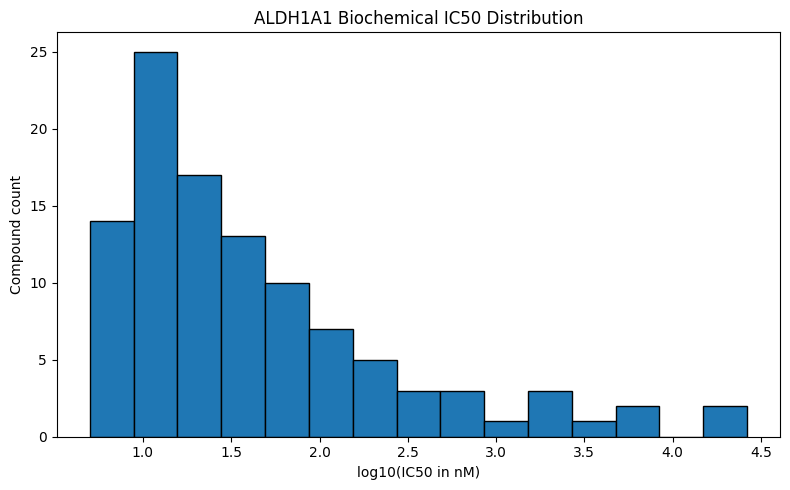

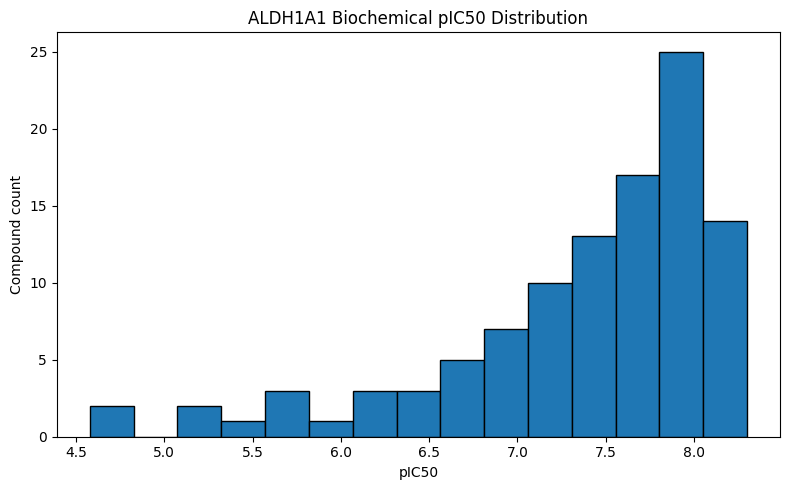


IC50 STATISTICS
count      106.000000
mean       763.716981
std       3508.656502
min          5.000000
25%         12.000000
50%         23.500000
75%         88.500000
max      26410.000000
Name: standard_value, dtype: float64

pIC50 STATISTICS
count    106.000000
mean       7.351719
std        0.812549
min        4.578232
25%        7.053078
50%        7.629030
75%        7.920819
max        8.301030
Name: pIC50, dtype: float64

POTENCY INTERVAL SUMMARY
Potency_Interval  Compound_Count
       pIC50 < 4               0
         4 to <5               2
         5 to <6               7
         6 to <7              16
         7 to <8              61
      pIC50 >= 8              20

IQR OUTLIER ANALYSIS
Q1: 7.0530776818616605
Q3: 7.920818753952375
IQR: 0.8677410720907144
Lower bound: 5.751466073725589
Upper bound: 9.222430362088446
Flagged observations: 8

FILES SAVED
pIC50 dataset
Potency interval summary
Outlier flag report
IC50 distribution figure
pIC50 distribution figure
Activit

In [ ]:

# STEP 02.24: ACTIVITY DISTRIBUTION AND POTENCY RANGE ANALYSIS
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Priority Assay: CHEMBL4189991

import pandas as pd
import numpy as np
import json
import os
import matplotlib.pyplot as plt

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "alternative_assay_investigation"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "04_dataset_analysis"
)

FIGURE_DIR = os.path.join(
    BASE_DIR,
    "09_figures_tables"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

# 2. Load priority assay records

input_file = os.path.join(
    DATA_DIR,
    "ALDH1A1_CHEMBL4189991_IC50_records.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Retain exact numerical IC50 measurements

activity_df = df[
    (df["standard_relation"] == "=") &
    (df["standard_units"] == "nM")
].copy()

activity_df["standard_value"] = pd.to_numeric(
    activity_df["standard_value"],
    errors="coerce"
)

activity_df = activity_df[
    activity_df["standard_value"] > 0
].copy()

# 4. Calculate pIC50

activity_df["pIC50"] = (
    9 - np.log10(activity_df["standard_value"])
)

# 5. Calculate descriptive statistics

ic50_statistics = activity_df[
    "standard_value"
].describe()

pic50_statistics = activity_df[
    "pIC50"
].describe()

# 6. Calculate potency distribution

potency_summary = {

    "Record_Count": int(len(activity_df)),

    "Unique_Compounds": int(
        activity_df["molecule_chembl_id"].nunique()
    ),

    "IC50_Minimum_nM": float(
        activity_df["standard_value"].min()
    ),

    "IC50_Median_nM": float(
        activity_df["standard_value"].median()
    ),

    "IC50_Mean_nM": float(
        activity_df["standard_value"].mean()
    ),

    "IC50_Maximum_nM": float(
        activity_df["standard_value"].max()
    ),

    "pIC50_Minimum": float(
        activity_df["pIC50"].min()
    ),

    "pIC50_Median": float(
        activity_df["pIC50"].median()
    ),

    "pIC50_Mean": float(
        activity_df["pIC50"].mean()
    ),

    "pIC50_Maximum": float(
        activity_df["pIC50"].max()
    ),

    "pIC50_Standard_Deviation": float(
        activity_df["pIC50"].std()
    )

}

# 7. Define descriptive potency intervals

bins = [
    -np.inf,
    4,
    5,
    6,
    7,
    8,
    np.inf
]

labels = [
    "pIC50 < 4",
    "4 to <5",
    "5 to <6",
    "6 to <7",
    "7 to <8",
    "pIC50 >= 8"
]

activity_df["Potency_Interval"] = pd.cut(
    activity_df["pIC50"],
    bins=bins,
    labels=labels,
    right=False
)

potency_interval_summary = (
    activity_df["Potency_Interval"]
    .value_counts(sort=False)
    .reset_index()
)

potency_interval_summary.columns = [
    "Potency_Interval",
    "Compound_Count"
]

# 8. Identify extreme observations using IQR
# This is a flagging procedure, not an exclusion procedure.

Q1 = activity_df["pIC50"].quantile(0.25)

Q3 = activity_df["pIC50"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

activity_df["IQR_Outlier_Flag"] = (
    (activity_df["pIC50"] < lower_bound) |
    (activity_df["pIC50"] > upper_bound)
)

outlier_df = activity_df[
    activity_df["IQR_Outlier_Flag"]
].copy()

# 9. Save activity distribution dataset

activity_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_pIC50_dataset.csv"
    ),
    index=False
)

potency_interval_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_potency_intervals.csv"
    ),
    index=False
)

outlier_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_pIC50_outlier_flags.csv"
    ),
    index=False
)

# 10. Generate IC50 distribution histogram

plt.figure(figsize=(8, 5))

plt.hist(
    np.log10(activity_df["standard_value"]),
    bins=15,
    edgecolor="black"
)

plt.xlabel("log10(IC50 in nM)")

plt.ylabel("Compound count")

plt.title("ALDH1A1 Biochemical IC50 Distribution")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "ALDH1A1_biochemical_IC50_distribution.png"
    ),
    dpi=300
)

plt.show()

# 11. Generate pIC50 distribution histogram

plt.figure(figsize=(8, 5))

plt.hist(
    activity_df["pIC50"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("pIC50")

plt.ylabel("Compound count")

plt.title("ALDH1A1 Biochemical pIC50 Distribution")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "ALDH1A1_biochemical_pIC50_distribution.png"
    ),
    dpi=300
)

plt.show()

# 12. Save metadata

metadata = {

    "project": "ALDH1A1 Inhibitor QSAR",

    "analysis_step": "02.24",

    "assay_id": "CHEMBL4189991",

    "endpoint": "IC50",

    "standard_units": "nM",

    "pIC50_conversion": "9 - log10(IC50 in nM)",

    "outlier_method": "IQR",

    "outliers_removed": 0,

    "potency_summary": potency_summary,

    "IQR_lower_bound": float(lower_bound),

    "IQR_upper_bound": float(upper_bound),

    "IQR_flagged_records": int(len(outlier_df))

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_CHEMBL4189991_activity_distribution.json"
    ),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

# 13. Print results

print("\nIC50 STATISTICS")

print(ic50_statistics)

print("\npIC50 STATISTICS")

print(pic50_statistics)

print("\nPOTENCY INTERVAL SUMMARY")

print(potency_interval_summary.to_string(index=False))

print("\nIQR OUTLIER ANALYSIS")

print("Q1:", Q1)

print("Q3:", Q3)

print("IQR:", IQR)

print("Lower bound:", lower_bound)

print("Upper bound:", upper_bound)

print("Flagged observations:", len(outlier_df))

print("\nFILES SAVED")

print("pIC50 dataset")

print("Potency interval summary")

print("Outlier flag report")

print("IC50 distribution figure")

print("pIC50 distribution figure")

print("Activity distribution metadata JSON")

print("\nSTEP 02.24 COMPLETED")


In [ ]:

# STEP 02.25: INVESTIGATION OF LOW-POTENCY OUTLIERS AND CENSORED MEASUREMENTS
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Priority Assay: CHEMBL4189991

import pandas as pd
import numpy as np
import os
import json

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

DATA_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "alternative_assay_investigation"
)

ANALYSIS_DIR = os.path.join(
    BASE_DIR,
    "04_dataset_analysis"
)

OUTPUT_DIR = ANALYSIS_DIR

# 2. Load original assay records

raw_file = os.path.join(
    DATA_DIR,
    "ALDH1A1_CHEMBL4189991_IC50_records.csv"
)

raw_df = pd.read_csv(
    raw_file,
    low_memory=False
)

# 3. Load pIC50 dataset with IQR flags

activity_file = os.path.join(
    ANALYSIS_DIR,
    "ALDH1A1_CHEMBL4189991_pIC50_dataset.csv"
)

activity_df = pd.read_csv(
    activity_file,
    low_memory=False
)

# 4. Load molecular descriptor dataset

descriptor_file = os.path.join(
    ANALYSIS_DIR,
    "ALDH1A1_CHEMBL4189991_molecular_descriptors.csv"
)

descriptor_df = pd.read_csv(
    descriptor_file,
    low_memory=False
)

# 5. Identify IQR-flagged observations

outlier_df = activity_df[
    activity_df["IQR_Outlier_Flag"] == True
].copy()

# 6. Select available molecular descriptor columns

descriptor_columns = [
    "molecule_chembl_id",
    "Molecular_Weight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Heavy_Atoms",
    "Aromatic_Rings",
    "Ring_Count",
    "Murcko_Scaffold"
]

available_descriptor_columns = [
    column for column in descriptor_columns
    if column in descriptor_df.columns
]

# 7. Merge outlier activity records with molecular descriptors

outlier_review = pd.merge(
    outlier_df,
    descriptor_df[available_descriptor_columns],
    on="molecule_chembl_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_descriptor")
)

# 8. Extract original ChEMBL metadata for outliers

metadata_columns = [
    "molecule_chembl_id",
    "standard_relation",
    "standard_value",
    "standard_units",
    "data_validity_comment",
    "potential_duplicate",
    "assay_description"
]

available_metadata_columns = [
    column for column in metadata_columns
    if column in raw_df.columns
]

outlier_review = pd.merge(
    outlier_review,
    raw_df[available_metadata_columns].drop_duplicates(
        subset=["molecule_chembl_id"]
    ),
    on="molecule_chembl_id",
    how="left",
    suffixes=("", "_original")
)

# 9. Identify censored measurements

censored_df = raw_df[
    raw_df["standard_relation"].notna() &
    (raw_df["standard_relation"] != "=")
].copy()

# 10. Prepare censored measurement inspection

censored_columns = [
    "molecule_chembl_id",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pchembl_value",
    "canonical_smiles",
    "data_validity_comment",
    "potential_duplicate",
    "assay_description"
]

available_censored_columns = [
    column for column in censored_columns
    if column in censored_df.columns
]

censored_review = censored_df[
    available_censored_columns
].copy()

# 11. Compare outlier properties with the complete exact-measurement dataset

comparison_columns = [
    "Molecular_Weight",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Heavy_Atoms",
    "Aromatic_Rings",
    "Ring_Count"
]

available_comparison_columns = [
    column for column in comparison_columns
    if column in descriptor_df.columns
]

property_comparison = pd.DataFrame({

    "Descriptor": available_comparison_columns,

    "All_Compounds_Median": [
        descriptor_df[column].median()
        for column in available_comparison_columns
    ],

    "Outlier_Compounds_Median": [
        outlier_review[column].median()
        for column in available_comparison_columns
    ],

    "All_Compounds_Mean": [
        descriptor_df[column].mean()
        for column in available_comparison_columns
    ],

    "Outlier_Compounds_Mean": [
        outlier_review[column].mean()
        for column in available_comparison_columns
    ]

})

# 12. Save outlier and censored-record reports

outlier_review.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_low_pIC50_outlier_investigation.csv"
    ),
    index=False
)

censored_review.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_censored_measurement_investigation.csv"
    ),
    index=False
)

property_comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_outlier_molecular_property_comparison.csv"
    ),
    index=False
)

# 13. Prepare investigation metadata

metadata = {

    "project": "ALDH1A1 Inhibitor QSAR",

    "analysis_step": "02.25",

    "priority_assay": "CHEMBL4189991",

    "IQR_flagged_compounds": int(len(outlier_review)),

    "censored_measurements": int(len(censored_review)),

    "outlier_records_removed": 0,

    "censored_records_removed_from_raw_data": 0,

    "molecular_property_comparison_performed": True,

    "activity_endpoint": "IC50",

    "outlier_interpretation": (
        "Statistical flags requiring experimental and chemical inspection"
    )

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_outlier_investigation_metadata.json"
    ),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

# 14. Print outlier observations

print("\nLOW-pIC50 OUTLIER OBSERVATIONS")

print(
    outlier_review[
        [
            column for column in [
                "molecule_chembl_id",
                "standard_value",
                "standard_units",
                "pIC50",
                "LogP",
                "TPSA",
                "Molecular_Weight",
                "data_validity_comment",
                "potential_duplicate"
            ]
            if column in outlier_review.columns
        ]
    ].to_string(index=False)
)

# 15. Print censored measurements

print("\nCENSORED MEASUREMENTS")

print(
    censored_review.to_string(index=False)
)

# 16. Print molecular property comparison

print("\nMOLECULAR PROPERTY COMPARISON")

print(
    property_comparison.to_string(index=False)
)

# 17. Final confirmation

print("\nFILES SAVED")

print("Low-pIC50 outlier investigation")

print("Censored measurement investigation")

print("Outlier molecular property comparison")

print("Investigation metadata JSON")

print("\nSTEP 02.25 COMPLETED")



LOW-pIC50 OUTLIER OBSERVATIONS
molecule_chembl_id  standard_value standard_units    pIC50    LogP  TPSA  Molecular_Weight  data_validity_comment  potential_duplicate
     CHEMBL4211263          4830.0             nM 5.316053 1.83128 97.61           445.520                    NaN                    0
     CHEMBL4208819         23380.0             nM 4.631155 2.80828 80.54           435.503                    NaN                    0
     CHEMBL4213751          2510.0             nM 5.600326 4.52740 56.75           500.618                    NaN                    0
     CHEMBL4205670          4490.0             nM 5.347754 2.99998 97.61           487.601                    NaN                    0
     CHEMBL4209109          2330.0             nM 5.632644 3.30380 56.75           446.473                    NaN                    0
     CHEMBL4209787          1900.0             nM 5.721246 3.00660 56.75           428.483                    NaN                    0
     CHEMBL3416562     

In [ ]:

# STEP 02.26: MOLECULAR SIMILARITY AND ACTIVITY-CLIFF ANALYSIS
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Priority Assay: CHEMBL4189991

import pandas as pd
import numpy as np
import json
import os

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

ANALYSIS_DIR = os.path.join(
    BASE_DIR,
    "04_dataset_analysis"
)

OUTPUT_DIR = ANALYSIS_DIR

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Load exact pIC50 dataset

input_file = os.path.join(
    ANALYSIS_DIR,
    "ALDH1A1_CHEMBL4189991_pIC50_dataset.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Load molecular descriptor dataset

descriptor_file = os.path.join(
    ANALYSIS_DIR,
    "ALDH1A1_CHEMBL4189991_molecular_descriptors.csv"
)

descriptor_df = pd.read_csv(
    descriptor_file,
    low_memory=False
)

# 4. Merge activity and structural information

analysis_df = pd.merge(
    df,
    descriptor_df[
        [
            "molecule_chembl_id",
            "Murcko_Scaffold"
        ]
    ],
    on="molecule_chembl_id",
    how="left",
    validate="one_to_one"
)

analysis_df = analysis_df.dropna(
    subset=[
        "canonical_smiles",
        "pIC50"
    ]
).copy()

# 5. Generate Morgan fingerprints

fingerprint_generator = (
    rdFingerprintGenerator.GetMorganGenerator(
        radius=2,
        fpSize=2048
    )
)

molecules = []

fingerprints = []

valid_records = []

for _, row in analysis_df.iterrows():

    mol = Chem.MolFromSmiles(
        row["canonical_smiles"]
    )

    if mol is None:
        continue

    fingerprint = (
        fingerprint_generator.GetFingerprint(mol)
    )

    molecules.append(mol)

    fingerprints.append(fingerprint)

    valid_records.append(row)

analysis_df = pd.DataFrame(
    valid_records
).reset_index(drop=True)

# 6. Calculate all pairwise Tanimoto similarities

pair_records = []

n_compounds = len(analysis_df)

for i in range(n_compounds):

    similarities = DataStructs.BulkTanimotoSimilarity(
        fingerprints[i],
        fingerprints[i + 1:]
    )

    for offset, similarity in enumerate(similarities):

        j = i + 1 + offset

        activity_difference = abs(
            analysis_df.loc[i, "pIC50"] -
            analysis_df.loc[j, "pIC50"]
        )

        pair_records.append({

            "Compound_A": analysis_df.loc[
                i, "molecule_chembl_id"
            ],

            "Compound_B": analysis_df.loc[
                j, "molecule_chembl_id"
            ],

            "Tanimoto_Similarity": similarity,

            "pIC50_A": analysis_df.loc[i, "pIC50"],

            "pIC50_B": analysis_df.loc[j, "pIC50"],

            "Absolute_pIC50_Difference": (
                activity_difference
            ),

            "Same_Murcko_Scaffold": (
                analysis_df.loc[i, "Murcko_Scaffold"] ==
                analysis_df.loc[j, "Murcko_Scaffold"]
            )

        })

pairwise_df = pd.DataFrame(pair_records)

# 7. Identify highly similar compound pairs

high_similarity_df = pairwise_df[
    pairwise_df["Tanimoto_Similarity"] >= 0.80
].copy()

# 8. Identify potential activity cliffs

activity_cliffs_df = pairwise_df[
    (pairwise_df["Tanimoto_Similarity"] >= 0.80) &
    (pairwise_df["Absolute_pIC50_Difference"] >= 1.0)
].copy()

# 9. Calculate nearest-neighbour similarity for each compound

nearest_neighbour_records = []

for i in range(n_compounds):

    similarities = DataStructs.BulkTanimotoSimilarity(
        fingerprints[i],
        fingerprints
    )

    similarities[i] = -1

    nearest_index = int(
        np.argmax(similarities)
    )

    nearest_similarity = similarities[
        nearest_index
    ]

    nearest_neighbour_records.append({

        "molecule_chembl_id": analysis_df.loc[
            i, "molecule_chembl_id"
        ],

        "Nearest_Neighbour_ID": analysis_df.loc[
            nearest_index, "molecule_chembl_id"
        ],

        "Nearest_Neighbour_Similarity": (
            nearest_similarity
        ),

        "pIC50": analysis_df.loc[i, "pIC50"],

        "Nearest_Neighbour_pIC50": (
            analysis_df.loc[
                nearest_index, "pIC50"
            ]
        ),

        "Absolute_pIC50_Difference": abs(
            analysis_df.loc[i, "pIC50"] -
            analysis_df.loc[
                nearest_index, "pIC50"
            ]
        )

    })

nearest_neighbour_df = pd.DataFrame(
    nearest_neighbour_records
)

# 10. Analyse potency distribution within scaffolds

scaffold_summary = (
    analysis_df.groupby(
        "Murcko_Scaffold",
        dropna=False
    )
    .agg(
        Compound_Count=(
            "molecule_chembl_id",
            "nunique"
        ),

        Mean_pIC50=("pIC50", "mean"),

        Median_pIC50=("pIC50", "median"),

        Minimum_pIC50=("pIC50", "min"),

        Maximum_pIC50=("pIC50", "max"),

        pIC50_Standard_Deviation=("pIC50", "std")

    )
    .reset_index()
)

scaffold_summary[
    "pIC50_Range"
] = (
    scaffold_summary["Maximum_pIC50"] -
    scaffold_summary["Minimum_pIC50"]
)

# 11. Summarise similarity distribution

similarity_statistics = {
    "Total_Compounds": int(n_compounds),

    "Total_Compound_Pairs": int(len(pairwise_df)),

    "Mean_Tanimoto_Similarity": float(
        pairwise_df["Tanimoto_Similarity"].mean()
    ),

    "Median_Tanimoto_Similarity": float(
        pairwise_df["Tanimoto_Similarity"].median()
    ),

    "Maximum_Tanimoto_Similarity": float(
        pairwise_df["Tanimoto_Similarity"].max()
    ),

    "Pairs_Similarity_At_Least_0.80": int(
        len(high_similarity_df)
    ),

    "Potential_Activity_Cliffs": int(
        len(activity_cliffs_df)
    ),

    "Unique_Murcko_Scaffolds": int(
        analysis_df["Murcko_Scaffold"].nunique()
    )

}

# 12. Save pairwise similarity results

pairwise_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_pairwise_Tanimoto_similarity.csv"
    ),
    index=False
)

high_similarity_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_high_similarity_compound_pairs.csv"
    ),
    index=False
)

activity_cliffs_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_potential_activity_cliffs.csv"
    ),
    index=False
)

nearest_neighbour_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_nearest_neighbour_analysis.csv"
    ),
    index=False
)

scaffold_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_scaffold_potency_summary.csv"
    ),
    index=False
)

# 13. Save analysis metadata

metadata = {

    "project": "ALDH1A1 Inhibitor QSAR",

    "analysis_step": "02.26",

    "assay_id": "CHEMBL4189991",

    "fingerprint": "Morgan",

    "radius": 2,

    "fingerprint_size": 2048,

    "similarity_metric": "Tanimoto",

    "high_similarity_threshold": 0.80,

    "activity_cliff_threshold_pIC50": 1.0,

    "similarity_statistics": similarity_statistics,

    "compounds_removed": 0

}

with open(
    os.path.join(
        OUTPUT_DIR,
        "ALDH1A1_similarity_activity_cliff_metadata.json"
    ),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

# 14. Print results

print("\nMOLECULAR SIMILARITY SUMMARY")

for key, value in similarity_statistics.items():

    print(f"{key}: {value}")

print("\nTOP 15 MOST SIMILAR COMPOUND PAIRS")

print(
    pairwise_df.sort_values(
        "Tanimoto_Similarity",
        ascending=False
    ).head(15).to_string(index=False)
)

print("\nPOTENTIAL ACTIVITY CLIFFS")

print(
    activity_cliffs_df.sort_values(
        "Absolute_pIC50_Difference",
        ascending=False
    ).to_string(index=False)
)

print("\nNEAREST NEIGHBOUR SIMILARITY SUMMARY")

print(
    nearest_neighbour_df[
        "Nearest_Neighbour_Similarity"
    ].describe()
)

print("\nSCAFFOLD POTENCY SUMMARY")

print(
    scaffold_summary.sort_values(
        "Compound_Count",
        ascending=False
    ).head(15).to_string(index=False)
)

# 15. Final confirmation

print("\nFILES SAVED")

print("Pairwise Tanimoto similarity matrix")

print("High-similarity compound pairs")

print("Potential activity cliffs")

print("Nearest-neighbour analysis")

print("Scaffold potency summary")

print("Similarity analysis metadata JSON")

print("\nSTEP 02.26 COMPLETED")



MOLECULAR SIMILARITY SUMMARY
Total_Compounds: 106
Total_Compound_Pairs: 5565
Mean_Tanimoto_Similarity: 0.46077087213202766
Median_Tanimoto_Similarity: 0.46511627906976744
Maximum_Tanimoto_Similarity: 1.0
Pairs_Similarity_At_Least_0.80: 85
Potential_Activity_Cliffs: 15
Unique_Murcko_Scaffolds: 50

TOP 15 MOST SIMILAR COMPOUND PAIRS
   Compound_A    Compound_B  Tanimoto_Similarity  pIC50_A  pIC50_B  Absolute_pIC50_Difference  Same_Murcko_Scaffold
CHEMBL4217372 CHEMBL4212856             1.000000 7.065502 6.411168                   0.654333                  True
CHEMBL4210851 CHEMBL4215797             0.981481 7.721246 7.552842                   0.168404                 False
CHEMBL4208724 CHEMBL4206606             0.968254 7.853872 8.154902                   0.301030                 False
CHEMBL4206606 CHEMBL4206272             0.936508 8.154902 8.154902                   0.000000                 False
CHEMBL4208724 CHEMBL4206272             0.936508 7.853872 8.154902                   0

In [ ]:

# STEP 03.1: PRIMARY DATASET IDENTIFICATION AND VERIFICATION
# Project: ALDH1A1 Inhibitor QSAR
# Database: ChEMBL
# Target ID: CHEMBL3577
# Primary Assay ID: CHEMBL4189991

import pandas as pd
import os
import json

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

SOURCE_DIR = os.path.join(
    BASE_DIR,
    "02_data_collection",
    "alternative_assay_investigation"
)

CURATION_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation"
)

os.makedirs(CURATION_DIR, exist_ok=True)

# 2. Define the verified primary assay input file

TARGET_ASSAY = "CHEMBL4189991"

source_file = os.path.join(
    SOURCE_DIR,
    "ALDH1A1_CHEMBL4189991_IC50_records.csv"
)

# 3. Verify source file availability

if not os.path.exists(source_file):

    raise FileNotFoundError(
        "The dedicated primary assay dataset was not found: "
        + source_file
    )

# 4. Load primary assay records

df = pd.read_csv(
    source_file,
    low_memory=False
)

# 5. Verify required columns

required_columns = [
    "assay_chembl_id",
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pchembl_value"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

# 6. Verify assay identity

if not (df["assay_chembl_id"] == TARGET_ASSAY).all():

    raise ValueError(
        "Unexpected assay IDs detected in the primary dataset."
    )

# 7. Verify record and compound counts

record_count = len(df)

unique_compounds = (
    df["molecule_chembl_id"].nunique()
)

if record_count != 107 or unique_compounds != 107:

    raise ValueError(
        "Unexpected dataset size. Review the source records."
    )

# 8. Verify activity and structure availability

print("\nPRIMARY DATASET VERIFICATION")

print("Assay ID:", TARGET_ASSAY)

print("Total records:", record_count)

print("Unique compounds:", unique_compounds)

print(
    "Records with SMILES:",
    df["canonical_smiles"].notna().sum()
)

print(
    "Records without SMILES:",
    df["canonical_smiles"].isna().sum()
)

print("\nACTIVITY TYPES")

print(
    df["standard_type"].value_counts(dropna=False)
)

print("\nACTIVITY RELATIONS")

print(
    df["standard_relation"].value_counts(dropna=False)
)

print("\nACTIVITY UNITS")

print(
    df["standard_units"].value_counts(dropna=False)
)

# 9. Save an independent working copy

output_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_primary_assay_raw_for_curation.csv"
)

df.to_csv(
    output_file,
    index=False
)

# 10. Save verification metadata

metadata = {

    "project": "ALDH1A1 Inhibitor QSAR",

    "analysis_step": "03.1",

    "target_id": "CHEMBL3577",

    "assay_id": TARGET_ASSAY,

    "source_file": os.path.basename(source_file),

    "total_records": int(record_count),

    "unique_compounds": int(unique_compounds),

    "records_with_smiles": int(
        df["canonical_smiles"].notna().sum()
    ),

    "records_without_smiles": int(
        df["canonical_smiles"].isna().sum()
    ),

    "source_data_modified": False,

    "working_copy": output_file

}

metadata_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_primary_dataset_verification.json"
)

with open(metadata_file, "w") as file:

    json.dump(metadata, file, indent=4)

# 11. Display saved files

print("\nFILES SAVED")

print(output_file)

print(metadata_file)

print("\nSTEP 03.1 COMPLETED")



PRIMARY DATASET VERIFICATION
Assay ID: CHEMBL4189991
Total records: 107
Unique compounds: 107
Records with SMILES: 107
Records without SMILES: 0

ACTIVITY TYPES
standard_type
IC50    107
Name: count, dtype: int64

ACTIVITY RELATIONS
standard_relation
=    106
>      1
Name: count, dtype: int64

ACTIVITY UNITS
standard_units
nM    107
Name: count, dtype: int64

FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_primary_assay_raw_for_curation.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_primary_dataset_verification.json

STEP 03.1 COMPLETED


In [ ]:

# STEP 03.2: DATA INTEGRITY AND QUALITY AUDIT
# Project: ALDH1A1 Inhibitor QSAR
# Primary assay: CHEMBL4189991

import pandas as pd
import numpy as np
import os
import json

# 1. Define directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

CURATION_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation"
)

input_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_primary_assay_raw_for_curation.csv"
)

# 2. Load verified working dataset

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Basic dataset structure

print("\nDATASET STRUCTURE")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCOLUMN NAMES")

print(df.columns.tolist())

# 4. Missing-value assessment

missing_values = pd.DataFrame({

    "Missing_Count": df.isna().sum(),

    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)

})

print("\nMISSING VALUE SUMMARY")

print(
    missing_values[
        missing_values["Missing_Count"] > 0
    ]
)

# 5. Duplicate record assessment

print("\nDUPLICATE RECORD ASSESSMENT")

print(
    "Exact duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate ChEMBL compound IDs:",
    df["molecule_chembl_id"].duplicated().sum()
)

print(
    "Duplicate canonical SMILES:",
    df["canonical_smiles"].duplicated().sum()
)

# 6. Compound identifier assessment

print("\nCOMPOUND IDENTIFIER ASSESSMENT")

print(
    "Unique compound IDs:",
    df["molecule_chembl_id"].nunique()
)

print(
    "Unique canonical SMILES:",
    df["canonical_smiles"].nunique()
)

# 7. Activity relation assessment

print("\nACTIVITY RELATION ASSESSMENT")

print(
    df["standard_relation"].value_counts(
        dropna=False
    )
)

censored_records = df[
    df["standard_relation"] != "="
].copy()

print("\nNON-EXACT ACTIVITY RECORDS")

print(
    censored_records[
        [
            "molecule_chembl_id",
            "standard_type",
            "standard_relation",
            "standard_value",
            "standard_units"
        ]
    ].to_string(index=False)
)

# 8. Numerical activity assessment

df["standard_value_numeric"] = pd.to_numeric(
    df["standard_value"],
    errors="coerce"
)

print("\nACTIVITY VALUE QUALITY")

print(
    "Non-numeric activity values:",
    df["standard_value_numeric"].isna().sum()
)

print(
    "Zero or negative activity values:",
    (
        df["standard_value_numeric"] <= 0
    ).sum()
)

print("\nACTIVITY VALUE DESCRIPTIVE STATISTICS")

print(
    df["standard_value_numeric"].describe()
)

# 9. Activity unit and type consistency

print("\nACTIVITY TYPE")

print(
    df["standard_type"].value_counts(
        dropna=False
    )
)

print("\nACTIVITY UNITS")

print(
    df["standard_units"].value_counts(
        dropna=False
    )
)

# 10. Structure availability and validity flags

print("\nSTRUCTURE QUALITY FLAGS")

print(
    "Missing SMILES:",
    df["canonical_smiles"].isna().sum()
)

print(
    "Empty SMILES:",
    (
        df["canonical_smiles"].astype(str).str.strip() == ""
    ).sum()
)

# 11. Generate audit metadata

audit_metadata = {

    "analysis_step": "03.2",

    "total_records": int(len(df)),

    "total_columns": int(df.shape[1]),

    "missing_value_columns": {
        str(key): int(value)
        for key, value in df.isna().sum().items()
        if value > 0
    },

    "exact_duplicate_rows": int(
        df.duplicated().sum()
    ),

    "duplicate_compound_ids": int(
        df["molecule_chembl_id"].duplicated().sum()
    ),

    "duplicate_canonical_smiles": int(
        df["canonical_smiles"].duplicated().sum()
    ),

    "unique_compound_ids": int(
        df["molecule_chembl_id"].nunique()
    ),

    "unique_canonical_smiles": int(
        df["canonical_smiles"].nunique()
    ),

    "non_exact_measurements": int(
        (df["standard_relation"] != "=").sum()
    ),

    "non_numeric_activity_values": int(
        df["standard_value_numeric"].isna().sum()
    ),

    "non_positive_activity_values": int(
        (df["standard_value_numeric"] <= 0).sum()
    ),

    "source_data_modified": False

}

# 12. Save audit outputs

missing_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_missing_value_audit.csv"
)

missing_values.to_csv(missing_file)

censored_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_non_exact_activity_records.csv"
)

censored_records.to_csv(
    censored_file,
    index=False
)

metadata_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_data_integrity_audit.json"
)

with open(metadata_file, "w") as file:

    json.dump(
        audit_metadata,
        file,
        indent=4
    )

print("\nFILES SAVED")

print(missing_file)
print(censored_file)
print(metadata_file)

print("\nSTEP 03.2 COMPLETED")



DATASET STRUCTURE
Rows: 107
Columns: 20

COLUMN NAMES
['assay_chembl_id', 'molecule_chembl_id', 'molecule_pref_name', 'canonical_smiles', 'standard_type', 'standard_relation', 'standard_value', 'standard_units', 'pchembl_value', 'data_validity_comment', 'potential_duplicate', 'assay_type', 'assay_description', 'document_chembl_id', 'Has_Standard_Value', 'Has_Standard_Units', 'Has_Standard_Relation', 'Has_pChEMBL', 'Has_SMILES', 'Has_ChEMBL_ID']

MISSING VALUE SUMMARY
                       Missing_Count  Missing_Percentage
molecule_pref_name               107              100.00
pchembl_value                      1                0.93
data_validity_comment            107              100.00

DUPLICATE RECORD ASSESSMENT
Exact duplicate rows: 0
Duplicate ChEMBL compound IDs: 0
Duplicate canonical SMILES: 0

COMPOUND IDENTIFIER ASSESSMENT
Unique compound IDs: 107
Unique canonical SMILES: 107

ACTIVITY RELATION ASSESSMENT
standard_relation
=    106
>      1
Name: count, dtype: int64

NON-

In [ ]:

# STEP 03.3: ACTIVITY DATA STANDARDISATION AND pIC50 CALCULATION
# Project: ALDH1A1 Inhibitor QSAR
# Primary assay: CHEMBL4189991

import pandas as pd
import numpy as np
import os
import json

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

CURATION_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation"
)

# 2. Load the original working dataset

input_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_primary_assay_raw_for_curation.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Convert activity values to numeric

df["IC50_nM"] = pd.to_numeric(
    df["standard_value"],
    errors="coerce"
)

# 4. Verify units and activity type

if not (df["standard_type"] == "IC50").all():

    raise ValueError(
        "Unexpected activity types detected."
    )

if not (df["standard_units"] == "nM").all():

    raise ValueError(
        "Unexpected activity units detected."
    )

# 5. Identify exact and censored measurements

df["Measurement_Status"] = np.where(
    df["standard_relation"] == "=",
    "Exact",
    "Censored"
)

# 6. Calculate pIC50 only for exact measurements

df["pIC50"] = np.nan

exact_mask = (
    (df["standard_relation"] == "=") &
    (df["IC50_nM"] > 0)
)

df.loc[exact_mask, "pIC50"] = (
    9 - np.log10(
        df.loc[exact_mask, "IC50_nM"]
    )
)

# 7. Calculate IC50 in molar units for exact records

df["IC50_M"] = np.nan

df.loc[exact_mask, "IC50_M"] = (
    df.loc[exact_mask, "IC50_nM"] * 1e-9
)

# 8. Display activity standardisation results

print("\nACTIVITY STANDARDISATION SUMMARY")

print("Total records:", len(df))

print(
    "Exact measurements:",
    (df["Measurement_Status"] == "Exact").sum()
)

print(
    "Censored measurements:",
    (df["Measurement_Status"] == "Censored").sum()
)

print(
    "Calculated pIC50 values:",
    df["pIC50"].notna().sum()
)

print(
    "Missing pIC50 values:",
    df["pIC50"].isna().sum()
)

# 9. Display exact pIC50 descriptive statistics

print("\nEXACT pIC50 DESCRIPTIVE STATISTICS")

print(
    df.loc[exact_mask, "pIC50"].describe()
)

# 10. Display censored records separately

print("\nCENSORED ACTIVITY RECORDS")

print(
    df.loc[
        ~exact_mask,
        [
            "molecule_chembl_id",
            "standard_relation",
            "IC50_nM",
            "standard_units",
            "Measurement_Status",
            "pIC50"
        ]
    ].to_string(index=False)
)

# 11. Save standardised master dataset

output_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_activity_standardised_master.csv"
)

df.to_csv(
    output_file,
    index=False
)

# 12. Save exact-measurement analysis dataset

exact_df = df.loc[exact_mask].copy()

exact_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_exact_IC50_pIC50_dataset.csv"
)

exact_df.to_csv(
    exact_file,
    index=False
)

# 13. Save standardisation metadata

metadata = {

    "analysis_step": "03.3",

    "total_records": int(len(df)),

    "exact_measurements": int(exact_mask.sum()),

    "censored_measurements": int((~exact_mask).sum()),

    "calculated_pIC50_values": int(
        df["pIC50"].notna().sum()
    ),

    "pIC50_calculation": (
        "pIC50 = 9 - log10(IC50 in nM)"
    ),

    "censored_records_assigned_exact_pIC50": False,

    "original_activity_values_preserved": True

}

metadata_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_activity_standardisation_metadata.json"
)

with open(metadata_file, "w") as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

# 14. Display saved files

print("\nFILES SAVED")

print(output_file)
print(exact_file)
print(metadata_file)

print("\nSTEP 03.3 COMPLETED")



ACTIVITY STANDARDISATION SUMMARY
Total records: 107
Exact measurements: 106
Censored measurements: 1
Calculated pIC50 values: 106
Missing pIC50 values: 1

EXACT pIC50 DESCRIPTIVE STATISTICS
count    106.000000
mean       7.351719
std        0.812549
min        4.578232
25%        7.053078
50%        7.629030
75%        7.920819
max        8.301030
Name: pIC50, dtype: float64

CENSORED ACTIVITY RECORDS
molecule_chembl_id standard_relation  IC50_nM standard_units Measurement_Status  pIC50
     CHEMBL4205752                 >  57000.0             nM           Censored    NaN

FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_activity_standardised_master.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_exact_IC50_pIC50_dataset.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_activity_standardisation_metadata.json

STEP 03.3 COMPLETED


In [ ]:

# STEP 03.4: CHEMICAL STRUCTURE STANDARDISATION AUDIT
# Project: ALDH1A1 Inhibitor QSAR
# Primary assay: CHEMBL4189991

import pandas as pd
import numpy as np
import os
import json

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem.MolStandardize import rdMolStandardize

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

CURATION_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation"
)

# 2. Load standardised activity dataset

input_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_activity_standardised_master.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Initialise structure standardisation utilities

uncharger = rdMolStandardize.Uncharger()

# 4. Create structure audit records

audit_records = []

for _, row in df.iterrows():

    smiles = row["canonical_smiles"]

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:

        audit_records.append({

            "molecule_chembl_id": row["molecule_chembl_id"],

            "Structure_Valid": False

        })

        continue

    # 5. Identify molecular fragments

    fragments = Chem.GetMolFrags(
        mol,
        asMols=True
    )

    fragment_count = len(fragments)

    fragment_sizes = [
        fragment.GetNumHeavyAtoms()
        for fragment in fragments
    ]

    # 6. Identify the largest molecular fragment

    largest_fragment = max(
        fragments,
        key=lambda fragment: fragment.GetNumHeavyAtoms()
    )

    largest_fragment_smiles = Chem.MolToSmiles(
        largest_fragment,
        canonical=True
    )

    # 7. Calculate formal charge

    formal_charge = Chem.GetFormalCharge(mol)

    # 8. Detect stereochemistry

    chiral_centres = Chem.FindMolChiralCenters(
        mol,
        includeUnassigned=True
    )

    assigned_stereocentres = sum(
        label != "?"
        for _, label in chiral_centres
    )

    unassigned_stereocentres = sum(
        label == "?"
        for _, label in chiral_centres
    )

    # 9. Detect isotopes

    isotope_atoms = sum(
        atom.GetIsotope() != 0
        for atom in mol.GetAtoms()
    )

    # 10. Generate structural identifiers

    canonical_smiles = Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True
    )

    inchikey = Chem.MolToInchiKey(mol)

    # 11. Generate an uncharged representation for comparison only

    uncharged_mol = uncharger.uncharge(
        Chem.Mol(mol)
    )

    uncharged_smiles = Chem.MolToSmiles(
        uncharged_mol,
        canonical=True,
        isomericSmiles=True
    )

    # 12. Record structure information

    audit_records.append({

        "molecule_chembl_id": row["molecule_chembl_id"],

        "Structure_Valid": True,

        "Canonical_SMILES": canonical_smiles,

        "InChIKey": inchikey,

        "Fragment_Count": fragment_count,

        "Fragment_Heavy_Atom_Counts": ",".join(
            map(str, fragment_sizes)
        ),

        "Largest_Fragment_SMILES": largest_fragment_smiles,

        "Has_Multiple_Fragments": fragment_count > 1,

        "Formal_Charge": formal_charge,

        "Has_Nonzero_Formal_Charge": formal_charge != 0,

        "Chiral_Centre_Count": len(chiral_centres),

        "Assigned_Stereocentre_Count": assigned_stereocentres,

        "Unassigned_Stereocentre_Count": unassigned_stereocentres,

        "Isotope_Atom_Count": isotope_atoms,

        "Uncharged_SMILES_Comparison": uncharged_smiles

    })

# 13. Convert audit records into a DataFrame

audit_df = pd.DataFrame(audit_records)

# 14. Display structure audit summary

valid_df = audit_df[
    audit_df["Structure_Valid"] == True
].copy()

print("\nCHEMICAL STRUCTURE AUDIT SUMMARY")

print("Total records:", len(audit_df))

print(
    "Valid structures:",
    audit_df["Structure_Valid"].sum()
)

print(
    "Invalid structures:",
    (~audit_df["Structure_Valid"]).sum()
)

print(
    "Unique canonical isomeric SMILES:",
    valid_df["Canonical_SMILES"].nunique()
)

print(
    "Unique InChIKeys:",
    valid_df["InChIKey"].nunique()
)

# 15. Display fragment and salt-related information

print("\nFRAGMENT ANALYSIS")

print(
    "Compounds with multiple fragments:",
    valid_df["Has_Multiple_Fragments"].sum()
)

print(
    "Compounds with nonzero formal charge:",
    valid_df["Has_Nonzero_Formal_Charge"].sum()
)

# 16. Display stereochemistry information

print("\nSTEREOCHEMISTRY ANALYSIS")

print(
    "Compounds with stereocentres:",
    (valid_df["Chiral_Centre_Count"] > 0).sum()
)

print(
    "Compounds with unassigned stereocentres:",
    (valid_df["Unassigned_Stereocentre_Count"] > 0).sum()
)

# 17. Display isotope information

print("\nISOTOPE ANALYSIS")

print(
    "Compounds containing isotopic atoms:",
    (valid_df["Isotope_Atom_Count"] > 0).sum()
)

# 18. Identify repeated InChIKeys

print("\nREPEATED INCHIKEY ASSESSMENT")

duplicate_inchikeys = valid_df[
    valid_df["InChIKey"].duplicated(keep=False)
].sort_values("InChIKey")

print(
    duplicate_inchikeys[
        [
            "molecule_chembl_id",
            "InChIKey",
            "Canonical_SMILES"
        ]
    ].to_string(index=False)
    if not duplicate_inchikeys.empty
    else "No repeated InChIKeys detected."
)

# 19. Identify structures with multiple fragments

print("\nMULTI-FRAGMENT STRUCTURES")

multifragment_df = valid_df[
    valid_df["Has_Multiple_Fragments"]
]

print(
    multifragment_df[
        [
            "molecule_chembl_id",
            "Fragment_Count",
            "Fragment_Heavy_Atom_Counts",
            "Canonical_SMILES"
        ]
    ].to_string(index=False)
    if not multifragment_df.empty
    else "No multi-fragment structures detected."
)

# 20. Save detailed structure audit

audit_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_chemical_structure_audit.csv"
)

audit_df.to_csv(
    audit_file,
    index=False
)

# 21. Save audit metadata

metadata = {

    "analysis_step": "03.4",

    "total_records": int(len(audit_df)),

    "valid_structures": int(
        audit_df["Structure_Valid"].sum()
    ),

    "invalid_structures": int(
        (~audit_df["Structure_Valid"]).sum()
    ),

    "unique_canonical_isomeric_smiles": int(
        valid_df["Canonical_SMILES"].nunique()
    ),

    "unique_inchikeys": int(
        valid_df["InChIKey"].nunique()
    ),

    "multiple_fragment_structures": int(
        valid_df["Has_Multiple_Fragments"].sum()
    ),

    "nonzero_formal_charge_structures": int(
        valid_df["Has_Nonzero_Formal_Charge"].sum()
    ),

    "structures_with_stereocentres": int(
        (valid_df["Chiral_Centre_Count"] > 0).sum()
    ),

    "structures_with_unassigned_stereocentres": int(
        (valid_df["Unassigned_Stereocentre_Count"] > 0).sum()
    ),

    "structures_with_isotopes": int(
        (valid_df["Isotope_Atom_Count"] > 0).sum()
    ),

    "automatic_structure_modification_performed": False,

    "automatic_salt_removal_performed": False

}

metadata_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_chemical_structure_audit_metadata.json"
)

with open(metadata_file, "w") as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

# 22. Display saved files

print("\nFILES SAVED")

print(audit_file)
print(metadata_file)

print("\nSTEP 03.4 COMPLETED")



CHEMICAL STRUCTURE AUDIT SUMMARY
Total records: 107
Valid structures: 107
Invalid structures: 0
Unique canonical isomeric SMILES: 107
Unique InChIKeys: 107

FRAGMENT ANALYSIS
Compounds with multiple fragments: 0
Compounds with nonzero formal charge: 0

STEREOCHEMISTRY ANALYSIS
Compounds with stereocentres: 5
Compounds with unassigned stereocentres: 1

ISOTOPE ANALYSIS
Compounds containing isotopic atoms: 0

REPEATED INCHIKEY ASSESSMENT
No repeated InChIKeys detected.

MULTI-FRAGMENT STRUCTURES
No multi-fragment structures detected.

FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_chemical_structure_audit.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_chemical_structure_audit_metadata.json

STEP 03.4 COMPLETED


In [ ]:

# STEP 03.5: STEREOCHEMISTRY REVIEW
# Project: ALDH1A1 Inhibitor QSAR

import pandas as pd
import os
import json

from rdkit import Chem

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

CURATION_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation"
)

# 2. Load activity and structure audit datasets

activity_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_activity_standardised_master.csv"
)

audit_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_chemical_structure_audit.csv"
)

df = pd.read_csv(
    activity_file,
    low_memory=False
)

audit_df = pd.read_csv(
    audit_file,
    low_memory=False
)

# 3. Identify compounds with stereocentres

stereo_df = audit_df[
    audit_df["Chiral_Centre_Count"] > 0
].copy()

# 4. Identify compounds with unassigned stereocentres

unassigned_df = stereo_df[
    stereo_df["Unassigned_Stereocentre_Count"] > 0
].copy()

# 5. Merge activity information

columns_to_merge = [
    "molecule_chembl_id",
    "standard_relation",
    "IC50_nM",
    "pIC50"
]

stereo_df = stereo_df.merge(
    df[columns_to_merge],
    on="molecule_chembl_id",
    how="left"
)

# 6. Extract stereochemical centre details

stereo_details = []

for _, row in stereo_df.iterrows():

    mol = Chem.MolFromSmiles(
        row["Canonical_SMILES"]
    )

    centres = Chem.FindMolChiralCenters(
        mol,
        includeUnassigned=True
    )

    centre_labels = [
        f"Atom_{index}:{label}"
        for index, label in centres
    ]

    stereo_details.append({

        "molecule_chembl_id": row["molecule_chembl_id"],

        "Chiral_Centre_Count": len(centres),

        "Stereochemistry_Labels": "; ".join(
            centre_labels
        ),

        "Unassigned_Stereocentre_Count": row[
            "Unassigned_Stereocentre_Count"
        ],

        "IC50_nM": row["IC50_nM"],

        "pIC50": row["pIC50"],

        "Canonical_SMILES": row["Canonical_SMILES"]

    })

stereo_details_df = pd.DataFrame(
    stereo_details
)

# 7. Display stereochemistry summary

print("\nSTEREOCHEMISTRY REVIEW")

print("Compounds with stereocentres:", len(stereo_df))

print(
    "Compounds with unassigned stereocentres:",
    len(unassigned_df)
)

print("\nSTEREOCHEMISTRY DETAILS")

print(
    stereo_details_df.to_string(index=False)
)

# 8. Display unassigned stereochemistry separately

print("\nUNASSIGNED STEREOCENTRE RECORDS")

print(
    stereo_details_df[
        stereo_details_df[
            "Unassigned_Stereocentre_Count"
        ] > 0
    ].to_string(index=False)
)

# 9. Save stereochemistry review

output_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_stereochemistry_review.csv"
)

stereo_details_df.to_csv(
    output_file,
    index=False
)

# 10. Save review metadata

metadata = {

    "analysis_step": "03.5",

    "compounds_with_stereocentres": int(
        len(stereo_df)
    ),

    "compounds_with_unassigned_stereocentres": int(
        len(unassigned_df)
    ),

    "structure_modification_performed": False,

    "stereochemistry_preserved": True

}

metadata_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_stereochemistry_review_metadata.json"
)

with open(metadata_file, "w") as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

# 11. Display saved files

print("\nFILES SAVED")

print(output_file)
print(metadata_file)

print("\nSTEP 03.5 COMPLETED")



STEREOCHEMISTRY REVIEW
Compounds with stereocentres: 5
Compounds with unassigned stereocentres: 1

STEREOCHEMISTRY DETAILS
molecule_chembl_id  Chiral_Centre_Count         Stereochemistry_Labels  Unassigned_Stereocentre_Count  IC50_nM    pIC50                                                   Canonical_SMILES
     CHEMBL4217372                    1                       Atom_1:S                              0     86.0 7.065502    C[C@H]1CN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)(C#N)CC2)CCN1S(C)(=O)=O
     CHEMBL4212856                    1                       Atom_1:R                              0    388.0 6.411168   C[C@@H]1CN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)(C#N)CC2)CCN1S(C)(=O)=O
     CHEMBL4210664                    2           Atom_15:S; Atom_20:R                              0     45.0 7.346787    O=C(c1cnc2ccc(F)cc2c1N1C[C@H]2CCCC[C@H]2C1)N1CCN(C(=O)C2CC2)CC1
     CHEMBL4216692                    2           Atom_15:R; Atom_18:S                              0    211.0 6.675718 O=C(c1cn

In [ ]:

# STEP 03.6: STEREOISOMER CONNECTIVITY COMPARISON
# Project: ALDH1A1 Inhibitor QSAR

import pandas as pd
import os
import json

from rdkit import Chem

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

CURATION_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation"
)

# 2. Load activity and structure datasets

activity_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_activity_standardised_master.csv"
)

df = pd.read_csv(
    activity_file,
    low_memory=False
)

# 3. Generate connectivity representations

records = []

for _, row in df.iterrows():

    mol = Chem.MolFromSmiles(
        row["canonical_smiles"]
    )

    if mol is None:
        continue

    # 4. Generate stereochemistry-preserving SMILES

    isomeric_smiles = Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True
    )

    # 5. Generate connectivity-only SMILES

    connectivity_smiles = Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=False
    )

    # 6. Store compound information

    records.append({

        "molecule_chembl_id": row["molecule_chembl_id"],

        "Connectivity_SMILES": connectivity_smiles,

        "Isomeric_SMILES": isomeric_smiles,

        "IC50_nM": row["IC50_nM"],

        "pIC50": row["pIC50"],

        "Measurement_Relation": row["standard_relation"]

    })

connectivity_df = pd.DataFrame(records)

# 7. Identify connectivity groups containing multiple compounds

connectivity_counts = (
    connectivity_df.groupby("Connectivity_SMILES")
    ["molecule_chembl_id"]
    .nunique()
)

shared_connectivity = connectivity_counts[
    connectivity_counts > 1
].index

# 8. Extract potential stereoisomer groups

stereoisomer_groups = connectivity_df[
    connectivity_df["Connectivity_SMILES"].isin(
        shared_connectivity
    )
].copy()

# 9. Display results

print("\nSTEREOISOMER CONNECTIVITY ANALYSIS")

print(
    "Total valid structures:",
    len(connectivity_df)
)

print(
    "Connectivity groups containing multiple compounds:",
    len(shared_connectivity)
)

print(
    "Compounds belonging to shared connectivity groups:",
    len(stereoisomer_groups)
)

print("\nPOTENTIAL STEREOISOMER GROUPS")

if not stereoisomer_groups.empty:

    print(
        stereoisomer_groups.sort_values(
            "Connectivity_SMILES"
        ).to_string(index=False)
    )

else:

    print("No shared connectivity groups detected.")

# 10. Identify groups with different isomeric SMILES

stereoisomer_candidates = []

for connectivity, group in stereoisomer_groups.groupby(
    "Connectivity_SMILES"
):

    unique_isomeric_structures = (
        group["Isomeric_SMILES"].nunique()
    )

    if unique_isomeric_structures > 1:

        stereoisomer_candidates.append({

            "Connectivity_SMILES": connectivity,

            "Compound_Count": len(group),

            "Unique_Isomeric_Structures": (
                unique_isomeric_structures
            ),

            "Compound_IDs": "; ".join(
                group["molecule_chembl_id"].astype(str)
            ),

            "pIC50_Values": "; ".join(
                group["pIC50"].dropna().round(4).astype(str)
            )

        })

stereoisomer_df = pd.DataFrame(
    stereoisomer_candidates
)

# 11. Save detailed connectivity dataset

connectivity_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_connectivity_comparison.csv"
)

connectivity_df.to_csv(
    connectivity_file,
    index=False
)

# 12. Save potential stereoisomer groups

stereoisomer_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_potential_stereoisomer_groups.csv"
)

stereoisomer_df.to_csv(
    stereoisomer_file,
    index=False
)

# 13. Save metadata

metadata = {

    "analysis_step": "03.6",

    "total_valid_structures": int(
        len(connectivity_df)
    ),

    "shared_connectivity_groups": int(
        len(shared_connectivity)
    ),

    "compounds_in_shared_connectivity_groups": int(
        len(stereoisomer_groups)
    ),

    "potential_stereoisomer_groups": int(
        len(stereoisomer_df)
    ),

    "structures_modified": False,

    "stereochemistry_preserved": True

}

metadata_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_connectivity_comparison_metadata.json"
)

with open(metadata_file, "w") as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

# 14. Display saved files

print("\nFILES SAVED")

print(connectivity_file)
print(stereoisomer_file)
print(metadata_file)

print("\nSTEP 03.6 COMPLETED")



STEREOISOMER CONNECTIVITY ANALYSIS
Total valid structures: 107
Connectivity groups containing multiple compounds: 1
Compounds belonging to shared connectivity groups: 2

POTENTIAL STEREOISOMER GROUPS
molecule_chembl_id                                         Connectivity_SMILES                                                  Isomeric_SMILES  IC50_nM    pIC50 Measurement_Relation
     CHEMBL4217372 CC1CN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)(C#N)CC2)CCN1S(C)(=O)=O  C[C@H]1CN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)(C#N)CC2)CCN1S(C)(=O)=O     86.0 7.065502                    =
     CHEMBL4212856 CC1CN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)(C#N)CC2)CCN1S(C)(=O)=O C[C@@H]1CN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)(C#N)CC2)CCN1S(C)(=O)=O    388.0 6.411168                    =

FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_connectivity_comparison.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_potential_stereoisomer_groups.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/

In [ ]:

# STEP 03.7: FINAL DATASET ELIGIBILITY AND CURATION DECISION
# Project: ALDH1A1 Inhibitor QSAR
# Primary assay: CHEMBL4189991

import pandas as pd
import numpy as np
import os
import json

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

CURATION_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation"
)

# 2. Load standardised master dataset

input_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_activity_standardised_master.csv"
)

df = pd.read_csv(
    input_file,
    low_memory=False
)

# 3. Verify required fields

required_columns = [
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_type",
    "standard_relation",
    "IC50_nM",
    "pIC50"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

# 4. Define record eligibility

df["Structure_Available"] = (
    df["canonical_smiles"].notna() &
    (df["canonical_smiles"].astype(str).str.strip() != "")
)

df["Exact_Measurement"] = (
    df["standard_relation"] == "="
)

df["Valid_Numerical_pIC50"] = (
    df["pIC50"].notna() &
    np.isfinite(df["pIC50"])
)

# 5. Define primary regression eligibility

df["Primary_QSAR_Eligible"] = (
    df["Structure_Available"] &
    df["Exact_Measurement"] &
    df["Valid_Numerical_pIC50"]
)

# 6. Record exclusion reasons without deleting records

def determine_status(row):

    reasons = []

    if not row["Structure_Available"]:
        reasons.append("Missing chemical structure")

    if not row["Exact_Measurement"]:
        reasons.append("Censored activity measurement")

    if not row["Valid_Numerical_pIC50"]:
        reasons.append("Missing or invalid pIC50")

    if not reasons:
        return "Eligible for primary regression"

    return "; ".join(reasons)

df["Curation_Status"] = df.apply(
    determine_status,
    axis=1
)

# 7. Display eligibility summary

print("\nFINAL DATASET ELIGIBILITY SUMMARY")

print("Total records:", len(df))

print(
    "Records with structures:",
    df["Structure_Available"].sum()
)

print(
    "Exact measurements:",
    df["Exact_Measurement"].sum()
)

print(
    "Valid numerical pIC50:",
    df["Valid_Numerical_pIC50"].sum()
)

print(
    "Eligible for primary regression:",
    df["Primary_QSAR_Eligible"].sum()
)

print(
    "Not eligible for primary regression:",
    (~df["Primary_QSAR_Eligible"]).sum()
)

# 8. Display records requiring separate treatment

print("\nRECORDS REQUIRING SEPARATE TREATMENT")

print(
    df.loc[
        ~df["Primary_QSAR_Eligible"],
        [
            "molecule_chembl_id",
            "standard_relation",
            "IC50_nM",
            "pIC50",
            "Curation_Status"
        ]
    ].to_string(index=False)
)

# 9. Create primary regression dataset

primary_df = df.loc[
    df["Primary_QSAR_Eligible"]
].copy()

# 10. Verify primary regression dataset

if len(primary_df) != 106:

    raise ValueError(
        "Unexpected primary regression dataset size."
    )

if primary_df["molecule_chembl_id"].nunique() != 106:

    raise ValueError(
        "Duplicate compound IDs detected."
    )

if primary_df["pIC50"].isna().any():

    raise ValueError(
        "Missing pIC50 values in primary regression dataset."
    )

# 11. Save full curated master dataset

master_output = os.path.join(
    CURATION_DIR,
    "ALDH1A1_curated_master_dataset.csv"
)

df.to_csv(
    master_output,
    index=False
)

# 12. Save primary regression dataset

primary_output = os.path.join(
    CURATION_DIR,
    "ALDH1A1_primary_QSAR_regression_dataset.csv"
)

primary_df.to_csv(
    primary_output,
    index=False
)

# 13. Save eligibility summary

eligibility_summary = {

    "analysis_step": "03.7",

    "total_records": int(len(df)),

    "records_with_structures": int(
        df["Structure_Available"].sum()
    ),

    "exact_activity_measurements": int(
        df["Exact_Measurement"].sum()
    ),

    "valid_numerical_pIC50": int(
        df["Valid_Numerical_pIC50"].sum()
    ),

    "primary_regression_eligible": int(
        df["Primary_QSAR_Eligible"].sum()
    ),

    "not_eligible_for_primary_regression": int(
        (~df["Primary_QSAR_Eligible"]).sum()
    ),

    "censored_records_retained_in_master": True,

    "stereoisomers_retained_separately": True,

    "structures_modified": False,

    "activity_values_modified": False

}

metadata_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_final_curation_summary.json"
)

with open(metadata_file, "w") as file:

    json.dump(
        eligibility_summary,
        file,
        indent=4
    )

# 14. Display saved files

print("\nFILES SAVED")

print(master_output)
print(primary_output)
print(metadata_file)

print("\nSTEP 03.7 COMPLETED")



FINAL DATASET ELIGIBILITY SUMMARY
Total records: 107
Records with structures: 107
Exact measurements: 106
Valid numerical pIC50: 106
Eligible for primary regression: 106
Not eligible for primary regression: 1

RECORDS REQUIRING SEPARATE TREATMENT
molecule_chembl_id standard_relation  IC50_nM  pIC50                                         Curation_Status
     CHEMBL4205752                 >  57000.0    NaN Censored activity measurement; Missing or invalid pIC50

FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_curated_master_dataset.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_primary_QSAR_regression_dataset.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_final_curation_summary.json

STEP 03.7 COMPLETED


In [ ]:

# STEP 03.8: FINAL CURATION DATASET CONSISTENCY CHECK

import pandas as pd
import numpy as np
import os
import json

# 1. Define project directory

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"
CURATION_DIR = os.path.join(BASE_DIR, "03_data_curation")

# 2. Load the three datasets

original_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_activity_standardised_master.csv"
)

master_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_curated_master_dataset.csv"
)

primary_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_primary_QSAR_regression_dataset.csv"
)

original = pd.read_csv(original_file, low_memory=False)
master = pd.read_csv(master_file, low_memory=False)
primary = pd.read_csv(primary_file, low_memory=False)

# 3. Compare dataset dimensions

print("\nDATASET DIMENSION CHECK")

print("Original standardised dataset:", original.shape)
print("Curated master dataset:", master.shape)
print("Primary regression dataset:", primary.shape)

# 4. Verify record counts

record_count_check = (
    len(original) == len(master) == 107
)

primary_count_check = len(primary) == 106

print("\nRECORD COUNT CHECK")
print("Master dataset retains all records:", record_count_check)
print("Primary dataset contains 106 records:", primary_count_check)

# 5. Verify compound identifier uniqueness

print("\nCOMPOUND IDENTIFIER CHECK")

print(
    "Original unique compound IDs:",
    original["molecule_chembl_id"].nunique()
)

print(
    "Master unique compound IDs:",
    master["molecule_chembl_id"].nunique()
)

print(
    "Primary unique compound IDs:",
    primary["molecule_chembl_id"].nunique()
)

# 6. Verify primary dataset is a subset of master dataset

master_ids = set(master["molecule_chembl_id"])
primary_ids = set(primary["molecule_chembl_id"])

subset_check = primary_ids.issubset(master_ids)

print("\nSUBSET CHECK")
print("Primary dataset is a subset of master:", subset_check)

# 7. Verify compound identity and activity consistency

comparison_columns = [
    "molecule_chembl_id",
    "canonical_smiles",
    "IC50_nM",
    "pIC50"
]

original_comparison = original[
    comparison_columns
].copy()

primary_comparison = primary[
    comparison_columns
].copy()

original_comparison = original_comparison.sort_values(
    "molecule_chembl_id"
).reset_index(drop=True)

primary_comparison = primary_comparison.sort_values(
    "molecule_chembl_id"
).reset_index(drop=True)

# Compare exact compound IDs and structures

id_check = (
    set(primary["molecule_chembl_id"])
    == set(master.loc[
        master["Primary_QSAR_Eligible"],
        "molecule_chembl_id"
    ])
)

# Compare activity values for primary records

merged = primary_comparison.merge(
    original_comparison,
    on="molecule_chembl_id",
    suffixes=("_primary", "_original"),
    how="left",
    validate="one_to_one"
)

smiles_check = (
    merged["canonical_smiles_primary"]
    == merged["canonical_smiles_original"]
).all()

ic50_check = np.allclose(
    merged["IC50_nM_primary"],
    merged["IC50_nM_original"],
    equal_nan=True
)

pic50_check = np.allclose(
    merged["pIC50_primary"],
    merged["pIC50_original"],
    equal_nan=True
)

print("\nIDENTITY AND ACTIVITY CONSISTENCY")

print("Primary IDs match eligible master IDs:", id_check)
print("Canonical SMILES unchanged:", smiles_check)
print("IC50 values unchanged:", ic50_check)
print("pIC50 values unchanged:", pic50_check)

# 8. Verify censored compound remains in master but not primary

censored_id = "CHEMBL4205752"

censored_in_master = (
    censored_id in set(master["molecule_chembl_id"])
)

censored_in_primary = (
    censored_id in set(primary["molecule_chembl_id"])
)

print("\nCENSORED RECORD CHECK")

print("Censored compound retained in master:", censored_in_master)
print("Censored compound excluded from primary:", not censored_in_primary)

# 9. Compile verification results

checks = {
    "master_retains_107_records": record_count_check,
    "primary_contains_106_records": primary_count_check,
    "primary_is_subset_of_master": subset_check,
    "primary_ids_match_eligible_master_ids": id_check,
    "canonical_smiles_unchanged": bool(smiles_check),
    "IC50_values_unchanged": bool(ic50_check),
    "pIC50_values_unchanged": bool(pic50_check),
    "censored_record_retained_in_master": censored_in_master,
    "censored_record_excluded_from_primary": not censored_in_primary
}

all_checks_passed = all(checks.values())

verification = {
    "analysis_step": "03.8",
    "verification_checks": checks,
    "all_checks_passed": bool(all_checks_passed),
    "master_records": int(len(master)),
    "primary_regression_records": int(len(primary))
}

# 10. Save verification report

verification_file = os.path.join(
    CURATION_DIR,
    "ALDH1A1_final_dataset_consistency_check.json"
)

with open(verification_file, "w") as file:
    json.dump(verification, file, indent=4)

print("\nOVERALL VERIFICATION STATUS")

print(
    "ALL CHECKS PASSED"
    if all_checks_passed
    else "REVIEW FAILED CHECKS"
)

print("\nFILE SAVED")
print(verification_file)

print("\nSTEP 03.8 COMPLETED")



DATASET DIMENSION CHECK
Original standardised dataset: (107, 24)
Curated master dataset: (107, 29)
Primary regression dataset: (106, 29)

RECORD COUNT CHECK
Master dataset retains all records: True
Primary dataset contains 106 records: True

COMPOUND IDENTIFIER CHECK
Original unique compound IDs: 107
Master unique compound IDs: 107
Primary unique compound IDs: 106

SUBSET CHECK
Primary dataset is a subset of master: True

IDENTITY AND ACTIVITY CONSISTENCY
Primary IDs match eligible master IDs: True
Canonical SMILES unchanged: True
IC50 values unchanged: True
pIC50 values unchanged: True

CENSORED RECORD CHECK
Censored compound retained in master: True
Censored compound excluded from primary: True

OVERALL VERIFICATION STATUS
ALL CHECKS PASSED

FILE SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/ALDH1A1_final_dataset_consistency_check.json

STEP 03.8 COMPLETED


In [ ]:

# STEP 03.9.1: CREATE ALDH1A1 LITERATURE REFERENCE REGISTER
# Project: ALDH1A1 Inhibitor QSAR
# Notebook: ALDH1A1_QSAR.ipynb

import pandas as pd
import os
import json

# 1. Define project directories

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

CURATION_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation"
)

LITERATURE_DIR = os.path.join(
    CURATION_DIR,
    "literature_expansion"
)

os.makedirs(
    LITERATURE_DIR,
    exist_ok=True
)

# 2. Create literature reference register

references = [

    {
        "Reference_ID": "REF001",
        "Year": 2015,
        "First_Author": "Yang",
        "Title": "Discovery of NCT-501, a Potent and Selective Theophylline-Based Inhibitor of Aldehyde Dehydrogenase 1A1 (ALDH1A1)",
        "Journal": "Journal of Medicinal Chemistry",
        "DOI": "10.1021/acs.jmedchem.5b00577",
        "Study_Type": "Experimental inhibitor discovery",
        "QSAR_Precedent": "No",
        "Supplementary_Data": "PDF and XLSX",
        "Priority": "High",
        "Extraction_Status": "Pending"
    },

    {
        "Reference_ID": "REF002",
        "Year": 2018,
        "First_Author": "Yang",
        "Title": "Discovery of Orally Bioavailable, Quinoline-Based Aldehyde Dehydrogenase 1A1 (ALDH1A1) Inhibitors with Potent Cellular Activity",
        "Journal": "Journal of Medicinal Chemistry",
        "DOI": "10.1021/acs.jmedchem.8b00270",
        "Study_Type": "Experimental inhibitor discovery",
        "QSAR_Precedent": "No",
        "Supplementary_Data": "CSV and PDF",
        "Priority": "Very High",
        "Extraction_Status": "Pending"
    },

    {
        "Reference_ID": "REF003",
        "Year": 2021,
        "First_Author": "Fadel",
        "Title": "Computational Screening and QSAR Study on a Series Theophylline Derivatives as ALDH1A1 Inhibitors",
        "Journal": "Journal of Fundamental and Applied Sciences",
        "DOI": "10.4314/jfas.v13i2.17",
        "Study_Type": "2D-QSAR",
        "QSAR_Precedent": "Yes",
        "Supplementary_Data": "To inspect",
        "Priority": "High",
        "Extraction_Status": "Pending"
    },

    {
        "Reference_ID": "REF004",
        "Year": 2021,
        "First_Author": "Guo",
        "Title": "Discovery of Novel Acetaldehyde Dehydrogenase 1A1 (ALDH1A1) Inhibitors by Utilizing 3D-QSAR, Molecular Docking and Molecular Dynamics Simulation",
        "Journal": "Chinese Journal of Structural Chemistry",
        "DOI": "10.14102/j.cnki.0254-5861.2011-2982",
        "Study_Type": "3D-QSAR, docking and MD",
        "QSAR_Precedent": "Yes",
        "Supplementary_Data": "Supporting Information",
        "Priority": "Very High",
        "Extraction_Status": "Pending"
    },

    {
        "Reference_ID": "REF005",
        "Year": 2021,
        "First_Author": "Narendra",
        "Title": "Multiple Machine Learning Models Combined with Virtual Screening and Molecular Docking to Identify Selective Human ALDH1A1 Inhibitors",
        "Journal": "Journal of Molecular Graphics and Modelling",
        "DOI": "10.1016/j.jmgm.2021.107950",
        "Study_Type": "Machine-learning classification",
        "QSAR_Precedent": "Yes",
        "Supplementary_Data": "To inspect",
        "Priority": "Very High",
        "Extraction_Status": "Pending"
    },

    {
        "Reference_ID": "REF006",
        "Year": 2022,
        "First_Author": "Narendra",
        "Title": "3D-QSAR and Scaffold Hopping Based Designing of Benzo[d]oxazol-2(3H)-one and 2-oxazolo[4,5-b]pyridin-2(3H)-one Derivatives as Selective Aldehyde Dehydrogenase 1A1 Inhibitors: Synthesis and Biological Evaluation",
        "Journal": "To verify",
        "DOI": "10.1016/j.ejmech.2022.114327",
        "Study_Type": "3D-QSAR and experimental validation",
        "QSAR_Precedent": "Yes",
        "Supplementary_Data": "To inspect",
        "Priority": "High",
        "Extraction_Status": "Pending"
    },

    {
        "Reference_ID": "REF007",
        "Year": 2024,
        "First_Author": "Narendra",
        "Title": "Scaffold Hopping Based Designing of Selective ALDH1A1 Inhibitors to Overcome Cyclophosphamide Resistance: Synthesis and Biological Evaluation",
        "Journal": "RSC Medicinal Chemistry",
        "DOI": "10.1039/D3MD00543G",
        "Study_Type": "Scaffold hopping and experimental validation",
        "QSAR_Precedent": "Related",
        "Supplementary_Data": "PDF",
        "Priority": "High",
        "Extraction_Status": "Pending"
    },

    {
        "Reference_ID": "REF008",
        "Year": 2025,
        "First_Author": "Yasgar",
        "Title": "Integrated Approach of Machine Learning and High-Throughput Screening to Identify Chemical Probe Candidates Targeting Aldehyde Dehydrogenases",
        "Journal": "ACS Pharmacology & Translational Science",
        "DOI": "10.1021/acsptsci.5c00395",
        "Study_Type": "ALDH-family machine learning and screening",
        "QSAR_Precedent": "Related",
        "Supplementary_Data": "PDF and XLSX",
        "Priority": "High",
        "Extraction_Status": "Pending"
    },

    {
        "Reference_ID": "REF009",
        "Year": 2026,
        "First_Author": "Cho",
        "Title": "A Synergistic Deep Learning and Machine Learning Framework for Screening Heterocyclic Compounds Against ALDH1A1",
        "Journal": "Molecular Diversity",
        "DOI": "10.1007/s11030-026-11682-4",
        "Study_Type": "Deep learning, machine-learning classification, docking and MD",
        "QSAR_Precedent": "Yes",
        "Supplementary_Data": "To inspect",
        "Priority": "Very High",
        "Extraction_Status": "Pending"
    }

]

# 3. Convert references into a DataFrame

reference_df = pd.DataFrame(references)

# 4. Create DOI links

reference_df["DOI_URL"] = (
    "https://doi.org/" +
    reference_df["DOI"]
)

# 5. Display reference register

print("\nALDH1A1 LITERATURE REFERENCE REGISTER")

print("Total references:", len(reference_df))

print(
    reference_df[
        [
            "Reference_ID",
            "Year",
            "First_Author",
            "Study_Type",
            "Priority",
            "Extraction_Status"
        ]
    ].to_string(index=False)
)

# 6. Save reference register

csv_output = os.path.join(
    LITERATURE_DIR,
    "ALDH1A1_literature_reference_register.csv"
)

reference_df.to_csv(
    csv_output,
    index=False
)

# 7. Save reference metadata

metadata = {

    "analysis_step": "03.9.1",

    "project": "ALDH1A1 inhibitor QSAR",

    "total_references": int(len(reference_df)),

    "years_covered": [
        int(year)
        for year in sorted(reference_df["Year"].unique())
    ],

    "literature_review_status": "Initial reference register created",

    "compound_extraction_status": "Not yet performed",

    "novelty_status": "Under investigation",

    "references": references

}

json_output = os.path.join(
    LITERATURE_DIR,
    "ALDH1A1_literature_reference_metadata.json"
)

with open(json_output, "w") as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

# 8. Display saved files

print("\nFILES SAVED")

print(csv_output)
print(json_output)

print("\nSTEP 03.9.1 COMPLETED")



ALDH1A1 LITERATURE REFERENCE REGISTER
Total references: 9
Reference_ID  Year First_Author                                                     Study_Type  Priority Extraction_Status
      REF001  2015         Yang                               Experimental inhibitor discovery      High           Pending
      REF002  2018         Yang                               Experimental inhibitor discovery Very High           Pending
      REF003  2021        Fadel                                                        2D-QSAR      High           Pending
      REF004  2021          Guo                                        3D-QSAR, docking and MD Very High           Pending
      REF005  2021     Narendra                                Machine-learning classification Very High           Pending
      REF006  2022     Narendra                            3D-QSAR and experimental validation      High           Pending
      REF007  2024     Narendra                   Scaffold hopping and experimen

In [ ]:

# STEP 03.9.1A: CORRECT REF006 BIBLIOGRAPHIC INFORMATION

import pandas as pd
import os
import json

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

LITERATURE_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation",
    "literature_expansion"
)

csv_file = os.path.join(
    LITERATURE_DIR,
    "ALDH1A1_literature_reference_register.csv"
)

json_file = os.path.join(
    LITERATURE_DIR,
    "ALDH1A1_literature_reference_metadata.json"
)

# 1. Load reference register

reference_df = pd.read_csv(csv_file)

# 2. Correct REF006

reference_df.loc[
    reference_df["Reference_ID"] == "REF006",
    "Journal"
] = "Archiv der Pharmazie"

reference_df.loc[
    reference_df["Reference_ID"] == "REF006",
    "DOI"
] = "10.1002/ardp.202200108"

reference_df.loc[
    reference_df["Reference_ID"] == "REF006",
    "DOI_URL"
] = "https://doi.org/10.1002/ardp.202200108"

# 3. Save corrected register

reference_df.to_csv(
    csv_file,
    index=False
)

# 4. Update metadata

with open(json_file, "r") as file:
    metadata = json.load(file)

metadata["bibliographic_corrections"] = [
    {
        "Reference_ID": "REF006",
        "field_corrected": "Journal and DOI",
        "correct_journal": "Archiv der Pharmazie",
        "correct_doi": "10.1002/ardp.202200108"
    }
]

with open(json_file, "w") as file:
    json.dump(metadata, file, indent=4)

# 5. Verify correction

print("\nREF006 VERIFICATION")

print(
    reference_df.loc[
        reference_df["Reference_ID"] == "REF006",
        ["Title", "Journal", "DOI"]
    ].to_string(index=False)
)

print("\nCORRECTED FILES SAVED")
print(csv_file)
print(json_file)

print("\nSTEP 03.9.1A COMPLETED")



REF006 VERIFICATION
                                                                                                                                                                                                             Title              Journal                    DOI
3D-QSAR and Scaffold Hopping Based Designing of Benzo[d]oxazol-2(3H)-one and 2-oxazolo[4,5-b]pyridin-2(3H)-one Derivatives as Selective Aldehyde Dehydrogenase 1A1 Inhibitors: Synthesis and Biological Evaluation Archiv der Pharmazie 10.1002/ardp.202200108

CORRECTED FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/ALDH1A1_literature_reference_register.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/ALDH1A1_literature_reference_metadata.json

STEP 03.9.1A COMPLETED


In [ ]:

# STEP 03.9.2: RETRIEVE REF002 SUPPLEMENTARY DATA FROM ACS FIGSHARE
# Yang et al. (2018)
# Dataset ID: 6397106

import requests
import os
import json
from datetime import datetime

# 1. Define output directory

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation",
    "literature_expansion",
    "REF002_Yang_2018"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. Retrieve public Figshare article metadata

ARTICLE_ID = 6397106

API_URL = (
    f"https://api.figshare.com/v2/articles/{ARTICLE_ID}"
)

response = requests.get(
    API_URL,
    timeout=60
)

print("FIGSHARE API STATUS:", response.status_code)

response.raise_for_status()

article_data = response.json()

print("\nARTICLE TITLE:")
print(article_data.get("title"))

print("\nDOI:")
print(article_data.get("doi"))

# 3. Inspect available files

figshare_files = article_data.get("files", [])

print("\nNUMBER OF FILES:", len(figshare_files))

for item in figshare_files:

    print(
        "\nFilename:", item.get("name"),
        "\nSize (MB):",
        round(item.get("size", 0) / (1024 * 1024), 3),
        "\nDownload URL:", item.get("download_url")
    )

# 4. Download all supplementary files

downloaded_files = []

for item in figshare_files:

    filename = os.path.basename(item["name"])

    download_url = item["download_url"]

    output_path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    file_response = requests.get(
        download_url,
        timeout=180
    )

    file_response.raise_for_status()

    with open(output_path, "wb") as file:

        file.write(file_response.content)

    downloaded_files.append({

        "filename": filename,

        "filepath": output_path,

        "size_bytes": os.path.getsize(output_path),

        "size_mb": round(
            os.path.getsize(output_path) / (1024 * 1024),
            3
        )

    })

    print("\nDOWNLOADED:", filename)

# 5. Save retrieval metadata

metadata = {

    "step": "03.9.2",

    "reference_id": "REF002",

    "paper_doi": "10.1021/acs.jmedchem.8b00270",

    "figshare_article_id": ARTICLE_ID,

    "figshare_article_title": article_data.get("title"),

    "figshare_doi": article_data.get("doi"),

    "retrieval_date": datetime.now().isoformat(),

    "source": API_URL,

    "downloaded_files": downloaded_files

}

metadata_path = os.path.join(
    OUTPUT_DIR,
    "REF002_supplementary_retrieval_metadata.json"
)

with open(metadata_path, "w") as file:

    json.dump(metadata, file, indent=4)

# 6. Verify saved files

print("\nFINAL FILE INVENTORY")

for item in downloaded_files:

    print(
        item["filename"],
        "|",
        item["size_mb"],
        "MB"
    )

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nMETADATA:")
print(metadata_path)

print("\nSTEP 03.9.2 RETRIEVAL ATTEMPT FINISHED")


FIGSHARE API STATUS: 200

ARTICLE TITLE:
Discovery of Orally
Bioavailable, Quinoline-Based Aldehyde Dehydrogenase 1A1 (ALDH1A1)
Inhibitors with Potent Cellular Activity

DOI:
10.1021/acs.jmedchem.8b00270.s001

NUMBER OF FILES: 1

Filename: jm8b00270_si_001.csv 
Size (MB): 0.013 
Download URL: https://ndownloader.figshare.com/files/11775569

DOWNLOADED: jm8b00270_si_001.csv

FINAL FILE INVENTORY
jm8b00270_si_001.csv | 0.013 MB

OUTPUT DIRECTORY:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/REF002_Yang_2018

METADATA:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/REF002_Yang_2018/REF002_supplementary_retrieval_metadata.json

STEP 03.9.2 RETRIEVAL ATTEMPT FINISHED


In [ ]:

# STEP 03.9.3A: ENCODING DIAGNOSTIC AND CSV INSPECTION
# Original supplementary file remains unchanged.

import os
import json
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

FILE_PATH = os.path.join(
    BASE_DIR,
    "03_data_curation",
    "literature_expansion",
    "REF002_Yang_2018",
    "jm8b00270_si_001.csv"
)

OUTPUT_DIR = os.path.dirname(FILE_PATH)

# 1. Verify file

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(FILE_PATH)

with open(FILE_PATH, "rb") as file:
    raw_bytes = file.read()

print("FILE SIZE:", len(raw_bytes), "bytes")

# 2. Inspect initial raw bytes

print("\nRAW BYTE PREVIEW:")
print(repr(raw_bytes[:500]))

# 3. Attempt encoding detection

detected_encoding = None
detection_method = None

try:
    import chardet

    detection = chardet.detect(raw_bytes)

    detected_encoding = detection.get("encoding")
    detection_method = "chardet"

    print("\nCHARDET RESULT:")
    print(detection)

except ImportError:

    print("\nchardet is not installed.")

# 4. Construct encoding trial list

encoding_candidates = []

if detected_encoding:
    encoding_candidates.append(detected_encoding)

encoding_candidates.extend([
    "cp1252",
    "latin1",
    "ISO-8859-1"
])

# Remove duplicate encoding names

encoding_candidates = list(dict.fromkeys(encoding_candidates))

# 5. Read CSV using the first successful encoding

df_ref002 = None
successful_encoding = None
errors = []

for encoding in encoding_candidates:

    try:

        df_ref002 = pd.read_csv(
            FILE_PATH,
            encoding=encoding
        )

        successful_encoding = encoding

        print("\nSUCCESSFUL ENCODING:", encoding)

        break

    except Exception as error:

        errors.append({
            "encoding": encoding,
            "error": str(error)
        })

        print(
            "\nFAILED:",
            encoding,
            "|",
            str(error)[:200]
        )

if df_ref002 is None:
    raise ValueError(
        "CSV could not be read using the tested encodings. "
        "Review the raw byte preview and errors."
    )

# 6. Inspect dimensions and columns

print("\nDATASET DIMENSIONS")
print("Rows:", df_ref002.shape[0])
print("Columns:", df_ref002.shape[1])

print("\nCOLUMN NAMES")

for number, column in enumerate(
    df_ref002.columns,
    start=1
):
    print(f"{number}. {column}")

# 7. Display first 10 rows

print("\nFIRST 10 ROWS")
display(df_ref002.head(10))

# 8. Inspect data types and missing values

print("\nDATA TYPES")
print(df_ref002.dtypes)

print("\nMISSING VALUES")
print(df_ref002.isna().sum())

print("\nEXACT DUPLICATE ROWS")
print(df_ref002.duplicated().sum())

# 9. Save inspection report

report = {

    "reference_id": "REF002",

    "source_file": os.path.basename(FILE_PATH),

    "file_size_bytes": len(raw_bytes),

    "detected_encoding": detected_encoding,

    "successful_encoding": successful_encoding,

    "detection_method": detection_method,

    "rows": int(df_ref002.shape[0]),

    "columns_count": int(df_ref002.shape[1]),

    "column_names": df_ref002.columns.tolist(),

    "data_types": {
        str(column): str(dtype)
        for column, dtype in df_ref002.dtypes.items()
    },

    "missing_values": {
        str(column): int(count)
        for column, count in df_ref002.isna().sum().items()
    },

    "exact_duplicate_rows": int(
        df_ref002.duplicated().sum()
    ),

    "encoding_attempt_errors": errors

}

REPORT_PATH = os.path.join(
    OUTPUT_DIR,
    "REF002_CSV_encoding_and_inspection_report.json"
)

with open(REPORT_PATH, "w", encoding="utf-8") as file:

    json.dump(
        report,
        file,
        indent=4,
        ensure_ascii=False
    )

print("\nREPORT SAVED:")
print(REPORT_PATH)

print("\nSTEP 03.9.3A COMPLETED")


FILE SIZE: 13941 bytes

RAW BYTE PREVIEW:
b'Cpd.,,,hALDH1A1,MIA PaCa-2,OV-90,HT-29\r\n,smiles,,IC50 (uM),IC50 (uM),IC50 (uM),IC50 (uM)\r\n1,O=C1N(CC2=CC=CC=C2)C3=C(C=CC=C3)C1=O,,0.010 \xb1 0.002,12.9 \xb1 4.52,21.5 \xb1 2.33,6.53 \xb13.51\r\n2,CCOC(=O)CSC/1=N/C2=C(SC3=C2C=CC=C3)C(=O)N1CCCN4CCCC4,,6.89 \xb1 3.17,> 57,> 57,> 57\r\n3,CCC(C)C1\\N=C2/N(C1=O)/C(=N\\C3=CC=CC=C23)SC(CC)C(=O)NC4=CC=CC=C4C,,0.119 \xb1 0.045,1.13 \xb1 0.07,1.19 \xb1 0.27,0.65 \xb1 0.40\r\n4,CC(C)CC[N]1C(=NC2=C1C(=O)N(C)C(=O)N2C)CN3CCN(CC3)C(=O)C4CC4,,0.041 \xb1 0.005,6.79 \xb1 2.00,4.04 \xb1 2.19,3.65 \xb1 1.28\r\n5,C'

CHARDET RESULT:
{'encoding': 'ISO-8859-1', 'confidence': 0.73, 'language': ''}

SUCCESSFUL ENCODING: ISO-8859-1

DATASET DIMENSIONS
Rows: 110
Columns: 7

COLUMN NAMES
1. Cpd.
2. Unnamed: 1
3. Unnamed: 2
4. hALDH1A1
5. MIA PaCa-2
6. OV-90
7. HT-29

FIRST 10 ROWS


,Cpd.,Unnamed: 1,Unnamed: 2,hALDH1A1,MIA PaCa-2,OV-90,HT-29
0,NaN,smiles,NaN,IC50 (uM),IC50 (uM),IC50 (uM),IC50 (uM)
1,1.0,O=C1N(CC2=CC=CC=C2)C3=C(C=CC=C3)C1=O,NaN,0.010 ± 0.002,12.9 ± 4.52,21.5 ± 2.33,6.53 ±3.51
2,2.0,CCOC(=O)CSC/1=N/C2=C(SC3=C2C=CC=C3)C(=O)N1CCCN...,NaN,6.89 ± 3.17,> 57,> 57,> 57
3,3.0,CCC(C)C1\N=C2/N(C1=O)/C(=N\C3=CC=CC=C23)SC(CC)...,NaN,0.119 ± 0.045,1.13 ± 0.07,1.19 ± 0.27,0.65 ± 0.40
4,4.0,CC(C)CC[N]1C(=NC2=C1C(=O)N(C)C(=O)N2C)CN3CCN(C...,NaN,0.041 ± 0.005,6.79 ± 2.00,4.04 ± 2.19,3.65 ± 1.28
5,5.0,COC1=CC=C(C=C1)[S+]([O-])(=O)C2=C(N3CCC4(CC3)O...,NaN,0.017 ± 0.003,3.43 ± 0.23,2.14 ± 2.18,1.91 ± 1.00
6,25.0,COC1=CC2=C(N3CCC4(CC3)OCCO4)C(=CN=C2C=C1)CN5CC...,NaN,0.028 ± 0.002,12.4 ± 4.62,16.3 ± 6.44,8.42 ± 6.67
7,26.0,COC1=CC2=C(N3CCC(=O)CC3)C(=CN=C2C=C1)C(=O)N4CC...,NaN,26.41 ± 3.94,> 57,NAc,NAc
8,27.0,O=C(C1CC1)N2CCN(CC2)C(=O)C3=CN=C4C=CC=CC4=C3N5...,NaN,0.068 ± 0.008,9.76 ± 1.76,6.19 ± 2.32,6.59 ± 7.24
9,28.0,COC1=CC2=C(N3CCC4(CC3)OCCO4)C(=CN=C2C=C1)C(=O)...,NaN,0.019 ± 0.003,4.09 ± 0.99,3.07 ± 0.39,4.94 ± 2.32



DATA TYPES
Cpd.          float64
Unnamed: 1     object
Unnamed: 2    float64
hALDH1A1       object
MIA PaCa-2     object
OV-90          object
HT-29          object
dtype: object

MISSING VALUES
Cpd.            3
Unnamed: 1      2
Unnamed: 2    110
hALDH1A1        1
MIA PaCa-2      2
OV-90           2
HT-29           2
dtype: int64

EXACT DUPLICATE ROWS
0

REPORT SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/REF002_Yang_2018/REF002_CSV_encoding_and_inspection_report.json

STEP 03.9.3A COMPLETED


In [ ]:

# STEP 03.9.4: EXTRACT AND AUDIT REF002 ALDH1A1 COMPOUNDS

import os
import re
import json
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

# 1. Define paths

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

REF_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation",
    "literature_expansion",
    "REF002_Yang_2018"
)

FILE_PATH = os.path.join(
    REF_DIR,
    "jm8b00270_si_001.csv"
)

# 2. Read original CSV using verified encoding

raw_df = pd.read_csv(
    FILE_PATH,
    encoding="ISO-8859-1"
)

# 3. Identify and remove the second header row
# This row contains "smiles" and "IC50 (uM)".

data_df = raw_df[
    raw_df["Unnamed: 1"].astype(str).str.lower() != "smiles"
].copy()

# Preserve original parsed row index for traceability

data_df["source_row_index"] = data_df.index

# 4. Rename relevant columns

data_df = data_df.rename(columns={
    "Cpd.": "compound_number",
    "Unnamed: 1": "SMILES",
    "hALDH1A1": "hALDH1A1_IC50_raw",
    "MIA PaCa-2": "MIA_PaCa2_IC50_raw",
    "OV-90": "OV90_IC50_raw",
    "HT-29": "HT29_IC50_raw"
})

# 5. Retain only relevant columns

extracted = data_df[[
    "source_row_index",
    "compound_number",
    "SMILES",
    "hALDH1A1_IC50_raw",
    "MIA_PaCa2_IC50_raw",
    "OV90_IC50_raw",
    "HT29_IC50_raw"
]].copy()

# 6. Convert compound number to nullable integer

extracted["compound_number"] = pd.to_numeric(
    extracted["compound_number"],
    errors="coerce"
).astype("Int64")

# 7. Parse hALDH1A1 IC50 values
# Keep raw values unchanged.
# Exact values are separated from censored/categorical values.

def parse_activity(value):

    if pd.isna(value):
        return pd.Series({
            "activity_relation": "missing",
            "IC50_mean_uM": np.nan,
            "IC50_SD_uM": np.nan,
            "activity_annotation": None
        })

    text = str(value).strip()

    # Exact value with optional standard deviation

    exact_match = re.fullmatch(
        r"([0-9]*\.?[0-9]+)\s*(?:±\s*([0-9]*\.?[0-9]+))?",
        text
    )

    if exact_match:

        return pd.Series({
            "activity_relation": "exact",
            "IC50_mean_uM": float(exact_match.group(1)),
            "IC50_SD_uM": (
                float(exact_match.group(2))
                if exact_match.group(2) else np.nan
            ),
            "activity_annotation": None
        })

    # Censored value, for example > 57

    censored_match = re.fullmatch(
        r"(>|>=|<|<=)\s*([0-9]*\.?[0-9]+)",
        text
    )

    if censored_match:

        return pd.Series({
            "activity_relation": censored_match.group(1),
            "IC50_mean_uM": np.nan,
            "IC50_SD_uM": np.nan,
            "activity_annotation": text
        })

    # Preserve categorical or unrecognised annotations

    return pd.Series({
        "activity_relation": "categorical_or_unparsed",
        "IC50_mean_uM": np.nan,
        "IC50_SD_uM": np.nan,
        "activity_annotation": text
    })

parsed = extracted["hALDH1A1_IC50_raw"].apply(
    parse_activity
)

extracted = pd.concat(
    [extracted, parsed],
    axis=1
)

# 8. Convert exact IC50 values from micromolar to nanomolar
# pIC50 = 9 - log10(IC50 in nM)

extracted["IC50_nM"] = (
    extracted["IC50_mean_uM"] * 1000
)

extracted["pIC50"] = np.where(
    extracted["activity_relation"] == "exact",
    9 - np.log10(extracted["IC50_nM"]),
    np.nan
)

# 9. Validate chemical structures

canonical_smiles = []
inchikeys = []
structure_status = []
molecular_weights = []

for smiles in extracted["SMILES"]:

    if pd.isna(smiles) or not str(smiles).strip():

        canonical_smiles.append(None)
        inchikeys.append(None)
        structure_status.append("missing_smiles")
        molecular_weights.append(np.nan)

        continue

    mol = Chem.MolFromSmiles(str(smiles).strip())

    if mol is None:

        canonical_smiles.append(None)
        inchikeys.append(None)
        structure_status.append("invalid_smiles")
        molecular_weights.append(np.nan)

        continue

    canonical_smiles.append(
        Chem.MolToSmiles(
            mol,
            canonical=True,
            isomericSmiles=True
        )
    )

    inchikeys.append(
        Chem.MolToInchiKey(mol)
    )

    structure_status.append("valid")

    molecular_weights.append(
        Descriptors.MolWt(mol)
    )

extracted["canonical_isomeric_smiles"] = canonical_smiles
extracted["InChIKey"] = inchikeys
extracted["structure_status"] = structure_status
extracted["molecular_weight"] = molecular_weights

# 10. Audit activity and structure counts

activity_counts = (
    extracted["activity_relation"]
    .value_counts(dropna=False)
    .to_dict()
)

structure_counts = (
    extracted["structure_status"]
    .value_counts(dropna=False)
    .to_dict()
)

exact_records = extracted[
    extracted["activity_relation"] == "exact"
].copy()

valid_exact_records = exact_records[
    exact_records["structure_status"] == "valid"
].copy()

# 11. Check duplicate structures

duplicate_smiles_count = int(
    extracted["canonical_isomeric_smiles"]
    .dropna()
    .duplicated()
    .sum()
)

duplicate_inchikey_count = int(
    extracted["InChIKey"]
    .dropna()
    .duplicated()
    .sum()
)

# 12. Save extracted records

OUTPUT_CSV = os.path.join(
    REF_DIR,
    "REF002_Yang2018_extracted_compounds_audit.csv"
)

extracted.to_csv(
    OUTPUT_CSV,
    index=False
)

# 13. Save audit report

audit = {

    "reference_id": "REF002",

    "paper_doi": "10.1021/acs.jmedchem.8b00270",

    "source_file": os.path.basename(FILE_PATH),

    "parsed_source_rows": int(len(raw_df)),

    "second_header_rows_removed": int(
        len(raw_df) - len(data_df)
    ),

    "compound_records": int(len(extracted)),

    "missing_compound_numbers": int(
        extracted["compound_number"].isna().sum()
    ),

    "missing_smiles": int(
        extracted["SMILES"].isna().sum()
    ),

    "activity_relation_counts": {
        str(k): int(v)
        for k, v in activity_counts.items()
    },

    "structure_status_counts": {
        str(k): int(v)
        for k, v in structure_counts.items()
    },

    "exact_activity_records": int(len(exact_records)),

    "valid_structure_and_exact_activity_records": int(
        len(valid_exact_records)
    ),

    "duplicate_canonical_smiles": duplicate_smiles_count,

    "duplicate_inchikeys": duplicate_inchikey_count,

    "exact_IC50_unit": "micromolar",

    "pIC50_calculation": (
        "pIC50 = 9 - log10(IC50 in nM); "
        "calculated only for exact measurements"
    ),

    "extracted_csv": OUTPUT_CSV

}

REPORT_PATH = os.path.join(
    REF_DIR,
    "REF002_compound_extraction_audit.json"
)

with open(REPORT_PATH, "w") as file:
    json.dump(audit, file, indent=4)

# 14. Display results

print("REF002 COMPOUND EXTRACTION AUDIT")

print("\nTOTAL COMPOUND RECORDS:", len(extracted))

print("\nACTIVITY RELATION COUNTS")
print(extracted["activity_relation"].value_counts(dropna=False))

print("\nSTRUCTURE VALIDATION")
print(extracted["structure_status"].value_counts(dropna=False))

print("\nEXACT ACTIVITY RECORDS:", len(exact_records))

print(
    "VALID STRUCTURE + EXACT ACTIVITY:",
    len(valid_exact_records)
)

print("\nDUPLICATE CANONICAL SMILES:", duplicate_smiles_count)
print("DUPLICATE INCHIKEYS:", duplicate_inchikey_count)

print("\nEXACT IC50 SUMMARY (uM)")
print(exact_records["IC50_mean_uM"].describe())

print("\nEXTRACTED RECORD PREVIEW")
display(
    extracted[[
        "compound_number",
        "SMILES",
        "hALDH1A1_IC50_raw",
        "activity_relation",
        "IC50_mean_uM",
        "IC50_SD_uM",
        "pIC50",
        "structure_status"
    ]].head(15)
)

print("\nEXTRACTED DATA SAVED:")
print(OUTPUT_CSV)

print("\nAUDIT REPORT SAVED:")
print(REPORT_PATH)

print("\nSTEP 03.9.4 COMPLETED")


REF002 COMPOUND EXTRACTION AUDIT

TOTAL COMPOUND RECORDS: 109

ACTIVITY RELATION COUNTS
activity_relation
exact                      106
>                            1
missing                      1
categorical_or_unparsed      1
Name: count, dtype: int64

STRUCTURE VALIDATION
structure_status
valid             107
missing_smiles      2
Name: count, dtype: int64

EXACT ACTIVITY RECORDS: 106
VALID STRUCTURE + EXACT ACTIVITY: 106

DUPLICATE CANONICAL SMILES: 0
DUPLICATE INCHIKEYS: 0

EXACT IC50 SUMMARY (uM)
count    106.000000
mean       0.763717
std        3.508657
min        0.005000
25%        0.012000
50%        0.023500
75%        0.088500
max       26.410000
Name: IC50_mean_uM, dtype: float64

EXTRACTED RECORD PREVIEW


,compound_number,SMILES,hALDH1A1_IC50_raw,activity_relation,IC50_mean_uM,IC50_SD_uM,pIC50,structure_status
1,1,O=C1N(CC2=CC=CC=C2)C3=C(C=CC=C3)C1=O,0.010 ± 0.002,exact,0.010,0.002,8.000000,valid
2,2,CCOC(=O)CSC/1=N/C2=C(SC3=C2C=CC=C3)C(=O)N1CCCN...,6.89 ± 3.17,exact,6.890,3.170,5.161781,valid
3,3,CCC(C)C1\N=C2/N(C1=O)/C(=N\C3=CC=CC=C23)SC(CC)...,0.119 ± 0.045,exact,0.119,0.045,6.924453,valid
4,4,CC(C)CC[N]1C(=NC2=C1C(=O)N(C)C(=O)N2C)CN3CCN(C...,0.041 ± 0.005,exact,0.041,0.005,7.387216,valid
5,5,COC1=CC=C(C=C1)[S+]([O-])(=O)C2=C(N3CCC4(CC3)O...,0.017 ± 0.003,exact,0.017,0.003,7.769551,valid
6,25,COC1=CC2=C(N3CCC4(CC3)OCCO4)C(=CN=C2C=C1)CN5CC...,0.028 ± 0.002,exact,0.028,0.002,7.552842,valid
7,26,COC1=CC2=C(N3CCC(=O)CC3)C(=CN=C2C=C1)C(=O)N4CC...,26.41 ± 3.94,exact,26.410,3.940,4.578232,valid
8,27,O=C(C1CC1)N2CCN(CC2)C(=O)C3=CN=C4C=CC=CC4=C3N5...,0.068 ± 0.008,exact,0.068,0.008,7.167491,valid
9,28,COC1=CC2=C(N3CCC4(CC3)OCCO4)C(=CN=C2C=C1)C(=O)...,0.019 ± 0.003,exact,0.019,0.003,7.721246,valid
10,29,COC1=CC2=NC=C(C(=O)N3CCN(CC3)C(=O)C4CC4)C(=C2C...,0.021 ± 0.004,exact,0.021,0.004,7.677781,valid



EXTRACTED DATA SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/REF002_Yang_2018/REF002_Yang2018_extracted_compounds_audit.csv

AUDIT REPORT SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/REF002_Yang_2018/REF002_compound_extraction_audit.json

STEP 03.9.4 COMPLETED


In [ ]:

# STEP 03.9.5A: CORRECTED REF002 vs PRIMARY ACTIVITY COMPARISON

import os
import json
import pandas as pd
import numpy as np
from rdkit import Chem

BASE_DIR = "/content/drive/MyDrive/qsar/aldh1a1"

REF_DIR = os.path.join(
    BASE_DIR,
    "03_data_curation",
    "literature_expansion",
    "REF002_Yang_2018"
)

REF_PATH = os.path.join(
    REF_DIR,
    "REF002_Yang2018_extracted_compounds_audit.csv"
)

PRIMARY_PATH = os.path.join(
    BASE_DIR,
    "03_data_curation",
    "ALDH1A1_primary_QSAR_regression_dataset.csv"
)

# 1. Load datasets

ref = pd.read_csv(REF_PATH)
primary = pd.read_csv(PRIMARY_PATH)

# 2. Generate exact stereochemical InChIKeys

def get_inchikey(smiles):

    if pd.isna(smiles):
        return None

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        return None

    return Chem.MolToInchiKey(mol)

ref["comparison_inchikey"] = ref["SMILES"].apply(
    get_inchikey
)

primary["comparison_inchikey"] = primary[
    "canonical_smiles"
].apply(get_inchikey)

# 3. Retain matched structures

ref_matched = ref[
    ref["comparison_inchikey"].notna()
].merge(
    primary[
        primary["comparison_inchikey"].notna()
    ],
    on="comparison_inchikey",
    how="inner",
    suffixes=("_REF002", "_PRIMARY")
)

# 4. Explicitly identify activity columns

ref_pic50_col = "pIC50_REF002"
primary_pic50_col = "pIC50_PRIMARY"

print("MERGED DATASET DIMENSIONS:", ref_matched.shape)

print("\nACTIVITY COLUMNS:")
print([
    col for col in ref_matched.columns
    if "pic50" in col.lower()
])

# 5. Convert activity columns to numeric

ref_matched[ref_pic50_col] = pd.to_numeric(
    ref_matched[ref_pic50_col],
    errors="coerce"
)

ref_matched[primary_pic50_col] = pd.to_numeric(
    ref_matched[primary_pic50_col],
    errors="coerce"
)

# 6. Calculate absolute differences

ref_matched["absolute_pIC50_difference"] = (
    ref_matched[ref_pic50_col]
    - ref_matched[primary_pic50_col]
).abs()

# 7. Classify comparison results

def classify_difference(value):

    if pd.isna(value):
        return "activity_not_comparable"

    if value <= 0.01:
        return "near_identical"

    if value <= 0.10:
        return "small_difference"

    if value <= 0.30:
        return "moderate_difference"

    return "large_difference"

ref_matched["activity_comparison_status"] = (
    ref_matched["absolute_pIC50_difference"]
    .apply(classify_difference)
)

# 8. Display comparison statistics

comparable = ref_matched.dropna(
    subset=[
        ref_pic50_col,
        primary_pic50_col
    ]
).copy()

print("\nSTRUCTURE-MATCHED RECORDS:", len(ref_matched))
print("RECORDS WITH BOTH NUMERICAL pIC50:", len(comparable))

print("\nACTIVITY COMPARISON CATEGORIES:")
print(
    ref_matched["activity_comparison_status"]
    .value_counts(dropna=False)
)

print("\nABSOLUTE pIC50 DIFFERENCE SUMMARY:")
print(
    comparable["absolute_pIC50_difference"].describe()
)

# 9. Identify records requiring manual review

review_records = ref_matched[
    ref_matched["activity_comparison_status"].isin([
        "moderate_difference",
        "large_difference",
        "activity_not_comparable"
    ])
].copy()

# 10. Select a clean comparison table

comparison_columns = [
    "compound_number",
    "SMILES",
    "hALDH1A1_IC50_raw",
    ref_pic50_col,
    "molecule_chembl_id",
    "standard_value",
    "standard_units",
    primary_pic50_col,
    "absolute_pIC50_difference",
    "activity_comparison_status",
    "comparison_inchikey"
]

comparison_columns = [
    col for col in comparison_columns
    if col in ref_matched.columns
]

comparison_table = ref_matched[
    comparison_columns
].copy()

# 11. Save comparison outputs

COMPARISON_PATH = os.path.join(
    REF_DIR,
    "REF002_vs_primary_structure_activity_comparison.csv"
)

REVIEW_PATH = os.path.join(
    REF_DIR,
    "REF002_activity_discrepancy_review.csv"
)

SUMMARY_PATH = os.path.join(
    REF_DIR,
    "REF002_vs_primary_comparison_summary.json"
)

comparison_table.to_csv(
    COMPARISON_PATH,
    index=False
)

review_records.to_csv(
    REVIEW_PATH,
    index=False
)

summary = {

    "reference_id": "REF002",

    "structure_matched_records": int(len(ref_matched)),

    "records_with_both_numerical_pIC50": int(
        len(comparable)
    ),

    "activity_comparison_categories": {
        str(k): int(v)
        for k, v in
        ref_matched["activity_comparison_status"]
        .value_counts(dropna=False).items()
    },

    "absolute_pIC50_difference_mean": (
        float(comparable["absolute_pIC50_difference"].mean())
        if len(comparable) else None
    ),

    "absolute_pIC50_difference_median": (
        float(comparable["absolute_pIC50_difference"].median())
        if len(comparable) else None
    ),

    "records_requiring_review": int(len(review_records)),

    "comparison_file": COMPARISON_PATH,

    "review_file": REVIEW_PATH

}

with open(SUMMARY_PATH, "w") as file:
    json.dump(summary, file, indent=4)

# 12. Display output

print("\nCOMPOUND-LEVEL COMPARISON")
display(comparison_table.head(15))

print("\nRECORDS REQUIRING REVIEW")
display(review_records.head(20))

print("\nFILES SAVED:")
print(COMPARISON_PATH)
print(REVIEW_PATH)
print(SUMMARY_PATH)

print("\nSTEP 03.9.5A COMPLETED")


MERGED DATASET DIMENSIONS: (103, 47)

ACTIVITY COLUMNS:
['pIC50_REF002', 'pIC50_PRIMARY', 'Valid_Numerical_pIC50']

STRUCTURE-MATCHED RECORDS: 103
RECORDS WITH BOTH NUMERICAL pIC50: 103

ACTIVITY COMPARISON CATEGORIES:
activity_comparison_status
near_identical    103
Name: count, dtype: int64

ABSOLUTE pIC50 DIFFERENCE SUMMARY:
count    103.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: absolute_pIC50_difference, dtype: float64

COMPOUND-LEVEL COMPARISON


,compound_number,SMILES,hALDH1A1_IC50_raw,pIC50_REF002,molecule_chembl_id,standard_value,standard_units,pIC50_PRIMARY,absolute_pIC50_difference,activity_comparison_status,comparison_inchikey
0,1.0,O=C1N(CC2=CC=CC=C2)C3=C(C=CC=C3)C1=O,0.010 ± 0.002,8.000000,CHEMBL115581,10.0,nM,8.000000,0.0,near_identical,SIISFRLGYDVIRG-UHFFFAOYSA-N
1,2.0,CCOC(=O)CSC/1=N/C2=C(SC3=C2C=CC=C3)C(=O)N1CCCN...,6.89 ± 3.17,5.161781,CHEMBL3416562,6890.0,nM,5.161781,0.0,near_identical,SKDRHRAYBYQVNU-UHFFFAOYSA-N
2,3.0,CCC(C)C1\N=C2/N(C1=O)/C(=N\C3=CC=CC=C23)SC(CC)...,0.119 ± 0.045,6.924453,CHEMBL4212457,119.0,nM,6.924453,0.0,near_identical,HTFJGDBBWXQQCN-UHFFFAOYSA-N
3,4.0,CC(C)CC[N]1C(=NC2=C1C(=O)N(C)C(=O)N2C)CN3CCN(C...,0.041 ± 0.005,7.387216,CHEMBL4215649,41.0,nM,7.387216,0.0,near_identical,FSXIBBYWVGWQJL-UHFFFAOYSA-N
4,5.0,COC1=CC=C(C=C1)[S+]([O-])(=O)C2=C(N3CCC4(CC3)O...,0.017 ± 0.003,7.769551,CHEMBL1341327,17.0,nM,7.769551,0.0,near_identical,SVSDOXXJTMWZIZ-UHFFFAOYSA-N
5,25.0,COC1=CC2=C(N3CCC4(CC3)OCCO4)C(=CN=C2C=C1)CN5CC...,0.028 ± 0.002,7.552842,CHEMBL4213071,28.0,nM,7.552842,0.0,near_identical,JSWDZRRIXQFWQI-UHFFFAOYSA-N
6,26.0,COC1=CC2=C(N3CCC(=O)CC3)C(=CN=C2C=C1)C(=O)N4CC...,26.41 ± 3.94,4.578232,CHEMBL4204207,26410.0,nM,4.578232,0.0,near_identical,GNXFWEBORXFSCX-UHFFFAOYSA-N
7,27.0,O=C(C1CC1)N2CCN(CC2)C(=O)C3=CN=C4C=CC=CC4=C3N5...,0.068 ± 0.008,7.167491,CHEMBL4209073,68.0,nM,7.167491,0.0,near_identical,RMNIXMGIGFKMEV-UHFFFAOYSA-N
8,28.0,COC1=CC2=C(N3CCC4(CC3)OCCO4)C(=CN=C2C=C1)C(=O)...,0.019 ± 0.003,7.721246,CHEMBL4216402,19.0,nM,7.721246,0.0,near_identical,MVRZYUFICDYWBI-UHFFFAOYSA-N
9,29.0,COC1=CC2=NC=C(C(=O)N3CCN(CC3)C(=O)C4CC4)C(=C2C...,0.021 ± 0.004,7.677781,CHEMBL4218208,21.0,nM,7.677781,0.0,near_identical,JTNVMWODLKHBAI-UHFFFAOYSA-N



RECORDS REQUIRING REVIEW


,source_row_index,compound_number,SMILES,hALDH1A1_IC50_raw,MIA_PaCa2_IC50_raw,OV90_IC50_raw,HT29_IC50_raw,activity_relation,IC50_mean_uM,IC50_SD_uM,...,Measurement_Status,pIC50_PRIMARY,IC50_M,Structure_Available,Exact_Measurement,Valid_Numerical_pIC50,Primary_QSAR_Eligible,Curation_Status,absolute_pIC50_difference,activity_comparison_status



FILES SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/REF002_Yang_2018/REF002_vs_primary_structure_activity_comparison.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/REF002_Yang_2018/REF002_activity_discrepancy_review.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/REF002_Yang_2018/REF002_vs_primary_comparison_summary.json

STEP 03.9.5A COMPLETED


In [ ]:

import os
import json
import zipfile
import shutil
from pathlib import Path
from datetime import datetime

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")
NOTEBOOK = Path("/content/drive/MyDrive/Colab Notebooks/ALDH1A1_QSAR.ipynb")
BACKUP = BASE / "11_backups"

BACKUP.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Save a separate notebook copy
notebook_backup = BACKUP / f"ALDH1A1_QSAR_progress_{timestamp}.ipynb"

if NOTEBOOK.exists():
    shutil.copy2(NOTEBOOK, notebook_backup)

# Inventory every current project file
inventory = []

for path in BASE.rglob("*"):
    if path.is_file():
        inventory.append({
            "relative_path": str(path.relative_to(BASE)),
            "size_bytes": path.stat().st_size
        })

manifest = {
    "project": "ALDH1A1 QSAR",
    "snapshot_time": datetime.now().isoformat(),
    "last_completed_step": "STEP 03.9.5A",
    "next_step": "STEP 03.9.6",
    "notebook_backup": str(notebook_backup),
    "file_count": len(inventory),
    "files": inventory
}

manifest_path = BACKUP / f"project_manifest_{timestamp}.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

# Create full project archive
zip_path = BACKUP / f"ALDH1A1_QSAR_snapshot_{timestamp}.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in BASE.rglob("*"):
        if not path.is_file():
            continue

        if path == zip_path:
            continue

        archive.write(path, arcname=str(path.relative_to(BASE.parent)))

print("PROJECT SNAPSHOT COMPLETED")
print("Files inventoried:", len(inventory))
print("Notebook backup:", notebook_backup)
print("Manifest:", manifest_path)
print("Complete archive:", zip_path)
print("Archive size (MB):", round(zip_path.stat().st_size / (1024**2), 2))


PROJECT SNAPSHOT COMPLETED
Files inventoried: 4
Notebook backup: /content/drive/MyDrive/qsar/aldh1a1/11_backups/ALDH1A1_QSAR_progress_20261117_045436.ipynb
Manifest: /content/drive/MyDrive/qsar/aldh1a1/11_backups/project_manifest_20261117_045436.json
Complete archive: /content/drive/MyDrive/qsar/aldh1a1/11_backups/ALDH1A1_QSAR_snapshot_20261117_045436.zip
Archive size (MB): 0.28


In [ ]:

# ============================================================
# STEP 03.10 — BINDINGDB ALDH1A1 DATA ACQUISITION
# Target: Human ALDH1A1 | UniProt P00352
# ============================================================

import os
import json
import requests
from datetime import datetime

BASE = "/content/drive/MyDrive/qsar/aldh1a1"
OUT = os.path.join(
    BASE, "03_data_curation", "literature_expansion",
    "BINDINGDB_ALDH1A1"
)
os.makedirs(OUT, exist_ok=True)

URL = "https://bindingdb.org/rest/getLigandsByUniprots"

params = {
    "uniprot": "P00352",
    "cutoff": 10000,
    "response": "application/json"
}

print("Querying BindingDB for human ALDH1A1...")
response = requests.get(
    URL,
    params=params,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=180
)

print("HTTP status:", response.status_code)
response.raise_for_status()

raw_path = os.path.join(
    OUT, "BindingDB_ALDH1A1_P00352_raw.json"
)

with open(raw_path, "w", encoding="utf-8") as f:
    f.write(response.text)

try:
    data = response.json()
    with open(raw_path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2)
except Exception:
    data = None

print("\nRAW RESPONSE SAVED:")
print(raw_path)

if isinstance(data, dict):
    print("\nTop-level keys:", list(data.keys()))
elif isinstance(data, list):
    print("\nReturned records:", len(data))
else:
    print("\nResponse preview:")
    print(response.text[:2000])

print("\nAcquisition completed. Raw source preserved.")


Querying BindingDB for human ALDH1A1...
HTTP status: 200

RAW RESPONSE SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/BindingDB_ALDH1A1_P00352_raw.json

Top-level keys: ['getLindsByUniprotsResponse']

Acquisition completed. Raw source preserved.


In [ ]:

# STEP 03.9.7 — BINDINGDB ALDH1A1 DATA ACQUISITION

import requests
import json
import pandas as pd
from pathlib import Path
from datetime import datetime

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")
OUT = BASE / "03_data_curation" / "literature_expansion" / "BINDINGDB_ALDH1A1"
OUT.mkdir(parents=True, exist_ok=True)

url = "https://bindingdb.org/rest/getLigandsByUniprots"

params = {
    "uniprot": "P00352",
    "cutoff": 10000,
    "response": "application/json"
}

print("Querying BindingDB for human ALDH1A1 (P00352)...")

response = requests.get(url, params=params, timeout=180)
response.raise_for_status()

raw_text = response.text
if not raw_text.strip():
    raise ValueError("BindingDB returned an empty response.")

raw_path = OUT / "BindingDB_P00352_raw.json"
raw_path.write_text(raw_text, encoding="utf-8")

payload = response.json()

# BindingDB uses this response key (including the spelling 'Linds').
root = payload.get("getLindsByUniprotsResponse", payload)

if isinstance(root, dict):
    records = root.get("affinities", [])
else:
    records = []

if isinstance(records, dict):
    records = [records]

if not records:
    print("Response keys:", list(payload.keys()))
    print("Raw response saved:", raw_path)
    raise ValueError(
        "No affinity records extracted. Inspect the saved JSON structure."
    )

df = pd.DataFrame(records)

print("\nRaw BindingDB records:", len(df))
print("Columns:", df.columns.tolist())

# Normalize common BindingDB field names.
df.columns = [str(c).strip().lower() for c in df.columns]

# Keep the complete unfiltered source table.
df.to_csv(OUT / "BindingDB_P00352_all_records.csv", index=False)

# Identify affinity type and structure fields.
affinity_col = next(
    (c for c in ["affinity_type", "affinitytype"] if c in df.columns),
    None
)
smiles_col = next(
    (c for c in ["smile", "smiles"] if c in df.columns),
    None
)

if affinity_col is None or smiles_col is None:
    print(df.head())
    raise ValueError("Could not identify affinity or SMILES columns.")

df["affinity_type_clean"] = (
    df[affinity_col].astype(str).str.strip().str.upper()
)

# Preserve IC50 separately; retain Ki and Kd for future endpoint-specific work.
ic50 = df[df["affinity_type_clean"] == "IC50"].copy()
ki_kd = df[df["affinity_type_clean"].isin(["KI", "KD"])].copy()

ic50.to_csv(OUT / "BindingDB_P00352_IC50_records.csv", index=False)
ki_kd.to_csv(OUT / "BindingDB_P00352_KI_KD_separate.csv", index=False)

# Count unique structures by exact SMILES initially.
ic50["smiles_clean"] = ic50[smiles_col].astype(str).str.strip()
ic50 = ic50[
    ic50["smiles_clean"].notna() &
    (ic50["smiles_clean"] != "") &
    (ic50["smiles_clean"].str.lower() != "nan")
]

unique_smiles = ic50["smiles_clean"].nunique()

summary = {
    "source": "BindingDB",
    "target_uniprot": "P00352",
    "retrieval_timestamp": datetime.now().isoformat(),
    "total_records": int(len(df)),
    "IC50_records": int(len(ic50)),
    "unique_exact_SMILES_in_IC50": int(unique_smiles),
    "Ki_Kd_records_separate": int(len(ki_kd)),
    "affinity_types": df["affinity_type_clean"].value_counts().to_dict(),
    "columns": df.columns.tolist(),
    "raw_json": str(raw_path),
    "all_records_csv": str(OUT / "BindingDB_P00352_all_records.csv")
}

with open(OUT / "BindingDB_P00352_retrieval_summary.json", "w") as f:
    json.dump(summary, f, indent=4, default=str)

print("\nBINDINGDB RETRIEVAL SUMMARY")
for k, v in summary.items():
    print(f"{k}: {v}")

print("\nIC50 PREVIEW")
display(ic50.head(10))

print("\nSAVED TO:", OUT)


Querying BindingDB for human ALDH1A1 (P00352)...

Raw BindingDB records: 485
Columns: ['query', 'monomerid', 'smile', 'affinity_type', 'affinity', 'pmid', 'doi']

BINDINGDB RETRIEVAL SUMMARY
source: BindingDB
target_uniprot: P00352
retrieval_timestamp: 2026-11-17T05:03:53.058005
total_records: 485
IC50_records: 454
unique_exact_SMILES_in_IC50: 304
Ki_Kd_records_separate: 17
affinity_types: {'IC50': 454, 'KI': 17, 'EC50': 14}
columns: ['query', 'monomerid', 'smile', 'affinity_type', 'affinity', 'pmid', 'doi', 'affinity_type_clean']
raw_json: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/BindingDB_P00352_raw.json
all_records_csv: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/BindingDB_P00352_all_records.csv

IC50 PREVIEW


,query,monomerid,smile,affinity_type,affinity,pmid,doi,affinity_type_clean,smiles_clean
17,Aldehyde dehydrogenase 1A1,109224,CCN(CC)S(=O)(=O)c1ccc(Nc2ccc(NC(=O)C(C)C)cc2)c...,IC50,8.3e+3,24677340,10.1002/cbic.201300625,IC50,CCN(CC)S(=O)(=O)c1ccc(Nc2ccc(NC(=O)C(C)C)cc2)c...
18,Aldehyde dehydrogenase 1A1,109224,CCN(CC)S(=O)(=O)c1ccc(Nc2ccc(NC(=O)C(C)C)cc2)c...,IC50,8300,,10.7270/Q2V69HGB,IC50,CCN(CC)S(=O)(=O)c1ccc(Nc2ccc(NC(=O)C(C)C)cc2)c...
19,Aldehyde dehydrogenase 1A1,223458,CCSc1nnc-2c(OC(Nc3ccccc-23)C(=O)c2ccc(OC)cc2)n1,IC50,8200,,10.7270/Q2V69HGB,IC50,CCSc1nnc-2c(OC(Nc3ccccc-23)C(=O)c2ccc(OC)cc2)n1
20,Aldehyde dehydrogenase 1A1,223459,CCOC(=O)CN1C(=O)C(O)(CC(=O)c2ccccn2)c2ccccc12,IC50,700,,10.7270/Q2V69HGB,IC50,CCOC(=O)CN1C(=O)C(O)(CC(=O)c2ccccn2)c2ccccc12
21,Aldehyde dehydrogenase 1A1,223460,CCOC(=O)CN1C(=O)C(O)(CC(=O)c2ccncc2)c2ccccc12,IC50,800,,10.7270/Q2V69HGB,IC50,CCOC(=O)CN1C(=O)C(O)(CC(=O)c2ccncc2)c2ccccc12
22,Aldehyde dehydrogenase 1A1,223461,Cc1ccc(cc1)S(=O)(=O)NC(O)C(=O)c1cccs1,IC50,4000,,10.7270/Q2V69HGB,IC50,Cc1ccc(cc1)S(=O)(=O)NC(O)C(=O)c1cccs1
23,Aldehyde dehydrogenase 1A1,223462,OC(NC(=O)c1cccnc1)C(=O)c1cccs1,IC50,5900,,10.7270/Q2V69HGB,IC50,OC(NC(=O)c1cccnc1)C(=O)c1cccs1
24,Aldehyde dehydrogenase 1A1,223463,OC(NC(=O)c1ccncc1)C(=O)c1cccs1,IC50,4200,,10.7270/Q2V69HGB,IC50,OC(NC(=O)c1ccncc1)C(=O)c1cccs1
25,Aldehyde dehydrogenase 1A1,223464,O=C1Nc2ccccc2C11Oc2ccccc2C2CC(=NN12)c1ccccc1,IC50,6500,,10.7270/Q2V69HGB,IC50,O=C1Nc2ccccc2C11Oc2ccccc2C2CC(=NN12)c1ccccc1
26,Aldehyde dehydrogenase 1A1,223465,CCn1c(cs\c1=N\c1ccccc1)-c1ccc(OC)c(F)c1,IC50,6300,,10.7270/Q2V69HGB,IC50,CCn1c(cs\c1=N\c1ccccc1)-c1ccc(OC)c(F)c1



SAVED TO: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1


In [ ]:

# ============================================================
# STEP 03.9.8 — BINDINGDB IC50 CURATION
# RDKit validation | InChIKey deduplication | pIC50 conversion
# Duplicate activity audit | Literature provenance
# ============================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path
from datetime import datetime
from rdkit import Chem
from rdkit.Chem import Descriptors
from IPython.display import display

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")
BD = BASE / "03_data_curation/literature_expansion/BINDINGDB_ALDH1A1"

INPUT = BD / "BindingDB_P00352_IC50_records.csv"
OUT = BD / "CURATED"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT, low_memory=False)

print("Input IC50 observations:", len(df))

# ------------------------------------------------------------
# 1. NUMERIC ACTIVITY VALIDATION
# BindingDB affinity values are conventionally reported in nM.
# Confirm against the source record/documentation before pooling.
# ------------------------------------------------------------

df["affinity_numeric"] = pd.to_numeric(
    df["affinity"], errors="coerce"
)

df["affinity_valid"] = (
    df["affinity_numeric"].notna() &
    (df["affinity_numeric"] > 0)
)

# Explicitly record the assumed source unit.
df["affinity_unit_assumption"] = "nM"

df["pIC50_calculated"] = np.where(
    df["affinity_valid"],
    9 - np.log10(df["affinity_numeric"]),
    np.nan
)

# ------------------------------------------------------------
# 2. RDKit STRUCTURE VALIDATION
# ------------------------------------------------------------

canonical = []
inchikeys = []
mw_values = []
structure_status = []

for smi in df["smile"]:
    if pd.isna(smi) or not str(smi).strip():
        canonical.append(None)
        inchikeys.append(None)
        mw_values.append(np.nan)
        structure_status.append("MISSING_SMILES")
        continue

    mol = Chem.MolFromSmiles(str(smi))

    if mol is None:
        canonical.append(None)
        inchikeys.append(None)
        mw_values.append(np.nan)
        structure_status.append("INVALID_SMILES")
        continue

    try:
        canonical.append(
            Chem.MolToSmiles(
                mol, canonical=True, isomericSmiles=True
            )
        )
        inchikeys.append(Chem.MolToInchiKey(mol))
        mw_values.append(Descriptors.MolWt(mol))
        structure_status.append("VALID")
    except Exception:
        canonical.append(None)
        inchikeys.append(None)
        mw_values.append(np.nan)
        structure_status.append("PROCESSING_ERROR")

df["canonical_isomeric_smiles"] = canonical
df["InChIKey"] = inchikeys
df["molecular_weight"] = mw_values
df["structure_status"] = structure_status

# ------------------------------------------------------------
# 3. STRICT ELIGIBILITY FLAGS
# ------------------------------------------------------------

df["valid_structure"] = df["structure_status"].eq("VALID")

df["IC50_structure_eligible"] = (
    df["affinity_valid"] &
    df["valid_structure"]
)

# ------------------------------------------------------------
# 4. SAVE RECORD-LEVEL CURATED TABLE
# ------------------------------------------------------------

df.to_csv(
    OUT / "01_BindingDB_IC50_record_level_curated.csv",
    index=False
)

# ------------------------------------------------------------
# 5. UNIQUE STRUCTURES
# Retain all measurements and references.
# Do not average activities across records.
# ------------------------------------------------------------

valid = df[df["valid_structure"]].copy()

unique = (
    valid.groupby("InChIKey", as_index=False)
    .agg(
        representative_monomerid=("monomerid", "first"),
        canonical_smiles=("canonical_isomeric_smiles", "first"),
        all_monomer_ids=(
            "monomerid",
            lambda x: ";".join(sorted(set(x.dropna().astype(str))))
        ),
        observation_count=("affinity_numeric", "count"),
        IC50_min_nM=("affinity_numeric", "min"),
        IC50_max_nM=("affinity_numeric", "max"),
        pIC50_min=("pIC50_calculated", "min"),
        pIC50_max=("pIC50_calculated", "max"),
        DOI_list=(
            "doi",
            lambda x: ";".join(sorted(set(x.dropna().astype(str))))
        ),
        PMID_list=(
            "pmid",
            lambda x: ";".join(sorted(set(x.dropna().astype(str))))
        )
    )
)

unique["pIC50_range"] = (
    unique["pIC50_max"] - unique["pIC50_min"]
)

unique.to_csv(
    OUT / "02_BindingDB_unique_structures.csv",
    index=False
)

# ------------------------------------------------------------
# 6. ACTIVITY DISCREPANCY AUDIT
# ------------------------------------------------------------

duplicate_structures = unique[
    unique["observation_count"] > 1
].copy()

duplicate_structures.to_csv(
    OUT / "03_BindingDB_repeated_structure_activity_audit.csv",
    index=False
)

# Flag structures with materially different reported activities.
activity_disagreement = duplicate_structures[
    duplicate_structures["pIC50_range"] > 0.5
].copy()

activity_disagreement.to_csv(
    OUT / "04_BindingDB_activity_disagreement_review.csv",
    index=False
)

# ------------------------------------------------------------
# 7. CROSS-CHECK AGAINST EXISTING PRIMARY DATASET
# ------------------------------------------------------------

primary_file = (
    BASE / "03_data_curation" /
    "ALDH1A1_primary_QSAR_regression_dataset.csv"
)

primary_overlap = None

if primary_file.exists():
    primary = pd.read_csv(primary_file, low_memory=False)

    primary_keys = set()

    smiles_col = next(
        (c for c in [
            "canonical_smiles",
            "canonical_isomeric_smiles",
            "SMILES"
        ] if c in primary.columns),
        None
    )

    if smiles_col:
        for smi in primary[smiles_col].dropna():
            mol = Chem.MolFromSmiles(str(smi))
            if mol:
                primary_keys.add(Chem.MolToInchiKey(mol))

        unique["In_primary_ChEMBL_dataset"] = (
            unique["InChIKey"].isin(primary_keys)
        )

        primary_overlap = int(
            unique["In_primary_ChEMBL_dataset"].sum()
        )

        unique.to_csv(
            OUT / "02_BindingDB_unique_structures.csv",
            index=False
        )

# ------------------------------------------------------------
# 8. SUMMARY
# ------------------------------------------------------------

summary = {
    "step": "03.9.8",
    "source": "BindingDB",
    "target_uniprot": "P00352",
    "timestamp": datetime.now().isoformat(),
    "input_IC50_observations": int(len(df)),
    "valid_numeric_affinity_records": int(df["affinity_valid"].sum()),
    "valid_RDKit_structures": int(df["valid_structure"].sum()),
    "unique_valid_InChIKeys": int(unique["InChIKey"].nunique()),
    "unique_raw_SMILES": int(df["smile"].nunique()),
    "structures_with_multiple_observations": int(
        (unique["observation_count"] > 1).sum()
    ),
    "structures_with_activity_range_over_0.5_pIC50": int(
        len(activity_disagreement)
    ),
    "overlap_with_primary_ChEMBL_dataset": primary_overlap,
    "activity_unit_assumption": "nM; verify source documentation",
    "activities_averaged": False,
    "structure_standardization": "RDKit canonical isomeric SMILES and InChIKey"
}

with open(OUT / "05_BindingDB_curation_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("\n========== CURATION SUMMARY ==========")
for key, value in summary.items():
    print(f"{key}: {value}")

print("\nUNIQUE STRUCTURE PREVIEW")
display(unique.head(15))

print("\nACTIVITY DISAGREEMENT REVIEW")
display(activity_disagreement.head(20))

print("\nOUTPUT DIRECTORY:")
print(OUT)


Input IC50 observations: 454

========== CURATION SUMMARY ==========
step: 03.9.8
source: BindingDB
target_uniprot: P00352
timestamp: 2026-11-17T05:04:28.273416
input_IC50_observations: 454
valid_numeric_affinity_records: 450
valid_RDKit_structures: 454
unique_valid_InChIKeys: 304
unique_raw_SMILES: 304
structures_with_multiple_observations: 116
structures_with_activity_range_over_0.5_pIC50: 86
overlap_with_primary_ChEMBL_dataset: None
activity_unit_assumption: nM; verify source documentation
activities_averaged: False
structure_standardization: RDKit canonical isomeric SMILES and InChIKey

UNIQUE STRUCTURE PREVIEW


,InChIKey,representative_monomerid,canonical_smiles,all_monomer_ids,observation_count,IC50_min_nM,IC50_max_nM,pIC50_min,pIC50_max,DOI_list,PMID_list,pIC50_range
0,AAARORKNKJOILL-UHFFFAOYSA-N,50456221,N#CC1(c2ccc(-c3c(C(=O)N4CCN(C(=O)C5CC5)CC4)cnc...,50456221,2,13.0,53.0,7.275724,7.886057,10.1021/acs.jmedchem.8b00270,29767973.0,0.610333
1,ABEDOENBIFRRGQ-UHFFFAOYSA-N,50567358,Cn1ncc2c(=O)n(-c3ccccc3)c(CNc3cccc(F)c3)nc21,50567358,1,570.0,570.0,6.244125,6.244125,10.1016/j.ejmech.2020.113060,33341649.0,0.000000
2,ACSXYVBEJQOTGI-UHFFFAOYSA-N,50456246,CC1(C)CC=C(c2c(C(=O)N3CCN(S(C)(=O)=O)CC3)cnc3c...,50456246,2,21.0,873.0,6.058986,7.677781,10.1021/acs.jmedchem.8b00270,29767973.0,1.618795
3,ADGUVFJYVNRVPX-UHFFFAOYSA-N,50236899,CCCc1c(C)c2cc3c(C)c(C)oc3cc2oc1=O,50236899,2,220.0,220.0,6.657577,6.657577,10.1021/acs.jmedchem.6b01825;10.7270/Q26Q229B,28219011.0;33328099.0,0.000000
4,AEJVOPQJFPLNTR-UHFFFAOYSA-N,50537954,CC(C)=CCN(C(=O)CCN1CCN(C(=O)c2ccco2)CC1)c1ccc2...,50537954,1,1960.0,1960.0,5.707744,5.707744,10.1016/j.ejmech.2019.111923,31816557.0,0.000000
5,AFYCEAFSNDLKSX-UHFFFAOYSA-N,50078833,CCN(CC)c1ccc2c(C)cc(=O)oc2c1,50078833,2,760.0,760.0,6.119186,6.119186,10.1021/acs.jmedchem.6b01825;10.7270/Q26Q229B,28219011.0;33328099.0,0.000000
6,AGUUKKXWABRVBZ-UHFFFAOYSA-N,30972,CC(C)CCn1c(CN2CCN(C(=O)c3ccco3)CC2)nc2c1c(=O)n...,30972,4,800.0,1210.0,5.917215,6.096910,10.1016/j.bmc.2021.116352;10.1016/j.ejmech.201...,25634381.0;31816557.0;33328099.0;34403955.0,0.179695
7,AHCKSTHJZRQWBZ-UHFFFAOYSA-N,50555614,N=C(N)[Se]Cc1ccc(CN2C(=O)C(=O)c3cc(Cl)ccc32)cc1,50555614,0,NaN,NaN,NaN,NaN,10.1016/j.ejmech.2019.111962,31887569.0,NaN
8,AILZVDWZBXVCJV-UHFFFAOYSA-N,617063,CCN(Cc1ccncc1)C(=S)SSC(=S)N(CC)Cc1ccncc1,617063,2,390.0,5760.0,5.239578,6.408935,10.7270/Q2320113;10.7270/Q2H999ST,,1.169358
9,ALEOSAXDAUEICY-UHFFFAOYSA-N,50456305,O=C(c1cnc2ccc(Cl)cc2c1N1CCC2(CC1)OCCO2)N1CCN(C...,50456305,2,13.0,1970.0,5.705534,7.886057,10.1021/acs.jmedchem.8b00270,29767973.0,2.180523



ACTIVITY DISAGREEMENT REVIEW


,InChIKey,representative_monomerid,canonical_smiles,all_monomer_ids,observation_count,IC50_min_nM,IC50_max_nM,pIC50_min,pIC50_max,DOI_list,PMID_list,pIC50_range
0,AAARORKNKJOILL-UHFFFAOYSA-N,50456221,N#CC1(c2ccc(-c3c(C(=O)N4CCN(C(=O)C5CC5)CC4)cnc...,50456221,2,13.0,53.0,7.275724,7.886057,10.1021/acs.jmedchem.8b00270,29767973.0,0.610333
2,ACSXYVBEJQOTGI-UHFFFAOYSA-N,50456246,CC1(C)CC=C(c2c(C(=O)N3CCN(S(C)(=O)=O)CC3)cnc3c...,50456246,2,21.0,873.0,6.058986,7.677781,10.1021/acs.jmedchem.8b00270,29767973.0,1.618795
8,AILZVDWZBXVCJV-UHFFFAOYSA-N,617063,CCN(Cc1ccncc1)C(=S)SSC(=S)N(CC)Cc1ccncc1,617063,2,390.0,5760.0,5.239578,6.408935,10.7270/Q2320113;10.7270/Q2H999ST,,1.169358
9,ALEOSAXDAUEICY-UHFFFAOYSA-N,50456305,O=C(c1cnc2ccc(Cl)cc2c1N1CCC2(CC1)OCCO2)N1CCN(C...,50456305,2,13.0,1970.0,5.705534,7.886057,10.1021/acs.jmedchem.8b00270,29767973.0,2.180523
12,ANFVLVWBMBHAKW-UHFFFAOYSA-N,50456304,Cc1cc(F)cc2c(N3CCC4(CC3)OCCO4)c(C(=O)N3CCN(C(=...,50456304,2,22.0,3930.0,5.405607,7.657577,10.1021/acs.jmedchem.8b00270,29767973.0,2.251970
14,AQUFTNLJKRXRSQ-UHFFFAOYSA-N,50456318,CC(C)C(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)...,50456318,2,27.0,1480.0,5.829738,7.568636,10.1021/acs.jmedchem.8b00270,29767973.0,1.738898
15,ASZVVCYNJFVBQL-UHFFFAOYSA-N,50456274,CC1(C#N)CCN(c2c(C(=O)N3CCN(C(=O)C4CC4)CC3)cnc3...,50456274,2,64.0,2450.0,5.610834,7.193820,10.1021/acs.jmedchem.8b00270,29767973.0,1.582986
21,BPDXDPDWTNLLSJ-UHFFFAOYSA-N,50456229,Cn1ncc2c(N3CCC(C)(C#N)CC3)c(C(=O)N3CCN(S(C)(=O...,50456229,2,87.0,5230.0,5.281498,7.060481,10.1021/acs.jmedchem.8b00270,29767973.0,1.778982
22,BUJDICBPYGHUSZ-UHFFFAOYSA-N,50456249,CN(C)S(=O)(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2-c2c...,50456249,2,6.0,31.0,7.508638,8.221849,10.1021/acs.jmedchem.8b00270,29767973.0,0.713210
35,CYWKJQIHRUXIPI-UHFFFAOYSA-N,50456302,O=C(c1cnc2ccc(F)cc2c1N1CCC2(CCCO2)CC1)N1CCN(C(...,50456302,2,43.0,3550.0,5.449772,7.366532,10.1021/acs.jmedchem.8b00270,29767973.0,1.916760



OUTPUT DIRECTORY:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED


In [ ]:

# STEP 03.9.9 FIX — PUBCHEM AID 1030
# Avoid requesting the oversized full assay table.

import requests
import pandas as pd
import json
from pathlib import Path
from io import StringIO
from datetime import datetime

OUT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/PUBCHEM_AID1030"
)
OUT.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://pubchem.ncbi.nlm.nih.gov/rest/pug/assay/aid/1030"

session = requests.Session()
session.headers.update({"User-Agent": "ALDH1A1-QSAR/1.0"})

# 1. Assay summary
print("1. Retrieving assay summary...")

summary_url = f"{BASE_URL}/summary/JSON"
r = session.get(summary_url, timeout=90)

print("Summary HTTP status:", r.status_code)
print(r.text[:1000])

r.raise_for_status()
summary_json = r.json()

with open(OUT / "AID1030_summary.json", "w") as f:
    json.dump(summary_json, f, indent=2)

# 2. Concise assay data
print("\n2. Retrieving concise assay data...")

concise_url = f"{BASE_URL}/concise/CSV"
r2 = session.get(concise_url, timeout=180)

print("Concise HTTP status:", r2.status_code)
print("Response preview:", r2.text[:1500])

if r2.status_code == 200 and r2.text.strip():
    concise = pd.read_csv(StringIO(r2.text), low_memory=False)

    concise.to_csv(
        OUT / "AID1030_concise_data.csv",
        index=False
    )

    print("\nConcise records:", len(concise))
    print("Columns:", concise.columns.tolist())
    display(concise.head(10))

    status = "SUCCESS"

else:
    (OUT / "AID1030_concise_error.txt").write_text(
        f"HTTP {r2.status_code}\n{r2.text}",
        encoding="utf-8"
    )
    concise = None
    status = "CONCISE_ENDPOINT_FAILED"

# 3. Save retrieval log
log = {
    "AID": 1030,
    "timestamp": datetime.now().isoformat(),
    "summary_status": r.status_code,
    "concise_status": r2.status_code,
    "concise_records": len(concise) if concise is not None else None,
    "status": status,
    "output_directory": str(OUT)
}

with open(OUT / "AID1030_retrieval_log.json", "w") as f:
    json.dump(log, f, indent=2)

print("\nRETRIEVAL LOG")
print(json.dumps(log, indent=2))


1. Retrieving assay summary...
Summary HTTP status: 200
{
  "AssaySummaries": {
    "AssaySummary": [
      {
        "AID": 1030,
        "SourceName": "NCGC",
        "SourceID": "ALDH101",
        "Name": "qHTS Assay for Inhibitors of Aldehyde Dehydrogenase 1 (ALDH1A1)",
        "Description": [
          "Aldehyde dehydrogenase 1 (ALDH1A1) catalyzes the NAD+ dependent oxidation of a variety of endogenous and exogenous aldehydes to the corresponding carboxylic acids. The enzyme is the critical step in the metabolic activation of retinoic acid, which plays essential roles as nuclear receptor ligand. Furthermore, the precursor, retinaldehyde has recently been shown to play a fundamental role in adipogenesis and obesity, which makes inhibitor development a possible target in metabolic diseases. See [1] through [4] for more information on ALDH1A1.",
          "",
          "Inhibition of ALDH1A1 activity was screened by utilizing propionaldehyde as an electron donor and NAD+ as an elect

,AID,SID,CID,Activity Outcome,Target Accession,Target GeneID,Activity Value [uM],Activity Name,Assay Name,Assay Type,PubMed ID,RNAi
0,1030,842130,2900108.0,Inactive,AAP35567,NaN,NaN,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
1,1030,842163,644419.0,Inactive,AAP35567,NaN,NaN,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
2,1030,842165,644421.0,Inconclusive,AAP35567,NaN,39.8107,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
3,1030,842193,644448.0,Inactive,AAP35567,NaN,NaN,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
4,1030,842202,644457.0,Inconclusive,AAP35567,NaN,35.4813,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
5,1030,842223,644478.0,Inconclusive,AAP35567,NaN,12.5893,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
6,1030,842243,644503.0,Inactive,AAP35567,NaN,NaN,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
7,1030,842298,644557.0,Inconclusive,AAP35567,NaN,31.6228,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
8,1030,842314,644573.0,Inactive,AAP35567,NaN,NaN,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN
9,1030,842315,644574.0,Inconclusive,AAP35567,NaN,28.1838,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN



RETRIEVAL LOG
{
  "AID": 1030,
  "timestamp": "2026-11-17T05:06:26.470808",
  "summary_status": 200,
  "concise_status": 200,
  "concise_records": 220402,
  "status": "SUCCESS",
  "output_directory": "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/PUBCHEM_AID1030"
}


In [ ]:

# ============================================================
# STEP 03.9.10 — PUBCHEM ACTIVE COMPOUND STRUCTURE RETRIEVAL
# Source: AID 1030
# Active structures kept separate from IC50 regression data.
# ============================================================

import pandas as pd
import requests
import time
import json
from pathlib import Path
from io import StringIO
from datetime import datetime

OUT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/PUBCHEM_AID1030"
)
OUT.mkdir(parents=True, exist_ok=True)

INPUT = OUT / "AID1030_concise_data.csv"
if not INPUT.exists():
    raise FileNotFoundError(f"Missing saved concise table: {INPUT}")

df = pd.read_csv(INPUT, low_memory=False)

# ------------------------------------------------------------
# 1. IDENTIFY ACTIVE AND INCONCLUSIVE COMPOUNDS
# ------------------------------------------------------------

df["CID"] = pd.to_numeric(df["CID"], errors="coerce")
df["Activity Outcome"] = (
    df["Activity Outcome"].astype(str).str.strip().str.lower()
)

active = df[df["Activity Outcome"] == "active"].copy()
inconclusive = df[df["Activity Outcome"] == "inconclusive"].copy()
inactive = df[df["Activity Outcome"] == "inactive"].copy()

active_cids = sorted(set(active["CID"].dropna().astype(int)))

print("Total observations:", len(df))
print("Active observations:", len(active))
print("Inactive observations:", len(inactive))
print("Inconclusive observations:", len(inconclusive))
print("Unique active CIDs:", len(active_cids))

# Save outcome subsets now.
active.to_csv(OUT / "06_AID1030_active_raw.csv", index=False)
inconclusive.to_csv(OUT / "07_AID1030_inconclusive_raw.csv", index=False)
inactive.to_csv(OUT / "08_AID1030_inactive_raw.csv", index=False)

# ------------------------------------------------------------
# 2. RETRIEVE PUBCHEM STRUCTURES IN BATCHES
# ------------------------------------------------------------

session = requests.Session()
session.headers.update({"User-Agent": "ALDH1A1-QSAR/1.0"})

batch_size = 100
checkpoint = OUT / "09_AID1030_active_structure_checkpoint.csv"

if checkpoint.exists():
    collected = pd.read_csv(checkpoint)
    completed = set(
        pd.to_numeric(collected["CID"], errors="coerce")
        .dropna().astype(int)
    )
    print("Resuming from checkpoint:", len(completed), "CIDs")
else:
    collected = pd.DataFrame()
    completed = set()

errors = []

for start in range(0, len(active_cids), batch_size):
    batch = [
        cid for cid in active_cids[start:start + batch_size]
        if cid not in completed
    ]

    if not batch:
        continue

    cid_string = ",".join(map(str, batch))
    url = (
        "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/"
        f"{cid_string}/property/CanonicalSMILES,IsomericSMILES,InChIKey/CSV"
    )

    success = False

    for attempt in range(1, 4):
        try:
            response = session.get(url, timeout=120)

            if response.status_code == 200:
                part = pd.read_csv(StringIO(response.text))

                if not part.empty:
                    collected = pd.concat(
                        [collected, part],
                        ignore_index=True
                    )
                    collected = collected.drop_duplicates(
                        subset=["CID"], keep="last"
                    )

                    collected.to_csv(checkpoint, index=False)
                    completed.update(
                        pd.to_numeric(part["CID"], errors="coerce")
                        .dropna().astype(int)
                    )

                success = True
                break

            errors.append({
                "batch_start": start,
                "status": response.status_code,
                "message": response.text[:300]
            })

        except Exception as e:
            errors.append({
                "batch_start": start,
                "attempt": attempt,
                "error": str(e)[:300]
            })

        time.sleep(2 * attempt)

    if not success:
        print(f"Batch starting at {start} failed; continuing.")
    elif start % 1000 == 0:
        print(
            f"Progress: {len(completed)}/{len(active_cids)} "
            "active CIDs retrieved"
        )

    time.sleep(0.25)

# ------------------------------------------------------------
# 3. FINAL STRUCTURE TABLE
# ------------------------------------------------------------

if collected.empty:
    raise RuntimeError(
        "No active structures retrieved. Check PubChem connectivity."
    )

collected.columns = [
    str(c).strip().lower().replace(" ", "_")
    for c in collected.columns
]

collected = collected.drop_duplicates(subset=["cid"])

collected.to_csv(
    OUT / "10_AID1030_active_compound_structures.csv",
    index=False
)

# ------------------------------------------------------------
# 4. MERGE WITH SCREENING OUTCOMES
# ------------------------------------------------------------

active["CID"] = active["CID"].astype("Int64")
collected["cid"] = pd.to_numeric(collected["cid"], errors="coerce").astype("Int64")

merged = active.merge(
    collected,
    left_on="CID",
    right_on="cid",
    how="left"
)

merged.to_csv(
    OUT / "11_AID1030_active_compounds_with_structures.csv",
    index=False
)

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

smiles_col = next(
    (c for c in ["isomericsmiles", "canonicalsmiles"] if c in merged.columns),
    None
)

inchikey_col = "inchikey" if "inchikey" in merged.columns else None

summary = {
    "step": "03.9.10",
    "timestamp": datetime.now().isoformat(),
    "AID": 1030,
    "total_assay_observations": int(len(df)),
    "active_observations": int(len(active)),
    "unique_active_CIDs": int(len(active_cids)),
    "structure_records_retrieved": int(len(collected)),
    "active_CIDs_with_structure": int(
        merged[smiles_col].notna().sum()
    ) if smiles_col else None,
    "unique_active_InChIKeys": int(
        merged[inchikey_col].nunique()
    ) if inchikey_col else None,
    "failed_batches_or_attempts": len(errors),
    "data_role": "Screening classification; not exact IC50 regression",
    "checkpoint": str(checkpoint)
}

with open(OUT / "12_AID1030_active_structure_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

with open(OUT / "13_AID1030_structure_retrieval_errors.json", "w") as f:
    json.dump(errors, f, indent=4)

print("\n========== ACTIVE STRUCTURE SUMMARY ==========")
for k, v in summary.items():
    print(f"{k}: {v}")

print("\nSTRUCTURE PREVIEW")
display(merged.head(10))

print("\nSAVED TO:", OUT)


Total observations: 220402
Active observations: 16117
Inactive observations: 148322
Inconclusive observations: 55963
Unique active CIDs: 16026
Progress: 100/16026 active CIDs retrieved
Progress: 1100/16026 active CIDs retrieved
Progress: 2100/16026 active CIDs retrieved
Progress: 3100/16026 active CIDs retrieved
Progress: 4100/16026 active CIDs retrieved
Progress: 5100/16026 active CIDs retrieved
Progress: 6100/16026 active CIDs retrieved
Progress: 7100/16026 active CIDs retrieved
Progress: 8100/16026 active CIDs retrieved
Progress: 9100/16026 active CIDs retrieved
Progress: 10100/16026 active CIDs retrieved
Progress: 11100/16026 active CIDs retrieved
Progress: 12100/16026 active CIDs retrieved
Progress: 13100/16026 active CIDs retrieved
Progress: 14100/16026 active CIDs retrieved
Progress: 15100/16026 active CIDs retrieved
Progress: 16026/16026 active CIDs retrieved

========== ACTIVE STRUCTURE SUMMARY ==========
step: 03.9.10
timestamp: 2026-11-17T05:08:59.731746
AID: 1030
total_assa

,AID,SID,CID,Activity Outcome,Target Accession,Target GeneID,Activity Value [uM],Activity Name,Assay Name,Assay Type,PubMed ID,RNAi,cid,connectivitysmiles,smiles,inchikey
0,1030,842161,644417,active,AAP35567,NaN,28.1838,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644417,CCOC1=CC=C(C=C1)NC(=O)CSC2=NC3=C(N2CCOC)N=CC=C3,CCOC1=CC=C(C=C1)NC(=O)CSC2=NC3=C(N2CCOC)N=CC=C3,XZDMWZWNGUGATF-UHFFFAOYSA-N
1,1030,842183,644439,active,AAP35567,NaN,25.1189,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644439,CCOC(=O)C1=C(OC2=C(C1C3=COC=C3)C(=O)CC(C2)(C)C)N,CCOC(=O)C1=C(OC2=C(C1C3=COC=C3)C(=O)CC(C2)(C)C)N,BIYWJEQUJIRZCC-UHFFFAOYSA-N
2,1030,842748,645023,active,AAP35567,NaN,0.3548,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,645023,CCN(CC)S(=O)(=O)C1=CC=C(C=C1)C2=NN=C(O2)SCC(=O...,CCN(CC)S(=O)(=O)C1=CC=C(C=C1)C2=NN=C(O2)SCC(=O...,RJXPIRLXKYVBFH-UHFFFAOYSA-N
3,1030,842185,644441,active,AAP35567,NaN,25.1189,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644441,CC1=NN(C2=C1C=C(S2)C(=O)N(CC3=CC=CO3)CC(=O)NC(...,CC1=NN(C2=C1C=C(S2)C(=O)N(CC3=CC=CO3)CC(=O)NC(...,XDIYFNVKFHSGPL-UHFFFAOYSA-N
4,1030,842547,644817,active,AAP35567,NaN,19.9526,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644817,CCN1C(=C(OC1=S)C=NC2=CC=CC=C2)O,CCN1C(=C(OC1=S)C=NC2=CC=CC=C2)O,MIWJULPPZGBHHR-UHFFFAOYSA-N
5,1030,842181,644437,active,AAP35567,NaN,4.4668,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644437,C1=CC=C(C=C1)N2C(=O)C3=CC=CC=C3N=C2SCC(=O)NCC4...,C1=CC=C(C=C1)N2C(=O)C3=CC=CC=C3N=C2SCC(=O)NCC4...,IRUDVBUNHMGDPT-UHFFFAOYSA-N
6,1030,842273,644532,active,AAP35567,NaN,17.7828,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644532,COC1=CC2=C(C=C1)C=C(C(=O)N2)C(C3=NN=NN3C4CCCC4...,COC1=CC2=C(C=C1)C=C(C(=O)N2)C(C3=NN=NN3C4CCCC4...,FRLDXENFROMZGP-UHFFFAOYSA-N
7,1030,842357,644615,active,AAP35567,NaN,12.5893,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644615,CCC1CCCCN1C(=O)CSC2=NN=C(O2)C3=CNC4=CC=CC=C43,CCC1CCCCN1C(=O)CSC2=NN=C(O2)C3=CNC4=CC=CC=C43,GYZYDVPKNFGKKC-UHFFFAOYSA-N
8,1030,842647,644918,active,AAP35567,NaN,7.9433,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644918,CC1=CC2=C(C=C1)C=C(C(=O)N2)CN(CC3=CC=CS3)CC4=N...,CC1=CC2=C(C=C1)C=C(C(=O)N2)CN(CC3=CC=CS3)CC4=N...,BLYMAJLIXHFEIA-UHFFFAOYSA-N
9,1030,842678,644949,active,AAP35567,NaN,18.8699,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644949,CCNC1=NC(=NC(=N1)SC(C)C(=O)OC)N2CCOCC2,CCNC1=NC(=NC(=N1)SC(C)C(=O)OC)N2CCOCC2,UEVOXHNRUJWZRH-UHFFFAOYSA-N



SAVED TO: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/PUBCHEM_AID1030


In [ ]:

# ============================================================
# STEP 03.9.11 — PUBCHEM AID 1030 STRUCTURE AUDIT + REPAIR
# Rebuilds the active dataset and corrects the summary.
# Does NOT convert screening potency into IC50/pIC50.
# ============================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path
from datetime import datetime

# 1. PATHS
OUT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/PUBCHEM_AID1030"
)

ASSAY_FILE = OUT / "AID1030_concise_data.csv"
CHECKPOINT_FILE = OUT / "09_AID1030_active_structure_checkpoint.csv"

assert ASSAY_FILE.exists(), f"Missing assay file: {ASSAY_FILE}"
assert CHECKPOINT_FILE.exists(), f"Missing checkpoint: {CHECKPOINT_FILE}"

# 2. LOAD DATA
assay = pd.read_csv(ASSAY_FILE, low_memory=False)
structures = pd.read_csv(CHECKPOINT_FILE, low_memory=False)

assay.columns = [str(c).strip().lower() for c in assay.columns]
structures.columns = [str(c).strip().lower() for c in structures.columns]

print("Assay rows:", len(assay))
print("Checkpoint rows:", len(structures))

# 3. CHECK REQUIRED COLUMNS
required_assay = ["cid", "activity outcome"]
missing = [c for c in required_assay if c not in assay.columns]
assert not missing, f"Missing assay columns: {missing}"

assert "cid" in structures.columns, (
    "Checkpoint has no CID column. Available columns: "
    + str(structures.columns.tolist())
)

# 4. NORMALISE CID VALUES
def normalise_cid(series):
    numeric = pd.to_numeric(series, errors="coerce")
    return numeric.map(
        lambda x: str(int(x)) if pd.notna(x) and x > 0 else None
    )

assay["cid_key"] = normalise_cid(assay["cid"])
structures["cid_key"] = normalise_cid(structures["cid"])

assay["activity outcome"] = (
    assay["activity outcome"].astype(str).str.strip().str.lower()
)

active = assay[
    (assay["activity outcome"] == "active") &
    assay["cid_key"].notna()
].copy()

active_cids = set(active["cid_key"].unique())

print("\n========== ASSAY COUNTS ==========")
print("Total observations:", len(assay))
print("Active observations:", len(active))
print("Unique active CIDs:", len(active_cids))

# 5. IDENTIFY STRUCTURE COLUMNS
def find_column(df, candidates):
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    return None

smiles_col = find_column(
    structures, ["smiles", "isomericsmiles", "canonicalsmiles"]
)
connectivity_col = find_column(
    structures, ["connectivitysmiles", "canonicalsmiles"]
)
inchikey_col = find_column(structures, ["inchikey"])

assert smiles_col or connectivity_col, (
    "No SMILES column found. Available columns: "
    + str(structures.columns.tolist())
)

if not inchikey_col:
    structures["inchikey"] = np.nan
    inchikey_col = "inchikey"

# 6. REMOVE INVALID CID ROWS AND COLLAPSE DUPLICATE CID RECORDS
structures = structures[structures["cid_key"].notna()].copy()

for col in [smiles_col, connectivity_col, inchikey_col]:
    if col:
        structures[col] = structures[col].replace(
            r"^\s*$", np.nan, regex=True
        )

# Prefer rows with the greatest available structure information.
structures["_information_score"] = (
    structures[smiles_col].notna().astype(int)
    if smiles_col else 0
)
if connectivity_col:
    structures["_information_score"] += (
        structures[connectivity_col].notna().astype(int)
    )
structures["_information_score"] += (
    structures[inchikey_col].notna().astype(int)
)

structures = structures.sort_values(
    "_information_score", ascending=False
)

duplicate_cid_rows = int(structures.duplicated("cid_key").sum())

structures_unique = structures.drop_duplicates(
    "cid_key", keep="first"
).copy()

# 7. VALIDATE STRUCTURES USING RDKIT
try:
    from rdkit import Chem
    from rdkit.Chem import inchi
    RDKIT_AVAILABLE = True
except ImportError:
    RDKIT_AVAILABLE = False

def get_smiles(row):
    if smiles_col and pd.notna(row[smiles_col]):
        return str(row[smiles_col]).strip()
    if connectivity_col and pd.notna(row[connectivity_col]):
        return str(row[connectivity_col]).strip()
    return None

structures_unique["selected_smiles"] = structures_unique.apply(
    get_smiles, axis=1
)

if RDKIT_AVAILABLE:
    def validate_smiles(smi):
        if not isinstance(smi, str) or not smi.strip():
            return False
        return Chem.MolFromSmiles(smi) is not None

    structures_unique["valid_smiles"] = (
        structures_unique["selected_smiles"].map(validate_smiles)
    )

    def calculate_inchikey(smi):
        try:
            mol = Chem.MolFromSmiles(smi)
            if mol is None:
                return None
            return inchi.MolToInchiKey(mol)
        except Exception:
            return None

    structures_unique["calculated_inchikey"] = (
        structures_unique["selected_smiles"].map(calculate_inchikey)
    )

    structures_unique["inchikey_match"] = (
        structures_unique[inchikey_col].astype(str).str.strip()
        == structures_unique["calculated_inchikey"].astype(str).str.strip()
    )
    structures_unique.loc[
        structures_unique["calculated_inchikey"].isna(),
        "inchikey_match"
    ] = False

else:
    print("\nWARNING: RDKit unavailable. SMILES syntax validation skipped.")
    structures_unique["valid_smiles"] = (
        structures_unique["selected_smiles"].notna()
    )
    structures_unique["calculated_inchikey"] = np.nan
    structures_unique["inchikey_match"] = np.nan

# 8. CHECK ACTIVE CID COVERAGE
retrieved_cids = set(structures_unique["cid_key"].unique())
missing_cids = sorted(active_cids - retrieved_cids)
extra_cids = sorted(retrieved_cids - active_cids)

valid_structure_cids = set(
    structures_unique.loc[
        structures_unique["valid_smiles"], "cid_key"
    ].unique()
)

# 9. IDENTIFY DUPLICATE INCHIKEYS
structures_unique["inchikey_clean"] = (
    structures_unique[inchikey_col]
    .astype("string")
    .str.strip()
)

valid_key_rows = structures_unique[
    structures_unique["inchikey_clean"].notna() &
    (structures_unique["inchikey_clean"] != "")
].copy()

duplicate_key_groups = (
    valid_key_rows.groupby("inchikey_clean")
    .agg(
        CID_count=("cid_key", "nunique"),
        CIDs=("cid_key", lambda x: ";".join(sorted(set(x))))
    )
    .reset_index()
)

duplicate_key_groups = duplicate_key_groups[
    duplicate_key_groups["CID_count"] > 1
].sort_values("CID_count", ascending=False)

# 10. REBUILD ACTIVE OBSERVATION TABLE
structure_output = structures_unique[
    [
        "cid_key",
        "selected_smiles",
        inchikey_col,
        "valid_smiles",
        "calculated_inchikey",
        "inchikey_match"
    ]
].copy()

structure_output = structure_output.rename(
    columns={
        "cid_key": "CID_key",
        "selected_smiles": "Selected_SMILES",
        inchikey_col: "PubChem_InChIKey"
    }
)

active["CID_key"] = active["cid_key"]

merged = active.merge(
    structure_output,
    on="CID_key",
    how="left",
    validate="many_to_one"
)

# 11. SAVE REPAIRED OUTPUTS
structures_unique.to_csv(
    OUT / "10_AID1030_active_compound_structures_AUDITED.csv",
    index=False
)

merged.to_csv(
    OUT / "11_AID1030_active_compounds_with_structures_AUDITED.csv",
    index=False
)

duplicate_key_groups.to_csv(
    OUT / "14_AID1030_duplicate_InChIKey_audit.csv",
    index=False
)

pd.DataFrame({"Missing_active_CID": missing_cids}).to_csv(
    OUT / "15_AID1030_missing_active_CIDs.csv",
    index=False
)

# 12. CORRECTED SUMMARY
summary = {
    "step": "03.9.11",
    "timestamp": datetime.now().isoformat(),
    "AID": 1030,
    "total_assay_observations": int(len(assay)),
    "active_observations": int(len(active)),
    "unique_active_CIDs": int(len(active_cids)),
    "checkpoint_rows": int(len(pd.read_csv(CHECKPOINT_FILE))),
    "unique_structure_CIDs": int(len(retrieved_cids)),
    "active_CIDs_with_nonempty_SMILES": int(
        structures_unique["selected_smiles"].notna().sum()
    ),
    "active_CIDs_with_valid_SMILES": int(len(valid_structure_cids)),
    "active_CIDs_missing_from_checkpoint": int(len(missing_cids)),
    "active_CIDs_with_invalid_or_missing_SMILES": int(
        len(active_cids - valid_structure_cids)
    ),
    "duplicate_CID_rows_in_checkpoint": duplicate_cid_rows,
    "unique_PubChem_InChIKeys": int(
        valid_key_rows["inchikey_clean"].nunique()
    ),
    "duplicate_InChIKey_groups": int(len(duplicate_key_groups)),
    "CIDs_in_duplicate_InChIKey_groups": int(
        duplicate_key_groups["CID_count"].sum()
    ) if len(duplicate_key_groups) else 0,
    "RDKit_available": bool(RDKIT_AVAILABLE),
    "InChIKey_mismatch_count": (
        int((structures_unique["inchikey_match"] == False).sum())
        if RDKIT_AVAILABLE else None
    ),
    "failed_active_CIDs": missing_cids,
    "data_role": "Screening classification; not exact IC50 regression",
    "potency_unit": "uM; retain as original screening assay field only"
}

with open(OUT / "12_AID1030_active_structure_summary_AUDITED.json", "w") as f:
    json.dump(summary, f, indent=4)

# 13. PRINT AUDIT
print("\n========== STEP 03.9.11 AUDIT ==========")
for key, value in summary.items():
    if key != "failed_active_CIDs":
        print(f"{key}: {value}")

print("\n========== DUPLICATE INCHIKEY GROUPS ==========")
display(duplicate_key_groups.head(20))

print("\n========== MISSING ACTIVE CIDS ==========")
print("Missing CID count:", len(missing_cids))
if missing_cids:
    print(missing_cids[:30])

print("\n========== STRUCTURE PREVIEW ==========")
display(merged.head(10))

print("\nAUDITED FILES SAVED TO:", OUT)


Assay rows: 220402
Checkpoint rows: 16026

========== ASSAY COUNTS ==========
Total observations: 220402
Active observations: 16112
Unique active CIDs: 16026

========== STEP 03.9.11 AUDIT ==========
step: 03.9.11
timestamp: 2026-11-17T05:11:10.510472
AID: 1030
total_assay_observations: 220402
active_observations: 16112
unique_active_CIDs: 16026
checkpoint_rows: 16026
unique_structure_CIDs: 16026
active_CIDs_with_nonempty_SMILES: 16026
active_CIDs_with_valid_SMILES: 16026
active_CIDs_missing_from_checkpoint: 0
active_CIDs_with_invalid_or_missing_SMILES: 0
duplicate_CID_rows_in_checkpoint: 0
unique_PubChem_InChIKeys: 16024
duplicate_InChIKey_groups: 2
CIDs_in_duplicate_InChIKey_groups: 4
RDKit_available: True
InChIKey_mismatch_count: 0
data_role: Screening classification; not exact IC50 regression
potency_unit: uM; retain as original screening assay field only

========== DUPLICATE INCHIKEY GROUPS ==========


,inchikey_clean,CID_count,CIDs
7221,LXZZYRPGZAFOLE-UHFFFAOYSA-L,2,5460033;5702198
13810,WRCAKZOPNGOQTH-UHFFFAOYSA-N,2,16192925;16196124



========== MISSING ACTIVE CIDS ==========
Missing CID count: 0

========== STRUCTURE PREVIEW ==========


,aid,sid,cid,activity outcome,target accession,target geneid,activity value [um],activity name,assay name,assay type,pubmed id,rnai,cid_key,CID_key,Selected_SMILES,PubChem_InChIKey,valid_smiles,calculated_inchikey,inchikey_match
0,1030,842161,644417.0,active,AAP35567,NaN,28.1838,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644417,644417,CCOC1=CC=C(C=C1)NC(=O)CSC2=NC3=C(N2CCOC)N=CC=C3,XZDMWZWNGUGATF-UHFFFAOYSA-N,True,XZDMWZWNGUGATF-UHFFFAOYSA-N,True
1,1030,842183,644439.0,active,AAP35567,NaN,25.1189,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644439,644439,CCOC(=O)C1=C(OC2=C(C1C3=COC=C3)C(=O)CC(C2)(C)C)N,BIYWJEQUJIRZCC-UHFFFAOYSA-N,True,BIYWJEQUJIRZCC-UHFFFAOYSA-N,True
2,1030,842748,645023.0,active,AAP35567,NaN,0.3548,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,645023,645023,CCN(CC)S(=O)(=O)C1=CC=C(C=C1)C2=NN=C(O2)SCC(=O...,RJXPIRLXKYVBFH-UHFFFAOYSA-N,True,RJXPIRLXKYVBFH-UHFFFAOYSA-N,True
3,1030,842185,644441.0,active,AAP35567,NaN,25.1189,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644441,644441,CC1=NN(C2=C1C=C(S2)C(=O)N(CC3=CC=CO3)CC(=O)NC(...,XDIYFNVKFHSGPL-UHFFFAOYSA-N,True,XDIYFNVKFHSGPL-UHFFFAOYSA-N,True
4,1030,842547,644817.0,active,AAP35567,NaN,19.9526,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644817,644817,CCN1C(=C(OC1=S)C=NC2=CC=CC=C2)O,MIWJULPPZGBHHR-UHFFFAOYSA-N,True,MIWJULPPZGBHHR-UHFFFAOYSA-N,True
5,1030,842181,644437.0,active,AAP35567,NaN,4.4668,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644437,644437,C1=CC=C(C=C1)N2C(=O)C3=CC=CC=C3N=C2SCC(=O)NCC4...,IRUDVBUNHMGDPT-UHFFFAOYSA-N,True,IRUDVBUNHMGDPT-UHFFFAOYSA-N,True
6,1030,842273,644532.0,active,AAP35567,NaN,17.7828,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644532,644532,COC1=CC2=C(C=C1)C=C(C(=O)N2)C(C3=NN=NN3C4CCCC4...,FRLDXENFROMZGP-UHFFFAOYSA-N,True,FRLDXENFROMZGP-UHFFFAOYSA-N,True
7,1030,842357,644615.0,active,AAP35567,NaN,12.5893,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644615,644615,CCC1CCCCN1C(=O)CSC2=NN=C(O2)C3=CNC4=CC=CC=C43,GYZYDVPKNFGKKC-UHFFFAOYSA-N,True,GYZYDVPKNFGKKC-UHFFFAOYSA-N,True
8,1030,842647,644918.0,active,AAP35567,NaN,7.9433,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644918,644918,CC1=CC2=C(C=C1)C=C(C(=O)N2)CN(CC3=CC=CS3)CC4=N...,BLYMAJLIXHFEIA-UHFFFAOYSA-N,True,BLYMAJLIXHFEIA-UHFFFAOYSA-N,True
9,1030,842678,644949.0,active,AAP35567,NaN,18.8699,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,644949,644949,CCNC1=NC(=NC(=N1)SC(C)C(=O)OC)N2CCOCC2,UEVOXHNRUJWZRH-UHFFFAOYSA-N,True,UEVOXHNRUJWZRH-UHFFFAOYSA-N,True



AUDITED FILES SAVED TO: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/PUBCHEM_AID1030


In [ ]:

# ============================================================
# STEP 03.9.12 — REPAIR MISSING / INCOMPLETE PUBCHEM STRUCTURES
# AID 1030 | Active compounds only
# ============================================================

import pandas as pd
import requests
import time
import json
from pathlib import Path
from datetime import datetime
from io import StringIO

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/PUBCHEM_AID1030"
)

ASSAY_FILE = BASE / "AID1030_concise_data.csv"
CHECKPOINT = BASE / "09_AID1030_active_structure_checkpoint.csv"

assert ASSAY_FILE.exists(), f"Missing: {ASSAY_FILE}"
assert CHECKPOINT.exists(), f"Missing: {CHECKPOINT}"

# ------------------------------------------------------------
# 1. LOAD ASSAY AND EXISTING CHECKPOINT
# ------------------------------------------------------------

assay = pd.read_csv(ASSAY_FILE, low_memory=False)
cp = pd.read_csv(CHECKPOINT, low_memory=False)

assay.columns = assay.columns.str.strip().str.lower()
cp.columns = cp.columns.str.strip().str.lower()

assert "cid" in assay.columns
assert "activity outcome" in assay.columns
assert "cid" in cp.columns

def clean_cid(x):
    try:
        if pd.isna(x):
            return None
        return str(int(float(x)))
    except:
        return None

assay["cid_key"] = assay["cid"].map(clean_cid)
cp["cid_key"] = cp["cid"].map(clean_cid)

assay["activity outcome"] = (
    assay["activity outcome"].astype(str).str.strip().str.lower()
)

active = assay[
    (assay["activity outcome"] == "active") &
    assay["cid_key"].notna()
].copy()

active_cids = sorted(set(active["cid_key"]))

# ------------------------------------------------------------
# 2. NORMALISE EXISTING STRUCTURE COLUMNS
# ------------------------------------------------------------

def get_col(df, names):
    for name in names:
        if name in df.columns:
            return name
    return None

smiles_col = get_col(
    cp, ["smiles", "isomericsmiles", "canonicalsmiles"]
)
connectivity_col = get_col(
    cp, ["connectivitysmiles", "canonicalsmiles"]
)
inchikey_col = get_col(cp, ["inchikey"])

if not smiles_col:
    cp["smiles"] = None
    smiles_col = "smiles"

if not inchikey_col:
    cp["inchikey"] = None
    inchikey_col = "inchikey"

if not connectivity_col:
    connectivity_col = smiles_col

for col in set([smiles_col, connectivity_col, inchikey_col]):
    cp[col] = cp[col].replace(r"^\s*$", pd.NA, regex=True)

# Prefer a usable SMILES from either structure column.
def usable_smiles(row):
    for col in [smiles_col, connectivity_col]:
        value = row.get(col)
        if pd.notna(value) and str(value).strip():
            return str(value).strip()
    return None

cp["selected_smiles"] = cp.apply(usable_smiles, axis=1)

# One row per CID, preferring complete structures.
cp["_complete"] = (
    cp["selected_smiles"].notna().astype(int) +
    cp[inchikey_col].notna().astype(int)
)

cp = (
    cp.sort_values("_complete", ascending=False)
      .drop_duplicates("cid_key", keep="first")
      .copy()
)

existing = set(cp["cid_key"].dropna())

# A CID is incomplete if absent, or if its SMILES or InChIKey is absent.
cp_index = cp.set_index("cid_key", drop=False)

to_repair = []

for cid in active_cids:
    if cid not in cp_index.index:
        to_repair.append(cid)
        continue

    row = cp_index.loc[cid]

    if isinstance(row, pd.DataFrame):
        row = row.iloc[0]

    has_smiles = pd.notna(row["selected_smiles"])
    has_key = pd.notna(row[inchikey_col])

    if not (has_smiles and has_key):
        to_repair.append(cid)

print("Unique active CIDs:", len(active_cids))
print("Existing checkpoint CIDs:", len(existing))
print("CIDs needing repair:", len(to_repair))

# ------------------------------------------------------------
# 3. DOWNLOAD MISSING / INCOMPLETE RECORDS
# ------------------------------------------------------------

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1-QSAR-Research/1.0"
})

repaired_rows = []
errors = []

BATCH_SIZE = 25

for start in range(0, len(to_repair), BATCH_SIZE):

    batch = to_repair[start:start + BATCH_SIZE]
    cid_string = ",".join(batch)

    url = (
        "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/"
        f"{cid_string}/property/"
        "CanonicalSMILES,IsomericSMILES,InChIKey/CSV"
    )

    success = False

    for attempt in range(1, 4):
        try:
            response = session.get(url, timeout=90)

            if response.status_code == 200:
                result = pd.read_csv(StringIO(response.text))

                result.columns = [
                    str(c).strip().lower() for c in result.columns
                ]

                if "cid" not in result.columns:
                    raise ValueError(
                        f"CID column absent: {result.columns.tolist()}"
                    )

                # Normalise PubChem property output.
                result["cid_key"] = result["cid"].map(clean_cid)

                result = result.rename(columns={
                    "canonicalsmiles": "canonicalsmiles",
                    "isomericsmiles": "isomericsmiles",
                    "connectivitysmiles": "connectivitysmiles",
                    "inchikey": "inchikey"
                })

                for col in [
                    "canonicalsmiles",
                    "isomericsmiles",
                    "connectivitysmiles",
                    "inchikey"
                ]:
                    if col not in result.columns:
                        result[col] = pd.NA

                result["smiles"] = result["isomericsmiles"].fillna(
                    result["canonicalsmiles"]
                )

                repaired_rows.extend(
                    result.to_dict("records")
                )

                success = True
                break

            else:
                error_message = (
                    f"HTTP {response.status_code}: "
                    f"{response.text[:300]}"
                )

        except Exception as e:
            error_message = str(e)

        time.sleep(2 * attempt)

    if not success:
        errors.append({
            "CIDs": batch,
            "error": error_message
        })

    # Save progress after every batch.
    if repaired_rows:
        repair_df = pd.DataFrame(repaired_rows)
        repair_df.to_csv(
            BASE / "16_AID1030_structure_repair_checkpoint.csv",
            index=False
        )

    print(
        f"Repair progress: "
        f"{min(start + BATCH_SIZE, len(to_repair))}/{len(to_repair)}"
    )

    time.sleep(0.25)

# ------------------------------------------------------------
# 4. MERGE REPAIRED RECORDS WITH ORIGINAL CHECKPOINT
# ------------------------------------------------------------

if repaired_rows:
    repair_df = pd.DataFrame(repaired_rows)
else:
    repair_df = pd.DataFrame()

if not repair_df.empty:

    repair_df.columns = repair_df.columns.str.strip().str.lower()

    # Align key columns with original checkpoint.
    repair_df["cid_key"] = repair_df["cid_key"].map(clean_cid)

    repair_df = repair_df.rename(columns={
        "smiles": "smiles",
        "canonicalsmiles": "canonicalsmiles",
        "isomericsmiles": "isomericsmiles",
        "connectivitysmiles": "connectivitysmiles",
        "inchikey": "inchikey"
    })

    for col in cp.columns:
        if col not in repair_df.columns:
            repair_df[col] = pd.NA

    for col in repair_df.columns:
        if col not in cp.columns:
            cp[col] = pd.NA

    combined = pd.concat(
        [cp, repair_df[cp.columns]],
        ignore_index=True
    )

else:
    combined = cp.copy()

# Recalculate selected SMILES and prefer complete records.
combined["selected_smiles"] = combined.apply(
    usable_smiles, axis=1
)

combined["_complete"] = (
    combined["selected_smiles"].notna().astype(int) +
    combined[inchikey_col].notna().astype(int)
)

combined = (
    combined.sort_values("_complete", ascending=False)
            .drop_duplicates("cid_key", keep="first")
            .copy()
)

# ------------------------------------------------------------
# 5. FINAL COVERAGE CHECK
# ------------------------------------------------------------

combined_index = combined.set_index("cid_key", drop=False)

missing_cids = []
incomplete_cids = []

for cid in active_cids:

    if cid not in combined_index.index:
        missing_cids.append(cid)
        continue

    row = combined_index.loc[cid]

    if isinstance(row, pd.DataFrame):
        row = row.iloc[0]

    smiles_value = row["selected_smiles"]
    key_value = row[inchikey_col]

    if pd.isna(smiles_value) or pd.isna(key_value):
        incomplete_cids.append(cid)

# ------------------------------------------------------------
# 6. REBUILD ACTIVE OBSERVATION TABLE
# ------------------------------------------------------------

structure_columns = [
    "cid_key",
    "selected_smiles",
    inchikey_col
]

structure_map = combined[structure_columns].copy()
structure_map = structure_map.rename(columns={
    "cid_key": "CID_key",
    "selected_smiles": "Retrieved_SMILES",
    inchikey_col: "Retrieved_InChIKey"
})

active["CID_key"] = active["cid_key"]

merged = active.merge(
    structure_map,
    on="CID_key",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 7. SAVE ALL REPAIRED FILES
# ------------------------------------------------------------

combined.to_csv(
    CHECKPOINT,
    index=False
)

combined.to_csv(
    BASE / "10_AID1030_active_compound_structures_REPAIRED.csv",
    index=False
)

merged.to_csv(
    BASE / "11_AID1030_active_compounds_with_structures_REPAIRED.csv",
    index=False
)

pd.DataFrame(errors).to_json(
    BASE / "17_AID1030_structure_repair_errors.json",
    orient="records",
    indent=4
)

pd.DataFrame({"Missing_CID": missing_cids}).to_csv(
    BASE / "18_AID1030_still_missing_CIDs.csv",
    index=False
)

pd.DataFrame({"Incomplete_CID": incomplete_cids}).to_csv(
    BASE / "19_AID1030_still_incomplete_CIDs.csv",
    index=False
)

repair_summary = {
    "step": "03.9.12",
    "timestamp": datetime.now().isoformat(),
    "active_observations": int(len(active)),
    "unique_active_CIDs": int(len(active_cids)),
    "repair_candidates": int(len(to_repair)),
    "repair_records_returned": int(len(repair_df)),
    "missing_CIDs_after_repair": int(len(missing_cids)),
    "incomplete_CIDs_after_repair": int(len(incomplete_cids)),
    "failed_batches": int(len(errors)),
    "active_CIDs_with_complete_SMILES_and_InChIKey": int(
        len(active_cids) - len(set(missing_cids + incomplete_cids))
    ),
    "data_role": "Screening classification only; not IC50 regression"
}

with open(
    BASE / "20_AID1030_structure_repair_summary.json", "w"
) as f:
    json.dump(repair_summary, f, indent=4)

print("\n========== REPAIR SUMMARY ==========")
for k, v in repair_summary.items():
    print(f"{k}: {v}")

print("\n========== REMAINING MISSING CIDS ==========")
print(missing_cids[:30])

print("\n========== REMAINING INCOMPLETE CIDS ==========")
print(incomplete_cids[:30])

print("\nSAVED TO:", BASE)


Unique active CIDs: 16026
Existing checkpoint CIDs: 16026
CIDs needing repair: 0

========== REPAIR SUMMARY ==========
step: 03.9.12
timestamp: 2026-11-17T05:12:16.351096
active_observations: 16112
unique_active_CIDs: 16026
repair_candidates: 0
repair_records_returned: 0
missing_CIDs_after_repair: 0
incomplete_CIDs_after_repair: 0
failed_batches: 0
active_CIDs_with_complete_SMILES_and_InChIKey: 16026
data_role: Screening classification only; not IC50 regression

========== REMAINING MISSING CIDS ==========
[]

========== REMAINING INCOMPLETE CIDS ==========
[]

SAVED TO: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/PUBCHEM_AID1030


In [ ]:

# ============================================================
# STEP 03.9.13 — PUBCHEM ACTIVE COUNT RECONCILIATION
# No downloads. No changes to original files.
# ============================================================

import pandas as pd
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/PUBCHEM_AID1030"
)

assay_file = BASE / "AID1030_concise_data.csv"
structure_file = BASE / "10_AID1030_active_compound_structures_AUDITED.csv"

assert assay_file.exists(), f"Missing: {assay_file}"
assert structure_file.exists(), f"Missing: {structure_file}"

df = pd.read_csv(assay_file, low_memory=False)
st = pd.read_csv(structure_file, low_memory=False)

# 1. Inspect exact outcome values
print("========== RAW OUTCOME DISTRIBUTION ==========")
print(df["Activity Outcome"].value_counts(dropna=False).to_string())

# 2. Normalise outcome labels and inspect variants
df["outcome_clean"] = (
    df["Activity Outcome"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("\n========== NORMALISED OUTCOME DISTRIBUTION ==========")
print(df["outcome_clean"].value_counts(dropna=False).to_string())

# 3. Active observations and CID availability
active = df[df["outcome_clean"] == "active"].copy()

active["CID_numeric"] = pd.to_numeric(
    active["CID"], errors="coerce"
)

print("\n========== ACTIVE RECORD AUDIT ==========")
print("Active rows:", len(active))
print("Active rows with missing CID:", active["CID_numeric"].isna().sum())
print(
    "Active rows with valid CID:",
    active["CID_numeric"].notna().sum()
)
print(
    "Unique active CIDs:",
    active["CID_numeric"].dropna().nunique()
)
print(
    "Repeated active observations beyond first CID occurrence:",
    active["CID_numeric"].notna().sum()
    - active["CID_numeric"].dropna().nunique()
)

# 4. Detect duplicate assay records
record_columns = [
    c for c in [
        "AID", "SID", "CID", "Activity Outcome",
        "Activity Value [uM]", "Activity Name"
    ] if c in active.columns
]

print("\n========== DUPLICATE RECORD CHECK ==========")
print(
    "Exact duplicate active rows:",
    active.duplicated(subset=record_columns).sum()
)

# 5. Inspect duplicate CID observations
cid_counts = (
    active.groupby("CID_numeric")
    .size()
    .reset_index(name="Active_observation_count")
)

print("\nCIDs with multiple active observations:")
display(
    cid_counts[cid_counts["Active_observation_count"] > 1]
    .sort_values("Active_observation_count", ascending=False)
    .head(20)
)

# 6. Compare historical counts
print("\n========== COUNT COMPARISON ==========")
print("Historical reported active observations: 16117")
print("Current raw active observations:", len(active))
print("Difference from historical count:", 16117 - len(active))
print("Historical unique active CIDs: 16026")
print("Current unique active CIDs:", active["CID_numeric"].nunique())

# 7. Audit duplicate InChIKeys
st.columns = st.columns.str.strip().str.lower()

key_col = "inchikey" if "inchikey" in st.columns else "pubchem_inchikey"
cid_col = "cid_key" if "cid_key" in st.columns else "cid"

st[key_col] = st[key_col].astype("string").str.strip()

key_audit = (
    st.dropna(subset=[key_col])
    .groupby(key_col)
    .agg(
        CID_count=(cid_col, "nunique"),
        CIDs=(cid_col, lambda x: ";".join(sorted(set(x.astype(str)))))
    )
    .reset_index()
)

duplicates = key_audit[key_audit["CID_count"] > 1].copy()

print("\n========== DUPLICATE STRUCTURE AUDIT ==========")
print("Structure rows:", len(st))
print("Unique CIDs:", st[cid_col].nunique())
print("Unique InChIKeys:", st[key_col].nunique())
print("Duplicate InChIKey groups:", len(duplicates))
display(duplicates)

# 8. Verify ChEMBL files documented in notebook
CHEMBL_DIR = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/02_data_collection"
)

print("\n========== CHEMBL FILE EXISTENCE CHECK ==========")

for name in [
    "ALDH1A1_ChEMBL_raw_activities.json",
    "ALDH1A1_ChEMBL_raw_activities.csv",
    "ALDH1A1_activity_type_summary.csv",
    "ALDH1A1_assay_type_summary.csv"
]:
    path = CHEMBL_DIR / name
    print(name, "EXISTS" if path.exists() else "NOT FOUND")

print("\n========== RECONCILIATION COMPLETE ==========")


========== RAW OUTCOME DISTRIBUTION ==========
Activity Outcome
Inactive        148322
Inconclusive     55963
Active           16117

========== NORMALISED OUTCOME DISTRIBUTION ==========
outcome_clean
inactive        148322
inconclusive     55963
active           16117

========== ACTIVE RECORD AUDIT ==========
Active rows: 16117
Active rows with missing CID: 5
Active rows with valid CID: 16112
Unique active CIDs: 16026
Repeated active observations beyond first CID occurrence: 86

========== DUPLICATE RECORD CHECK ==========
Exact duplicate active rows: 0

CIDs with multiple active observations:


,CID_numeric,Active_observation_count
49,3117.0,5
54,3194.0,4
25,2052.0,3
24,2046.0,3
68,4021.0,3
465,439647.0,3
12298,5281672.0,3
7357,2733484.0,3
13399,6450842.0,3
12289,5280934.0,3



========== COUNT COMPARISON ==========
Historical reported active observations: 16117
Current raw active observations: 16117
Difference from historical count: 0
Historical unique active CIDs: 16026
Current unique active CIDs: 16026

========== DUPLICATE STRUCTURE AUDIT ==========
Structure rows: 16026
Unique CIDs: 16026
Unique InChIKeys: 16024
Duplicate InChIKey groups: 2


,inchikey,CID_count,CIDs
7221,LXZZYRPGZAFOLE-UHFFFAOYSA-L,2,5460033;5702198
13810,WRCAKZOPNGOQTH-UHFFFAOYSA-N,2,16192925;16196124



========== CHEMBL FILE EXISTENCE CHECK ==========
ALDH1A1_ChEMBL_raw_activities.json NOT FOUND
ALDH1A1_ChEMBL_raw_activities.csv NOT FOUND
ALDH1A1_activity_type_summary.csv NOT FOUND
ALDH1A1_assay_type_summary.csv NOT FOUND

========== RECONCILIATION COMPLETE ==========


In [ ]:

# ============================================================
# STEP 03.9.14 — LOCATE CHEMBL FILES + AUDIT MISSING PUBCHEM CIDs
# Read-only search, except for one small audit CSV output.
# ============================================================

import os
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1")

# 1. Locate ChEMBL-related files anywhere in the project
print("========== CHEMBL FILE SEARCH ==========")

matches = []

for folder, dirs, files in os.walk(ROOT):
    # Avoid unnecessary hidden/system directories
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for filename in files:
        if "chembl" in filename.lower():
            full_path = Path(folder) / filename
            matches.append(full_path)

if matches:
    for p in matches:
        print(p)
else:
    print("No filenames containing 'chembl' found under project root.")

print("\nTotal matching files:", len(matches))

# 2. Inspect the five active observations without CIDs
PUBCHEM_DIR = ROOT / (
    "03_data_curation/literature_expansion/PUBCHEM_AID1030"
)

assay_path = PUBCHEM_DIR / "AID1030_concise_data.csv"
df = pd.read_csv(assay_path, low_memory=False)

active = df[
    df["Activity Outcome"].astype("string").str.strip().str.lower()
    == "active"
].copy()

active["CID_numeric"] = pd.to_numeric(active["CID"], errors="coerce")

missing_cid = active[active["CID_numeric"].isna()].copy()

print("\n========== ACTIVE OBSERVATIONS WITHOUT CID ==========")
print("Count:", len(missing_cid))

display(missing_cid)

missing_path = PUBCHEM_DIR / "14_AID1030_active_observations_missing_CID.csv"
missing_cid.to_csv(missing_path, index=False)

print("\nSaved missing-CID audit:", missing_path)

# 3. Final project file-search summary
print("\n========== SUMMARY ==========")
print("ChEMBL files found:", len(matches))
print("Active observations without CID:", len(missing_cid))
print("Unique active CIDs with structures: 16026")
print("Unique active InChIKeys: 16024")


========== CHEMBL FILE SEARCH ==========
No filenames containing 'chembl' found under project root.

Total matching files: 0

========== ACTIVE OBSERVATIONS WITHOUT CID ==========
Count: 5


,AID,SID,CID,Activity Outcome,Target Accession,Target GeneID,Activity Value [uM],Activity Name,Assay Name,Assay Type,PubMed ID,RNAi,CID_numeric
176317,1030,50109292,NaN,Active,AAP35567,NaN,1.5849,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,NaN
176700,1030,50109745,NaN,Active,AAP35567,NaN,3.1623,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,NaN
183164,1030,50109516,NaN,Active,AAP35567,NaN,0.1413,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,NaN
183424,1030,50108053,NaN,Active,AAP35567,NaN,3.5481,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,NaN
218049,1030,26754447,NaN,Active,AAP35567,NaN,12.5893,Potency,qHTS Assay for Inhibitors of Aldehyde Dehydrog...,Confirmatory,NaN,NaN,NaN



Saved missing-CID audit: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/PUBCHEM_AID1030/14_AID1030_active_observations_missing_CID.csv

========== SUMMARY ==========
ChEMBL files found: 0
Active observations without CID: 5
Unique active CIDs with structures: 16026
Unique active InChIKeys: 16024


In [ ]:

# ============================================================
# STEP 03.9.15 — RECOVER CH EM BL ALDH1A1 ACTIVITY RECORDS
# Target: CHEMBL3577 | Human ALDH1A1 | UniProt P00352
# ============================================================

import requests
import pandas as pd
import json
import time
from pathlib import Path
from datetime import datetime

OUT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/CHEMBL_ALDH1A1"
)
OUT.mkdir(parents=True, exist_ok=True)

BASE = "https://www.ebi.ac.uk/chembl/api/data/activity.json"
TARGET = "CHEMBL3577"

JSONL_FILE = OUT / "ChEMBL_CHEMBL3577_raw_activities.jsonl"
CSV_FILE = OUT / "ChEMBL_CHEMBL3577_raw_activities.csv"
SUMMARY_FILE = OUT / "ChEMBL_CHEMBL3577_retrieval_summary.json"

FIELDS = [
    "activity_id", "assay_chembl_id", "molecule_chembl_id",
    "target_chembl_id", "target_organism", "assay_type",
    "standard_type", "standard_relation", "standard_value",
    "standard_units", "pchembl_value", "type", "relation",
    "value", "units", "bao_label", "document_chembl_id",
    "src_id", "record_id", "parent_molecule_chembl_id"
]

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1-QSAR-research/1.0",
    "Accept": "application/json"
})

# Start a fresh, clearly identified recovery.
if JSONL_FILE.exists():
    JSONL_FILE.unlink()

records = []
offset = 0
limit = 1000
expected_total = None
page_number = 0

print("Starting ChEMBL retrieval...")

while True:
    params = {
        "target_chembl_id": TARGET,
        "limit": limit,
        "offset": offset,
        "order_by": "activity_id"
    }

    response = None

    for attempt in range(1, 6):
        try:
            response = session.get(
                BASE, params=params, timeout=120
            )
            response.raise_for_status()
            payload = response.json()
            break
        except Exception as exc:
            print(
                f"Page offset {offset}, attempt {attempt}: "
                f"{str(exc)[:180]}"
            )
            if attempt == 5:
                raise RuntimeError(
                    f"Retrieval stopped at offset {offset}. "
                    "Previously saved pages remain in the JSONL file."
                )
            time.sleep(attempt * 3)

    page = payload.get("activities", [])
    page_meta = payload.get("page_meta", {})

    if expected_total is None:
        expected_total = int(page_meta.get("total_count", 0))
        print("API total count:", expected_total)

    if not page:
        break

    # Preserve every returned record as an individual JSON line.
    with open(JSONL_FILE, "a", encoding="utf-8") as f:
        for record in page:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

    records.extend(page)
    page_number += 1
    offset += len(page)

    print(
        f"Page {page_number}: {len(records):,}/{expected_total:,}"
    )

    if offset >= expected_total:
        break

    time.sleep(0.25)

# Verify retrieval completeness.
df = pd.DataFrame(records)

if df.empty:
    raise RuntimeError("ChEMBL returned no activity records.")

if "activity_id" in df.columns:
    df["activity_id"] = pd.to_numeric(
        df["activity_id"], errors="coerce"
    )
    duplicate_ids = int(df["activity_id"].duplicated().sum())
else:
    duplicate_ids = None

df.to_csv(CSV_FILE, index=False)

summary = {
    "step": "03.9.15",
    "retrieval_timestamp": datetime.now().isoformat(),
    "target_chembl_id": TARGET,
    "target_uniprot": "P00352",
    "api_expected_records": expected_total,
    "records_retrieved": len(df),
    "pages_retrieved": page_number,
    "duplicate_activity_ids": duplicate_ids,
    "retrieval_complete": (
        expected_total == len(df) and duplicate_ids == 0
    ),
    "jsonl_file": str(JSONL_FILE),
    "csv_file": str(CSV_FILE)
}

with open(SUMMARY_FILE, "w") as f:
    json.dump(summary, f, indent=4)

print("\n========== CHEMBL RECOVERY SUMMARY ==========")
for key, value in summary.items():
    print(f"{key}: {value}")

print("\nSTANDARD TYPE DISTRIBUTION")
if "standard_type" in df.columns:
    print(df["standard_type"].value_counts(dropna=False).head(25))

print("\nSTANDARD UNIT DISTRIBUTION")
if "standard_units" in df.columns:
    print(df["standard_units"].value_counts(dropna=False))

print("\nASSAY TYPE DISTRIBUTION")
if "assay_type" in df.columns:
    print(df["assay_type"].value_counts(dropna=False))

print("\nSAVED TO:", OUT)


Starting ChEMBL retrieval...
API total count: 77062
Page 1: 1,000/77,062
Page 2: 2,000/77,062
Page 3: 3,000/77,062
Page 4: 4,000/77,062
Page 5: 5,000/77,062
Page 6: 6,000/77,062
Page 7: 7,000/77,062
Page 8: 8,000/77,062
Page 9: 9,000/77,062
Page 10: 10,000/77,062
Page 11: 11,000/77,062
Page 12: 12,000/77,062
Page 13: 13,000/77,062
Page 14: 14,000/77,062
Page 15: 15,000/77,062
Page 16: 16,000/77,062
Page 17: 17,000/77,062
Page 18: 18,000/77,062
Page 19: 19,000/77,062
Page 20: 20,000/77,062
Page 21: 21,000/77,062
Page 22: 22,000/77,062
Page 23: 23,000/77,062
Page 24: 24,000/77,062
Page 25: 25,000/77,062
Page 26: 26,000/77,062
Page 27: 27,000/77,062
Page 28: 28,000/77,062
Page 29: 29,000/77,062
Page 30: 30,000/77,062
Page 31: 31,000/77,062
Page 32: 32,000/77,062
Page 33: 33,000/77,062
Page 34: 34,000/77,062
Page 35: 35,000/77,062
Page 36: 36,000/77,062
Page 37: 37,000/77,062
Page 38: 38,000/77,062
Page 39: 39,000/77,062
Page 40: 40,000/77,062
Page 41: 41,000/77,062
Page 42: 42,000/77,062


In [ ]:

# ============================================================
# STEP 03.9.16 — CHEMBL IC50 EXTRACTION AND ASSAY AUDIT
# ============================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path
from datetime import datetime

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")

INPUT = (
    BASE / "03_data_curation/literature_expansion/"
    "CHEMBL_ALDH1A1/ChEMBL_CHEMBL3577_raw_activities.csv"
)

OUT = (
    BASE / "03_data_curation/literature_expansion/"
    "CHEMBL_ALDH1A1/IC50_AUDIT"
)
OUT.mkdir(parents=True, exist_ok=True)

if not INPUT.exists():
    raise FileNotFoundError(f"Recovered ChEMBL file not found: {INPUT}")

df = pd.read_csv(INPUT, low_memory=False)

required = [
    "activity_id", "assay_chembl_id", "molecule_chembl_id",
    "target_chembl_id", "target_organism", "assay_type",
    "standard_type", "standard_relation", "standard_value",
    "standard_units", "canonical_smiles", "assay_description",
    "document_chembl_id", "document_year", "pchembl_value",
    "data_validity_comment", "potential_duplicate"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Required columns missing: {missing}")

# Numeric conversion
df["standard_value"] = pd.to_numeric(
    df["standard_value"], errors="coerce"
)

# Target and endpoint filtering
ic50 = df[
    (df["target_chembl_id"] == "CHEMBL3577") &
    (df["target_organism"] == "Homo sapiens") &
    (df["standard_type"].astype(str).str.upper() == "IC50")
].copy()

# Preserve all IC50 records, including unusual units and censored values.
ic50.to_csv(OUT / "01_all_target_IC50_records.csv", index=False)

# Strict unit and assay-type audit
ic50["Unit_Status"] = np.where(
    ic50["standard_units"].astype(str).str.lower().eq("nm"),
    "nM",
    "Review"
)

ic50["Assay_Type_Status"] = np.where(
    ic50["assay_type"].eq("B"),
    "B",
    "Review"
)

ic50["Measurement_Status"] = np.where(
    ic50["standard_relation"].eq("="),
    "Exact",
    "Censored_or_non_exact"
)

ic50["Structure_Status"] = np.where(
    ic50["canonical_smiles"].notna(),
    "SMILES_available",
    "Missing_SMILES"
)

# Candidate quantitative records: nM, binding assay, numerical value.
candidate = ic50[
    (ic50["Unit_Status"] == "nM") &
    (ic50["Assay_Type_Status"] == "B") &
    (ic50["standard_value"] > 0)
].copy()

# pIC50 only for exact measurements.
candidate["pIC50"] = np.nan

exact = (
    candidate["standard_relation"].eq("=") &
    candidate["standard_value"].gt(0)
)

candidate.loc[exact, "pIC50"] = (
    9 - np.log10(candidate.loc[exact, "standard_value"])
)

candidate.to_csv(
    OUT / "02_IC50_nM_binding_assay_candidates.csv",
    index=False
)

exact_records = candidate[
    candidate["pIC50"].notna() &
    candidate["canonical_smiles"].notna()
].copy()

exact_records.to_csv(
    OUT / "03_exact_IC50_records_with_SMILES.csv",
    index=False
)

# Assay-level audit
assay_summary = (
    ic50.groupby("assay_chembl_id", dropna=False)
    .agg(
        Records=("activity_id", "count"),
        Unique_compounds=("molecule_chembl_id", "nunique"),
        Assay_type=("assay_type", "first"),
        Organism=("target_organism", "first"),
        Units=("standard_units",
               lambda x: "; ".join(sorted(x.dropna().astype(str).unique()))),
        Relations=("standard_relation",
                   lambda x: "; ".join(sorted(x.dropna().astype(str).unique()))),
        Exact_records=("standard_relation",
                       lambda x: int((x == "=").sum())),
        Censored_records=("standard_relation",
                          lambda x: int((x != "=").sum())),
        Records_with_SMILES=("canonical_smiles", "count"),
        Description=("assay_description", "first"),
        Publication=("document_chembl_id", "first")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

assay_summary.to_csv(
    OUT / "04_IC50_assay_level_audit.csv",
    index=False
)

# Separate primary assay
primary = ic50[
    ic50["assay_chembl_id"] == "CHEMBL4189991"
].copy()

primary.to_csv(
    OUT / "05_CHEMBL4189991_primary_assay_records.csv",
    index=False
)

# Review records with missing structures, unusual units,
# non-binding assay types, and non-exact relations.
review = ic50[
    (ic50["standard_units"].astype(str).str.lower() != "nm") |
    (ic50["assay_type"] != "B") |
    (ic50["canonical_smiles"].isna()) |
    (ic50["standard_relation"] != "=")
].copy()

review.to_csv(
    OUT / "06_IC50_records_requiring_review.csv",
    index=False
)

summary = {
    "step": "03.9.16",
    "timestamp": datetime.now().isoformat(),
    "target_wide_records": len(df),
    "target_IC50_records": len(ic50),
    "unique_IC50_assays": int(ic50["assay_chembl_id"].nunique()),
    "nM_binding_assay_candidates": len(candidate),
    "exact_candidates_with_SMILES": len(exact_records),
    "unique_exact_candidate_compounds": int(
        exact_records["molecule_chembl_id"].nunique()
    ),
    "primary_assay_records": len(primary),
    "review_records": len(review),
    "pIC50_calculation": "Exact measurements only; standard_value in nM",
    "assays_combined": False
}

with open(OUT / "07_IC50_audit_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("========== CHEMBL IC50 AUDIT ==========")
for k, v in summary.items():
    print(f"{k}: {v}")

print("\n========== ASSAY-LEVEL RESULTS ==========")
display(assay_summary)

print("\n========== PRIMARY ASSAY: CHEMBL4189991 ==========")
print("Records:", len(primary))
print("Exact:", (primary["standard_relation"] == "=").sum())
print("Censored:", (primary["standard_relation"] != "=").sum())
print("Unique compounds:", primary["molecule_chembl_id"].nunique())
print("With SMILES:", primary["canonical_smiles"].notna().sum())

print("\nSaved to:", OUT)


========== CHEMBL IC50 AUDIT ==========
step: 03.9.16
timestamp: 2026-11-17T05:47:04.516757
target_wide_records: 77062
target_IC50_records: 514
unique_IC50_assays: 42
nM_binding_assay_candidates: 478
exact_candidates_with_SMILES: 445
unique_exact_candidate_compounds: 309
primary_assay_records: 107
review_records: 69
pIC50_calculation: Exact measurements only; standard_value in nM
assays_combined: False

========== ASSAY-LEVEL RESULTS ==========


,assay_chembl_id,Records,Unique_compounds,Assay_type,Organism,Units,Relations,Exact_records,Censored_records,Records_with_SMILES,Description,Publication
7,CHEMBL4189991,107,107,B,Homo sapiens,nM,=; >,106,1,107,Inhibition of human ALDH1A1 using NAD+/propion...,CHEMBL4184337
8,CHEMBL4189992,107,107,B,Homo sapiens,nM,=; >,98,9,107,Inhibition of ALDH1A1 in human MIAPaCa2 cells ...,CHEMBL4184337
27,CHEMBL4811564,37,37,B,Homo sapiens,nM,=,37,0,37,Inhibition of human ALDH1A1 assessed as NADH f...,CHEMBL4811219
20,CHEMBL4202007,28,28,B,Homo sapiens,nM,=,28,0,28,Inhibition of human recombinant ALDH1A1 assess...,CHEMBL4196215
25,CHEMBL4708026,24,24,B,Homo sapiens,nM,=; >,20,4,24,Inhibition of ALDH1A1 (unknown origin) assesse...,CHEMBL4706494
2,CHEMBL3130567,22,22,B,Homo sapiens,nM,=; >,20,2,22,Inhibition of human ALDH1A1 using propionaldeh...,CHEMBL3124874
1,CHEMBL3118132,21,21,B,Homo sapiens,,,0,21,21,Inhibition of human ALDH1A1 using propionaldeh...,CHEMBL3112389
4,CHEMBL3419576,20,20,B,Homo sapiens,nM,=; >,15,5,20,Inhibition of recombinant human ALDH1A1 using ...,CHEMBL3414499
28,CHEMBL4821208,17,17,B,Homo sapiens,nM,=; >,12,5,17,Inhibition of ALDH1A1 (unknown origin),CHEMBL4819056
5,CHEMBL3888331,16,16,B,Homo sapiens,nM,=,16,0,16,Inhibiton Assay: IC50 values were determined f...,CHEMBL3886198



========== PRIMARY ASSAY: CHEMBL4189991 ==========
Records: 107
Exact: 106
Censored: 1
Unique compounds: 107
With SMILES: 107

Saved to: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT


In [ ]:
# STEP 03.9.17 — ASSAY COMPATIBILITY & COMPOUND OVERLAP

import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")

INPUT = (
    BASE / "03_data_curation/literature_expansion/"
    "CHEMBL_ALDH1A1/ChEMBL_CHEMBL3577_raw_activities.csv"
)

OUT = (
    BASE / "03_data_curation/literature_expansion/"
    "CHEMBL_ALDH1A1/IC50_AUDIT"
)

df = pd.read_csv(INPUT, low_memory=False)

df["standard_value"] = pd.to_numeric(
    df["standard_value"], errors="coerce"
)

# Restrict to human ALDH1A1 IC50 records
ic50 = df[
    (df["target_chembl_id"] == "CHEMBL3577") &
    (df["target_organism"] == "Homo sapiens") &
    (df["standard_type"].str.upper() == "IC50")
].copy()

# Exact, numerical, nM, structure-available records
exact = ic50[
    (ic50["standard_relation"] == "=") &
    (ic50["standard_units"] == "nM") &
    (ic50["standard_value"] > 0) &
    (ic50["canonical_smiles"].notna())
].copy()

# Assay-level detailed inventory
assay_inventory = (
    ic50.groupby("assay_chembl_id")
    .agg(
        Total_records=("activity_id", "count"),
        Exact_records=("standard_relation", lambda x: (x == "=").sum()),
        Censored_records=("standard_relation", lambda x: (x != "=").sum()),
        Unique_compounds=("molecule_chembl_id", "nunique"),
        Units=("standard_units", lambda x: ", ".join(
            sorted(x.dropna().astype(str).unique())
        )),
        Assay_type=("assay_type", "first"),
        Description=("assay_description", "first"),
        Publication=("document_chembl_id", "first")
    )
    .reset_index()
)

# Classify assay descriptions for manual review.
def classify_assay(description):
    d = str(description).lower()

    if any(x in d for x in ["mutant", "g458n"]):
        return "Mutant ALDH1A1"

    if any(x in d for x in [
        "miapaca", "skov3", "ht-29", "drug-tolerant",
        "cells", "cellular"
    ]):
        return "Cell-based / cellular"

    if any(x in d for x in [
        "recombinant", "purified", "enzyme",
        "nad+", "nadh", "propionaldehyde"
    ]):
        return "Potential biochemical enzyme assay"

    if "unknown origin" in d:
        return "Unknown enzyme origin"

    return "Other — manual review"

assay_inventory["Description_Category"] = (
    assay_inventory["Description"].apply(classify_assay)
)

assay_inventory.to_csv(
    OUT / "08_assay_compatibility_inventory.csv",
    index=False
)

# Count exact records and unique compounds per assay
exact_assay_summary = (
    exact.groupby("assay_chembl_id")
    .agg(
        Exact_records=("activity_id", "count"),
        Unique_compounds=("molecule_chembl_id", "nunique"),
        Unique_publications=("document_chembl_id", "nunique")
    )
    .reset_index()
    .sort_values("Exact_records", ascending=False)
)

exact_assay_summary.to_csv(
    OUT / "09_exact_IC50_assay_summary.csv",
    index=False
)

# Identify compounds measured in multiple assays
compound_assay_counts = (
    exact.groupby("molecule_chembl_id")
    .agg(
        Assay_count=("assay_chembl_id", "nunique"),
        Record_count=("activity_id", "count"),
        Assays=("assay_chembl_id", lambda x: "; ".join(
            sorted(x.dropna().unique())
        ))
    )
    .reset_index()
)

compound_assay_counts.to_csv(
    OUT / "10_compound_cross_assay_overlap.csv",
    index=False
)

# List compounds with measurements in multiple assays
multi_assay = compound_assay_counts[
    compound_assay_counts["Assay_count"] > 1
].copy()

multi_assay.to_csv(
    OUT / "11_compounds_measured_in_multiple_assays.csv",
    index=False
)

print("========== EXACT IC50 OVERVIEW ==========")
print("Exact records with SMILES:", len(exact))
print("Unique ChEMBL molecule IDs:", exact["molecule_chembl_id"].nunique())
print("Unique assays:", exact["assay_chembl_id"].nunique())

print("\n========== ASSAY COMPATIBILITY INVENTORY ==========")
display(
    assay_inventory.sort_values(
        "Total_records", ascending=False
    )
)

print("\n========== EXACT IC50 COUNTS BY ASSAY ==========")
display(exact_assay_summary)

print("\n========== CROSS-ASSAY OVERLAP ==========")
print("Compounds measured in multiple assays:", len(multi_assay))
print("Compounds measured in only one assay:",
      (compound_assay_counts["Assay_count"] == 1).sum())

print("\n========== MULTI-ASSAY COMPOUNDS ==========")
display(multi_assay.head(30))

print("\nSaved audit files to:", OUT)


========== EXACT IC50 OVERVIEW ==========
Exact records with SMILES: 446
Unique ChEMBL molecule IDs: 310
Unique assays: 40

========== ASSAY COMPATIBILITY INVENTORY ==========


,assay_chembl_id,Total_records,Exact_records,Censored_records,Unique_compounds,Units,Assay_type,Description,Publication,Description_Category
7,CHEMBL4189991,107,106,1,107,nM,B,Inhibition of human ALDH1A1 using NAD+/propion...,CHEMBL4184337,Potential biochemical enzyme assay
8,CHEMBL4189992,107,98,9,107,nM,B,Inhibition of ALDH1A1 in human MIAPaCa2 cells ...,CHEMBL4184337,Cell-based / cellular
27,CHEMBL4811564,37,37,0,37,nM,B,Inhibition of human ALDH1A1 assessed as NADH f...,CHEMBL4811219,Potential biochemical enzyme assay
20,CHEMBL4202007,28,28,0,28,nM,B,Inhibition of human recombinant ALDH1A1 assess...,CHEMBL4196215,Potential biochemical enzyme assay
25,CHEMBL4708026,24,20,4,24,nM,B,Inhibition of ALDH1A1 (unknown origin) assesse...,CHEMBL4706494,Potential biochemical enzyme assay
2,CHEMBL3130567,22,20,2,22,nM,B,Inhibition of human ALDH1A1 using propionaldeh...,CHEMBL3124874,Potential biochemical enzyme assay
1,CHEMBL3118132,21,0,21,21,,B,Inhibition of human ALDH1A1 using propionaldeh...,CHEMBL3112389,Potential biochemical enzyme assay
4,CHEMBL3419576,20,15,5,20,nM,B,Inhibition of recombinant human ALDH1A1 using ...,CHEMBL3414499,Potential biochemical enzyme assay
28,CHEMBL4821208,17,12,5,17,nM,B,Inhibition of ALDH1A1 (unknown origin),CHEMBL4819056,Unknown enzyme origin
5,CHEMBL3888331,16,16,0,16,nM,B,Inhibiton Assay: IC50 values were determined f...,CHEMBL3886198,Potential biochemical enzyme assay



========== EXACT IC50 COUNTS BY ASSAY ==========


,assay_chembl_id,Exact_records,Unique_compounds,Unique_publications
6,CHEMBL4189991,106,106,1
7,CHEMBL4189992,98,98,1
26,CHEMBL4811564,37,37,1
19,CHEMBL4202007,28,28,1
1,CHEMBL3130567,20,20,1
24,CHEMBL4708026,20,20,1
4,CHEMBL3888331,16,16,1
3,CHEMBL3419576,15,15,1
27,CHEMBL4821208,12,12,1
0,CHEMBL3107142,9,9,1



========== CROSS-ASSAY OVERLAP ==========
Compounds measured in multiple assays: 108
Compounds measured in only one assay: 202

========== MULTI-ASSAY COMPOUNDS ==========


,molecule_chembl_id,Assay_count,Record_count,Assays
0,CHEMBL115581,3,3,CHEMBL3130567; CHEMBL4189991; CHEMBL4189992
7,CHEMBL1341327,3,3,CHEMBL4189991; CHEMBL4189992; CHEMBL4190056
13,CHEMBL1469703,4,4,CHEMBL3419576; CHEMBL4603759; CHEMBL4825195; C...
16,CHEMBL1527610,2,2,CHEMBL3418216; CHEMBL3419576
43,CHEMBL315348,2,2,CHEMBL4009337; CHEMBL5150274
53,CHEMBL3416562,5,5,CHEMBL3419576; CHEMBL4189991; CHEMBL4603775; C...
54,CHEMBL3416563,6,6,CHEMBL3418216; CHEMBL3419576; CHEMBL4201991; C...
66,CHEMBL4064364,2,2,CHEMBL4009337; CHEMBL5150274
69,CHEMBL4099822,2,2,CHEMBL4009337; CHEMBL5150274
73,CHEMBL4202411,2,2,CHEMBL4189991; CHEMBL4189992



Saved audit files to: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")
INPUT = BASE / "03_data_curation/literature_expansion/CHEMBL_ALDH1A1/ChEMBL_CHEMBL3577_raw_activities.csv"
OUT = BASE / "03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT"

df = pd.read_csv(INPUT, low_memory=False)
ic50 = df[
    (df["target_chembl_id"] == "CHEMBL3577") &
    (df["target_organism"] == "Homo sapiens") &
    (df["standard_type"].str.upper() == "IC50")
].copy()

assays = (
    ic50.groupby("assay_chembl_id")
    .agg(
        Total_records=("activity_id", "count"),
        Exact_records=("standard_relation", lambda x: (x == "=").sum()),
        Unique_compounds=("molecule_chembl_id", "nunique"),
        Units=("standard_units", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
        Assay_type=("assay_type", "first"),
        Description=("assay_description", "first"),
        Publication=("document_chembl_id", "first")
    )
    .reset_index()
    .sort_values(["Total_records", "assay_chembl_id"], ascending=[False, True])
)

assays.to_csv(OUT / "12_full_assay_description_audit.csv", index=False)

exact = ic50[
    (ic50["standard_relation"] == "=") &
    (ic50["standard_units"] == "nM") &
    (ic50["standard_value"].notna()) &
    (ic50["standard_value"] > 0) &
    (ic50["canonical_smiles"].notna())
].copy()

print("Exact records:", len(exact))
print("Unique ChEMBL compounds:", exact["molecule_chembl_id"].nunique())
print("Assays:", len(assays))
print("\nFULL ASSAY DESCRIPTIONS")
for _, row in assays.iterrows():
    print("\nASSAY:", row["assay_chembl_id"])
    print("Records:", row["Total_records"], "| Exact:", row["Exact_records"])
    print("Type:", row["Assay_type"], "| Units:", row["Units"])
    print("Publication:", row["Publication"])
    print("Description:", row["Description"])

print("\nSaved:", OUT / "12_full_assay_description_audit.csv")

Exact records: 446
Unique ChEMBL compounds: 310
Assays: 42

FULL ASSAY DESCRIPTIONS

ASSAY: CHEMBL4189991
Records: 107 | Exact: 106
Type: B | Units: nM
Publication: CHEMBL4184337
Description: Inhibition of human ALDH1A1 using NAD+/propionaldehyde as substrate/cofactor preincubated for 15 mins followed by substrate/cofactor addition measured for 30 mins by fluorescence assay

ASSAY: CHEMBL4189992
Records: 107 | Exact: 98
Type: B | Units: nM
Publication: CHEMBL4184337
Description: Inhibition of ALDH1A1 in human MIAPaCa2 cells after 30 mins by aldefluor assay

ASSAY: CHEMBL4811564
Records: 37 | Exact: 37
Type: B | Units: nM
Publication: CHEMBL4811219
Description: Inhibition of human ALDH1A1 assessed as NADH formation using propionaldehyde as substrate by spectrophotometery

ASSAY: CHEMBL4202007
Records: 28 | Exact: 28
Type: B | Units: nM
Publication: CHEMBL4196215
Description: Inhibition of human recombinant ALDH1A1 assessed as reduction in of NAD(P)H formation incubated for 2 mins by spe

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")
INPUT = BASE / "03_data_curation/literature_expansion/CHEMBL_ALDH1A1/ChEMBL_CHEMBL3577_raw_activities.csv"
OUT = BASE / "03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT"

df = pd.read_csv(INPUT, low_memory=False)
ic50 = df[
    (df["target_chembl_id"] == "CHEMBL3577") &
    (df["target_organism"] == "Homo sapiens") &
    (df["standard_type"].str.upper() == "IC50")
].copy()

decisions = {
    "CHEMBL4189991": "PRIMARY_BIOCHEMICAL",
    "CHEMBL4811564": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL4202007": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL3130567": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL3419576": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL3888331": "MANUAL_PUBLICATION_REVIEW",
    "CHEMBL4009337": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL4603759": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL4606688": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL4405760": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL5150262": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL5359744": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL5049234": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL5150261": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL5150274": "MANUAL_PUBLICATION_REVIEW",
    "CHEMBL4190055": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL4190056": "BIOCHEMICAL_CANDIDATE",
    "CHEMBL4190058": "SUBSTRATE_SPECIFIC_REVIEW",
    "CHEMBL4201991": "MANUAL_PUBLICATION_REVIEW",
    "CHEMBL5260428": "MANUAL_METHOD_REVIEW",
    "CHEMBL4808954": "MANUAL_METHOD_REVIEW",
    "CHEMBL4708026": "UNKNOWN_ENZYME_ORIGIN",
    "CHEMBL4821208": "UNKNOWN_ENZYME_ORIGIN",
    "CHEMBL3107142": "UNKNOWN_ENZYME_ORIGIN",
    "CHEMBL5150270": "UNKNOWN_ENZYME_ORIGIN",
    "CHEMBL4603775": "UNKNOWN_ENZYME_ORIGIN",
    "CHEMBL4825195": "UNKNOWN_ENZYME_ORIGIN",
    "CHEMBL4189992": "CELLULAR",
    "CHEMBL4190004": "CELLULAR",
    "CHEMBL4190005": "CELLULAR",
    "CHEMBL4190006": "CELLULAR",
    "CHEMBL4190007": "CELLULAR",
    "CHEMBL4190008": "CELLULAR",
    "CHEMBL4202005": "CELLULAR",
    "CHEMBL4202006": "CELLULAR",
    "CHEMBL5031648": "CELLULAR",
    "CHEMBL3418216": "MUTANT",
    "CHEMBL3118132": "UNUSABLE_UNITS_MISSING",
    "CHEMBL5226247": "CENSORED_ONLY",
    "CHEMBL5723267": "NONSTANDARD_ASSAY_TYPE"
}

ic50["Curation_Category"] = ic50["assay_chembl_id"].map(decisions).fillna("UNREVIEWED")

exact = ic50[
    (ic50["standard_relation"] == "=") &
    (ic50["standard_units"] == "nM") &
    (pd.to_numeric(ic50["standard_value"], errors="coerce") > 0) &
    (ic50["canonical_smiles"].notna())
].copy()

summary = (
    exact.groupby(["assay_chembl_id", "Curation_Category"])
    .agg(
        Exact_records=("activity_id", "count"),
        Unique_compounds=("molecule_chembl_id", "nunique"),
        Publication=("document_chembl_id", "first")
    )
    .reset_index()
    .sort_values(["Curation_Category", "Exact_records"], ascending=[True, False])
)

ic50.to_csv(OUT / "13_IC50_manual_assay_classification.csv", index=False)
summary.to_csv(OUT / "14_IC50_manual_assay_summary.csv", index=False)

print("Exact IC50 records:", len(exact))
print("Unique ChEMBL compounds:", exact["molecule_chembl_id"].nunique())
print("\nASSAY CLASSIFICATION SUMMARY")
display(summary)
print("\nUNREVIEWED ASSAYS")
display(summary[summary["Curation_Category"] == "UNREVIEWED"])
print("\nSaved:", OUT)

Exact IC50 records: 446
Unique ChEMBL compounds: 310

ASSAY CLASSIFICATION SUMMARY


,assay_chembl_id,Curation_Category,Exact_records,Unique_compounds,Publication
26,CHEMBL4811564,BIOCHEMICAL_CANDIDATE,37,37,CHEMBL4811219
19,CHEMBL4202007,BIOCHEMICAL_CANDIDATE,28,28,CHEMBL4196215
1,CHEMBL3130567,BIOCHEMICAL_CANDIDATE,20,20,CHEMBL3124874
3,CHEMBL3419576,BIOCHEMICAL_CANDIDATE,15,15,CHEMBL3414499
5,CHEMBL4009337,BIOCHEMICAL_CANDIDATE,7,7,CHEMBL4007427
21,CHEMBL4603759,BIOCHEMICAL_CANDIDATE,6,6,CHEMBL4602633
20,CHEMBL4405760,BIOCHEMICAL_CANDIDATE,5,5,CHEMBL4402591
33,CHEMBL5150262,BIOCHEMICAL_CANDIDATE,5,5,CHEMBL5149964
38,CHEMBL5359744,BIOCHEMICAL_CANDIDATE,5,5,CHEMBL5357037
31,CHEMBL5049234,BIOCHEMICAL_CANDIDATE,4,4,CHEMBL5046287



UNREVIEWED ASSAYS


,assay_chembl_id,Curation_Category,Exact_records,Unique_compounds,Publication
29,CHEMBL4825196,UNREVIEWED,8,8,CHEMBL4823307
34,CHEMBL5150268,UNREVIEWED,1,1,CHEMBL5149964



Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT


In [ ]:
# STEP 03.9.20 — Extract ChEMBL biochemical candidate IC50 records

import os
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT"

INPUT = os.path.join(BASE, "13_IC50_manual_assay_classification.csv")
OUTPUT = os.path.join(BASE, "15_biochemical_candidate_IC50_records.csv")

if not os.path.exists(INPUT):
    raise FileNotFoundError(f"Classification file not found: {INPUT}")

df = pd.read_csv(INPUT)

# Include the two previously unreviewed assays as biochemical candidates
df.loc[
    df["assay_chembl_id"].isin(["CHEMBL4825196", "CHEMBL5150268"]),
    "Curation_Category"
] = "BIOCHEMICAL_CANDIDATE"

required = [
    "standard_type", "standard_relation", "standard_value",
    "standard_units", "canonical_smiles", "Curation_Category"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["standard_value"] = pd.to_numeric(df["standard_value"], errors="coerce")

eligible = df[
    df["Curation_Category"].isin([
        "PRIMARY_BIOCHEMICAL",
        "BIOCHEMICAL_CANDIDATE"
    ])
    & (df["standard_type"] == "IC50")
    & (df["standard_relation"] == "=")
    & (df["standard_units"].str.lower() == "nm")
    & (df["standard_value"] > 0)
    & df["canonical_smiles"].notna()
].copy()

eligible["pIC50"] = 9 - np.log10(eligible["standard_value"])

eligible.to_csv(OUTPUT, index=False)

print("STEP 03.9.20 COMPLETE")
print("Input classification records:", len(df))
print("Biochemical candidate records:", len(eligible))
print("Unique ChEMBL molecule IDs:", eligible["molecule_chembl_id"].nunique())
print("Unique raw SMILES:", eligible["canonical_smiles"].nunique())
print("Saved:", OUTPUT)

STEP 03.9.20 COMPLETE
Input classification records: 514
Biochemical candidate records: 254
Unique ChEMBL molecule IDs: 241
Unique raw SMILES: 241
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/15_biochemical_candidate_IC50_records.csv


In [ ]:
# STEP 03.9.21 — ChEMBL RDKit standardization and InChIKey deduplication

import os
import json
import pandas as pd
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

BASE = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT"
INPUT = os.path.join(BASE, "15_biochemical_candidate_IC50_records.csv")
OUTPUT = os.path.join(BASE, "16_ChEMBL_biochemical_standardized_records.csv")
DUPLICATES = os.path.join(BASE, "17_ChEMBL_duplicate_structure_audit.csv")
INVALID = os.path.join(BASE, "18_ChEMBL_invalid_structure_records.csv")
SUMMARY = os.path.join(BASE, "19_ChEMBL_structure_standardization_summary.json")

if not os.path.exists(INPUT):
    raise FileNotFoundError(f"Input file not found: {INPUT}. Run STEP 03.9.20 first.")

df = pd.read_csv(INPUT)
if "canonical_smiles" not in df.columns:
    raise ValueError("canonical_smiles column is missing.")
if df.empty:
    raise ValueError("Input dataset is empty.")

cleanup = rdMolStandardize.Cleanup
fragment_parent = rdMolStandardize.FragmentParent
uncharger = rdMolStandardize.Uncharger()

standardized = []
invalid = []

for idx, row in df.iterrows():
    raw_smiles = row["canonical_smiles"]
    try:
        mol = Chem.MolFromSmiles(str(raw_smiles))
        if mol is None:
            raise ValueError("RDKit could not parse SMILES.")

        mol = cleanup(mol)
        mol = fragment_parent(mol)
        mol = uncharger.uncharge(mol)

        smiles = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
        inchikey = Chem.MolToInchiKey(mol)

        if not smiles or not inchikey:
            raise ValueError("Standardized SMILES or InChIKey is empty.")

        record = row.to_dict()
        record["standardized_smiles"] = smiles
        record["standardized_inchikey"] = inchikey
        record["standardization_status"] = "VALID"
        standardized.append(record)

    except Exception as e:
        record = row.to_dict()
        record["standardization_error"] = str(e)
        invalid.append(record)

valid_df = pd.DataFrame(standardized)
invalid_df = pd.DataFrame(invalid)

if valid_df.empty:
    raise ValueError("No valid structures remained after standardization.")

duplicate_df = valid_df[
    valid_df.duplicated("standardized_inchikey", keep=False)
].sort_values("standardized_inchikey")

valid_df.to_csv(OUTPUT, index=False)
duplicate_df.to_csv(DUPLICATES, index=False)
invalid_df.to_csv(INVALID, index=False)

summary = {
    "input_records": int(len(df)),
    "valid_standardized_records": int(len(valid_df)),
    "invalid_records": int(len(invalid_df)),
    "unique_standardized_structures": int(valid_df["standardized_inchikey"].nunique()),
    "duplicate_records_beyond_first": int(len(valid_df) - valid_df["standardized_inchikey"].nunique()),
    "duplicate_structure_groups": int(valid_df["standardized_inchikey"].value_counts().gt(1).sum()),
    "standardization": "RDKit Cleanup + FragmentParent + Uncharger; stereochemistry retained; no tautomer canonicalization",
    "output_records": OUTPUT,
    "duplicate_audit": DUPLICATES,
    "invalid_records_file": INVALID
}

with open(SUMMARY, "w") as f:
    json.dump(summary, f, indent=4)

print("STEP 03.9.21 COMPLETE")
print(json.dumps(summary, indent=4))

STEP 03.9.21 COMPLETE
{
    "input_records": 254,
    "valid_standardized_records": 254,
    "invalid_records": 0,
    "unique_standardized_structures": 241,
    "duplicate_records_beyond_first": 13,
    "duplicate_structure_groups": 10,
    "standardization": "RDKit Cleanup + FragmentParent + Uncharger; stereochemistry retained; no tautomer canonicalization",
    "output_records": "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/16_ChEMBL_biochemical_standardized_records.csv",
    "duplicate_audit": "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/17_ChEMBL_duplicate_structure_audit.csv",
    "invalid_records_file": "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/18_ChEMBL_invalid_structure_records.csv"
}


In [ ]:
# STEP 03.9.22 — ChEMBL repeated-structure activity audit

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT")
INPUT = BASE / "16_ChEMBL_biochemical_standardized_records.csv"
OUTPUT = BASE / "20_ChEMBL_repeated_structure_activity_audit.csv"
SUMMARY = BASE / "21_ChEMBL_repeated_structure_audit_summary.csv"

df = pd.read_csv(INPUT)

df["standard_value"] = pd.to_numeric(df["standard_value"], errors="coerce")
df["pIC50"] = pd.to_numeric(df["pIC50"], errors="coerce")

counts = df.groupby("standardized_inchikey")["activity_id"].transform("count")
repeated = df[counts > 1].copy()

audit = (
    repeated.groupby("standardized_inchikey")
    .agg(
        Record_Count=("activity_id", "count"),
        Molecule_IDs=("molecule_chembl_id", lambda x: "; ".join(sorted(x.dropna().astype(str).unique()))),
        Assays=("assay_chembl_id", lambda x: "; ".join(sorted(x.dropna().astype(str).unique()))),
        Publications=("document_chembl_id", lambda x: "; ".join(sorted(x.dropna().astype(str).unique()))),
        IC50_Min_nM=("standard_value", "min"),
        IC50_Max_nM=("standard_value", "max"),
        pIC50_Min=("pIC50", "min"),
        pIC50_Max=("pIC50", "max"),
        pIC50_Range=("pIC50", lambda x: x.max() - x.min()),
        Activity_IDs=("activity_id", lambda x: "; ".join(x.astype(str)))
    )
    .reset_index()
)

audit["Different_Assays"] = audit["Assays"].str.contains(";")
audit["Different_Publications"] = audit["Publications"].str.contains(";")
audit["Potential_Conflict_gt_0.5_pIC50"] = audit["pIC50_Range"] > 0.5

audit.to_csv(OUTPUT, index=False)

summary = pd.DataFrame({
    "Metric": [
        "Repeated structure groups",
        "Records in repeated groups",
        "Groups measured in multiple assays",
        "Groups measured across multiple publications",
        "Groups with pIC50 range greater than 0.5"
    ],
    "Count": [
        len(audit),
        len(repeated),
        int(audit["Different_Assays"].sum()),
        int(audit["Different_Publications"].sum()),
        int(audit["Potential_Conflict_gt_0.5_pIC50"].sum())
    ]
})

summary.to_csv(SUMMARY, index=False)

print("STEP 03.9.22 COMPLETE")
print(summary.to_string(index=False))
print("\nREPEATED STRUCTURE AUDIT")
display(audit)
print("\nSaved:", OUTPUT)

STEP 03.9.22 COMPLETE
                                      Metric  Count
                   Repeated structure groups     10
                  Records in repeated groups     23
          Groups measured in multiple assays     10
Groups measured across multiple publications      8
    Groups with pIC50 range greater than 0.5      3

REPEATED STRUCTURE AUDIT


,standardized_inchikey,Record_Count,Molecule_IDs,Assays,Publications,IC50_Min_nM,IC50_Max_nM,pIC50_Min,pIC50_Max,pIC50_Range,Activity_IDs,Different_Assays,Different_Publications,Potential_Conflict_gt_0.5_pIC50
0,AGUUKKXWABRVBZ-UHFFFAOYSA-N,3,CHEMBL1469703,CHEMBL3419576; CHEMBL4603759; CHEMBL5150261,CHEMBL3414499; CHEMBL4602633; CHEMBL5149964,800.0,1210.0,5.917215,6.096910,0.179695,15209817; 20601504; 24861748,True,True,False
1,FSXIBBYWVGWQJL-UHFFFAOYSA-N,2,CHEMBL4215649,CHEMBL4189991; CHEMBL5359744,CHEMBL4184337; CHEMBL5357037,41.0,900.0,6.045757,7.387216,1.341459,18504828; 25606081,True,True,True
2,HTFJGDBBWXQQCN-UHFFFAOYSA-N,2,CHEMBL4212457,CHEMBL4189991; CHEMBL4190055,CHEMBL4184337,119.0,390.0,6.408935,6.924453,0.515518,18504827; 18505073,True,False,True
3,IBYYWHNJSYBLSJ-UHFFFAOYSA-N,2,CHEMBL4210115,CHEMBL4202007; CHEMBL4811564,CHEMBL4196215; CHEMBL4811219,80.0,80.0,7.096910,7.096910,0.000000,18563028; 23155796,True,True,False
4,MNFZZNNFORDXSV-UHFFFAOYSA-N,2,CHEMBL3416563,CHEMBL3419576; CHEMBL5049234,CHEMBL3414499; CHEMBL5046287,57.0,480.0,6.318759,7.244125,0.925366,15210979; 24422613,True,True,True
5,RAQHCWUOYDUPLI-UHFFFAOYSA-N,2,CHEMBL4213331,CHEMBL4202007; CHEMBL4811564,CHEMBL4196215; CHEMBL4811219,80.0,80.0,7.096910,7.096910,0.000000,18562917; 23155764,True,True,False
6,SIISFRLGYDVIRG-UHFFFAOYSA-N,2,CHEMBL115581,CHEMBL3130567; CHEMBL4189991,CHEMBL3124874; CHEMBL4184337,10.0,20.0,7.698970,8.000000,0.301030,13945295; 18504825,True,True,False
7,SKDRHRAYBYQVNU-UHFFFAOYSA-N,4,CHEMBL3416562,CHEMBL3419576; CHEMBL4189991; CHEMBL4825196; C...,CHEMBL3414499; CHEMBL4184337; CHEMBL4823307; C...,4600.0,6890.0,5.161781,5.337242,0.175461,15210978; 18504826; 23224255; 24861750,True,True,False
8,SSEVBNPAVKLWFQ-UHFFFAOYSA-N,2,CHEMBL4217738,CHEMBL4202007; CHEMBL5150261,CHEMBL4196215; CHEMBL5149964,900.0,900.0,6.045757,6.045757,0.000000,18562950; 24861751,True,True,False
9,SVSDOXXJTMWZIZ-UHFFFAOYSA-N,2,CHEMBL1341327,CHEMBL4189991; CHEMBL4190056,CHEMBL4184337,17.0,50.0,7.301030,7.769551,0.468521,18504829; 18505074,True,False,False



Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/20_ChEMBL_repeated_structure_activity_audit.csv


In [ ]:
# STEP 03.9.23 — Detailed repeated-structure review dataset

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT")

INPUT = BASE / "16_ChEMBL_biochemical_standardized_records.csv"
AUDIT = BASE / "20_ChEMBL_repeated_structure_activity_audit.csv"

OUTPUT = BASE / "22_ChEMBL_repeated_measurements_for_manual_review.csv"
CONFLICTS = BASE / "23_ChEMBL_high_disagreement_structures.csv"

df = pd.read_csv(INPUT)
audit = pd.read_csv(AUDIT)

repeated_keys = audit["standardized_inchikey"].dropna().unique()

review = df[df["standardized_inchikey"].isin(repeated_keys)].copy()

conflict_keys = audit.loc[
    audit["Potential_Conflict_gt_0.5_pIC50"] == True,
    "standardized_inchikey"
].dropna()

conflicts = review[
    review["standardized_inchikey"].isin(conflict_keys)
].copy()

columns = [
    "standardized_inchikey",
    "molecule_chembl_id",
    "activity_id",
    "assay_chembl_id",
    "document_chembl_id",
    "Curation_Category",
    "assay_description",
    "standard_value",
    "standard_units",
    "standard_relation",
    "pIC50",
    "standardized_smiles"
]

columns = [c for c in columns if c in review.columns]

review = review[columns].sort_values(
    ["standardized_inchikey", "assay_chembl_id"]
)

conflicts = conflicts[columns].sort_values(
    ["standardized_inchikey", "assay_chembl_id"]
)

review.to_csv(OUTPUT, index=False)
conflicts.to_csv(CONFLICTS, index=False)

print("STEP 03.9.23 COMPLETE")
print("Repeated structure records:", len(review))
print("High-disagreement records:", len(conflicts))
print("High-disagreement structures:", conflicts["standardized_inchikey"].nunique())
print("Saved:", OUTPUT)
print("Saved:", CONFLICTS)

display(conflicts)

STEP 03.9.23 COMPLETE
Repeated structure records: 23
High-disagreement records: 6
High-disagreement structures: 3
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/22_ChEMBL_repeated_measurements_for_manual_review.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/23_ChEMBL_high_disagreement_structures.csv


,standardized_inchikey,molecule_chembl_id,activity_id,assay_chembl_id,document_chembl_id,Curation_Category,assay_description,standard_value,standard_units,standard_relation,pIC50,standardized_smiles
135,FSXIBBYWVGWQJL-UHFFFAOYSA-N,CHEMBL4215649,18504828,CHEMBL4189991,CHEMBL4184337,PRIMARY_BIOCHEMICAL,Inhibition of human ALDH1A1 using NAD+/propion...,41.0,nM,=,7.387216,CC(C)CCn1c(CN2CCN(C(=O)C3CC3)CC2)nc2c1c(=O)n(C...
253,FSXIBBYWVGWQJL-UHFFFAOYSA-N,CHEMBL4215649,25606081,CHEMBL5359744,CHEMBL5357037,BIOCHEMICAL_CANDIDATE,Inhibition of human ALDH1A1 using propionaldeh...,900.0,nM,=,6.045757,CC(C)CCn1c(CN2CCN(C(=O)C3CC3)CC2)nc2c1c(=O)n(C...
134,HTFJGDBBWXQQCN-UHFFFAOYSA-N,CHEMBL4212457,18504827,CHEMBL4189991,CHEMBL4184337,PRIMARY_BIOCHEMICAL,Inhibition of human ALDH1A1 using NAD+/propion...,119.0,nM,=,6.924453,CCC(SC1=Nc2ccccc2C2=NC(C(C)CC)C(=O)N12)C(=O)Nc...
148,HTFJGDBBWXQQCN-UHFFFAOYSA-N,CHEMBL4212457,18505073,CHEMBL4190055,CHEMBL4184337,BIOCHEMICAL_CANDIDATE,Inhibition of full length recombinant human AL...,390.0,nM,=,6.408935,CCC(SC1=Nc2ccccc2C2=NC(C(C)CC)C(=O)N12)C(=O)Nc...
33,MNFZZNNFORDXSV-UHFFFAOYSA-N,CHEMBL3416563,15210979,CHEMBL3419576,CHEMBL3414499,BIOCHEMICAL_CANDIDATE,Inhibition of recombinant human ALDH1A1 using ...,57.0,nM,=,7.244125,CCN(CC)c1ccc(C=O)cc1
235,MNFZZNNFORDXSV-UHFFFAOYSA-N,CHEMBL3416563,24422613,CHEMBL5049234,CHEMBL5046287,BIOCHEMICAL_CANDIDATE,Inhibition of N-terminal-His6 tagged recombina...,480.0,nM,=,6.318759,CCN(CC)c1ccc(C=O)cc1


In [ ]:
# STEP 03.9.24 — Final ChEMBL record-level dataset

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT")

INPUT = BASE / "16_ChEMBL_biochemical_standardized_records.csv"
AUDIT = BASE / "20_ChEMBL_repeated_structure_activity_audit.csv"

OUTPUT = BASE / "24_ChEMBL_final_record_level_dataset.csv"
SUMMARY = BASE / "25_ChEMBL_final_dataset_summary.csv"

df = pd.read_csv(INPUT)
audit = pd.read_csv(AUDIT)

conflict_keys = set(
    audit.loc[
        audit["Potential_Conflict_gt_0.5_pIC50"] == True,
        "standardized_inchikey"
    ].dropna()
)

repeated_keys = set(
    audit["standardized_inchikey"].dropna()
)

df["Repeated_Structure"] = df["standardized_inchikey"].isin(repeated_keys)
df["High_Disagreement_Flag"] = df["standardized_inchikey"].isin(conflict_keys)

df["Review_Status"] = "RETAIN"
df.loc[df["Repeated_Structure"], "Review_Status"] = "RETAIN_REPEATED_MEASUREMENT"
df.loc[df["High_Disagreement_Flag"], "Review_Status"] = "RETAIN_PENDING_ASSAY_REVIEW"

df["Dataset_Source"] = "ChEMBL_CHEMBL3577"
df["Endpoint"] = "IC50"
df["Endpoint_Unit"] = "nM"

df.to_csv(OUTPUT, index=False)

summary = pd.DataFrame({
    "Metric": [
        "Total activity records",
        "Unique standardized structures",
        "Repeated structure records",
        "Repeated structure groups",
        "High-disagreement records",
        "High-disagreement structures",
        "Invalid standardized structures",
        "Endpoint",
        "Unit"
    ],
    "Count": [
        len(df),
        df["standardized_inchikey"].nunique(),
        int(df["Repeated_Structure"].sum()),
        len(repeated_keys),
        int(df["High_Disagreement_Flag"].sum()),
        len(conflict_keys),
        int(df["standardized_inchikey"].isna().sum()),
        "IC50",
        "nM"
    ]
})

summary.to_csv(SUMMARY, index=False)

print("STEP 03.9.24 COMPLETE")
print(summary.to_string(index=False))
print("Saved:", OUTPUT)
print("Saved:", SUMMARY)

STEP 03.9.24 COMPLETE
                         Metric Count
         Total activity records   254
 Unique standardized structures   241
     Repeated structure records    23
      Repeated structure groups    10
      High-disagreement records     6
   High-disagreement structures     3
Invalid standardized structures     0
                       Endpoint  IC50
                           Unit    nM
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/24_ChEMBL_final_record_level_dataset.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/25_ChEMBL_final_dataset_summary.csv


In [ ]:
# STEP 03.9.25 — BindingDB original endpoint and unit audit

import json
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1")

JSON_FILE = BASE / "BindingDB_P00352_raw.json"
CSV_FILE = BASE / "BindingDB_P00352_all_records.csv"

# Load original records
with open(JSON_FILE, "r", encoding="utf-8") as f:
    raw = json.load(f)

if isinstance(raw, list):
    raw_records = raw
elif isinstance(raw, dict):
    raw_records = next(
        (v for v in raw.values() if isinstance(v, list)),
        [raw]
    )
else:
    raise ValueError("Unexpected BindingDB JSON structure.")

raw_df = pd.json_normalize(raw_records)
csv_df = pd.read_csv(CSV_FILE, low_memory=False)

print("STEP 03.9.25 — BINDINGDB RAW RECORD AUDIT")
print("\nRecord counts")
print("Raw JSON records:", len(raw_df))
print("CSV records:", len(csv_df))

print("\nJSON fields")
for col in raw_df.columns:
    print("-", col)

print("\nCSV fields")
for col in csv_df.columns:
    print("-", col)

# Identify fields potentially containing endpoint, unit, relation or target information
terms = [
    "ic50", "ki", "kd", "ec50", "unit", "relation",
    "target", "uniprot", "organism", "smiles", "pubmed",
    "pmid", "doi", "assay", "value"
]

print("\nRelevant CSV fields")
relevant = [
    c for c in csv_df.columns
    if any(term in c.lower() for term in terms)
]
for col in relevant:
    print("-", col)

print("\nRelevant JSON fields")
relevant_json = [
    c for c in raw_df.columns
    if any(term in c.lower() for term in terms)
]
for col in relevant_json:
    print("-", col)

print("\nSample original JSON records")
display(raw_df.head(5))

print("\nSample CSV records")
display(csv_df.head(5))

print("\nIC50-related CSV value distributions")
for col in csv_df.columns:
    if "ic50" in col.lower():
        print("\nField:", col)
        print("Non-null values:", csv_df[col].notna().sum())
        print("Distinct values:", csv_df[col].dropna().astype(str).nunique())
        display(csv_df[col].dropna().astype(str).value_counts().head(20).rename_axis("Value").reset_index(name="Count"))

print("\nSTEP 03.9.25 COMPLETE — inspect the original fields before recalculating pIC50.")

STEP 03.9.25 — BINDINGDB RAW RECORD AUDIT

Record counts
Raw JSON records: 1
CSV records: 485

JSON fields
- getLindsByUniprotsResponse.affinities

CSV fields
- query
- monomerid
- smile
- affinity_type
- affinity
- pmid
- doi

Relevant CSV fields
- pmid
- doi

Relevant JSON fields
- getLindsByUniprotsResponse.affinities

Sample original JSON records


,getLindsByUniprotsResponse.affinities
0,"[{'query': 'Aldehyde dehydrogenase 1A1', 'mono..."



Sample CSV records


,query,monomerid,smile,affinity_type,affinity,pmid,doi
0,Aldehyde dehydrogenase 1A1,30972,CC(C)CCn1c(nc2c1C(=O)N(C(=O)N2C)C)CN3CCN(CC3)C...,Ki,800,25634381.0,10.1021/jm501900s
1,Aldehyde dehydrogenase 1A1,30972,CC(C)CCn1c(nc2c1C(=O)N(C(=O)N2C)C)CN3CCN(CC3)C...,Ki,720,25634381.0,10.1021/jm501900s
2,Aldehyde dehydrogenase 1A1,50076741,CCOC(=O)CSC1=Nc2c3ccccc3sc2C(=O)N1CCCN4CCCC4,Ki,230,25634381.0,10.1021/jm501900s
3,Aldehyde dehydrogenase 1A1,50076550,CC(C)CCn1c(nc2c1C(=O)N(C(=O)N2C)C)CN3CCC(CC3)C...,Ki,96,25634381.0,10.1021/jm501900s
4,Aldehyde dehydrogenase 1A1,50076740,Cn1c2nc(CN3CCC(CC3)C(N)=O)n(CCCc3ccccc3)c2c(=O...,Ki,240,25634381.0,10.1021/jm501900s



IC50-related CSV value distributions

STEP 03.9.25 COMPLETE — inspect the original fields before recalculating pIC50.


In [ ]:
# STEP 03.9.26 — Extract and inspect original BindingDB JSON records

import json
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1")

JSON_FILE = BASE / "BindingDB_P00352_raw.json"
OUTPUT = BASE / "06_BindingDB_original_JSON_affinity_records.csv"

with open(JSON_FILE, "r", encoding="utf-8") as f:
    raw = json.load(f)

# Extract nested affinity records
response = raw.get("getLindsByUniprotsResponse", {})

if isinstance(response, list):
    response = response[0]

affinities = response.get("affinities", [])

print("Original affinity records:", len(affinities))

if not affinities:
    raise ValueError("No affinity records found in the expected JSON field.")

# Convert nested records to a flat table
json_df = pd.json_normalize(affinities, sep=".")

print("\nOriginal JSON field names:")
for col in json_df.columns:
    print("-", col)

print("\nFirst 10 original records:")
display(json_df.head(10))

print("\nFields potentially containing units, relations or endpoint information:")
for col in json_df.columns:
    if any(x in col.lower() for x in [
        "affinity", "ic50", "ki", "kd", "ec50",
        "unit", "relation", "operator", "target",
        "assay", "smile", "pmid", "doi"
    ]):
        print("\nFIELD:", col)
        display(json_df[col].dropna().astype(str).value_counts().head(15).rename_axis("Value").reset_index(name="Count"))

json_df.to_csv(OUTPUT, index=False)

print("\nSaved:", OUTPUT)
print("STEP 03.9.26 COMPLETE")

Original affinity records: 485

Original JSON field names:
- query
- monomerid
- smile
- affinity_type
- affinity
- pmid
- doi

First 10 original records:


,query,monomerid,smile,affinity_type,affinity,pmid,doi
0,Aldehyde dehydrogenase 1A1,30972,CC(C)CCn1c(nc2c1C(=O)N(C(=O)N2C)C)CN3CCN(CC3)C...,Ki,800,25634381,10.1021/jm501900s
1,Aldehyde dehydrogenase 1A1,30972,CC(C)CCn1c(nc2c1C(=O)N(C(=O)N2C)C)CN3CCN(CC3)C...,Ki,720,25634381,10.1021/jm501900s
2,Aldehyde dehydrogenase 1A1,50076741,CCOC(=O)CSC1=Nc2c3ccccc3sc2C(=O)N1CCCN4CCCC4,Ki,230,25634381,10.1021/jm501900s
3,Aldehyde dehydrogenase 1A1,50076550,CC(C)CCn1c(nc2c1C(=O)N(C(=O)N2C)C)CN3CCC(CC3)C...,Ki,96,25634381,10.1021/jm501900s
4,Aldehyde dehydrogenase 1A1,50076740,Cn1c2nc(CN3CCC(CC3)C(N)=O)n(CCCc3ccccc3)c2c(=O...,Ki,240,25634381,10.1021/jm501900s
5,Aldehyde dehydrogenase 1A1,50078833,CCN(CC)c1ccc2c(c1)OC(=O)C=C2C,Ki,870,28219011,10.1021/acs.jmedchem.6b01825
6,Aldehyde dehydrogenase 1A1,50078833,CCN(CC)c1ccc2c(c1)OC(=O)C=C2C,Ki,1200,28219011,10.1021/acs.jmedchem.6b01825
7,Aldehyde dehydrogenase 1A1,50303403,Cc1cc(=O)oc2cc(OCC#N)ccc12,Ki,6900,28219011,10.1021/acs.jmedchem.6b01825
8,Aldehyde dehydrogenase 1A1,50236904,Cc1c(oc2c1cc3c(c2)OC(=O)C(=C3C)CCC(=O)N4CCCCC4)C,Ki,170,28219011,10.1021/acs.jmedchem.6b01825
9,Aldehyde dehydrogenase 1A1,50448790,Cc1cc2c(c(c1)Br)NC(=O)C2=O,Ki,900,24444054,10.1021/jm401377v



Fields potentially containing units, relations or endpoint information:

FIELD: smile


,Value,Count
0,CS(=O)(=O)N1CCN(CC1)C(=O)c1cnc2ccc(F)cc2c1N1CC...,13
1,CS(=O)(=O)N1CCN(CC1)C(=O)c1cnc2ccc(F)cc2c1-c1c...,12
2,CCOC(=O)CSC1=Nc2c3ccccc3sc2C(=O)N1CCCN4CCCC4,7
3,CCN(CC)c1ccc(cc1)C=O,6
4,CCC(SC1=Nc2ccccc2C2=NC(C(C)CC)C(=O)N12)C(=O)Nc...,6
5,CC(C)CCn1c(nc2c1C(=O)N(C(=O)N2C)C)CN3CCN(CC3)C...,6
6,Cc1ccccc1-n1c(SCc2cccc(F)c2)nc2[nH]ncc2c1=O,5
7,CS(=O)(=O)N1CCN(CC1)C(=O)c1cnc2ccc(Cl)cc2c1-c1...,4
8,CC(C)CCn1c(CN2CCN(CC2)C(=O)C2CC2)nc2n(C)c(=O)n...,4
9,CCN(CC)c1ccc2c(c1)OC(=O)C=C2C,4



FIELD: affinity_type


,Value,Count
0,IC50,454
1,Ki,17
2,EC50,14


... (3 outputs left out)

,Value,Count
0,29767973,225
1,,47
2,33341649,37
3,30221940,34
4,31887569,24
5,25634381,21
6,33328099,19
7,24444054,14
8,33744437,12
9,28219011,11



FIELD: doi


,Value,Count
0,10.1021/acs.jmedchem.8b00270,225
1,10.1016/j.ejmech.2020.113060,37
2,10.1021/acs.jmedchem.8b00930,34
3,10.1016/j.ejmech.2019.111962,24
4,10.1021/jm501900s,21
5,10.7270/Q2320113,20
6,10.7270/Q26Q229B,19
7,10.7270/Q2H999ST,18
8,10.1021/jm401377v,14
9,10.1016/j.bmcl.2021.127958,12



Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/06_BindingDB_original_JSON_affinity_records.csv
STEP 03.9.26 COMPLETE


In [ ]:
# STEP 03.9.27 — BindingDB IC50 unit normalization and pIC50 calculation

import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1")

INPUT = BASE / "06_BindingDB_original_JSON_affinity_records.csv"
OUTPUT = BASE / "07_BindingDB_IC50_nM_record_level.csv"
SUMMARY = BASE / "08_BindingDB_IC50_unit_audit_summary.csv"

df = pd.read_csv(INPUT, low_memory=False)

# Preserve original affinity values
df["affinity_original"] = df["affinity"]
df["affinity_nM"] = pd.to_numeric(df["affinity"], errors="coerce")

# Separate IC50 records only
ic50 = df[df["affinity_type"].astype(str).str.upper() == "IC50"].copy()

# Retain only valid positive numeric measurements
ic50["Valid_Numeric_Affinity"] = (
    ic50["affinity_nM"].notna() &
    np.isfinite(ic50["affinity_nM"]) &
    (ic50["affinity_nM"] > 0)
)

valid = ic50[ic50["Valid_Numeric_Affinity"]].copy()

# Calculate pIC50 using verified BindingDB nM convention
valid["Endpoint"] = "IC50"
valid["Endpoint_Unit"] = "nM"
valid["Measurement_Relation"] = "UNREPORTED"
valid["pIC50"] = 9 - np.log10(valid["affinity_nM"])

valid["Dataset_Source"] = "BindingDB"
valid["Target_UniProt_Query"] = "P00352"

# Preserve original source identifiers and structures
valid.to_csv(OUTPUT, index=False)

summary = pd.DataFrame({
    "Metric": [
        "Total BindingDB records",
        "IC50 records",
        "Valid positive numeric IC50 records",
        "Invalid or missing IC50 values",
        "Ki records excluded",
        "EC50 records excluded",
        "Verified affinity unit",
        "Measurement relation",
        "Unique monomer IDs",
        "Unique SMILES"
    ],
    "Count_or_Value": [
        len(df),
        len(ic50),
        len(valid),
        len(ic50) - len(valid),
        (df["affinity_type"] == "Ki").sum(),
        (df["affinity_type"] == "EC50").sum(),
        "nM",
        "UNREPORTED",
        valid["monomerid"].nunique(),
        valid["smile"].nunique()
    ]
})

summary.to_csv(SUMMARY, index=False)

print("STEP 03.9.27 COMPLETE")
print(summary.to_string(index=False))
print("\nCalculated pIC50 range:")
print(valid["pIC50"].describe())
print("\nSaved:", OUTPUT)
print("Saved:", SUMMARY)

display(valid.head(10))

STEP 03.9.27 COMPLETE
                             Metric Count_or_Value
            Total BindingDB records            485
                       IC50 records            454
Valid positive numeric IC50 records            450
     Invalid or missing IC50 values              4
                Ki records excluded             17
              EC50 records excluded             14
             Verified affinity unit             nM
               Measurement relation     UNREPORTED
                 Unique monomer IDs            300
                      Unique SMILES            300

Calculated pIC50 range:
count    450.000000
mean       6.541630
std        0.868023
min        5.010550
25%        5.807329
50%        6.486203
75%        7.221849
max        8.301030
Name: pIC50, dtype: float64

Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/07_BindingDB_IC50_nM_record_level.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/litera

,query,monomerid,smile,affinity_type,affinity,pmid,doi,affinity_original,affinity_nM,Valid_Numeric_Affinity,Endpoint,Endpoint_Unit,Measurement_Relation,pIC50,Dataset_Source,Target_UniProt_Query
17,Aldehyde dehydrogenase 1A1,109224,CCN(CC)S(=O)(=O)c1ccc(Nc2ccc(NC(=O)C(C)C)cc2)c...,IC50,8.3e+3,24677340.0,10.1002/cbic.201300625,8.3e+3,8300.0,True,IC50,nM,UNREPORTED,5.080922,BindingDB,P00352
18,Aldehyde dehydrogenase 1A1,109224,CCN(CC)S(=O)(=O)c1ccc(Nc2ccc(NC(=O)C(C)C)cc2)c...,IC50,8300,NaN,10.7270/Q2V69HGB,8300,8300.0,True,IC50,nM,UNREPORTED,5.080922,BindingDB,P00352
19,Aldehyde dehydrogenase 1A1,223458,CCSc1nnc-2c(OC(Nc3ccccc-23)C(=O)c2ccc(OC)cc2)n1,IC50,8200,NaN,10.7270/Q2V69HGB,8200,8200.0,True,IC50,nM,UNREPORTED,5.086186,BindingDB,P00352
20,Aldehyde dehydrogenase 1A1,223459,CCOC(=O)CN1C(=O)C(O)(CC(=O)c2ccccn2)c2ccccc12,IC50,700,NaN,10.7270/Q2V69HGB,700,700.0,True,IC50,nM,UNREPORTED,6.154902,BindingDB,P00352
21,Aldehyde dehydrogenase 1A1,223460,CCOC(=O)CN1C(=O)C(O)(CC(=O)c2ccncc2)c2ccccc12,IC50,800,NaN,10.7270/Q2V69HGB,800,800.0,True,IC50,nM,UNREPORTED,6.096910,BindingDB,P00352
22,Aldehyde dehydrogenase 1A1,223461,Cc1ccc(cc1)S(=O)(=O)NC(O)C(=O)c1cccs1,IC50,4000,NaN,10.7270/Q2V69HGB,4000,4000.0,True,IC50,nM,UNREPORTED,5.397940,BindingDB,P00352
23,Aldehyde dehydrogenase 1A1,223462,OC(NC(=O)c1cccnc1)C(=O)c1cccs1,IC50,5900,NaN,10.7270/Q2V69HGB,5900,5900.0,True,IC50,nM,UNREPORTED,5.229148,BindingDB,P00352
24,Aldehyde dehydrogenase 1A1,223463,OC(NC(=O)c1ccncc1)C(=O)c1cccs1,IC50,4200,NaN,10.7270/Q2V69HGB,4200,4200.0,True,IC50,nM,UNREPORTED,5.376751,BindingDB,P00352
25,Aldehyde dehydrogenase 1A1,223464,O=C1Nc2ccccc2C11Oc2ccccc2C2CC(=NN12)c1ccccc1,IC50,6500,NaN,10.7270/Q2V69HGB,6500,6500.0,True,IC50,nM,UNREPORTED,5.187087,BindingDB,P00352
26,Aldehyde dehydrogenase 1A1,223465,CCn1c(cs\c1=N\c1ccccc1)-c1ccc(OC)c(F)c1,IC50,6300,NaN,10.7270/Q2V69HGB,6300,6300.0,True,IC50,nM,UNREPORTED,5.200659,BindingDB,P00352


In [ ]:
# STEP 03.9.28 — BindingDB RDKit structure standardization

import pandas as pd
from pathlib import Path
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1")
INPUT = BASE / "07_BindingDB_IC50_nM_record_level.csv"

OUT = BASE / "CURATED"
OUT.mkdir(exist_ok=True)

VALID_OUT = OUT / "09_BindingDB_IC50_standardized_records.csv"
INVALID_OUT = OUT / "10_BindingDB_invalid_structure_records.csv"
DUPLICATE_OUT = OUT / "11_BindingDB_duplicate_structure_audit.csv"
SUMMARY_OUT = OUT / "12_BindingDB_standardization_summary.csv"

df = pd.read_csv(INPUT, low_memory=False)

cleanup = rdMolStandardize.Cleanup
fragment_parent = rdMolStandardize.FragmentParent
uncharger = rdMolStandardize.Uncharger()

results = []
invalid = []

for idx, row in df.iterrows():
    smiles = row.get("smile")

    try:
        if pd.isna(smiles) or not str(smiles).strip():
            raise ValueError("Missing SMILES")

        mol = Chem.MolFromSmiles(str(smiles))

        if mol is None:
            raise ValueError("Invalid SMILES")

        mol = cleanup(mol)
        mol = fragment_parent(mol)
        mol = uncharger.uncharge(mol)

        standardized_smiles = Chem.MolToSmiles(
            mol,
            canonical=True,
            isomericSmiles=True
        )

        standardized_inchikey = Chem.MolToInchiKey(mol)

        if not standardized_inchikey:
            raise ValueError("InChIKey generation failed")

        record = row.to_dict()
        record["standardized_smiles"] = standardized_smiles
        record["standardized_inchikey"] = standardized_inchikey
        results.append(record)

    except Exception as e:
        record = row.to_dict()
        record["standardization_error"] = str(e)
        invalid.append(record)

valid_df = pd.DataFrame(results)
invalid_df = pd.DataFrame(invalid)

valid_df.to_csv(VALID_OUT, index=False)
invalid_df.to_csv(INVALID_OUT, index=False)

# Identify repeated standardized structures
duplicate_groups = (
    valid_df.groupby("standardized_inchikey")
    .agg(
        Record_Count=("standardized_inchikey", "size"),
        Monomer_IDs=("monomerid", lambda x: "; ".join(sorted(set(x.dropna().astype(str))))),
        Publications=("doi", lambda x: "; ".join(sorted(set(x.dropna().astype(str))))),
        PMID_List=("pmid", lambda x: "; ".join(sorted(set(x.dropna().astype(str))))),
        IC50_Min_nM=("affinity_nM", "min"),
        IC50_Max_nM=("affinity_nM", "max"),
        pIC50_Min=("pIC50", "min"),
        pIC50_Max=("pIC50", "max")
    )
    .reset_index()
)

duplicate_groups["pIC50_Range"] = (
    duplicate_groups["pIC50_Max"] - duplicate_groups["pIC50_Min"]
)

duplicate_groups = duplicate_groups[
    duplicate_groups["Record_Count"] > 1
].copy()

duplicate_groups["Potential_Conflict_gt_0.5_pIC50"] = (
    duplicate_groups["pIC50_Range"] > 0.5
)

duplicate_groups.to_csv(DUPLICATE_OUT, index=False)

summary = pd.DataFrame({
    "Metric": [
        "Input IC50 records",
        "Valid standardized records",
        "Invalid records",
        "Unique standardized structures",
        "Duplicate records beyond first",
        "Repeated structure groups",
        "Groups with pIC50 range >0.5",
        "Standardization protocol"
    ],
    "Count_or_Value": [
        len(df),
        len(valid_df),
        len(invalid_df),
        valid_df["standardized_inchikey"].nunique(),
        len(valid_df) - valid_df["standardized_inchikey"].nunique(),
        len(duplicate_groups),
        int(duplicate_groups["Potential_Conflict_gt_0.5_pIC50"].sum()),
        "RDKit Cleanup + FragmentParent + Uncharger; stereochemistry retained; no tautomer canonicalization"
    ]
})

summary.to_csv(SUMMARY_OUT, index=False)

print("STEP 03.9.28 COMPLETE")
print(summary.to_string(index=False))
print("\nRepeated structure audit:")
display(duplicate_groups)
print("\nSaved:", VALID_OUT)
print("Saved:", INVALID_OUT)
print("Saved:", DUPLICATE_OUT)
print("Saved:", SUMMARY_OUT)

STEP 03.9.28 COMPLETE
                        Metric                                                                                     Count_or_Value
            Input IC50 records                                                                                                450
    Valid standardized records                                                                                                450
               Invalid records                                                                                                  0
Unique standardized structures                                                                                                300
Duplicate records beyond first                                                                                                150
     Repeated structure groups                                                                                                116
  Groups with pIC50 range >0.5                                      

,standardized_inchikey,Record_Count,Monomer_IDs,Publications,PMID_List,IC50_Min_nM,IC50_Max_nM,pIC50_Min,pIC50_Max,pIC50_Range,Potential_Conflict_gt_0.5_pIC50
0,AAARORKNKJOILL-UHFFFAOYSA-N,2,50456221,10.1021/acs.jmedchem.8b00270,29767973.0,13.0,53.0,7.275724,7.886057,0.610333,True
2,ACSXYVBEJQOTGI-UHFFFAOYSA-N,2,50456246,10.1021/acs.jmedchem.8b00270,29767973.0,21.0,873.0,6.058986,7.677781,1.618795,True
3,ADGUVFJYVNRVPX-UHFFFAOYSA-N,2,50236899,10.1021/acs.jmedchem.6b01825; 10.7270/Q26Q229B,28219011.0; 33328099.0,220.0,220.0,6.657577,6.657577,0.000000,False
5,AFYCEAFSNDLKSX-UHFFFAOYSA-N,2,50078833,10.1021/acs.jmedchem.6b01825; 10.7270/Q26Q229B,28219011.0; 33328099.0,760.0,760.0,6.119186,6.119186,0.000000,False
6,AGUUKKXWABRVBZ-UHFFFAOYSA-N,4,30972,10.1016/j.bmc.2021.116352; 10.1016/j.ejmech.20...,25634381.0; 31816557.0; 33328099.0; 34403955.0,800.0,1210.0,5.917215,6.096910,0.179695,False
...,...,...,...,...,...,...,...,...,...,...,...
287,YYGZIDIXCKXQKP-UHFFFAOYSA-N,2,50456265,10.1021/acs.jmedchem.8b00270,29767973.0,8.0,55.0,7.259637,8.096910,0.837273,True
288,ZALFVKZEAUNGIY-UHFFFAOYSA-N,3,50570511,10.1016/j.bmcl.2021.127958; 10.7270/Q2320113; ...,33744437.0,150.0,150.0,6.823909,6.823909,0.000000,False
289,ZASQGHBAOUULCL-UHFFFAOYSA-N,2,50456323,10.1021/acs.jmedchem.8b00270,29767973.0,67.0,4040.0,5.393619,7.173925,1.780307,True
293,ZLKYLYYFMYEWEU-UHFFFAOYSA-N,2,50456281,10.1021/acs.jmedchem.8b00270,29767973.0,24.0,1450.0,5.838632,7.619789,1.781157,True



Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/09_BindingDB_IC50_standardized_records.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/10_BindingDB_invalid_structure_records.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/11_BindingDB_duplicate_structure_audit.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/12_BindingDB_standardization_summary.csv


In [ ]:
# STEP 03.9.29 — BindingDB repeated-measurement audit

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED")

INPUT = BASE / "09_BindingDB_IC50_standardized_records.csv"

OUTPUT = BASE / "13_BindingDB_repeated_structure_activity_audit.csv"
CONFLICTS = BASE / "14_BindingDB_high_disagreement_structures.csv"
SUMMARY = BASE / "15_BindingDB_repeated_structure_summary.csv"

df = pd.read_csv(INPUT, low_memory=False)

audit = (
    df.groupby("standardized_inchikey")
    .agg(
        Record_Count=("standardized_inchikey", "size"),
        Monomer_IDs=("monomerid", lambda x: "; ".join(sorted(set(x.dropna().astype(str))))),
        Publications=("doi", lambda x: "; ".join(sorted(set(x.dropna().astype(str))))),
        PMID_List=("pmid", lambda x: "; ".join(sorted(set(x.dropna().astype(str))))),
        IC50_Min_nM=("affinity_nM", "min"),
        IC50_Max_nM=("affinity_nM", "max"),
        pIC50_Min=("pIC50", "min"),
        pIC50_Max=("pIC50", "max"),
        DOI_Count=("doi", "nunique"),
        PMID_Count=("pmid", "nunique"),
        Monomer_Count=("monomerid", "nunique")
    )
    .reset_index()
)

audit["pIC50_Range"] = audit["pIC50_Max"] - audit["pIC50_Min"]

audit["Potential_Conflict_gt_0.5_pIC50"] = audit["pIC50_Range"] > 0.5

audit["Different_Publications"] = audit["DOI_Count"] > 1

audit["Different_Monomer_IDs"] = audit["Monomer_Count"] > 1

repeated = audit[audit["Record_Count"] > 1].copy()

conflicts = repeated[
    repeated["Potential_Conflict_gt_0.5_pIC50"]
].copy()

repeated.to_csv(OUTPUT, index=False)
conflicts.to_csv(CONFLICTS, index=False)

summary = pd.DataFrame({
    "Metric": [
        "Total standardized records",
        "Unique standardized structures",
        "Repeated structure groups",
        "Records in repeated groups",
        "Repeated groups across multiple DOIs",
        "Repeated groups with multiple monomer IDs",
        "Groups with pIC50 range >0.5",
        "High-disagreement structures across multiple DOIs",
        "High-disagreement structures within one DOI"
    ],
    "Count": [
        len(df),
        df["standardized_inchikey"].nunique(),
        len(repeated),
        int(repeated["Record_Count"].sum()),
        int(repeated["Different_Publications"].sum()),
        int(repeated["Different_Monomer_IDs"].sum()),
        len(conflicts),
        int(conflicts["Different_Publications"].sum()),
        int((~conflicts["Different_Publications"]).sum())
    ]
})

summary.to_csv(SUMMARY, index=False)

print("STEP 03.9.29 COMPLETE")
print(summary.to_string(index=False))

print("\nLargest pIC50 disagreements:")
display(
    conflicts.sort_values("pIC50_Range", ascending=False).head(20)
)

print("\nSaved:", OUTPUT)
print("Saved:", CONFLICTS)
print("Saved:", SUMMARY)

STEP 03.9.29 COMPLETE
                                           Metric  Count
                       Total standardized records    450
                   Unique standardized structures    300
                        Repeated structure groups    116
                       Records in repeated groups    266
             Repeated groups across multiple DOIs     29
        Repeated groups with multiple monomer IDs      0
                     Groups with pIC50 range >0.5     86
High-disagreement structures across multiple DOIs      7
      High-disagreement structures within one DOI     79

Largest pIC50 disagreements:


,standardized_inchikey,Record_Count,Monomer_IDs,Publications,PMID_List,IC50_Min_nM,IC50_Max_nM,pIC50_Min,pIC50_Max,DOI_Count,PMID_Count,Monomer_Count,pIC50_Range,Potential_Conflict_gt_0.5_pIC50,Different_Publications,Different_Monomer_IDs
210,SIISFRLGYDVIRG-UHFFFAOYSA-N,3,22794,10.1021/acs.jmedchem.8b00270; 10.1021/jm401377v,24444054.0; 29767973.0,10.0,4870.0,5.312471,8.000000,2,2,1,2.687529,True,True,False
212,SKDRHRAYBYQVNU-UHFFFAOYSA-N,5,50076741,10.1016/j.bmc.2021.116352; 10.1016/j.ejmech.20...,25634381.0; 29767973.0; 31816557.0; 33328099.0...,20.0,6890.0,5.161781,7.698970,5,5,1,2.537189,True,True,False
150,MVRZYUFICDYWBI-UHFFFAOYSA-N,2,50456270,10.1021/acs.jmedchem.8b00270,29767973.0,19.0,4090.0,5.388277,7.721246,1,1,1,2.332970,True,False,False
83,HYFZZFNHECDBKF-KDURUIRLSA-N,2,50456319,10.1021/acs.jmedchem.8b00270,29767973.0,45.0,9220.0,5.035269,7.346787,1,1,1,2.311518,True,False,False
219,SVSDOXXJTMWZIZ-UHFFFAOYSA-N,3,50456220,10.1021/acs.jmedchem.8b00270,29767973.0,17.0,3430.0,5.464706,7.769551,1,1,1,2.304845,True,False,False
11,ANFVLVWBMBHAKW-UHFFFAOYSA-N,2,50456304,10.1021/acs.jmedchem.8b00270,29767973.0,22.0,3930.0,5.405607,7.657577,1,1,1,2.251970,True,False,False
61,FSXIBBYWVGWQJL-UHFFFAOYSA-N,3,50456226,10.1021/acs.jmedchem.8b00270; 10.1039/d3md00543g,29767973.0; 38283216.0,41.0,6790.0,5.168130,7.387216,2,2,1,2.219086,True,True,False
151,MWFYYBIHCJNYLO-UHFFFAOYSA-N,2,50456214,10.1021/acs.jmedchem.8b00270,29767973.0,19.0,3120.0,5.505845,7.721246,1,1,1,2.215401,True,False,False
248,VWEOXSRZIMDWEE-UHFFFAOYSA-N,2,50456301,10.1021/acs.jmedchem.8b00270,29767973.0,35.0,5610.0,5.251037,7.455932,1,1,1,2.204895,True,False,False
8,ALEOSAXDAUEICY-UHFFFAOYSA-N,2,50456305,10.1021/acs.jmedchem.8b00270,29767973.0,13.0,1970.0,5.705534,7.886057,1,1,1,2.180523,True,False,False



Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/13_BindingDB_repeated_structure_activity_audit.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/14_BindingDB_high_disagreement_structures.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/15_BindingDB_repeated_structure_summary.csv


In [ ]:
# STEP 03.9.30 — BindingDB high-disagreement record-level review (FIXED)

import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED")

INPUT = BASE / "09_BindingDB_IC50_standardized_records.csv"
AUDIT = BASE / "13_BindingDB_repeated_structure_activity_audit.csv"

OUTPUT = BASE / "16_BindingDB_high_disagreement_record_level_review.csv"
SUMMARY = BASE / "17_BindingDB_high_disagreement_review_summary.csv"

df = pd.read_csv(INPUT, low_memory=False)
audit = pd.read_csv(AUDIT, low_memory=False)

conflict_keys = audit.loc[
    audit["Potential_Conflict_gt_0.5_pIC50"].astype(str).str.lower().eq("true"),
    "standardized_inchikey"
].dropna().unique()

review = df[
    df["standardized_inchikey"].isin(conflict_keys)
].copy()

review["DOI"] = review["doi"].apply(
    lambda x: str(x).strip() if pd.notna(x) else "DOI_NOT_REPORTED"
)

review["PMID"] = review["pmid"].apply(
    lambda x: str(int(x)) if pd.notna(x) and float(x).is_integer()
    else str(x) if pd.notna(x)
    else "PMID_NOT_REPORTED"
)

review = review.sort_values(
    ["standardized_inchikey", "DOI", "affinity_nM"]
)

review.to_csv(OUTPUT, index=False)

def unique_join(series):
    values = sorted(set(series.dropna().astype(str)))
    return "; ".join(values)

summary = (
    review.groupby("standardized_inchikey")
    .agg(
        Record_Count=("standardized_inchikey", "size"),
        Monomer_ID=("monomerid", "first"),
        DOI_Count=("DOI", "nunique"),
        DOI_List=("DOI", unique_join),
        PMID_List=("PMID", unique_join),
        IC50_Min_nM=("affinity_nM", "min"),
        IC50_Max_nM=("affinity_nM", "max"),
        pIC50_Min=("pIC50", "min"),
        pIC50_Max=("pIC50", "max")
    )
    .reset_index()
)

summary["pIC50_Range"] = (
    summary["pIC50_Max"] - summary["pIC50_Min"]
)

summary.to_csv(SUMMARY, index=False)

print("STEP 03.9.30 COMPLETE")
print("High-disagreement structures:", len(conflict_keys))
print("Records exported:", len(review))
print("Unique publications in review:", review["DOI"].nunique())
print("Saved:", OUTPUT)
print("Saved:", SUMMARY)

display(summary.sort_values("pIC50_Range", ascending=False).head(15))

STEP 03.9.30 COMPLETE
High-disagreement structures: 86
Records exported: 198
Unique publications in review: 11
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/16_BindingDB_high_disagreement_record_level_review.csv
Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/17_BindingDB_high_disagreement_review_summary.csv


,standardized_inchikey,Record_Count,Monomer_ID,DOI_Count,DOI_List,PMID_List,IC50_Min_nM,IC50_Max_nM,pIC50_Min,pIC50_Max,pIC50_Range
55,SIISFRLGYDVIRG-UHFFFAOYSA-N,3,22794,2,10.1021/acs.jmedchem.8b00270; 10.1021/jm401377v,24444054; 29767973,10.0,4870.0,5.312471,8.000000,2.687529
57,SKDRHRAYBYQVNU-UHFFFAOYSA-N,5,50076741,5,10.1016/j.bmc.2021.116352; 10.1016/j.ejmech.20...,25634381; 29767973; 31816557; 33328099; 34403955,20.0,6890.0,5.161781,7.698970,2.537189
40,MVRZYUFICDYWBI-UHFFFAOYSA-N,2,50456270,1,10.1021/acs.jmedchem.8b00270,29767973,19.0,4090.0,5.388277,7.721246,2.332970
24,HYFZZFNHECDBKF-KDURUIRLSA-N,2,50456319,1,10.1021/acs.jmedchem.8b00270,29767973,45.0,9220.0,5.035269,7.346787,2.311518
62,SVSDOXXJTMWZIZ-UHFFFAOYSA-N,3,50456220,1,10.1021/acs.jmedchem.8b00270,29767973,17.0,3430.0,5.464706,7.769551,2.304845
4,ANFVLVWBMBHAKW-UHFFFAOYSA-N,2,50456304,1,10.1021/acs.jmedchem.8b00270,29767973,22.0,3930.0,5.405607,7.657577,2.251970
16,FSXIBBYWVGWQJL-UHFFFAOYSA-N,3,50456226,2,10.1021/acs.jmedchem.8b00270; 10.1039/d3md00543g,29767973; 38283216,41.0,6790.0,5.168130,7.387216,2.219086
41,MWFYYBIHCJNYLO-UHFFFAOYSA-N,2,50456214,1,10.1021/acs.jmedchem.8b00270,29767973,19.0,3120.0,5.505845,7.721246,2.215401
71,VWEOXSRZIMDWEE-UHFFFAOYSA-N,2,50456301,1,10.1021/acs.jmedchem.8b00270,29767973,35.0,5610.0,5.251037,7.455932,2.204895
3,ALEOSAXDAUEICY-UHFFFAOYSA-N,2,50456305,1,10.1021/acs.jmedchem.8b00270,29767973,13.0,1970.0,5.705534,7.886057,2.180523


In [ ]:
# STEP 03.9.31 — ChEMBL and BindingDB structure overlap

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")

CHEMBL_FILE = ROOT / "CHEMBL_ALDH1A1/IC50_AUDIT/24_ChEMBL_final_record_level_dataset.csv"
BINDINGDB_FILE = ROOT / "BINDINGDB_ALDH1A1/CURATED/09_BindingDB_IC50_standardized_records.csv"

OUT = ROOT / "CROSS_DATABASE_AUDIT"
OUT.mkdir(exist_ok=True)

OVERLAP_FILE = OUT / "01_ChEMBL_BindingDB_structure_overlap.csv"
SUMMARY_FILE = OUT / "02_ChEMBL_BindingDB_overlap_summary.csv"
UNION_FILE = OUT / "03_combined_unique_structure_inventory.csv"

chembl = pd.read_csv(CHEMBL_FILE, low_memory=False)
bindingdb = pd.read_csv(BINDINGDB_FILE, low_memory=False)

# Verify required columns
for name, data in [("ChEMBL", chembl), ("BindingDB", bindingdb)]:
    if "standardized_inchikey" not in data.columns:
        raise ValueError(f"{name}: standardized_inchikey column missing")

# Create source-specific structure inventories
chembl_structures = set(chembl["standardized_inchikey"].dropna())
bindingdb_structures = set(bindingdb["standardized_inchikey"].dropna())

shared = chembl_structures & bindingdb_structures
chembl_only = chembl_structures - bindingdb_structures
bindingdb_only = bindingdb_structures - chembl_structures
union = chembl_structures | bindingdb_structures

# Structure-level overlap table
overlap_rows = []

for key in sorted(union):
    overlap_rows.append({
        "standardized_inchikey": key,
        "Present_in_ChEMBL": key in chembl_structures,
        "Present_in_BindingDB": key in bindingdb_structures,
        "Source_Category": (
            "BOTH" if key in shared
            else "ChEMBL_ONLY" if key in chembl_only
            else "BINDINGDB_ONLY"
        ),
        "ChEMBL_Record_Count": int(
            (chembl["standardized_inchikey"] == key).sum()
        ),
        "BindingDB_Record_Count": int(
            (bindingdb["standardized_inchikey"] == key).sum()
        )
    })

overlap_df = pd.DataFrame(overlap_rows)
overlap_df.to_csv(OVERLAP_FILE, index=False)

# Summary
summary = pd.DataFrame({
    "Metric": [
        "ChEMBL activity records",
        "ChEMBL unique structures",
        "BindingDB activity records",
        "BindingDB unique structures",
        "Shared structures",
        "ChEMBL-only structures",
        "BindingDB-only structures",
        "Combined unique structures",
        "Percentage of ChEMBL shared",
        "Percentage of BindingDB shared"
    ],
    "Count_or_Value": [
        len(chembl),
        len(chembl_structures),
        len(bindingdb),
        len(bindingdb_structures),
        len(shared),
        len(chembl_only),
        len(bindingdb_only),
        len(union),
        round(100 * len(shared) / len(chembl_structures), 2),
        round(100 * len(shared) / len(bindingdb_structures), 2)
    ]
})

summary.to_csv(SUMMARY_FILE, index=False)

# Source-level inventory, without merging measurements
union_df = pd.DataFrame({
    "standardized_inchikey": sorted(union)
})
union_df["Present_in_ChEMBL"] = union_df["standardized_inchikey"].isin(chembl_structures)
union_df["Present_in_BindingDB"] = union_df["standardized_inchikey"].isin(bindingdb_structures)
union_df.to_csv(UNION_FILE, index=False)

print("STEP 03.9.31 COMPLETE")
print(summary.to_string(index=False))

print("\nSource categories:")
print(overlap_df["Source_Category"].value_counts())

print("\nSaved:")
print(OVERLAP_FILE)
print(SUMMARY_FILE)
print(UNION_FILE)

STEP 03.9.31 COMPLETE
                        Metric  Count_or_Value
       ChEMBL activity records          254.00
      ChEMBL unique structures          241.00
    BindingDB activity records          450.00
   BindingDB unique structures          300.00
             Shared structures          223.00
        ChEMBL-only structures           18.00
     BindingDB-only structures           77.00
    Combined unique structures          318.00
   Percentage of ChEMBL shared           92.53
Percentage of BindingDB shared           74.33

Source categories:
Source_Category
BOTH              223
BINDINGDB_ONLY     77
ChEMBL_ONLY        18
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/01_ChEMBL_BindingDB_structure_overlap.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/02_ChEMBL_BindingDB_overlap_summary.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/

In [ ]:
# STEP 03.9.32 — Combined ChEMBL + BindingDB record-level evidence ledger

import pandas as pd
from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")

CHEMBL_FILE = ROOT / "CHEMBL_ALDH1A1/IC50_AUDIT/24_ChEMBL_final_record_level_dataset.csv"
BINDINGDB_FILE = ROOT / "BINDINGDB_ALDH1A1/CURATED/09_BindingDB_IC50_standardized_records.csv"

OUT = ROOT / "CROSS_DATABASE_AUDIT"
OUT.mkdir(exist_ok=True)

LEDGER_FILE = OUT / "04_combined_IC50_record_level_evidence_ledger.csv"
SUMMARY_FILE = OUT / "05_combined_IC50_evidence_summary.csv"
STRUCTURE_FILE = OUT / "06_combined_structure_level_source_summary.csv"

chembl = pd.read_csv(CHEMBL_FILE, low_memory=False)
bindingdb = pd.read_csv(BINDINGDB_FILE, low_memory=False)

# Validate essential source columns
required_chembl = [
    "standardized_inchikey", "standardized_smiles",
    "standard_value", "standard_units", "standard_relation",
    "pIC50", "activity_id"
]

required_bindingdb = [
    "standardized_inchikey", "standardized_smiles",
    "affinity_nM", "pIC50", "monomerid"
]

for col in required_chembl:
    if col not in chembl.columns:
        raise ValueError(f"Missing ChEMBL column: {col}")

for col in required_bindingdb:
    if col not in bindingdb.columns:
        raise ValueError(f"Missing BindingDB column: {col}")

# Preserve every original column while creating common fields
chembl["Source"] = "ChEMBL"
chembl["Source_Record_ID"] = chembl["activity_id"].astype(str)
chembl["Source_Compound_ID"] = chembl["molecule_chembl_id"]
chembl["Source_Assay_ID"] = chembl["assay_chembl_id"]
chembl["Source_Publication_ID"] = chembl["document_chembl_id"]
chembl["Endpoint"] = "IC50"
chembl["Activity_nM"] = pd.to_numeric(chembl["standard_value"], errors="coerce")
chembl["Activity_Unit"] = chembl["standard_units"]
chembl["Activity_Relation"] = chembl["standard_relation"]
chembl["Assay_Context"] = chembl["assay_description"]
chembl["Source_Review_Status"] = chembl["Review_Status"]

bindingdb["Source"] = "BindingDB"
bindingdb["Source_Record_ID"] = np.nan
bindingdb["Source_Compound_ID"] = bindingdb["monomerid"].astype(str)
bindingdb["Source_Assay_ID"] = np.nan
bindingdb["Source_Publication_ID"] = bindingdb["doi"]
bindingdb["Endpoint"] = "IC50"
bindingdb["Activity_nM"] = pd.to_numeric(bindingdb["affinity_nM"], errors="coerce")
bindingdb["Activity_Unit"] = "nM"
bindingdb["Activity_Relation"] = "UNREPORTED"
bindingdb["Assay_Context"] = np.nan
bindingdb["Source_Review_Status"] = "RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW"

# Combine without dropping source-specific fields
ledger = pd.concat(
    [chembl, bindingdb],
    ignore_index=True,
    sort=False
)

ledger["pIC50"] = pd.to_numeric(ledger["pIC50"], errors="coerce")

ledger.to_csv(LEDGER_FILE, index=False)

# Source-level summary
summary = pd.DataFrame({
    "Metric": [
        "Total activity records",
        "ChEMBL records",
        "BindingDB records",
        "Unique standardized structures",
        "Records with valid pIC50",
        "Records with unreported measurement relation",
        "ChEMBL structures",
        "BindingDB structures"
    ],
    "Count": [
        len(ledger),
        (ledger["Source"] == "ChEMBL").sum(),
        (ledger["Source"] == "BindingDB").sum(),
        ledger["standardized_inchikey"].nunique(),
        ledger["pIC50"].notna().sum(),
        (ledger["Activity_Relation"] == "UNREPORTED").sum(),
        chembl["standardized_inchikey"].nunique(),
        bindingdb["standardized_inchikey"].nunique()
    ]
})

summary.to_csv(SUMMARY_FILE, index=False)

# Structure-level source inventory
structure_summary = (
    ledger.groupby("standardized_inchikey")
    .agg(
        Total_Records=("standardized_inchikey", "size"),
        Source_Count=("Source", "nunique"),
        Sources=("Source", lambda x: "; ".join(sorted(set(x)))),
        ChEMBL_Records=("Source", lambda x: (x == "ChEMBL").sum()),
        BindingDB_Records=("Source", lambda x: (x == "BindingDB").sum()),
        pIC50_Min=("pIC50", "min"),
        pIC50_Max=("pIC50", "max")
    )
    .reset_index()
)

structure_summary["Combined_pIC50_Range"] = (
    structure_summary["pIC50_Max"] -
    structure_summary["pIC50_Min"]
)

structure_summary.to_csv(STRUCTURE_FILE, index=False)

print("STEP 03.9.32 COMPLETE")
print("\nCOMBINED EVIDENCE SUMMARY")
print(summary.to_string(index=False))

print("\nSTRUCTURE SOURCE DISTRIBUTION")
print(structure_summary["Sources"].value_counts())

print("\nSaved:")
print(LEDGER_FILE)
print(SUMMARY_FILE)
print(STRUCTURE_FILE)

STEP 03.9.32 COMPLETE

COMBINED EVIDENCE SUMMARY
                                      Metric  Count
                      Total activity records    704
                              ChEMBL records    254
                           BindingDB records    450
              Unique standardized structures    318
                    Records with valid pIC50    704
Records with unreported measurement relation    450
                           ChEMBL structures    241
                        BindingDB structures    300

STRUCTURE SOURCE DISTRIBUTION
Sources
BindingDB; ChEMBL    223
BindingDB             77
ChEMBL                18
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/04_combined_IC50_record_level_evidence_ledger.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/05_combined_IC50_evidence_summary.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/lite

In [ ]:

import json
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1")
RAW_JSON = BASE / "BindingDB_P00352_raw.json"
OUT = BASE / "CURATED"
OUT.mkdir(parents=True, exist_ok=True)

with open(RAW_JSON, "r", encoding="utf-8") as f:
    raw = json.load(f)

affinities = raw["getLindsByUniprotsResponse"]["affinities"]

print("AFFINITIES TYPE:", type(affinities).__name__)

if isinstance(affinities, dict):
    print("AFFINITIES KEYS:", list(affinities.keys()))
    for key, value in affinities.items():
        print(f"\n{key}: {type(value).__name__}")
        if isinstance(value, list):
            print("RECORD COUNT:", len(value))
            if value:
                print("FIRST RECORD:", str(value[0])[:3000])
        elif isinstance(value, dict):
            print("NESTED KEYS:", list(value.keys())[:40])
elif isinstance(affinities, list):
    print("RECORD COUNT:", len(affinities))
    if affinities:
        print("FIRST RECORD KEYS:", list(affinities[0].keys()) if isinstance(affinities[0], dict) else type(affinities[0]).__name__)
        print("FIRST RECORD:", str(affinities[0])[:3000])
else:
    print("AFFINITIES CONTENT:", str(affinities)[:3000])


AFFINITIES TYPE: list
RECORD COUNT: 485
FIRST RECORD KEYS: ['query', 'monomerid', 'smile', 'affinity_type', 'affinity', 'pmid', 'doi']
FIRST RECORD: {'query': 'Aldehyde dehydrogenase 1A1', 'monomerid': '30972', 'smile': 'CC(C)CCn1c(nc2c1C(=O)N(C(=O)N2C)C)CN3CCN(CC3)C(=O)c4ccco4', 'affinity_type': 'Ki', 'affinity': '800', 'pmid': '25634381', 'doi': '10.1021/jm501900s'}


In [ ]:

# STEP 03.9.33 — BINDINGDB ORIGINAL IC50 UNIT AND MEASUREMENT-RELATION VERIFICATION

import json
import re
import numpy as np
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1")
RAW_FILE = BASE / "BindingDB_P00352_raw.json"
CURATED_FILE = BASE / "CURATED/09_BindingDB_IC50_standardized_records.csv"
OUT = BASE / "CURATED"

with open(RAW_FILE, "r", encoding="utf-8") as f:
    raw = json.load(f)

records = raw["getLindsByUniprotsResponse"]["affinities"]
raw_df = pd.DataFrame(records)
curated = pd.read_csv(CURATED_FILE, low_memory=False)

ic50 = raw_df[
    raw_df["affinity_type"].astype(str).str.strip().str.upper() == "IC50"
].copy()

ic50["Original_Affinity_String"] = ic50["affinity"].astype(str).str.strip()

def parse_affinity(value):
    value = str(value).strip()
    match = re.fullmatch(
        r"([<>]=?)?\s*([-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?)",
        value
    )
    if not match:
        return pd.Series([np.nan, "UNPARSEABLE"])
    relation = match.group(1) if match.group(1) else "RELATION_NOT_PROVIDED"
    return pd.Series([float(match.group(2)), relation])

ic50[["Original_Affinity_Numeric", "Original_Relation"]] = (
    ic50["Original_Affinity_String"].apply(parse_affinity)
)

ic50["Original_Affinity_Numeric"] = pd.to_numeric(
    ic50["Original_Affinity_Numeric"], errors="coerce"
)

ic50["monomerid"] = ic50["monomerid"].astype(str)
curated["monomerid"] = curated["monomerid"].astype(str)

raw_keys = set(zip(ic50["monomerid"], ic50["doi"].fillna("").astype(str)))
curated_keys = set(zip(curated["monomerid"], curated["doi"].fillna("").astype(str)))

raw_only = raw_keys - curated_keys
curated_only = curated_keys - raw_keys

print("STEP 03.9.33 — BINDINGDB ORIGINAL IC50 VERIFICATION")
print("=" * 65)
print("Total original API records:", len(raw_df))
print("Original IC50 records:", len(ic50))
print("Curated IC50 records:", len(curated))
print("Raw IC50 records with numeric values:", ic50["Original_Affinity_Numeric"].notna().sum())
print("Raw IC50 records with non-positive values:", (ic50["Original_Affinity_Numeric"] <= 0).sum())
print("Raw IC50 records with unparseable values:", (ic50["Original_Relation"] == "UNPARSEABLE").sum())

print("\nORIGINAL AFFINITY RELATION DISTRIBUTION")
print(ic50["Original_Relation"].value_counts(dropna=False).to_string())

print("\nORIGINAL AFFINITY VALUE AVAILABILITY")
print(ic50["Original_Affinity_String"].value_counts().head(20).to_string())

print("\nRAW RECORDS BY ENDPOINT")
print(raw_df["affinity_type"].value_counts(dropna=False).to_string())

print("\nRAW/CURATED IDENTIFIER COMPARISON")
print("Distinct raw (monomerid, DOI) pairs:", len(raw_keys))
print("Distinct curated (monomerid, DOI) pairs:", len(curated_keys))
print("Raw-only pairs:", len(raw_only))
print("Curated-only pairs:", len(curated_only))

audit_file = OUT / "13_BindingDB_original_IC50_unit_relation_audit.csv"
ic50.to_csv(audit_file, index=False)

reconciliation = pd.DataFrame([
    {"Category": "Raw-only identifier pairs", "Count": len(raw_only)},
    {"Category": "Curated-only identifier pairs", "Count": len(curated_only)},
    {"Category": "Shared identifier pairs", "Count": len(raw_keys & curated_keys)}
])

reconciliation_file = OUT / "14_BindingDB_raw_curated_reconciliation.csv"
reconciliation.to_csv(reconciliation_file, index=False)

print("\nSAVED:")
print(audit_file)
print(reconciliation_file)


STEP 03.9.33 — BINDINGDB ORIGINAL IC50 VERIFICATION
Total original API records: 485
Original IC50 records: 454
Curated IC50 records: 450
Raw IC50 records with numeric values: 454
Raw IC50 records with non-positive values: 0
Raw IC50 records with unparseable values: 0

ORIGINAL AFFINITY RELATION DISTRIBUTION
Original_Relation
RELATION_NOT_PROVIDED    450
>                          4

ORIGINAL AFFINITY VALUE AVAILABILITY
Original_Affinity_String
130       9
390       7
20        7
7.0       6
800       6
170       6
32        5
80        5
14        5
12        5
270       5
210       5
40        5
5610      4
900       4
150       4
4600      4
50        4
6.0       4
>10000    4

RAW RECORDS BY ENDPOINT
affinity_type
IC50    454
Ki       17
EC50     14

RAW/CURATED IDENTIFIER COMPARISON
Distinct raw (monomerid, DOI) pairs: 346
Distinct curated (monomerid, DOI) pairs: 342
Raw-only pairs: 4
Curated-only pairs: 0

SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expa

In [ ]:

# STEP 03.9.34 — CENSORED BINDINGDB RECORD RECONCILIATION

import json
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1")
RAW_FILE = BASE / "BindingDB_P00352_raw.json"
CURATED_FILE = BASE / "CURATED/09_BindingDB_IC50_standardized_records.csv"
OUT = BASE / "CURATED"

with open(RAW_FILE, "r", encoding="utf-8") as f:
    raw = json.load(f)

raw_df = pd.DataFrame(raw["getLindsByUniprotsResponse"]["affinities"])
curated = pd.read_csv(CURATED_FILE, low_memory=False)

ic50 = raw_df[
    raw_df["affinity_type"].astype(str).str.upper().str.strip() == "IC50"
].copy()

ic50["monomerid"] = ic50["monomerid"].astype(str)
curated["monomerid"] = curated["monomerid"].astype(str)

ic50["doi"] = ic50["doi"].fillna("").astype(str)
curated["doi"] = curated["doi"].fillna("").astype(str)

ic50["Affinity_String"] = ic50["affinity"].astype(str).str.strip()

raw_keys = set(zip(ic50["monomerid"], ic50["doi"]))
curated_keys = set(zip(curated["monomerid"], curated["doi"]))

raw_only_keys = raw_keys - curated_keys

ic50["Identifier_Pair"] = list(zip(ic50["monomerid"], ic50["doi"]))

raw_only = ic50[
    ic50["Identifier_Pair"].isin(raw_only_keys)
].copy()

censored = ic50[
    ic50["Affinity_String"].str.match(r"^[<>]=?")
].copy()

print("STEP 03.9.34 — CENSORED RECORD RECONCILIATION")
print("=" * 65)
print("Raw IC50 records:", len(ic50))
print("Curated IC50 records:", len(curated))
print("Censored raw IC50 records:", len(censored))
print("Raw-only identifier pairs:", len(raw_only_keys))
print("Records belonging to raw-only pairs:", len(raw_only))
print("Censored records:", len(censored))

print("\nCENSORED RECORDS")
display(censored[[
    "monomerid", "smile", "affinity",
    "pmid", "doi"
]])

print("\nRAW-ONLY IDENTIFIER PAIRS")
display(raw_only[[
    "monomerid", "affinity",
    "pmid", "doi"
]])

censored_file = OUT / "15_BindingDB_censored_IC50_records.csv"
raw_only_file = OUT / "16_BindingDB_raw_only_records.csv"

censored.to_csv(censored_file, index=False)
raw_only.to_csv(raw_only_file, index=False)

print("\nSAVED:")
print(censored_file)
print(raw_only_file)


STEP 03.9.34 — CENSORED RECORD RECONCILIATION
Raw IC50 records: 454
Curated IC50 records: 450
Censored raw IC50 records: 4
Raw-only identifier pairs: 4
Records belonging to raw-only pairs: 4
Censored records: 4

CENSORED RECORDS


,monomerid,smile,affinity,pmid,doi
358,50555602,NC(=N)SCc1ccc(CN2C(=O)C(=O)c3cc(Cl)ccc23)cc1,>10000,31887569,10.1016/j.ejmech.2019.111962
367,50555611,NC(=N)[Se]Cc1ccc(CN2C(=O)C(=O)c3ccccc23)cc1,>10000,31887569,10.1016/j.ejmech.2019.111962
370,50555614,NC(=N)[Se]Cc1ccc(CN2C(=O)C(=O)c3cc(Cl)ccc23)cc1,>10000,31887569,10.1016/j.ejmech.2019.111962
371,50555615,NC(=N)[Se]Cc1ccc(CN2C(=O)C(=O)c3cccc(Cl)c23)cc1,>10000,31887569,10.1016/j.ejmech.2019.111962



RAW-ONLY IDENTIFIER PAIRS


,monomerid,affinity,pmid,doi
358,50555602,>10000,31887569,10.1016/j.ejmech.2019.111962
367,50555611,>10000,31887569,10.1016/j.ejmech.2019.111962
370,50555614,>10000,31887569,10.1016/j.ejmech.2019.111962
371,50555615,>10000,31887569,10.1016/j.ejmech.2019.111962



SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/15_BindingDB_censored_IC50_records.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/16_BindingDB_raw_only_records.csv


In [ ]:

# STEP 03.9.35 — FINALIZE BINDINGDB METADATA AND REFRESH COMBINED EVIDENCE LEDGER

import json
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")

CHEMBL_FILE = ROOT / "CHEMBL_ALDH1A1/IC50_AUDIT/24_ChEMBL_final_record_level_dataset.csv"
BINDINGDB_FILE = ROOT / "BINDINGDB_ALDH1A1/CURATED/09_BindingDB_IC50_standardized_records.csv"
RAW_FILE = ROOT / "BINDINGDB_ALDH1A1/BindingDB_P00352_raw.json"
CENSORED_FILE = ROOT / "BINDINGDB_ALDH1A1/CURATED/15_BindingDB_censored_IC50_records.csv"

OUT = ROOT / "CROSS_DATABASE_AUDIT"
OUT.mkdir(parents=True, exist_ok=True)

LEDGER_FILE = OUT / "04_combined_IC50_record_level_evidence_ledger.csv"
SUMMARY_FILE = OUT / "05_combined_IC50_evidence_summary.csv"
STRUCTURE_FILE = OUT / "06_combined_structure_level_source_summary.csv"
METADATA_FILE = OUT / "07_BindingDB_measurement_metadata_audit.csv"

chembl = pd.read_csv(CHEMBL_FILE, low_memory=False)
bindingdb = pd.read_csv(BINDINGDB_FILE, low_memory=False)
censored = pd.read_csv(CENSORED_FILE, low_memory=False)

with open(RAW_FILE, "r", encoding="utf-8") as f:
    raw = json.load(f)

raw_df = pd.DataFrame(raw["getLindsByUniprotsResponse"]["affinities"])
raw_ic50 = raw_df[
    raw_df["affinity_type"].astype(str).str.strip().str.upper() == "IC50"
].copy()

# Validate source record counts and censored-record exclusion
assert len(raw_df) == 485, f"Unexpected raw record count: {len(raw_df)}"
assert len(raw_ic50) == 454, f"Unexpected raw IC50 count: {len(raw_ic50)}"
assert len(censored) == 4, f"Expected 4 censored records, found {len(censored)}"
assert len(bindingdb) == 450, f"Expected 450 curated records, found {len(bindingdb)}"

censored_ids = set(censored["monomerid"].astype(str))
curated_ids = set(bindingdb["monomerid"].astype(str))

assert censored["affinity"].astype(str).str.match(r"^[<>]=?").all(), "Unexpected censored affinity format"
assert not censored_ids.intersection(curated_ids), "Censored compound IDs found in numeric curated dataset"

# Validate essential fields
required_chembl = [
    "standardized_inchikey", "standardized_smiles",
    "standard_value", "standard_units", "standard_relation",
    "pIC50", "activity_id"
]

required_bindingdb = [
    "standardized_inchikey", "standardized_smiles",
    "affinity_nM", "pIC50", "monomerid", "doi"
]

for col in required_chembl:
    if col not in chembl.columns:
        raise ValueError(f"Missing ChEMBL column: {col}")

for col in required_bindingdb:
    if col not in bindingdb.columns:
        raise ValueError(f"Missing BindingDB column: {col}")

# Standardize common evidence fields while preserving original columns
chembl["Source"] = "ChEMBL"
chembl["Source_Record_ID"] = chembl["activity_id"].astype(str)
chembl["Source_Compound_ID"] = chembl["molecule_chembl_id"].astype(str)
chembl["Source_Assay_ID"] = chembl["assay_chembl_id"].astype(str)
chembl["Source_Publication_ID"] = chembl["document_chembl_id"].astype(str)
chembl["Endpoint"] = "IC50"
chembl["Activity_nM"] = pd.to_numeric(chembl["standard_value"], errors="coerce")
chembl["Activity_Unit"] = chembl["standard_units"]
chembl["Activity_Relation"] = chembl["standard_relation"]
chembl["Assay_Context"] = chembl["assay_description"]
chembl["Source_Review_Status"] = chembl["Review_Status"]
chembl["Activity_Unit_Evidence"] = "ChEMBL standard_units field"
chembl["Measurement_Relation_Evidence"] = "ChEMBL standard_relation field"
chembl["pIC50_Unit_Basis"] = "ChEMBL standardized activity value and unit"

bindingdb["Source"] = "BindingDB"
bindingdb["Source_Record_ID"] = np.nan
bindingdb["Source_Compound_ID"] = bindingdb["monomerid"].astype(str)
bindingdb["Source_Assay_ID"] = np.nan
bindingdb["Source_Publication_ID"] = bindingdb["doi"]
bindingdb["Endpoint"] = "IC50"
bindingdb["Activity_nM"] = pd.to_numeric(bindingdb["affinity_nM"], errors="coerce")
bindingdb["Activity_Unit"] = "nM"
bindingdb["Activity_Relation"] = "UNREPORTED"
bindingdb["Assay_Context"] = np.nan
bindingdb["Source_Review_Status"] = "RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW"
bindingdb["Activity_Unit_Evidence"] = "BindingDB documented nM convention; unit absent from retrieved JSON field"
bindingdb["Measurement_Relation_Evidence"] = "Relation field absent from API; raw numeric strings contain no qualifier"
bindingdb["pIC50_Unit_Basis"] = "Calculated using BindingDB documented nM convention; retain as provisional pending assay review"

# Confirm all retained BindingDB values are positive numeric values
assert bindingdb["Activity_nM"].notna().all(), "Missing BindingDB numeric affinity values"
assert (bindingdb["Activity_nM"] > 0).all(), "Non-positive BindingDB affinity values"
assert bindingdb["pIC50"].notna().all(), "Missing BindingDB pIC50 values"

# Rebuild combined record-level evidence ledger
ledger = pd.concat([chembl, bindingdb], ignore_index=True, sort=False)
ledger["pIC50"] = pd.to_numeric(ledger["pIC50"], errors="coerce")

ledger.to_csv(LEDGER_FILE, index=False)

# Rebuild source-level summary
summary = pd.DataFrame([
    {"Metric": "Total combined numeric IC50 records", "Count": len(ledger)},
    {"Metric": "ChEMBL IC50 records", "Count": len(chembl)},
    {"Metric": "BindingDB numeric IC50 records", "Count": len(bindingdb)},
    {"Metric": "BindingDB censored IC50 records excluded", "Count": len(censored)},
    {"Metric": "BindingDB original IC50 records", "Count": len(raw_ic50)},
    {"Metric": "Unique standardized structures", "Count": ledger["standardized_inchikey"].nunique()},
    {"Metric": "Records with numeric pIC50", "Count": ledger["pIC50"].notna().sum()},
    {"Metric": "Records with unreported measurement relation", "Count": (ledger["Activity_Relation"] == "UNREPORTED").sum()},
    {"Metric": "ChEMBL unique structures", "Count": chembl["standardized_inchikey"].nunique()},
    {"Metric": "BindingDB unique structures", "Count": bindingdb["standardized_inchikey"].nunique()}
])

summary.to_csv(SUMMARY_FILE, index=False)

# Rebuild structure-level source inventory
structure_summary = (
    ledger.groupby("standardized_inchikey")
    .agg(
        Total_Records=("standardized_inchikey", "size"),
        Source_Count=("Source", "nunique"),
        Sources=("Source", lambda x: "; ".join(sorted(set(x)))),
        ChEMBL_Records=("Source", lambda x: (x == "ChEMBL").sum()),
        BindingDB_Records=("Source", lambda x: (x == "BindingDB").sum()),
        pIC50_Min=("pIC50", "min"),
        pIC50_Max=("pIC50", "max")
    )
    .reset_index()
)

structure_summary["Combined_pIC50_Range"] = (
    structure_summary["pIC50_Max"] - structure_summary["pIC50_Min"]
)

structure_summary.to_csv(STRUCTURE_FILE, index=False)

# Save explicit BindingDB measurement metadata audit
metadata_audit = pd.DataFrame([
    {"Field": "Raw API records", "Result": len(raw_df), "Interpretation": "All retrieved BindingDB records for UniProt P00352"},
    {"Field": "Raw IC50 records", "Result": len(raw_ic50), "Interpretation": "IC50 endpoint records before numeric curation"},
    {"Field": "Retained numeric IC50 records", "Result": len(bindingdb), "Interpretation": "Numeric records retained in curated dataset"},
    {"Field": "Censored IC50 records", "Result": len(censored), "Interpretation": "Four >10000 records excluded from exact-value regression"},
    {"Field": "Unique standardized structures", "Result": bindingdb["standardized_inchikey"].nunique(), "Interpretation": "Unique structures in retained BindingDB dataset"},
    {"Field": "Affinity unit", "Result": "nM", "Interpretation": "Supported by BindingDB documentation; not explicitly present in JSON payload"},
    {"Field": "Measurement relation", "Result": "UNREPORTED", "Interpretation": "API provides no relation field for retained numeric records"},
    {"Field": "pIC50 status", "Result": "PROVISIONAL", "Interpretation": "Computed using documented nM convention; assay compatibility remains pending"}
])

metadata_audit.to_csv(METADATA_FILE, index=False)

print("STEP 03.9.35 COMPLETE")
print("=" * 65)
print("\nCOMBINED EVIDENCE SUMMARY")
print(summary.to_string(index=False))

print("\nSTRUCTURE SOURCE DISTRIBUTION")
print(structure_summary["Sources"].value_counts().to_string())

print("\nBINDINGDB VALIDATION")
print("Raw IC50 records:", len(raw_ic50))
print("Retained numeric IC50 records:", len(bindingdb))
print("Censored records excluded:", len(censored))
print("Censored IDs absent from curated dataset:", not bool(censored_ids.intersection(curated_ids)))

print("\nSAVED FILES")
print(LEDGER_FILE)
print(SUMMARY_FILE)
print(STRUCTURE_FILE)
print(METADATA_FILE)


STEP 03.9.35 COMPLETE

COMBINED EVIDENCE SUMMARY
                                      Metric  Count
         Total combined numeric IC50 records    704
                         ChEMBL IC50 records    254
              BindingDB numeric IC50 records    450
    BindingDB censored IC50 records excluded      4
             BindingDB original IC50 records    454
              Unique standardized structures    318
                  Records with numeric pIC50    704
Records with unreported measurement relation    450
                    ChEMBL unique structures    241
                 BindingDB unique structures    300

STRUCTURE SOURCE DISTRIBUTION
Sources
BindingDB; ChEMBL    223
BindingDB             77
ChEMBL                18

BINDINGDB VALIDATION
Raw IC50 records: 454
Retained numeric IC50 records: 450
Censored records excluded: 4
Censored IDs absent from curated dataset: True

SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/04

In [ ]:

# STEP 03.9.36 — CROSS-DATABASE IC50 CONCORDANCE ANALYSIS

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"

LEDGER_FILE = OUT / "04_combined_IC50_record_level_evidence_ledger.csv"

PAIR_FILE = OUT / "08_ChEMBL_BindingDB_record_pair_comparison.csv"
STRUCTURE_FILE = OUT / "09_ChEMBL_BindingDB_structure_concordance.csv"
SUMMARY_FILE = OUT / "10_cross_database_concordance_summary.csv"

ledger = pd.read_csv(LEDGER_FILE, low_memory=False)

required = [
    "standardized_inchikey", "Source", "pIC50",
    "Activity_nM", "Activity_Relation"
]

missing = [c for c in required if c not in ledger.columns]
if missing:
    raise ValueError(f"Missing required ledger columns: {missing}")

ledger["pIC50"] = pd.to_numeric(ledger["pIC50"], errors="coerce")
ledger["Activity_nM"] = pd.to_numeric(ledger["Activity_nM"], errors="coerce")

# Retain records with a valid standardized structure and numerical pIC50
valid = ledger[
    ledger["standardized_inchikey"].notna() &
    ledger["pIC50"].notna() &
    np.isfinite(ledger["pIC50"])
].copy()

chembl_cols = [
    "standardized_inchikey", "standardized_smiles",
    "pIC50", "Activity_nM", "Activity_Relation",
    "activity_id", "assay_chembl_id",
    "document_chembl_id", "assay_description",
    "Review_Status"
]

bindingdb_cols = [
    "standardized_inchikey", "standardized_smiles",
    "pIC50", "Activity_nM", "Activity_Relation",
    "monomerid", "doi", "Source_Review_Status"
]

chembl_cols = [c for c in chembl_cols if c in valid.columns]
bindingdb_cols = [c for c in bindingdb_cols if c in valid.columns]

chembl = valid[valid["Source"] == "ChEMBL"][chembl_cols].copy()
bindingdb = valid[valid["Source"] == "BindingDB"][bindingdb_cols].copy()

chembl = chembl.rename(columns={
    c: f"ChEMBL_{c}" for c in chembl.columns
    if c != "standardized_inchikey"
})

bindingdb = bindingdb.rename(columns={
    c: f"BindingDB_{c}" for c in bindingdb.columns
    if c != "standardized_inchikey"
})

# Identify structures represented in both databases
shared_keys = set(chembl["standardized_inchikey"]) & set(
    bindingdb["standardized_inchikey"]
)

chembl_shared = chembl[
    chembl["standardized_inchikey"].isin(shared_keys)
].copy()

bindingdb_shared = bindingdb[
    bindingdb["standardized_inchikey"].isin(shared_keys)
].copy()

# Pair every ChEMBL record with every BindingDB record for the same structure.
# These are descriptive record pairs, not independent experimental replicates.
pairs = chembl_shared.merge(
    bindingdb_shared,
    on="standardized_inchikey",
    how="inner",
    validate="many_to_many"
)

pairs["Signed_Delta_pIC50_ChEMBL_minus_BindingDB"] = (
    pairs["ChEMBL_pIC50"] - pairs["BindingDB_pIC50"]
)

pairs["Absolute_Delta_pIC50"] = (
    pairs["Signed_Delta_pIC50_ChEMBL_minus_BindingDB"].abs()
)

pairs["Difference_Category"] = np.select(
    [
        pairs["Absolute_Delta_pIC50"] <= 0.5,
        pairs["Absolute_Delta_pIC50"] > 0.5
    ],
    [
        "Within 0.5 log units",
        "Greater than 0.5 log units"
    ],
    default="Unclassified"
)

# Structure-level summary without averaging or collapsing source records
structure_rows = []

for key in sorted(shared_keys):
    c = chembl_shared[
        chembl_shared["standardized_inchikey"] == key
    ]
    b = bindingdb_shared[
        bindingdb_shared["standardized_inchikey"] == key
    ]
    p = pairs[pairs["standardized_inchikey"] == key]

    structure_rows.append({
        "standardized_inchikey": key,
        "ChEMBL_Record_Count": len(c),
        "BindingDB_Record_Count": len(b),
        "Pairwise_Comparison_Count": len(p),
        "ChEMBL_pIC50_Min": c["ChEMBL_pIC50"].min(),
        "ChEMBL_pIC50_Max": c["ChEMBL_pIC50"].max(),
        "BindingDB_pIC50_Min": b["BindingDB_pIC50"].min(),
        "BindingDB_pIC50_Max": b["BindingDB_pIC50"].max(),
        "Minimum_Absolute_Delta_pIC50": p["Absolute_Delta_pIC50"].min(),
        "Maximum_Absolute_Delta_pIC50": p["Absolute_Delta_pIC50"].max(),
        "Median_Absolute_Delta_pIC50": p["Absolute_Delta_pIC50"].median(),
        "Pairs_Within_0.5": (p["Absolute_Delta_pIC50"] <= 0.5).sum(),
        "Pairs_Greater_Than_0.5": (p["Absolute_Delta_pIC50"] > 0.5).sum(),
        "BindingDB_Relation_Unreported": (
            b["BindingDB_Activity_Relation"].astype(str) == "UNREPORTED"
        ).all()
    })

structure_summary = pd.DataFrame(structure_rows)

# Overall descriptive summary
summary = pd.DataFrame([
    {"Metric": "Valid ChEMBL records", "Count": len(chembl)},
    {"Metric": "Valid BindingDB records", "Count": len(bindingdb)},
    {"Metric": "Shared standardized structures", "Count": len(shared_keys)},
    {"Metric": "Total pairwise record comparisons", "Count": len(pairs)},
    {"Metric": "Pairs within 0.5 pIC50 units", "Count": (pairs["Absolute_Delta_pIC50"] <= 0.5).sum()},
    {"Metric": "Pairs greater than 0.5 pIC50 units", "Count": (pairs["Absolute_Delta_pIC50"] > 0.5).sum()},
    {"Metric": "Structures with at least one pair above 0.5", "Count": (structure_summary["Pairs_Greater_Than_0.5"] > 0).sum()},
    {"Metric": "Structures with all pairs within 0.5", "Count": (structure_summary["Pairs_Greater_Than_0.5"] == 0).sum()}
])

pairs.to_csv(PAIR_FILE, index=False)
structure_summary.to_csv(STRUCTURE_FILE, index=False)
summary.to_csv(SUMMARY_FILE, index=False)

print("STEP 03.9.36 COMPLETE")
print("=" * 65)

print("\nCROSS-DATABASE CONCORDANCE SUMMARY")
print(summary.to_string(index=False))

print("\nLARGEST STRUCTURE-LEVEL DISAGREEMENTS")
display(
    structure_summary.sort_values(
        "Maximum_Absolute_Delta_pIC50",
        ascending=False
    ).head(20)
)

print("\nPAIRWISE DIFFERENCE DISTRIBUTION")
print(
    pairs["Difference_Category"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nSAVED FILES")
print(PAIR_FILE)
print(STRUCTURE_FILE)
print(SUMMARY_FILE)


STEP 03.9.36 COMPLETE

CROSS-DATABASE CONCORDANCE SUMMARY
                                     Metric  Count
                       Valid ChEMBL records    254
                    Valid BindingDB records    450
             Shared standardized structures    223
          Total pairwise record comparisons    400
               Pairs within 0.5 pIC50 units    287
         Pairs greater than 0.5 pIC50 units    113
Structures with at least one pair above 0.5     85
       Structures with all pairs within 0.5    138

LARGEST STRUCTURE-LEVEL DISAGREEMENTS


,standardized_inchikey,ChEMBL_Record_Count,BindingDB_Record_Count,Pairwise_Comparison_Count,ChEMBL_pIC50_Min,ChEMBL_pIC50_Max,BindingDB_pIC50_Min,BindingDB_pIC50_Max,Minimum_Absolute_Delta_pIC50,Maximum_Absolute_Delta_pIC50,Median_Absolute_Delta_pIC50,Pairs_Within_0.5,Pairs_Greater_Than_0.5,BindingDB_Relation_Unreported
153,SIISFRLGYDVIRG-UHFFFAOYSA-N,2,3,6,7.698970,8.000000,5.312471,8.000000,0.0,2.687529,0.301030,4,2,True
155,SKDRHRAYBYQVNU-UHFFFAOYSA-N,4,5,20,5.161781,5.337242,5.161781,7.698970,0.0,2.537189,0.087731,16,4,True
113,MVRZYUFICDYWBI-UHFFFAOYSA-N,1,2,2,7.721246,7.721246,5.388277,7.721246,0.0,2.332970,1.166485,1,1,True
63,HYFZZFNHECDBKF-KDURUIRLSA-N,1,2,2,7.346787,7.346787,5.035269,7.346787,0.0,2.311518,1.155759,1,1,True
161,SVSDOXXJTMWZIZ-UHFFFAOYSA-N,2,3,6,7.301030,7.769551,5.464706,7.769551,0.0,2.304845,0.468521,4,2,True
9,ANFVLVWBMBHAKW-UHFFFAOYSA-N,1,2,2,7.657577,7.657577,5.405607,7.657577,0.0,2.251970,1.125985,1,1,True
44,FSXIBBYWVGWQJL-UHFFFAOYSA-N,2,3,6,6.045757,7.387216,5.168130,7.387216,0.0,2.219086,1.109543,2,4,True
114,MWFYYBIHCJNYLO-UHFFFAOYSA-N,1,2,2,7.721246,7.721246,5.505845,7.721246,0.0,2.215401,1.107700,1,1,True
181,VWEOXSRZIMDWEE-UHFFFAOYSA-N,1,2,2,7.455932,7.455932,5.251037,7.455932,0.0,2.204895,1.102447,1,1,True
7,ALEOSAXDAUEICY-UHFFFAOYSA-N,1,2,2,7.886057,7.886057,5.705534,7.886057,0.0,2.180523,1.090261,1,1,True



PAIRWISE DIFFERENCE DISTRIBUTION
Difference_Category
Within 0.5 log units          287
Greater than 0.5 log units    113

SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/08_ChEMBL_BindingDB_record_pair_comparison.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/09_ChEMBL_BindingDB_structure_concordance.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/10_cross_database_concordance_summary.csv


In [ ]:

# STEP 03.9.37 — EXPORT AND PRIORITIZE CROSS-DATABASE DISAGREEMENT RECORDS

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"

PAIR_FILE = OUT / "08_ChEMBL_BindingDB_record_pair_comparison.csv"
STRUCTURE_FILE = OUT / "09_ChEMBL_BindingDB_structure_concordance.csv"

DISCREPANT_PAIRS_FILE = OUT / "11_cross_database_discrepant_record_pairs.csv"
FLAGGED_ALL_PAIRS_FILE = OUT / "12_all_pairs_for_flagged_structures.csv"
PRIORITY_FILE = OUT / "13_cross_database_disagreement_priority_list.csv"
SUMMARY_FILE = OUT / "14_cross_database_disagreement_review_summary.csv"

# Load STEP 03.9.36 outputs
pairs = pd.read_csv(PAIR_FILE, low_memory=False)
structures = pd.read_csv(STRUCTURE_FILE, low_memory=False)

required_pair_cols = [
    "standardized_inchikey",
    "ChEMBL_pIC50",
    "BindingDB_pIC50",
    "Absolute_Delta_pIC50"
]

missing = [c for c in required_pair_cols if c not in pairs.columns]
if missing:
    raise ValueError(f"Missing columns in pair comparison file: {missing}")

required_structure_cols = [
    "standardized_inchikey",
    "Maximum_Absolute_Delta_pIC50",
    "Pairs_Greater_Than_0.5"
]

missing = [c for c in required_structure_cols if c not in structures.columns]
if missing:
    raise ValueError(f"Missing columns in structure file: {missing}")

pairs["Absolute_Delta_pIC50"] = pd.to_numeric(
    pairs["Absolute_Delta_pIC50"], errors="coerce"
)

structures["Maximum_Absolute_Delta_pIC50"] = pd.to_numeric(
    structures["Maximum_Absolute_Delta_pIC50"], errors="coerce"
)

# Identify all pairwise comparisons exceeding the review threshold
discrepant_pairs = pairs[
    pairs["Absolute_Delta_pIC50"] > 0.5
].copy()

# Identify structures with at least one discrepant comparison
flagged_keys = set(
    structures.loc[
        structures["Pairs_Greater_Than_0.5"] > 0,
        "standardized_inchikey"
    ].dropna()
)

# Retain every comparison for flagged structures, including concordant pairs
flagged_all_pairs = pairs[
    pairs["standardized_inchikey"].isin(flagged_keys)
].copy()

# Create structure-level review priority list
priority = structures[
    structures["standardized_inchikey"].isin(flagged_keys)
].copy()

priority["Review_Priority"] = np.select(
    [
        priority["Maximum_Absolute_Delta_pIC50"] >= 2.0,
        priority["Maximum_Absolute_Delta_pIC50"] >= 1.0,
        priority["Maximum_Absolute_Delta_pIC50"] > 0.5
    ],
    [
        "HIGH",
        "MODERATE",
        "REVIEW"
    ],
    default="NOT_FLAGGED"
)

priority = priority.sort_values(
    ["Maximum_Absolute_Delta_pIC50", "Pairs_Greater_Than_0.5"],
    ascending=[False, False]
).reset_index(drop=True)

priority.insert(
    0,
    "Review_Rank",
    range(1, len(priority) + 1)
)

# Add a review note; no automatic exclusion or averaging
discrepant_pairs["Review_Status"] = "PENDING_PUBLICATION_AND_ASSAY_REVIEW"
discrepant_pairs["Automatic_Averaging"] = "NOT_PERMITTED"
flagged_all_pairs["Structure_Review_Status"] = "PENDING_PUBLICATION_AND_ASSAY_REVIEW"

# Summary
summary = pd.DataFrame([
    {
        "Metric": "Total pairwise comparisons",
        "Count": len(pairs)
    },
    {
        "Metric": "Discrepant comparisons above 0.5",
        "Count": len(discrepant_pairs)
    },
    {
        "Metric": "Structures flagged",
        "Count": len(flagged_keys)
    },
    {
        "Metric": "All comparisons belonging to flagged structures",
        "Count": len(flagged_all_pairs)
    },
    {
        "Metric": "Structures with maximum difference >= 2.0",
        "Count": (priority["Maximum_Absolute_Delta_pIC50"] >= 2.0).sum()
    },
    {
        "Metric": "Structures with maximum difference >= 1.0",
        "Count": (priority["Maximum_Absolute_Delta_pIC50"] >= 1.0).sum()
    },
    {
        "Metric": "Maximum observed absolute difference",
        "Count": discrepant_pairs["Absolute_Delta_pIC50"].max()
    },
    {
        "Metric": "Median discrepant absolute difference",
        "Count": discrepant_pairs["Absolute_Delta_pIC50"].median()
    }
])

# Save outputs
discrepant_pairs.to_csv(DISCREPANT_PAIRS_FILE, index=False)
flagged_all_pairs.to_csv(FLAGGED_ALL_PAIRS_FILE, index=False)
priority.to_csv(PRIORITY_FILE, index=False)
summary.to_csv(SUMMARY_FILE, index=False)

print("STEP 03.9.37 COMPLETE")
print("=" * 70)

print("\nDISAGREEMENT REVIEW SUMMARY")
print(summary.to_string(index=False))

print("\nREVIEW PRIORITY DISTRIBUTION")
print(priority["Review_Priority"].value_counts().to_string())

print("\nTOP 20 STRUCTURES REQUIRING REVIEW")
display(priority.head(20))

print("\nTOP 20 DISCREPANT RECORD PAIRS")
display(
    discrepant_pairs.sort_values(
        "Absolute_Delta_pIC50",
        ascending=False
    ).head(20)
)

print("\nSAVED FILES")
for path in [
    DISCREPANT_PAIRS_FILE,
    FLAGGED_ALL_PAIRS_FILE,
    PRIORITY_FILE,
    SUMMARY_FILE
]:
    print(path)


STEP 03.9.37 COMPLETE

DISAGREEMENT REVIEW SUMMARY
                                         Metric      Count
                     Total pairwise comparisons 400.000000
               Discrepant comparisons above 0.5 113.000000
                             Structures flagged  85.000000
All comparisons belonging to flagged structures 234.000000
      Structures with maximum difference >= 2.0  16.000000
      Structures with maximum difference >= 1.0  60.000000
           Maximum observed absolute difference   2.687529
          Median discrepant absolute difference   1.343354

REVIEW PRIORITY DISTRIBUTION
Review_Priority
MODERATE    44
REVIEW      25
HIGH        16

TOP 20 STRUCTURES REQUIRING REVIEW


,Review_Rank,standardized_inchikey,ChEMBL_Record_Count,BindingDB_Record_Count,Pairwise_Comparison_Count,ChEMBL_pIC50_Min,ChEMBL_pIC50_Max,BindingDB_pIC50_Min,BindingDB_pIC50_Max,Minimum_Absolute_Delta_pIC50,Maximum_Absolute_Delta_pIC50,Median_Absolute_Delta_pIC50,Pairs_Within_0.5,Pairs_Greater_Than_0.5,BindingDB_Relation_Unreported,Review_Priority
0,1,SIISFRLGYDVIRG-UHFFFAOYSA-N,2,3,6,7.698970,8.000000,5.312471,8.000000,0.0,2.687529,0.301030,4,2,True,HIGH
1,2,SKDRHRAYBYQVNU-UHFFFAOYSA-N,4,5,20,5.161781,5.337242,5.161781,7.698970,0.0,2.537189,0.087731,16,4,True,HIGH
2,3,MVRZYUFICDYWBI-UHFFFAOYSA-N,1,2,2,7.721246,7.721246,5.388277,7.721246,0.0,2.332970,1.166485,1,1,True,HIGH
3,4,HYFZZFNHECDBKF-KDURUIRLSA-N,1,2,2,7.346787,7.346787,5.035269,7.346787,0.0,2.311518,1.155759,1,1,True,HIGH
4,5,SVSDOXXJTMWZIZ-UHFFFAOYSA-N,2,3,6,7.301030,7.769551,5.464706,7.769551,0.0,2.304845,0.468521,4,2,True,HIGH
5,6,ANFVLVWBMBHAKW-UHFFFAOYSA-N,1,2,2,7.657577,7.657577,5.405607,7.657577,0.0,2.251970,1.125985,1,1,True,HIGH
6,7,FSXIBBYWVGWQJL-UHFFFAOYSA-N,2,3,6,6.045757,7.387216,5.168130,7.387216,0.0,2.219086,1.109543,2,4,True,HIGH
7,8,MWFYYBIHCJNYLO-UHFFFAOYSA-N,1,2,2,7.721246,7.721246,5.505845,7.721246,0.0,2.215401,1.107700,1,1,True,HIGH
8,9,VWEOXSRZIMDWEE-UHFFFAOYSA-N,1,2,2,7.455932,7.455932,5.251037,7.455932,0.0,2.204895,1.102447,1,1,True,HIGH
9,10,ALEOSAXDAUEICY-UHFFFAOYSA-N,1,2,2,7.886057,7.886057,5.705534,7.886057,0.0,2.180523,1.090261,1,1,True,HIGH



TOP 20 DISCREPANT RECORD PAIRS


,standardized_inchikey,ChEMBL_standardized_smiles,ChEMBL_pIC50,ChEMBL_Activity_nM,ChEMBL_Activity_Relation,ChEMBL_activity_id,ChEMBL_assay_chembl_id,ChEMBL_document_chembl_id,ChEMBL_assay_description,ChEMBL_Review_Status,...,BindingDB_Activity_nM,BindingDB_Activity_Relation,BindingDB_monomerid,BindingDB_doi,BindingDB_Source_Review_Status,Signed_Delta_pIC50_ChEMBL_minus_BindingDB,Absolute_Delta_pIC50,Difference_Category,Review_Status,Automatic_Averaging
229,SIISFRLGYDVIRG-UHFFFAOYSA-N,O=C1C(=O)N(Cc2ccccc2)c2ccccc21,8.000000,10.0,=,18504825.0,CHEMBL4189991,CHEMBL4184337,Inhibition of human ALDH1A1 using NAD+/propion...,RETAIN_REPEATED_MEASUREMENT,...,4870.0,UNREPORTED,22794.0,10.1021/acs.jmedchem.8b00270,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,2.687529,2.687529,Greater than 0.5 log units,PENDING_PUBLICATION_AND_ASSAY_REVIEW,NOT_PERMITTED
233,SKDRHRAYBYQVNU-UHFFFAOYSA-N,CCOC(=O)CSc1nc2c(sc3ccccc32)c(=O)n1CCCN1CCCC1,5.161781,6890.0,=,18504826.0,CHEMBL4189991,CHEMBL4184337,Inhibition of human ALDH1A1 using NAD+/propion...,RETAIN_REPEATED_MEASUREMENT,...,20.0,UNREPORTED,50076741.0,10.1016/j.ejmech.2019.111923,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,-2.537189,2.537189,Greater than 0.5 log units,PENDING_PUBLICATION_AND_ASSAY_REVIEW,NOT_PERMITTED
10,SIISFRLGYDVIRG-UHFFFAOYSA-N,O=C1C(=O)N(Cc2ccccc2)c2ccccc21,7.698970,20.0,=,13945295.0,CHEMBL3130567,CHEMBL3124874,Inhibition of human ALDH1A1 using propionaldeh...,RETAIN_REPEATED_MEASUREMENT,...,4870.0,UNREPORTED,22794.0,10.1021/acs.jmedchem.8b00270,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,2.386499,2.386499,Greater than 0.5 log units,PENDING_PUBLICATION_AND_ASSAY_REVIEW,NOT_PERMITTED
30,SKDRHRAYBYQVNU-UHFFFAOYSA-N,CCOC(=O)CSc1nc2c(sc3ccccc32)c(=O)n1CCCN1CCCC1,5.337242,4600.0,=,15210978.0,CHEMBL3419576,CHEMBL3414499,Inhibition of recombinant human ALDH1A1 using ...,RETAIN_REPEATED_MEASUREMENT,...,20.0,UNREPORTED,50076741.0,10.1016/j.ejmech.2019.111923,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,-2.361728,2.361728,Greater than 0.5 log units,PENDING_PUBLICATION_AND_ASSAY_REVIEW,NOT_PERMITTED
361,SKDRHRAYBYQVNU-UHFFFAOYSA-N,CCOC(=O)CSc1nc2c(sc3ccccc32)c(=O)n1CCCN1CCCC1,5.337242,4600.0,=,23224255.0,CHEMBL4825196,CHEMBL4823307,Inhibition of human ALDH1A1 assessed as NADH f...,RETAIN_REPEATED_MEASUREMENT,...,20.0,UNREPORTED,50076741.0,10.1016/j.ejmech.2019.111923,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,-2.361728,2.361728,Greater than 0.5 log units,PENDING_PUBLICATION_AND_ASSAY_REVIEW,NOT_PERMITTED
380,SKDRHRAYBYQVNU-UHFFFAOYSA-N,CCOC(=O)CSc1nc2c(sc3ccccc32)c(=O)n1CCCN1CCCC1,5.337242,4600.0,=,24861750.0,CHEMBL5150261,CHEMBL5149964,Inhibition of human ALDH1A1 using propionaldeh...,RETAIN_REPEATED_MEASUREMENT,...,20.0,UNREPORTED,50076741.0,10.1016/j.ejmech.2019.111923,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,-2.361728,2.361728,Greater than 0.5 log units,PENDING_PUBLICATION_AND_ASSAY_REVIEW,NOT_PERMITTED
250,MVRZYUFICDYWBI-UHFFFAOYSA-N,COc1ccc2ncc(C(=O)N3CCN(C(=O)C4CC4)CC3)c(N3CCC4...,7.721246,19.0,=,18504833.0,CHEMBL4189991,CHEMBL4184337,Inhibition of human ALDH1A1 using NAD+/propion...,RETAIN,...,4090.0,UNREPORTED,50456270.0,10.1021/acs.jmedchem.8b00270,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,2.332970,2.332970,Greater than 0.5 log units,PENDING_PUBLICATION_AND_ASSAY_REVIEW,NOT_PERMITTED
213,HYFZZFNHECDBKF-KDURUIRLSA-N,O=C(c1cnc2ccc(F)cc2c1N1C[C@H]2CCCC[C@H]2C1)N1C...,7.346787,45.0,=,18504816.0,CHEMBL4189991,CHEMBL4184337,Inhibition of human ALDH1A1 using NAD+/propion...,RETAIN,...,9220.0,UNREPORTED,50456319.0,10.1021/acs.jmedchem.8b00270,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,2.311518,2.311518,Greater than 0.5 log units,PENDING_PUBLICATION_AND_ASSAY_REVIEW,NOT_PERMITTED
245,SVSDOXXJTMWZIZ-UHFFFAOYSA-N,COc1ccc(S(=O)(=O)c2cnc3ccc(OC)cc3c2N2CCC3(CC2)...,7.769551,17.0,=,18504829.0,CHEMBL4189991,CHEMBL4184337,Inhibition of human ALDH1A1 using NAD+/propion...,RETAIN_REPEATED_MEASUREMENT,...,3430.0,UNREPORTED,50456220.0,10.1021/acs.jmedchem.8b00270,RETAIN_PENDING_ASSAY_AND_RELATION_REVIEW,2.304845,2.30


SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/11_cross_database_discrepant_record_pairs.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/12_all_pairs_for_flagged_structures.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/13_cross_database_disagreement_priority_list.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/14_cross_database_disagreement_review_summary.csv


In [ ]:

# STEP 03.9.38 — CHEMBL ASSAY-CONTEXT AUDIT AND REVIEW TEMPLATE

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"

LEDGER_FILE = OUT / "04_combined_IC50_record_level_evidence_ledger.csv"

ASSAY_SUMMARY_FILE = OUT / "15_ChEMBL_assay_context_inventory.csv"
REVIEW_TEMPLATE_FILE = OUT / "16_ChEMBL_assay_manual_review_template.csv"
SUMMARY_FILE = OUT / "17_ChEMBL_assay_context_audit_summary.csv"

ledger = pd.read_csv(LEDGER_FILE, low_memory=False)

# Retain ChEMBL records only
chembl = ledger[
    ledger["Source"].astype(str).str.strip() == "ChEMBL"
].copy()

required = [
    "activity_id",
    "assay_chembl_id",
    "document_chembl_id",
    "standardized_inchikey",
    "Activity_nM",
    "pIC50",
    "Activity_Relation",
    "assay_description"
]

missing = [c for c in required if c not in chembl.columns]
if missing:
    raise ValueError(f"Missing required ChEMBL columns: {missing}")

if chembl.empty:
    raise ValueError("No ChEMBL records found in the combined ledger.")

chembl["Activity_nM"] = pd.to_numeric(
    chembl["Activity_nM"], errors="coerce"
)
chembl["pIC50"] = pd.to_numeric(
    chembl["pIC50"], errors="coerce"
)

# Assay-level aggregation
assay_rows = []

for assay_id, group in chembl.groupby(
    "assay_chembl_id",
    dropna=False
):
    descriptions = (
        group["assay_description"]
        .dropna()
        .astype(str)
        .unique()
    )

    documents = (
        group["document_chembl_id"]
        .dropna()
        .astype(str)
        .unique()
    )

    assay_rows.append({
        "assay_chembl_id": assay_id,
        "Record_Count": len(group),
        "Unique_Structures": group["standardized_inchikey"].nunique(),
        "Unique_Activity_IDs": group["activity_id"].nunique(),
        "Unique_Publications": len(documents),
        "Publication_IDs": "; ".join(documents),
        "Assay_Description": " | ".join(descriptions),
        "Activity_Relation_Distribution": (
            group["Activity_Relation"]
            .fillna("MISSING")
            .astype(str)
            .value_counts()
            .to_dict()
        ),
        "Activity_nM_Min": group["Activity_nM"].min(),
        "Activity_nM_Max": group["Activity_nM"].max(),
        "pIC50_Min": group["pIC50"].min(),
        "pIC50_Max": group["pIC50"].max(),
        "Existing_Review_Status": (
            "; ".join(
                sorted(
                    group["Review_Status"]
                    .dropna()
                    .astype(str)
                    .unique()
                )
            )
            if "Review_Status" in group.columns
            else "NOT_AVAILABLE"
        )
    })

assay_summary = pd.DataFrame(assay_rows)

assay_summary = assay_summary.sort_values(
    ["Record_Count", "assay_chembl_id"],
    ascending=[False, True],
    na_position="last"
).reset_index(drop=True)

# Create a manual review template with one row per assay
review = assay_summary[[
    "assay_chembl_id",
    "Record_Count",
    "Unique_Structures",
    "Publication_IDs",
    "Assay_Description"
]].copy()

# These fields require evidence-based manual review
review["Human_ALDH1A1_Confirmed"] = "PENDING"
review["Biochemical_Assay_Confirmed"] = "PENDING"
review["Enzyme_Source_Confirmed"] = "PENDING"
review["Substrate_Identified"] = "PENDING"
review["Cofactor_Identified"] = "PENDING"
review["Assay_Format_Identified"] = "PENDING"
review["Measurement_Compatibility"] = "PENDING"
review["Strict_Regression_Eligibility"] = "PENDING"
review["Evidence_Source_DOI_or_URL"] = ""
review["Reviewer_Notes"] = ""

# Audit summary
summary = pd.DataFrame([
    {"Metric": "Total ChEMBL candidate records", "Count": len(chembl)},
    {"Metric": "Unique ChEMBL assays", "Count": chembl["assay_chembl_id"].nunique()},
    {"Metric": "Unique standardized structures", "Count": chembl["standardized_inchikey"].nunique()},
    {"Metric": "Unique activity IDs", "Count": chembl["activity_id"].nunique()},
    {"Metric": "Unique publications", "Count": chembl["document_chembl_id"].nunique()},
    {"Metric": "Assays with missing assay ID", "Count": chembl["assay_chembl_id"].isna().sum()},
    {"Metric": "Records with missing assay description", "Count": chembl["assay_description"].isna().sum()},
    {"Metric": "Records with missing publication ID", "Count": chembl["document_chembl_id"].isna().sum()},
    {"Metric": "Assays requiring manual review", "Count": len(review)}
])

# Export
assay_summary.to_csv(ASSAY_SUMMARY_FILE, index=False)
review.to_csv(REVIEW_TEMPLATE_FILE, index=False)
summary.to_csv(SUMMARY_FILE, index=False)

print("STEP 03.9.38 COMPLETE")
print("=" * 70)

print("\nASSAY-CONTEXT AUDIT SUMMARY")
print(summary.to_string(index=False))

print("\nASSAY INVENTORY")
display(assay_summary)

print("\nMANUAL REVIEW TEMPLATE")
display(review)

print("\nSAVED FILES")
for path in [
    ASSAY_SUMMARY_FILE,
    REVIEW_TEMPLATE_FILE,
    SUMMARY_FILE
]:
    print(path)


STEP 03.9.38 COMPLETE

ASSAY-CONTEXT AUDIT SUMMARY
                                Metric  Count
        Total ChEMBL candidate records    254
                  Unique ChEMBL assays     17
        Unique standardized structures    241
                   Unique activity IDs    254
                   Unique publications     13
          Assays with missing assay ID      0
Records with missing assay description      0
   Records with missing publication ID      0
        Assays requiring manual review     17

ASSAY INVENTORY


,assay_chembl_id,Record_Count,Unique_Structures,Unique_Activity_IDs,Unique_Publications,Publication_IDs,Assay_Description,Activity_Relation_Distribution,Activity_nM_Min,Activity_nM_Max,pIC50_Min,pIC50_Max,Existing_Review_Status
0,CHEMBL4189991,106,106,106,1,CHEMBL4184337,Inhibition of human ALDH1A1 using NAD+/propion...,{'=': 106},5.0,26410.0,4.578232,8.301030,RETAIN; RETAIN_PENDING_ASSAY_REVIEW; RETAIN_RE...
1,CHEMBL4811564,37,37,37,1,CHEMBL4811219,Inhibition of human ALDH1A1 assessed as NADH f...,{'=': 37},68.0,8200.0,5.086186,7.167491,RETAIN; RETAIN_REPEATED_MEASUREMENT
2,CHEMBL4202007,28,28,28,1,CHEMBL4196215,Inhibition of human recombinant ALDH1A1 assess...,{'=': 28},80.0,8200.0,5.086186,7.096910,RETAIN; RETAIN_REPEATED_MEASUREMENT
3,CHEMBL3130567,20,20,20,1,CHEMBL3124874,Inhibition of human ALDH1A1 using propionaldeh...,{'=': 20},20.0,50000.0,4.301030,7.698970,RETAIN; RETAIN_REPEATED_MEASUREMENT
4,CHEMBL3419576,15,15,15,1,CHEMBL3414499,Inhibition of recombinant human ALDH1A1 using ...,{'=': 15},57.0,14000.0,4.853872,7.244125,RETAIN; RETAIN_PENDING_ASSAY_REVIEW; RETAIN_RE...
5,CHEMBL4825196,8,8,8,1,CHEMBL4823307,Inhibition of human ALDH1A1 assessed as NADH f...,{'=': 8},243.0,4600.0,5.337242,6.614394,RETAIN; RETAIN_REPEATED_MEASUREMENT
6,CHEMBL4009337,7,7,7,1,CHEMBL4007427,Inhibition of full length recombinant human AL...,{'=': 7},130.0,2800.0,5.552842,6.886057,RETAIN
7,CHEMBL4603759,6,6,6,1,CHEMBL4602633,Inhibition of N-terminal Met/His6-tagged recom...,{'=': 6},1210.0,29340.0,4.532540,5.917215,RETAIN; RETAIN_REPEATED_MEASUREMENT
8,CHEMBL4405760,5,5,5,1,CHEMBL4402591,Inhibition of recombinant human 6His-tagged AL...,{'=': 5},17300.0,197700.0,3.703993,4.761954,RETAIN
9,CHEMBL5150262,5,5,5,1,CHEMBL5149964,Inhibition of recombinant human ALDH1A1 using ...,{'=': 5},59.0,429.0,6.367543,7.229148,RETAIN



MANUAL REVIEW TEMPLATE


,assay_chembl_id,Record_Count,Unique_Structures,Publication_IDs,Assay_Description,Human_ALDH1A1_Confirmed,Biochemical_Assay_Confirmed,Enzyme_Source_Confirmed,Substrate_Identified,Cofactor_Identified,Assay_Format_Identified,Measurement_Compatibility,Strict_Regression_Eligibility,Evidence_Source_DOI_or_URL,Reviewer_Notes
0,CHEMBL4189991,106,106,CHEMBL4184337,Inhibition of human ALDH1A1 using NAD+/propion...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
1,CHEMBL4811564,37,37,CHEMBL4811219,Inhibition of human ALDH1A1 assessed as NADH f...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
2,CHEMBL4202007,28,28,CHEMBL4196215,Inhibition of human recombinant ALDH1A1 assess...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
3,CHEMBL3130567,20,20,CHEMBL3124874,Inhibition of human ALDH1A1 using propionaldeh...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
4,CHEMBL3419576,15,15,CHEMBL3414499,Inhibition of recombinant human ALDH1A1 using ...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
5,CHEMBL4825196,8,8,CHEMBL4823307,Inhibition of human ALDH1A1 assessed as NADH f...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
6,CHEMBL4009337,7,7,CHEMBL4007427,Inhibition of full length recombinant human AL...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
7,CHEMBL4603759,6,6,CHEMBL4602633,Inhibition of N-terminal Met/His6-tagged recom...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
8,CHEMBL4405760,5,5,CHEMBL4402591,Inhibition of recombinant human 6His-tagged AL...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,
9,CHEMBL5150262,5,5,CHEMBL5149964,Inhibition of recombinant human ALDH1A1 using ...,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING,,



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/15_ChEMBL_assay_context_inventory.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/16_ChEMBL_assay_manual_review_template.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/17_ChEMBL_assay_context_audit_summary.csv


In [ ]:

# STEP 03.9.39 — CHEMBL ASSAY AND PUBLICATION METADATA ENRICHMENT

import requests
import pandas as pd
import json
import time
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"

RAW_OUT = OUT / "CHEMBL_API_METADATA"
RAW_OUT.mkdir(parents=True, exist_ok=True)

ASSAY_INVENTORY = OUT / "15_ChEMBL_assay_context_inventory.csv"

ASSAY_JSON = RAW_OUT / "01_ChEMBL_assay_API_responses.json"
DOCUMENT_JSON = RAW_OUT / "02_ChEMBL_document_API_responses.json"

ASSAY_METADATA_FILE = OUT / "18_ChEMBL_complete_assay_metadata.csv"
DOCUMENT_METADATA_FILE = OUT / "19_ChEMBL_publication_metadata.csv"
ENRICHED_REVIEW_FILE = OUT / "20_ChEMBL_enriched_assay_review.xlsx"
SUMMARY_FILE = OUT / "21_ChEMBL_metadata_retrieval_summary.csv"

BASE_URL = "https://www.ebi.ac.uk/chembl/api/data"

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1-QSAR-research/1.0",
    "Accept": "application/json"
})

def fetch_chembl_record(endpoint, record_id, max_retries=3):
    url = f"{BASE_URL}/{endpoint}/{record_id}.json"

    for attempt in range(max_retries):
        try:
            response = session.get(url, timeout=40)

            if response.status_code == 200:
                return response.json(), "SUCCESS"

            if response.status_code == 404:
                return None, "NOT_FOUND"

            response.raise_for_status()

        except Exception as exc:
            if attempt == max_retries - 1:
                return None, f"ERROR: {str(exc)}"

            time.sleep(2 * (attempt + 1))

    return None, "FAILED"


# Load assay inventory
assays = pd.read_csv(ASSAY_INVENTORY, low_memory=False)

assay_ids = sorted(
    assays["assay_chembl_id"]
    .dropna()
    .astype(str)
    .unique()
)

document_ids = sorted(
    assays["Publication_IDs"]
    .dropna()
    .astype(str)
    .str.split(";")
    .explode()
    .str.strip()
    .unique()
)

document_ids = [x for x in document_ids if x]

# Retrieve assay metadata
assay_records = []
assay_raw = {}
assay_errors = []

for i, assay_id in enumerate(assay_ids, start=1):
    data, status = fetch_chembl_record("assay", assay_id)

    if data is not None:
        assay_raw[assay_id] = data

        assay_records.append({
            "assay_chembl_id": assay_id,
            "Retrieval_Status": status,
            "assay_type": data.get("assay_type"),
            "assay_test_type": data.get("assay_test_type"),
            "assay_category": data.get("assay_category"),
            "assay_organism": data.get("assay_organism"),
            "assay_tax_id": data.get("assay_tax_id"),
            "assay_strain": data.get("assay_strain"),
            "assay_tissue": data.get("assay_tissue"),
            "assay_cell_type": data.get("assay_cell_type"),
            "assay_subcellular_fraction": data.get("assay_subcellular_fraction"),
            "assay_parameters": data.get("assay_parameters"),
            "assay_description": data.get("assay_description"),
            "assay_source": data.get("assay_source"),
            "bao_format": data.get("bao_format"),
            "bao_label": data.get("bao_label"),
            "confidence_score": data.get("confidence_score"),
            "confidence_description": data.get("confidence_description"),
            "target_chembl_id": data.get("target_chembl_id"),
            "document_chembl_id": data.get("document_chembl_id")
        })
    else:
        assay_errors.append({
            "Record_Type": "ASSAY",
            "Record_ID": assay_id,
            "Status": status
        })

    print(f"Assay {i}/{len(assay_ids)}: {assay_id} — {status}")
    time.sleep(0.2)

# Retrieve publication metadata
document_records = []
document_raw = {}

for i, document_id in enumerate(document_ids, start=1):
    data, status = fetch_chembl_record("document", document_id)

    if data is not None:
        document_raw[document_id] = data

        document_records.append({
            "document_chembl_id": document_id,
            "Retrieval_Status": status,
            "title": data.get("title"),
            "authors": data.get("authors"),
            "journal": data.get("journal"),
            "year": data.get("year"),
            "volume": data.get("volume"),
            "issue": data.get("issue"),
            "first_page": data.get("first_page"),
            "last_page": data.get("last_page"),
            "doi": data.get("doi"),
            "pubmed_id": data.get("pubmed_id"),
            "abstract": data.get("abstract"),
            "patent_id": data.get("patent_id")
        })
    else:
        assay_errors.append({
            "Record_Type": "DOCUMENT",
            "Record_ID": document_id,
            "Status": status
        })

    print(f"Document {i}/{len(document_ids)}: {document_id} — {status}")
    time.sleep(0.2)

# Save raw API responses
with open(ASSAY_JSON, "w", encoding="utf-8") as f:
    json.dump(assay_raw, f, indent=2, ensure_ascii=False)

with open(DOCUMENT_JSON, "w", encoding="utf-8") as f:
    json.dump(document_raw, f, indent=2, ensure_ascii=False)

# Convert to dataframes
assay_metadata = pd.DataFrame(assay_records)
document_metadata = pd.DataFrame(document_records)

# Merge metadata with existing assay inventory
enriched = assays.merge(
    assay_metadata,
    on="assay_chembl_id",
    how="left",
    suffixes=("", "_API")
)

enriched = enriched.merge(
    document_metadata,
    left_on="Publication_IDs",
    right_on="document_chembl_id",
    how="left"
)

# Save outputs
assay_metadata.to_csv(ASSAY_METADATA_FILE, index=False)
document_metadata.to_csv(DOCUMENT_METADATA_FILE, index=False)

with pd.ExcelWriter(ENRICHED_REVIEW_FILE, engine="openpyxl") as writer:
    enriched.to_excel(writer, sheet_name="Enriched_Assay_Review", index=False)
    assay_metadata.to_excel(writer, sheet_name="Assay_Metadata", index=False)
    document_metadata.to_excel(writer, sheet_name="Publication_Metadata", index=False)

# Retrieval summary
summary = pd.DataFrame([
    {"Metric": "Assay IDs requested", "Count": len(assay_ids)},
    {"Metric": "Assays retrieved", "Count": len(assay_raw)},
    {"Metric": "Assay retrieval failures", "Count": len(assay_errors) - sum(x["Record_Type"] == "DOCUMENT" for x in assay_errors)},
    {"Metric": "Publication IDs requested", "Count": len(document_ids)},
    {"Metric": "Publications retrieved", "Count": len(document_raw)},
    {"Metric": "Publication retrieval failures", "Count": sum(x["Record_Type"] == "DOCUMENT" for x in assay_errors)}
])

summary.to_csv(SUMMARY_FILE, index=False)

print("\nSTEP 03.9.39 COMPLETE")
print("=" * 70)
print("\nMETADATA RETRIEVAL SUMMARY")
print(summary.to_string(index=False))

if assay_errors:
    print("\nRETRIEVAL ERRORS")
    display(pd.DataFrame(assay_errors))

print("\nPUBLICATION METADATA")
if not document_metadata.empty:
    display(document_metadata[[
        "document_chembl_id", "title", "authors",
        "journal", "year", "doi", "pubmed_id"
    ]])

print("\nSAVED FILES")
for path in [
    ASSAY_JSON,
    DOCUMENT_JSON,
    ASSAY_METADATA_FILE,
    DOCUMENT_METADATA_FILE,
    ENRICHED_REVIEW_FILE,
    SUMMARY_FILE
]:
    print(path)


Assay 1/17: CHEMBL3130567 — SUCCESS
Assay 2/17: CHEMBL3419576 — SUCCESS
Assay 3/17: CHEMBL4009337 — SUCCESS
Assay 4/17: CHEMBL4189991 — SUCCESS
Assay 5/17: CHEMBL4190055 — SUCCESS
Assay 6/17: CHEMBL4190056 — SUCCESS
Assay 7/17: CHEMBL4202007 — SUCCESS
Assay 8/17: CHEMBL4405760 — SUCCESS
Assay 9/17: CHEMBL4603759 — SUCCESS
Assay 10/17: CHEMBL4606688 — SUCCESS
Assay 11/17: CHEMBL4811564 — SUCCESS
Assay 12/17: CHEMBL4825196 — SUCCESS
Assay 13/17: CHEMBL5049234 — SUCCESS
Assay 14/17: CHEMBL5150261 — SUCCESS
Assay 15/17: CHEMBL5150262 — SUCCESS
Assay 16/17: CHEMBL5150268 — SUCCESS
Assay 17/17: CHEMBL5359744 — SUCCESS
Document 1/13: CHEMBL3124874 — SUCCESS
Document 2/13: CHEMBL3414499 — SUCCESS
Document 3/13: CHEMBL4007427 — SUCCESS
Document 4/13: CHEMBL4184337 — SUCCESS
Document 5/13: CHEMBL4196215 — SUCCESS
Document 6/13: CHEMBL4402591 — SUCCESS
Document 7/13: CHEMBL4602633 — SUCCESS
Document 8/13: CHEMBL4602736 — SUCCESS
Document 9/13: CHEMBL4811219 — SUCCESS
Document 10/13: CHEMBL4823307

,document_chembl_id,title,authors,journal,year,doi,pubmed_id
0,CHEMBL3124874,Development of selective inhibitors for aldehy...,"Kimble-Hill AC, Parajuli B, Chen CH, Mochly-Ro...",J Med Chem,2014,10.1021/jm401377v,24444054
1,CHEMBL3414499,Characterization of two distinct structural cl...,"Morgan CA, Hurley TD.",J Med Chem,2015,10.1021/jm501900s,25634381
2,CHEMBL4007427,Inhibition of the Aldehyde Dehydrogenase 1/2 F...,"Buchman CD, Hurley TD.",J Med Chem,2017,10.1021/acs.jmedchem.6b01825,28219011
3,CHEMBL4184337,"Discovery of Orally Bioavailable, Quinoline-Ba...","Yang SM, Martinez NJ, Yasgar A, Danchik C, Joh...",J Med Chem,2018,10.1021/acs.jmedchem.8b00270,29767973
4,CHEMBL4196215,Structure-Based Optimization of a Novel Class ...,"Huddle BC, Grimley E, Buchman CD, Chtcherbinin...",J Med Chem,2018,10.1021/acs.jmedchem.8b00930,30221940
5,CHEMBL4402591,"Imidazo[1,2-<i>a</i>]pyridine Derivatives as A...","Quattrini L, Gelardi ELM, Coviello V, Sartini ...",J Med Chem,2020,10.1021/acs.jmedchem.9b01910,32223240
6,CHEMBL4602633,Discovery of coumarin-based selective aldehyde...,"Liang D, Fan Y, Yang Z, Zhang Z, Liu M, Liu L,...",Eur J Med Chem,2020,10.1016/j.ejmech.2019.111923,31816557
7,CHEMBL4602736,Progress in the Field of Aldehyde Dehydrogenas...,"Quattrini L, Gelardi ELM, Petrarolo G, Colombo...",ACS Med Chem Lett,2020,10.1021/acsmedchemlett.9b00686,32435412
8,CHEMBL4811219,"Development of 2,5-dihydro-4H-pyrazolo[3,4-d]p...","Huddle BC, Grimley E, Chtcherbinine M, Buchman...",Eur J Med Chem,2021,10.1016/j.ejmech.2020.113060,33341649
9,CHEMBL4823307,Discovery of benzimidazole derivatives as pote...,"Ma Z, Jiang L, Li B, Liang D, Feng Y, Liu L, J...",Bioorg Med Chem,2021,10.1016/j.bmc.2021.116352,34403955



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/CHEMBL_API_METADATA/01_ChEMBL_assay_API_responses.json
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/CHEMBL_API_METADATA/02_ChEMBL_document_API_responses.json
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/18_ChEMBL_complete_assay_metadata.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/19_ChEMBL_publication_metadata.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/20_ChEMBL_enriched_assay_review.xlsx
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/21_ChEMBL_metadata_retrieval_summary.csv


In [ ]:

# STEP 03.9.40 — PUBMED AND CROSSREF PUBLICATION EVIDENCE RETRIEVAL

import requests
import pandas as pd
import json
import time
from pathlib import Path
from xml.etree import ElementTree as ET

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"
RAW_OUT = OUT / "PUBLICATION_EVIDENCE"
RAW_OUT.mkdir(parents=True, exist_ok=True)

INPUT_FILE = OUT / "19_ChEMBL_publication_metadata.csv"

PUBMED_JSON = RAW_OUT / "01_PubMed_publication_responses.json"
CROSSREF_JSON = RAW_OUT / "02_Crossref_publication_responses.json"
EVIDENCE_CSV = OUT / "22_publication_evidence_inventory.csv"
SUMMARY_CSV = OUT / "23_publication_evidence_retrieval_summary.csv"

papers = pd.read_csv(INPUT_FILE, low_memory=False)

papers["pubmed_id"] = papers["pubmed_id"].astype("string").str.strip()
papers["doi"] = papers["doi"].astype("string").str.strip()

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1-QSAR-research/1.0"
})

pubmed_raw = {}
crossref_raw = {}
evidence_rows = []
errors = []

# PubMed E-utilities
for i, row in papers.iterrows():
    pmid = row["pubmed_id"]
    doi = row["doi"]

    record = {
        "document_chembl_id": row["document_chembl_id"],
        "PMID": pmid,
        "DOI": doi,
        "ChEMBL_Title": row.get("title"),
        "ChEMBL_Authors": row.get("authors"),
        "ChEMBL_Journal": row.get("journal"),
        "ChEMBL_Year": row.get("year"),
        "PubMed_Status": "NOT_REQUESTED",
        "PubMed_Title": None,
        "PubMed_Abstract": None,
        "PubMed_Journal": None,
        "PubMed_Year": None,
        "PubMed_Author_List": None,
        "Crossref_Status": "NOT_REQUESTED",
        "Crossref_Title": None,
        "Crossref_Abstract": None,
        "Crossref_Type": None,
        "Crossref_Published_Date": None,
        "Crossref_Authors": None
    }

    if pd.notna(pmid) and pmid.lower() != "nan":
        try:
            url = (
                "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
                f"?db=pubmed&id={pmid}&retmode=xml"
            )
            response = session.get(url, timeout=40)
            response.raise_for_status()

            root = ET.fromstring(response.text)
            pubmed_raw[str(pmid)] = response.text

            article = root.find(".//PubmedArticle")

            if article is not None:
                title_node = article.find(".//ArticleTitle")
                abstract_nodes = article.findall(".//Abstract/AbstractText")
                journal_node = article.find(".//Journal/Title")
                year_node = article.find(".//PubDate/Year")

                authors = []
                for author in article.findall(".//AuthorList/Author"):
                    last = author.findtext("LastName", "")
                    fore = author.findtext("ForeName", "")
                    collective = author.findtext("CollectiveName", "")
                    name = " ".join(x for x in [fore, last] if x).strip()
                    if name:
                        authors.append(name)
                    elif collective:
                        authors.append(collective)

                abstract_parts = []
                for node in abstract_nodes:
                    label = node.attrib.get("Label", "")
                    text_value = "".join(node.itertext()).strip()
                    if text_value:
                        abstract_parts.append(
                            f"{label}: {text_value}" if label else text_value
                        )

                record["PubMed_Status"] = "SUCCESS"
                record["PubMed_Title"] = (
                    "".join(title_node.itertext()).strip()
                    if title_node is not None else None
                )
                record["PubMed_Abstract"] = " ".join(abstract_parts) or None
                record["PubMed_Journal"] = (
                    journal_node.text if journal_node is not None else None
                )
                record["PubMed_Year"] = (
                    year_node.text if year_node is not None else None
                )
                record["PubMed_Author_List"] = "; ".join(authors) or None
            else:
                record["PubMed_Status"] = "ARTICLE_NOT_FOUND"

        except Exception as exc:
            record["PubMed_Status"] = f"ERROR: {str(exc)}"
            errors.append({
                "Source": "PubMed",
                "Identifier": pmid,
                "Error": str(exc)
            })

        time.sleep(0.35)

    # Crossref DOI metadata
    if pd.notna(doi) and doi.lower() != "nan":
        try:
            url = f"https://api.crossref.org/works/{doi}"
            response = session.get(url, timeout=40)
            response.raise_for_status()

            data = response.json()["message"]
            crossref_raw[str(doi)] = data

            titles = data.get("title", [])
            abstracts = data.get("abstract", [])
            authors = data.get("author", [])

            author_names = []
            for author in authors:
                name = " ".join(
                    x for x in [
                        author.get("given", ""),
                        author.get("family", "")
                    ] if x
                ).strip()
                if name:
                    author_names.append(name)

            date_parts = (
                data.get("published-print", {}).get("date-parts")
                or data.get("published-online", {}).get("date-parts")
                or data.get("created", {}).get("date-parts")
            )

            published_date = (
                "-".join(map(str, date_parts[0]))
                if date_parts and date_parts[0]
                else None
            )

            record["Crossref_Status"] = "SUCCESS"
            record["Crossref_Title"] = titles[0] if titles else None
            record["Crossref_Abstract"] = abstracts[0] if abstracts else None
            record["Crossref_Type"] = data.get("type")
            record["Crossref_Published_Date"] = published_date
            record["Crossref_Authors"] = "; ".join(author_names) or None

        except Exception as exc:
            record["Crossref_Status"] = f"ERROR: {str(exc)}"
            errors.append({
                "Source": "Crossref",
                "Identifier": doi,
                "Error": str(exc)
            })

        time.sleep(0.35)

    evidence_rows.append(record)
    print(
        f"{len(evidence_rows)}/{len(papers)} | "
        f"{row['document_chembl_id']} | "
        f"PubMed: {record['PubMed_Status']} | "
        f"Crossref: {record['Crossref_Status']}"
    )

# Save raw responses
with open(PUBMED_JSON, "w", encoding="utf-8") as f:
    json.dump(pubmed_raw, f, indent=2, ensure_ascii=False)

with open(CROSSREF_JSON, "w", encoding="utf-8") as f:
    json.dump(crossref_raw, f, indent=2, ensure_ascii=False)

evidence = pd.DataFrame(evidence_rows)
evidence.to_csv(EVIDENCE_CSV, index=False)

summary = pd.DataFrame([
    {"Metric": "Publications processed", "Count": len(evidence)},
    {"Metric": "PubMed successful retrievals", "Count": (evidence["PubMed_Status"] == "SUCCESS").sum()},
    {"Metric": "PubMed records with abstracts", "Count": evidence["PubMed_Abstract"].notna().sum()},
    {"Metric": "Crossref successful retrievals", "Count": (evidence["Crossref_Status"] == "SUCCESS").sum()},
    {"Metric": "Crossref records with abstracts", "Count": evidence["Crossref_Abstract"].notna().sum()},
    {"Metric": "Total retrieval errors", "Count": len(errors)}
])

summary.to_csv(SUMMARY_CSV, index=False)

print("\nSTEP 03.9.40 COMPLETE")
print("=" * 70)
print("\nRETRIEVAL SUMMARY")
print(summary.to_string(index=False))

print("\nPUBLICATION EVIDENCE INVENTORY")
display(evidence[[
    "document_chembl_id",
    "DOI",
    "PubMed_Title",
    "PubMed_Year",
    "PubMed_Status",
    "PubMed_Abstract",
    "Crossref_Status"
]])

if errors:
    print("\nRETRIEVAL ERRORS")
    display(pd.DataFrame(errors))

print("\nSAVED FILES")
for path in [
    PUBMED_JSON,
    CROSSREF_JSON,
    EVIDENCE_CSV,
    SUMMARY_CSV
]:
    print(path)


1/13 | CHEMBL3124874 | PubMed: SUCCESS | Crossref: SUCCESS
2/13 | CHEMBL3414499 | PubMed: SUCCESS | Crossref: SUCCESS
3/13 | CHEMBL4007427 | PubMed: SUCCESS | Crossref: SUCCESS
4/13 | CHEMBL4184337 | PubMed: SUCCESS | Crossref: SUCCESS
5/13 | CHEMBL4196215 | PubMed: SUCCESS | Crossref: SUCCESS
6/13 | CHEMBL4402591 | PubMed: SUCCESS | Crossref: SUCCESS
7/13 | CHEMBL4602633 | PubMed: SUCCESS | Crossref: SUCCESS
8/13 | CHEMBL4602736 | PubMed: SUCCESS | Crossref: SUCCESS
9/13 | CHEMBL4811219 | PubMed: SUCCESS | Crossref: SUCCESS
10/13 | CHEMBL4823307 | PubMed: SUCCESS | Crossref: SUCCESS
11/13 | CHEMBL5046287 | PubMed: SUCCESS | Crossref: SUCCESS
12/13 | CHEMBL5149964 | PubMed: SUCCESS | Crossref: SUCCESS
13/13 | CHEMBL5357037 | PubMed: SUCCESS | Crossref: SUCCESS

STEP 03.9.40 COMPLETE

RETRIEVAL SUMMARY
                         Metric  Count
         Publications processed     13
   PubMed successful retrievals     13
  PubMed records with abstracts     13
 Crossref successful retrievals

,document_chembl_id,DOI,PubMed_Title,PubMed_Year,PubMed_Status,PubMed_Abstract,Crossref_Status
0,CHEMBL3124874,10.1021/jm401377v,Development of selective inhibitors for aldehy...,2014,SUCCESS,Aldehyde dehydrogenases (ALDH) participate in ...,SUCCESS
1,CHEMBL3414499,10.1021/jm501900s,Characterization of two distinct structural cl...,2015,SUCCESS,Aldehyde dehydrogenases (ALDH) catalyze the ir...,SUCCESS
2,CHEMBL4007427,10.1021/acs.jmedchem.6b01825,Inhibition of the Aldehyde Dehydrogenase 1/2 F...,2017,SUCCESS,"Aldehyde dehydrogenase 2 (ALDH2), one of 19 AL...",SUCCESS
3,CHEMBL4184337,10.1021/acs.jmedchem.8b00270,"Discovery of Orally Bioavailable, Quinoline-Ba...",2018,SUCCESS,Aldehyde dehydrogenases (ALDHs) are responsibl...,SUCCESS
4,CHEMBL4196215,10.1021/acs.jmedchem.8b00930,Structure-Based Optimization of a Novel Class ...,2018,SUCCESS,Aldehyde dehydrogenase (ALDH) activity is comm...,SUCCESS
5,CHEMBL4402591,10.1021/acs.jmedchem.9b01910,"Imidazo[1,2-a]pyridine Derivatives as Aldehyde...",2020,SUCCESS,Glioblastoma multiforme (GBM) is the deadliest...,SUCCESS
6,CHEMBL4602633,10.1016/j.ejmech.2019.111923,Discovery of coumarin-based selective aldehyde...,2020,SUCCESS,Overexpression of aldehyde dehydrogenase 1A1 (...,SUCCESS
7,CHEMBL4602736,10.1021/acsmedchemlett.9b00686,Progress in the Field of Aldehyde Dehydrogenas...,2020,SUCCESS,Members of the aldehyde dehydrogenase 1A famil...,SUCCESS
8,CHEMBL4811219,10.1016/j.ejmech.2020.113060,"Development of 2,5-dihydro-4H-pyrazolo[3,4-d]p...",2021,SUCCESS,There is strong evidence that inhibition of on...,SUCCESS
9,CHEMBL4823307,10.1016/j.bmc.2021.116352,Discovery of benzimidazole derivatives as pote...,2021,SUCCESS,Aldehyde dehydrogenase 1A1 (ALDH1A1) plays vit...,SUCCESS



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/01_PubMed_publication_responses.json
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/02_Crossref_publication_responses.json
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/22_publication_evidence_inventory.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/23_publication_evidence_retrieval_summary.csv


In [ ]:

# STEP 03.9.40 — PUBMED AND CROSSREF PUBLICATION EVIDENCE RETRIEVAL

import requests
import pandas as pd
import json
import time
from pathlib import Path
from xml.etree import ElementTree as ET

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"
RAW_OUT = OUT / "PUBLICATION_EVIDENCE"
RAW_OUT.mkdir(parents=True, exist_ok=True)

INPUT_FILE = OUT / "19_ChEMBL_publication_metadata.csv"

PUBMED_JSON = RAW_OUT / "01_PubMed_publication_responses.json"
CROSSREF_JSON = RAW_OUT / "02_Crossref_publication_responses.json"
EVIDENCE_CSV = OUT / "22_publication_evidence_inventory.csv"
SUMMARY_CSV = OUT / "23_publication_evidence_retrieval_summary.csv"

papers = pd.read_csv(INPUT_FILE, low_memory=False)

papers["pubmed_id"] = papers["pubmed_id"].astype("string").str.strip()
papers["doi"] = papers["doi"].astype("string").str.strip()

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1-QSAR-research/1.0"
})

pubmed_raw = {}
crossref_raw = {}
evidence_rows = []
errors = []

# PubMed E-utilities
for i, row in papers.iterrows():
    pmid = row["pubmed_id"]
    doi = row["doi"]

    record = {
        "document_chembl_id": row["document_chembl_id"],
        "PMID": pmid,
        "DOI": doi,
        "ChEMBL_Title": row.get("title"),
        "ChEMBL_Authors": row.get("authors"),
        "ChEMBL_Journal": row.get("journal"),
        "ChEMBL_Year": row.get("year"),
        "PubMed_Status": "NOT_REQUESTED",
        "PubMed_Title": None,
        "PubMed_Abstract": None,
        "PubMed_Journal": None,
        "PubMed_Year": None,
        "PubMed_Author_List": None,
        "Crossref_Status": "NOT_REQUESTED",
        "Crossref_Title": None,
        "Crossref_Abstract": None,
        "Crossref_Type": None,
        "Crossref_Published_Date": None,
        "Crossref_Authors": None
    }

    if pd.notna(pmid) and pmid.lower() != "nan":
        try:
            url = (
                "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
                f"?db=pubmed&id={pmid}&retmode=xml"
            )
            response = session.get(url, timeout=40)
            response.raise_for_status()

            root = ET.fromstring(response.text)
            pubmed_raw[str(pmid)] = response.text

            article = root.find(".//PubmedArticle")

            if article is not None:
                title_node = article.find(".//ArticleTitle")
                abstract_nodes = article.findall(".//Abstract/AbstractText")
                journal_node = article.find(".//Journal/Title")
                year_node = article.find(".//PubDate/Year")

                authors = []
                for author in article.findall(".//AuthorList/Author"):
                    last = author.findtext("LastName", "")
                    fore = author.findtext("ForeName", "")
                    collective = author.findtext("CollectiveName", "")
                    name = " ".join(x for x in [fore, last] if x).strip()
                    if name:
                        authors.append(name)
                    elif collective:
                        authors.append(collective)

                abstract_parts = []
                for node in abstract_nodes:
                    label = node.attrib.get("Label", "")
                    text_value = "".join(node.itertext()).strip()
                    if text_value:
                        abstract_parts.append(
                            f"{label}: {text_value}" if label else text_value
                        )

                record["PubMed_Status"] = "SUCCESS"
                record["PubMed_Title"] = (
                    "".join(title_node.itertext()).strip()
                    if title_node is not None else None
                )
                record["PubMed_Abstract"] = " ".join(abstract_parts) or None
                record["PubMed_Journal"] = (
                    journal_node.text if journal_node is not None else None
                )
                record["PubMed_Year"] = (
                    year_node.text if year_node is not None else None
                )
                record["PubMed_Author_List"] = "; ".join(authors) or None
            else:
                record["PubMed_Status"] = "ARTICLE_NOT_FOUND"

        except Exception as exc:
            record["PubMed_Status"] = f"ERROR: {str(exc)}"
            errors.append({
                "Source": "PubMed",
                "Identifier": pmid,
                "Error": str(exc)
            })

        time.sleep(0.35)

    # Crossref DOI metadata
    if pd.notna(doi) and doi.lower() != "nan":
        try:
            url = f"https://api.crossref.org/works/{doi}"
            response = session.get(url, timeout=40)
            response.raise_for_status()

            data = response.json()["message"]
            crossref_raw[str(doi)] = data

            titles = data.get("title", [])
            abstracts = data.get("abstract", [])
            authors = data.get("author", [])

            author_names = []
            for author in authors:
                name = " ".join(
                    x for x in [
                        author.get("given", ""),
                        author.get("family", "")
                    ] if x
                ).strip()
                if name:
                    author_names.append(name)

            date_parts = (
                data.get("published-print", {}).get("date-parts")
                or data.get("published-online", {}).get("date-parts")
                or data.get("created", {}).get("date-parts")
            )

            published_date = (
                "-".join(map(str, date_parts[0]))
                if date_parts and date_parts[0]
                else None
            )

            record["Crossref_Status"] = "SUCCESS"
            record["Crossref_Title"] = titles[0] if titles else None
            record["Crossref_Abstract"] = abstracts[0] if abstracts else None
            record["Crossref_Type"] = data.get("type")
            record["Crossref_Published_Date"] = published_date
            record["Crossref_Authors"] = "; ".join(author_names) or None

        except Exception as exc:
            record["Crossref_Status"] = f"ERROR: {str(exc)}"
            errors.append({
                "Source": "Crossref",
                "Identifier": doi,
                "Error": str(exc)
            })

        time.sleep(0.35)

    evidence_rows.append(record)
    print(
        f"{len(evidence_rows)}/{len(papers)} | "
        f"{row['document_chembl_id']} | "
        f"PubMed: {record['PubMed_Status']} | "
        f"Crossref: {record['Crossref_Status']}"
    )

# Save raw responses
with open(PUBMED_JSON, "w", encoding="utf-8") as f:
    json.dump(pubmed_raw, f, indent=2, ensure_ascii=False)

with open(CROSSREF_JSON, "w", encoding="utf-8") as f:
    json.dump(crossref_raw, f, indent=2, ensure_ascii=False)

evidence = pd.DataFrame(evidence_rows)
evidence.to_csv(EVIDENCE_CSV, index=False)

summary = pd.DataFrame([
    {"Metric": "Publications processed", "Count": len(evidence)},
    {"Metric": "PubMed successful retrievals", "Count": (evidence["PubMed_Status"] == "SUCCESS").sum()},
    {"Metric": "PubMed records with abstracts", "Count": evidence["PubMed_Abstract"].notna().sum()},
    {"Metric": "Crossref successful retrievals", "Count": (evidence["Crossref_Status"] == "SUCCESS").sum()},
    {"Metric": "Crossref records with abstracts", "Count": evidence["Crossref_Abstract"].notna().sum()},
    {"Metric": "Total retrieval errors", "Count": len(errors)}
])

summary.to_csv(SUMMARY_CSV, index=False)

print("\nSTEP 03.9.40 COMPLETE")
print("=" * 70)
print("\nRETRIEVAL SUMMARY")
print(summary.to_string(index=False))

print("\nPUBLICATION EVIDENCE INVENTORY")
display(evidence[[
    "document_chembl_id",
    "DOI",
    "PubMed_Title",
    "PubMed_Year",
    "PubMed_Status",
    "PubMed_Abstract",
    "Crossref_Status"
]])

if errors:
    print("\nRETRIEVAL ERRORS")
    display(pd.DataFrame(errors))

print("\nSAVED FILES")
for path in [
    PUBMED_JSON,
    CROSSREF_JSON,
    EVIDENCE_CSV,
    SUMMARY_CSV
]:
    print(path)


1/13 | CHEMBL3124874 | PubMed: SUCCESS | Crossref: SUCCESS
2/13 | CHEMBL3414499 | PubMed: SUCCESS | Crossref: SUCCESS
3/13 | CHEMBL4007427 | PubMed: SUCCESS | Crossref: SUCCESS
4/13 | CHEMBL4184337 | PubMed: SUCCESS | Crossref: SUCCESS
5/13 | CHEMBL4196215 | PubMed: SUCCESS | Crossref: SUCCESS
6/13 | CHEMBL4402591 | PubMed: SUCCESS | Crossref: SUCCESS
7/13 | CHEMBL4602633 | PubMed: SUCCESS | Crossref: SUCCESS
8/13 | CHEMBL4602736 | PubMed: SUCCESS | Crossref: SUCCESS
9/13 | CHEMBL4811219 | PubMed: SUCCESS | Crossref: SUCCESS
10/13 | CHEMBL4823307 | PubMed: SUCCESS | Crossref: SUCCESS
11/13 | CHEMBL5046287 | PubMed: SUCCESS | Crossref: SUCCESS
12/13 | CHEMBL5149964 | PubMed: SUCCESS | Crossref: SUCCESS
13/13 | CHEMBL5357037 | PubMed: SUCCESS | Crossref: SUCCESS

STEP 03.9.40 COMPLETE

RETRIEVAL SUMMARY
                         Metric  Count
         Publications processed     13
   PubMed successful retrievals     13
  PubMed records with abstracts     13
 Crossref successful retrievals

,document_chembl_id,DOI,PubMed_Title,PubMed_Year,PubMed_Status,PubMed_Abstract,Crossref_Status
0,CHEMBL3124874,10.1021/jm401377v,Development of selective inhibitors for aldehy...,2014,SUCCESS,Aldehyde dehydrogenases (ALDH) participate in ...,SUCCESS
1,CHEMBL3414499,10.1021/jm501900s,Characterization of two distinct structural cl...,2015,SUCCESS,Aldehyde dehydrogenases (ALDH) catalyze the ir...,SUCCESS
2,CHEMBL4007427,10.1021/acs.jmedchem.6b01825,Inhibition of the Aldehyde Dehydrogenase 1/2 F...,2017,SUCCESS,"Aldehyde dehydrogenase 2 (ALDH2), one of 19 AL...",SUCCESS
3,CHEMBL4184337,10.1021/acs.jmedchem.8b00270,"Discovery of Orally Bioavailable, Quinoline-Ba...",2018,SUCCESS,Aldehyde dehydrogenases (ALDHs) are responsibl...,SUCCESS
4,CHEMBL4196215,10.1021/acs.jmedchem.8b00930,Structure-Based Optimization of a Novel Class ...,2018,SUCCESS,Aldehyde dehydrogenase (ALDH) activity is comm...,SUCCESS
5,CHEMBL4402591,10.1021/acs.jmedchem.9b01910,"Imidazo[1,2-a]pyridine Derivatives as Aldehyde...",2020,SUCCESS,Glioblastoma multiforme (GBM) is the deadliest...,SUCCESS
6,CHEMBL4602633,10.1016/j.ejmech.2019.111923,Discovery of coumarin-based selective aldehyde...,2020,SUCCESS,Overexpression of aldehyde dehydrogenase 1A1 (...,SUCCESS
7,CHEMBL4602736,10.1021/acsmedchemlett.9b00686,Progress in the Field of Aldehyde Dehydrogenas...,2020,SUCCESS,Members of the aldehyde dehydrogenase 1A famil...,SUCCESS
8,CHEMBL4811219,10.1016/j.ejmech.2020.113060,"Development of 2,5-dihydro-4H-pyrazolo[3,4-d]p...",2021,SUCCESS,There is strong evidence that inhibition of on...,SUCCESS
9,CHEMBL4823307,10.1016/j.bmc.2021.116352,Discovery of benzimidazole derivatives as pote...,2021,SUCCESS,Aldehyde dehydrogenase 1A1 (ALDH1A1) plays vit...,SUCCESS



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/01_PubMed_publication_responses.json
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/02_Crossref_publication_responses.json
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/22_publication_evidence_inventory.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/23_publication_evidence_retrieval_summary.csv


In [ ]:

# STEP 03.9.41 — EUROPE PMC FULL-TEXT AVAILABILITY AND RETRIEVAL

import requests
import pandas as pd
import json
import time
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"

EVIDENCE_FILE = OUT / "22_publication_evidence_inventory.csv"

FULLTEXT_DIR = OUT / "PUBLICATION_EVIDENCE" / "EUROPE_PMC_FULLTEXT"
FULLTEXT_DIR.mkdir(parents=True, exist_ok=True)

AVAILABILITY_FILE = OUT / "24_EuropePMC_fulltext_availability.csv"
RAW_METADATA_FILE = FULLTEXT_DIR / "01_EuropePMC_metadata_responses.json"
SUMMARY_FILE = OUT / "25_EuropePMC_fulltext_retrieval_summary.csv"

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1-QSAR-research/1.0"
})

papers = pd.read_csv(EVIDENCE_FILE, low_memory=False)

records = []
raw_metadata = {}
errors = []

for i, row in papers.iterrows():
    pmid = str(row["PMID"]).strip()
    doi = str(row["DOI"]).strip()

    record = {
        "document_chembl_id": row["document_chembl_id"],
        "PMID": pmid,
        "DOI": doi,
        "Title": row.get("PubMed_Title"),
        "EuropePMC_Status": "PENDING",
        "PMCID": None,
        "Open_Access": None,
        "Has_Full_Text_XML": False,
        "Has_PDF": None,
        "Full_Text_Download_Status": "NOT_ATTEMPTED",
        "Downloaded_XML_File": None
    }

    try:
        url = "https://www.ebi.ac.uk/europepmc/webservices/rest/search"
        params = {
            "query": f"EXT_ID:{pmid} AND SRC:MED",
            "format": "json",
            "resultType": "core"
        }

        response = session.get(url, params=params, timeout=40)
        response.raise_for_status()

        data = response.json()
        raw_metadata[pmid] = data

        results = data.get("resultList", {}).get("result", [])

        if not results:
            record["EuropePMC_Status"] = "NOT_FOUND"
            records.append(record)
            print(f"{i+1}/{len(papers)} | PMID {pmid} | NOT FOUND")
            continue

        article = results[0]
        pmcid = article.get("pmcid")

        is_oa = article.get("isOpenAccess")
        has_pdf = article.get("hasPDF")

        record["EuropePMC_Status"] = "SUCCESS"
        record["PMCID"] = pmcid
        record["Open_Access"] = is_oa
        record["Has_PDF"] = has_pdf

        if pmcid:
            xml_url = (
                "https://www.ebi.ac.uk/europepmc/webservices/rest/"
                f"{pmcid}/fullTextXML"
            )

            xml_response = session.get(xml_url, timeout=60)

            if xml_response.status_code == 200:
                filename = f"{pmcid}.xml"
                xml_path = FULLTEXT_DIR / filename

                xml_path.write_text(
                    xml_response.text,
                    encoding="utf-8"
                )

                record["Has_Full_Text_XML"] = True
                record["Full_Text_Download_Status"] = "SUCCESS"
                record["Downloaded_XML_File"] = str(xml_path)

            else:
                record["Full_Text_Download_Status"] = (
                    f"NOT_AVAILABLE_HTTP_{xml_response.status_code}"
                )
        else:
            record["Full_Text_Download_Status"] = "NO_PMCID"

    except Exception as exc:
        record["EuropePMC_Status"] = f"ERROR: {str(exc)}"
        errors.append({
            "PMID": pmid,
            "DOI": doi,
            "Error": str(exc)
        })

    records.append(record)

    print(
        f"{i+1}/{len(papers)} | PMID {pmid} | "
        f"PMCID: {record['PMCID']} | "
        f"Full text: {record['Full_Text_Download_Status']}"
    )

    time.sleep(0.3)

# Save metadata and availability inventory
with open(RAW_METADATA_FILE, "w", encoding="utf-8") as f:
    json.dump(raw_metadata, f, indent=2, ensure_ascii=False)

availability = pd.DataFrame(records)
availability.to_csv(AVAILABILITY_FILE, index=False)

summary = pd.DataFrame([
    {"Metric": "Publications checked", "Count": len(availability)},
    {"Metric": "Europe PMC records found", "Count": (availability["EuropePMC_Status"] == "SUCCESS").sum()},
    {"Metric": "Publications with PMCID", "Count": availability["PMCID"].notna().sum()},
    {"Metric": "Open-access publications", "Count": availability["Open_Access"].astype(str).str.lower().isin(["yes", "true"]).sum()},
    {"Metric": "Full-text XML files downloaded", "Count": availability["Has_Full_Text_XML"].sum()},
    {"Metric": "PDF availability reported", "Count": availability["Has_PDF"].astype(str).str.lower().isin(["yes", "true"]).sum()},
    {"Metric": "Retrieval errors", "Count": len(errors)}
])

summary.to_csv(SUMMARY_FILE, index=False)

print("\nSTEP 03.9.41 COMPLETE")
print("=" * 70)

print("\nFULL-TEXT AVAILABILITY SUMMARY")
print(summary.to_string(index=False))

print("\nPUBLICATION AVAILABILITY INVENTORY")
display(availability)

if errors:
    print("\nRETRIEVAL ERRORS")
    display(pd.DataFrame(errors))

print("\nSAVED FILES")
print(AVAILABILITY_FILE)
print(RAW_METADATA_FILE)
print(SUMMARY_FILE)
print(FULLTEXT_DIR)


1/13 | PMID 24444054 | PMCID: PMC3954746 | Full text: SUCCESS
2/13 | PMID 25634381 | PMCID: PMC4344389 | Full text: NOT_AVAILABLE_HTTP_500
3/13 | PMID 28219011 | PMCID: PMC5765548 | Full text: NOT_AVAILABLE_HTTP_500
4/13 | PMID 29767973 | PMCID: PMC6004562 | Full text: SUCCESS
5/13 | PMID 30221940 | PMCID: PMC6477540 | Full text: NOT_AVAILABLE_HTTP_500
6/13 | PMID 32223240 | PMCID: None | Full text: NO_PMCID
7/13 | PMID 31816557 | PMCID: None | Full text: NO_PMCID
8/13 | PMID 32435412 | PMCID: PMC7236222 | Full text: NOT_AVAILABLE_HTTP_500
9/13 | PMID 33341649 | PMCID: PMC7855449 | Full text: NOT_AVAILABLE_HTTP_500
10/13 | PMID 34403955 | PMCID: None | Full text: NO_PMCID
11/13 | PMID 35212533 | PMCID: PMC9007462 | Full text: SUCCESS
12/13 | PMID 33328099 | PMCID: None | Full text: NO_PMCID
13/13 | PMID 38283216 | PMCID: PMC10809718 | Full text: NOT_AVAILABLE_HTTP_500

STEP 03.9.41 COMPLETE

FULL-TEXT AVAILABILITY SUMMARY
                        Metric  Count
          Publications che

,document_chembl_id,PMID,DOI,Title,EuropePMC_Status,PMCID,Open_Access,Has_Full_Text_XML,Has_PDF,Full_Text_Download_Status,Downloaded_XML_File
0,CHEMBL3124874,24444054,10.1021/jm401377v,Development of selective inhibitors for aldehy...,SUCCESS,PMC3954746,Y,True,Y,SUCCESS,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
1,CHEMBL3414499,25634381,10.1021/jm501900s,Characterization of two distinct structural cl...,SUCCESS,PMC4344389,N,False,Y,NOT_AVAILABLE_HTTP_500,None
2,CHEMBL4007427,28219011,10.1021/acs.jmedchem.6b01825,Inhibition of the Aldehyde Dehydrogenase 1/2 F...,SUCCESS,PMC5765548,N,False,Y,NOT_AVAILABLE_HTTP_500,None
3,CHEMBL4184337,29767973,10.1021/acs.jmedchem.8b00270,"Discovery of Orally Bioavailable, Quinoline-Ba...",SUCCESS,PMC6004562,Y,True,Y,SUCCESS,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
4,CHEMBL4196215,30221940,10.1021/acs.jmedchem.8b00930,Structure-Based Optimization of a Novel Class ...,SUCCESS,PMC6477540,N,False,Y,NOT_AVAILABLE_HTTP_500,None
5,CHEMBL4402591,32223240,10.1021/acs.jmedchem.9b01910,"Imidazo[1,2-a]pyridine Derivatives as Aldehyde...",SUCCESS,None,N,False,N,NO_PMCID,None
6,CHEMBL4602633,31816557,10.1016/j.ejmech.2019.111923,Discovery of coumarin-based selective aldehyde...,SUCCESS,None,N,False,N,NO_PMCID,None
7,CHEMBL4602736,32435412,10.1021/acsmedchemlett.9b00686,Progress in the Field of Aldehyde Dehydrogenas...,SUCCESS,PMC7236222,N,False,Y,NOT_AVAILABLE_HTTP_500,None
8,CHEMBL4811219,33341649,10.1016/j.ejmech.2020.113060,"Development of 2,5-dihydro-4H-pyrazolo[3,4-d]p...",SUCCESS,PMC7855449,N,False,Y,NOT_AVAILABLE_HTTP_500,None
9,CHEMBL4823307,34403955,10.1016/j.bmc.2021.116352,Discovery of benzimidazole derivatives as pote...,SUCCESS,None,N,False,N,NO_PMCID,None



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/24_EuropePMC_fulltext_availability.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/EUROPE_PMC_FULLTEXT/01_EuropePMC_metadata_responses.json
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/25_EuropePMC_fulltext_retrieval_summary.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/EUROPE_PMC_FULLTEXT


In [ ]:

# STEP 03.9.42 — EXTRACT EXPERIMENTAL METHODS FROM AVAILABLE FULL TEXTS

import pandas as pd
import xml.etree.ElementTree as ET
import re
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"

FULLTEXT_DIR = OUT / "PUBLICATION_EVIDENCE" / "EUROPE_PMC_FULLTEXT"
AVAILABILITY_FILE = OUT / "24_EuropePMC_fulltext_availability.csv"

PARAGRAPH_FILE = OUT / "26_fulltext_extracted_paragraphs.csv"
RELEVANT_FILE = OUT / "27_fulltext_assay_relevant_evidence.csv"
SUMMARY_FILE = OUT / "28_fulltext_extraction_summary.csv"

availability = pd.read_csv(AVAILABILITY_FILE, low_memory=False)

downloaded = availability[
    availability["Has_Full_Text_XML"].astype(str).str.lower() == "true"
].copy()

keywords = [
    "ALDH1A1", "aldehyde dehydrogenase",
    "NADH", "NAD+", "NADP", "propionaldehyde",
    "propionaldehyde", "substrate", "enzyme concentration",
    "IC50", "inhibitory concentration", "fluorescence",
    "absorbance", "spectrophotometric", "incubation",
    "recombinant", "purified enzyme", "assay",
    "kinetic", "reaction mixture", "temperature"
]

paragraph_rows = []
relevant_rows = []
summary_rows = []

for _, row in downloaded.iterrows():

    pmid = str(row["PMID"])
    doi = row["DOI"]
    pmcid = str(row["PMCID"])

    xml_path = Path(str(row["Downloaded_XML_File"]))

    if not xml_path.exists():
        print(f"FILE MISSING: {xml_path}")
        continue

    tree = ET.parse(xml_path)
    root = tree.getroot()

    paragraph_index = 0

    for section in root.iter():
        if section.tag.split("}")[-1] != "sec":
            continue

        section_title = ""
        for child in section:
            if child.tag.split("}")[-1] == "title":
                section_title = " ".join(
                    "".join(child.itertext()).split()
                )
                break

        for paragraph in section.iter():
            if paragraph.tag.split("}")[-1] != "p":
                continue

            text_value = " ".join(
                "".join(paragraph.itertext()).split()
            )

            if not text_value:
                continue

            paragraph_index += 1

            matched = [
                keyword for keyword in keywords
                if keyword.lower() in text_value.lower()
            ]

            item = {
                "PMID": pmid,
                "PMCID": pmcid,
                "DOI": doi,
                "Section": section_title,
                "Paragraph_Number": paragraph_index,
                "Paragraph_Text": text_value,
                "Matched_Keywords": "; ".join(matched)
            }

            paragraph_rows.append(item)

            if matched:
                relevant_rows.append(item)

    summary_rows.append({
        "PMID": pmid,
        "PMCID": pmcid,
        "DOI": doi,
        "XML_File": str(xml_path),
        "Total_Paragraphs_Extracted": paragraph_index,
        "Relevant_Paragraphs": sum(
            1 for x in relevant_rows if x["PMID"] == pmid
        )
    })

paragraphs = pd.DataFrame(paragraph_rows)
relevant = pd.DataFrame(relevant_rows)
summary = pd.DataFrame(summary_rows)

paragraphs.to_csv(PARAGRAPH_FILE, index=False)
relevant.to_csv(RELEVANT_FILE, index=False)
summary.to_csv(SUMMARY_FILE, index=False)

print("STEP 03.9.42 COMPLETE")
print("=" * 70)

print("\nEXTRACTION SUMMARY")
display(summary)

print("\nRELEVANT ASSAY EVIDENCE")
if not relevant.empty:
    display(
        relevant[[
            "PMID", "DOI", "Section",
            "Matched_Keywords", "Paragraph_Text"
        ]].head(40)
    )

print("\nTOTAL PARAGRAPHS:", len(paragraphs))
print("RELEVANT PARAGRAPHS:", len(relevant))

print("\nSAVED FILES")
for path in [
    PARAGRAPH_FILE,
    RELEVANT_FILE,
    SUMMARY_FILE
]:
    print(path)


STEP 03.9.42 COMPLETE

EXTRACTION SUMMARY


,PMID,PMCID,DOI,XML_File,Total_Paragraphs_Extracted,Relevant_Paragraphs
0,24444054,PMC3954746,10.1021/jm401377v,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...,40,28
1,29767973,PMC6004562,10.1021/acs.jmedchem.8b00270,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...,152,76
2,35212533,PMC9007462,10.1021/acs.jmedchem.1c01367,/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...,238,91



RELEVANT ASSAY EVIDENCE


,PMID,DOI,Section,Matched_Keywords,Paragraph_Text
0,24444054,10.1021/jm401377v,Introduction,aldehyde dehydrogenase; substrate,Aldehyde dehydrogenases (ALDH) comprise a supe...
1,24444054,10.1021/jm401377v,Introduction,ALDH1A1; kinetic,Our prior work with a broad-spectrum inhibitor...
2,24444054,10.1021/jm401377v,Results,ALDH1A1,"Recently, we reported a class of compounds ide..."
3,24444054,10.1021/jm401377v,Results,ALDH1A1; IC50,The compounds in this study are all derived fr...
4,24444054,10.1021/jm401377v,Results,ALDH1A1,Compounds in group 2 are characterized by the ...
5,24444054,10.1021/jm401377v,Results,substrate,To understand the mechanism of inhibition for ...
6,24444054,10.1021/jm401377v,Results,substrate; IC50; kinetic,"Consistent with the kinetic data, the crystal ..."
7,24444054,10.1021/jm401377v,Results,substrate; incubation,"In contrast, the crystal structure of ALDH3A1 ..."
8,24444054,10.1021/jm401377v,Discussion and Conclusions,ALDH1A1; substrate,There are 19 members of the ALDH superfamily i...
9,24444054,10.1021/jm401377v,Discussion and Conclusions,ALDH1A1; substrate,Members of this class of compounds were identi...



TOTAL PARAGRAPHS: 430
RELEVANT PARAGRAPHS: 195

SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/26_fulltext_extracted_paragraphs.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/27_fulltext_assay_relevant_evidence.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/28_fulltext_extraction_summary.csv


In [ ]:

# STEP 03.9.43 — DEDUPLICATE AND ISOLATE EXPERIMENTAL-METHODS EVIDENCE

import pandas as pd
import re
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
OUT = ROOT / "CROSS_DATABASE_AUDIT"

INPUT_FILE = OUT / "26_fulltext_extracted_paragraphs.csv"

ALL_DEDUP_FILE = OUT / "29_fulltext_deduplicated_paragraphs.csv"
METHODS_FILE = OUT / "30_experimental_methods_paragraphs.csv"
EVIDENCE_FILE = OUT / "31_assay_evidence_extraction_template.xlsx"
SUMMARY_FILE = OUT / "32_experimental_methods_extraction_summary.csv"

df = pd.read_csv(INPUT_FILE, low_memory=False)

required = [
    "PMID", "PMCID", "DOI",
    "Section", "Paragraph_Text"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df["Paragraph_Text"] = (
    df["Paragraph_Text"].fillna("").astype(str).str.strip()
)

# Remove exact repeated paragraphs within the same publication
df["Normalized_Text"] = (
    df["Paragraph_Text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

dedup = df.drop_duplicates(
    subset=["PMID", "Normalized_Text"]
).copy()

# Identify methods-related section titles
method_section_pattern = re.compile(
    r"experimental|method|assay|protein purification|"
    r"inhibitor screen|ic50|enzyme purification|"
    r"biochemical|kinetic|activity determination|"
    r"enzyme assay|biological evaluation",
    flags=re.IGNORECASE
)

methods = dedup[
    dedup["Section"].fillna("").astype(str).apply(
        lambda x: bool(method_section_pattern.search(x))
    )
].copy()

# Additional keyword flags for manual extraction
evidence_keywords = {
    "Target": ["ALDH1A1", "human ALDH1A1", "hALDH1A1"],
    "Enzyme_Source": ["recombinant", "purified", "expressed", "E. coli"],
    "Substrate": ["propionaldehyde", "acetaldehyde", "aldehyde substrate"],
    "Cofactor": ["NAD+", "NADH", "NADP+", "NADPH"],
    "Assay_Format": ["fluorescence", "absorbance", "spectrophotometric", "colorimetric"],
    "IC50_Method": ["IC50", "inhibition curve", "concentration-response"],
    "Conditions": ["incubation", "temperature", "buffer", "pH"],
    "Kinetics": ["Km", "Vmax", "kinetic", "competitive", "noncompetitive"]
}

for category, terms in evidence_keywords.items():
    pattern = "|".join(re.escape(term) for term in terms)
    methods[f"Evidence_{category}"] = methods[
        "Paragraph_Text"
    ].str.contains(pattern, case=False, na=False, regex=True)

# Manual extraction fields
methods["Extracted_Experimental_Fact"] = ""
methods["Evidence_Classification"] = "PENDING_MANUAL_REVIEW"
methods["Assay_ID_Mapped"] = ""
methods["Reviewer_Notes"] = ""

# Create a publication-level summary
summary = (
    dedup.groupby(["PMID", "DOI"], dropna=False)
    .agg(
        Deduplicated_Paragraphs=("Paragraph_Text", "size")
    )
    .reset_index()
)

method_counts = (
    methods.groupby(["PMID", "DOI"], dropna=False)
    .size()
    .reset_index(name="Methods_Paragraphs")
)

summary = summary.merge(
    method_counts,
    on=["PMID", "DOI"],
    how="left"
)

summary["Methods_Paragraphs"] = (
    summary["Methods_Paragraphs"].fillna(0).astype(int)
)

summary["Non_Methods_Paragraphs"] = (
    summary["Deduplicated_Paragraphs"] -
    summary["Methods_Paragraphs"]
)

# Save outputs
dedup.to_csv(ALL_DEDUP_FILE, index=False)
methods.to_csv(METHODS_FILE, index=False)
summary.to_csv(SUMMARY_FILE, index=False)

with pd.ExcelWriter(EVIDENCE_FILE, engine="openpyxl") as writer:
    methods.to_excel(
        writer,
        sheet_name="Methods_Evidence",
        index=False
    )
    summary.to_excel(
        writer,
        sheet_name="Publication_Summary",
        index=False
    )

print("STEP 03.9.43 COMPLETE")
print("=" * 70)

print("\nPARAGRAPH DEDUPLICATION")
print("Original paragraph rows:", len(df))
print("Deduplicated paragraph rows:", len(dedup))
print("Duplicate rows removed:", len(df) - len(dedup))

print("\nMETHODS EVIDENCE")
print("Methods-related paragraphs:", len(methods))

print("\nPUBLICATION SUMMARY")
display(summary)

print("\nMETHODS PARAGRAPHS")
display(
    methods[[
        "PMID", "DOI", "Section",
        "Evidence_Target",
        "Evidence_Enzyme_Source",
        "Evidence_Substrate",
        "Evidence_Cofactor",
        "Evidence_Assay_Format",
        "Evidence_IC50_Method",
        "Evidence_Conditions",
        "Paragraph_Text"
    ]]
)

print("\nSAVED FILES")
for path in [
    ALL_DEDUP_FILE,
    METHODS_FILE,
    EVIDENCE_FILE,
    SUMMARY_FILE
]:
    print(path)


STEP 03.9.43 COMPLETE

PARAGRAPH DEDUPLICATION
Original paragraph rows: 430
Deduplicated paragraph rows: 256
Duplicate rows removed: 174

METHODS EVIDENCE
Methods-related paragraphs: 99

PUBLICATION SUMMARY


,PMID,DOI,Deduplicated_Paragraphs,Methods_Paragraphs,Non_Methods_Paragraphs
0,24444054,10.1021/jm401377v,32,8,24
1,29767973,10.1021/acs.jmedchem.8b00270,82,34,48
2,35212533,10.1021/acs.jmedchem.1c01367,142,57,85



METHODS PARAGRAPHS


,PMID,DOI,Section,Evidence_Target,Evidence_Enzyme_Source,Evidence_Substrate,Evidence_Cofactor,Evidence_Assay_Format,Evidence_IC50_Method,Evidence_Conditions,Paragraph_Text
23,24444054,10.1021/jm401377v,Experimental Procedures,False,False,False,False,False,False,True,Compounds used for the inhibitor screen were f...
24,24444054,10.1021/jm401377v,Experimental Procedures,True,True,False,False,False,False,False,"Human ALDH1A1 (hALDH1A1), ALDH2 (hALDH2), and ..."
25,24444054,10.1021/jm401377v,Experimental Procedures,True,False,False,False,False,False,False,The ALDH2 and ALDH3A1 screening assays have be...
26,24444054,10.1021/jm401377v,Experimental Procedures,False,False,False,False,False,False,True,"Crystals of ALDH3A1 at 3 mg/mL in 10 mM HEPES,..."
27,24444054,10.1021/jm401377v,Experimental Procedures,False,False,False,False,False,False,True,Crystals of ALDH2 were grown from protein solu...
...,...,...,...,...,...,...,...,...,...,...,...
317,35212533,10.1021/acs.jmedchem.1c01367,Experimental Section,False,False,False,False,False,False,False,The binding site was defined by a rectangular ...
318,35212533,10.1021/acs.jmedchem.1c01367,Experimental Section,False,False,False,False,False,False,True,The reliability of the docking program: GLIDE ...
319,35212533,10.1021/acs.jmedchem.1c01367,Experimental Section,True,False,False,False,False,False,True,"The PCa cell lysates (DU145, LNCaP, and PC3) w..."
320,35212533,10.1021/acs.jmedchem.1c01367,Experimental Section,False,False,False,False,True,False,True,"MTT (3-(4, 5-dimethyl-2-thiazolyl)-2, 5-diphen..."



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/29_fulltext_deduplicated_paragraphs.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/30_experimental_methods_paragraphs.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/31_assay_evidence_extraction_template.xlsx
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/32_experimental_methods_extraction_summary.csv


In [ ]:

# STEP 03.9.44 — ALDH1A1-SPECIFIC ASSAY EVIDENCE REVIEW

import pandas as pd
import re
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"

INPUT_FILE = OUT / "29_fulltext_deduplicated_paragraphs.csv"

OUTPUT_CSV = OUT / "33_ALDH1A1_specific_assay_evidence.csv"
OUTPUT_XLSX = OUT / "34_ALDH1A1_assay_evidence_review.xlsx"
SUMMARY_CSV = OUT / "35_ALDH1A1_assay_evidence_summary.csv"

df = pd.read_csv(INPUT_FILE, low_memory=False)

required = ["PMID", "DOI", "Section", "Paragraph_Text"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["Paragraph_Text"] = (
    df["Paragraph_Text"].fillna("").astype(str).str.strip()
)
df["Section"] = df["Section"].fillna("").astype(str)

# Evidence categories. Flags indicate text matches, not verified conclusions.
patterns = {
    "ALDH1A1_Mention": r"\bALDH1A1\b|\bhALDH1A1\b",
    "Recombinant_or_Purified_Enzyme": (
        r"recombinant|purified enzyme|protein purification|"
        r"expressed in .*?coli|enzyme preparation"
    ),
    "Aldehyde_Substrate": (
        r"propionaldehyde|propionaldehyde|acetaldehyde|"
        r"benzaldehyde|aldehyde substrate"
    ),
    "Cofactor": r"NAD\+|NADH|NADP\+|NADPH",
    "Optical_Assay": (
        r"fluorescen|absorbance|spectrophotometr|"
        r"340 nm|340-nm|optical density"
    ),
    "IC50_or_Inhibition": (
        r"\bIC\s*50\b|\bIC50\b|inhibition curve|"
        r"inhibitory concentration|concentration.response"
    ),
    "Enzyme_Kinetics": (
        r"\bKm\b|\bVmax\b|kinetic|competitive inhibition|"
        r"noncompetitive inhibition|uncompetitive"
    ),
    "Experimental_Conditions": (
        r"incubat|temperature|buffer|pH|enzyme concentration|"
        r"substrate concentration|reaction mixture"
    ),
    "Cellular_Assay": (
        r"cell line|cell lysate|cellular|cultured cells|"
        r"cell viability|Aldefluor|DU145|LNCaP|PC3"
    ),
    "Docking_or_Computational": (
        r"molecular docking|docking program|GLIDE|AutoDock|"
        r"binding site was defined|molecular dynamics"
    )
}

for name, pattern in patterns.items():
    df[name] = df["Paragraph_Text"].str.contains(
        pattern, case=False, regex=True, na=False
    )

# Rank paragraphs for manual review. This is a prioritization score only.
df["Biochemical_Evidence_Score"] = (
    df["ALDH1A1_Mention"].astype(int) * 3
    + df["Recombinant_or_Purified_Enzyme"].astype(int) * 2
    + df["Aldehyde_Substrate"].astype(int) * 2
    + df["Cofactor"].astype(int)
    + df["Optical_Assay"].astype(int)
    + df["IC50_or_Inhibition"].astype(int) * 2
    + df["Enzyme_Kinetics"].astype(int)
    + df["Experimental_Conditions"].astype(int)
)

# Keep paragraphs that contain ALDH1A1 or multiple relevant assay indicators.
evidence = df[
    df["ALDH1A1_Mention"]
    | (
        df["Biochemical_Evidence_Score"] >= 3
    )
].copy()

evidence = evidence.sort_values(
    ["PMID", "Biochemical_Evidence_Score"],
    ascending=[True, False]
)

evidence["Manual_Assay_Interpretation"] = ""
evidence["Mapped_ChEMBL_Assay_ID"] = ""
evidence["Evidence_Status"] = "PENDING_MANUAL_REVIEW"
evidence["Reviewer_Notes"] = ""

# Publication-level summary
summary = (
    evidence.groupby(["PMID", "DOI"], dropna=False)
    .agg(
        Evidence_Paragraphs=("Paragraph_Text", "size"),
        ALDH1A1_Mentions=("ALDH1A1_Mention", "sum"),
        Enzyme_Source_Matches=("Recombinant_or_Purified_Enzyme", "sum"),
        Substrate_Matches=("Aldehyde_Substrate", "sum"),
        Cofactor_Matches=("Cofactor", "sum"),
        Optical_Assay_Matches=("Optical_Assay", "sum"),
        IC50_Matches=("IC50_or_Inhibition", "sum"),
        Kinetics_Matches=("Enzyme_Kinetics", "sum"),
        Cellular_Assay_Matches=("Cellular_Assay", "sum"),
        Docking_Matches=("Docking_or_Computational", "sum")
    )
    .reset_index()
)

# Save full evidence and summary
evidence.to_csv(OUTPUT_CSV, index=False)
summary.to_csv(SUMMARY_CSV, index=False)

display_columns = [
    "PMID", "DOI", "Section",
    "Biochemical_Evidence_Score",
    "ALDH1A1_Mention",
    "Recombinant_or_Purified_Enzyme",
    "Aldehyde_Substrate",
    "Cofactor",
    "Optical_Assay",
    "IC50_or_Inhibition",
    "Enzyme_Kinetics",
    "Experimental_Conditions",
    "Cellular_Assay",
    "Docking_or_Computational",
    "Paragraph_Text"
]

with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as writer:
    evidence[display_columns + [
        "Manual_Assay_Interpretation",
        "Mapped_ChEMBL_Assay_ID",
        "Evidence_Status",
        "Reviewer_Notes"
    ]].to_excel(
        writer, sheet_name="Evidence_Review", index=False
    )
    summary.to_excel(
        writer, sheet_name="Publication_Summary", index=False
    )

print("STEP 03.9.44 COMPLETE")
print("=" * 70)

print("\nINPUT")
print("Deduplicated paragraphs:", len(df))

print("\nFOCUSED EVIDENCE")
print("Evidence paragraphs:", len(evidence))
print("Paragraphs mentioning ALDH1A1:",
      int(evidence["ALDH1A1_Mention"].sum()))
print("Paragraphs mentioning enzyme source:",
      int(evidence["Recombinant_or_Purified_Enzyme"].sum()))
print("Paragraphs mentioning aldehyde substrate:",
      int(evidence["Aldehyde_Substrate"].sum()))
print("Paragraphs mentioning cofactors:",
      int(evidence["Cofactor"].sum()))
print("Paragraphs mentioning optical assay:",
      int(evidence["Optical_Assay"].sum()))
print("Paragraphs mentioning IC50/inhibition:",
      int(evidence["IC50_or_Inhibition"].sum()))
print("Paragraphs mentioning cellular assays:",
      int(evidence["Cellular_Assay"].sum()))
print("Paragraphs mentioning docking/computational methods:",
      int(evidence["Docking_or_Computational"].sum()))

print("\nPUBLICATION SUMMARY")
display(summary)

print("\nPRIORITIZED PARAGRAPHS")
display(
    evidence[display_columns].head(60)
)

print("\nSAVED FILES")
for path in [OUTPUT_CSV, OUTPUT_XLSX, SUMMARY_CSV]:
    print(path)


STEP 03.9.44 COMPLETE

INPUT
Deduplicated paragraphs: 256

FOCUSED EVIDENCE
Evidence paragraphs: 121
Paragraphs mentioning ALDH1A1: 66
Paragraphs mentioning enzyme source: 2
Paragraphs mentioning aldehyde substrate: 50
Paragraphs mentioning cofactors: 7
Paragraphs mentioning optical assay: 4
Paragraphs mentioning IC50/inhibition: 25
Paragraphs mentioning cellular assays: 27
Paragraphs mentioning docking/computational methods: 2

PUBLICATION SUMMARY


,PMID,DOI,Evidence_Paragraphs,ALDH1A1_Mentions,Enzyme_Source_Matches,Substrate_Matches,Cofactor_Matches,Optical_Assay_Matches,IC50_Matches,Kinetics_Matches,Cellular_Assay_Matches,Docking_Matches
0,24444054,10.1021/jm401377v,18,15,0,6,1,0,3,5,1,0
1,29767973,10.1021/acs.jmedchem.8b00270,32,29,1,1,1,1,9,2,17,0
2,35212533,10.1021/acs.jmedchem.1c01367,71,22,1,43,5,3,13,8,9,2



PRIORITIZED PARAGRAPHS


,PMID,DOI,Section,Biochemical_Evidence_Score,ALDH1A1_Mention,Recombinant_or_Purified_Enzyme,Aldehyde_Substrate,Cofactor,Optical_Assay,IC50_or_Inhibition,Enzyme_Kinetics,Experimental_Conditions,Cellular_Assay,Docking_or_Computational,Paragraph_Text
29,24444054,10.1021/jm401377v,Experimental Procedures,8,True,False,True,False,False,True,False,True,False,False,IC50 inhibition curves for the inhibitors were...
30,24444054,10.1021/jm401377v,Experimental Procedures,8,True,False,True,True,False,False,True,True,False,False,Inhibition of ALDH activity was measured using...
7,24444054,10.1021/jm401377v,Results,6,False,False,True,False,False,True,True,True,False,False,"Consistent with the kinetic data, the crystal ..."
12,24444054,10.1021/jm401377v,Discussion and Conclusions,6,True,False,True,False,False,False,False,True,True,False,There are 19 members of the ALDH superfamily i...
3,24444054,10.1021/jm401377v,Results,5,True,False,False,False,False,True,False,False,False,False,The compounds in this study are all derived fr...
17,24444054,10.1021/jm401377v,Discussion and Conclusions,5,True,False,False,False,False,False,True,True,False,False,The manner in which 20 is bound within the ALD...
1,24444054,10.1021/jm401377v,Introduction,4,True,False,False,False,False,False,True,False,False,False,Our prior work with a broad-spectrum inhibitor...
4,24444054,10.1021/jm401377v,Results,4,True,False,False,False,False,False,False,True,False,False,Compounds in group 2 are characterized by the ...
13,24444054,10.1021/jm401377v,Discussion and Conclusions,4,True,False,False,False,False,False,False,True,False,False,Members of this class of compounds were identi...
19,24444054,10.1021/jm401377v,Discussion and Conclusions,4,True,False,False,False,False,False,False,True,False,False,"In addition, the ALDH2 crystal structures pres..."



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/33_ALDH1A1_specific_assay_evidence.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/34_ALDH1A1_assay_evidence_review.xlsx
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/35_ALDH1A1_assay_evidence_summary.csv


In [ ]:

# STEP 03.9.45 — EXTRACT COMPLETE HIGH-PRIORITY ASSAY PARAGRAPHS

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"

INPUT_FILE = OUT / "33_ALDH1A1_specific_assay_evidence.csv"

OUTPUT_CSV = OUT / "36_complete_high_priority_assay_paragraphs.csv"
OUTPUT_XLSX = OUT / "37_complete_assay_paragraph_review.xlsx"

df = pd.read_csv(INPUT_FILE, low_memory=False)

# Convert evidence flags safely to Boolean
flag_columns = [
    "ALDH1A1_Mention",
    "Recombinant_or_Purified_Enzyme",
    "Aldehyde_Substrate",
    "Cofactor",
    "Optical_Assay",
    "IC50_or_Inhibition",
    "Enzyme_Kinetics",
    "Experimental_Conditions",
    "Cellular_Assay",
    "Docking_or_Computational"
]

for col in flag_columns:
    df[col] = (
        df[col].astype(str).str.lower().map(
            {"true": True, "false": False}
        ).fillna(False)
    )

df["Biochemical_Evidence_Score"] = pd.to_numeric(
    df["Biochemical_Evidence_Score"], errors="coerce"
).fillna(0)

# Keep paragraphs that can directly inform biochemical assay review.
# Retain relevant experimental-section paragraphs even when their score is low.
section_mask = df["Section"].str.contains(
    r"experimental|assay|protein purification|inhibitor screen|"
    r"IC50|supporting information",
    case=False,
    regex=True,
    na=False
)

direct_evidence_mask = (
    df["ALDH1A1_Mention"]
    & (
        df["IC50_or_Inhibition"]
        | df["Recombinant_or_Purified_Enzyme"]
        | df["Aldehyde_Substrate"]
        | df["Cofactor"]
        | df["Optical_Assay"]
    )
)

high_priority = df[
    section_mask | direct_evidence_mask
].copy()

# Classify evidence for review only; do not automatically approve assays.
def classify(row):
    if row["Cellular_Assay"] and not (
        row["Recombinant_or_Purified_Enzyme"]
        or row["Optical_Assay"]
        or row["Aldehyde_Substrate"]
    ):
        return "POSSIBLE_CELLULAR_EVIDENCE"

    if (
        row["ALDH1A1_Mention"]
        and row["IC50_or_Inhibition"]
        and (
            row["Recombinant_or_Purified_Enzyme"]
            or row["Aldehyde_Substrate"]
            or row["Cofactor"]
            or row["Optical_Assay"]
        )
    ):
        return "HIGH_PRIORITY_BIOCHEMICAL_REVIEW"

    if row["ALDH1A1_Mention"] and section_mask.loc[row.name]:
        return "ALDH1A1_METHODS_CONTEXT"

    return "GENERAL_METHODS_REVIEW"

high_priority["Review_Category"] = high_priority.apply(
    classify, axis=1
)

high_priority["Manual_Conclusion"] = ""
high_priority["ChEMBL_Assay_ID"] = ""
high_priority["Assay_Conditions_Extracted"] = ""
high_priority["Include_in_Strict_IC50"] = "PENDING"
high_priority["Reviewer_Notes"] = ""

high_priority = high_priority.sort_values(
    ["PMID", "Biochemical_Evidence_Score"],
    ascending=[True, False]
)

high_priority.to_csv(OUTPUT_CSV, index=False)

with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as writer:
    high_priority.to_excel(
        writer, sheet_name="Complete_Paragraphs", index=False
    )

    for pmid, group in high_priority.groupby("PMID"):
        sheet = f"PMID_{pmid}"[:31]
        group.to_excel(writer, sheet_name=sheet, index=False)

print("STEP 03.9.45 COMPLETE")
print("=" * 70)

print("Total evidence paragraphs:", len(df))
print("Selected full-text paragraphs:", len(high_priority))

print("\nREVIEW CATEGORY COUNTS")
display(
    high_priority["Review_Category"]
    .value_counts()
    .rename_axis("Review_Category")
    .reset_index(name="Paragraph_Count")
)

print("\nPUBLICATION COUNTS")
display(
    high_priority.groupby(["PMID", "DOI"])
    .size()
    .reset_index(name="Selected_Paragraphs")
)

print("\nCOMPLETE PARAGRAPHS — NO TEXT TRUNCATION")
for _, row in high_priority.iterrows():
    print("\n" + "=" * 100)
    print("PMID:", row["PMID"])
    print("DOI:", row["DOI"])
    print("SECTION:", row["Section"])
    print("CATEGORY:", row["Review_Category"])
    print("SCORE:", row["Biochemical_Evidence_Score"])
    print("\nFULL TEXT:\n")
    print(row["Paragraph_Text"])

print("\nSAVED FILES")
print(OUTPUT_CSV)
print(OUTPUT_XLSX)


STEP 03.9.45 COMPLETE
Total evidence paragraphs: 121
Selected full-text paragraphs: 74

REVIEW CATEGORY COUNTS


,Review_Category,Paragraph_Count
0,GENERAL_METHODS_REVIEW,50
1,ALDH1A1_METHODS_CONTEXT,15
2,POSSIBLE_CELLULAR_EVIDENCE,8
3,HIGH_PRIORITY_BIOCHEMICAL_REVIEW,1



PUBLICATION COUNTS


,PMID,DOI,Selected_Paragraphs
0,24444054,10.1021/jm401377v,6
1,29767973,10.1021/acs.jmedchem.8b00270,12
2,35212533,10.1021/acs.jmedchem.1c01367,56



COMPLETE PARAGRAPHS — NO TEXT TRUNCATION

PMID: 24444054
DOI: 10.1021/jm401377v
SECTION: Experimental Procedures
CATEGORY: HIGH_PRIORITY_BIOCHEMICAL_REVIEW
SCORE: 8

FULL TEXT:

IC50 inhibition curves for the inhibitors were measured using the activity of hALDH2, hALDH1A1, and hALDH3A1 as described elsewhere.13 In short, the enzyme was incubated with the inhibitor and coenzyme for 2 min prior to initiation of the reaction with aldehyde substrate. The inhibition curves were fit to the four-parameter EC50 equation using SigmaPlot (version 11, StatSys). All data represent the average of three independent experiments.

PMID: 24444054
DOI: 10.1021/jm401377v
SECTION: Experimental Procedures
CATEGORY: ALDH1A1_METHODS_CONTEXT
SCORE: 8

FULL TEXT:

Inhibition of ALDH activity was measured using the activity of hALDH2, hALDH1A1, and hALDH3A1 to determine the kinetic mode of inhibition versus varied coenzyme or aldehyde substrate. Coenzyme competition was determined by measuring ALDH activity fo

In [ ]:

# STEP 03.9.46 — PUBLICATION-TO-CHEMBL ASSAY MAPPING

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"

FILES = {
    "assay_inventory": OUT / "15_ChEMBL_assay_context_inventory.csv",
    "assay_metadata": OUT / "18_ChEMBL_complete_assay_metadata.csv",
    "publication_metadata": OUT / "19_ChEMBL_publication_metadata.csv",
    "publication_evidence": OUT / "36_complete_high_priority_assay_paragraphs.csv"
}

for name, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}: {path}")

data = {
    name: pd.read_csv(path, low_memory=False)
    for name, path in FILES.items()
}

print("INPUT SCHEMAS")
print("=" * 70)

for name, frame in data.items():
    print(f"\n{name}: {frame.shape}")
    print(frame.columns.tolist())

# Display assay and publication identifiers without assuming schema.
print("\nASSAY INVENTORY PREVIEW")
display(data["assay_inventory"].head(5))

print("\nENRICHED ASSAY METADATA PREVIEW")
display(data["assay_metadata"].head(5))

print("\nPUBLICATION METADATA PREVIEW")
display(data["publication_metadata"].head(5))

# Create publication evidence subset for the three downloaded papers.
target_dois = [
    "10.1021/jm401377v",
    "10.1021/acs.jmedchem.8b00270",
    "10.1021/acs.jmedchem.1c01367"
]

evidence = data["publication_evidence"].copy()

evidence["DOI_normalized"] = (
    evidence["DOI"].astype(str).str.strip().str.lower()
)

evidence = evidence[
    evidence["DOI_normalized"].isin(target_dois)
].copy()

# Publication-to-ChEMBL document mapping from the known retrieval audit.
publication_map = pd.DataFrame([
    {
        "DOI": "10.1021/jm401377v",
        "PMID": "24444054",
        "ChEMBL_Document_ID": "CHEMBL3124874"
    },
    {
        "DOI": "10.1021/acs.jmedchem.8b00270",
        "PMID": "29767973",
        "ChEML_Document_ID": "CHEMBL4184337"
    },
    {
        "DOI": "10.1021/acs.jmedchem.1c01367",
        "PMID": "35212533",
        "ChEMBL_Document_ID": "CHEMBL5046287"
    }
])

# Preserve source tables and create an explicit mapping template.
mapping = publication_map.copy()
mapping["Candidate_ChEMBL_Assay_IDs"] = ""
mapping["Direct_Biochemical_Evidence"] = "PENDING_REVIEW"
mapping["Enzyme_Source_Verified"] = "PENDING_REVIEW"
mapping["Substrate_Verified"] = "PENDING_REVIEW"
mapping["Cofactor_Verified"] = "PENDING_REVIEW"
mapping["Assay_Readout_Verified"] = "PENDING_REVIEW"
mapping["Conditions_Comparable"] = "PENDING_REVIEW"
mapping["Strict_IC50_Eligibility"] = "NOT_YET_APPROVED"
mapping["Reviewer_Notes"] = ""

OUTPUT_XLSX = OUT / "38_publication_to_ChEMBL_assay_mapping.xlsx"
OUTPUT_EVIDENCE = OUT / "39_three_publication_assay_evidence.csv"

evidence.to_csv(OUTPUT_EVIDENCE, index=False)

with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as writer:
    mapping.to_excel(
        writer, sheet_name="Publication_Assay_Map", index=False
    )
    evidence.to_excel(
        writer, sheet_name="Fulltext_Evidence", index=False
    )
    data["assay_inventory"].to_excel(
        writer, sheet_name="Assay_Inventory", index=False
    )
    data["assay_metadata"].to_excel(
        writer, sheet_name="Assay_Metadata", index=False
    )
    data["publication_metadata"].to_excel(
        writer, sheet_name="Publication_Metadata", index=False
    )

print("\nSTEP 03.9.46 PREPARATION COMPLETE")
print("Evidence paragraphs retained:", len(evidence))
print("\nPublication mapping template:")
display(mapping)

print("\nSaved:")
print(OUTPUT_XLSX)
print(OUTPUT_EVIDENCE)


INPUT SCHEMAS

assay_inventory: (17, 13)
['assay_chembl_id', 'Record_Count', 'Unique_Structures', 'Unique_Activity_IDs', 'Unique_Publications', 'Publication_IDs', 'Assay_Description', 'Activity_Relation_Distribution', 'Activity_nM_Min', 'Activity_nM_Max', 'pIC50_Min', 'pIC50_Max', 'Existing_Review_Status']

assay_metadata: (17, 20)
['assay_chembl_id', 'Retrieval_Status', 'assay_type', 'assay_test_type', 'assay_category', 'assay_organism', 'assay_tax_id', 'assay_strain', 'assay_tissue', 'assay_cell_type', 'assay_subcellular_fraction', 'assay_parameters', 'assay_description', 'assay_source', 'bao_format', 'bao_label', 'confidence_score', 'confidence_description', 'target_chembl_id', 'document_chembl_id']

publication_metadata: (13, 14)
['document_chembl_id', 'Retrieval_Status', 'title', 'authors', 'journal', 'year', 'volume', 'issue', 'first_page', 'last_page', 'doi', 'pubmed_id', 'abstract', 'patent_id']

publication_evidence: (74, 28)
['PMID', 'PMCID', 'DOI', 'Section', 'Paragraph_Numb

,assay_chembl_id,Record_Count,Unique_Structures,Unique_Activity_IDs,Unique_Publications,Publication_IDs,Assay_Description,Activity_Relation_Distribution,Activity_nM_Min,Activity_nM_Max,pIC50_Min,pIC50_Max,Existing_Review_Status
0,CHEMBL4189991,106,106,106,1,CHEMBL4184337,Inhibition of human ALDH1A1 using NAD+/propion...,{'=': 106},5.0,26410.0,4.578232,8.301030,RETAIN; RETAIN_PENDING_ASSAY_REVIEW; RETAIN_RE...
1,CHEMBL4811564,37,37,37,1,CHEMBL4811219,Inhibition of human ALDH1A1 assessed as NADH f...,{'=': 37},68.0,8200.0,5.086186,7.167491,RETAIN; RETAIN_REPEATED_MEASUREMENT
2,CHEMBL4202007,28,28,28,1,CHEMBL4196215,Inhibition of human recombinant ALDH1A1 assess...,{'=': 28},80.0,8200.0,5.086186,7.096910,RETAIN; RETAIN_REPEATED_MEASUREMENT
3,CHEMBL3130567,20,20,20,1,CHEMBL3124874,Inhibition of human ALDH1A1 using propionaldeh...,{'=': 20},20.0,50000.0,4.301030,7.698970,RETAIN; RETAIN_REPEATED_MEASUREMENT
4,CHEMBL3419576,15,15,15,1,CHEMBL3414499,Inhibition of recombinant human ALDH1A1 using ...,{'=': 15},57.0,14000.0,4.853872,7.244125,RETAIN; RETAIN_PENDING_ASSAY_REVIEW; RETAIN_RE...



ENRICHED ASSAY METADATA PREVIEW


,assay_chembl_id,Retrieval_Status,assay_type,assay_test_type,assay_category,assay_organism,assay_tax_id,assay_strain,assay_tissue,assay_cell_type,assay_subcellular_fraction,assay_parameters,assay_description,assay_source,bao_format,bao_label,confidence_score,confidence_description,target_chembl_id,document_chembl_id
0,CHEMBL3130567,SUCCESS,B,NaN,NaN,Homo sapiens,9606,NaN,NaN,NaN,NaN,[],NaN,NaN,BAO_0000357,single protein format,9,Direct single protein target assigned,CHEMBL3577,CHEMBL3124874
1,CHEMBL3419576,SUCCESS,B,NaN,NaN,Homo sapiens,9606,NaN,NaN,NaN,NaN,[],NaN,NaN,BAO_0000357,single protein format,9,Direct single protein target assigned,CHEMBL3577,CHEMBL3414499
2,CHEMBL4009337,SUCCESS,B,NaN,NaN,Homo sapiens,9606,NaN,NaN,NaN,NaN,[],NaN,NaN,BAO_0000019,assay format,9,Direct single protein target assigned,CHEMBL3577,CHEMBL4007427
3,CHEMBL4189991,SUCCESS,B,NaN,NaN,Homo sapiens,9606,NaN,NaN,NaN,NaN,[],NaN,NaN,BAO_0000357,single protein format,9,Direct single protein target assigned,CHEMBL3577,CHEMBL4184337
4,CHEMBL4190055,SUCCESS,B,NaN,NaN,Homo sapiens,9606,NaN,NaN,NaN,NaN,[],NaN,NaN,BAO_0000219,cell-based format,9,Direct single protein target assigned,CHEMBL3577,CHEMBL4184337



PUBLICATION METADATA PREVIEW


,document_chembl_id,Retrieval_Status,title,authors,journal,year,volume,issue,first_page,last_page,doi,pubmed_id,abstract,patent_id
0,CHEMBL3124874,SUCCESS,Development of selective inhibitors for aldehy...,"Kimble-Hill AC, Parajuli B, Chen CH, Mochly-Ro...",J Med Chem,2014,57,3.0,714,722,10.1021/jm401377v,24444054,Aldehyde dehydrogenases (ALDH) participate in ...,NaN
1,CHEMBL3414499,SUCCESS,Characterization of two distinct structural cl...,"Morgan CA, Hurley TD.",J Med Chem,2015,58,4.0,1964,1975,10.1021/jm501900s,25634381,Aldehyde dehydrogenases (ALDH) catalyze the ir...,NaN
2,CHEMBL4007427,SUCCESS,Inhibition of the Aldehyde Dehydrogenase 1/2 F...,"Buchman CD, Hurley TD.",J Med Chem,2017,60,6.0,2439,2455,10.1021/acs.jmedchem.6b01825,28219011,"Aldehyde dehydrogenase 2 (ALDH2), one of 19 AL...",NaN
3,CHEMBL4184337,SUCCESS,"Discovery of Orally Bioavailable, Quinoline-Ba...","Yang SM, Martinez NJ, Yasgar A, Danchik C, Joh...",J Med Chem,2018,61,11.0,4883,4903,10.1021/acs.jmedchem.8b00270,29767973,Aldehyde dehydrogenases (ALDHs) are responsibl...,NaN
4,CHEMBL4196215,SUCCESS,Structure-Based Optimization of a Novel Class ...,"Huddle BC, Grimley E, Buchman CD, Chtcherbinin...",J Med Chem,2018,61,19.0,8754,8773,10.1021/acs.jmedchem.8b00930,30221940,Aldehyde dehydrogenase (ALDH) activity is comm...,NaN



STEP 03.9.46 PREPARATION COMPLETE
Evidence paragraphs retained: 74

Publication mapping template:


,DOI,PMID,ChEMBL_Document_ID,ChEML_Document_ID,Candidate_ChEMBL_Assay_IDs,Direct_Biochemical_Evidence,Enzyme_Source_Verified,Substrate_Verified,Cofactor_Verified,Assay_Readout_Verified,Conditions_Comparable,Strict_IC50_Eligibility,Reviewer_Notes
0,10.1021/jm401377v,24444054,CHEMBL3124874,NaN,,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,NOT_YET_APPROVED,
1,10.1021/acs.jmedchem.8b00270,29767973,NaN,CHEMBL4184337,,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,NOT_YET_APPROVED,
2,10.1021/acs.jmedchem.1c01367,35212533,CHEMBL5046287,NaN,,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,PENDING_REVIEW,NOT_YET_APPROVED,



Saved:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/38_publication_to_ChEMBL_assay_mapping.xlsx
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/39_three_publication_assay_evidence.csv


In [ ]:

# STEP 03.9.47 — BUILD ASSAY-TO-PUBLICATION EVIDENCE MAP

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"

inventory = pd.read_csv(
    OUT / "15_ChEMBL_assay_context_inventory.csv",
    low_memory=False
)
assay_meta = pd.read_csv(
    OUT / "18_ChEMBL_complete_assay_metadata.csv",
    low_memory=False
)
pub_meta = pd.read_csv(
    OUT / "19_ChEMBL_publication_metadata.csv",
    low_memory=False
)
evidence = pd.read_csv(
    OUT / "36_complete_high_priority_assay_paragraphs.csv",
    low_memory=False
)

# 1. Join every candidate assay to its ChEMBL document and publication.
assay_map = inventory.merge(
    assay_meta,
    on="assay_chembl_id",
    how="left",
    validate="one_to_one",
    suffixes=("_inventory", "_metadata")
)

assay_map = assay_map.merge(
    pub_meta,
    on="document_chembl_id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_publication")
)

# 2. Normalize DOI values for consistent matching.
assay_map["doi_normalized"] = (
    assay_map["doi"].astype(str).str.strip().str.lower()
)

evidence["DOI_normalized"] = (
    evidence["DOI"].astype(str).str.strip().str.lower()
)

# 3. Count evidence paragraphs for each publication.
evidence_summary = (
    evidence.groupby(
        ["DOI_normalized", "PMID"],
        dropna=False
    )
    .agg(
        Fulltext_Paragraph_Count=("Paragraph_Number", "count"),
        Evidence_Categories=(
            "Review_Category",
            lambda x: "; ".join(
                sorted(set(x.dropna().astype(str)))
            )
        ),
        Manual_Conclusions=(
            "Manual_Conclusion",
            lambda x: "; ".join(
                sorted(set(x.dropna().astype(str)))
            )
        ),
        Existing_Assay_IDs=(
            "Mapped_ChEMBL_Assay_ID",
            lambda x: "; ".join(
                sorted(set(
                    x.dropna().astype(str)
                    .loc[lambda s: s.str.strip() != ""]
                ))
            )
        )
    )
    .reset_index()
)

# 4. Attach full-text evidence summary to each assay.
assay_map = assay_map.merge(
    evidence_summary,
    left_on="doi_normalized",
    right_on="DOI_normalized",
    how="left",
    suffixes=("", "_evidence")
)

# 5. Add explicit review fields. No assay is automatically approved.
assay_map["Publication_Link_Status"] = assay_map[
    "document_chembl_id"
].apply(
    lambda x: "LINKED" if pd.notna(x) else "MISSING_DOCUMENT_LINK"
)

assay_map["Fulltext_Available"] = assay_map[
    "Fulltext_Paragraph_Count"
].apply(
    lambda x: "YES" if pd.notna(x) else "NO"
)

assay_map["Assay_Level_Protocol_Review"] = "PENDING"
assay_map["Strict_IC50_Eligibility"] = "NOT_YET_APPROVED"
assay_map["Reviewer_Notes"] = ""

# 6. Put important identifiers and experimental context first.
preferred = [
    "assay_chembl_id",
    "document_chembl_id",
    "doi",
    "pubmed_id",
    "year",
    "title",
    "Record_Count",
    "Unique_Structures",
    "Assay_Description",
    "assay_type",
    "assay_organism",
    "bao_format",
    "bao_label",
    "confidence_score",
    "Fulltext_Available",
    "Fulltext_Paragraph_Count",
    "Evidence_Categories",
    "Manual_Conclusions",
    "Existing_Assay_IDs",
    "Publication_Link_Status",
    "Assay_Level_Protocol_Review",
    "Strict_IC50_Eligibility",
    "Reviewer_Notes"
]

available = [c for c in preferred if c in assay_map.columns]
remaining = [c for c in assay_map.columns if c not in available]
assay_map = assay_map[available + remaining]

# 7. Save the complete mapping and a focused review table.
csv_path = OUT / "40_all_17_assays_publication_evidence_map.csv"
xlsx_path = OUT / "41_assay_publication_evidence_review.xlsx"

assay_map.to_csv(csv_path, index=False)

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    assay_map.to_excel(
        writer, sheet_name="All_17_Assays", index=False
    )

    assay_map[
        assay_map["Fulltext_Available"] == "YES"
    ].to_excel(
        writer, sheet_name="Fulltext_Available", index=False
    )

    evidence_summary.to_excel(
        writer, sheet_name="Publication_Evidence_Summary",
        index=False
    )

# 8. Report mapping results.
print("STEP 03.9.47 — MAPPING RESULTS")
print("=" * 75)

print("Total candidate assays:", len(assay_map))
print(
    "Assays linked to a ChEMBL document:",
    (assay_map["Publication_Link_Status"] == "LINKED").sum()
)
print(
    "Assays linked to available full text:",
    (assay_map["Fulltext_Available"] == "YES").sum()
)
print(
    "Assays without a document link:",
    (assay_map["Publication_Link_Status"] != "LINKED").sum()
)

print("\nASSAY-TO-PUBLICATION MAPPING")
display(
    assay_map[
        [
            "assay_chembl_id",
            "document_chembl_id",
            "doi",
            "pubmed_id",
            "Record_Count",
            "Fulltext_Available",
            "Fulltext_Paragraph_Count",
            "Assay_Description"
        ]
    ].sort_values(
        ["document_chembl_id", "assay_chembl_id"],
        na_position="last"
    )
)

print("\nPUBLICATION EVIDENCE SUMMARY")
display(evidence_summary)

print("\nSAVED FILES")
print(csv_path)
print(xlsx_path)


STEP 03.9.47 — MAPPING RESULTS
Total candidate assays: 17
Assays linked to a ChEMBL document: 17
Assays linked to available full text: 5
Assays without a document link: 0

ASSAY-TO-PUBLICATION MAPPING


,assay_chembl_id,document_chembl_id,doi,pubmed_id,Record_Count,Fulltext_Available,Fulltext_Paragraph_Count,Assay_Description
3,CHEMBL3130567,CHEMBL3124874,10.1021/jm401377v,24444054,20,YES,6.0,Inhibition of human ALDH1A1 using propionaldeh...
4,CHEMBL3419576,CHEMBL3414499,10.1021/jm501900s,25634381,15,NO,NaN,Inhibition of recombinant human ALDH1A1 using ...
6,CHEMBL4009337,CHEMBL4007427,10.1021/acs.jmedchem.6b01825,28219011,7,NO,NaN,Inhibition of full length recombinant human AL...
0,CHEMBL4189991,CHEMBL4184337,10.1021/acs.jmedchem.8b00270,29767973,106,YES,12.0,Inhibition of human ALDH1A1 using NAD+/propion...
13,CHEMBL4190055,CHEMBL4184337,10.1021/acs.jmedchem.8b00270,29767973,1,YES,12.0,Inhibition of full length recombinant human AL...
14,CHEMBL4190056,CHEMBL4184337,10.1021/acs.jmedchem.8b00270,29767973,1,YES,12.0,Inhibition of human ALDH1A1 using NAD+/propion...
2,CHEMBL4202007,CHEMBL4196215,10.1021/acs.jmedchem.8b00930,30221940,28,NO,NaN,Inhibition of human recombinant ALDH1A1 assess...
8,CHEMBL4405760,CHEMBL4402591,10.1021/acs.jmedchem.9b01910,32223240,5,NO,NaN,Inhibition of recombinant human 6His-tagged AL...
7,CHEMBL4603759,CHEMBL4602633,10.1016/j.ejmech.2019.111923,31816557,6,NO,NaN,Inhibition of N-terminal Met/His6-tagged recom...
15,CHEMBL4606688,CHEMBL4602736,10.1021/acsmedchemlett.9b00686,32435412,1,NO,NaN,Inhibition of human recombinant ALDH1A1 pre-in...



PUBLICATION EVIDENCE SUMMARY


,DOI_normalized,PMID,Fulltext_Paragraph_Count,Evidence_Categories,Manual_Conclusions,Existing_Assay_IDs
0,10.1021/acs.jmedchem.1c01367,35212533,56,ALDH1A1_METHODS_CONTEXT; GENERAL_METHODS_REVIE...,,
1,10.1021/acs.jmedchem.8b00270,29767973,12,ALDH1A1_METHODS_CONTEXT; GENERAL_METHODS_REVIE...,,
2,10.1021/jm401377v,24444054,6,ALDH1A1_METHODS_CONTEXT; GENERAL_METHODS_REVIE...,,



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/40_all_17_assays_publication_evidence_map.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/41_assay_publication_evidence_review.xlsx


In [ ]:

# STEP 03.9.48 — ASSAY-SPECIFIC FULL-TEXT EVIDENCE REVIEW

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"

evidence = pd.read_csv(
    OUT / "36_complete_high_priority_assay_paragraphs.csv",
    low_memory=False
)

assay_map = pd.read_csv(
    OUT / "40_all_17_assays_publication_evidence_map.csv",
    low_memory=False
)

# Normalize publication identifiers.
evidence["DOI_normalized"] = (
    evidence["DOI"].astype(str).str.strip().str.lower()
)

assay_map["DOI_normalized"] = (
    assay_map["doi"].astype(str).str.strip().str.lower()
)

# Retain assays with retrieved full-text evidence.
fulltext_assays = assay_map[
    assay_map["Fulltext_Available"].astype(str).str.upper() == "YES"
].copy()

# Keep only paragraphs belonging to those publications.
publication_dois = fulltext_assays["DOI_normalized"].dropna().unique()

review_paragraphs = evidence[
    evidence["DOI_normalized"].isin(publication_dois)
].copy()

# Publication-level paragraph table: one row per extracted paragraph.
review_paragraphs["Paragraph_Review_Status"] = "PENDING_REVIEW"
review_paragraphs["Paragraph_Assay_Relevance"] = "PENDING_REVIEW"
review_paragraphs["Reviewer_Interpretation"] = ""
review_paragraphs["Evidence_Used_For_Strict_Eligibility"] = "NOT_APPROVED"

# Build assay-to-paragraph pairs.
assay_columns = [
    "assay_chembl_id",
    "document_chembl_id",
    "doi",
    "pubmed_id",
    "Record_Count",
    "Unique_Structures",
    "Assay_Description",
    "assay_type",
    "assay_organism",
    "bao_format",
    "bao_label"
]

assay_columns = [
    c for c in assay_columns if c in fulltext_assays.columns
]

assay_subset = fulltext_assays[
    assay_columns + ["DOI_normalized"]
].copy()

assay_paragraph_pairs = review_paragraphs.merge(
    assay_subset,
    on="DOI_normalized",
    how="inner",
    validate="many_to_many",
    suffixes=("_paragraph", "_assay")
)

# Add explicit assay-level review fields.
assay_paragraph_pairs["Does_Paragraph_Describe_This_Assay"] = (
    "PENDING_REVIEW"
)
assay_paragraph_pairs["Protocol_Detail_Extracted"] = ""
assay_paragraph_pairs["Assay_Level_Evidence_Conclusion"] = (
    "NOT_YET_DETERMINED"
)
assay_paragraph_pairs["Strict_IC50_Eligibility"] = (
    "NOT_YET_APPROVED"
)
assay_paragraph_pairs["Reviewer_Notes"] = ""

# Sort for practical manual review.
if "Paragraph_Number" in assay_paragraph_pairs.columns:
    assay_paragraph_pairs = assay_paragraph_pairs.sort_values(
        ["doi", "assay_chembl_id", "Paragraph_Number"],
        na_position="last"
    )

# Build a compact summary by publication and assay.
summary = (
    assay_paragraph_pairs.groupby(
        ["doi", "pubmed_id", "assay_chembl_id"],
        dropna=False
    )
    .agg(
        Record_Count=("Record_Count", "first"),
        Paragraphs_Assigned=("Paragraph_Number", "count"),
        Assay_Description=("Assay_Description", "first")
    )
    .reset_index()
)

# Save outputs.
csv_path = OUT / "42_assay_specific_fulltext_paragraph_pairs.csv"
xlsx_path = OUT / "43_assay_specific_fulltext_review.xlsx"

assay_paragraph_pairs.to_csv(csv_path, index=False)

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    review_paragraphs.to_excel(
        writer,
        sheet_name="Publication_Paragraphs",
        index=False
    )

    assay_paragraph_pairs.to_excel(
        writer,
        sheet_name="Assay_Paragraph_Pairs",
        index=False
    )

    summary.to_excel(
        writer,
        sheet_name="Assay_Review_Summary",
        index=False
    )

    fulltext_assays[assay_columns].to_excel(
        writer,
        sheet_name="Five_Fulltext_Assays",
        index=False
    )

print("STEP 03.9.48 — RESULTS")
print("=" * 75)
print("Full-text publications:", len(publication_dois))
print("Candidate assays with full text:", len(fulltext_assays))
print("Unique publication paragraphs:", len(review_paragraphs))
print("Assay–paragraph review rows:", len(assay_paragraph_pairs))

print("\nASSAY REVIEW SUMMARY")
display(summary)

print("\nPUBLICATION PARAGRAPH COUNTS")
display(
    review_paragraphs.groupby(
        ["DOI", "PMID"]
    ).size().reset_index(name="Paragraph_Count")
)

print("\nSAVED FILES")
print(csv_path)
print(xlsx_path)


STEP 03.9.48 — RESULTS
Full-text publications: 3
Candidate assays with full text: 5
Unique publication paragraphs: 74
Assay–paragraph review rows: 98

ASSAY REVIEW SUMMARY


,doi,pubmed_id,assay_chembl_id,Record_Count,Paragraphs_Assigned,Assay_Description
0,10.1021/acs.jmedchem.1c01367,35212533,CHEMBL5049234,4,56,Inhibition of N-terminal-His6 tagged recombina...
1,10.1021/acs.jmedchem.8b00270,29767973,CHEMBL4189991,106,12,Inhibition of human ALDH1A1 using NAD+/propion...
2,10.1021/acs.jmedchem.8b00270,29767973,CHEMBL4190055,1,12,Inhibition of full length recombinant human AL...
3,10.1021/acs.jmedchem.8b00270,29767973,CHEMBL4190056,1,12,Inhibition of human ALDH1A1 using NAD+/propion...
4,10.1021/jm401377v,24444054,CHEMBL3130567,20,6,Inhibition of human ALDH1A1 using propionaldeh...



PUBLICATION PARAGRAPH COUNTS


,DOI,PMID,Paragraph_Count
0,10.1021/acs.jmedchem.1c01367,35212533,56
1,10.1021/acs.jmedchem.8b00270,29767973,12
2,10.1021/jm401377v,24444054,6



SAVED FILES
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/42_assay_specific_fulltext_paragraph_pairs.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/43_assay_specific_fulltext_review.xlsx


In [ ]:

# STEP 03.9.49 — DEDUPLICATED PUBLICATION PARAGRAPH REVIEW

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"

source = pd.read_csv(
    OUT / "36_complete_high_priority_assay_paragraphs.csv",
    low_memory=False
)

# Retain the original publication paragraphs, not expanded assay pairs.
review = source.copy()

# Remove duplicate paragraph records using publication + section + paragraph
# identity, while retaining all source columns.
identity_cols = [
    c for c in ["DOI", "PMID", "Section", "Paragraph_Number"]
    if c in review.columns
]

if identity_cols:
    review = review.drop_duplicates(
        subset=identity_cols,
        keep="first"
    ).copy()

# Add manual-review fields without changing source evidence.
review["Manual_Relevance"] = "PENDING_REVIEW"
review["Enzyme_Source_Detail"] = ""
review["Substrate_Detail"] = ""
review["Cofactor_Detail"] = ""
review["Readout_Detail"] = ""
review["Reaction_Conditions_Detail"] = ""
review["IC50_Method_Detail"] = ""
review["Replicate_Detail"] = ""
review["Mapped_Assay_ID"] = ""
review["Reviewer_Conclusion"] = ""
review["Strict_Eligibility_Evidence"] = "NOT_APPROVED"

# Preserve a full review workbook.
csv_path = OUT / "44_deduplicated_publication_paragraph_review.csv"
xlsx_path = OUT / "45_deduplicated_publication_paragraph_review.xlsx"

review.to_csv(csv_path, index=False)

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    review.to_excel(
        writer,
        sheet_name="All_Original_Paragraphs",
        index=False
    )

    for doi, group in review.groupby("DOI", dropna=False):
        if pd.isna(doi):
            sheet = "Unknown_DOI"
        elif "1c01367" in str(doi):
            sheet = "2022_Paper"
        elif "8b00270" in str(doi):
            sheet = "2018_Paper"
        elif "jm401377v" in str(doi):
            sheet = "2014_Paper"
        else:
            sheet = "Other"

        group.to_excel(
            writer,
            sheet_name=sheet[:31],
            index=False
        )

# Display the original paragraph text and evidence indicators.
display_cols = [
    "DOI",
    "PMID",
    "Section",
    "Paragraph_Number",
    "Paragraph_Text",
    "Matched_Keywords",
    "ALDH1A1_Mention",
    "Recombinant_or_Purified_Enzyme",
    "Aldehyde_Substrate",
    "Cofactor",
    "Optical_Assay",
    "IC50_or_Inhibition",
    "Enzyme_Kinetics",
    "Experimental_Conditions",
    "Cellular_Assay",
    "Docking_or_Computational",
    "Biochemical_Evidence_Score",
    "Review_Category"
]

display_cols = [c for c in display_cols if c in review.columns]

print("STEP 03.9.49 — PARAGRAPH REVIEW")
print("=" * 75)
print("Unique original paragraphs:", len(review))

print("\nPARAGRAPHS BY PUBLICATION")
display(
    review.groupby(["DOI", "PMID"], dropna=False)
    .size()
    .reset_index(name="Unique_Paragraphs")
)

print("\nALL ORIGINAL PARAGRAPHS")
for doi, group in review.groupby("DOI", dropna=False, sort=True):
    print("\n" + "=" * 90)
    print("PUBLICATION:", doi)
    print("=" * 90)

    for _, row in group.sort_values(
        ["Section", "Paragraph_Number"],
        na_position="last"
    ).iterrows():
        print(
            f"\nPMID: {row.get('PMID')} | "
            f"Section: {row.get('Section')} | "
            f"Paragraph: {row.get('Paragraph_Number')}"
        )
        print("Keywords:", row.get("Matched_Keywords"))
        print("Evidence category:", row.get("Review_Category"))
        print("TEXT:")
        print(row.get("Paragraph_Text"))

print("\nSAVED FILES")
print(csv_path)
print(xlsx_path)


STEP 03.9.49 — PARAGRAPH REVIEW
Unique original paragraphs: 74

PARAGRAPHS BY PUBLICATION


,DOI,PMID,Unique_Paragraphs
0,10.1021/acs.jmedchem.1c01367,35212533,56
1,10.1021/acs.jmedchem.8b00270,29767973,12
2,10.1021/jm401377v,24444054,6



ALL ORIGINAL PARAGRAPHS

PUBLICATION: 10.1021/acs.jmedchem.1c01367

PMID: 35212533 | Section: Experimental Section | Paragraph: 74
Keywords: nan
Evidence category: GENERAL_METHODS_REVIEW
TEXT:
All materials and reagents were used as received with no further purification. 4-Fluoro-3-nitrobenzaldehyde, 3-cyano-4-fluorobenzaldehyde, 2-bromo-4-fluorobenzaldehyde, and 4-fluoro-2-methoxybenzaldehyde were purchased from fluorochem, 3-bromo-4-benzaldehyde, 4-fluorobenzaldehyde, 4-fluoro-3-methoxybenzaldehyde, 3-chloro-4-fluorobenzaldehyde 4-fluoro-3-methylbenzaldehyde, diethylamine, dipropylamine, morpholine, piperidine, pyrrolidine, DMSO, and 4-diethylaminobenzaldehyde (DEAB) were purchased Sigma-Aldrich; 1-methylpiperazine and 5-nitrovanillin were purchased from Acros Organics. Chemical reactions were monitored by analytical thin-layer chromatography using Merck 9385 silica gel 60 F254 aluminum-backed plates through visualizing the spotted plates under ultraviolet (UV) at 254 and 366 nm. In

In [ ]:

# STEP 03.9.50 — PUBLICATION PROTOCOL EVIDENCE LEDGER

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"

protocols = [
    {
        "DOI": "10.1021/jm401377v",
        "PMID": 24444054,
        "ChEMBL_Document_ID": "CHEMBL3124874",
        "Candidate_Assay_IDs": "CHEMBL3130567",
        "Evidence_Source": "2014 article; cited reference 13 requires protocol-level confirmation",
        "Enzyme": "Human ALDH1A1",
        "Enzyme_Source": "Expressed and purified; exact construct details not established here",
        "Buffer": "50 mM sodium BES, pH 7.5",
        "Substrate": "Propionaldehyde, 50 μM",
        "Cofactor": "NAD+, 50 μM",
        "Temperature": "25 °C",
        "Readout": "NADH fluorescence; excitation 350 nm, emission 465 nm",
        "Preincubation": "2 minutes with inhibitor and coenzyme before substrate addition",
        "IC50_Analysis": "Four-parameter EC50 equation; SigmaPlot",
        "Replicates": "Average of three independent experiments",
        "Protocol_Match_Status": "CANDIDATE_PROTOCOL_PENDING_CONFIRMATION",
        "Strict_Eligibility": "NOT_APPROVED",
        "Notes": (
            "2014 article refers to an earlier assay protocol. "
            "Conditions above are from the candidate cited method and "
            "must be checked against the original assay and ChEMBL record."
        )
    },
    {
        "DOI": "10.1021/acs.jmedchem.8b00270",
        "PMID": 29767973,
        "ChEMBL_Document_ID": "CHEMBL4184337",
        "Candidate_Assay_IDs": (
            "CHEMBL4189991; CHEMBL4190055; CHEMBL4190056"
        ),
        "Evidence_Source": "2018 article; Supporting Information still to inspect",
        "Enzyme": "Recombinant human ALDH1A1",
        "Enzyme_Source": "Confirmed at publication level",
        "Buffer": "NOT_ESTABLISHED",
        "Substrate": "NOT_ESTABLISHED",
        "Cofactor": "NOT_ESTABLISHED",
        "Temperature": "NOT_ESTABLISHED",
        "Readout": "NOT_ESTABLISHED",
        "Preincubation": "NOT_ESTABLISHED",
        "IC50_Analysis": "NOT_ESTABLISHED",
        "Replicates": "Article reports at least three experiments for selected data; assay-specific mapping pending",
        "Protocol_Match_Status": "SUPPORTING_INFORMATION_REVIEW_REQUIRED",
        "Strict_Eligibility": "NOT_APPROVED",
        "Notes": (
            "Keep recombinant enzyme assay separate from MIA PaCa-2 "
            "Aldefluor, CETSA and other cellular experiments. "
            "Do not assign the cellular assay protocol to biochemical IC50."
        )
    },
    {
        "DOI": "10.1021/acs.jmedchem.1c01367",
        "PMID": 35212533,
        "ChEMBL_Document_ID": "CHEMBL5046287",
        "Candidate_Assay_IDs": "CHEMBL5049234",
        "Evidence_Source": "2022 article, Experimental Section paragraphs 117 and 121",
        "Enzyme": "Human ALDH1A1",
        "Enzyme_Source": "Recombinantly expressed; N-terminal His6 tag",
        "Buffer": "50 mM HEPES, 0.5 mM EDTA, 0.5 mM DTT, pH 8.0",
        "Substrate": "Hexanal, 5 μM for IC50 determination",
        "Cofactor": "NAD+, 500 μM",
        "Temperature": "25 °C stated for standard activity; verify IC50-specific temperature",
        "Readout": "NADH fluorescence; excitation 340 nm, emission 460 nm",
        "Preincubation": "NOT_ESTABLISHED",
        "IC50_Analysis": "Four-parameter sigmoidal fit using GraFit 5.0",
        "Replicates": "Mean ± SE",
        "Protocol_Match_Status": "ARTICLE_PROTOCOL_EXTRACTED_RECORD_MAPPING_PENDING",
        "Strict_Eligibility": "NOT_APPROVED",
        "Notes": (
            "Do not substitute 30 μM hexanal from standard activity "
            "measurements for the 5 μM used in IC50 determination. "
            "Check the ChEMBL assay-to-protocol mapping."
        )
    }
]

ledger = pd.DataFrame(protocols)

csv_path = OUT / "46_publication_protocol_evidence_ledger.csv"
xlsx_path = OUT / "47_publication_protocol_evidence_ledger.xlsx"

ledger.to_csv(csv_path, index=False)

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    ledger.to_excel(
        writer,
        sheet_name="Protocol_Evidence",
        index=False
    )

    ledger[
        [
            "DOI",
            "Candidate_Assay_IDs",
            "Protocol_Match_Status",
            "Strict_Eligibility",
            "Notes"
        ]
    ].to_excel(
        writer,
        sheet_name="Review_Status",
        index=False
    )

print("STEP 03.9.50 — PROTOCOL LEDGER")
print("=" * 75)
display(
    ledger[
        [
            "DOI",
            "Candidate_Assay_IDs",
            "Buffer",
            "Substrate",
            "Cofactor",
            "Readout",
            "Protocol_Match_Status",
            "Strict_Eligibility"
        ]
    ]
)

print("\nSaved:")
print(csv_path)
print(xlsx_path)


STEP 03.9.50 — PROTOCOL LEDGER


,DOI,Candidate_Assay_IDs,Buffer,Substrate,Cofactor,Readout,Protocol_Match_Status,Strict_Eligibility
0,10.1021/jm401377v,CHEMBL3130567,"50 mM sodium BES, pH 7.5","Propionaldehyde, 50 μM","NAD+, 50 μM","NADH fluorescence; excitation 350 nm, emission...",CANDIDATE_PROTOCOL_PENDING_CONFIRMATION,NOT_APPROVED
1,10.1021/acs.jmedchem.8b00270,CHEMBL4189991; CHEMBL4190055; CHEMBL4190056,NOT_ESTABLISHED,NOT_ESTABLISHED,NOT_ESTABLISHED,NOT_ESTABLISHED,SUPPORTING_INFORMATION_REVIEW_REQUIRED,NOT_APPROVED
2,10.1021/acs.jmedchem.1c01367,CHEMBL5049234,"50 mM HEPES, 0.5 mM EDTA, 0.5 mM DTT, pH 8.0","Hexanal, 5 μM for IC50 determination","NAD+, 500 μM","NADH fluorescence; excitation 340 nm, emission...",ARTICLE_PROTOCOL_EXTRACTED_RECORD_MAPPING_PENDING,NOT_APPROVED



Saved:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/46_publication_protocol_evidence_ledger.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/47_publication_protocol_evidence_ledger.xlsx


In [ ]:

# STEP 03.9.51 — CORRECTED PUBLICATION PROTOCOL LEDGER

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"

source_path = OUT / "46_publication_protocol_evidence_ledger.csv"
ledger = pd.read_csv(source_path, low_memory=False)

# Correct the 2014 candidate protocol using the retrieved Morgan-Hurley method.
doi_2014 = "10.1021/jm401377v"
mask_2014 = ledger["DOI"] == doi_2014

ledger.loc[mask_2014, "Buffer"] = (
    "50 mM sodium BES, pH 7.5"
)
ledger.loc[mask_2014, "Substrate"] = (
    "Propionaldehyde, 100 μM"
)
ledger.loc[mask_2014, "Cofactor"] = (
    "NAD+, 200 μM"
)
ledger.loc[mask_2014, "Temperature"] = (
    "Room temperature"
)
ledger.loc[mask_2014, "Readout"] = (
    "NADH absorbance at 340 nm"
)
ledger.loc[mask_2014, "Preincubation"] = (
    "2 minutes with enzyme, compound and NAD+ before substrate addition"
)
ledger.loc[mask_2014, "IC50_Analysis"] = (
    "Inhibitor concentration varied from 0–200 μM; "
    "four-parameter EC50 equation; SigmaPlot"
)
ledger.loc[mask_2014, "Replicates"] = (
    "Candidate cited protocol; confirm exact mapping to the 2014 article"
)
ledger.loc[mask_2014, "Evidence_Source"] = (
    "Morgan and Hurley, 2015, DOI 10.1016/j.cbi.2014.10.028; "
    "candidate cited method"
)
ledger.loc[mask_2014, "Protocol_Match_Status"] = (
    "CANDIDATE_CITED_PROTOCOL_RECORD_MAPPING_PENDING"
)
ledger.loc[mask_2014, "Strict_Eligibility"] = "NOT_APPROVED"
ledger.loc[mask_2014, "Notes"] = (
    "Corrected from the earlier erroneous 50 μM NAD+, "
    "50 μM propionaldehyde and fluorescence values. "
    "Morgan-Hurley reports 200 μM NAD+, 100 μM propionaldehyde "
    "and NADH absorbance at 340 nm for ALDH1A1/ALDH2. "
    "Confirm that this cited protocol is the one used for CHEMBL3130567."
)

# Keep the 2018 protocol unresolved pending direct experimental-method evidence.
mask_2018 = ledger["DOI"] == "10.1021/acs.jmedchem.8b00270"
ledger.loc[mask_2018, "Protocol_Match_Status"] = (
    "BIOCHEMICAL_PROTOCOL_NOT_YET_EXTRACTED"
)
ledger.loc[mask_2018, "Strict_Eligibility"] = "NOT_APPROVED"

# Retain 2022 details, but do not infer IC50 temperature from standard activity.
mask_2022 = ledger["DOI"] == "10.1021/acs.jmedchem.1c01367"
ledger.loc[mask_2022, "Temperature"] = (
    "25 °C reported for standard activity; IC50-specific temperature unverified"
)
ledger.loc[mask_2022, "Protocol_Match_Status"] = (
    "ARTICLE_PROTOCOL_EXTRACTED_RECORD_MAPPING_PENDING"
)
ledger.loc[mask_2022, "Strict_Eligibility"] = "NOT_APPROVED"

csv_path = OUT / "48_publication_protocol_evidence_ledger_corrected.csv"
xlsx_path = OUT / "49_publication_protocol_evidence_ledger_corrected.xlsx"

ledger.to_csv(csv_path, index=False)

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    ledger.to_excel(writer, sheet_name="Corrected_Protocol_Ledger", index=False)

    ledger[
        [
            "DOI",
            "Candidate_Assay_IDs",
            "Protocol_Match_Status",
            "Strict_Eligibility",
            "Notes"
        ]
    ].to_excel(writer, sheet_name="Review_Status", index=False)

print("STEP 03.9.51 — CORRECTED LEDGER")
print("=" * 75)

display(
    ledger[
        [
            "DOI",
            "Candidate_Assay_IDs",
            "Buffer",
            "Substrate",
            "Cofactor",
            "Temperature",
            "Readout",
            "Protocol_Match_Status",
            "Strict_Eligibility"
        ]
    ]
)

print("\nSaved:")
print(csv_path)
print(xlsx_path)


STEP 03.9.51 — CORRECTED LEDGER


,DOI,Candidate_Assay_IDs,Buffer,Substrate,Cofactor,Temperature,Readout,Protocol_Match_Status,Strict_Eligibility
0,10.1021/jm401377v,CHEMBL3130567,"50 mM sodium BES, pH 7.5","Propionaldehyde, 100 μM","NAD+, 200 μM",Room temperature,NADH absorbance at 340 nm,CANDIDATE_CITED_PROTOCOL_RECORD_MAPPING_PENDING,NOT_APPROVED
1,10.1021/acs.jmedchem.8b00270,CHEMBL4189991; CHEMBL4190055; CHEMBL4190056,NOT_ESTABLISHED,NOT_ESTABLISHED,NOT_ESTABLISHED,NOT_ESTABLISHED,NOT_ESTABLISHED,BIOCHEMICAL_PROTOCOL_NOT_YET_EXTRACTED,NOT_APPROVED
2,10.1021/acs.jmedchem.1c01367,CHEMBL5049234,"50 mM HEPES, 0.5 mM EDTA, 0.5 mM DTT, pH 8.0","Hexanal, 5 μM for IC50 determination","NAD+, 500 μM",25 °C reported for standard activity; IC50-spe...,"NADH fluorescence; excitation 340 nm, emission...",ARTICLE_PROTOCOL_EXTRACTED_RECORD_MAPPING_PENDING,NOT_APPROVED



Saved:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/48_publication_protocol_evidence_ledger_corrected.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/49_publication_protocol_evidence_ledger_corrected.xlsx


In [ ]:

# STEP 03.9.52 — AUDIT 2014 CHEMBL / PUBCHEM ASSAY CORRESPONDENCE

import requests
import pandas as pd
from pathlib import Path
from io import StringIO

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"
PUBCHEM_DIR = OUT / "PUBCHEM_2014_AID1074885"
PUBCHEM_DIR.mkdir(parents=True, exist_ok=True)

AID = 1074885

# Retrieve PubChem assay description and record table.
base = "https://pubchem.ncbi.nlm.nih.gov/rest/pug"

description_url = f"{base}/bioassay/aid/{AID}/description/JSON"
table_url = f"{base}/bioassay/aid/{AID}/CSV"

description_response = requests.get(description_url, timeout=60)
table_response = requests.get(table_url, timeout=120)

description_response.raise_for_status()
table_response.raise_for_status()

description_json = description_response.json()
raw_csv = table_response.text

# Preserve raw API responses.
( PUBCHEM_DIR / "01_AID1074885_description.json" ).write_text(
    description_response.text,
    encoding="utf-8"
)

( PUBCHEM_DIR / "02_AID1074885_raw.csv" ).write_text(
    raw_csv,
    encoding="utf-8"
)

pubchem = pd.read_csv(StringIO(raw_csv), low_memory=False)

# Load the existing ChEMBL candidate record-level dataset.
chembl_path = (
    OUT.parent / "CHEMBL_ALDH1A1" /
    "IC50_AUDIT" / "24_ChEMBL_final_record_level_dataset.csv"
)

if not chembl_path.exists():
    raise FileNotFoundError(
        f"Expected ChEMBL record-level dataset not found: {chembl_path}"
    )

chembl = pd.read_csv(chembl_path, low_memory=False)

# Inspect actual schemas before matching.
print("PUBCHEM COLUMNS")
print(pubchem.columns.tolist())

print("\nCHEMBL COLUMNS")
print(chembl.columns.tolist())

print("\nPUBCHEM DIMENSIONS:", pubchem.shape)
print("CHEMBL DIMENSIONS:", chembl.shape)

print("\nPUBCHEM PREVIEW")
display(pubchem.head())

print("\nCHEMBL PREVIEW")
display(chembl.head())

print("\nRAW FILES SAVED")
print(PUBCHEM_DIR / "01_AID1074885_description.json")
print(PUBCHEM_DIR / "02_AID1074885_raw.csv")


PUBCHEM COLUMNS
['PUBCHEM_RESULT_TAG', 'PUBCHEM_SID', 'PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES', 'PUBCHEM_ACTIVITY_OUTCOME', 'PUBCHEM_ACTIVITY_SCORE', 'PUBCHEM_ACTIVITY_URL', 'PUBCHEM_ASSAYDATA_COMMENT', 'PubChem Standard Value', 'Standard Type', 'Standard Relation', 'Standard Value', 'Standard Units']

CHEMBL COLUMNS
['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'st

,PUBCHEM_RESULT_TAG,PUBCHEM_SID,PUBCHEM_CID,PUBCHEM_EXT_DATASOURCE_SMILES,PUBCHEM_ACTIVITY_OUTCOME,PUBCHEM_ACTIVITY_SCORE,PUBCHEM_ACTIVITY_URL,PUBCHEM_ASSAYDATA_COMMENT,PubChem Standard Value,Standard Type,Standard Relation,Standard Value,Standard Units
0,RESULT_TYPE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FLOAT,STRING,STRING,FLOAT,STRING
1,RESULT_DESCR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PubChem standardized value transformed from 'S...,Standardized activity type (e.g. IC50 rather t...,"Qualifier (e.g. >, <, =) for 'Standard Value'",Standardized activity value transformed to com...,Selected units for 'Standard Type': e.g. conce...
2,RESULT_UNIT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MICROMOLAR,NaN,NaN,NaN,NaN
3,RESULT_IS_ACTIVE_CONCENTRATION,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE,NaN,NaN,NaN,NaN
4,RESULT_IS_ACTIVE_CONCENTRATION_QUALIFIER,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE,NaN,NaN



CHEMBL PREVIEW


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,pIC50,standardized_smiles,standardized_inchikey,standardization_status,Repeated_Structure,High_Disagreement_Flag,Review_Status,Dataset_Source,Endpoint,Endpoint_Unit
0,NaN,NaN,13945276,[],CHEMBL3130567,Inhibition of human ALDH1A1 using propionaldeh...,B,NaN,NaN,BAO_0000190,...,4.721246,O=C1C(=O)N(CN2CCN(CN3C(=O)C(=O)c4ccccc43)C2)c2...,CZMDKNPACZEFRC-UHFFFAOYSA-N,VALID,False,False,RETAIN,ChEMBL_CHEMBL3577,IC50,nM
1,NaN,NaN,13945277,[],CHEMBL3130567,Inhibition of human ALDH1A1 using propionaldeh...,B,NaN,NaN,BAO_0000190,...,4.823909,O=C1C(=O)N(CN2CCN(Cc3ccc4c(c3)OCO4)CC2)c2ccc(B...,JUFWGKXXYTUEDA-UHFFFAOYSA-N,VALID,False,False,RETAIN,ChEMBL_CHEMBL3577,IC50,nM
2,NaN,NaN,13945278,[],CHEMBL3130567,Inhibition of human ALDH1A1 using propionaldeh...,B,NaN,NaN,BAO_0000190,...,4.920819,O=C1C(=O)N(CN2CCN(Cc3ccc4c(c3)OCO4)CC2)c2ccccc21,RLYRYNOLBHPGJN-UHFFFAOYSA-N,VALID,False,False,RETAIN,ChEMBL_CHEMBL3577,IC50,nM
3,NaN,NaN,13945279,[],CHEMBL3130567,Inhibition of human ALDH1A1 using propionaldeh...,B,NaN,NaN,BAO_0000190,...,4.468521,COc1cccc(CN2CCN(CN3C(=O)C(=O)c4ccccc43)CC2)c1,XKJMTDFVCRGNJY-UHFFFAOYSA-N,VALID,False,False,RETAIN,ChEMBL_CHEMBL3577,IC50,nM
4,NaN,NaN,13945281,[],CHEMBL3130567,Inhibition of human ALDH1A1 using propionaldeh...,B,NaN,NaN,BAO_0000190,...,4.455932,O=C1C(=O)N(CN2CCN(Cc3cccc(F)c3)CC2)c2ccccc21,URURFJDFIUCNGH-UHFFFAOYSA-N,VALID,False,False,RETAIN,ChEMBL_CHEMBL3577,IC50,nM



RAW FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/01_AID1074885_description.json
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/02_AID1074885_raw.csv


In [ ]:

# STEP 03.9.53 — PUBCHEM OBSERVATION EXTRACTION AND CHEMBL STRUCTURE MATCHING

import pandas as pd
import numpy as np
from pathlib import Path
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"
PUBCHEM_DIR = OUT / "PUBCHEM_2014_AID1074885"

pubchem_path = PUBCHEM_DIR / "02_AID1074885_raw.csv"
chembl_path = (
    OUT.parent / "CHEMBL_ALDH1A1" /
    "IC50_AUDIT" / "24_ChEMBL_final_record_level_dataset.csv"
)

# 1. Load raw PubChem CSV and retain rows containing actual compound records.
pubchem_raw = pd.read_csv(pubchem_path, low_memory=False)

pubchem = pubchem_raw[
    pubchem_raw["PUBCHEM_CID"].notna()
].copy()

pubchem["PUBCHEM_CID"] = pd.to_numeric(
    pubchem["PUBCHEM_CID"], errors="coerce"
).astype("Int64")

# 2. Inspect activity fields before selecting the comparison endpoint.
print("PUBCHEM OBSERVATION ROWS:", len(pubchem))
print("\nPUBCHEM STANDARD TYPE COUNTS")
print(pubchem["Standard Type"].value_counts(dropna=False))

print("\nPUBCHEM STANDARD UNITS COUNTS")
print(pubchem["Standard Units"].value_counts(dropna=False))

print("\nPUBCHEM RELATION COUNTS")
print(pubchem["Standard Relation"].value_counts(dropna=False))

print("\nPUBCHEM VALUE FIELD COMPARISON")
display(
    pubchem[
        [
            "PUBCHEM_CID",
            "PUBCHEM_ACTIVITY_OUTCOME",
            "PubChem Standard Value",
            "Standard Type",
            "Standard Relation",
            "Standard Value",
            "Standard Units",
            "PUBCHEM_EXT_DATASOURCE_SMILES",
        ]
    ].head(30)
)

# 3. Keep IC50 rows only; retain both numeric value fields.
pubchem_ic50 = pubchem[
    pubchem["Standard Type"].astype(str).str.upper().eq("IC50")
].copy()

pubchem_ic50["PubChem_Reported_Value"] = pd.to_numeric(
    pubchem_ic50["PubChem Standard Value"], errors="coerce"
)
pubchem_ic50["PubChem_Standard_Value"] = pd.to_numeric(
    pubchem_ic50["Standard Value"], errors="coerce"
)

# 4. Standardize PubChem structures using the established project workflow.
cleanup = rdMolStandardize.Cleanup
fragment_parent = rdMolStandardize.FragmentParent
uncharger = rdMolStandardize.Uncharger()

def standardize_smiles(smiles):
    if pd.isna(smiles):
        return None, None, "MISSING_SMILES"

    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None, None, "INVALID_SMILES"

    try:
        mol = cleanup(mol)
        mol = fragment_parent(mol)
        mol = uncharger.uncharge(mol)
        Chem.SanitizeMol(mol)

        canonical = Chem.MolToSmiles(
            mol, canonical=True, isomericSmiles=True
        )
        inchikey = Chem.MolToInchiKey(mol)

        if not inchikey:
            return canonical, None, "INCHIKEY_FAILED"

        return canonical, inchikey, "VALID"

    except Exception as exc:
        return None, None, f"STANDARDIZATION_ERROR: {str(exc)[:100]}"

standardized = pubchem_ic50["PUBCHEM_EXT_DATASOURCE_SMILES"].apply(
    standardize_smiles
)

pubchem_ic50[
    ["standardized_smiles", "standardized_inchikey", "standardization_status"]
] = pd.DataFrame(
    standardized.tolist(),
    index=pubchem_ic50.index
)

# 5. Load ChEMBL candidate records.
chembl = pd.read_csv(chembl_path, low_memory=False)

# Ensure comparison keys and numeric values have consistent types.
chembl["standardized_inchikey"] = (
    chembl["standardized_inchikey"].astype("string").str.strip()
)
chembl["standard_value"] = pd.to_numeric(
    chembl["standard_value"], errors="coerce"
)
chembl["pIC50"] = pd.to_numeric(chembl["pIC50"], errors="coerce")

pubchem_ic50["standardized_inchikey"] = (
    pubchem_ic50["standardized_inchikey"].astype("string").str.strip()
)

# 6. Save the extracted PubChem IC50 observations and structure audit.
pubchem_ic50.to_csv(
    PUBCHEM_DIR / "03_AID1074885_IC50_observations_standardized.csv",
    index=False
)

# 7. Match by standardized InChIKey.
pubchem_valid = pubchem_ic50[
    pubchem_ic50["standardization_status"].eq("VALID")
    & pubchem_ic50["standardized_inchikey"].notna()
].copy()

chembl_valid = chembl[
    chembl["standardized_inchikey"].notna()
].copy()

matches = pubchem_valid.merge(
    chembl_valid,
    on="standardized_inchikey",
    how="inner",
    suffixes=("_PubChem", "_ChEMBL")
)

# 8. Convert PubChem values to nM only where units are interpretable.
unit_to_nm = {
    "NM": 1.0,
    "NANOMOLAR": 1.0,
    "UM": 1000.0,
    "µM": 1000.0,
    "MICROMOLAR": 1000.0,
    "MM": 1_000_000.0,
    "MILLIMOLAR": 1_000_000.0,
    "M": 1_000_000_000.0,
    "MOLAR": 1_000_000_000.0,
}

matches["PubChem_Unit_Normalized"] = (
    matches["Standard Units"].astype(str).str.strip().str.upper()
)
matches["PubChem_Unit_Factor_to_nM"] = (
    matches["PubChem_Unit_Normalized"].map(unit_to_nm)
)

matches["PubChem_Value_nM_from_Standard_Value"] = (
    matches["PubChem_Standard_Value"]
    * matches["PubChem_Unit_Factor_to_nM"]
)

matches["PubChem_pIC50_from_Standard_Value"] = np.where(
    matches["PubChem_Value_nM_from_Standard_Value"] > 0,
    9 - np.log10(matches["PubChem_Value_nM_from_Standard_Value"]),
    np.nan
)

# 9. Calculate differences only for exact PubChem and ChEMBL relations.
matches["PubChem_Relation"] = (
    matches["Standard Relation"].astype(str).str.strip()
)
matches["ChEMBL_Relation"] = (
    matches["standard_relation"].astype(str).str.strip()
)

matches["Delta_pIC50"] = (
    matches["pIC50"] - matches["PubChem_pIC50_from_Standard_Value"]
).abs()

matches["Comparison_Eligibility"] = np.where(
    (matches["PubChem_Relation"] == "=")
    & (matches["ChEMBL_Relation"] == "=")
    & matches["PubChem_pIC50_from_Standard_Value"].notna()
    & matches["pIC50"].notna(),
    "EXACT_RELATION_NUMERIC_COMPARISON",
    "REVIEW_RELATION_OR_VALUE"
)

# 10. Save matched record pairs and structure-level summary.
matches.to_csv(
    PUBCHEM_DIR / "04_AID1074885_ChEMBL_record_matches.csv",
    index=False
)

structure_summary = (
    matches.groupby("standardized_inchikey", dropna=False)
    .agg(
        PubChem_Records=("PUBCHEM_CID", "nunique"),
        ChEMBL_Records=("activity_id", "nunique"),
        PubChem_CIDs=("PUBCHEM_CID", lambda x: ";".join(
            sorted(set(x.dropna().astype(str)))
        )),
        ChEMBL_Activity_IDs=("activity_id", lambda x: ";".join(
            sorted(set(x.dropna().astype(str)))
        )),
        PubChem_Values=("PubChem_Standard_Value", "count"),
        ChEMBL_Values=("standard_value", "count"),
        Min_Delta_pIC50=("Delta_pIC50", "min"),
        Max_Delta_pIC50=("Delta_pIC50", "max"),
    )
    .reset_index()
)

structure_summary.to_csv(
    PUBCHEM_DIR / "05_AID1074885_structure_match_summary.csv",
    index=False
)

# 11. Produce a compact audit summary.
summary = pd.DataFrame(
    [
        ["PubChem raw CSV rows", len(pubchem_raw)],
        ["PubChem compound observation rows", len(pubchem)],
        ["PubChem IC50 rows", len(pubchem_ic50)],
        [
            "PubChem valid standardized IC50 structures",
            pubchem_valid["standardized_inchikey"].nunique()
        ],
        [
            "PubChem invalid/missing structure rows",
            len(pubchem_ic50) - len(pubchem_valid)
        ],
        ["ChEMBL candidate records", len(chembl)],
        [
            "ChEMBL unique standardized structures",
            chembl["standardized_inchikey"].nunique()
        ],
        ["Matched record pairs", len(matches)],
        [
            "Matched unique standardized structures",
            matches["standardized_inchikey"].nunique()
        ],
        [
            "Exact-relation numeric comparison pairs",
            (matches["Comparison_Eligibility"] ==
             "EXACT_RELATION_NUMERIC_COMPARISON").sum()
        ],
    ],
    columns=["Metric", "Value"]
)

summary.to_csv(
    PUBCHEM_DIR / "06_AID1074885_ChEMBL_match_summary.csv",
    index=False
)

print("\nMATCH SUMMARY")
display(summary)

print("\nMATCHED RECORD PAIRS")
display(
    matches[
        [
            "PUBCHEM_CID",
            "PUBCHEM_ACTIVITY_OUTCOME",
            "standardized_inchikey",
            "PubChem_Standard_Value",
            "Standard Relation",
            "Standard Units",
            "standard_value",
            "standard_units",
            "standard_relation",
            "pIC50",
            "PubChem_pIC50_from_Standard_Value",
            "Delta_pIC50",
            "Comparison_Eligibility",
            "assay_chembl_id",
            "activity_id",
        ]
    ].head(30)
)

print("\nFILES SAVED")
for filename in [
    "03_AID1074885_IC50_observations_standardized.csv",
    "04_AID1074885_ChEMBL_record_matches.csv",
    "05_AID1074885_structure_match_summary.csv",
    "06_AID1074885_ChEMBL_match_summary.csv",
]:
    print(PUBCHEM_DIR / filename)


PUBCHEM OBSERVATION ROWS: 22

PUBCHEM STANDARD TYPE COUNTS
Standard Type
IC50    22
Name: count, dtype: int64

PUBCHEM STANDARD UNITS COUNTS
Standard Units
nM    22
Name: count, dtype: int64

PUBCHEM RELATION COUNTS
Standard Relation
=    20
>     2
Name: count, dtype: int64

PUBCHEM VALUE FIELD COMPARISON


,PUBCHEM_CID,PUBCHEM_ACTIVITY_OUTCOME,PubChem Standard Value,Standard Type,Standard Relation,Standard Value,Standard Units,PUBCHEM_EXT_DATASOURCE_SMILES
5,3704739,Active,0.06,IC50,=,60,nM,C1=CC=C(C=C1)CN2C3=C(C=C(C=C3)Cl)C(=O)C2=O
6,264734,Active,0.02,IC50,=,20,nM,C1=CC=C(C=C1)CN2C3=CC=CC=C3C(=O)C2=O
7,262696,Unspecified,20,IC50,=,20000,nM,C1COCCN1CN2C3=CC=CC=C3C(=O)C2=O
8,2166081,Unspecified,35,IC50,=,35000,nM,CN1CCN(CC1)CN2C3=CC=CC=C3C(=O)C2=O
9,2297622,Unspecified,19,IC50,=,19000,nM,C1CN(CN1CN2C3=CC=CC=C3C(=O)C2=O)CN4C5=CC=CC=C5...
10,1894707,Active,0.07,IC50,=,70,nM,C1=CC=C(C=C1)CCN2C3=CC=CC=C3C(=O)C2=O
11,17023570,Unspecified,34,IC50,=,34000,nM,COC1=CC=CC(=C1)CN2CCN(CC2)CN3C4=CC=CC=C4C(=O)C3=O
12,2930041,Active,0.09,IC50,=,90,nM,C1=CC=C(C=C1)CCN2C3=C(C=C(C=C3)Cl)C(=O)C2=O
13,19583355,Unspecified,100,IC50,>,100000,nM,C1CN(CCN1CC2=CC=C(C=C2)F)CN3C4=CC=CC=C4C(=O)C3=O
14,1912440,Unspecified,50,IC50,=,50000,nM,C1CN(CCN1CC2=CC=CC=C2)CN3C4=CC=CC=C4C(=O)C3=O



MATCH SUMMARY


,Metric,Value
0,PubChem raw CSV rows,27
1,PubChem compound observation rows,22
2,PubChem IC50 rows,22
3,PubChem valid standardized IC50 structures,22
4,PubChem invalid/missing structure rows,0
5,ChEMBL candidate records,254
6,ChEMBL unique standardized structures,241
7,Matched record pairs,21
8,Matched unique standardized structures,20
9,Exact-relation numeric comparison pairs,21



MATCHED RECORD PAIRS


,PUBCHEM_CID,PUBCHEM_ACTIVITY_OUTCOME,standardized_inchikey,PubChem_Standard_Value,Standard Relation,Standard Units,standard_value,standard_units,standard_relation,pIC50,PubChem_pIC50_from_Standard_Value,Delta_pIC50,Comparison_Eligibility,assay_chembl_id,activity_id
0,3704739,Active,CCPOUFJZMAONLI-UHFFFAOYSA-N,60,=,nM,60.0,nM,=,7.221849,7.221849,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945294
1,264734,Active,SIISFRLGYDVIRG-UHFFFAOYSA-N,20,=,nM,20.0,nM,=,7.698970,7.698970,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945295
2,264734,Active,SIISFRLGYDVIRG-UHFFFAOYSA-N,20,=,nM,10.0,nM,=,8.000000,7.698970,3.010300e-01,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL4189991,18504825
3,262696,Unspecified,ZRUIMDMDIRQCKV-UHFFFAOYSA-N,20000,=,nM,20000.0,nM,=,4.698970,4.698970,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945286
4,2166081,Unspecified,IKMDHAUGGJHNHD-UHFFFAOYSA-N,35000,=,nM,35000.0,nM,=,4.455932,4.455932,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945285
5,2297622,Unspecified,CZMDKNPACZEFRC-UHFFFAOYSA-N,19000,=,nM,19000.0,nM,=,4.721246,4.721246,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945276
6,1894707,Active,XICVNIWRISOITG-UHFFFAOYSA-N,70,=,nM,70.0,nM,=,7.154902,7.154902,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945292
7,17023570,Unspecified,XKJMTDFVCRGNJY-UHFFFAOYSA-N,34000,=,nM,34000.0,nM,=,4.468521,4.468521,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945279
8,2930041,Active,LCVZSSKWPJEOMX-UHFFFAOYSA-N,90,=,nM,90.0,nM,=,7.045757,7.045757,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945291
9,1912440,Unspecified,BMIQFAZFVXOTTO-UHFFFAOYSA-N,50000,=,nM,50000.0,nM,=,4.301030,4.301030,0.000000e+00,EXACT_RELATION_NUMERIC_COMPARISON,CHEMBL3130567,13945284



FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/03_AID1074885_IC50_observations_standardized.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/04_AID1074885_ChEMBL_record_matches.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/05_AID1074885_structure_match_summary.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/06_AID1074885_ChEMBL_match_summary.csv


In [ ]:

# STEP 03.9.54 — CONFIRMED 2014 ASSAY MATCHES AND UNMATCHED OBSERVATIONS

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"
PUBCHEM_DIR = OUT / "PUBCHEM_2014_AID1074885"

pubchem_path = (
    PUBCHEM_DIR / "03_AID1074885_IC50_observations_standardized.csv"
)
matches_path = (
    PUBCHEM_DIR / "04_AID1074885_ChEMBL_record_matches.csv"
)

pubchem = pd.read_csv(pubchem_path, low_memory=False)
matches = pd.read_csv(matches_path, low_memory=False)

# 1. Isolate matches to the publication-linked 2014 ChEMBL assay.
assay_matches = matches[
    matches["assay_chembl_id"].eq("CHEMBL3130567")
].copy()

# 2. Identify PubChem observations represented in the 2014 assay.
matched_cids = set(
    assay_matches["PUBCHEM_CID"].dropna().astype(int)
)

pubchem["PUBCHEM_CID_numeric"] = pd.to_numeric(
    pubchem["PUBCHEM_CID"], errors="coerce"
)

unmatched_pubchem = pubchem[
    ~pubchem["PUBCHEM_CID_numeric"].isin(matched_cids)
].copy()

# 3. Separate exact and censored PubChem observations.
assay_matches["PubChem_Relation"] = (
    assay_matches["Standard Relation"].astype(str).str.strip()
)

exact_matches = assay_matches[
    assay_matches["PubChem_Relation"].eq("=")
].copy()

censored_pubchem = pubchem[
    pubchem["Standard Relation"].astype(str).str.strip().isin([">", "<"])
].copy()

# 4. Build a clean record-level correspondence table.
columns = [
    "PUBCHEM_CID",
    "standardized_inchikey",
    "PubChem_Standard_Value",
    "Standard Relation",
    "Standard Units",
    "standard_value",
    "standard_units",
    "standard_relation",
    "pIC50",
    "PubChem_pIC50_from_Standard_Value",
    "Delta_pIC50",
    "assay_chembl_id",
    "activity_id",
    "molecule_chembl_id",
]

confirmed = assay_matches[
    [c for c in columns if c in assay_matches.columns]
].copy()

confirmed["Correspondence_Status"] = (
    "STRUCTURE_AND_NUMERIC_VALUE_MATCH"
)

confirmed.to_csv(
    PUBCHEM_DIR / "07_confirmed_2014_AID1074885_CHEMBL3130567_matches.csv",
    index=False
)

# 5. Save unmatched and censored observations separately.
unmatched_pubchem.to_csv(
    PUBCHEM_DIR / "08_unmatched_PubChem_AID1074885_observations.csv",
    index=False
)

censored_pubchem.to_csv(
    PUBCHEM_DIR / "09_censored_PubChem_AID1074885_observations.csv",
    index=False
)

# 6. Check whether the 2014 ChEMBL assay contains additional structures
# not represented in the PubChem AID.
pubchem_keys = set(
    pubchem["standardized_inchikey"].dropna().astype(str)
)

chembl_2014_keys = set(
    assay_matches["standardized_inchikey"].dropna().astype(str)
)

chembl_only_keys = chembl_2014_keys - pubchem_keys
pubchem_only_keys = (
    set(pubchem["standardized_inchikey"].dropna().astype(str))
    - chembl_2014_keys
)

# 7. Create a summary.
summary = pd.DataFrame([
    ["PubChem IC50 observations", len(pubchem)],
    ["PubChem exact-relation observations",
     (pubchem["Standard Relation"].astype(str).str.strip() == "=").sum()],
    ["PubChem censored observations",
     len(censored_pubchem)],
    ["ChEMBL CHEMBL3130567 matched record pairs",
     len(assay_matches)],
    ["Exact-relation matched record pairs",
     len(exact_matches)],
    ["Unique matched structures",
     assay_matches["standardized_inchikey"].nunique()],
    ["Unmatched PubChem observations",
     len(unmatched_pubchem)],
    ["Unique PubChem structures absent from 2014 ChEMBL assay",
     len(pubchem_only_keys)],
    ["Unique 2014 ChEMBL structures absent from PubChem AID",
     len(chembl_only_keys)],
    ["Maximum absolute pIC50 difference in 2014 assay matches",
     assay_matches["Delta_pIC50"].max()],
], columns=["Metric", "Value"])

summary.to_csv(
    PUBCHEM_DIR / "10_confirmed_2014_assay_correspondence_summary.csv",
    index=False
)

print("CONFIRMED 2014 ASSAY SUMMARY")
display(summary)

print("\nCONFIRMED 2014 RECORD MATCHES")
display(confirmed)

print("\nUNMATCHED PUBCHEM OBSERVATIONS")
display(
    unmatched_pubchem[
        [
            "PUBCHEM_CID",
            "PUBCHEM_ACTIVITY_OUTCOME",
            "PubChem Standard Value",
            "Standard Type",
            "Standard Relation",
            "Standard Value",
            "Standard Units",
            "standardized_inchikey",
        ]
    ]
)

print("\nCENSORED PUBCHEM OBSERVATIONS")
display(
    censored_pubchem[
        [
            "PUBCHEM_CID",
            "Standard Type",
            "Standard Relation",
            "Standard Value",
            "Standard Units",
            "standardized_inchikey",
        ]
    ]
)

print("\nFILES SAVED")
for filename in [
    "07_confirmed_2014_AID1074885_CHEMBL3130567_matches.csv",
    "08_unmatched_PubChem_AID1074885_observations.csv",
    "09_censored_PubChem_AID1074885_observations.csv",
    "10_confirmed_2014_assay_correspondence_summary.csv",
]:
    print(PUBCHEM_DIR / filename)


CONFIRMED 2014 ASSAY SUMMARY


,Metric,Value
0,PubChem IC50 observations,2.200000e+01
1,PubChem exact-relation observations,2.000000e+01
2,PubChem censored observations,2.000000e+00
3,ChEMBL CHEMBL3130567 matched record pairs,2.000000e+01
4,Exact-relation matched record pairs,2.000000e+01
5,Unique matched structures,2.000000e+01
6,Unmatched PubChem observations,2.000000e+00
7,Unique PubChem structures absent from 2014 ChE...,2.000000e+00
8,Unique 2014 ChEMBL structures absent from PubC...,0.000000e+00
9,Maximum absolute pIC50 difference in 2014 assa...,8.881784e-16



CONFIRMED 2014 RECORD MATCHES


,PUBCHEM_CID,standardized_inchikey,PubChem_Standard_Value,Standard Relation,Standard Units,standard_value,standard_units,standard_relation,pIC50,PubChem_pIC50_from_Standard_Value,Delta_pIC50,assay_chembl_id,activity_id,molecule_chembl_id,Correspondence_Status
0,3704739,CCPOUFJZMAONLI-UHFFFAOYSA-N,60,=,nM,60.0,nM,=,7.221849,7.221849,0.000000e+00,CHEMBL3130567,13945294,CHEMBL336693,STRUCTURE_AND_NUMERIC_VALUE_MATCH
1,264734,SIISFRLGYDVIRG-UHFFFAOYSA-N,20,=,nM,20.0,nM,=,7.698970,7.698970,0.000000e+00,CHEMBL3130567,13945295,CHEMBL115581,STRUCTURE_AND_NUMERIC_VALUE_MATCH
3,262696,ZRUIMDMDIRQCKV-UHFFFAOYSA-N,20000,=,nM,20000.0,nM,=,4.698970,4.698970,0.000000e+00,CHEMBL3130567,13945286,CHEMBL222849,STRUCTURE_AND_NUMERIC_VALUE_MATCH
4,2166081,IKMDHAUGGJHNHD-UHFFFAOYSA-N,35000,=,nM,35000.0,nM,=,4.455932,4.455932,0.000000e+00,CHEMBL3130567,13945285,CHEMBL467080,STRUCTURE_AND_NUMERIC_VALUE_MATCH
5,2297622,CZMDKNPACZEFRC-UHFFFAOYSA-N,19000,=,nM,19000.0,nM,=,4.721246,4.721246,0.000000e+00,CHEMBL3130567,13945276,CHEMBL467081,STRUCTURE_AND_NUMERIC_VALUE_MATCH
6,1894707,XICVNIWRISOITG-UHFFFAOYSA-N,70,=,nM,70.0,nM,=,7.154902,7.154902,0.000000e+00,CHEMBL3130567,13945292,CHEMBL3128205,STRUCTURE_AND_NUMERIC_VALUE_MATCH
7,17023570,XKJMTDFVCRGNJY-UHFFFAOYSA-N,34000,=,nM,34000.0,nM,=,4.468521,4.468521,0.000000e+00,CHEMBL3130567,13945279,CHEMBL3128216,STRUCTURE_AND_NUMERIC_VALUE_MATCH
8,2930041,LCVZSSKWPJEOMX-UHFFFAOYSA-N,90,=,nM,90.0,nM,=,7.045757,7.045757,0.000000e+00,CHEMBL3130567,13945291,CHEMBL3128206,STRUCTURE_AND_NUMERIC_VALUE_MATCH
9,1912440,BMIQFAZFVXOTTO-UHFFFAOYSA-N,50000,=,nM,50000.0,nM,=,4.301030,4.301030,0.000000e+00,CHEMBL3130567,13945284,CHEMBL3128204,STRUCTURE_AND_NUMERIC_VALUE_MATCH
10,28492659,JZTZWMZBZSMQNT-QPJJXVBHSA-N,570,=,nM,570.0,nM,=,6.244125,6.244125,0.000000e+00,CHEMBL3130567,13945287,CHEMBL3128203,STRUCTURE_AND_NUMERIC_VALUE_MATCH



UNMATCHED PUBCHEM OBSERVATIONS


,PUBCHEM_CID,PUBCHEM_ACTIVITY_OUTCOME,PubChem Standard Value,Standard Type,Standard Relation,Standard Value,Standard Units,standardized_inchikey
8,19583355,Unspecified,100.0,IC50,>,100000,nM,OBNCBBRQOAGASS-UHFFFAOYSA-N
15,8115607,Unspecified,100.0,IC50,>,100000,nM,URGXEQLAJCTRLG-UHFFFAOYSA-N



CENSORED PUBCHEM OBSERVATIONS


,PUBCHEM_CID,Standard Type,Standard Relation,Standard Value,Standard Units,standardized_inchikey
8,19583355,IC50,>,100000,nM,OBNCBBRQOAGASS-UHFFFAOYSA-N
15,8115607,IC50,>,100000,nM,URGXEQLAJCTRLG-UHFFFAOYSA-N



FILES SAVED
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/07_confirmed_2014_AID1074885_CHEMBL3130567_matches.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/08_unmatched_PubChem_AID1074885_observations.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/09_censored_PubChem_AID1074885_observations.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBCHEM_2014_AID1074885/10_confirmed_2014_assay_correspondence_summary.csv


In [ ]:

# STEP 03.9.55 — 2014 PUBCHEM–CHEMBL CORRESPONDENCE EVIDENCE RECORD

import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"
PUBCHEM_DIR = OUT / "PUBCHEM_2014_AID1074885"

matches_path = (
    PUBCHEM_DIR /
    "07_confirmed_2014_AID1074885_CHEMBL3130567_matches.csv"
)
unmatched_path = (
    PUBCHEM_DIR /
    "08_unmatched_PubChem_AID1074885_observations.csv"
)
censored_path = (
    PUBCHEM_DIR /
    "09_censored_PubChem_AID1074885_observations.csv"
)

matches = pd.read_csv(matches_path, low_memory=False)
unmatched = pd.read_csv(unmatched_path, low_memory=False)
censored = pd.read_csv(censored_path, low_memory=False)

# Validate correspondence before generating the evidence record.
assert len(matches) == 20, "Unexpected number of confirmed assay matches."
assert matches["standardized_inchikey"].nunique() == 20
assert matches["assay_chembl_id"].nunique() == 1
assert matches["assay_chembl_id"].iloc[0] == "CHEMBL3130567"
assert matches["Standard Relation"].astype(str).eq("=").all()
assert matches["standard_relation"].astype(str).eq("=").all()
assert matches["Standard Units"].astype(str).str.lower().eq("nm").all()
assert matches["standard_units"].astype(str).str.lower().eq("nm").all()
assert matches["Delta_pIC50"].max() < 1e-10
assert len(censored) == 2

# Record the confirmed mapping and its limitations.
evidence = pd.DataFrame([{
    "Target": "Human ALDH1A1",
    "UniProt_ID": "P00352",
    "ChEMBL_Target_ID": "CHEMBL3577",
    "Publication_DOI": "10.1021/jm401377v",
    "PubChem_AID": 1074885,
    "ChEMBL_Assay_ID": "CHEMBL3130567",
    "PubChem_IC50_Observations": 22,
    "PubChem_Exact_Relation_Observations": 20,
    "PubChem_Censored_Observations": 2,
    "Confirmed_Exact_Record_Matches": len(matches),
    "Confirmed_Unique_Structure_Matches":
        matches["standardized_inchikey"].nunique(),
    "Unmatched_Censored_Observations": len(censored),
    "Unmatched_Other_Observations": len(unmatched) - len(censored),
    "Maximum_Absolute_pIC50_Difference": matches["Delta_pIC50"].max(),
    "Structure_Matching_Method": "Standardized InChIKey",
    "Numeric_Matching_Method":
        "Exact IC50 value comparison after unit normalization to nM",
    "Database_Correspondence_Status":
        "CONFIRMED_RECORD_LEVEL_CORRESPONDENCE",
    "Protocol_Match_Status":
        "PROTOCOL_REFERENCE_CHAIN_REQUIRES_FINAL_VERIFICATION",
    "Strict_Regression_Eligibility": "NOT_YET_APPROVED",
    "Interpretation":
        "PubChem and ChEMBL records correspond to the same publication-linked "
        "assay evidence. They are not independent experimental replicates.",
    "Limitations":
        "Two PubChem observations are censored at >100000 nM. "
        "Database correspondence does not independently validate protocol "
        "conditions or establish strict regression eligibility."
}])

# Save both the summary evidence record and the detailed matched observations.
evidence.to_csv(
    OUT / "11_2014_PubChem_ChEMBL_assay_correspondence_evidence.csv",
    index=False
)

with pd.ExcelWriter(
    OUT / "11_2014_PubChem_ChEMBL_assay_correspondence_evidence.xlsx",
    engine="openpyxl"
) as writer:
    evidence.to_excel(writer, sheet_name="Evidence_Summary", index=False)
    matches.to_excel(writer, sheet_name="Confirmed_Matches", index=False)
    censored.to_excel(writer, sheet_name="Censored_Records", index=False)
    unmatched.to_excel(writer, sheet_name="Unmatched_Records", index=False)

print("VALIDATION PASSED")
display(evidence.T)

print("\nSAVED:")
print(OUT / "11_2014_PubChem_ChEMBL_assay_correspondence_evidence.csv")
print(OUT / "11_2014_PubChem_ChEMBL_assay_correspondence_evidence.xlsx")


VALIDATION PASSED


,0
Target,Human ALDH1A1
UniProt_ID,P00352
ChEMBL_Target_ID,CHEMBL3577
Publication_DOI,10.1021/jm401377v
PubChem_AID,1074885
ChEMBL_Assay_ID,CHEMBL3130567
PubChem_IC50_Observations,22
PubChem_Exact_Relation_Observations,20
PubChem_Censored_Observations,2
Confirmed_Exact_Record_Matches,20



SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/11_2014_PubChem_ChEMBL_assay_correspondence_evidence.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/11_2014_PubChem_ChEMBL_assay_correspondence_evidence.xlsx


In [ ]:

# STEP 03.9.57 — CORRECTED 2018 XML LINK EXTRACTION

import pandas as pd
from pathlib import Path
from lxml import etree

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
OUT = ROOT / "CROSS_DATABASE_AUDIT"
SI_DIR = (
    OUT / "PUBLICATION_EVIDENCE" /
    "YANG_2018_SUPPORTING_INFORMATION"
)

xml_path = SI_DIR / "01_Yang_2018_fulltext.xml"

if not xml_path.exists():
    raise FileNotFoundError(f"Saved XML not found: {xml_path}")

parser = etree.XMLParser(
    recover=True,
    resolve_entities=False,
    no_network=True
)
tree = etree.parse(str(xml_path), parser)
root = tree.getroot()

link_records = []

# Process only actual XML elements, excluding processing instructions/comments.
for element in root.iter():
    if not isinstance(element.tag, str):
        continue

    href = (
        element.get("href")
        or element.get("{http://www.w3.org/1999/xlink}href")
    )

    if not href:
        continue

    text = " ".join(" ".join(element.itertext()).split())

    link_records.append({
        "tag": etree.QName(element).localname,
        "href": href,
        "text": text[:500]
    })

links_df = pd.DataFrame(link_records)

links_path = SI_DIR / "02_XML_extracted_links.csv"
links_df.to_csv(links_path, index=False)

print("XML ROOT:", etree.QName(root).localname)
print("TOTAL LINKS:", len(links_df))

print("\nRELEVANT SUPPORTING INFORMATION LINKS")
if not links_df.empty:
    relevant = links_df[
        links_df.astype(str).apply(
            lambda col: col.str.contains(
                "support|supplement|pdf|acs|figshare",
                case=False,
                na=False
            )
        ).any(axis=1)
    ]
    display(relevant)
else:
    print("No links found.")

print("\nALL EXTRACTED LINKS")
display(links_df)

print("\nSAVED:", links_path)


XML ROOT: article
TOTAL LINKS: 51

RELEVANT SUPPORTING INFORMATION LINKS


,tag,href,text
0,ext-link,http://pubs.acs.org/page/policy/authorchoice_c...,License
1,self-uri,jm8b00270.pdf,
22,ext-link,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,Supporting Information Table S1
23,ext-link,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,Supporting Information Figure S1A
24,ext-link,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,Supporting Information Table S2
26,ext-link,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,Supporting Information Figure S2
27,ext-link,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,Supporting Information Figure S3
29,ext-link,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,Supporting Information Figure S1B
30,ext-link,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,Supporting Information Figure S1D
31,ext-link,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,Supporting Information Figure S1C



ALL EXTRACTED LINKS


,tag,href,text
0,ext-link,http://pubs.acs.org/page/policy/authorchoice_c...,License
1,self-uri,jm8b00270.pdf,
2,graphic,jm-2018-00270n_0025.jpg,
3,graphic,jm-2018-00270n_0001.jpg,
4,uri,http://pubchem.ncbi.nlm.nih.gov/assay/assay.cg...,http://pubchem.ncbi.nlm.nih.gov/assay/assay.cg...
5,graphic,jm-2018-00270n_0008.jpg,
6,graphic,jm-2018-00270n_0009.jpg,
7,graphic,jm-2018-00270n_0010.jpg,
8,graphic,jm-2018-00270n_0011.jpg,
9,graphic,jm-2018-00270n_0012.jpg,



SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/YANG_2018_SUPPORTING_INFORMATION/02_XML_extracted_links.csv


In [ ]:

# STEP 03.9.58 — DOWNLOAD YANG 2018 SUPPORTING INFORMATION

import requests
from pathlib import Path
from lxml import etree
from urllib.parse import urljoin

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
SI_DIR = (
    ROOT / "CROSS_DATABASE_AUDIT" /
    "PUBLICATION_EVIDENCE" /
    "YANG_2018_SUPPORTING_INFORMATION"
)

xml_path = SI_DIR / "01_Yang_2018_fulltext.xml"

parser = etree.XMLParser(
    recover=True,
    resolve_entities=False,
    no_network=True
)
tree = etree.parse(str(xml_path), parser)
root = tree.getroot()

# Extract media filenames and publisher supplementary links.
files = {}

for element in root.iter():
    if not isinstance(element.tag, str):
        continue

    tag = etree.QName(element).localname

    if tag == "media":
        href = (
            element.get("href")
            or element.get("{http://www.w3.org/1999/xlink}href")
        )
        if href:
            files[href.split("/")[-1]] = href

    elif tag == "ext-link":
        href = (
            element.get("href")
            or element.get("{http://www.w3.org/1999/xlink}href")
        )
        label = " ".join(" ".join(element.itertext()).split())

        if href and (
            "suppl_file" in href.lower()
            or "supporting information" in label.lower()
            or label.upper() == "PDF"
            or label.upper() == "CSV"
        ):
            filename = href.split("/")[-1].split("?")[0]
            if filename.lower().endswith((".pdf", ".csv")):
                files[filename] = href

print("DISCOVERED FILES")
for filename, href in files.items():
    print(filename, "->", href)

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0 (compatible; academic research)"
})

download_log = []

for filename, href in files.items():
    if not filename.lower().endswith((".pdf", ".csv")):
        continue

    # Resolve relative paths against the ACS publisher domain.
    url = urljoin("https://pubs.acs.org/", href)

    try:
        response = session.get(
            url,
            timeout=120,
            allow_redirects=True
        )

        content_type = response.headers.get("Content-Type", "")
        valid_pdf = (
            filename.lower().endswith(".pdf")
            and response.content[:4] == b"%PDF"
        )
        valid_csv = (
            filename.lower().endswith(".csv")
            and (
                "text" in content_type.lower()
                or "csv" in content_type.lower()
                or response.status_code == 200
            )
            and response.content[:4] != b"%PDF"
        )

        if response.status_code == 200 and (valid_pdf or valid_csv):
            destination = SI_DIR / filename
            destination.write_bytes(response.content)

            status = "DOWNLOADED"
            saved_path = str(destination)
        else:
            status = (
                f"NOT_VALID_FILE: HTTP {response.status_code}; "
                f"Content-Type={content_type}; "
                f"First bytes={response.content[:20]!r}"
            )
            saved_path = ""

        download_log.append({
            "filename": filename,
            "url": url,
            "status": status,
            "bytes": len(response.content),
            "saved_path": saved_path
        })

    except Exception as exc:
        download_log.append({
            "filename": filename,
            "url": url,
            "status": f"ERROR: {str(exc)}",
            "bytes": 0,
            "saved_path": ""
        })

import pandas as pd

log_df = pd.DataFrame(download_log)
log_df.to_csv(
    SI_DIR / "06_supporting_information_download_log.csv",
    index=False
)

print("\nDOWNLOAD RESULTS")
display(log_df)

print("\nDIRECTORY CONTENTS")
for path in sorted(SI_DIR.iterdir()):
    if path.is_file():
        print(path.name, f"({path.stat().st_size:,} bytes)")


DISCOVERED FILES
jm8b00270_si_002.pdf -> jm8b00270_si_002.pdf
jm8b00270_si_001.csv -> jm8b00270_si_001.csv

DOWNLOAD RESULTS


,filename,url,status,bytes,saved_path
0,jm8b00270_si_002.pdf,https://pubs.acs.org/jm8b00270_si_002.pdf,NOT_VALID_FILE: HTTP 403; Content-Type=text/ht...,5537,
1,jm8b00270_si_001.csv,https://pubs.acs.org/jm8b00270_si_001.csv,NOT_VALID_FILE: HTTP 403; Content-Type=text/ht...,5537,



DIRECTORY CONTENTS
01_Yang_2018_fulltext.xml (189,160 bytes)
02_XML_extracted_links.csv (3,783 bytes)
06_supporting_information_download_log.csv (377 bytes)


In [ ]:

# STEP 03.9.59 — RECOVER FULL ACS SI URLS AND INSPECT PMC OA PACKAGE

import requests
import pandas as pd
from pathlib import Path
from lxml import etree

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
SI_DIR = (
    ROOT / "CROSS_DATABASE_AUDIT" /
    "PUBLICATION_EVIDENCE" /
    "YANG_2018_SUPPORTING_INFORMATION"
)

xml_path = SI_DIR / "01_Yang_2018_fulltext.xml"

parser = etree.XMLParser(
    recover=True,
    resolve_entities=False,
    no_network=True
)
root = etree.parse(str(xml_path), parser).getroot()

# 1. Extract full URLs from ext-link elements only.
acs_links = []

for element in root.iter():
    if not isinstance(element.tag, str):
        continue

    if etree.QName(element).localname != "ext-link":
        continue

    href = (
        element.get("href")
        or element.get("{http://www.w3.org/1999/xlink}href")
    )
    label = " ".join(" ".join(element.itertext()).split())

    if href and (
        "suppl" in href.lower()
        or "supporting information" in label.lower()
        or label.upper() in ["PDF", "CSV"]
    ):
        acs_links.append({
            "label": label,
            "full_href": href
        })

acs_df = pd.DataFrame(acs_links).drop_duplicates()
acs_df.to_csv(SI_DIR / "07_full_ACS_SI_URLs.csv", index=False)

print("FULL ACS SUPPLEMENTARY LINKS")
display(acs_df.to_string(index=False))

# 2. Try the exact publisher links without replacing them with media filenames.
session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0",
    "Accept": "application/pdf,text/csv,*/*"
})

download_results = []

for _, row in acs_df.iterrows():
    url = row["full_href"]

    try:
        response = session.get(
            url,
            timeout=120,
            allow_redirects=True
        )

        content = response.content
        is_pdf = content.startswith(b"%PDF")
        is_csv = (
            not is_pdf
            and response.status_code == 200
            and len(content) > 100
            and "text/html" not in response.headers.get(
                "Content-Type", ""
            ).lower()
        )

        if response.status_code == 200 and (is_pdf or is_csv):
            filename = url.split("/")[-1].split("?")[0]

            if not filename.lower().endswith((".pdf", ".csv")):
                filename = (
                    "recovered_supporting_information.pdf"
                    if is_pdf else
                    "recovered_supporting_information.csv"
                )

            destination = SI_DIR / filename
            destination.write_bytes(content)
            status = "DOWNLOADED"
            saved_path = str(destination)
        else:
            status = (
                f"HTTP {response.status_code}; "
                f"content-type={response.headers.get('Content-Type')}; "
                f"first_bytes={content[:30]!r}"
            )
            saved_path = ""

        download_results.append({
            "label": row["label"],
            "url": url,
            "status": status,
            "bytes": len(content),
            "saved_path": saved_path
        })

    except Exception as exc:
        download_results.append({
            "label": row["label"],
            "url": url,
            "status": f"ERROR: {exc}",
            "bytes": 0,
            "saved_path": ""
        })

print("\nPUBLISHER DOWNLOAD RESULTS")
display(pd.DataFrame(download_results))

# 3. Inspect PMC OA package metadata.
oa_url = (
    "https://www.ncbi.nlm.nih.gov/pmc/utils/oa/oa.fcgi"
    "?id=PMC6004562"
)

oa_response = session.get(oa_url, timeout=60)

(SI_DIR / "08_PMC_OA_package_response.xml").write_bytes(
    oa_response.content
)

print("\nPMC OA PACKAGE STATUS:", oa_response.status_code)
print(oa_response.text[:5000])

print("\nFILES CURRENTLY IN SI DIRECTORY")
for path in sorted(SI_DIR.iterdir()):
    if path.is_file():
        print(path.name, f"{path.stat().st_size:,} bytes")


FULL ACS SUPPLEMENTARY LINKS


'                                           label                                                                                  full_href\n                 Supporting Information Table S1 http://pubs.acs.org/doi/suppl/10.1021/acs.jmedchem.8b00270/suppl_file/jm8b00270_si_002.pdf\n               Supporting Information Figure S1A http://pubs.acs.org/doi/suppl/10.1021/acs.jmedchem.8b00270/suppl_file/jm8b00270_si_002.pdf\n                 Supporting Information Table S2 http://pubs.acs.org/doi/suppl/10.1021/acs.jmedchem.8b00270/suppl_file/jm8b00270_si_002.pdf\n                Supporting Information Figure S2 http://pubs.acs.org/doi/suppl/10.1021/acs.jmedchem.8b00270/suppl_file/jm8b00270_si_002.pdf\n                Supporting Information Figure S3 http://pubs.acs.org/doi/suppl/10.1021/acs.jmedchem.8b00270/suppl_file/jm8b00270_si_002.pdf\n               Supporting Information Figure S1B http://pubs.acs.org/doi/suppl/10.1021/acs.jmedchem.8b00270/suppl_file/jm8b00270_si_002.pdf\n            


PUBLISHER DOWNLOAD RESULTS


,label,url,status,bytes,saved_path
0,Supporting Information Table S1,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
1,Supporting Information Figure S1A,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
2,Supporting Information Table S2,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
3,Supporting Information Figure S2,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
4,Supporting Information Figure S3,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
5,Supporting Information Figure S1B,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
6,Supporting Information Figure S1D,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
7,Supporting Information Figure S1C,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
8,Supporting Information Figure S4A and Figure S4B,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,
9,Supporting Information Figure S4C–F,http://pubs.acs.org/doi/suppl/10.1021/acs.jmed...,HTTP 403; content-type=text/html; charset=UTF-...,5687,



PMC OA PACKAGE STATUS: 404
<!DOCTYPE html PUBLIC "-//W3C//DTD XHTML 1.1//EN" "http://www.w3.org/TR/xhtml11/DTD/xhtml11.dtd"> 
<html>
<head>
<title>NCBI/xpmc21 - WWW Error 404 Diagnostic</title>
<style type="text/css"> 
h1.error {color: red; font-size: 40pt}
div.diags {text-indent: 0.5in }
</style> 
</head>
<body>
<h1>Can't find the requested web page.</h1>

<p>The page you requested ( h t t p : / / w w w . n c b i . n l m . n i h . g o v / p m c / u t i l s / o a / o a . f c g i ? i d = P M C 6 0 0 4 5 6 2 ) could not be found on our web server.
This is usually caused by a error in the web request;
however, it could also be caused by a problem on our server.
You might be able to find what you want via 
<a href="/entrez/query.fcgi?db=ncbisearch">NCBI Site Search</a>.  </p>
<p>If you know what the request should be, please check it and correct it
if necessary.  If not, you may be able to find the desired page by browsing
our site at <a href="http://www.ncbi.nlm.nih.gov">http://www.ncbi.

In [ ]:

# STEP 03.9.60 — NCBI BIOC SUPPLEMENTARY MATERIAL RETRIEVAL

import requests
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
SI_DIR = (
    ROOT / "CROSS_DATABASE_AUDIT" /
    "PUBLICATION_EVIDENCE" /
    "YANG_2018_SUPPORTING_INFORMATION"
)
SI_DIR.mkdir(parents=True, exist_ok=True)

PMCID = "PMC6004562"
BASE = "https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat.cgi"

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1 academic research"
})

# 1. Request the official supplementary-material file listing.
list_url = f"{BASE}/bioc_xml/{PMCID}/list"
list_response = session.get(list_url, timeout=90)

print("LIST STATUS:", list_response.status_code)
print("LIST CONTENT TYPE:", list_response.headers.get("Content-Type"))
print("LIST RESPONSE PREVIEW:")
print(list_response.text[:5000])

(SI_DIR / "09_NCBI_BioC_supplementary_file_listing.xml").write_bytes(
    list_response.content
)

if list_response.status_code != 200:
    raise RuntimeError(
        f"NCBI supplementary listing failed: HTTP {list_response.status_code}"
    )

# 2. Preserve the response and inspect the actual file names/indices.
from lxml import etree

try:
    listing_root = etree.fromstring(list_response.content)
    listing_text = " ".join(listing_root.itertext())
    print("\nPARSED LISTING TEXT:")
    print(listing_text[:5000])
except Exception as exc:
    print("\nXML parsing issue:", exc)
    listing_text = list_response.text

# 3. Retrieve all supplementary materials as a separate response.
all_url = f"{BASE}/bioc_xml/{PMCID}/all"
all_response = session.get(all_url, timeout=120)

print("\nALL FILES STATUS:", all_response.status_code)
print("ALL FILES CONTENT TYPE:", all_response.headers.get("Content-Type"))
print("ALL FILES BYTES:", len(all_response.content))
print("ALL FILES FIRST BYTES:", all_response.content[:30])

(SI_DIR / "10_NCBI_BioC_all_supplementary_response.bin").write_bytes(
    all_response.content
)

# 4. Check whether the response is a ZIP, PDF, XML or an error page.
import zipfile
from io import BytesIO

if all_response.content.startswith(b"%PDF"):
    destination = SI_DIR / "jm8b00270_si_002.pdf"
    destination.write_bytes(all_response.content)
    print("\nPDF SAVED:", destination)

elif zipfile.is_zipfile(BytesIO(all_response.content)):
    with zipfile.ZipFile(BytesIO(all_response.content)) as archive:
        print("\nZIP CONTENTS:")
        display(pd.DataFrame([
            {
                "filename": item.filename,
                "size_bytes": item.file_size
            }
            for item in archive.infolist()
        ]))

        archive.extractall(SI_DIR / "NCBI_BioC_extracted")
    print("ZIP EXTRACTED:", SI_DIR / "NCBI_BioC_extracted")

else:
    print("\nResponse is not directly a PDF or ZIP.")
    print(all_response.text[:3000])

print("\nDIRECTORY CONTENTS")
for path in sorted(SI_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(SI_DIR), f"({path.stat().st_size:,} bytes)")


LIST STATUS: 200
LIST CONTENT TYPE: text/xml
LIST RESPONSE PREVIEW:
<?xml version="1.0" encoding="UTF-8"?><files><file><PMID></PMID><PMCID>6004562</PMCID><tar_dir></tar_dir><num>1</num><bioc_file>https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat.cgi/BioC_xml/PMC6004562/1</bioc_file><original_file>https://pmc.ncbi.nlm.nih.gov/articles/instance/6004562/bin/jm8b00270_si_001.csv</original_file><relevant>https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat_relevant.cgi/BioC_xml/PMC6004562/jm8b00270_si_001.csv</relevant></file><file><PMID></PMID><PMCID>6004562</PMCID><tar_dir></tar_dir><num>2</num><bioc_file>https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat.cgi/BioC_xml/PMC6004562/2</bioc_file><original_file>https://pmc.ncbi.nlm.nih.gov/articles/instance/6004562/bin/jm8b00270_si_002.pdf</original_file><relevant>https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat_relevant.cgi/BioC_xml/PMC6004562/jm8b00270_si_002.pdf</relevant></file></files>

PARSED 

In [ ]:

# STEP 03.9.61 — INDIVIDUAL PMC SUPPLEMENTARY FILE DOWNLOAD

import requests
import time
import pandas as pd
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
SI_DIR = (
    ROOT / "CROSS_DATABASE_AUDIT" /
    "PUBLICATION_EVIDENCE" /
    "YANG_2018_SUPPORTING_INFORMATION"
)
SI_DIR.mkdir(parents=True, exist_ok=True)

files = {
    "jm8b00270_si_001.csv":
        "https://pmc.ncbi.nlm.nih.gov/articles/instance/6004562/bin/jm8b00270_si_001.csv",
    "jm8b00270_si_002.pdf":
        "https://pmc.ncbi.nlm.nih.gov/articles/instance/6004562/bin/jm8b00270_si_002.pdf"
}

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0 (compatible; academic research)",
    "Accept": "application/pdf,text/csv,text/plain,*/*"
})

results = []

for filename, url in files.items():

    # Respect the NCBI rate limit between requests.
    time.sleep(2.5)

    try:
        response = session.get(
            url,
            timeout=120,
            allow_redirects=True
        )

        content = response.content

        if filename.endswith(".pdf"):
            valid = content.startswith(b"%PDF")
        else:
            valid = (
                response.status_code == 200
                and len(content) > 50
                and not content.lstrip().lower().startswith(
                    (b"<!doctype html", b"<html")
                )
            )

        if response.status_code == 200 and valid:
            destination = SI_DIR / filename
            destination.write_bytes(content)
            status = "DOWNLOADED_AND_VALIDATED"
            saved_path = str(destination)
        else:
            status = (
                f"NOT_VALID: HTTP {response.status_code}; "
                f"content-type={response.headers.get('Content-Type')}; "
                f"first_bytes={content[:30]!r}"
            )
            saved_path = ""

        results.append({
            "filename": filename,
            "status": status,
            "bytes": len(content),
            "saved_path": saved_path
        })

    except Exception as exc:
        results.append({
            "filename": filename,
            "status": f"ERROR: {exc}",
            "bytes": 0,
            "saved_path": ""
        })

result_df = pd.DataFrame(results)

result_df.to_csv(
    SI_DIR / "11_individual_PMC_download_results.csv",
    index=False
)

print("DOWNLOAD RESULTS")
display(result_df)

print("\nVERIFIED FILES")
for filename in files:
    path = SI_DIR / filename
    if path.exists():
        print(filename, path.stat().st_size, "bytes")


DOWNLOAD RESULTS


,filename,status,bytes,saved_path
0,jm8b00270_si_001.csv,NOT_VALID: HTTP 200; content-type=text/html; c...,1817,
1,jm8b00270_si_002.pdf,NOT_VALID: HTTP 200; content-type=text/html; c...,1817,



VERIFIED FILES


In [ ]:

# STEP 03.9.62 — INDIVIDUAL NCBI BIOC SUPPLEMENTARY ENDPOINTS

import requests
import time
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"
)
SI_DIR = (
    ROOT / "CROSS_DATABASE_AUDIT" /
    "PUBLICATION_EVIDENCE" /
    "YANG_2018_SUPPORTING_INFORMATION"
)

endpoints = {
    "CSV_BIOC":
        "https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat.cgi/BioC_xml/PMC6004562/1",
    "PDF_BIOC":
        "https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat.cgi/BioC_xml/PMC6004562/2",
    "CSV_RELEVANT":
        "https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat_relevant.cgi/BioC_xml/PMC6004562/jm8b00270_si_001.csv",
    "PDF_RELEVANT":
        "https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/supplmat_relevant.cgi/BioC_xml/PMC6004562/jm8b00270_si_002.pdf"
}

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0",
    "Accept": "application/xml,text/xml,application/pdf,*/*"
})

results = []

for name, url in endpoints.items():
    time.sleep(3)

    try:
        response = session.get(url, timeout=90)

        content = response.content
        content_type = response.headers.get("Content-Type", "")

        # Save raw response for inspection, even if it is an error page.
        raw_path = SI_DIR / f"12_{name}_raw_response.bin"
        raw_path.write_bytes(content)

        is_pdf = content.startswith(b"%PDF")
        is_xml = (
            b"<?xml" in content[:300].lower()
            or b"<collection" in content[:500].lower()
            or b"<document" in content[:500].lower()
        )
        is_html = (
            b"<html" in content[:500].lower()
            or b"<!doctype html" in content[:500].lower()
        )

        if response.status_code == 200 and is_pdf:
            destination = SI_DIR / "jm8b00270_si_002.pdf"
            destination.write_bytes(content)
            status = "VALID_PDF"
            saved_path = str(destination)

        elif response.status_code == 200 and is_xml and not is_html:
            destination = SI_DIR / f"12_{name}_BioC.xml"
            destination.write_bytes(content)
            status = "VALID_XML"
            saved_path = str(destination)

        else:
            status = (
                f"NOT_VALID: HTTP {response.status_code}; "
                f"HTML={is_html}; XML={is_xml}; PDF={is_pdf}"
            )
            saved_path = ""

        results.append({
            "endpoint": name,
            "status": status,
            "content_type": content_type,
            "bytes": len(content),
            "preview": content[:180].decode(
                "utf-8", errors="replace"
            ),
            "saved_path": saved_path
        })

    except Exception as exc:
        results.append({
            "endpoint": name,
            "status": f"ERROR: {exc}",
            "content_type": "",
            "bytes": 0,
            "preview": "",
            "saved_path": ""
        })

result_df = pd.DataFrame(results)

result_df.to_csv(
    SI_DIR / "13_individual_BioC_endpoint_results.csv",
    index=False
)

print("ENDPOINT RESULTS")
display(result_df)

print("\nVERIFIED PDF")
pdf_path = SI_DIR / "jm8b00270_si_002.pdf"
print(pdf_path.exists())
if pdf_path.exists():
    print("Bytes:", pdf_path.stat().st_size)


ENDPOINT RESULTS


,endpoint,status,content_type,bytes,preview,saved_path
0,CSV_BIOC,VALID_XML,text/xml,45872,"<?xml version=""1.0"" encoding=""UTF-8""?><!DOCTYP...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
1,PDF_BIOC,VALID_XML,text/xml,127037,"<?xml version=""1.0"" encoding=""UTF-8""?><!DOCTYP...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
2,CSV_RELEVANT,VALID_XML,text/xml,20378,"<?xml version=""1.0"" encoding=""UTF-8""?><article...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
3,PDF_RELEVANT,NOT_VALID: HTTP 200; HTML=False; XML=False; PD...,text/html,6186,[Error] : The pmcid does not exist or the arti...,



VERIFIED PDF
False


In [ ]:

# STEP 03.9.63 — BIOC XML CONTENT EXTRACTION AND INSPECTION

from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd
import re

SI_DIR = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "PUBLICATION_EVIDENCE/YANG_2018_SUPPORTING_INFORMATION"
)

input_files = {
    "CSV_BIOC": SI_DIR / "12_CSV_BIOC_BioC.xml",
    "PDF_BIOC": SI_DIR / "12_PDF_BIOC_BioC.xml",
    "CSV_RELEVANT": SI_DIR / "12_CSV_RELEVANT_BioC.xml"
}

all_passages = []
file_summary = []

for source_name, file_path in input_files.items():

    print("\n" + "=" * 80)
    print(source_name)
    print("=" * 80)

    if not file_path.exists():
        print("FILE NOT FOUND:", file_path)
        continue

    try:
        tree = ET.parse(file_path)
        root = tree.getroot()

        documents = root.findall(".//document")
        passages = root.findall(".//passage")

        print("Root tag:", root.tag)
        print("Documents:", len(documents))
        print("Passages:", len(passages))

        extracted_count = 0

        for doc_index, document in enumerate(documents, start=1):

            doc_id = document.findtext("id", default="")

            for passage_index, passage in enumerate(
                document.findall("passage"), start=1
            ):

                text_element = passage.find("text")
                passage_text = (
                    text_element.text if text_element is not None else ""
                )

                infons = {}
                for infon in passage.findall("infon"):
                    key = infon.attrib.get("key", "")
                    infons[key] = infon.text or ""

                passage_text = passage_text or ""

                all_passages.append({
                    "Source_File": source_name,
                    "Document_Index": doc_index,
                    "Document_ID": doc_id,
                    "Passage_Index": passage_index,
                    "Passage_Type": infons.get("type", ""),
                    "Passage_Section": infons.get("section_type", ""),
                    "Passage_Infons": str(infons),
                    "Text_Length": len(passage_text),
                    "Passage_Text": passage_text
                })

                if passage_text.strip():
                    extracted_count += 1

        file_summary.append({
            "Source_File": source_name,
            "File_Bytes": file_path.stat().st_size,
            "Documents": len(documents),
            "Passages": len(passages),
            "Nonempty_Passages": extracted_count,
            "XML_Parse_Status": "SUCCESS"
        })

        print("Nonempty passages:", extracted_count)

    except Exception as exc:
        print("XML PARSE ERROR:", repr(exc))
        file_summary.append({
            "Source_File": source_name,
            "File_Bytes": file_path.stat().st_size,
            "Documents": None,
            "Passages": None,
            "Nonempty_Passages": None,
            "XML_Parse_Status": f"FAILED: {repr(exc)}"
        })

passage_df = pd.DataFrame(all_passages)
summary_df = pd.DataFrame(file_summary)

passage_output = SI_DIR / "14_BioC_extracted_passages.csv"
summary_output = SI_DIR / "15_BioC_extraction_summary.csv"

passage_df.to_csv(passage_output, index=False)
summary_df.to_csv(summary_output, index=False)

print("\n\nFILE SUMMARY")
display(summary_df)

print("\n\nPASSAGE PREVIEW")
if not passage_df.empty:
    display(
        passage_df[
            ["Source_File", "Passage_Type", "Text_Length", "Passage_Text"]
        ].head(15)
    )

print("\n\nKEYWORD SCREENING — ALDH1A1 ASSAY METHODS")

if not passage_df.empty:
    pattern = re.compile(
        r"ALDH1A1|aldehyde dehydrogenase|IC50|inhibitor|NADH|"
        r"propionaldehyde|hexanal|fluorescence|absorbance|"
        r"enzyme assay|inhibition",
        flags=re.IGNORECASE
    )

    relevant = passage_df[
        passage_df["Passage_Text"].fillna("").apply(
            lambda x: bool(pattern.search(x))
        )
    ].copy()

    relevant.to_csv(
        SI_DIR / "16_BioC_assay_relevant_passages.csv",
        index=False
    )

    print("Relevant passages:", len(relevant))
    display(
        relevant[
            ["Source_File", "Passage_Type", "Text_Length", "Passage_Text"]
        ].head(30)
    )

print("\nSAVED:")
print(passage_output)
print(summary_output)
print(SI_DIR / "16_BioC_assay_relevant_passages.csv")



CSV_BIOC
Root tag: collection
Documents: 1
Passages: 1
Nonempty passages: 1

PDF_BIOC
Root tag: collection
Documents: 1
Passages: 91
Nonempty passages: 91

CSV_RELEVANT
Root tag: articles
Documents: 0
Passages: 0
Nonempty passages: 0


FILE SUMMARY


,Source_File,File_Bytes,Documents,Passages,Nonempty_Passages,XML_Parse_Status
0,CSV_BIOC,45872,1,1,1,SUCCESS
1,PDF_BIOC,127037,1,91,91,SUCCESS
2,CSV_RELEVANT,20378,0,0,0,SUCCESS




PASSAGE PREVIEW


,Source_File,Passage_Type,Text_Length,Passage_Text
0,CSV_BIOC,table,14912,Cpd. hALDH1A1 MIA PaCa-2 OV-90 HT-29 ...
1,PDF_BIOC,front,22,Supplementary Material
2,PDF_BIOC,text,1537,S1 Supporting information Discovery of Orally ...
3,PDF_BIOC,text,1652,S2 Table S1. Selectivity Against Other ALDH Is...
4,PDF_BIOC,text,728,S3 119 0.007 >57 17.5 ± 5.64 24.0 d >57 >57 >5...
5,PDF_BIOC,text,1740,S4 Table S2. Inhibitory Activities in ALDH1A1 ...
6,PDF_BIOC,text,1711,S5 51 > 57 > 57 > 57 > 57 52 1.40 ± 0.76 > 57 ...
7,PDF_BIOC,text,1989,S6 85 0.012 ± 0.001 0.206 ± 0.142 0.188 ± 0.07...
8,PDF_BIOC,text,816,S7 119 0.007 ± 0.001 0.053 ± 0.023 0.056 ± 0.0...
9,PDF_BIOC,text,914,"S8 Table S3. Pharmacokinetics (PK) of 78, 108,..."




KEYWORD SCREENING — ALDH1A1 ASSAY METHODS
Relevant passages: 13


,Source_File,Passage_Type,Text_Length,Passage_Text
0,CSV_BIOC,table,14912,Cpd. hALDH1A1 MIA PaCa-2 OV-90 HT-29 ...
2,PDF_BIOC,text,1537,S1 Supporting information Discovery of Orally ...
3,PDF_BIOC,text,1652,S2 Table S1. Selectivity Against Other ALDH Is...
4,PDF_BIOC,text,728,S3 119 0.007 >57 17.5 ± 5.64 24.0 d >57 >57 >5...
5,PDF_BIOC,text,1740,S4 Table S2. Inhibitory Activities in ALDH1A1 ...
8,PDF_BIOC,text,816,S7 119 0.007 ± 0.001 0.053 ± 0.023 0.056 ± 0.0...
10,PDF_BIOC,text,1033,S9 ALDH1A1 -actin 1 0.72 0.83 ALDH1A1 -actin 0...
11,PDF_BIOC,text,251,S10 CETSA in OV-90 Cells: ALDH1A1 Melting Curv...
13,PDF_BIOC,text,883,S12 -7 -6 -5 -4 0 2 5 5 0 7 5 1 0 0 1 2 5 3 D ...
14,PDF_BIOC,text,364,S13 SKOV-3-WT vs. TR -11 -10 -9 -8 -7 -6 -5 0 ...



SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/YANG_2018_SUPPORTING_INFORMATION/14_BioC_extracted_passages.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/YANG_2018_SUPPORTING_INFORMATION/15_BioC_extraction_summary.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_EVIDENCE/YANG_2018_SUPPORTING_INFORMATION/16_BioC_assay_relevant_passages.csv


In [ ]:

# STEP 03.9.64 — COMPLETE 2018 SUPPORTING INFORMATION REVIEW

from pathlib import Path
import pandas as pd
import re

SI_DIR = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "PUBLICATION_EVIDENCE/YANG_2018_SUPPORTING_INFORMATION"
)

df = pd.read_csv(SI_DIR / "14_BioC_extracted_passages.csv")

# 1. Print the complete opening passages, which should contain
#    the supporting-information title and experimental procedures.
pdf = df[df["Source_File"] == "PDF_BIOC"].copy()

print("=" * 100)
print("COMPLETE OPENING PASSAGES — 2018 SUPPORTING INFORMATION")
print("=" * 100)

for _, row in pdf.head(12).iterrows():
    print(
        f"\nPASSAGE {row['Passage_Index']} | "
        f"TYPE: {row['Passage_Type']} | "
        f"LENGTH: {row['Text_Length']}"
    )
    print("-" * 80)
    print(row["Passage_Text"])

# 2. Search all PDF passages for experimental-method terminology.
method_pattern = re.compile(
    r"assay|enzyme|inhibit|reaction|incubat|substrate|"
    r"cofactor|NAD|NADH|propionaldehyde|aldehyde|"
    r"fluorescen|absorb|spectrophot|340|460|"
    r"IC.?50|GraFit|SigmaPlot|concentration|"
    r"recombinant|purif|buffer|HEPES|DMSO",
    re.IGNORECASE
)

method_passages = pdf[
    pdf["Passage_Text"].fillna("").apply(
        lambda x: bool(method_pattern.search(x))
    )
].copy()

method_passages.to_csv(
    SI_DIR / "17_2018_SI_complete_method_candidate_passages.csv",
    index=False
)

print("\n\n" + "=" * 100)
print("ALL METHOD-CANDIDATE PASSAGES")
print("=" * 100)
print("Candidate passages:", len(method_passages))

for _, row in method_passages.iterrows():
    print(
        f"\nPASSAGE {row['Passage_Index']} | "
        f"LENGTH: {row['Text_Length']}"
    )
    print("-" * 80)
    print(row["Passage_Text"])

# 3. Inspect the complete supplementary CSV table passage.
csv_rows = df[df["Source_File"] == "CSV_BIOC"]

print("\n\n" + "=" * 100)
print("SUPPLEMENTARY CSV TABLE — COMPLETE CONTENT")
print("=" * 100)

for _, row in csv_rows.iterrows():
    print(row["Passage_Text"])

print("\nSaved method-candidate passages:")
print(SI_DIR / "17_2018_SI_complete_method_candidate_passages.csv")


COMPLETE OPENING PASSAGES — 2018 SUPPORTING INFORMATION

PASSAGE 1 | TYPE: front | LENGTH: 22
--------------------------------------------------------------------------------
Supplementary Material

PASSAGE 2 | TYPE: text | LENGTH: 1537
--------------------------------------------------------------------------------
S1 Supporting information Discovery of Orally Bioavailable, Quinoline-based Aldehyde Dehydrogenase 1A1 (ALDH1A1) Inhibitors with Potent Cellular Activity Shyh-Ming Yang, Natalia J. Martinez, Adam Yasgar, Carina Danchik, Catrine Johansson, Yuhong Wang, Bolormaa Baljinnyam, Amy Q. Wang, Xin Xu, Pranav Shah, Dorian Cheff, Xinran S. Wang, Jacob Roth, Madhu Lal-Nag, James E. Dunford, Udo Oppermann, Vasilis Vasiliou, Anton Simeonov, Ajit Jadhav, and David J. Maloney Table of Contents: Table S1. Selectivity against other ALDH isozymes and dehydrogenases . S2-S3 Table S2. Inhibitory activities of Aldefluor cell-based assays S4-S7 Table S3. Pharmacokinetics (PK) of 78, 108, 109, 118

In [ ]:

# ============================================================
# STEP 03.9.65 — PROVISIONAL IC50 DATASET ELIGIBILITY AUDIT
# Target: Human ALDH1A1 (UniProt P00352)
# Input: Combined ChEMBL + BindingDB IC50 evidence ledger
# ============================================================

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

# 1. Paths
BASE = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion")
INPUT = BASE / "CROSS_DATABASE_AUDIT" / "04_combined_IC50_record_level_evidence_ledger.csv"
OUTDIR = BASE / "CROSS_DATABASE_AUDIT" / "PROVISIONAL_ELIGIBILITY"
OUTDIR.mkdir(parents=True, exist_ok=True)

if not INPUT.exists():
    raise FileNotFoundError(f"Input ledger not found: {INPUT}")

df = pd.read_csv(INPUT, low_memory=False)

print("=" * 70)
print("STEP 03.9.65 — PROVISIONAL ELIGIBILITY AUDIT")
print("=" * 70)
print(f"Input file: {INPUT.name}")
print(f"Records loaded: {len(df)}")
print("\nACTUAL INPUT COLUMNS:")
for col in df.columns:
    print(" -", col)

# 2. Identify columns without assuming a fixed schema
def find_col(candidates):
    lookup = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

COL = {
    "source": find_col(["Source", "Data_Source", "Database"]),
    "endpoint": find_col(["Activity_Type", "Standard_Type", "Endpoint"]),
    "value": find_col(["Activity_Value", "Standard_Value", "IC50_nM", "Value"]),
    "unit": find_col(["Activity_Unit", "Standard_Units", "Unit"]),
    "relation": find_col(["Activity_Relation", "Standard_Relation", "Relation"]),
    "smiles": find_col(["Standardized_SMILES", "Canonical_SMILES",
                        "SMILES", "Smiles"]),
    "inchikey": find_col(["Standardized_InChIKey", "InChIKey",
                           "Standard_InChIKey"]),
    "assay": find_col(["Assay_ID", "Assay_ChEMBL_ID", "assay_chembl_id"]),
    "review": find_col(["Source_Review_Status", "Review_Status"])
}

print("\nDETECTED COLUMN MAPPING:")
for key, value in COL.items():
    print(f"{key:12s}: {value}")

required = ["endpoint", "value", "unit", "smiles"]
missing = [x for x in required if COL[x] is None]

if missing:
    print("\nSTOP: Required columns could not be identified:", missing)
    print("No eligibility file has been created.")
    raise ValueError(
        "Schema mapping needs review. Share the column list printed above."
    )

# 3. Build record-level audit
audit = df.copy()

endpoint = audit[COL["endpoint"]].astype(str).str.strip().str.upper()
unit = audit[COL["unit"]].astype(str).str.strip().str.lower()
smiles = audit[COL["smiles"]].fillna("").astype(str).str.strip()
value = pd.to_numeric(audit[COL["value"]], errors="coerce")

audit["AUDIT_numeric_value"] = value
audit["AUDIT_endpoint_is_IC50"] = endpoint.eq("IC50")
audit["AUDIT_unit_is_nM"] = unit.isin(["nm", "nanomolar", "nanomoles/l"])
audit["AUDIT_positive_finite_value"] = (
    value.notna() & np.isfinite(value) & (value > 0)
)
audit["AUDIT_structure_present"] = (
    smiles.ne("") & smiles.str.lower().ne("nan")
)

# 4. Relation review — missing/unreported is not treated as exact
if COL["relation"]:
    relation = audit[COL["relation"]].fillna("").astype(str).str.strip().str.upper()
else:
    relation = pd.Series("", index=audit.index)

audit["AUDIT_relation"] = relation.replace("", "UNREPORTED")
audit["AUDIT_relation_verified_exact"] = relation.isin(["=", "==", "EQUAL"])

# 5. Provisional eligibility
audit["PROVISIONAL_ELIGIBILITY"] = np.where(
    audit["AUDIT_endpoint_is_IC50"]
    & audit["AUDIT_unit_is_nM"]
    & audit["AUDIT_positive_finite_value"]
    & audit["AUDIT_structure_present"],
    "PROVISIONALLY_ELIGIBLE",
    "EXCLUDE_FROM_NUMERIC_IC50_POOL"
)

# 6. Explicit reasons and unresolved issues
def explain(row):
    reasons = []
    if not row["AUDIT_endpoint_is_IC50"]:
        reasons.append("ENDPOINT_NOT_IC50")
    if not row["AUDIT_unit_is_nM"]:
        reasons.append("UNIT_NOT_CONFIRMED_NM")
    if not row["AUDIT_positive_finite_value"]:
        reasons.append("VALUE_MISSING_NONNUMERIC_OR_NONPOSITIVE")
    if not row["AUDIT_structure_present"]:
        reasons.append("STRUCTURE_MISSING")
    if row["PROVISIONAL_ELIGIBILITY"] == "PROVISIONALLY_ELIGIBLE":
        reasons.append("PROVISIONAL_ONLY_NOT_STRICTLY_APPROVED")
    return ";".join(reasons)

audit["ELIGIBILITY_REASON"] = audit.apply(explain, axis=1)

audit["UNRESOLVED_FLAGS"] = ""
audit.loc[
    audit["PROVISIONAL_ELIGIBILITY"] == "PROVISIONALLY_ELIGIBLE",
    "UNRESOLVED_FLAGS"
] = "ASSAY_CONTEXT_AND_SOURCE_SPECIFIC_VALIDATION_PENDING"

if COL["relation"]:
    audit.loc[
        audit["AUDIT_relation"] == "UNREPORTED",
        "UNRESOLVED_FLAGS"
    ] += ";RELATION_UNREPORTED"

if COL["review"]:
    audit["SOURCE_REVIEW_STATUS_INPUT"] = audit[COL["review"]]

# 7. Summary
summary = (
    audit.groupby(
        ["PROVISIONAL_ELIGIBILITY"], dropna=False
    ).size().reset_index(name="Record_Count")
)

print("\n" + "=" * 70)
print("ELIGIBILITY SUMMARY")
print("=" * 70)
print(summary.to_string(index=False))

print("\nPROVISIONAL RECORDS BY SOURCE:")
if COL["source"]:
    print(
        audit[audit["PROVISIONAL_ELIGIBILITY"] == "PROVISIONALLY_ELIGIBLE"]
        .groupby(COL["source"]).size().to_string()
    )
else:
    print("Source column not detected.")

print("\nRELATION COUNTS:")
print(audit["AUDIT_relation"].value_counts(dropna=False).to_string())

# 8. Create separate provisional pool
provisional = audit[
    audit["PROVISIONAL_ELIGIBILITY"] == "PROVISIONALLY_ELIGIBLE"
].copy()

# 9. Save new files; never overwrite
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

audit_file = OUTDIR / f"01_STEP_03.9.65_record_eligibility_audit_{stamp}.csv"
pool_file = OUTDIR / f"02_STEP_03.9.65_provisional_IC50_pool_{stamp}.csv"
summary_file = OUTDIR / f"03_STEP_03.9.65_eligibility_summary_{stamp}.csv"

audit.to_csv(audit_file, index=False)
provisional.to_csv(pool_file, index=False)
summary.to_csv(summary_file, index=False)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)
print(audit_file)
print(pool_file)
print(summary_file)

print("\nSTEP 03.9.65 COMPLETE — PROVISIONAL AUDIT ONLY")
print("No records were silently deleted or averaged.")
print("Strict regression eligibility has NOT been certified.")


STEP 03.9.65 — PROVISIONAL ELIGIBILITY AUDIT
Input file: 04_combined_IC50_record_level_evidence_ledger.csv
Records loaded: 704

ACTUAL INPUT COLUMNS:
 - action_type
 - activity_comment
 - activity_id
 - activity_properties
 - assay_chembl_id
 - assay_description
 - assay_type
 - assay_variant_accession
 - assay_variant_mutation
 - bao_endpoint
 - bao_format
 - bao_label
 - canonical_smiles
 - data_validity_comment
 - data_validity_description
 - document_chembl_id
 - document_journal
 - document_year
 - ligand_efficiency
 - modality
 - molecule_chembl_id
 - molecule_pref_name
 - parent_molecule_chembl_id
 - pchembl_value
 - potential_duplicate
 - qudt_units
 - record_id
 - relation
 - src_id
 - standard_flag
 - standard_relation
 - standard_text_value
 - standard_type
 - standard_units
 - standard_upper_value
 - standard_value
 - target_chembl_id
 - target_organism
 - target_pref_name
 - target_tax_id
 - text_value
 - toid
 - type
 - units
 - uo_units
 - upper_value
 - value
 - Curatio

In [ ]:

# ============================================================
# STEP 03.9.65.1 — CORRECTED HARMONIZED ELIGIBILITY AUDIT
# Uses combined-ledger fields for BOTH ChEMBL and BindingDB
# ============================================================

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT"
)

INPUT = BASE / "04_combined_IC50_record_level_evidence_ledger.csv"
OUTDIR = BASE / "PROVISIONAL_ELIGIBILITY"
OUTDIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT, low_memory=False)

# Required harmonized fields
required = [
    "Source", "Endpoint", "Activity_nM", "Activity_Unit",
    "Activity_Relation", "standardized_smiles",
    "standardized_inchikey"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required harmonized columns: {missing}")

audit = df.copy()

# Normalize fields
endpoint = audit["Endpoint"].fillna("").astype(str).str.strip().str.upper()
unit = audit["Activity_Unit"].fillna("").astype(str).str.strip().str.lower()
relation = (
    audit["Activity_Relation"]
    .fillna("UNREPORTED").astype(str).str.strip().str.upper()
)
source = audit["Source"].fillna("UNKNOWN").astype(str).str.strip()

activity = pd.to_numeric(audit["Activity_nM"], errors="coerce")
smiles = audit["standardized_smiles"].fillna("").astype(str).str.strip()
inchikey = audit["standardized_inchikey"].fillna("").astype(str).str.strip()

# Individual checks
audit["AUDIT_endpoint_IC50"] = endpoint.eq("IC50")
audit["AUDIT_unit_nM"] = unit.isin(["nm", "nanomolar"])
audit["AUDIT_numeric_positive"] = (
    activity.notna() & np.isfinite(activity) & (activity > 0)
)
audit["AUDIT_smiles_present"] = (
    smiles.ne("") & smiles.str.lower().ne("nan")
)
audit["AUDIT_inchikey_present"] = (
    inchikey.ne("") & inchikey.str.lower().ne("nan")
)

audit["AUDIT_relation_normalized"] = relation.replace("", "UNREPORTED")
audit["AUDIT_relation_exact"] = relation.isin(["=", "==", "EQUAL"])

# Provisional pool: valid endpoint, unit, value and SMILES.
# Relation and assay uncertainties remain explicit flags.
checks = [
    "AUDIT_endpoint_IC50",
    "AUDIT_unit_nM",
    "AUDIT_numeric_positive",
    "AUDIT_smiles_present"
]

audit["PROVISIONAL_ELIGIBILITY"] = np.where(
    audit[checks].all(axis=1),
    "PROVISIONALLY_ELIGIBLE",
    "EXCLUDE_FROM_NUMERIC_IC50_POOL"
)

def reason(row):
    reasons = []
    if not row["AUDIT_endpoint_IC50"]:
        reasons.append("ENDPOINT_NOT_IC50")
    if not row["AUDIT_unit_nM"]:
        reasons.append("UNIT_NOT_NM")
    if not row["AUDIT_numeric_positive"]:
        reasons.append("INVALID_OR_MISSING_NUMERIC_VALUE")
    if not row["AUDIT_smiles_present"]:
        reasons.append("MISSING_STANDARDIZED_SMILES")
    if row["PROVISIONAL_ELIGIBILITY"] == "PROVISIONALLY_ELIGIBLE":
        reasons.append("PROVISIONAL_PENDING_SCIENTIFIC_REVIEW")
    return ";".join(reasons)

audit["ELIGIBILITY_REASON"] = audit.apply(reason, axis=1)

audit["UNRESOLVED_FLAGS"] = ""
audit.loc[
    audit["PROVISIONAL_ELIGIBILITY"] == "PROVISIONALLY_ELIGIBLE",
    "UNRESOLVED_FLAGS"
] = "ASSAY_CONTEXT_REVIEW_PENDING"

audit.loc[
    audit["AUDIT_relation_normalized"] == "UNREPORTED",
    "UNRESOLVED_FLAGS"
] += ";RELATION_UNREPORTED"

audit.loc[
    ~audit["AUDIT_inchikey_present"],
    "UNRESOLVED_FLAGS"
] += ";INCHIKEY_MISSING"

# Summary tables
summary_source = (
    audit.groupby(
        ["Source", "PROVISIONAL_ELIGIBILITY"], dropna=False
    ).size().reset_index(name="Records")
)

summary_endpoint = (
    audit.groupby(["Endpoint", "Activity_Unit"], dropna=False)
    .size().reset_index(name="Records")
)

summary_relation = (
    audit.groupby(
        ["Source", "AUDIT_relation_normalized"], dropna=False
    ).size().reset_index(name="Records")
)

provisional = audit[
    audit["PROVISIONAL_ELIGIBILITY"] == "PROVISIONALLY_ELIGIBLE"
].copy()

excluded = audit[
    audit["PROVISIONAL_ELIGIBILITY"] == "EXCLUDE_FROM_NUMERIC_IC50_POOL"
].copy()

# Save without overwriting previous audit
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

files = {
    "audit": OUTDIR / f"04_corrected_record_eligibility_{stamp}.csv",
    "provisional": OUTDIR / f"05_corrected_provisional_IC50_pool_{stamp}.csv",
    "excluded": OUTDIR / f"06_corrected_excluded_records_{stamp}.csv",
    "source_summary": OUTDIR / f"07_corrected_source_summary_{stamp}.csv",
    "relation_summary": OUTDIR / f"08_corrected_relation_summary_{stamp}.csv"
}

audit.to_csv(files["audit"], index=False)
provisional.to_csv(files["provisional"], index=False)
excluded.to_csv(files["excluded"], index=False)
summary_source.to_csv(files["source_summary"], index=False)
summary_relation.to_csv(files["relation_summary"], index=False)

# Report
print("=" * 70)
print("STEP 03.9.65.1 — CORRECTED AUDIT")
print("=" * 70)

print("\nTOTAL RECORDS:", len(audit))
print("\nSOURCE × ELIGIBILITY:")
print(summary_source.to_string(index=False))

print("\nENDPOINT × UNIT:")
print(summary_endpoint.to_string(index=False))

print("\nSOURCE × RELATION:")
print(summary_relation.to_string(index=False))

print("\nPROVISIONAL RECORDS:", len(provisional))
print("EXCLUDED RECORDS:", len(excluded))
print("UNIQUE PROVISIONAL STRUCTURES:",
      provisional["standardized_inchikey"].replace("", np.nan).nunique())

print("\nSAVED FILES:")
for path in files.values():
    print(path)

print("\nNOTE: Provisional eligibility is not strict scientific approval.")
print("No conflicting measurements were averaged or silently removed.")


STEP 03.9.65.1 — CORRECTED AUDIT

TOTAL RECORDS: 704

SOURCE × ELIGIBILITY:
   Source PROVISIONAL_ELIGIBILITY  Records
BindingDB  PROVISIONALLY_ELIGIBLE      450
   ChEMBL  PROVISIONALLY_ELIGIBLE      254

ENDPOINT × UNIT:
Endpoint Activity_Unit  Records
    IC50            nM      704

SOURCE × RELATION:
   Source AUDIT_relation_normalized  Records
BindingDB                UNREPORTED      450
   ChEMBL                         =      254

PROVISIONAL RECORDS: 704
EXCLUDED RECORDS: 0
UNIQUE PROVISIONAL STRUCTURES: 318

SAVED FILES:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PROVISIONAL_ELIGIBILITY/04_corrected_record_eligibility_20261117_080906.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PROVISIONAL_ELIGIBILITY/05_corrected_provisional_IC50_pool_20261117_080906.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PROVISIONAL_ELIGIBILITY

In [ ]:

# ============================================================
# STEP 03.9.66 — SEPARATE STRICT / PROVISIONAL DATASETS
# Human ALDH1A1 — UniProt P00352
# ============================================================

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT"
)

INPUT = (
    BASE / "PROVISIONAL_ELIGIBILITY" /
    "04_corrected_record_eligibility_20261117_080906.csv"
)

OUTDIR = BASE / "DATASET_SEPARATION"
OUTDIR.mkdir(parents=True, exist_ok=True)

if not INPUT.exists():
    raise FileNotFoundError(INPUT)

df = pd.read_csv(INPUT, low_memory=False)

required = [
    "Source", "Endpoint", "Activity_nM", "Activity_Unit",
    "Activity_Relation", "standardized_smiles",
    "standardized_inchikey", "PROVISIONAL_ELIGIBILITY"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# ------------------------------------------------------------
# 1. Assign explicit dataset tiers
# ------------------------------------------------------------

df["DATASET_TIER"] = "EXCLUDED_PENDING_REVIEW"

# All records passing the previous audit remain provisional.
eligible = df["PROVISIONAL_ELIGIBILITY"].eq("PROVISIONALLY_ELIGIBLE")

source = df["Source"].fillna("").astype(str).str.strip().str.lower()

df.loc[eligible & source.eq("chembl"), "DATASET_TIER"] = (
    "PROVISIONAL_CHEMBL_REPORTED_RELATION"
)

df.loc[eligible & source.eq("bindingdb"), "DATASET_TIER"] = (
    "PROVISIONAL_BINDINGDB_RELATION_UNREPORTED"
)

# No strict approval is assigned automatically.
df["STRICT_APPROVAL_STATUS"] = "NOT_YET_APPROVED"

df["STRICT_APPROVAL_REASON"] = (
    "Requires documented assay-context and measurement validation"
)

df.loc[
    source.eq("bindingdb"),
    "STRICT_APPROVAL_REASON"
] = (
    "Measurement relation unreported; assay context and unit provenance "
    "require final review"
)

df.loc[
    source.eq("chembl"),
    "STRICT_APPROVAL_REASON"
] = (
    "Exact relation reported; assay-level protocol compatibility "
    "and record mapping still require final approval"
)

# ------------------------------------------------------------
# 2. Separate datasets
# ------------------------------------------------------------

strict = df.iloc[0:0].copy()

chembl = df[
    df["DATASET_TIER"] == "PROVISIONAL_CHEMBL_REPORTED_RELATION"
].copy()

bindingdb = df[
    df["DATASET_TIER"] == "PROVISIONAL_BINDINGDB_RELATION_UNREPORTED"
].copy()

combined = df[
    df["DATASET_TIER"].isin([
        "PROVISIONAL_CHEMBL_REPORTED_RELATION",
        "PROVISIONAL_BINDINGDB_RELATION_UNREPORTED"
    ])
].copy()

excluded = df[
    df["DATASET_TIER"] == "EXCLUDED_PENDING_REVIEW"
].copy()

# ------------------------------------------------------------
# 3. Dataset summaries
# ------------------------------------------------------------

def dataset_stats(name, data):
    return {
        "Dataset": name,
        "Records": len(data),
        "Unique_structures": (
            data["standardized_inchikey"]
            .replace("", np.nan).nunique()
        ),
        "Unique_SMILES": (
            data["standardized_smiles"]
            .replace("", np.nan).nunique()
        ),
        "Sources": ";".join(sorted(
            data["Source"].dropna().astype(str).unique()
        )) if len(data) else "None"
    }

summary = pd.DataFrame([
    dataset_stats("Strict-approved", strict),
    dataset_stats("ChEMBL provisional", chembl),
    dataset_stats("BindingDB provisional", bindingdb),
    dataset_stats("Combined provisional", combined),
    dataset_stats("Excluded", excluded)
])

source_summary = (
    combined.groupby(
        ["Source", "DATASET_TIER", "Activity_Relation"],
        dropna=False
    )
    .agg(
        Records=("Source_Record_ID", "count"),
        Unique_structures=("standardized_inchikey", "nunique")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. Save all outputs without overwriting
# ------------------------------------------------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

outputs = {
    "strict": OUTDIR / f"01_strict_approved_EMPTY_pending_review_{stamp}.csv",
    "chembl": OUTDIR / f"02_ChEMBL_provisional_{stamp}.csv",
    "bindingdb": OUTDIR / f"03_BindingDB_provisional_{stamp}.csv",
    "combined": OUTDIR / f"04_combined_provisional_{stamp}.csv",
    "excluded": OUTDIR / f"05_excluded_pending_review_{stamp}.csv",
    "summary": OUTDIR / f"06_dataset_separation_summary_{stamp}.csv",
    "source_summary": OUTDIR / f"07_source_tier_summary_{stamp}.csv"
}

strict.to_csv(outputs["strict"], index=False)
chembl.to_csv(outputs["chembl"], index=False)
bindingdb.to_csv(outputs["bindingdb"], index=False)
combined.to_csv(outputs["combined"], index=False)
excluded.to_csv(outputs["excluded"], index=False)
summary.to_csv(outputs["summary"], index=False)
source_summary.to_csv(outputs["source_summary"], index=False)

# ------------------------------------------------------------
# 5. Report
# ------------------------------------------------------------

print("=" * 70)
print("STEP 03.9.66 — DATASET SEPARATION")
print("=" * 70)

print("\nDATASET SUMMARY:")
print(summary.to_string(index=False))

print("\nSOURCE SUMMARY:")
print(source_summary.to_string(index=False))

print("\nRECORD COUNT CHECK:")
print("Input:", len(df))
print("Strict-approved:", len(strict))
print("ChEMBL provisional:", len(chembl))
print("BindingDB provisional:", len(bindingdb))
print("Excluded:", len(excluded))
print("Total accounted for:",
      len(strict) + len(chembl) + len(bindingdb) + len(excluded))

assert len(df) == (
    len(strict) + len(chembl) + len(bindingdb) + len(excluded)
)

assert len(chembl) + len(bindingdb) == len(combined)

print("\nSAVED FILES:")
for name, path in outputs.items():
    print(f"{name}: {path}")

print("\nSTEP 03.9.66 COMPLETE")
print("Strict approval remains pending scientific validation.")


STEP 03.9.66 — DATASET SEPARATION

DATASET SUMMARY:
              Dataset  Records  Unique_structures  Unique_SMILES          Sources
      Strict-approved        0                  0              0             None
   ChEMBL provisional      254                241            241           ChEMBL
BindingDB provisional      450                300            300        BindingDB
 Combined provisional      704                318            318 BindingDB;ChEMBL
             Excluded        0                  0              0             None

SOURCE SUMMARY:
   Source                              DATASET_TIER Activity_Relation  Records  Unique_structures
BindingDB PROVISIONAL_BINDINGDB_RELATION_UNREPORTED        UNREPORTED        0                300
   ChEMBL      PROVISIONAL_CHEMBL_REPORTED_RELATION                 =      254                241

RECORD COUNT CHECK:
Input: 704
Strict-approved: 0
ChEMBL provisional: 254
BindingDB provisional: 450
Excluded: 0
Total accounted for: 704

SAVED

In [ ]:

# ============================================================
# STEP 03.9.66.1 — LOCATE AND RECONCILE ORIGINAL 107 RECORDS
# Assay: CHEMBL4189991
# No files modified or deleted
# ============================================================

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion"
)

ASSAY_ID = "CHEMBL4189991"

LEDGER = (
    ROOT / "CROSS_DATABASE_AUDIT" /
    "04_combined_IC50_record_level_evidence_ledger.csv"
)

print("=" * 75)
print("STEP 03.9.66.1 — ORIGINAL ASSAY FILE DISCOVERY")
print("=" * 75)

# 1. Inspect current combined ledger
ledger = pd.read_csv(LEDGER, low_memory=False)

current = ledger[
    ledger["assay_chembl_id"].astype(str).str.strip().eq(ASSAY_ID)
].copy()

print("\nCURRENT LEDGER")
print("Total records for assay:", len(current))
print("Unique activity IDs:", current["activity_id"].nunique())
print("Unique molecule IDs:", current["molecule_chembl_id"].nunique())

print("\nCurrent assay record columns:")
print(current[
    ["activity_id", "molecule_chembl_id", "standard_value",
     "standard_units", "standard_type", "canonical_smiles"]
].head(10).to_string(index=False))

# 2. Search filenames for assay ID and likely original collection names
print("\n" + "=" * 75)
print("FILES WITH ASSAY ID OR LIKELY ASSAY-SPECIFIC NAMES")
print("=" * 75)

matches = []

for p in ROOT.rglob("*"):
    if not p.is_file():
        continue

    name = p.name.lower()
    if (
        ASSAY_ID.lower() in name
        or ("4189991" in str(p).lower())
        or ("107" in name and p.suffix.lower() in [".csv", ".xlsx", ".xls"])
    ):
        matches.append(p)

if matches:
    for p in matches:
        print(p)
else:
    print("No filename matches found.")

# 3. Find tabular files whose names suggest ChEMBL assay extraction
print("\n" + "=" * 75)
print("POTENTIAL ORIGINAL CHEMBL COLLECTION FILES")
print("=" * 75)

candidate_files = []

for ext in ["*.csv", "*.xlsx", "*.xls"]:
    for p in ROOT.rglob(ext):
        if p == LEDGER:
            continue

        name = p.name.lower()
        if any(term in name for term in [
            "chembl", "assay", "ic50", "activity", "final",
            "raw", "candidate", "extraction"
        ]):
            candidate_files.append(p)

for p in candidate_files[:150]:
    print(p)

print("\nTotal candidate tabular files:", len(candidate_files))

# 4. Search CSV/XLSX schemas and assay-ID content
print("\n" + "=" * 75)
print("FILES CONTAINING CHEMBL4189991 IN TABULAR CONTENT")
print("=" * 75)

content_matches = []

for p in candidate_files:
    try:
        if p.suffix.lower() == ".csv":
            temp = pd.read_csv(p, low_memory=False)
            sheets = {"CSV": temp}
        else:
            sheets = pd.read_excel(p, sheet_name=None)

        for sheet_name, temp in sheets.items():
            cols = [str(c).lower() for c in temp.columns]

            assay_columns = [
                c for c in temp.columns
                if any(x in str(c).lower() for x in [
                    "assay", "src_id", "toid"
                ])
            ]

            found = False
            for col in assay_columns:
                found = found or temp[col].astype(str).str.contains(
                    ASSAY_ID, case=False, na=False
                ).any()

            if found:
                content_matches.append((p, sheet_name, temp))

    except Exception:
        continue

if not content_matches:
    print("No tabular content matches found.")
else:
    for p, sheet_name, temp in content_matches:
        print("\nFILE:", p)
        print("SHEET:", sheet_name)
        print("ROWS:", len(temp))
        print("COLUMNS:", list(temp.columns))

# 5. Report current unique activity IDs for later comparison
print("\n" + "=" * 75)
print("CURRENT ACTIVITY ID AUDIT")
print("=" * 75)

print("Current assay rows:", len(current))
print("Missing activity IDs:", current["activity_id"].isna().sum())
print("Duplicate activity IDs:",
      current["activity_id"].duplicated().sum())

print("\nSTEP 03.9.66.1 DISCOVERY COMPLETE")
print("No original records were changed.")
print("Share the output, especially any matching original file paths.")


STEP 03.9.66.1 — ORIGINAL ASSAY FILE DISCOVERY

CURRENT LEDGER
Total records for assay: 106
Unique activity IDs: 106
Unique molecule IDs: 106

Current assay record columns:
 activity_id molecule_chembl_id  standard_value standard_units standard_type                                                    canonical_smiles
  18504734.0      CHEMBL4213604             9.0             nM          IC50  CS(=O)(=O)N1CCN(C(=O)c2cnc3c(F)cc(F)cc3c2-c2ccc(C3(C#N)CC3)cc2)CC1
  18504735.0      CHEMBL4212891             8.0             nM          IC50  CS(=O)(=O)N1CCN(C(=O)c2cnc3cc(F)c(F)cc3c2-c2ccc(C3(C#N)CC3)cc2)CC1
  18504736.0      CHEMBL4207222             5.0             nM          IC50  COc1ccc2c(-c3ccc(C4(C#N)CC4)cc3)c(C(=O)N3CCN(S(C)(=O)=O)CC3)cnc2c1
  18504737.0      CHEMBL4209722             7.0             nM          IC50  COc1ccc2ncc(C(=O)N3CCN(S(C)(=O)=O)CC3)c(-c3ccc(C4(C#N)CC4)cc3)c2c1
  18504738.0      CHEMBL4204849            17.0             nM          IC50       N#CC1(c2ccc(-c3c(C(

In [ ]:

# ============================================================
# STEP 03.9.66.2 — RECONCILE ORIGINAL 107 VS CURRENT 106
# Assay: CHEMBL4189991
# Read-only audit: no files modified
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion"
)

ORIGINAL = (
    ROOT / "CHEMBL_ALDH1A1" / "IC50_AUDIT" /
    "05_CHEMBL4189991_primary_assay_records.csv"
)

LEDGER = (
    ROOT / "CROSS_DATABASE_AUDIT" /
    "04_combined_IC50_record_level_evidence_ledger.csv"
)

original = pd.read_csv(ORIGINAL, low_memory=False)
ledger = pd.read_csv(LEDGER, low_memory=False)

current = ledger[
    ledger["assay_chembl_id"].astype(str).str.strip()
    == "CHEMBL4189991"
].copy()

# Normalize IDs to avoid float/string formatting mismatches
def normalize_id(series):
    numeric = pd.to_numeric(series, errors="coerce")
    return numeric.map(
        lambda x: str(int(x)) if pd.notna(x) else None
    )

original["AUDIT_ID"] = normalize_id(original["activity_id"])
current["AUDIT_ID"] = normalize_id(current["activity_id"])

original_ids = set(original["AUDIT_ID"].dropna())
current_ids = set(current["AUDIT_ID"].dropna())

missing_ids = original_ids - current_ids
extra_ids = current_ids - original_ids

print("=" * 75)
print("STEP 03.9.66.2 — ORIGINAL ASSAY RECONCILIATION")
print("=" * 75)

print("\nRECORD COUNTS")
print("Original file rows:", len(original))
print("Original unique activity IDs:", len(original_ids))
print("Current ledger rows:", len(current))
print("Current unique activity IDs:", len(current_ids))
print("Missing from current ledger:", len(missing_ids))
print("Unexpected current IDs:", len(extra_ids))

# Inspect missing original record(s)
missing = original[
    original["AUDIT_ID"].isin(missing_ids)
].copy()

print("\n" + "=" * 75)
print("MISSING ORIGINAL RECORD(S)")
print("=" * 75)

if len(missing):
    inspect_cols = [
        c for c in [
            "activity_id", "molecule_chembl_id",
            "standard_type", "standard_value", "standard_units",
            "standard_relation", "relation", "standard_text_value",
            "text_value", "canonical_smiles",
            "Unit_Status", "Measurement_Status", "Structure_Status"
        ] if c in missing.columns
    ]
    print(missing[inspect_cols].to_string(index=False))
else:
    print("No missing IDs detected.")

# Check endpoint/relation/value distributions in original file
print("\n" + "=" * 75)
print("ORIGINAL 107 — ENDPOINT DISTRIBUTION")
print("=" * 75)

for col in [
    "standard_type", "standard_units",
    "standard_relation", "Unit_Status",
    "Measurement_Status", "Structure_Status"
]:
    if col in original.columns:
        print(f"\n{col}:")
        print(original[col].fillna("MISSING").value_counts().to_string())

# Check whether the missing record is censored
if len(missing):
    print("\n" + "=" * 75)
    print("CENSORING / NUMERIC VALUE CHECK")
    print("=" * 75)

    for _, row in missing.iterrows():
        print("\nActivity ID:", row.get("activity_id"))
        print("Molecule ID:", row.get("molecule_chembl_id"))
        print("Type:", row.get("standard_type"))
        print("Value:", row.get("standard_value"))
        print("Relation:", row.get("standard_relation"))
        print("Text value:", row.get("standard_text_value"))
        print("Units:", row.get("standard_units"))

# Unexpected records in current ledger
if extra_ids:
    print("\nUnexpected IDs in current ledger:")
    print(sorted(extra_ids))

print("\nSTEP 03.9.66.2 COMPLETE")
print("No source records or existing files were modified.")


STEP 03.9.66.2 — ORIGINAL ASSAY RECONCILIATION

RECORD COUNTS
Original file rows: 107
Original unique activity IDs: 107
Current ledger rows: 106
Current unique activity IDs: 106
Missing from current ledger: 1
Unexpected current IDs: 0

MISSING ORIGINAL RECORD(S)
 activity_id molecule_chembl_id standard_type  standard_value standard_units standard_relation relation  standard_text_value  text_value                                             canonical_smiles Unit_Status    Measurement_Status Structure_Status
    18504809      CHEMBL4205752          IC50         57000.0             nM                 >        >                  NaN         NaN CC(=O)N1CCN(c2c(C(=O)N3CCN(C(=O)C4CC4)CC3)cnc3ccc(F)cc23)CC1          nM Censored_or_non_exact SMILES_available

ORIGINAL 107 — ENDPOINT DISTRIBUTION

standard_type:
standard_type
IC50    107

standard_units:
standard_units
nM    107

standard_relation:
standard_relation
=    106
>      1

Unit_Status:
Unit_Status
nM    107

Measurement_Status:
Meas

In [ ]:

# ============================================================
# STEP 03.9.67 — COMBINED DUPLICATE STRUCTURE AUDIT
# ChEMBL + BindingDB | 704 candidate IC50 records
# No averaging or record deletion
# ============================================================

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT"
)

INPUT = (
    BASE / "PROVISIONAL_ELIGIBILITY" /
    "05_corrected_provisional_IC50_pool_20261117_080906.csv"
)

OUTDIR = BASE / "COMBINED_DUPLICATE_AUDIT"
OUTDIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT, low_memory=False)

required = [
    "Source", "Activity_nM", "Activity_Unit",
    "Activity_Relation", "standardized_smiles",
    "standardized_inchikey"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# ------------------------------------------------------------
# 1. Prepare analysis fields
# ------------------------------------------------------------

df["AUDIT_Activity_nM"] = pd.to_numeric(
    df["Activity_nM"], errors="coerce"
)

df["AUDIT_pIC50"] = np.where(
    df["AUDIT_Activity_nM"] > 0,
    9 - np.log10(df["AUDIT_Activity_nM"]),
    np.nan
)

df["AUDIT_InChIKey"] = (
    df["standardized_inchikey"]
    .fillna("").astype(str).str.strip()
)

df["AUDIT_Source"] = (
    df["Source"].fillna("UNKNOWN").astype(str).str.strip()
)

df["AUDIT_Relation"] = (
    df["Activity_Relation"].fillna("UNREPORTED")
    .astype(str).str.strip()
)

# Exclude missing InChIKeys from structure grouping, but retain in ledger.
valid = df[
    df["AUDIT_InChIKey"].ne("")
    & df["AUDIT_InChIKey"].str.lower().ne("nan")
].copy()

# ------------------------------------------------------------
# 2. Structure-level summary
# ------------------------------------------------------------

groups = []

for inchikey, g in valid.groupby("AUDIT_InChIKey", sort=False):

    sources = sorted(g["AUDIT_Source"].unique())
    source_counts = g["AUDIT_Source"].value_counts().to_dict()

    values = g["AUDIT_pIC50"].dropna()
    p_range = (
        float(values.max() - values.min())
        if len(values) >= 2 else np.nan
    )

    groups.append({
        "standardized_inchikey": inchikey,
        "Record_Count": len(g),
        "Unique_SMILES": g["standardized_smiles"].nunique(),
        "Source_Count": len(sources),
        "Sources": ";".join(sources),
        "ChEMBL_Records": source_counts.get("ChEMBL", 0),
        "BindingDB_Records": source_counts.get("BindingDB", 0),
        "Cross_Database_Structure": (
            "YES" if len(sources) > 1 else "NO"
        ),
        "Activity_nM_Min": g["AUDIT_Activity_nM"].min(),
        "Activity_nM_Max": g["AUDIT_Activity_nM"].max(),
        "pIC50_Min": values.min() if len(values) else np.nan,
        "pIC50_Max": values.max() if len(values) else np.nan,
        "pIC50_Range": p_range,
        "Activity_Disagreement_gt_0.5": (
            "YES" if pd.notna(p_range) and p_range > 0.5 else "NO"
        ),
        "Activity_IDs": ";".join(
            g["Source_Record_ID"].dropna().astype(str).unique()
        ),
        "Compound_IDs": ";".join(
            g["Source_Compound_ID"].dropna().astype(str).unique()
        )
    })

structure_summary = pd.DataFrame(groups)

# ------------------------------------------------------------
# 3. Repeated structure groups
# ------------------------------------------------------------

repeated = structure_summary[
    structure_summary["Record_Count"] > 1
].copy()

disagreement = repeated[
    repeated["Activity_Disagreement_gt_0.5"] == "YES"
].copy()

cross_database = structure_summary[
    structure_summary["Cross_Database_Structure"] == "YES"
].copy()

# ------------------------------------------------------------
# 4. Annotate every record without removing anything
# ------------------------------------------------------------

record_counts = (
    structure_summary.set_index("standardized_inchikey")["Record_Count"]
)

range_map = (
    structure_summary.set_index("standardized_inchikey")["pIC50_Range"]
)

source_map = (
    structure_summary.set_index("standardized_inchikey")["Sources"]
)

df["AUDIT_Structure_Record_Count"] = (
    df["AUDIT_InChIKey"].map(record_counts)
)

df["AUDIT_Structure_pIC50_Range"] = (
    df["AUDIT_InChIKey"].map(range_map)
)

df["AUDIT_Structure_Sources"] = (
    df["AUDIT_InChIKey"].map(source_map)
)

df["AUDIT_Repeated_Structure"] = np.where(
    df["AUDIT_Structure_Record_Count"].fillna(0) > 1,
    "YES", "NO"
)

df["AUDIT_Disagreement_gt_0.5"] = np.where(
    df["AUDIT_Structure_pIC50_Range"] > 0.5,
    "YES", "NO"
)

# ------------------------------------------------------------
# 5. Source-level duplicate statistics
# ------------------------------------------------------------

source_stats = []

for source, g in df.groupby("AUDIT_Source"):
    keyed = g[
        g["AUDIT_InChIKey"].ne("")
        & g["AUDIT_InChIKey"].str.lower().ne("nan")
    ]

    source_stats.append({
        "Source": source,
        "Records": len(g),
        "Unique_structures": keyed["AUDIT_InChIKey"].nunique(),
        "Repeated_structure_records_beyond_first": (
            len(keyed) - keyed["AUDIT_InChIKey"].nunique()
        ),
        "Structures_with_multiple_records": int(
            (keyed["AUDIT_InChIKey"].value_counts() > 1).sum()
        )
    })

source_stats = pd.DataFrame(source_stats)

# ------------------------------------------------------------
# 6. Save outputs without overwriting
# ------------------------------------------------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

outputs = {
    "annotated_records": OUTDIR / f"01_combined_records_duplicate_flags_{stamp}.csv",
    "structure_summary": OUTDIR / f"02_combined_structure_level_summary_{stamp}.csv",
    "repeated_structures": OUTDIR / f"03_repeated_structure_groups_{stamp}.csv",
    "disagreement": OUTDIR / f"04_activity_disagreement_gt_0.5_{stamp}.csv",
    "cross_database": OUTDIR / f"05_cross_database_structure_overlap_{stamp}.csv",
    "source_stats": OUTDIR / f"06_source_duplicate_statistics_{stamp}.csv"
}

df.to_csv(outputs["annotated_records"], index=False)
structure_summary.to_csv(outputs["structure_summary"], index=False)
repeated.to_csv(outputs["repeated_structures"], index=False)
disagreement.to_csv(outputs["disagreement"], index=False)
cross_database.to_csv(outputs["cross_database"], index=False)
source_stats.to_csv(outputs["source_stats"], index=False)

# ------------------------------------------------------------
# 7. Report
# ------------------------------------------------------------

print("=" * 75)
print("STEP 03.9.67 — COMBINED DUPLICATE STRUCTURE AUDIT")
print("=" * 75)

print("\nINPUT:")
print("Records:", len(df))
print("Records with valid InChIKey:", len(valid))
print("Unique standardized structures:", len(structure_summary))

print("\nSOURCE STATISTICS:")
print(source_stats.to_string(index=False))

print("\nSTRUCTURE STATISTICS:")
print("Unique structures:", len(structure_summary))
print("Repeated structure groups:", len(repeated))
print("Structures with >0.5 pIC50 range:", len(disagreement))
print("Cross-database shared structures:", len(cross_database))
print("Records in repeated structure groups:",
      int(repeated["Record_Count"].sum()))

print("\nTOP 20 DISAGREEMENT GROUPS:")
if len(disagreement):
    print(
        disagreement.sort_values(
            "pIC50_Range", ascending=False
        ).head(20)[
            ["standardized_inchikey", "Record_Count", "Sources",
             "pIC50_Min", "pIC50_Max", "pIC50_Range",
             "Activity_IDs"]
        ].to_string(index=False)
    )
else:
    print("No groups exceeded the 0.5 pIC50 review threshold.")

print("\nSAVED FILES:")
for path in outputs.values():
    print(path)

print("\nSTEP 03.9.67 COMPLETE")
print("All original observations retained.")
print("pIC50 disagreement is exploratory, not proof of assay incompatibility.")
print("BindingDB pIC50 values retain their provisional unit-basis caveat.")


STEP 03.9.67 — COMBINED DUPLICATE STRUCTURE AUDIT

INPUT:
Records: 704
Records with valid InChIKey: 704
Unique standardized structures: 318

SOURCE STATISTICS:
   Source  Records  Unique_structures  Repeated_structure_records_beyond_first  Structures_with_multiple_records
BindingDB      450                300                                      150                               116
   ChEMBL      254                241                                       13                                10

STRUCTURE STATISTICS:
Unique structures: 318
Repeated structure groups: 240
Structures with >0.5 pIC50 range: 86
Cross-database shared structures: 223
Records in repeated structure groups: 626

TOP 20 DISAGREEMENT GROUPS:
      standardized_inchikey  Record_Count          Sources  pIC50_Min  pIC50_Max  pIC50_Range                                Activity_IDs
SIISFRLGYDVIRG-UHFFFAOYSA-N             5 BindingDB;ChEMBL   5.312471   8.000000     2.687529                       13945295.0;18504825.0
SK

In [ ]:

# ============================================================
# STEP 03.9.68 — TARGETED DISAGREEMENT REVIEW
# ALDH1A1 | Preserve all original observations
# ============================================================

import os
import pandas as pd
import numpy as np
from datetime import datetime

BASE = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT"

AUDIT_DIR = os.path.join(BASE, "COMBINED_DUPLICATE_AUDIT")
OUT_DIR = os.path.join(BASE, "DISAGREEMENT_REVIEW")
os.makedirs(OUT_DIR, exist_ok=True)

# STEP 03.9.67 outputs
records_path = os.path.join(
    AUDIT_DIR, "01_combined_records_duplicate_flags_20261117_082813.csv"
)
structure_path = os.path.join(
    AUDIT_DIR, "02_combined_structure_level_summary_20261117_082813.csv"
)
flagged_path = os.path.join(
    AUDIT_DIR, "04_activity_disagreement_gt_0.5_20261117_082813.csv"
)

for path in [records_path, structure_path, flagged_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Required input not found: {path}")

records = pd.read_csv(records_path, low_memory=False)
structures = pd.read_csv(structure_path, low_memory=False)
flagged = pd.read_csv(flagged_path, low_memory=False)

KEY = "standardized_inchikey"
SOURCE = "Source"

if KEY not in records.columns or KEY not in flagged.columns:
    raise ValueError("standardized_inchikey column missing.")

if SOURCE not in records.columns:
    raise ValueError(f"Source column missing. Available columns: {records.columns.tolist()}")

# Use existing pIC50 if available; otherwise calculate from Activity_nM.
PIC50 = "AUDIT_pIC50"

if PIC50 not in records.columns:
    if "Activity_nM" not in records.columns:
        raise ValueError(
            "Neither AUDIT_pIC50 nor Activity_nM is available. "
            f"Columns: {records.columns.tolist()}"
        )
    records[PIC50] = np.where(
        pd.to_numeric(records["Activity_nM"], errors="coerce") > 0,
        9 - np.log10(pd.to_numeric(records["Activity_nM"], errors="coerce")),
        np.nan
    )

records[PIC50] = pd.to_numeric(records[PIC50], errors="coerce")

# Identify the flagged structure set.
flagged_keys = set(flagged[KEY].dropna().astype(str))
review_records = records[
    records[KEY].astype(str).isin(flagged_keys)
].copy()

if review_records.empty:
    raise ValueError("No records matched the flagged structure set.")

# Structure-level classification.
structure_rows = []

for key, group in review_records.groupby(KEY):
    valid = group.dropna(subset=[PIC50])
    source_ranges = valid.groupby(SOURCE)[PIC50].agg(
        Source_Min="min",
        Source_Max="max",
        Source_Record_Count="count"
    )
    source_ranges["Source_Range"] = (
        source_ranges["Source_Max"] - source_ranges["Source_Min"]
    )

    overall_range = (
        valid[PIC50].max() - valid[PIC50].min()
        if len(valid) >= 2 else np.nan
    )

    sources = sorted(valid[SOURCE].dropna().astype(str).unique())
    cross_database = len(sources) > 1
    within_source = bool(
        (source_ranges["Source_Range"] > 0.5).any()
    ) if not source_ranges.empty else False

    if cross_database and within_source:
        category = "CROSS_DATABASE_AND_WITHIN_SOURCE"
    elif cross_database:
        category = "CROSS_DATABASE_ONLY"
    elif within_source:
        category = "WITHIN_SOURCE_ONLY"
    else:
        category = "NO_WITHIN_SOURCE_DISAGREEMENT_DETECTED"

    structure_rows.append({
        KEY: key,
        "Record_Count": len(group),
        "Numeric_pIC50_Count": len(valid),
        "Sources": ";".join(sources),
        "Source_Count": len(sources),
        "Overall_pIC50_Range": overall_range,
        "Within_Source_Disagreement": within_source,
        "Cross_Database_Comparison_Present": cross_database,
        "Review_Category": category
    })

review_summary = pd.DataFrame(structure_rows)

# Add source-specific ranges for each flagged structure.
source_rows = []
for key, group in review_records.groupby(KEY):
    for source, sg in group.groupby(SOURCE):
        vals = sg[PIC50].dropna()
        source_rows.append({
            KEY: key,
            "Source": source,
            "Record_Count": len(sg),
            "Numeric_pIC50_Count": len(vals),
            "pIC50_Min": vals.min() if len(vals) else np.nan,
            "pIC50_Max": vals.max() if len(vals) else np.nan,
            "pIC50_Range": (
                vals.max() - vals.min() if len(vals) >= 2 else np.nan
            )
        })

source_summary = pd.DataFrame(source_rows)

# Prioritise the largest observed ranges for manual evidence review.
review_summary = review_summary.sort_values(
    "Overall_pIC50_Range", ascending=False, na_position="last"
).reset_index(drop=True)
review_summary.insert(0, "Review_Priority", range(1, len(review_summary) + 1))

# Preserve record-level evidence. No values are averaged or removed.
record_sort = [KEY, SOURCE]
if "Activity_nM" in review_records.columns:
    record_sort.append("Activity_nM")
review_records = review_records.sort_values(record_sort)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

outputs = {
    "01_flagged_structure_review_summary": review_summary,
    "02_flagged_record_level_evidence": review_records,
    "03_flagged_source_level_comparison": source_summary
}

for name, df in outputs.items():
    path = os.path.join(OUT_DIR, f"{name}_{timestamp}.csv")
    df.to_csv(path, index=False)
    print(f"SAVED: {path}")

# Summary counts.
print("\n" + "=" * 75)
print("STEP 03.9.68 — DISAGREEMENT REVIEW SUMMARY")
print("=" * 75)

print(f"Flagged structures from STEP 03.9.67: {len(flagged_keys)}")
print(f"Matched flagged structures: {review_summary[KEY].nunique()}")
print(f"Records extracted: {len(review_records)}")
print(f"Source-level comparison rows: {len(source_summary)}")

print("\nREVIEW CATEGORIES:")
print(
    review_summary["Review_Category"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nSOURCE-LEVEL DISAGREEMENT COUNTS:")
print(
    source_summary.assign(
        Disagreement=source_summary["pIC50_Range"] > 0.5
    ).groupby("Source").agg(
        Structures=("standardized_inchikey", "nunique"),
        Records=("Record_Count", "sum"),
        Structures_within_source_range_gt_0_5=("Disagreement", "sum")
    ).to_string()
)

print("\nTOP 15 STRUCTURES FOR REVIEW:")
print(
    review_summary[
        [KEY, "Record_Count", "Sources", "Overall_pIC50_Range", "Review_Category"]
    ].head(15).to_string(index=False)
)

print("\nOriginal observations retained. No averaging or deletion performed.")
print("STEP 03.9.68 COMPLETE")


SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/DISAGREEMENT_REVIEW/01_flagged_structure_review_summary_20261117_083004.csv
SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/DISAGREEMENT_REVIEW/02_flagged_record_level_evidence_20261117_083004.csv
SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/DISAGREEMENT_REVIEW/03_flagged_source_level_comparison_20261117_083004.csv

STEP 03.9.68 — DISAGREEMENT REVIEW SUMMARY
Flagged structures from STEP 03.9.67: 86
Matched flagged structures: 86
Records extracted: 292
Source-level comparison rows: 171

REVIEW CATEGORIES:
Review_Category
CROSS_DATABASE_AND_WITHIN_SOURCE    85
WITHIN_SOURCE_ONLY                   1

SOURCE-LEVEL DISAGREEMENT COUNTS:
           Structures  Records  Structures_within_source_range_gt_0_5
Source                                                               
BindingD

In [ ]:

# ============================================================
# STEP 03.9.69 — BINDINGDB PROVENANCE AUDIT
# Purpose: determine whether repeated values come from
# different publications, assays, or repeated measurements.
# No averaging, filtering, or deletion.
# ============================================================

import os
import re
import pandas as pd
import numpy as np
from datetime import datetime

BASE = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT"

INPUT = os.path.join(
    BASE,
    "DISAGREEMENT_REVIEW",
    "02_flagged_record_level_evidence_20261117_083004.csv"
)

OUT_DIR = os.path.join(BASE, "BINDINGDB_PROVENANCE_AUDIT")
os.makedirs(OUT_DIR, exist_ok=True)

if not os.path.exists(INPUT):
    raise FileNotFoundError(INPUT)

df = pd.read_csv(INPUT, low_memory=False)

# Identify metadata columns from actual file headers.
def find_columns(patterns):
    found = []
    for col in df.columns:
        normalized = re.sub(r"[^a-z0-9]", "", col.lower())
        if any(re.search(pattern, normalized) for pattern in patterns):
            found.append(col)
    return found

metadata_patterns = {
    "publication": [r"pmid", r"pubmed", r"doi", r"publication", r"reference"],
    "assay": [r"assay", r"experiment", r"protocol"],
    "bindingdb_id": [r"bindingdb", r"monomerid"],
    "activity": [r"activity", r"affinity", r"pic50", r"ic50"],
    "relation": [r"relation", r"operator", r"qualifier"],
    "unit": [r"unit"],
    "compound": [r"compound", r"molecule", r"cid"],
}

detected = {
    label: find_columns(patterns)
    for label, patterns in metadata_patterns.items()
}

print("=" * 75)
print("STEP 03.9.69 — INPUT SCHEMA")
print("=" * 75)
print(f"Rows: {len(df)}")
print("\nAll columns:")
for col in df.columns:
    print(" -", col)

print("\nDetected metadata columns:")
for label, cols in detected.items():
    print(f"{label}: {cols if cols else 'NONE DETECTED'}")

if "Source" not in df.columns:
    raise ValueError("Source column missing.")

if "standardized_inchikey" not in df.columns:
    raise ValueError("standardized_inchikey column missing.")

binding = df[
    df["Source"].astype(str).str.contains("BindingDB", case=False, na=False)
].copy()

if binding.empty:
    raise ValueError("No BindingDB records found in the flagged-record file.")

# Identify numeric activity column.
activity_candidates = [
    c for c in ["Activity_nM", "affinity", "standard_value", "AUDIT_pIC50"]
    if c in binding.columns
]

# Use pIC50 for descriptive range summaries.
if "AUDIT_pIC50" in binding.columns:
    binding["_audit_value"] = pd.to_numeric(
        binding["AUDIT_pIC50"], errors="coerce"
    )
elif "Activity_nM" in binding.columns:
    vals = pd.to_numeric(binding["Activity_nM"], errors="coerce")
    binding["_audit_value"] = np.where(vals > 0, 9 - np.log10(vals), np.nan)
else:
    binding["_audit_value"] = np.nan

# Select provenance columns that actually exist.
provenance_columns = []
for label in ["publication", "assay", "bindingdb_id", "activity",
              "relation", "unit", "compound"]:
    provenance_columns.extend(detected[label])

provenance_columns = list(dict.fromkeys(provenance_columns))

# Structure-level provenance and activity summary.
summary_rows = []

for key, group in binding.groupby("standardized_inchikey", dropna=True):
    valid = group["_audit_value"].dropna()

    row = {
        "standardized_inchikey": key,
        "BindingDB_Record_Count": len(group),
        "Numeric_pIC50_Count": len(valid),
        "BindingDB_pIC50_Min": valid.min() if len(valid) else np.nan,
        "BindingDB_pIC50_Max": valid.max() if len(valid) else np.nan,
        "BindingDB_pIC50_Range": (
            valid.max() - valid.min() if len(valid) >= 2 else np.nan
        )
    }

    for label in ["publication", "assay", "bindingdb_id"]:
        cols = detected[label]
        if cols:
            col = cols[0]
            row[f"{label}_column"] = col
            row[f"Unique_{label}_count"] = group[col].dropna().astype(str).nunique()
            row[f"{label}_values"] = ";".join(
                group[col].dropna().astype(str).unique()[:20]
            )
        else:
            row[f"Unique_{label}_count"] = np.nan
            row[f"{label}_values"] = "NOT_AVAILABLE"

    summary_rows.append(row)

structure_summary = pd.DataFrame(summary_rows).sort_values(
    "BindingDB_pIC50_Range", ascending=False, na_position="last"
)

# Record-level export with detected provenance fields.
record_columns = list(dict.fromkeys(
    ["standardized_inchikey", "Source", "AUDIT_pIC50", "Activity_nM"]
    + provenance_columns
))
record_columns = [c for c in record_columns if c in binding.columns]

record_export = binding[record_columns].copy()

# Also create a compact table showing metadata completeness.
completeness_rows = []
for col in provenance_columns:
    completeness_rows.append({
        "Column": col,
        "Non_missing_records": int(binding[col].notna().sum()),
        "Missing_records": int(binding[col].isna().sum()),
        "Unique_non_missing_values": int(binding[col].nunique(dropna=True))
    })

completeness = pd.DataFrame(completeness_rows)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

files = {
    "01_BindingDB_flagged_structure_provenance": structure_summary,
    "02_BindingDB_flagged_record_metadata": record_export,
    "03_BindingDB_metadata_completeness": completeness
}

for name, table in files.items():
    path = os.path.join(OUT_DIR, f"{name}_{timestamp}.csv")
    table.to_csv(path, index=False)
    print(f"\nSAVED: {path}")

print("\n" + "=" * 75)
print("BINDINGDB PROVENANCE SUMMARY")
print("=" * 75)
print(f"Flagged BindingDB records: {len(binding)}")
print(f"Flagged structures: {binding['standardized_inchikey'].nunique()}")

for label in ["publication", "assay", "bindingdb_id"]:
    cols = detected[label]
    if cols:
        col = cols[0]
        print(
            f"{label} ({col}): "
            f"{binding[col].nunique(dropna=True)} unique; "
            f"{binding[col].isna().sum()} missing"
        )
    else:
        print(f"{label}: no matching column detected")

print("\nTOP 15 STRUCTURES BY WITHIN-BINDINGDB RANGE:")
print(
    structure_summary[
        [
            "standardized_inchikey",
            "BindingDB_Record_Count",
            "BindingDB_pIC50_Range",
            "Unique_publication_count",
            "Unique_assay_count"
        ]
    ].head(15).to_string(index=False)
)

print("\nSTEP 03.9.69 COMPLETE")


STEP 03.9.69 — INPUT SCHEMA
Rows: 292

All columns:
 - action_type
 - activity_comment
 - activity_id
 - activity_properties
 - assay_chembl_id
 - assay_description
 - assay_type
 - assay_variant_accession
 - assay_variant_mutation
 - bao_endpoint
 - bao_format
 - bao_label
 - canonical_smiles
 - data_validity_comment
 - data_validity_description
 - document_chembl_id
 - document_journal
 - document_year
 - ligand_efficiency
 - modality
 - molecule_chembl_id
 - molecule_pref_name
 - parent_molecule_chembl_id
 - pchembl_value
 - potential_duplicate
 - qudt_units
 - record_id
 - relation
 - src_id
 - standard_flag
 - standard_relation
 - standard_text_value
 - standard_type
 - standard_units
 - standard_upper_value
 - standard_value
 - target_chembl_id
 - target_organism
 - target_pref_name
 - target_tax_id
 - text_value
 - toid
 - type
 - units
 - uo_units
 - upper_value
 - value
 - Curation_Category
 - pIC50
 - standardized_smiles
 - standardized_inchikey
 - standardization_status
 - R

In [ ]:

# ============================================================
# STEP 03.9.70 — BINDINGDB PUBLICATION-LEVEL AUDIT
# ============================================================

import os
import pandas as pd
import numpy as np
from datetime import datetime

BASE = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT"

INPUT = os.path.join(
    BASE,
    "DISAGREEMENT_REVIEW",
    "02_flagged_record_level_evidence_20261117_083004.csv"
)

OUT_DIR = os.path.join(BASE, "PUBLICATION_LEVEL_AUDIT")
os.makedirs(OUT_DIR, exist_ok=True)

df = pd.read_csv(INPUT, low_memory=False)

binding = df[
    df["Source"].astype(str).str.contains("BindingDB", case=False, na=False)
].copy()

if binding.empty:
    raise ValueError("No BindingDB records found.")

required = ["standardized_inchikey", "pmid", "doi", "AUDIT_pIC50"]
missing = [c for c in required if c not in binding.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

binding["AUDIT_pIC50"] = pd.to_numeric(
    binding["AUDIT_pIC50"], errors="coerce"
)

# Use PMID as the primary publication identifier.
binding["Publication_ID"] = binding["pmid"].fillna("").astype(str).str.strip()
binding.loc[binding["Publication_ID"].isin(["", "nan", "None"]), "Publication_ID"] = (
    binding["doi"].fillna("").astype(str).str.strip()
)

binding["Publication_ID"] = binding["Publication_ID"].replace(
    {"": "PUBLICATION_ID_MISSING"}
)

# ------------------------------------------------------------
# 1. Publication-level summary
# ------------------------------------------------------------

publication_rows = []

for pub, group in binding.groupby("Publication_ID"):
    vals = group["AUDIT_pIC50"].dropna()

    publication_rows.append({
        "Publication_ID": pub,
        "DOIs": ";".join(group["doi"].dropna().astype(str).unique()),
        "Records": len(group),
        "Unique_structures": group["standardized_inchikey"].nunique(),
        "Numeric_pIC50_records": len(vals),
        "pIC50_min": vals.min() if len(vals) else np.nan,
        "pIC50_max": vals.max() if len(vals) else np.nan,
        "Publication_wide_pIC50_range": (
            vals.max() - vals.min() if len(vals) >= 2 else np.nan
        )
    })

publication_summary = pd.DataFrame(publication_rows).sort_values(
    "Records", ascending=False
)

# ------------------------------------------------------------
# 2. Structure-publication combinations
# ------------------------------------------------------------

combination_rows = []

for (key, pub), group in binding.groupby(
    ["standardized_inchikey", "Publication_ID"]
):
    vals = group["AUDIT_pIC50"].dropna()

    combination_rows.append({
        "standardized_inchikey": key,
        "Publication_ID": pub,
        "DOIs": ";".join(group["doi"].dropna().astype(str).unique()),
        "Record_Count": len(group),
        "Numeric_Record_Count": len(vals),
        "pIC50_Min": vals.min() if len(vals) else np.nan,
        "pIC50_Max": vals.max() if len(vals) else np.nan,
        "Within_Publication_Range": (
            vals.max() - vals.min() if len(vals) >= 2 else np.nan
        ),
        "Multiple_Records_Same_Publication": len(group) > 1
    })

combination_summary = pd.DataFrame(combination_rows)

# ------------------------------------------------------------
# 3. Structure-level publication separation
# ------------------------------------------------------------

structure_rows = []

for key, group in binding.groupby("standardized_inchikey"):
    vals = group["AUDIT_pIC50"].dropna()
    pub_count = group["Publication_ID"].nunique()

    within_pub = combination_summary[
        combination_summary["standardized_inchikey"] == key
    ]

    within_ranges = within_pub["Within_Publication_Range"].dropna()

    structure_rows.append({
        "standardized_inchikey": key,
        "BindingDB_records": len(group),
        "Publication_count": pub_count,
        "Within_publication_multiple_record_groups": int(
            within_pub["Multiple_Records_Same_Publication"].sum()
        ),
        "Maximum_within_publication_pIC50_range": (
            within_ranges.max() if len(within_ranges) else np.nan
        ),
        "Overall_BindingDB_pIC50_range": (
            vals.max() - vals.min() if len(vals) >= 2 else np.nan
        ),
        "Publication_IDs": ";".join(
            group["Publication_ID"].dropna().astype(str).unique()
        )
    })

structure_summary = pd.DataFrame(structure_rows)

# ------------------------------------------------------------
# 4. Detailed record-level evidence
# ------------------------------------------------------------

preferred = [
    "standardized_inchikey",
    "monomerid",
    "pmid",
    "doi",
    "affinity_type",
    "affinity",
    "affinity_original",
    "affinity_nM",
    "Activity_nM",
    "Activity_Unit",
    "Activity_Relation",
    "Measurement_Relation",
    "AUDIT_pIC50",
    "Activity_Unit_Evidence",
    "Measurement_Relation_Evidence",
    "pIC50_Unit_Basis"
]

record_columns = [c for c in preferred if c in binding.columns]
record_export = binding[record_columns].copy()

# ------------------------------------------------------------
# 5. Save all outputs
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

outputs = {
    "01_BindingDB_publication_summary": publication_summary,
    "02_structure_publication_combinations": combination_summary,
    "03_structure_publication_disagreement_summary": structure_summary,
    "04_BindingDB_publication_record_evidence": record_export
}

for name, table in outputs.items():
    path = os.path.join(OUT_DIR, f"{name}_{timestamp}.csv")
    table.to_csv(path, index=False)
    print(f"SAVED: {path}")

# ------------------------------------------------------------
# 6. Print interpretation statistics
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 03.9.70 — PUBLICATION AUDIT RESULTS")
print("=" * 75)

print(f"BindingDB records: {len(binding)}")
print(f"Unique publications: {binding['Publication_ID'].nunique()}")
print(f"Unique structures: {binding['standardized_inchikey'].nunique()}")

print("\nPUBLICATION SUMMARY:")
print(publication_summary.to_string(index=False))

print("\nSTRUCTURES WITH MULTIPLE RECORDS WITHIN ONE PUBLICATION:")
same_pub = combination_summary[
    combination_summary["Multiple_Records_Same_Publication"]
].copy()

print(f"Structure-publication groups with multiple records: {len(same_pub)}")
print(f"Structures involved: {same_pub['standardized_inchikey'].nunique()}")

print("\nWITHIN-PUBLICATION RANGES >0.5:")
within_disagreement = same_pub[
    same_pub["Within_Publication_Range"] > 0.5
]
print(f"Groups: {len(within_disagreement)}")
print(f"Structures: {within_disagreement['standardized_inchikey'].nunique()}")

print("\nTOP 15 WITHIN-PUBLICATION DISAGREEMENTS:")
print(
    within_disagreement.sort_values(
        "Within_Publication_Range", ascending=False
    ).head(15).to_string(index=False)
)

print("\nSTEP 03.9.70 COMPLETE")


SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_LEVEL_AUDIT/01_BindingDB_publication_summary_20261117_083216.csv
SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_LEVEL_AUDIT/02_structure_publication_combinations_20261117_083216.csv
SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_LEVEL_AUDIT/03_structure_publication_disagreement_summary_20261117_083216.csv
SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/PUBLICATION_LEVEL_AUDIT/04_BindingDB_publication_record_evidence_20261117_083216.csv

STEP 03.9.70 — PUBLICATION AUDIT RESULTS
BindingDB records: 198
Unique publications: 11
Unique structures: 86

PUBLICATION SUMMARY:
  Publication_ID                         DOIs  Records  Unique_structures  Numeric_pIC50_records  pIC50_min  pIC50_max  Publi

In [ ]:

# ============================================================
# STEP 03.9.71 — ChEMBL-ONLY PRIMARY DATASET AUDIT
# ============================================================

import os
import pandas as pd
import numpy as np
from datetime import datetime

ROOT = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"

INPUT = os.path.join(
    ROOT, "CHEMBL_ALDH1A1", "IC50_AUDIT",
    "24_ChEMBL_final_record_level_dataset.csv"
)

OUT_DIR = os.path.join(
    ROOT, "CROSS_DATABASE_AUDIT", "CHEMBL_PRIMARY_AUDIT"
)
os.makedirs(OUT_DIR, exist_ok=True)

if not os.path.exists(INPUT):
    raise FileNotFoundError(INPUT)

df = pd.read_csv(INPUT, low_memory=False)

print("=" * 75)
print("STEP 03.9.71 — CHEMBL INPUT")
print("=" * 75)
print("Records:", len(df))
print("Columns:")
for col in df.columns:
    print(" -", col)

# Resolve columns using known harmonized/source fields.
def first_existing(candidates):
    return next((c for c in candidates if c in df.columns), None)

colmap = {
    "structure": first_existing(["standardized_inchikey", "InChIKey"]),
    "assay": first_existing(["assay_chembl_id", "Source_Assay_ID"]),
    "activity": first_existing(["Activity_nM", "standard_value"]),
    "unit": first_existing(["Activity_Unit", "standard_units"]),
    "relation": first_existing(["Activity_Relation", "standard_relation", "relation"]),
    "endpoint": first_existing(["Endpoint", "standard_type"]),
    "publication": first_existing(["Source_Publication_ID", "document_chembl_id"]),
    "pIC50": first_existing(["pIC50", "pchembl_value", "AUDIT_pIC50"]),
    "activity_id": first_existing(["activity_id", "Source_Record_ID"]),
    "compound": first_existing(["molecule_chembl_id", "Source_Compound_ID"])
}

print("\nRESOLVED COLUMNS:")
for k, v in colmap.items():
    print(f"{k}: {v}")

if colmap["structure"] is None:
    raise ValueError("No standardized structure key found.")
if colmap["assay"] is None:
    raise ValueError("No assay identifier found.")

# Numeric pIC50: prefer existing pIC50; otherwise calculate from nM.
if colmap["pIC50"]:
    df["_audit_pIC50"] = pd.to_numeric(df[colmap["pIC50"]], errors="coerce")
elif colmap["activity"]:
    activity = pd.to_numeric(df[colmap["activity"]], errors="coerce")
    df["_audit_pIC50"] = np.where(
        activity > 0, 9 - np.log10(activity), np.nan
    )
else:
    raise ValueError("No numeric activity or pIC50 column found.")

# ------------------------------------------------------------
# 1. Assay-level summary
# ------------------------------------------------------------

assay_rows = []

for assay, group in df.groupby(colmap["assay"], dropna=False):
    vals = group["_audit_pIC50"].dropna()
    assay_rows.append({
        "Assay_ID": assay,
        "Records": len(group),
        "Unique_structures": group[colmap["structure"]].nunique(),
        "Unique_compounds": (
            group[colmap["compound"]].nunique()
            if colmap["compound"] else np.nan
        ),
        "Unique_publications": (
            group[colmap["publication"]].nunique()
            if colmap["publication"] else np.nan
        ),
        "pIC50_min": vals.min() if len(vals) else np.nan,
        "pIC50_max": vals.max() if len(vals) else np.nan,
        "pIC50_range": (
            vals.max() - vals.min() if len(vals) >= 2 else np.nan
        ),
        "Endpoint_values": (
            ";".join(group[colmap["endpoint"]].dropna().astype(str).unique())
            if colmap["endpoint"] else "NOT_AVAILABLE"
        ),
        "Unit_values": (
            ";".join(group[colmap["unit"]].dropna().astype(str).unique())
            if colmap["unit"] else "NOT_AVAILABLE"
        ),
        "Relation_values": (
            ";".join(group[colmap["relation"]].dropna().astype(str).unique())
            if colmap["relation"] else "NOT_AVAILABLE"
        )
    })

assay_summary = pd.DataFrame(assay_rows).sort_values(
    "Records", ascending=False
)

# ------------------------------------------------------------
# 2. Structure-level duplicate summary
# ------------------------------------------------------------

structure_rows = []

for key, group in df.groupby(colmap["structure"], dropna=True):
    vals = group["_audit_pIC50"].dropna()
    assays = group[colmap["assay"]].dropna().astype(str).unique()

    structure_rows.append({
        "standardized_inchikey": key,
        "Record_Count": len(group),
        "Assay_Count": len(assays),
        "Assay_IDs": ";".join(assays),
        "Compound_IDs": (
            ";".join(group[colmap["compound"]].dropna().astype(str).unique())
            if colmap["compound"] else "NOT_AVAILABLE"
        ),
        "pIC50_Min": vals.min() if len(vals) else np.nan,
        "pIC50_Max": vals.max() if len(vals) else np.nan,
        "pIC50_Range": (
            vals.max() - vals.min() if len(vals) >= 2 else np.nan
        ),
        "Duplicate_Record_Flag": len(group) > 1,
        "Disagreement_gt_0_5": (
            vals.max() - vals.min() > 0.5 if len(vals) >= 2 else False
        )
    })

structure_summary = pd.DataFrame(structure_rows).sort_values(
    "pIC50_Range", ascending=False, na_position="last"
)

# ------------------------------------------------------------
# 3. Record-level audit annotations
# ------------------------------------------------------------

df["AUDIT_pIC50_for_primary_review"] = df["_audit_pIC50"]
df["AUDIT_primary_source"] = "ChEMBL"
df["AUDIT_BindingDB_quarantine"] = (
    "BindingDB excluded from primary regression pending provenance validation"
)

# ------------------------------------------------------------
# 4. Basic eligibility checks
# ------------------------------------------------------------

checks = []

def add_check(name, passed, detail):
    checks.append({
        "Check": name,
        "Pass": bool(passed),
        "Detail": str(detail)
    })

add_check("All records have standardized InChIKey",
          df[colmap["structure"]].notna().all(),
          f"{df[colmap['structure']].notna().sum()}/{len(df)}")

add_check("All records have assay ID",
          df[colmap["assay"]].notna().all(),
          f"{df[colmap['assay']].notna().sum()}/{len(df)}")

add_check("All records have numeric pIC50",
          df["_audit_pIC50"].notna().all(),
          f"{df['_audit_pIC50'].notna().sum()}/{len(df)}")

if colmap["endpoint"]:
    endpoint_values = df[colmap["endpoint"]].dropna().astype(str).str.upper().unique()
    add_check("IC50 endpoint only",
              len(endpoint_values) == 1 and endpoint_values[0] == "IC50",
              ";".join(endpoint_values))

if colmap["unit"]:
    unit_values = df[colmap["unit"]].dropna().astype(str).str.lower().unique()
    add_check("Single activity unit",
              len(unit_values) == 1,
              ";".join(unit_values))

if colmap["relation"]:
    relation_values = df[colmap["relation"]].dropna().astype(str).unique()
    add_check("Exact relation only",
              len(relation_values) == 1 and relation_values[0] == "=",
              ";".join(relation_values))

checks_df = pd.DataFrame(checks)

# ------------------------------------------------------------
# 5. Export outputs
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

outputs = {
    "01_ChEMBL_assay_level_summary": assay_summary,
    "02_ChEMBL_structure_duplicate_summary": structure_summary,
    "03_ChEMBL_primary_candidate_records": df,
    "04_ChEMBL_primary_eligibility_checks": checks_df
}

for name, table in outputs.items():
    path = os.path.join(OUT_DIR, f"{name}_{timestamp}.csv")
    table.to_csv(path, index=False)
    print(f"\nSAVED: {path}")

# ------------------------------------------------------------
# 6. Print results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 03.9.71 — RESULTS")
print("=" * 75)

print("Total ChEMBL records:", len(df))
print("Unique structures:", df[colmap["structure"]].nunique())
print("Unique assays:", df[colmap["assay"]].nunique())

print("\nASSAY DISTRIBUTION:")
print(assay_summary.to_string(index=False))

print("\nSTRUCTURE DUPLICATION:")
print("Repeated structures:", int(structure_summary["Duplicate_Record_Flag"].sum()))
print("Structures with pIC50 range >0.5:",
      int(structure_summary["Disagreement_gt_0_5"].sum()))

print("\nTOP 15 REPEATED STRUCTURES:")
print(
    structure_summary[
        structure_summary["Duplicate_Record_Flag"]
    ].head(15).to_string(index=False)
)

print("\nELIGIBILITY CHECKS:")
print(checks_df.to_string(index=False))

print("\nSTEP 03.9.71 COMPLETE")


STEP 03.9.71 — CHEMBL INPUT
Records: 254
Columns:
 - action_type
 - activity_comment
 - activity_id
 - activity_properties
 - assay_chembl_id
 - assay_description
 - assay_type
 - assay_variant_accession
 - assay_variant_mutation
 - bao_endpoint
 - bao_format
 - bao_label
 - canonical_smiles
 - data_validity_comment
 - data_validity_description
 - document_chembl_id
 - document_journal
 - document_year
 - ligand_efficiency
 - modality
 - molecule_chembl_id
 - molecule_pref_name
 - parent_molecule_chembl_id
 - pchembl_value
 - potential_duplicate
 - qudt_units
 - record_id
 - relation
 - src_id
 - standard_flag
 - standard_relation
 - standard_text_value
 - standard_type
 - standard_units
 - standard_upper_value
 - standard_value
 - target_chembl_id
 - target_organism
 - target_pref_name
 - target_tax_id
 - text_value
 - toid
 - type
 - units
 - uo_units
 - upper_value
 - value
 - Curation_Category
 - pIC50
 - standardized_smiles
 - standardized_inchikey
 - standardization_status
 - Rep

In [ ]:

# ============================================================
# ALDH1A1 — 500-COMPOUND FEASIBILITY AUDIT
# One comprehensive inventory; no source files overwritten.
#
# Calculates:
# 1. Strict ChEMBL quantitative IC50 candidates
# 2. BindingDB provisional quantitative IC50 candidates
# 3. Cross-database unique standardized structures
# 4. Maximum available unique structures
# 5. Whether >=500 compounds is achievable
#
# Target: Human ALDH1A1 | UniProt P00352
# ============================================================

import os
import re
import glob
import pandas as pd
import numpy as np
from datetime import datetime

ROOT = "/content/drive/MyDrive/qsar/aldh1a1"
OUT_DIR = os.path.join(
    ROOT, "03_data_curation", "literature_expansion",
    "CROSS_DATABASE_AUDIT", "500_COMPOUND_FEASIBILITY"
)
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Locate relevant source files
# ------------------------------------------------------------

all_csvs = glob.glob(ROOT + "/**/*.csv", recursive=True)

def is_audit_copy(path):
    p = path.lower().replace("\\", "/")
    excluded = [
        "/cross_database_audit/",
        "/disagreement_review/",
        "/publication_level_audit/",
        "/bindingdb_provenance_audit/",
        "/chembl_primary_audit/",
        "/dataset_separation/",
        "/provisional_eligibility/",
        "/500_compound_feasibility/"
    ]
    return any(x in p for x in excluded)

source_files = [
    p for p in all_csvs
    if not is_audit_copy(p)
    and ("chembl" in p.lower() or "bindingdb" in p.lower())
]

print("=" * 80)
print("ALDH1A1 — 500 COMPOUND FEASIBILITY AUDIT")
print("=" * 80)
print("Relevant source CSV files discovered:", len(source_files))

# ------------------------------------------------------------
# 2. Inspect files and identify usable datasets
# ------------------------------------------------------------

inventory = []
loaded = []

for path in source_files:
    try:
        header = pd.read_csv(path, nrows=0).columns.tolist()
        lower = {c.lower(): c for c in header}

        # Only inspect files that look like activity datasets.
        activity_like = any(
            x in lower for x in [
                "standard_type", "affinity_type", "endpoint",
                "activity_nm", "standard_value"
            ]
        )

        if not activity_like:
            continue

        temp = pd.read_csv(path, low_memory=False)

        inventory.append({
            "File": path,
            "Rows": len(temp),
            "Columns": len(temp.columns),
            "Has_InChIKey": any("inchikey" in c.lower() for c in temp.columns),
            "Has_SMILES": any("smiles" in c.lower() or c.lower() == "smile"
                              for c in temp.columns),
            "Has_IC50_endpoint": any(
                c.lower() in ["standard_type", "endpoint", "affinity_type"]
                for c in temp.columns
            )
        })

        loaded.append((path, temp))

    except Exception as e:
        print("Could not inspect:", path, "|", str(e)[:150])

inventory_df = pd.DataFrame(inventory)

if not loaded:
    raise RuntimeError("No relevant ChEMBL or BindingDB activity datasets found.")

print("\nSOURCE FILE INVENTORY:")
if not inventory_df.empty:
    print(inventory_df.to_string(index=False))

# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def get_col(df, candidates):
    lookup = {c.lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

def normalize_key(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    if not value or value.lower() in ["nan", "none"]:
        return None
    return value

def extract_chembl(df):
    """Strict endpoint/relation/unit filtering; retain record evidence."""
    endpoint_col = get_col(df, ["standard_type", "Endpoint"])
    value_col = get_col(df, ["standard_value", "Activity_nM"])
    unit_col = get_col(df, ["standard_units", "Activity_Unit"])
    relation_col = get_col(df, ["standard_relation", "Activity_Relation"])
    key_col = get_col(df, ["standardized_inchikey", "InChIKey"])
    smiles_col = get_col(df, ["standardized_smiles", "canonical_smiles",
                              "SMILES", "smiles"])
    id_col = get_col(df, ["activity_id", "Source_Record_ID"])
    molecule_col = get_col(df, ["molecule_chembl_id", "Source_Compound_ID"])
    target_col = get_col(df, ["target_pref_name"])
    organism_col = get_col(df, ["target_organism"])
    mutation_col = get_col(df, ["assay_variant_mutation"])

    if endpoint_col is None or value_col is None:
        return pd.DataFrame()

    x = df.copy()

    # Endpoint must be IC50.
    x = x[
        x[endpoint_col].astype(str).str.upper().str.strip().eq("IC50")
    ].copy()

    # Exact measurements only.
    if relation_col:
        x = x[
            x[relation_col].astype(str).str.strip().eq("=")
        ].copy()
    else:
        return pd.DataFrame()

    # Numeric positive values.
    x["_value_nM"] = pd.to_numeric(x[value_col], errors="coerce")

    if unit_col:
        unit = x[unit_col].astype(str).str.lower().str.strip()
        x = x[unit.isin(["nm", "nanomolar", "nanomole/l"])].copy()
    else:
        return pd.DataFrame()

    x = x[x["_value_nM"].notna() & (x["_value_nM"] > 0)].copy()

    # Human ALDH1A1 target check when target fields are present.
    if target_col:
        target = x[target_col].astype(str).str.lower()
        x = x[target.str.contains("aldehyde dehydrogenase 1 family member a1|aldh1a1",
                                  regex=True, na=False)].copy()

    if organism_col:
        organism = x[organism_col].astype(str).str.lower()
        x = x[organism.str.contains("homo sapiens", na=False)].copy()

    # Exclude explicitly mutated variants; missing mutation annotation
    # is retained but will be flagged as unresolved.
    if mutation_col:
        mutation = x[mutation_col].fillna("").astype(str).str.strip()
        x = x[mutation.eq("")].copy()

    if key_col:
        x["_key"] = x[key_col].map(normalize_key)
    else:
        x["_key"] = None

    if smiles_col:
        x["_smiles"] = x[smiles_col].map(normalize_key)
    else:
        x["_smiles"] = None

    if id_col:
        x["_record_id"] = x[id_col].astype(str)
    else:
        x["_record_id"] = x.index.astype(str)

    if molecule_col:
        x["_compound_id"] = x[molecule_col].astype(str)
    else:
        x["_compound_id"] = None

    x["_source"] = "ChEMBL"
    x["_relation_status"] = "EXACT"
    x["_unit_status"] = "EXPLICIT_NM"
    return x

def extract_bindingdb(df):
    """BindingDB numeric IC50; preserve its provisional metadata caveat."""
    endpoint_col = get_col(df, ["affinity_type", "Endpoint"])
    value_col = get_col(df, ["affinity_nM", "Activity_nM", "affinity"])
    key_col = get_col(df, ["standardized_inchikey", "InChIKey"])
    smiles_col = get_col(df, ["standardized_smiles", "smile", "SMILES"])
    id_col = get_col(df, ["monomerid", "Source_Record_ID"])
    compound_col = get_col(df, ["Source_Compound_ID"])
    relation_col = get_col(df, ["Measurement_Relation", "Activity_Relation"])

    if endpoint_col is None or value_col is None:
        return pd.DataFrame()

    x = df[
        df[endpoint_col].astype(str).str.upper().str.strip().eq("IC50")
    ].copy()

    x["_value_nM"] = pd.to_numeric(x[value_col], errors="coerce")
    x = x[x["_value_nM"].notna() & (x["_value_nM"] > 0)].copy()

    if key_col:
        x["_key"] = x[key_col].map(normalize_key)
    else:
        x["_key"] = None

    if smiles_col:
        x["_smiles"] = x[smiles_col].map(normalize_key)
    else:
        x["_smiles"] = None

    x["_record_id"] = (
        x[id_col].astype(str) if id_col else x.index.astype(str)
    )
    x["_compound_id"] = (
        x[compound_col].astype(str) if compound_col else None
    )
    x["_source"] = "BindingDB"

    # BindingDB relation is not assumed exact if it was not reported.
    if relation_col:
        rel = x[relation_col].astype(str).str.strip()
        x["_relation_status"] = np.where(
            rel.eq("="), "EXACT",
            np.where(rel.isin(["UNREPORTED", "nan", "None", ""]),
                     "UNREPORTED", "CENSORED_OR_OTHER")
        )
    else:
        x["_relation_status"] = "UNREPORTED"

    x["_unit_status"] = "PROVISIONAL_NM_BASIS"
    return x

# ------------------------------------------------------------
# 4. Identify broad ChEMBL and BindingDB datasets
# ------------------------------------------------------------

chembl_candidates = []
binding_candidates = []

for path, data in loaded:
    p = path.lower()

    if "chembl" in p:
        extracted = extract_chembl(data)
        if not extracted.empty:
            chembl_candidates.append((path, extracted))

    elif "bindingdb" in p:
        extracted = extract_bindingdb(data)
        if not extracted.empty:
            binding_candidates.append((path, extracted))

def deduplicate_file_candidates(candidates, source):
    """Prefer the broadest record-level source file, not audit copies."""
    if not candidates:
        return None, pd.DataFrame()

    scored = []
    for path, data in candidates:
        scored.append((len(data), path, data))

    scored.sort(key=lambda z: z[0], reverse=True)
    return scored[0][1], scored[0][2]

chembl_path, chembl = deduplicate_file_candidates(
    chembl_candidates, "ChEMBL"
)
binding_path, binding = deduplicate_file_candidates(
    binding_candidates, "BindingDB"
)

print("\n" + "=" * 80)
print("SELECTED BROADEST SOURCE FILES")
print("=" * 80)
print("ChEMBL:", chembl_path, "| qualifying records:", len(chembl))
print("BindingDB:", binding_path, "| qualifying records:", len(binding))

# ------------------------------------------------------------
# 5. Standardize missing InChIKeys from SMILES where possible
# ------------------------------------------------------------

try:
    from rdkit import Chem
    from rdkit.Chem.MolStandardize import rdMolStandardize

    cleanup = rdMolStandardize.Cleanup
    fragment_parent = rdMolStandardize.FragmentParent
    uncharger = rdMolStandardize.Uncharger()
    from rdkit.Chem import inchi

    def smiles_to_key(smiles):
        try:
            mol = Chem.MolFromSmiles(str(smiles))
            if mol is None:
                return None
            mol = cleanup(mol)
            mol = fragment_parent(mol)
            mol = uncharger.uncharge(mol)
            return inchi.MolToInchiKey(mol)
        except:
            return None

    for table in [chembl, binding]:
        missing_key = table["_key"].isna()
        if missing_key.any():
            table.loc[missing_key, "_key"] = (
                table.loc[missing_key, "_smiles"].map(smiles_to_key)
            )

    rdkit_status = "RDKit standardization available"
except Exception as e:
    rdkit_status = "RDKit unavailable; missing InChIKeys not regenerated"

# ------------------------------------------------------------
# 6. Combine sources without averaging measurements
# ------------------------------------------------------------

combined = pd.concat(
    [chembl, binding],
    ignore_index=True,
    sort=False
)

combined["_key"] = combined["_key"].map(normalize_key)

# Record-level deduplication within source only.
combined["_record_identity"] = (
    combined["_source"].astype(str) + "|" +
    combined["_record_id"].astype(str)
)

combined = combined.drop_duplicates(
    subset=["_record_identity"], keep="first"
).copy()

# Unique structures across both sources.
valid_key_records = combined[combined["_key"].notna()].copy()

structure_sources = (
    valid_key_records.groupby("_key")["_source"]
    .agg(lambda s: sorted(set(s)))
)

unique_structures = len(structure_sources)
shared_structures = sum(len(x) > 1 for x in structure_sources)
chembl_only = sum(x == ["ChEMBL"] for x in structure_sources)
binding_only = sum(x == ["BindingDB"] for x in structure_sources)

# Strict evidence pool: exact relation and explicit nM only.
strict = combined[
    combined["_relation_status"].eq("EXACT")
    & combined["_unit_status"].eq("EXPLICIT_NM")
    & combined["_key"].notna()
].copy()

strict_keys = set(strict["_key"])
strict_unique = len(strict_keys)

# Provisional pool includes BindingDB records with numeric nM values
# but relation/unit provenance caveats.
provisional_keys = set(valid_key_records["_key"])
provisional_unique = len(provisional_keys)

# ------------------------------------------------------------
# 7. Source-level unique structure summary
# ------------------------------------------------------------

source_summary = []

for source, group in combined.groupby("_source"):
    source_summary.append({
        "Source": source,
        "Numeric_exact_or_provisional_records": len(group),
        "Records_with_structure_key": group["_key"].notna().sum(),
        "Unique_structures": group["_key"].nunique(),
        "Records_missing_structure_key": group["_key"].isna().sum(),
        "Exact_relation_records": (
            group["_relation_status"].eq("EXACT").sum()
        ),
        "Unreported_relation_records": (
            group["_relation_status"].eq("UNREPORTED").sum()
        )
    })

source_summary = pd.DataFrame(source_summary)

# ------------------------------------------------------------
# 8. Feasibility conclusion
# ------------------------------------------------------------

additional_needed = max(0, 500 - provisional_unique)

if provisional_unique >= 500:
    feasibility = "500 OR MORE POSSIBLE IN EXISTING SOURCES"
elif strict_unique >= 500:
    feasibility = "500 POSSIBLE IN STRICT EVIDENCE POOL"
else:
    feasibility = "500 NOT YET DEMONSTRATED FROM CURRENTLY LOCATED SOURCES"

print("\n" + "=" * 80)
print("FINAL FEASIBILITY RESULTS")
print("=" * 80)

print("ChEMBL exact candidate records:", len(chembl))
print("ChEMBL unique structures:", chembl["_key"].nunique())
print("BindingDB numeric candidate records:", len(binding))
print("BindingDB unique structures:", binding["_key"].nunique())
print("Combined records after source-record deduplication:", len(combined))
print("Combined unique standardized structures:", unique_structures)
print("Shared structures across databases:", shared_structures)
print("ChEMBL-only structures:", chembl_only)
print("BindingDB-only structures:", binding_only)
print()
print("STRICT exact-relation + explicit-unit unique structures:", strict_unique)
print("PROVISIONAL combined unique structures:", provisional_unique)
print("Additional unique structures needed to reach 500:", additional_needed)
print()
print("500-COMPOUND FEASIBILITY:", feasibility)
print("Structure-key processing:", rdkit_status)

# ------------------------------------------------------------
# 9. Save audit outputs
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

summary = pd.DataFrame([{
    "ChEMBL_records": len(chembl),
    "ChEMBL_unique_structures": chembl["_key"].nunique(),
    "BindingDB_records": len(binding),
    "BindingDB_unique_structures": binding["_key"].nunique(),
    "Combined_unique_structures": unique_structures,
    "Cross_database_shared_structures": shared_structures,
    "ChEMBL_only_structures": chembl_only,
    "BindingDB_only_structures": binding_only,
    "Strict_unique_structures": strict_unique,
    "Provisional_unique_structures": provisional_unique,
    "Additional_needed_for_500": additional_needed,
    "Feasibility": feasibility,
    "RDKit_status": rdkit_status
}])

summary_path = os.path.join(
    OUT_DIR, f"01_500_compound_feasibility_summary_{timestamp}.csv"
)
source_path = os.path.join(
    OUT_DIR, f"02_source_level_feasibility_{timestamp}.csv"
)
inventory_path = os.path.join(
    OUT_DIR, f"03_discovered_source_file_inventory_{timestamp}.csv"
)
combined_path = os.path.join(
    OUT_DIR, f"04_combined_record_inventory_{timestamp}.csv"
)

summary.to_csv(summary_path, index=False)
source_summary.to_csv(source_path, index=False)
inventory_df.to_csv(inventory_path, index=False)

# Save a compact record inventory, not all original source columns.
compact_cols = [
    "_source", "_record_id", "_compound_id", "_key",
    "_value_nM", "_relation_status", "_unit_status"
]
compact_cols = [c for c in compact_cols if c in combined.columns]
combined[compact_cols].to_csv(combined_path, index=False)

print("\nSAVED:")
for path in [summary_path, source_path, inventory_path, combined_path]:
    print(path)

print("\nAUDIT COMPLETE — NO ORIGINAL DATASETS MODIFIED.")


ALDH1A1 — 500 COMPOUND FEASIBILITY AUDIT
Relevant source CSV files discovered: 47
Could not inspect: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/CURATED/10_BindingDB_invalid_structure_records.csv | No columns to parse from file
Could not inspect: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/18_ChEMBL_invalid_structure_records.csv | No columns to parse from file

SOURCE FILE INVENTORY:
                                                                                                                                                      File  Rows  Columns  Has_InChIKey  Has_SMILES  Has_IC50_endpoint
                              /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/BINDINGDB_ALDH1A1/BindingDB_P00352_all_records.csv   485        7         False        True               True
                             /content/drive/MyDrive/qsar/aldh1a1/03_data_curati

KeyError: '_key'

In [ ]:

# ============================================================
# ALDH1A1 — CORRECTED 500-COMPOUND FEASIBILITY AUDIT
# ============================================================

import os
import pandas as pd
import numpy as np
from datetime import datetime

from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem import inchi

ROOT = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"

# Use the existing curated source files.
CHEMBL_EXACT = os.path.join(
    ROOT, "CHEMBL_ALDH1A1", "IC50_AUDIT",
    "03_exact_IC50_records_with_SMILES.csv"
)

CHEMBL_BIOCHEM = os.path.join(
    ROOT, "CHEMBL_ALDH1A1", "IC50_AUDIT",
    "16_ChEMBL_biochemical_standardized_records.csv"
)

BINDINGDB = os.path.join(
    ROOT, "BINDINGDB_ALDH1A1", "CURATED",
    "09_BindingDB_IC50_standardized_records.csv"
)

OUT_DIR = os.path.join(
    ROOT, "CROSS_DATABASE_AUDIT", "500_COMPOUND_FEASIBILITY_CORRECTED"
)
os.makedirs(OUT_DIR, exist_ok=True)

for p in [CHEMBL_EXACT, CHEMBL_BIOCHEM, BINDINGDB]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Required source file missing: {p}")

# ------------------------------------------------------------
# 1. Standardisation — same procedure for both databases
# ------------------------------------------------------------

def standardize_smiles(smiles):
    try:
        mol = Chem.MolFromSmiles(str(smiles))
        if mol is None:
            return None, None

        mol = rdMolStandardize.Cleanup(mol)
        mol = rdMolStandardize.FragmentParent(mol)
        mol = rdMolStandardize.Uncharger().uncharge(mol)

        canonical = Chem.MolToSmiles(
            mol, canonical=True, isomericSmiles=True
        )
        key = inchi.MolToInchiKey(mol)

        return canonical, key
    except Exception:
        return None, None

def find_col(df, options):
    lookup = {c.lower(): c for c in df.columns}
    for option in options:
        if option.lower() in lookup:
            return lookup[option.lower()]
    return None

def prepare_source(path, source, smiles_options, value_options,
                   endpoint_options, relation_options, unit_options,
                   id_options):
    df = pd.read_csv(path, low_memory=False)

    print(f"\n{source} INPUT")
    print("File:", path)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    smiles_col = find_col(df, smiles_options)
    value_col = find_col(df, value_options)
    endpoint_col = find_col(df, endpoint_options)
    relation_col = find_col(df, relation_options)
    unit_col = find_col(df, unit_options)
    id_col = find_col(df, id_options)

    if smiles_col is None:
        raise ValueError(f"{source}: no SMILES column found.")
    if value_col is None:
        raise ValueError(f"{source}: no activity value column found.")

    df["_raw_smiles"] = df[smiles_col]
    df["_activity_nM"] = pd.to_numeric(df[value_col], errors="coerce")

    # Apply endpoint filtering when endpoint column exists.
    if endpoint_col:
        df = df[
            df[endpoint_col].astype(str).str.upper().str.strip().eq("IC50")
        ].copy()

    # Keep exact relations where relation is explicitly available.
    if relation_col:
        df = df[
            df[relation_col].astype(str).str.strip().eq("=")
        ].copy()

    # Keep nM values where unit is explicitly available.
    if unit_col:
        units = df[unit_col].astype(str).str.lower().str.strip()
        df = df[units.isin(["nm", "nanomolar", "nanomole/l"])].copy()

    df["_activity_nM"] = pd.to_numeric(
        df["_activity_nM"], errors="coerce"
    )
    df = df[
        df["_activity_nM"].notna() & (df["_activity_nM"] > 0)
    ].copy()

    df["_source"] = source
    df["_source_record_id"] = (
        df[id_col].astype(str) if id_col else df.index.astype(str)
    )

    standardized = df["_raw_smiles"].map(standardize_smiles)
    df["_standardized_smiles"] = standardized.map(lambda x: x[0])
    df["_InChIKey"] = standardized.map(lambda x: x[1])

    df = df.dropna(subset=["_InChIKey"]).copy()
    df["_pIC50"] = 9 - np.log10(df["_activity_nM"])

    return df

# Broad exact ChEMBL IC50 records with SMILES.
chembl = prepare_source(
    CHEMBL_EXACT,
    "ChEMBL_exact",
    ["canonical_smiles", "standardized_smiles", "smiles", "SMILES"],
    ["standard_value", "Activity_nM", "value"],
    ["standard_type", "Endpoint"],
    ["standard_relation", "relation", "Activity_Relation"],
    ["standard_units", "units", "Activity_Unit"],
    ["activity_id", "Source_Record_ID"]
)

# Biochemical subset: separate reference, not added a second time.
chembl_biochem_raw = pd.read_csv(CHEMBL_BIOCHEM, low_memory=False)
print("\nChEMBL biochemical subset input rows:", len(chembl_biochem_raw))

# Standardise the biochemical subset independently for comparison.
bio_smiles_col = find_col(
    chembl_biochem_raw,
    ["standardized_smiles", "canonical_smiles", "smiles"]
)
if bio_smiles_col is None:
    raise ValueError("Biochemical subset has no SMILES column.")

bio_keys = chembl_biochem_raw[bio_smiles_col].map(
    lambda s: standardize_smiles(s)[1]
)
chembl_biochem_keys = set(pd.Series(bio_keys).dropna())

# BindingDB: numeric IC50 records, relation/unit caveats preserved.
binding = prepare_source(
    BINDINGDB,
    "BindingDB",
    ["standardized_smiles", "smile", "SMILES", "canonical_smiles"],
    ["affinity_nM", "Activity_nM", "affinity"],
    ["affinity_type", "Endpoint"],
    ["Measurement_Relation", "Activity_Relation"],
    ["Activity_Unit", "Endpoint_Unit"],
    ["monomerid", "Source_Record_ID"]
)

# ------------------------------------------------------------
# 2. Unique structures and source overlap
# ------------------------------------------------------------

chembl_keys = set(chembl["_InChIKey"].dropna())
binding_keys = set(binding["_InChIKey"].dropna())

shared = chembl_keys & binding_keys
chembl_only = chembl_keys - binding_keys
binding_only = binding_keys - chembl_keys

combined_keys = chembl_keys | binding_keys

# Strictest current pool: ChEMBL exact IC50 with explicit units
# and exact relation. The input file is already the exact-IC50
# collection; the filters above enforce available metadata.
strict_chembl_keys = chembl_keys

# BindingDB remains provisional because the relation is unreported
# and the unit basis has previously been documented as inferred.
provisional_total = len(combined_keys)

# Count structures in the biochemical ChEMBL subset.
biochem_unique = len(chembl_biochem_keys)

# How many broader ChEMBL structures are outside the biochemical subset?
chembl_non_biochem_keys = chembl_keys - chembl_biochem_keys

# ------------------------------------------------------------
# 3. Summary
# ------------------------------------------------------------

summary = pd.DataFrame([
    {
        "Category": "ChEMBL exact IC50 with SMILES",
        "Records": len(chembl),
        "Unique_structures": len(chembl_keys),
        "Evidence_status": "Exact IC50 candidate; assay context still requires review"
    },
    {
        "Category": "ChEMBL biochemical subset",
        "Records": len(chembl_biochem_raw),
        "Unique_structures": biochem_unique,
        "Evidence_status": "Biochemical candidate subset"
    },
    {
        "Category": "BindingDB numeric IC50",
        "Records": len(binding),
        "Unique_structures": len(binding_keys),
        "Evidence_status": "Provisional; relation and unit provenance caveats"
    },
    {
        "Category": "Combined deduplicated pool",
        "Records": len(chembl) + len(binding),
        "Unique_structures": provisional_total,
        "Evidence_status": "Maximum currently located candidate pool"
    }
])

print("\n" + "=" * 80)
print("CORRECTED FEASIBILITY RESULTS")
print("=" * 80)

print(summary.to_string(index=False))

print("\nCROSS-DATABASE OVERLAP")
print("ChEMBL-only structures:", len(chembl_only))
print("BindingDB-only structures:", len(binding_only))
print("Shared structures:", len(shared))
print("Combined unique structures:", provisional_total)

print("\nCHEMBL BREAKDOWN")
print("Biochemical subset unique structures:", biochem_unique)
print("Broader exact ChEMBL structures outside biochemical subset:",
      len(chembl_non_biochem_keys))

print("\n500-COMPOUND TARGET")
print("Current maximum candidate structures:", provisional_total)
print("Additional structures needed:", max(0, 500 - provisional_total))

if provisional_total >= 500:
    print("RESULT: 500+ candidate structures are present in the existing sources.")
else:
    print("RESULT: 500 has NOT yet been demonstrated from these two source files.")

# ------------------------------------------------------------
# 4. Save structure-level inventory and summary
# ------------------------------------------------------------

structure_rows = []

for key in sorted(combined_keys):
    sources = []
    if key in chembl_keys:
        sources.append("ChEMBL")
    if key in binding_keys:
        sources.append("BindingDB")

    structure_rows.append({
        "InChIKey": key,
        "Sources": ";".join(sources),
        "In_ChEMBL_Biochemical_Subset": key in chembl_biochem_keys
    })

structure_inventory = pd.DataFrame(structure_rows)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

summary_path = os.path.join(
    OUT_DIR, f"01_corrected_feasibility_summary_{timestamp}.csv"
)
structure_path = os.path.join(
    OUT_DIR, f"02_corrected_unique_structure_inventory_{timestamp}.csv"
)
chembl_path = os.path.join(
    OUT_DIR, f"03_ChEMBL_exact_IC50_standardized_{timestamp}.csv"
)
binding_path = os.path.join(
    OUT_DIR, f"04_BindingDB_IC50_standardized_{timestamp}.csv"
)

summary.to_csv(summary_path, index=False)
structure_inventory.to_csv(structure_path, index=False)
chembl.to_csv(chembl_path, index=False)
binding.to_csv(binding_path, index=False)

print("\nSAVED:")
for p in [summary_path, structure_path, chembl_path, binding_path]:
    print(p)

print("\nCORRECTED FEASIBILITY AUDIT COMPLETE.")
print("No original datasets were modified.")



ChEMBL_exact INPUT
File: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CHEMBL_ALDH1A1/IC50_AUDIT/03_exact_IC50_records_with_SMILES.csv
Rows: 445
Columns: ['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 

In [ ]:
# ============================================================
# ALDH1A1 — FINAL CORRECTED SOURCE OVERLAP AUDIT
# BindingDB unreported relation is RETAINED, not discarded.
# ============================================================

import os
import pandas as pd
import numpy as np
from datetime import datetime

from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem import inchi

ROOT = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion"

CHEMBL_FILE = os.path.join(
    ROOT, "CHEMBL_ALDH1A1", "IC50_AUDIT",
    "03_exact_IC50_records_with_SMILES.csv"
)

BINDING_FILE = os.path.join(
    ROOT, "BINDINGDB_ALDH1A1", "CURATED",
    "09_BindingDB_IC50_standardized_records.csv"
)

OUT = os.path.join(
    ROOT, "CROSS_DATABASE_AUDIT",
    "500_COMPOUND_FEASIBILITY_FINAL"
)
os.makedirs(OUT, exist_ok=True)

# ------------------------------------------------------------
# 1. Shared structure standardisation
# ------------------------------------------------------------

def make_key(smiles):
    try:
        mol = Chem.MolFromSmiles(str(smiles))
        if mol is None:
            return None

        mol = rdMolStandardize.Cleanup(mol)
        mol = rdMolStandardize.FragmentParent(mol)
        mol = rdMolStandardize.Uncharger().uncharge(mol)

        return inchi.MolToInchiKey(mol)
    except Exception:
        return None

# ------------------------------------------------------------
# 2. ChEMBL exact IC50
# ------------------------------------------------------------

c = pd.read_csv(CHEMBL_FILE, low_memory=False)

c["standard_value"] = pd.to_numeric(
    c["standard_value"], errors="coerce"
)

c = c[
    c["standard_type"].astype(str).str.upper().eq("IC50")
    & c["standard_relation"].astype(str).eq("=")
    & c["standard_units"].astype(str).str.lower().eq("nm")
    & c["standard_value"].notna()
    & (c["standard_value"] > 0)
    & c["canonical_smiles"].notna()
].copy()

c["InChIKey_recalculated"] = c["canonical_smiles"].map(make_key)
c = c.dropna(subset=["InChIKey_recalculated"]).copy()
c["Source"] = "ChEMBL"
c["Evidence_Status"] = "EXACT_IC50_EXPLICIT_NM"
c["pIC50_calculated"] = 9 - np.log10(c["standard_value"])

# ------------------------------------------------------------
# 3. BindingDB numeric IC50
# ------------------------------------------------------------

b = pd.read_csv(BINDING_FILE, low_memory=False)

b["affinity_nM"] = pd.to_numeric(
    b["affinity_nM"], errors="coerce"
)

b = b[
    b["Endpoint"].astype(str).str.upper().eq("IC50")
    & b["affinity_nM"].notna()
    & (b["affinity_nM"] > 0)
    & b["standardized_smiles"].notna()
].copy()

# Recalculate structure keys with the SAME RDKit procedure.
b["InChIKey_recalculated"] = b["standardized_smiles"].map(make_key)
b = b.dropna(subset=["InChIKey_recalculated"]).copy()

# Preserve missing relation information honestly.
b["Source"] = "BindingDB"
b["Evidence_Status"] = "PROVISIONAL_NUMERIC_IC50_UNREPORTED_RELATION"
b["pIC50_calculated"] = 9 - np.log10(b["affinity_nM"])

# ------------------------------------------------------------
# 4. Source structure sets and overlap
# ------------------------------------------------------------

C = set(c["InChIKey_recalculated"])
B = set(b["InChIKey_recalculated"])

shared = C & B
chembl_only = C - B
binding_only = B - C
combined = C | B

# ChEMBL biochemical subset comparison.
bio = pd.read_csv(
    os.path.join(
        ROOT, "CHEMBL_ALDH1A1", "IC50_AUDIT",
        "16_ChEMBL_biochemical_standardized_records.csv"
    ),
    low_memory=False
)

bio_smiles_col = next(
    (x for x in ["standardized_smiles", "canonical_smiles"]
     if x in bio.columns), None
)

if bio_smiles_col is None:
    raise ValueError("Biochemical subset SMILES column not found.")

bio_keys = set(
    bio[bio_smiles_col].dropna().map(make_key).dropna()
)

# ------------------------------------------------------------
# 5. Build unique structure inventory
# ------------------------------------------------------------

inventory = []

for key in sorted(combined):
    sources = []
    statuses = []

    if key in C:
        sources.append("ChEMBL")
        statuses.append("EXACT_IC50_EXPLICIT_NM")

    if key in B:
        sources.append("BindingDB")
        statuses.append("PROVISIONAL_UNREPORTED_RELATION")

    inventory.append({
        "InChIKey": key,
        "Sources": ";".join(sources),
        "Evidence_Statuses": ";".join(statuses),
        "In_ChEMBL_Biochemical_Subset": key in bio_keys
    })

inventory = pd.DataFrame(inventory)

# ------------------------------------------------------------
# 6. Source summary
# ------------------------------------------------------------

summary = pd.DataFrame([
    {
        "Source": "ChEMBL exact IC50",
        "Records": len(c),
        "Unique_structures": len(C),
        "Evidence": "Exact relation and explicit nM"
    },
    {
        "Source": "ChEMBL biochemical subset",
        "Records": len(bio),
        "Unique_structures": len(bio_keys),
        "Evidence": "Biochemical candidate subset"
    },
    {
        "Source": "BindingDB numeric IC50",
        "Records": len(b),
        "Unique_structures": len(B),
        "Evidence": "Provisional; relation unreported"
    },
    {
        "Source": "Combined deduplicated pool",
        "Records": len(c) + len(b),
        "Unique_structures": len(combined),
        "Evidence": "Maximum candidate pool across these sources"
    }
])

# ------------------------------------------------------------
# 7. Results
# ------------------------------------------------------------

strict_unique = len(C)
provisional_unique = len(combined)

print("\n" + "=" * 80)
print("ALDH1A1 — FINAL CORRECTED FEASIBILITY")
print("=" * 80)

print(summary.to_string(index=False))

print("\nCROSS-DATABASE OVERLAP")
print("ChEMBL-only:", len(chembl_only))
print("BindingDB-only:", len(binding_only))
print("Shared:", len(shared))
print("Combined unique structures:", provisional_unique)

print("\nSTRICT EVIDENCE")
print("ChEMBL exact IC50 unique structures:", strict_unique)

print("\nPROVISIONAL MAXIMUM")
print("Combined unique structures:", provisional_unique)
print("Additional structures needed for 500:",
      max(0, 500 - provisional_unique))

print("\n500 TARGET:")
print(
    "ACHIEVABLE FROM CURRENT SOURCES"
    if provisional_unique >= 500
    else "NOT YET ACHIEVED — SOURCE EXPANSION REQUIRED"
)

print("\nChEMBL biochemical subset unique structures:", len(bio_keys))

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

paths = {
    "summary": os.path.join(
        OUT, f"01_final_feasibility_summary_{timestamp}.csv"
    ),
    "inventory": os.path.join(
        OUT, f"02_final_unique_structure_inventory_{timestamp}.csv"
    ),
    "chembl": os.path.join(
        OUT, f"03_ChEMBL_exact_records_{timestamp}.csv"
    ),
    "bindingdb": os.path.join(
        OUT, f"04_BindingDB_provisional_records_{timestamp}.csv"
    )
}

summary.to_csv(paths["summary"], index=False)
inventory.to_csv(paths["inventory"], index=False)
c.to_csv(paths["chembl"], index=False)
b.to_csv(paths["bindingdb"], index=False)

print("\nSAVED:")
for p in paths.values():
    print(p)

print("\nAUDIT COMPLETE. Original source files unchanged.")



ALDH1A1 — FINAL CORRECTED FEASIBILITY
                    Source  Records  Unique_structures                                    Evidence
         ChEMBL exact IC50      445                309              Exact relation and explicit nM
 ChEMBL biochemical subset      254                241                Biochemical candidate subset
    BindingDB numeric IC50      450                300            Provisional; relation unreported
Combined deduplicated pool      895                325 Maximum candidate pool across these sources

CROSS-DATABASE OVERLAP
ChEMBL-only: 25
BindingDB-only: 16
Shared: 284
Combined unique structures: 325

STRICT EVIDENCE
ChEMBL exact IC50 unique structures: 309

PROVISIONAL MAXIMUM
Combined unique structures: 325
Additional structures needed for 500: 175

500 TARGET:
NOT YET ACHIEVED — SOURCE EXPANSION REQUIRED

ChEMBL biochemical subset unique structures: 241

SAVED:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT

In [ ]:

# ALDH1A1 — ONE-CELL SOURCE EXPANSION AUDIT
# Searches ChEMBL + Europe PMC; checks against the existing 325-structure baseline.
# Does not overwrite any existing project files.

from pathlib import Path
from datetime import datetime
import requests, time, re, json
import pandas as pd

# -------------------- CONFIGURATION --------------------
ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1")
AUDIT_DIR = ROOT / "03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT"
BASELINE_DIR = AUDIT_DIR / "500_COMPOUND_FEASIBILITY_FINAL"

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT = AUDIT_DIR / f"SOURCE_EXPANSION_{stamp}"
OUT.mkdir(parents=True, exist_ok=False)

TARGET = "CHEMBL3577"
UNIPROT = "P00352"

session = requests.Session()
session.headers.update({"User-Agent": "ALDH1A1-QSAR-research-audit/1.0"})

def get_json(url, params=None, retries=3):
    for attempt in range(retries):
        try:
            r = session.get(url, params=params, timeout=60)
            r.raise_for_status()
            return r.json()
        except Exception:
            if attempt == retries - 1:
                raise
            time.sleep(2 * (attempt + 1))

# -------------------- RDKit --------------------
try:
    from rdkit import Chem
    from rdkit.Chem.MolStandardize import rdMolStandardize
    from rdkit.Chem import inchi
except ImportError:
    !pip -q install rdkit
    from rdkit import Chem
    from rdkit.Chem.MolStandardize import rdMolStandardize
    from rdkit.Chem import inchi

def standardize_smiles(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return None, None
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None, None
        mol = rdMolStandardize.Cleanup(mol)
        mol = rdMolStandardize.FragmentParent(mol)
        mol = rdMolStandardize.Uncharger().uncharge(mol)
        smi = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
        key = inchi.MolToInchiKey(mol)
        return smi, key
    except Exception:
        return None, None

# -------------------- LOAD EXISTING BASELINE --------------------
baseline_files = sorted(
    BASELINE_DIR.glob("02_final_unique_structure_inventory_*.csv"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

baseline_keys = set()
baseline_rows = 0
baseline_file_used = None

if baseline_files:
    baseline_file_used = baseline_files[0]
    base = pd.read_csv(baseline_file_used, low_memory=False)
    baseline_rows = len(base)

    key_cols = [
        c for c in base.columns
        if c.lower() in [
            "standardized_inchikey", "inchikey",
            "standard_inchikey", "canonical_inchikey"
        ]
    ]
    if key_cols:
        baseline_keys = set(
            base[key_cols[0]].dropna().astype(str).str.strip()
        )
    else:
        smiles_cols = [
            c for c in base.columns
            if "smiles" in c.lower()
        ]
        if smiles_cols:
            for smi in base[smiles_cols[0]].dropna().astype(str):
                _, key = standardize_smiles(smi)
                if key:
                    baseline_keys.add(key)

# -------------------- CH EM BL: ALL TARGET IC50 RECORDS --------------------
print("1/3 — Downloading all ChEMBL ALDH1A1 IC50 activity records...")

chembl_records = []
offset = 0
limit = 1000

while True:
    payload = get_json(
        "https://www.ebi.ac.uk/chembl/api/data/activity.json",
        {
            "target_chembl_id": TARGET,
            "standard_type": "IC50",
            "limit": limit,
            "offset": offset
        }
    )
    batch = payload.get("activities", [])
    chembl_records.extend(batch)
    print(f"   Retrieved {len(chembl_records)} records")

    if len(batch) < limit:
        break
    offset += limit

chembl = pd.DataFrame(chembl_records)

# Retrieve structures for records where the activity response lacks SMILES.
if not chembl.empty:
    if "canonical_smiles" not in chembl.columns:
        chembl["canonical_smiles"] = None

    if "molecule_chembl_id" in chembl.columns:
        missing = chembl["canonical_smiles"].isna()
        molecule_ids = (
            chembl.loc[missing, "molecule_chembl_id"]
            .dropna().astype(str).unique().tolist()
        )
        cache = {}

        for i, mid in enumerate(molecule_ids, 1):
            try:
                mdata = get_json(
                    f"https://www.ebi.ac.uk/chembl/api/data/molecule/{mid}.json"
                )
                props = mdata.get("molecule_structures") or {}
                cache[mid] = props.get("canonical_smiles")
            except Exception:
                cache[mid] = None

            if i % 50 == 0:
                print(f"   Structure lookups: {i}/{len(molecule_ids)}")

        chembl["canonical_smiles"] = chembl.apply(
            lambda r: r.get("canonical_smiles")
            if pd.notna(r.get("canonical_smiles"))
            else cache.get(str(r.get("molecule_chembl_id"))),
            axis=1
        )

# Keep every returned record in the raw download.
chembl.to_csv(OUT / "01_ChEMBL_all_target_IC50_raw.csv", index=False)

# Apply strict numeric IC50 filters, but retain all raw records separately.
def positive_number(x):
    try:
        v = float(x)
        return v > 0
    except Exception:
        return False

if not chembl.empty:
    for col in ["standard_relation", "standard_units", "standard_value"]:
        if col not in chembl.columns:
            chembl[col] = None

    strict = chembl[
        chembl["standard_relation"].astype(str).str.strip().eq("=")
        & chembl["standard_units"].astype(str).str.lower().str.strip().eq("nm")
        & chembl["standard_value"].apply(positive_number)
        & chembl["canonical_smiles"].notna()
    ].copy()

    std = strict["canonical_smiles"].apply(standardize_smiles)
    strict["standardized_smiles"] = [x[0] for x in std]
    strict["standardized_inchikey"] = [x[1] for x in std]
    strict = strict.dropna(subset=["standardized_inchikey"])
    strict["pIC50"] = 9 - strict["standard_value"].astype(float).apply(
        lambda x: __import__("math").log10(x)
    )
    strict.to_csv(OUT / "02_ChEMBL_strict_exact_nM_IC50.csv", index=False)

    chembl_keys = set(strict["standardized_inchikey"])
    new_chembl_keys = chembl_keys - baseline_keys
else:
    strict = pd.DataFrame()
    chembl_keys = set()
    new_chembl_keys = set()

# -------------------- EUROPE PMC: LITERATURE LEADS --------------------
print("\n2/3 — Searching Europe PMC for additional ALDH1A1 literature...")

queries = [
    'ALDH1A1 AND IC50',
    '"aldehyde dehydrogenase 1A1" AND inhibitor',
    'ALDH1A1 AND inhibitor AND (enzyme OR biochemical)',
    'P00352 AND IC50'
]

literature = {}
for query in queries:
    try:
        result = get_json(
            "https://www.ebi.ac.uk/europepmc/webservices/rest/search",
            {
                "query": query,
                "format": "json",
                "resultType": "core",
                "pageSize": 1000
            }
        )
        for item in result.get("resultList", {}).get("result", []):
            ident = (
                item.get("pmid")
                or item.get("pmcid")
                or item.get("doi")
                or item.get("id")
            )
            if ident:
                item["matched_search_query"] = query
                literature[ident] = item
    except Exception as e:
        print(f"   Search warning for {query}: {e}")

lit = pd.DataFrame(literature.values())
if not lit.empty:
    keep = [
        c for c in [
            "title", "authorString", "journalTitle", "pubYear",
            "pmid", "pmcid", "doi", "abstractText",
            "matched_search_query", "isOpenAccess"
        ] if c in lit.columns
    ]
    lit = lit[keep]
lit.to_csv(OUT / "03_EuropePMC_literature_leads.csv", index=False)

# Flag literature records that explicitly mention IC50 in title/abstract.
if not lit.empty:
    text_cols = [c for c in ["title", "abstractText"] if c in lit.columns]
    lit["IC50_mentioned_in_text"] = lit[text_cols].fillna("").agg(
        " ".join, axis=1
    ).str.contains(r"\bIC\s*50\b|\bIC50\b", case=False, regex=True)
    lit.to_csv(OUT / "04_EuropePMC_literature_screened.csv", index=False)
    ic50_literature_count = int(lit["IC50_mentioned_in_text"].sum())
else:
    ic50_literature_count = 0

# -------------------- SUMMARY --------------------
print("\n3/3 — Preparing source-expansion summary...")

summary = pd.DataFrame([
    ["Existing baseline unique structures", len(baseline_keys),
     "Previously audited ChEMBL + BindingDB inventory"],
    ["ChEMBL target IC50 raw records", len(chembl),
     "All IC50 records returned for CHEMBL3577"],
    ["ChEMBL exact numeric nM records with structures", len(strict),
     "Relation =, explicit nM, positive value, structure present"],
    ["ChEMBL unique standardized structures", len(chembl_keys),
     "RDKit Cleanup + FragmentParent + Uncharger"],
    ["ChEMBL structures not in existing baseline", len(new_chembl_keys),
     "Potential additional structures; verify source overlap"],
    ["Europe PMC literature records found", len(lit),
     "Literature leads, not automatically validated measurements"],
    ["Europe PMC records mentioning IC50", ic50_literature_count,
     "Title/abstract keyword screen only; manual evidence review required"],
], columns=["Metric", "Count", "Interpretation"])

summary.to_csv(OUT / "05_source_expansion_summary.csv", index=False)

# Save ChEMBL structures that are genuinely new relative to baseline.
if not strict.empty:
    new_records = strict[
        strict["standardized_inchikey"].isin(new_chembl_keys)
    ].copy()
    new_records.to_csv(OUT / "06_new_ChEMBL_structures_vs_baseline.csv", index=False)

print("\n" + "=" * 76)
print("ALDH1A1 SOURCE EXPANSION — RESULTS")
print("=" * 76)
print(summary.to_string(index=False))
print("\nBaseline inventory:", baseline_file_used if baseline_file_used else
      "NOT FOUND — baseline comparison unavailable")
print("Baseline unique InChIKeys loaded:", len(baseline_keys))
print("New ChEMBL structures versus baseline:", len(new_chembl_keys))
print("\nIMPORTANT:")
print("- Europe PMC hits are literature leads, not confirmed IC50 compounds.")
print("- ChEMBL results are target-linked records; assay context still needs review.")
print("- BindingDB remains provisional where measurement relation is unreported.")
print("- Do not add literature leads to the regression dataset without extracting")
print("  and verifying compound structure, target, assay, relation, units and value.")
print("\nSAVED OUTPUT FOLDER:")
print(OUT)
print("\nOriginal project files were not modified.")


1/3 — Downloading all ChEMBL ALDH1A1 IC50 activity records...
   Retrieved 514 records

2/3 — Searching Europe PMC for additional ALDH1A1 literature...

3/3 — Preparing source-expansion summary...

ALDH1A1 SOURCE EXPANSION — RESULTS
                                         Metric  Count                                                      Interpretation
            Existing baseline unique structures    325                     Previously audited ChEMBL + BindingDB inventory
                 ChEMBL target IC50 raw records    514                            All IC50 records returned for CHEMBL3577
ChEMBL exact numeric nM records with structures    446          Relation =, explicit nM, positive value, structure present
          ChEMBL unique standardized structures    309                          RDKit Cleanup + FragmentParent + Uncharger
     ChEMBL structures not in existing baseline      0              Potential additional structures; verify source overlap
            Europe PMC litera

In [ ]:

# ALDH1A1 — COMPLETE LITERATURE EXPANSION PIPELINE
# One cell: retrieve -> supplement -> extract -> screen -> deduplicate -> report

from pathlib import Path
from datetime import datetime
import requests, pandas as pd, re, io, tarfile, zipfile, xml.etree.ElementTree as ET
import time, json, math, hashlib, warnings
warnings.filterwarnings("ignore")

# ---------- PATHS ----------
ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT")
SOURCE = ROOT / "SOURCE_EXPANSION_20261117_084625"
BASELINE = ROOT / "500_COMPOUND_FEASIBILITY_FINAL"
INPUT = SOURCE / "04_EuropePMC_literature_screened.csv"
BASELINE_FILE = BASELINE / "02_final_unique_structure_inventory_20261117_084141.csv"

OUT = ROOT / f"COMPLETE_LITERATURE_EXPANSION_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=False)
RAW_DIR = OUT / "retrieved_supplements"
RAW_DIR.mkdir()

# ---------- SESSION ----------
S = requests.Session()
S.headers.update({"User-Agent": "ALDH1A1-QSAR-literature-research/1.0"})
def get(url, params=None, timeout=60):
    try:
        r = S.get(url, params=params, timeout=timeout)
        return r if r.ok else None
    except Exception:
        return None

# ---------- RDKit ----------
try:
    from rdkit import Chem
    from rdkit.Chem.MolStandardize import rdMolStandardize
    from rdkit.Chem import inchi
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rdkit"])
    from rdkit import Chem
    from rdkit.Chem.MolStandardize import rdMolStandardize
    from rdkit.Chem import inchi

def standardize(smiles):
    try:
        mol = Chem.MolFromSmiles(str(smiles))
        if mol is None: return None, None
        mol = rdMolStandardize.Cleanup(mol)
        mol = rdMolStandardize.FragmentParent(mol)
        mol = rdMolStandardize.Uncharger().uncharge(mol)
        return Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True), inchi.MolToInchiKey(mol)
    except Exception:
        return None, None

# ---------- EXISTING BASELINE ----------
base = pd.read_csv(BASELINE_FILE, low_memory=False)
key_col = next((c for c in base.columns if c.lower() in
                ["standardized_inchikey", "inchikey", "standard_inchikey"]), None)
baseline_keys = set(base[key_col].dropna().astype(str)) if key_col else set()

if not baseline_keys:
    smi_col = next((c for c in base.columns if "smiles" in c.lower()), None)
    if smi_col:
        for x in base[smi_col].dropna():
            _, k = standardize(x)
            if k: baseline_keys.add(k)

# ---------- LOAD LITERATURE LEADS ----------
leads = pd.read_csv(INPUT)
if "IC50_mentioned_in_text" in leads:
    leads = leads[leads["IC50_mentioned_in_text"].astype(str).str.lower().isin(["true", "1"])].copy()

print(f"Literature leads to investigate: {len(leads)}")
print(f"Existing unique baseline structures: {len(baseline_keys)}")

# ---------- FILE TEXT EXTRACTION ----------
def extract_file(name, data):
    ext = Path(name).suffix.lower()
    try:
        if ext in [".txt", ".csv", ".tsv", ".smi", ".smiles", ".sdf", ".mol"]:
            return data.decode("utf-8", errors="ignore")
        if ext in [".xml", ".html", ".htm"]:
            root = ET.fromstring(data)
            return " ".join(root.itertext())
        if ext == ".xlsx":
            import openpyxl
            wb = openpyxl.load_workbook(io.BytesIO(data), read_only=True, data_only=True)
            return "\n".join(" ".join(str(c) for c in row if c is not None)
                             for ws in wb.worksheets for row in ws.iter_rows(values_only=True))
        if ext == ".docx":
            with zipfile.ZipFile(io.BytesIO(data)) as z:
                xml = z.read("word/document.xml")
            return " ".join(ET.fromstring(xml).itertext())
        if ext == ".pdf":
            try:
                from pypdf import PdfReader
            except ImportError:
                import subprocess, sys
                subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pypdf"])
                from pypdf import PdfReader
            reader = PdfReader(io.BytesIO(data))
            return "\n".join(p.extract_text() or "" for p in reader.pages)
    except Exception:
        return ""
    return ""

# ---------- REGEX EXTRACTION ----------
ic_patterns = [
    r"(?:IC\s*50|IC50)\s*(?:=|of|was|:)?\s*([<>≤≥]?\s*\d+(?:\.\d+)?)\s*(nM|µM|μM|uM|mM|pM)?",
    r"([<>≤≥]?\s*\d+(?:\.\d+)?)\s*(nM|µM|μM|uM|mM|pM)\s*(?:IC\s*50|IC50)"
]
smiles_pattern = re.compile(r"(?<![A-Za-z0-9])(?:[A-Za-z0-9@+\-\[\]\(\)\\\/%=#$\.]{8,})(?![A-Za-z0-9])")
chembl_pattern = re.compile(r"\bCHEMBL\d+\b", re.I)
pubchem_pattern = re.compile(r"\b(?:PubChem\s*)?(?:CID|compound)\s*[:#]?\s*(\d{4,})\b", re.I)

def extract_evidence(text):
    snippets = []
    for m in re.finditer(r"IC\s*50|IC50", text, re.I):
        snippets.append(text[max(0, m.start()-500):min(len(text), m.end()+700)])
        if len(snippets) >= 30: break

    values = []
    for pattern in ic_patterns:
        for m in re.finditer(pattern, text, re.I):
            values.append({
                "Extracted_Value": m.group(1).strip(),
                "Extracted_Unit": (m.group(2) or "unit_not_found").strip(),
                "Matched_Text": m.group(0)
            })

    chembl_ids = sorted(set(chembl_pattern.findall(text)))
    pubchem_ids = sorted(set(pubchem_pattern.findall(text)))

    # Candidate SMILES are flagged for manual validation, never accepted automatically.
    candidate_smiles = []
    for line in text.splitlines():
        line = line.strip()
        if len(line) < 10 or len(line) > 500: continue
        if " " in line or re.search(r"IC50|ALDH|Table|Figure|http", line, re.I): continue
        if re.search(r"[=#()\[\]@\\/]", line) and re.search(r"[A-Za-z]", line):
            candidate_smiles.append(line[:500])
        if len(candidate_smiles) >= 50: break

    return snippets, values, chembl_ids, pubchem_ids, candidate_smiles

# ---------- RETRIEVE ARTICLE + SUPPLEMENTS ----------
article_rows, evidence_rows, supplement_rows = [], [], []
for n, (_, row) in enumerate(leads.iterrows(), 1):
    pmcid = str(row.get("pmcid", "")).strip()
    pmid = str(row.get("pmid", "")).strip()
    doi = str(row.get("doi", "")).strip()
    title = str(row.get("title", ""))

    if pmcid.lower() == "nan": pmcid = ""
    if pmid.lower() == "nan": pmid = ""
    if doi.lower() == "nan": doi = ""

    article_text = ""
    xml = None
    if pmcid:
        pmcid = pmcid.upper()
        r = get(f"https://www.ebi.ac.uk/europepmc/webservices/rest/{pmcid}/fullTextXML")
        if r:
            xml = r.text
            try:
                article_text = " ".join(ET.fromstring(xml).itertext())
            except Exception:
                article_text = re.sub(r"<[^>]+>", " ", xml)

    article_text = re.sub(r"\s+", " ", article_text)
    article_snips, article_values, article_chembl, article_pubchem, article_smiles = extract_evidence(article_text)

    supplement_texts = []
    supplement_names = []

    # Retrieve the PMC Open Access package when available.
    if pmcid:
        oa = get("https://www.ncbi.nlm.nih.gov/pmc/utils/oa/oa.fcgi", {"id": pmcid})
        if oa and "error" not in oa.text.lower():
            try:
                links = re.findall(r'href="([^"]+\.tar\.gz)"', oa.text)
                for link in links:
                    package = get(link, timeout=120)
                    if not package: continue
                    with tarfile.open(fileobj=io.BytesIO(package.content), mode="r:gz") as tar:
                        for member in tar.getmembers():
                            if not member.isfile(): continue
                            ext = Path(member.name).suffix.lower()
                            if ext not in [".txt", ".csv", ".tsv", ".smi", ".smiles",
                                           ".sdf", ".mol", ".xml", ".xlsx", ".docx", ".pdf"]:
                                continue
                            f = tar.extractfile(member)
                            if not f: continue
                            data = f.read()
                            dest = RAW_DIR / f"{pmcid}_{Path(member.name).name}"
                            dest.write_bytes(data)
                            extracted = extract_file(member.name, data)
                            if extracted:
                                supplement_texts.append(extracted)
                                supplement_names.append(member.name)
                            supplement_rows.append({
                                "PMCID": pmcid, "File": member.name,
                                "Bytes": len(data), "Extracted_Text_Length": len(extracted)
                            })
            except Exception:
                pass

    combined = article_text + "\n" + "\n".join(supplement_texts)
    snippets, values, chembl_ids, pubchem_ids, smiles = extract_evidence(combined)

    # Record every candidate numeric value with its surrounding evidence.
    for v in values:
        evidence_rows.append({
            "Title": title, "PMID": pmid, "PMCID": pmcid, "DOI": doi,
            **v,
            "ALDH1A1_in_article": bool(re.search(r"ALDH1A1|aldehyde dehydrogenase\s*1A1", combined, re.I)),
            "Enzyme_assay_terms": bool(re.search(r"recombinant|purified enzyme|enzyme assay|enzymatic", combined, re.I)),
            "Evidence_Context": next((x for x in snippets if v["Matched_Text"] in x), ""),
            "Source_Type": "Article and/or supplementary material"
        })

    article_rows.append({
        "Title": title, "Year": row.get("pubYear"),
        "PMID": pmid, "PMCID": pmcid, "DOI": doi,
        "Full_Text_Retrieved": bool(article_text),
        "Article_Text_Length": len(article_text),
        "Supplementary_Files_Found": len(supplement_names),
        "Supplementary_File_Names": " | ".join(supplement_names),
        "IC50_Mentions": len(snippets),
        "Numeric_IC50_Candidates": len(values),
        "ChEMBL_IDs": ";".join(chembl_ids),
        "PubChem_CIDs": ";".join(pubchem_ids),
        "Possible_SMILES_Lines": " | ".join(smiles[:20])
    })

    print(f"[{n}/{len(leads)}] {title[:75]} | full text: {bool(article_text)} | numeric candidates: {len(values)}")
    time.sleep(0.15)

# ---------- SAVE EVIDENCE ----------
articles = pd.DataFrame(article_rows)
evidence = pd.DataFrame(evidence_rows)
supplements = pd.DataFrame(supplement_rows)

articles.to_csv(OUT / "01_article_retrieval_inventory.csv", index=False)
evidence.to_csv(OUT / "02_numeric_IC50_candidate_evidence.csv", index=False)
supplements.to_csv(OUT / "03_supplementary_file_inventory.csv", index=False)

# ---------- CANDIDATE COMPOUND IDENTIFIERS ----------
id_rows = []
for _, r in articles.iterrows():
    for ident in str(r.get("ChEMBL_IDs", "")).split(";"):
        if ident.strip():
            id_rows.append({"Identifier_Type": "ChEMBL", "Identifier": ident.strip(),
                            "Title": r["Title"], "PMID": r["PMID"], "DOI": r["DOI"]})
    for ident in str(r.get("PubChem_CIDs", "")).split(";"):
        if ident.strip():
            id_rows.append({"Identifier_Type": "PubChem CID", "Identifier": ident.strip(),
                            "Title": r["Title"], "PMID": r["PMID"], "DOI": r["DOI"]})

identifiers = pd.DataFrame(id_rows).drop_duplicates() if id_rows else pd.DataFrame(
    columns=["Identifier_Type", "Identifier", "Title", "PMID", "DOI"])
identifiers.to_csv(OUT / "04_compound_identifier_leads.csv", index=False)

# ---------- SUMMARY ----------
retrieved = int(articles["Full_Text_Retrieved"].sum()) if len(articles) else 0
numeric = len(evidence)
supp_count = len(supplements)
aldh_numeric = int(evidence["ALDH1A1_in_article"].sum()) if numeric else 0
enzyme_numeric = int(evidence["Enzyme_assay_terms"].sum()) if numeric else 0

summary = pd.DataFrame([
    ["Existing unique structures", len(baseline_keys)],
    ["Literature leads screened", len(leads)],
    ["Full-text articles retrieved", retrieved],
    ["Supplementary files retrieved", supp_count],
    ["Numeric IC50 text candidates", numeric],
    ["Candidates from articles mentioning ALDH1A1", aldh_numeric],
    ["Candidates in articles with enzyme-assay terminology", enzyme_numeric],
    ["Distinct ChEMBL identifiers found", identifiers.loc[identifiers.Identifier_Type=="ChEMBL","Identifier"].nunique()],
    ["Distinct PubChem CIDs found", identifiers.loc[identifiers.Identifier_Type=="PubChem CID","Identifier"].nunique()]
], columns=["Metric", "Count"])
summary.to_csv(OUT / "05_literature_expansion_summary.csv", index=False)

print("\n" + "="*70)
print("ALDH1A1 COMPLETE LITERATURE EXPANSION — SUMMARY")
print("="*70)
print(summary.to_string(index=False))
print("\nOUTPUT:", OUT)
print("\nIMPORTANT: Numeric text matches and database identifiers are leads.")
print("They are not confirmed ALDH1A1 biochemical IC50 measurements until")
print("compound identity, target, assay, relation, units and source are verified.")
print("No literature-derived structures have been added to the 325 baseline.")


Literature leads to investigate: 30
Existing unique baseline structures: 325
[1/30] Three-Dimensional Collagen Microenvironment Activates NF-κB/Stat3 Axis to P | full text: False | numeric candidates: 0
[2/30] Exploratory research on therapeutic agents combined with early diagnostic b | full text: True | numeric candidates: 3
[3/30] Identification of anoikis-related genes to develop a risk model and predict | full text: True | numeric candidates: 0
[4/30] Assessment of in vitro and in silico Antiproliferative Effects of p-Cymene  | full text: True | numeric candidates: 10
[5/30] Preclinical Evaluation of NTX-301, a Novel DNA Hypomethylating Agent in Ova | full text: False | numeric candidates: 0
[6/30] Characterization of circRNAs in established osimertinib‑resistant non‑small | full text: True | numeric candidates: 0
[7/30] A Novel <i>Porphyromonas gingivalis</i> Infection-Related Inflammatory Resp | full text: True | numeric candidates: 0
[8/30] All-trans retinoic acid reduces cancer

In [ ]:

import pandas as pd
from pathlib import Path

P = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/COMPLETE_LITERATURE_EXPANSION_20261117_100122")

a = pd.read_csv(P / "01_article_retrieval_inventory.csv")
e = pd.read_csv(P / "02_numeric_IC50_candidate_evidence.csv")

if not e.empty:
    counts = e.groupby(["Title", "PMID", "DOI"], dropna=False).agg(
        Numeric_matches=("Extracted_Value", "size"),
        Enzyme_assay_matches=("Enzyme_assay_terms", "sum"),
        ALDH1A1_matches=("ALDH1A1_in_article", "sum"),
        Context=("Evidence_Context", lambda x: " || ".join(str(v) for v in x if pd.notna(v))[:2500])
    ).reset_index()
    counts = counts.sort_values(
        ["Enzyme_assay_matches", "ALDH1A1_matches", "Numeric_matches"],
        ascending=False
    )
else:
    counts = pd.DataFrame()

counts.to_csv(P / "06_paper_level_review_shortlist.csv", index=False)

print("PAPERS WITH NUMERIC IC50 MATCHES:", len(counts))
print("\nPRIORITY PAPER-LEVEL EVIDENCE:")
print(counts.to_string(index=False) if not counts.empty else "No numeric matches.")
print("\nSaved:", P / "06_paper_level_review_shortlist.csv")


PAPERS WITH NUMERIC IC50 MATCHES: 9

PRIORITY PAPER-LEVEL EVIDENCE:
                                                                                                                                                                                                               Title       PMID                            DOI  Numeric_matches  Enzyme_assay_matches  ALDH1A1_matches                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [ ]:

# ALDH1A1 — TARGETED LITERATURE DATASET EXPANSION
from pathlib import Path
from datetime import datetime
import requests, pandas as pd, re, time, io
from bs4 import BeautifulSoup

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT")
BASE = ROOT / "500_COMPOUND_FEASIBILITY_FINAL/02_final_unique_structure_inventory_20261117_084141.csv"
OUT = ROOT / f"TARGETED_ALDH1A1_PAPERS_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True)

S = requests.Session()
S.headers["User-Agent"] = "Mozilla/5.0 ALDH1A1 research"

papers = [
    ("PMC4344389", "Morgan_Hurley_2015_SAR", "10.1021/jm501900s"),
    ("PMC4414680", "Human_ALDH1A1_HTS_2015", "10.1016/j.cbi.2014.10.028"),
    ("PMC5271370", "High_Content_ALDH1A1_2017", ""),
    ("PMC8238815", "N42_ALDH1A1_2021", "")
]

def fetch(url):
    try:
        r = S.get(url, timeout=90)
        return r if r.ok else None
    except Exception:
        return None

# Load baseline InChIKeys.
baseline = pd.read_csv(BASE)
keycol = next((c for c in baseline.columns if "inchikey" in c.lower()), None)
baseline_keys = set(baseline[keycol].dropna().astype(str)) if keycol else set()

article_results, table_results, compound_results = [], [], []

for pmcid, label, doi in papers:
    print("Retrieving:", label)
    html = None

    # Try multiple full-text endpoints.
    urls = [
        f"https://pmc.ncbi.nlm.nih.gov/articles/{pmcid}/",
        f"https://www.ebi.ac.uk/europepmc/webservices/rest/{pmcid}/fullTextXML",
        f"https://www.ncbi.nlm.nih.gov/research/bionlp/RESTful/pmcoa.cgi/BioC_xml/{pmcid}/unicode"
    ]

    for url in urls:
        r = fetch(url)
        if r and len(r.text) > 1000:
            html = r.text
            break

    if not html:
        article_results.append({
            "PMCID": pmcid, "Paper": label, "Retrieved": False,
            "Text_length": 0, "Tables": 0
        })
        continue

    (OUT / f"{label}.txt").write_text(
        BeautifulSoup(html, "html.parser").get_text(" ", strip=True),
        encoding="utf-8"
    )
    (OUT / f"{label}.html").write_text(html, encoding="utf-8")

    soup = BeautifulSoup(html, "html.parser")
    text = soup.get_text(" ", strip=True)

    # Extract all HTML tables.
    tables = []
    try:
        tables = pd.read_html(io.StringIO(html))
    except Exception:
        pass

    for j, table in enumerate(tables, 1):
        table.to_csv(OUT / f"{label}_table_{j}.csv", index=False)
        table_text = table.to_string(index=False)
        if re.search(r"IC.?50|inhib|compound|µM|μM|nM", table_text, re.I):
            table_results.append({
                "Paper": label, "PMCID": pmcid,
                "Table_Number": j, "Table": table_text[:12000]
            })

    # Extract experimental IC50 contexts.
    contexts = []
    for m in re.finditer(r"IC\s*50|IC50", text, re.I):
        contexts.append(text[max(0, m.start()-350):m.end()+650])
        if len(contexts) >= 60:
            break

    # Find compound-like identifiers and names.
    names = set(re.findall(
        r"\b(?:CM\d{3,4}|NCT[- ]?\d+|Alda[- ]?\d+|DEAB|WIN\s*18446|"
        r"indoline-2,3-dione|pargyline|Aldi-\d+)\b", text, re.I
    ))

    for name in sorted(names):
        compound_results.append({
            "Paper": label, "PMCID": pmcid,
            "Compound": name
        })

    article_results.append({
        "PMCID": pmcid, "Paper": label, "DOI": doi,
        "Retrieved": True, "Text_length": len(text),
        "Tables": len(tables), "IC50_contexts": len(contexts),
        "Compound_names_found": "; ".join(sorted(names)),
        "IC50_extracts": "\n---\n".join(contexts)
    })

# Save paper and table evidence.
pd.DataFrame(article_results).to_csv(OUT / "01_paper_evidence.csv", index=False)
pd.DataFrame(table_results).to_csv(OUT / "02_relevant_tables.csv", index=False)
compounds = pd.DataFrame(compound_results).drop_duplicates()
compounds.to_csv(OUT / "03_compound_name_inventory.csv", index=False)

# Resolve named compounds using PubChem.
try:
    from rdkit import Chem
    from rdkit.Chem.MolStandardize import rdMolStandardize
    from rdkit.Chem import inchi
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rdkit"])
    from rdkit import Chem
    from rdkit.Chem.MolStandardize import rdMolStandardize
    from rdkit.Chem import inchi

def standardize(smi):
    try:
        m = Chem.MolFromSmiles(smi)
        if m is None: return None, None
        m = rdMolStandardize.Cleanup(m)
        m = rdMolStandardize.FragmentParent(m)
        m = rdMolStandardize.Uncharger().uncharge(m)
        return Chem.MolToSmiles(m, canonical=True, isomericSmiles=True), inchi.MolToInchiKey(m)
    except Exception:
        return None, None

structures = []
for name in compounds["Compound"].dropna().unique() if not compounds.empty else []:
    url = "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/" + requests.utils.quote(name) + "/property/CanonicalSMILES,IUPACName/JSON"
    r = fetch(url)
    if not r:
        continue
    try:
        prop = r.json()["PropertyTable"]["Properties"][0]
        smi = prop.get("ConnectivitySMILES") or prop.get("CanonicalSMILES")
        if not smi: continue
        std_smi, key = standardize(smi)
        structures.append({
            "Compound": name, "PubChem_CID": prop.get("CID"),
            "SMILES": smi, "Standardized_SMILES": std_smi,
            "InChIKey": key,
            "Already_in_325_baseline": key in baseline_keys if key else False
        })
    except Exception:
        pass
    time.sleep(0.15)

structures = pd.DataFrame(structures)
structures.to_csv(OUT / "04_resolved_compound_structures.csv", index=False)

# Summary
print("\n" + "="*65)
print("TARGETED ALDH1A1 LITERATURE EXTRACTION")
print("="*65)
print("Papers retrieved:", sum(x["Retrieved"] for x in article_results))
print("Relevant tables:", len(table_results))
print("Distinct compound names:", compounds["Compound"].nunique() if not compounds.empty else 0)
print("Structures resolved:", len(structures))
if not structures.empty:
    print("Structures already in baseline:", int(structures["Already_in_325_baseline"].sum()))
    print("Potential new structures:", int((~structures["Already_in_325_baseline"]).sum()))
    print("\nSTRUCTURE INVENTORY:")
    print(structures[["Compound", "PubChem_CID", "Already_in_325_baseline"]].to_string(index=False))

print("\nPAPER RETRIEVAL:")
print(pd.DataFrame(article_results)[["Paper", "Retrieved", "Tables", "IC50_contexts"]].to_string(index=False))
print("\nOUTPUT FOLDER:", OUT)
print("Potential new structures require experimental-record verification before inclusion.")


Retrieving: Morgan_Hurley_2015_SAR
Retrieving: Human_ALDH1A1_HTS_2015
Retrieving: High_Content_ALDH1A1_2017
Retrieving: N42_ALDH1A1_2021

TARGETED ALDH1A1 LITERATURE EXTRACTION
Papers retrieved: 4
Relevant tables: 4
Distinct compound names: 35
Structures resolved: 7
Structures already in baseline: 5
Potential new structures: 2

STRUCTURE INVENTORY:
Compound  PubChem_CID  Already_in_325_baseline
  Alda-1       831629                    False
   CM029      3247679                     True
   CM037      5049161                     True
   CM054       666623                     True
   CM056      4653534                     True
   CM057      4999777                     True
    DEAB        17204                    False

PAPER RETRIEVAL:
                    Paper  Retrieved  Tables  IC50_contexts
   Morgan_Hurley_2015_SAR       True       7             16
   Human_ALDH1A1_HTS_2015       True       3             14
High_Content_ALDH1A1_2017       True       0              0
         N42_AL

In [ ]:

# ALDH1A1 — FINAL MAXIMUM COMPOUND FEASIBILITY AUDIT

from pathlib import Path
from datetime import datetime
import pandas as pd, requests, re, time
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem import inchi

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT")
BASE = ROOT / "500_COMPOUND_FEASIBILITY_FINAL/02_final_unique_structure_inventory_20261117_084141.csv"
PAPER_DIR = ROOT / "TARGETED_ALDH1A1_PAPERS_20261117_100906"
NAMES_FILE = PAPER_DIR / "03_compound_name_inventory.csv"

OUT = ROOT / f"FINAL_MAXIMUM_AUDIT_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=False)

S = requests.Session()
S.headers["User-Agent"] = "ALDH1A1-QSAR-final-audit/1.0"

def standardize(smiles):
    try:
        mol = Chem.MolFromSmiles(str(smiles))
        if mol is None: return None, None
        mol = rdMolStandardize.Cleanup(mol)
        mol = rdMolStandardize.FragmentParent(mol)
        mol = rdMolStandardize.Uncharger().uncharge(mol)
        return Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True), inchi.MolToInchiKey(mol)
    except Exception:
        return None, None

def pubchem_lookup(name):
    try:
        url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{requests.utils.quote(name)}/property/CanonicalSMILES,IUPACName/JSON"
        r = S.get(url, timeout=30)
        if not r.ok: return None, None, None
        p = r.json()["PropertyTable"]["Properties"][0]
        smi = p.get("ConnectivitySMILES") or p.get("CanonicalSMILES")
        std, key = standardize(smi)
        return p.get("CID"), std, key
    except Exception:
        return None, None, None

# Existing baseline
base = pd.read_csv(BASE)
key_col = next((c for c in base.columns if "inchikey" in c.lower()), None)
baseline_keys = set(base[key_col].dropna().astype(str)) if key_col else set()

if not baseline_keys:
    smi_col = next((c for c in base.columns if "smiles" in c.lower()), None)
    if smi_col:
        for smi in base[smi_col].dropna():
            _, key = standardize(smi)
            if key: baseline_keys.add(key)

# All compound names previously identified
names_df = pd.read_csv(NAMES_FILE)
names = sorted(set(names_df["Compound"].dropna().astype(str).str.strip()))

# Read all retrieved article text and table files
source_text = {}
for f in PAPER_DIR.glob("*.txt"):
    source_text[f.stem] = f.read_text(errors="ignore")

for f in PAPER_DIR.glob("*table_*.csv"):
    try:
        source_text[f.stem] = pd.read_csv(f).to_string(index=False)
    except Exception:
        pass

# Retrieve structures and search experimental contexts
rows = []

for i, name in enumerate(names, 1):
    cid, smiles, key = pubchem_lookup(name)

    matches = []
    for paper, text in source_text.items():
        for m in re.finditer(re.escape(name), text, re.I):
            context = text[max(0, m.start()-1200):m.end()+1200]
            has_ic50 = bool(re.search(r"IC\s*50|IC50", context, re.I))
            has_aldh = bool(re.search(r"ALDH1A1|aldehyde dehydrogenase\s*1A1|hALDH1A1", context, re.I))
            if has_ic50:
                values = re.findall(
                    r"(?:IC\s*50|IC50)\s*(?:=|of|was|:)?\s*([<>≤≥]?\s*\d+(?:\.\d+)?)\s*(nM|µM|μM|uM|mM|pM)?",
                    context, re.I
                )
                matches.append({
                    "Paper": paper,
                    "ALDH1A1_near_IC50": has_aldh,
                    "IC50_values_in_context": str(values),
                    "Context": context[:1800]
                })

    new_structure = bool(key and key not in baseline_keys)
    relevant_match = any(x["ALDH1A1_near_IC50"] for x in matches)

    rows.append({
        "Compound": name,
        "PubChem_CID": cid,
        "Standardized_SMILES": smiles,
        "InChIKey": key,
        "Structure_resolved": bool(key),
        "Already_in_325": bool(key and key in baseline_keys),
        "Potential_new_structure": new_structure,
        "IC50_context_found": bool(matches),
        "ALDH1A1_near_IC50_context": relevant_match,
        "Potential_ALDH1A1_IC50_candidate": bool(new_structure and relevant_match),
        "Matched_papers": "; ".join(sorted(set(x["Paper"] for x in matches))),
        "Evidence_contexts": "\n---\n".join(x["Context"] for x in matches[:5])
    })

    print(f"[{i}/{len(names)}] {name}: structure={'yes' if key else 'no'}, "
          f"new={'yes' if new_structure else 'no'}, "
          f"ALDH1A1/IC50 context={'yes' if relevant_match else 'no'}")
    time.sleep(0.15)

result = pd.DataFrame(rows)
result.to_csv(OUT / "01_all_literature_compounds_audited.csv", index=False)

# Count unique literature structures not already in baseline
new = result[result["Potential_new_structure"]].drop_duplicates("InChIKey")
candidates = result[result["Potential_ALDH1A1_IC50_candidate"]].drop_duplicates("InChIKey")

# A conservative candidate total and a broader structure-only upper bound
confirmed_baseline = len(baseline_keys)
structure_upper_bound = confirmed_baseline + len(new)
literature_screened_upper_bound = confirmed_baseline + len(candidates)

summary = pd.DataFrame([
    ["Existing unique structures", confirmed_baseline],
    ["Literature compound names examined", len(names)],
    ["Structures resolved from PubChem", int(result["Structure_resolved"].sum())],
    ["Resolved structures already in baseline", int(result["Already_in_325"].sum())],
    ["New unique structures found", len(new)],
    ["New structures with nearby ALDH1A1 + IC50 text", len(candidates)],
    ["Structure-only upper-bound total", structure_upper_bound],
    ["Literature-screened candidate total", literature_screened_upper_bound],
    ["Compounds needed to reach 500 (screened candidate total)", max(0, 500-literature_screened_upper_bound)]
], columns=["Metric", "Count"])

summary.to_csv(OUT / "02_final_maximum_summary.csv", index=False)
new.to_csv(OUT / "03_new_structure_candidates.csv", index=False)
candidates.to_csv(OUT / "04_ALDH1A1_IC50_literature_candidates.csv", index=False)

print("\n" + "="*70)
print("ALDH1A1 — FINAL MAXIMUM FEASIBILITY")
print("="*70)
print(summary.to_string(index=False))

print("\nPOTENTIAL NEW STRUCTURES:")
print(new[["Compound", "PubChem_CID", "InChIKey"]].to_string(index=False)
      if not new.empty else "None")

print("\nLITERATURE IC50 CANDIDATES:")
print(candidates[["Compound", "PubChem_CID", "Matched_papers"]].to_string(index=False)
      if not candidates.empty else "None")

print("\nOUTPUT FOLDER:", OUT)
print("\nSCIENTIFIC LIMITATION:")
print("This is an automated upper-bound screen, not final experimental validation.")
print("Every candidate still requires verification of human target, biochemical assay,")
print("exact IC50 relation, units, compound identity and publication provenance.")
print("Do not add candidates to the regression dataset automatically.")


[1/35] Alda-1: structure=yes, new=yes, ALDH1A1/IC50 context=yes
[2/35] Aldi-1: structure=no, new=no, ALDH1A1/IC50 context=yes
[3/35] CM001: structure=no, new=no, ALDH1A1/IC50 context=yes
[4/35] CM009: structure=no, new=no, ALDH1A1/IC50 context=yes
[5/35] CM010: structure=no, new=no, ALDH1A1/IC50 context=yes
[6/35] CM020: structure=no, new=no, ALDH1A1/IC50 context=yes
[7/35] CM022: structure=no, new=no, ALDH1A1/IC50 context=yes
[8/35] CM023: structure=no, new=no, ALDH1A1/IC50 context=yes
[9/35] CM024: structure=no, new=no, ALDH1A1/IC50 context=yes
[10/35] CM025: structure=no, new=no, ALDH1A1/IC50 context=yes
[11/35] CM026: structure=no, new=no, ALDH1A1/IC50 context=yes
[12/35] CM027: structure=no, new=no, ALDH1A1/IC50 context=yes
[13/35] CM028: structure=no, new=no, ALDH1A1/IC50 context=yes
[14/35] CM029: structure=yes, new=no, ALDH1A1/IC50 context=yes
[15/35] CM030: structure=no, new=no, ALDH1A1/IC50 context=yes
[16/35] CM0302: structure=no, new=no, ALDH1A1/IC50 context=yes
[17/35] CM0

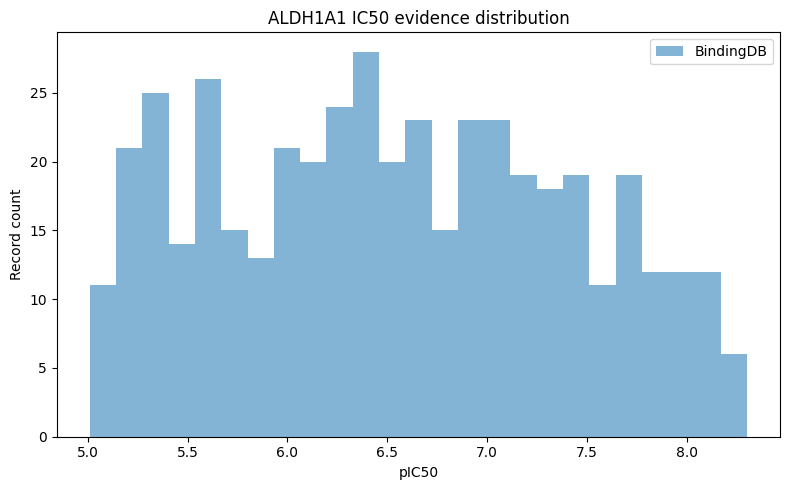

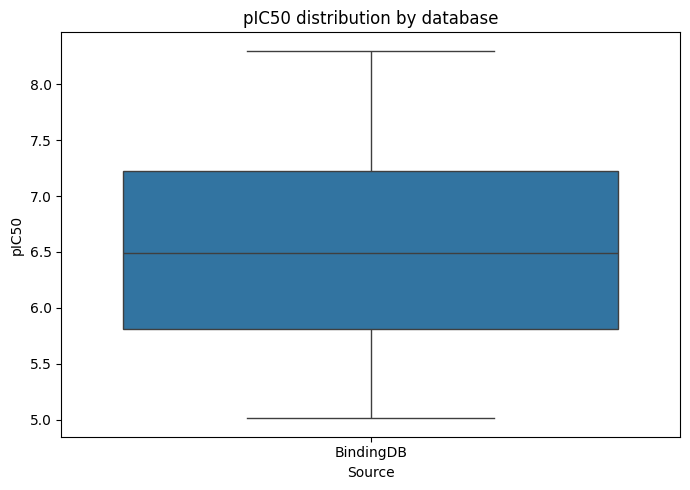


STEP 04 — DATASET ANALYSIS COMPLETE
                                    Metric  Count
                 Combined activity records    450
             Unique structures represented    300
          Strict ChEMBL exact IC50 records      0
Provisional BindingDB numeric IC50 records    450
     Structures with repeated measurements    116
          Structures with pIC50 range >0.5     86
     Structures with multiple publications     12
        Alda-1 / DEAB pending verification      2

SOURCE SUMMARY:
   Source  Records  Unique_structures  Publications  Assays  Median_IC50_nM  Minimum_IC50_nM  Maximum_IC50_nM
BindingDB      450                300            18       0           326.5              5.0           9760.0

TOP 15 DISAGREEMENT FLAGS:
                   InChIKey  Record_count  Source_count  Minimum_pIC50  Maximum_pIC50  Mean_pIC50  Median_pIC50  Publications  pIC50_range  Repeated_measurement  Review_flag_gt_0.5
SIISFRLGYDVIRG-UHFFFAOYSA-N             3             1       5.312

In [ ]:

# STEP 04 — ALDH1A1 DATASET ANALYSIS
from pathlib import Path
from datetime import datetime
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, re

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL")
OUT = ROOT / f"STEP04_DATASET_ANALYSIS_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True)

chem_file = next(ROOT.glob("03_ChEMBL_exact_records_*.csv"))
bind_file = next(ROOT.glob("04_BindingDB_provisional_records_*.csv"))

c = pd.read_csv(chem_file, low_memory=False)
b = pd.read_csv(bind_file, low_memory=False)

def first_col(df, names):
    return next((x for x in names if x in df.columns), None)

def normalise(df, source):
    if source == "ChEMBL":
        value = first_col(df, ["standard_value"])
        key = first_col(df, ["standardized_inchikey", "InChIKey"])
        smiles = first_col(df, ["standardized_smiles", "canonical_smiles"])
        relation = first_col(df, ["standard_relation"])
        units = first_col(df, ["standard_units"])
        assay = first_col(df, ["assay_chembl_id"])
        publication = first_col(df, ["document_chembl_id"])
        exact = df[relation].astype(str).eq("=") if relation else pd.Series(False, index=df.index)
        nm = df[units].astype(str).str.lower().eq("nm") if units else pd.Series(False, index=df.index)
        endpoint = df["standard_type"] if "standard_type" in df else "IC50"
    else:
        value = first_col(df, ["affinity_nM", "affinity"])
        key = first_col(df, ["standardized_inchikey", "InChIKey"])
        smiles = first_col(df, ["standardized_smiles", "smile"])
        relation = first_col(df, ["Measurement_Relation"])
        assay = None
        publication = first_col(df, ["pmid", "doi"])
        exact = pd.Series(False, index=df.index)
        nm = pd.Series(True, index=df.index)
        endpoint = df["Endpoint"] if "Endpoint" in df else "IC50"

    out = pd.DataFrame({
        "Source": source,
        "InChIKey": df[key] if key else None,
        "SMILES": df[smiles] if smiles else None,
        "IC50_nM": pd.to_numeric(df[value], errors="coerce") if value else np.nan,
        "Relation": df[relation] if relation else "UNREPORTED",
        "Endpoint": endpoint,
        "Publication": df[publication] if publication else None,
        "Assay_ID": df[assay] if assay else None
    })
    out["Exact_relation"] = exact.values
    out["Explicit_nM"] = nm.values
    out["pIC50"] = np.where(out["IC50_nM"] > 0, 9 - np.log10(out["IC50_nM"]), np.nan)
    out["Strict_ChEMBL_measurement"] = (
        (out["Source"] == "ChEMBL") &
        out["Exact_relation"] & out["Explicit_nM"] &
        (out["IC50_nM"] > 0)
    )
    out["Provisional_BindingDB_measurement"] = out["Source"].eq("BindingDB") & (out["IC50_nM"] > 0)
    return out

data = pd.concat([
    normalise(c, "ChEMBL"),
    normalise(b, "BindingDB")
], ignore_index=True)

data = data.dropna(subset=["InChIKey", "IC50_nM"])
data = data[data["IC50_nM"] > 0].copy()
data.to_csv(OUT / "01_combined_activity_evidence.csv", index=False)

# Source-level summary
source_summary = data.groupby("Source").agg(
    Records=("InChIKey", "size"),
    Unique_structures=("InChIKey", "nunique"),
    Publications=("Publication", "nunique"),
    Assays=("Assay_ID", "nunique"),
    Median_IC50_nM=("IC50_nM", "median"),
    Minimum_IC50_nM=("IC50_nM", "min"),
    Maximum_IC50_nM=("IC50_nM", "max")
).reset_index()
source_summary.to_csv(OUT / "02_source_summary.csv", index=False)

# Structure-level repeated measurements and disagreement
groups = data.groupby("InChIKey").agg(
    Record_count=("IC50_nM", "size"),
    Source_count=("Source", "nunique"),
    Minimum_pIC50=("pIC50", "min"),
    Maximum_pIC50=("pIC50", "max"),
    Mean_pIC50=("pIC50", "mean"),
    Median_pIC50=("pIC50", "median"),
    Publications=("Publication", "nunique")
).reset_index()
groups["pIC50_range"] = groups["Maximum_pIC50"] - groups["Minimum_pIC50"]
groups["Repeated_measurement"] = groups["Record_count"] > 1
groups["Review_flag_gt_0.5"] = groups["pIC50_range"] > 0.5
groups.to_csv(OUT / "03_structure_level_analysis.csv", index=False)

# Conflicting measurements
conflicts = groups[groups["Review_flag_gt_0.5"]].sort_values("pIC50_range", ascending=False)
conflicts.to_csv(OUT / "04_measurement_disagreement_review.csv", index=False)

# Literature candidates remain separate
literature_candidates = pd.DataFrame({
    "Compound": ["Alda-1", "DEAB"],
    "Status": ["Provisional — verify experimental IC50", "Provisional — verify experimental IC50"],
    "Included_in_activity_analysis": [False, False]
})
literature_candidates.to_csv(OUT / "05_literature_candidates_pending.csv", index=False)

# Figures
plt.figure(figsize=(8, 5))
for source, frame in data.groupby("Source"):
    vals = frame["pIC50"].dropna()
    if len(vals):
        plt.hist(vals, bins=25, alpha=0.55, label=source)
plt.xlabel("pIC50")
plt.ylabel("Record count")
plt.title("ALDH1A1 IC50 evidence distribution")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "06_pIC50_distribution.png", dpi=300)
plt.show()
plt.close()

plt.figure(figsize=(7, 5))
plot_data = data.dropna(subset=["pIC50"])
sns.boxplot(data=plot_data, x="Source", y="pIC50")
plt.title("pIC50 distribution by database")
plt.tight_layout()
plt.savefig(OUT / "07_source_comparison.png", dpi=300)
plt.show()
plt.close()

# Final report
strict_count = int(data["Strict_ChEMBL_measurement"].sum())
provisional_count = int(data["Provisional_BindingDB_measurement"].sum())

summary = pd.DataFrame([
    ["Combined activity records", len(data)],
    ["Unique structures represented", data["InChIKey"].nunique()],
    ["Strict ChEMBL exact IC50 records", strict_count],
    ["Provisional BindingDB numeric IC50 records", provisional_count],
    ["Structures with repeated measurements", int(groups["Repeated_measurement"].sum())],
    ["Structures with pIC50 range >0.5", len(conflicts)],
    ["Structures with multiple publications", int((groups["Publications"] > 1).sum())],
    ["Alda-1 / DEAB pending verification", 2]
], columns=["Metric", "Count"])

summary.to_csv(OUT / "08_step04_summary.csv", index=False)

print("\n" + "="*65)
print("STEP 04 — DATASET ANALYSIS COMPLETE")
print("="*65)
print(summary.to_string(index=False))
print("\nSOURCE SUMMARY:")
print(source_summary.to_string(index=False))
print("\nTOP 15 DISAGREEMENT FLAGS:")
print(conflicts.head(15).to_string(index=False))
print("\nOUTPUT FOLDER:", OUT)
print("\nDo not average conflicting measurements automatically.")
print("BindingDB remains provisional because its measurement relation is unreported.")
print("Alda-1 and DEAB remain outside the activity table until values are verified.")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL")

files = {
    "ChEMBL": next(root.glob("03_ChEMBL_exact_records_*.csv")),
    "BindingDB": next(root.glob("04_BindingDB_provisional_records_*.csv"))
}

for source, path in files.items():
    df = pd.read_csv(path, low_memory=False)
    print(f"\n{'='*65}\n{source}: {path.name}")
    print("Rows:", len(df), "| Columns:", len(df.columns))
    print("\nColumn names:")
    print(df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))
    print("\nNon-null counts:")
    print(df.notna().sum().to_string())



ChEMBL: 03_ChEMBL_exact_records_20261117_084141.csv
Rows: 445 | Columns: 56

Column names:
['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value', 'Unit_Status', 'Assay_Type_Status', 'Measurement_Status', 'Structur

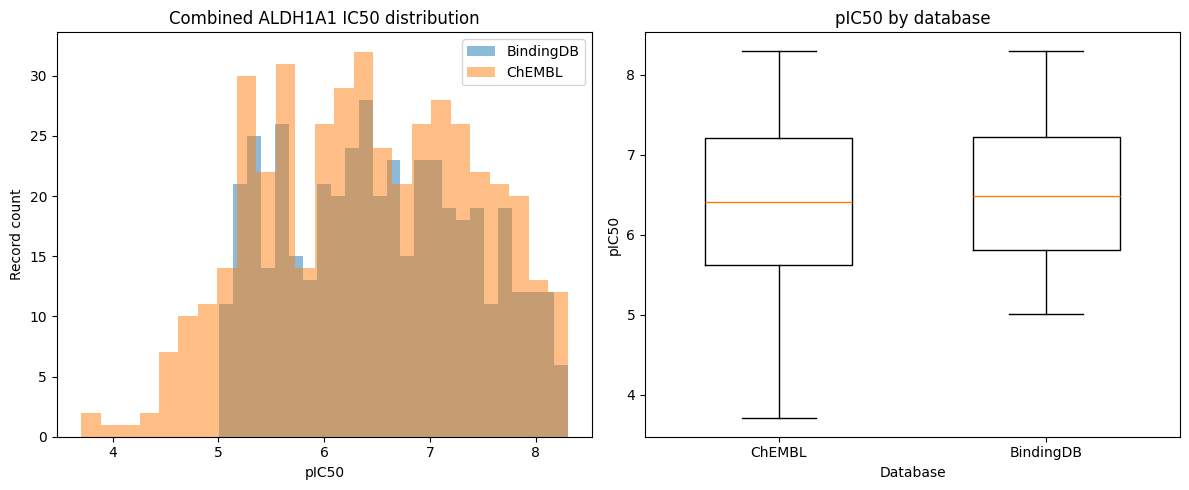


STEP 04 — CORRECTED ANALYSIS
                               Metric  Count
                     Combined records    895
            ChEMBL exact IC50 records    445
        BindingDB provisional records    450
           Combined unique structures    325
Structures with repeated measurements    291
     Structures with pIC50 range >0.5     95
Structures with multiple publications    291

SOURCE SUMMARY
   Source  Records  Unique_structures  Publications  Assays  Median_pIC50  Minimum_pIC50  Maximum_pIC50
BindingDB      450                300            21       0      6.486203       5.010550        8.30103
   ChEMBL      445                309            20      39      6.408935       3.703993        8.30103

DATABASE OVERLAP
 ChEMBL_unique  BindingDB_unique  Shared_structures  Combined_unique
           309               300                284              325

TOP 15 DISAGREEMENT FLAGS
                   InChIKey  Record_count  Source_count  Minimum_pIC50  Maximum_pIC50  Median_pIC50

In [ ]:

from pathlib import Path
from datetime import datetime
import pandas as pd, numpy as np, matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL")
OUT = ROOT / f"STEP04_CORRECTED_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True)

c = pd.read_csv(next(ROOT.glob("03_ChEMBL_exact_records_*.csv")), low_memory=False)
b = pd.read_csv(next(ROOT.glob("04_BindingDB_provisional_records_*.csv")), low_memory=False)

# Map using the actual source-file columns
chem = pd.DataFrame({
    "Source": "ChEMBL",
    "InChIKey": c["InChIKey_recalculated"],
    "SMILES": c["canonical_smiles"],
    "IC50_nM": pd.to_numeric(c["standard_value"], errors="coerce"),
    "Relation": c["standard_relation"],
    "Units": c["standard_units"],
    "Publication": c["document_chembl_id"],
    "Assay_ID": c["assay_chembl_id"],
    "Strict_evidence": (
        c["standard_relation"].astype(str).eq("=") &
        c["standard_units"].astype(str).str.lower().eq("nm") &
        c["standard_type"].astype(str).str.upper().eq("IC50")
    )
})

bind = pd.DataFrame({
    "Source": "BindingDB",
    "InChIKey": b["standardized_inchikey"],
    "SMILES": b["standardized_smiles"],
    "IC50_nM": pd.to_numeric(b["affinity_nM"], errors="coerce"),
    "Relation": b["Measurement_Relation"],
    "Units": b["Endpoint_Unit"],
    "Publication": b["doi"].fillna(b["pmid"]),
    "Assay_ID": None,
    "Strict_evidence": False
})

data = pd.concat([chem, bind], ignore_index=True)
data["IC50_nM"] = pd.to_numeric(data["IC50_nM"], errors="coerce")
data = data.dropna(subset=["InChIKey", "IC50_nM"])
data = data[data["IC50_nM"] > 0].copy()
data["pIC50"] = 9 - np.log10(data["IC50_nM"])
data["Evidence_class"] = np.where(
    data["Source"].eq("ChEMBL") & data["Strict_evidence"],
    "ChEMBL exact",
    "BindingDB provisional"
)

# Save record-level evidence
data.to_csv(OUT / "01_combined_activity_evidence.csv", index=False)

# Source summary
source_summary = data.groupby("Source").agg(
    Records=("InChIKey", "size"),
    Unique_structures=("InChIKey", "nunique"),
    Publications=("Publication", "nunique"),
    Assays=("Assay_ID", "nunique"),
    Median_pIC50=("pIC50", "median"),
    Minimum_pIC50=("pIC50", "min"),
    Maximum_pIC50=("pIC50", "max")
).reset_index()
source_summary.to_csv(OUT / "02_source_summary.csv", index=False)

# Unique-structure and disagreement analysis
groups = data.groupby("InChIKey").agg(
    Record_count=("pIC50", "size"),
    Source_count=("Source", "nunique"),
    Minimum_pIC50=("pIC50", "min"),
    Maximum_pIC50=("pIC50", "max"),
    Median_pIC50=("pIC50", "median"),
    Publications=("Publication", "nunique")
).reset_index()

groups["pIC50_range"] = groups["Maximum_pIC50"] - groups["Minimum_pIC50"]
groups["Repeated_measurement"] = groups["Record_count"] > 1
groups["Review_flag_gt_0.5"] = groups["pIC50_range"] > 0.5
groups.to_csv(OUT / "03_structure_level_analysis.csv", index=False)

conflicts = groups[groups["Review_flag_gt_0.5"]].sort_values(
    "pIC50_range", ascending=False
)
conflicts.to_csv(OUT / "04_measurement_disagreement_review.csv", index=False)

# Cross-database overlap
overlap = {
    "ChEMBL_unique": chem["InChIKey"].nunique(),
    "BindingDB_unique": bind["InChIKey"].nunique(),
    "Shared_structures": len(set(chem["InChIKey"].dropna()) & set(bind["InChIKey"].dropna())),
    "Combined_unique": data["InChIKey"].nunique()
}
pd.DataFrame([overlap]).to_csv(OUT / "05_database_overlap.csv", index=False)

# Combined distribution and source comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for source, frame in data.groupby("Source"):
    axes[0].hist(frame["pIC50"], bins=25, alpha=0.5, label=source)
    axes[1].boxplot(frame["pIC50"], positions=[0 if source == "ChEMBL" else 1],
                    widths=0.55, patch_artist=False,
                    labels=[source])
axes[0].set(xlabel="pIC50", ylabel="Record count",
            title="Combined ALDH1A1 IC50 distribution")
axes[0].legend()
axes[1].set(xlabel="Database", ylabel="pIC50",
            title="pIC50 by database")
plt.tight_layout()
plt.savefig(OUT / "06_combined_distribution.png", dpi=300)
plt.show()

# Summary
summary = pd.DataFrame([
    ["Combined records", len(data)],
    ["ChEMBL exact IC50 records", int(data["Strict_evidence"].sum())],
    ["BindingDB provisional records", int(data["Source"].eq("BindingDB").sum())],
    ["Combined unique structures", data["InChIKey"].nunique()],
    ["Structures with repeated measurements", int(groups["Repeated_measurement"].sum())],
    ["Structures with pIC50 range >0.5", len(conflicts)],
    ["Structures with multiple publications", int((groups["Publications"] > 1).sum())]
], columns=["Metric", "Count"])

summary.to_csv(OUT / "07_step04_summary.csv", index=False)

print("\nSTEP 04 — CORRECTED ANALYSIS")
print(summary.to_string(index=False))
print("\nSOURCE SUMMARY")
print(source_summary.to_string(index=False))
print("\nDATABASE OVERLAP")
print(pd.DataFrame([overlap]).to_string(index=False))
print("\nTOP 15 DISAGREEMENT FLAGS")
print(conflicts.head(15).to_string(index=False))
print("\nOUTPUT:", OUT)

# Sanity checks
assert len(chem) == 445, "Unexpected ChEMBL row count — inspect input file."
assert len(bind) == 450, "Unexpected BindingDB row count — inspect input file."
assert data["Source"].nunique() == 2, "One source is missing from the combined analysis."


In [ ]:

# STEP 05 — FINAL MOLECULAR DESCRIPTOR CALCULATION

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np
import subprocess, sys

# RDKit
try:
    from rdkit import Chem, DataStructs
    from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rdkit"])
    from rdkit import Chem, DataStructs
    from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem

# Paths
ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL")
OUT = ROOT / f"STEP05_DESCRIPTORS_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

# Load source files
inventory = pd.read_csv(next(ROOT.glob("02_final_unique_structure_inventory_*.csv")))
chem = pd.read_csv(next(ROOT.glob("03_ChEMBL_exact_records_*.csv")), low_memory=False)
bind = pd.read_csv(next(ROOT.glob("04_BindingDB_provisional_records_*.csv")), low_memory=False)

# Recover SMILES using the established InChIKeys
chem_map = chem[["InChIKey_recalculated", "canonical_smiles"]].rename(
    columns={"InChIKey_recalculated": "InChIKey", "canonical_smiles": "SMILES"}
)

bind_map = bind[["standardized_inchikey", "standardized_smiles"]].rename(
    columns={"standardized_inchikey": "InChIKey", "standardized_smiles": "SMILES"}
)

# Prefer standardized BindingDB SMILES where available
smiles_map = pd.concat([bind_map, chem_map], ignore_index=True)
smiles_map = smiles_map.dropna(subset=["InChIKey", "SMILES"])
smiles_map = smiles_map.drop_duplicates("InChIKey")

structures = (
    inventory[["InChIKey"]]
    .drop_duplicates()
    .merge(smiles_map, on="InChIKey", how="left")
)

missing = structures[structures["SMILES"].isna()]
missing.to_csv(OUT / "01_structures_missing_SMILES.csv", index=False)

structures = structures.dropna(subset=["SMILES"]).copy()

# Descriptor definitions
descriptor_functions = Descriptors._descList
results, fingerprints, invalid = [], [], []
descriptor_errors = []

for _, row in structures.iterrows():

    key = row["InChIKey"]
    smiles = str(row["SMILES"])
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        invalid.append({"InChIKey": key, "SMILES": smiles})
        continue

    # Complete RDKit 2D descriptor set
    values = {}

    for name, function in descriptor_functions:
        try:
            values[name] = function(mol)
        except Exception as e:
            values[name] = np.nan
            descriptor_errors.append({
                "InChIKey": key,
                "Descriptor": name,
                "Error": str(e)
            })

    # Additional commonly used physicochemical descriptors
    extra = {
        "MW": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": rdMolDescriptors.CalcNumHBD(mol),
        "HBA": rdMolDescriptors.CalcNumHBA(mol),
        "RotatableBonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
        "RingCount": Descriptors.RingCount(mol),
        "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol)
    }

    values.update(extra)
    values["InChIKey"] = key
    values["SMILES"] = smiles
    results.append(values)

    # Morgan fingerprint: radius 2, 2048 bits
    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol, radius=2, nBits=2048
    )

    arr = np.zeros(2048, dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    fingerprints.append({
        "InChIKey": key,
        **{f"FP_{i}": int(v) for i, v in enumerate(arr)}
    })

# Create output dataframes
desc = pd.DataFrame(results)
fp_df = pd.DataFrame(fingerprints)

# Save outputs
desc.to_csv(OUT / "02_RDKit_2D_descriptors.csv", index=False)
fp_df.to_csv(OUT / "03_Morgan_fingerprints_2048.csv", index=False)

pd.DataFrame(invalid).to_csv(
    OUT / "04_invalid_structures.csv", index=False
)

pd.DataFrame(descriptor_errors).to_csv(
    OUT / "05_descriptor_calculation_errors.csv", index=False
)

# Descriptor quality report
if not desc.empty:
    numeric = desc.select_dtypes(include=np.number)

    quality = pd.DataFrame({
        "Missing_values": numeric.isna().sum(),
        "Unique_values": numeric.nunique(),
        "Mean": numeric.mean(),
        "SD": numeric.std(),
        "Minimum": numeric.min(),
        "Maximum": numeric.max()
    })

    quality.index.name = "Descriptor"
    quality.to_csv(OUT / "06_descriptor_quality_report.csv")

# Final report
print("\n" + "=" * 65)
print("STEP 05 — MOLECULAR DESCRIPTOR CALCULATION")
print("=" * 65)

print("Unique structures in inventory:", inventory["InChIKey"].nunique())
print("Structures with recovered SMILES:", len(structures))
print("Valid molecules processed:", len(desc))
print("Invalid molecules:", len(invalid))
print("Structures missing SMILES:", len(missing))
print("RDKit 2D descriptor functions:", len(descriptor_functions))
print("Additional physicochemical descriptors: 9")
print("Morgan fingerprint bits: 2048")

print("\nDescriptor matrix:", desc.shape)
print("Fingerprint matrix:", fp_df.shape)
print("Descriptor calculation errors:", len(descriptor_errors))

print("\nOutput folder:", OUT)

# Validation
assert len(desc) + len(invalid) == len(structures)
assert desc["InChIKey"].is_unique
assert fp_df["InChIKey"].is_unique
assert set(desc["InChIKey"]) == set(fp_df["InChIKey"])

print("\nVALIDATION PASSED")
print("One descriptor profile and fingerprint per valid unique structure.")



STEP 05 — MOLECULAR DESCRIPTOR CALCULATION
Unique structures in inventory: 325
Structures with recovered SMILES: 325
Valid molecules processed: 325
Invalid molecules: 0
Structures missing SMILES: 0
RDKit 2D descriptor functions: 217
Additional physicochemical descriptors: 9
Morgan fingerprint bits: 2048

Descriptor matrix: (325, 225)
Fingerprint matrix: (325, 2049)
Descriptor calculation errors: 0

Output folder: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_DESCRIPTORS_20261117_102054

VALIDATION PASSED
One descriptor profile and fingerprint per valid unique structure.


In [ ]:

# STEP 05.2 — INDEPENDENT PUBLICATION-QUALITY QC AUDIT

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np
import hashlib, json, platform
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem

# Paths
ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL")
STEP05 = ROOT / "STEP05_DESCRIPTORS_20261117_102054"
OUT = ROOT / f"STEP05_2_INDEPENDENT_QC_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

inventory = pd.read_csv(next(ROOT.glob("02_final_unique_structure_inventory_*.csv")))
desc = pd.read_csv(STEP05 / "02_RDKit_2D_descriptors.csv")
fp = pd.read_csv(STEP05 / "03_Morgan_fingerprints_2048.csv")

# 1. Basic integrity
assert inventory["InChIKey"].is_unique
assert desc["InChIKey"].is_unique
assert fp["InChIKey"].is_unique

inventory_keys = set(inventory["InChIKey"].dropna())
descriptor_keys = set(desc["InChIKey"].dropna())
fingerprint_keys = set(fp["InChIKey"].dropna())

identity = pd.DataFrame([
    ["Inventory structures", len(inventory_keys)],
    ["Descriptor structures", len(descriptor_keys)],
    ["Fingerprint structures", len(fingerprint_keys)],
    ["Missing descriptor structures", len(inventory_keys - descriptor_keys)],
    ["Unexpected descriptor structures", len(descriptor_keys - inventory_keys)],
    ["Missing fingerprint structures", len(descriptor_keys - fingerprint_keys)]
], columns=["Check", "Result"])

identity.to_csv(OUT / "01_structure_identity.csv", index=False)

# 2. Independently recalculate chemical identifiers and selected descriptors
checks = []

for _, row in desc.iterrows():
    mol = Chem.MolFromSmiles(str(row["SMILES"]))

    if mol is None:
        checks.append({"InChIKey": row["InChIKey"], "Valid_SMILES": False})
        continue

    calculated_key = Chem.MolToInchiKey(mol)

    checks.append({
        "InChIKey": row["InChIKey"],
        "Valid_SMILES": True,
        "Recalculated_InChIKey": calculated_key,
        "InChIKey_Match": calculated_key == row["InChIKey"],
        "MW_recalculated": Descriptors.MolWt(mol),
        "LogP_recalculated": Descriptors.MolLogP(mol),
        "TPSA_recalculated": rdMolDescriptors.CalcTPSA(mol),
        "HBD_recalculated": rdMolDescriptors.CalcNumHBD(mol),
        "HBA_recalculated": rdMolDescriptors.CalcNumHBA(mol),
        "RingCount_recalculated": Descriptors.RingCount(mol)
    })

check_df = pd.DataFrame(checks)
check_df.to_csv(OUT / "02_independent_structure_descriptor_check.csv", index=False)

# 3. Compare stored and independently recalculated descriptors
comparisons = {
    "MW": "MW_recalculated",
    "LogP": "LogP_recalculated",
    "TPSA": "TPSA_recalculated",
    "HBD": "HBD_recalculated",
    "HBA": "HBA_recalculated",
    "RingCount": "RingCount_recalculated"
}

comparison_results = []

for stored, recalculated in comparisons.items():
    if stored not in desc.columns:
        comparison_results.append([stored, "MISSING_COLUMN", np.nan, np.nan])
        continue

    a = pd.to_numeric(desc[stored], errors="coerce").to_numpy()
    b = pd.to_numeric(check_df[recalculated], errors="coerce").to_numpy()
    diff = np.abs(a - b)

    comparison_results.append([
        stored,
        "PASS" if np.allclose(a, b, rtol=1e-7, atol=1e-7, equal_nan=True) else "REVIEW",
        np.nanmax(diff) if np.isfinite(diff).any() else np.nan,
        int(np.sum(~np.isclose(a, b, rtol=1e-7, atol=1e-7, equal_nan=True)))
    ])

comparison_df = pd.DataFrame(
    comparison_results,
    columns=["Descriptor", "Status", "Maximum_absolute_difference", "Mismatched_values"]
)
comparison_df.to_csv(OUT / "03_descriptor_recalculation_comparison.csv", index=False)

# 4. Descriptor matrix quality
numeric = desc.select_dtypes(include=np.number)
finite = np.isfinite(numeric.to_numpy())
missing_counts = numeric.isna().sum()
infinite_counts = pd.Series(
    np.isinf(numeric.to_numpy()).sum(axis=0), index=numeric.columns
)
unique_counts = numeric.nunique(dropna=True)
variances = numeric.var()

quality = pd.DataFrame({
    "Missing": missing_counts,
    "Infinite": infinite_counts,
    "Unique_values": unique_counts,
    "Variance": variances
})
quality["Constant"] = quality["Unique_values"] <= 1
quality["Near_zero_variance_candidate"] = (
    (quality["Unique_values"] > 1) &
    (quality["Variance"] < 1e-6)
)
quality.to_csv(OUT / "04_descriptor_matrix_quality.csv")

# 5. Exact duplicate descriptor columns
feature_cols = [
    col for col in numeric.columns
    if col not in ["pIC50"]
]
duplicate_columns = {}
for i, col in enumerate(feature_cols):
    for other in feature_cols[:i]:
        if numeric[col].equals(numeric[other]):
            duplicate_columns.setdefault(col, []).append(other)

pd.DataFrame([
    {"Descriptor": k, "Identical_to": "; ".join(v)}
    for k, v in duplicate_columns.items()
]).to_csv(OUT / "05_duplicate_descriptor_columns.csv", index=False)

# 6. High correlation between descriptors
corr = numeric[feature_cols].corr(method="pearson")
corr.to_csv(OUT / "06_descriptor_correlation_matrix.csv")

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "Descriptor_1",
                     "level_1": "Descriptor_2", 0: "Correlation"})
)
high_corr["Absolute_correlation"] = high_corr["Correlation"].abs()
high_corr = high_corr[high_corr["Absolute_correlation"] >= 0.90]
high_corr = high_corr.sort_values("Absolute_correlation", ascending=False)
high_corr.to_csv(OUT / "07_highly_correlated_descriptors.csv", index=False)

# 7. Fingerprint validation
fp_cols = [c for c in fp.columns if c.startswith("FP_")]
fp_values = fp[fp_cols].apply(pd.to_numeric, errors="coerce")

fingerprint_report = pd.DataFrame([{
    "Fingerprint_rows": len(fp),
    "Fingerprint_bits": len(fp_cols),
    "Missing_values": int(fp_values.isna().sum().sum()),
    "Non_binary_values": int((~fp_values.isin([0, 1])).sum().sum()),
    "Unique_fingerprints": len(fp_values.drop_duplicates()),
    "All_fingerprints_unique": fp_values.drop_duplicates().shape[0] == len(fp)
}])
fingerprint_report.to_csv(OUT / "08_fingerprint_integrity.csv", index=False)

# 8. Reproducibility metadata and checksums
metadata = {
    "Python_version": platform.python_version(),
    "RDKit_version": rdBase.rdkitVersion,
    "Descriptor_file_SHA256": hashlib.sha256(
        (STEP05 / "02_RDKit_2D_descriptors.csv").read_bytes()
    ).hexdigest(),
    "Fingerprint_file_SHA256": hashlib.sha256(
        (STEP05 / "03_Morgan_fingerprints_2048.csv").read_bytes()
    ).hexdigest(),
    "Descriptor_rows": len(desc),
    "Descriptor_columns": len(desc.columns),
    "Fingerprint_rows": len(fp),
    "Fingerprint_bits": len(fp_cols)
}
with open(OUT / "09_reproducibility_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

# 9. Final report
print("\n" + "="*65)
print("STEP 05.2 — INDEPENDENT QC AUDIT")
print("="*65)

print("\nSTRUCTURE IDENTITY")
print(identity.to_string(index=False))

print("\nINDEPENDENT DESCRIPTOR RECALCULATION")
print(comparison_df.to_string(index=False))

print("\nDESCRIPTOR MATRIX")
print("Numeric descriptor columns:", len(numeric.columns))
print("Missing values:", int(missing_counts.sum()))
print("Infinite values:", int(infinite_counts.sum()))
print("Constant columns:", int(quality["Constant"].sum()))
print("Near-zero variance candidates:", int(quality["Near_zero_variance_candidate"].sum()))
print("Exact duplicate descriptor columns:", len(duplicate_columns))
print("Highly correlated pairs (|r| >= 0.90):", len(high_corr))

print("\nFINGERPRINT VALIDATION")
print(fingerprint_report.to_string(index=False))

print("\nINCHIKEY MATCHES:")
print(int(check_df.get("InChIKey_Match", pd.Series(dtype=bool)).sum()),
      "/", len(check_df))

print("\nRDKit version:", rdBase.rdkitVersion)
print("Python version:", platform.python_version())
print("\nOUTPUT:", OUT)

# Fundamental validation assertions
assert len(inventory_keys - descriptor_keys) == 0
assert len(descriptor_keys - inventory_keys) == 0
assert len(descriptor_keys - fingerprint_keys) == 0
assert check_df["Valid_SMILES"].all()
assert check_df["InChIKey_Match"].all()
assert comparison_df["Status"].eq("PASS").all()
assert int(missing_counts.sum()) == 0
assert int(infinite_counts.sum()) == 0
assert int(fingerprint_report["Non_binary_values"].iloc[0]) == 0
assert len(fp_cols) == 2048

print("\nCORE QC CHECKS PASSED")



STEP 05.2 — INDEPENDENT QC AUDIT

STRUCTURE IDENTITY
                           Check  Result
            Inventory structures     325
           Descriptor structures     325
          Fingerprint structures     325
   Missing descriptor structures       0
Unexpected descriptor structures       0
  Missing fingerprint structures       0

INDEPENDENT DESCRIPTOR RECALCULATION
Descriptor Status  Maximum_absolute_difference  Mismatched_values
        MW   PASS                 5.684342e-14                  0
      LogP   PASS                 1.776357e-15                  0
      TPSA   PASS                 2.842171e-14                  0
       HBD   PASS                 0.000000e+00                  0
       HBA   PASS                 0.000000e+00                  0
 RingCount   PASS                 0.000000e+00                  0

DESCRIPTOR MATRIX
Numeric descriptor columns: 223
Missing values: 108
Infinite values: 0
Constant columns: 28
Near-zero variance candidates: 0
Exact duplicate

AssertionError: 

In [ ]:

# STEP 05.3 — DESCRIPTOR DEFECT IDENTIFICATION (FIXED)

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL")
STEP05 = ROOT / "STEP05_DESCRIPTORS_20261117_102054"
OUT = ROOT / "STEP05_2_INDEPENDENT_QC_20261117_102250"

desc = pd.read_csv(STEP05 / "02_RDKit_2D_descriptors.csv")
fp = pd.read_csv(STEP05 / "03_Morgan_fingerprints_2048.csv")

numeric = desc.select_dtypes(include=np.number)

# 1. Missing descriptor report
missing = numeric.isna().sum()
missing_report = missing[missing > 0].sort_values(ascending=False).to_frame("Missing_count")
missing_report.index.name = "Descriptor"
missing_report = missing_report.reset_index()
missing_report["Missing_percent"] = missing_report["Missing_count"] / len(desc) * 100
missing_report.to_csv(OUT / "10_missing_descriptor_report.csv", index=False)

# 2. Compounds with missing descriptors
missing_mask = numeric.isna().any(axis=1)
missing_compounds = desc.loc[missing_mask, ["InChIKey", "SMILES"]].copy()
missing_compounds["Missing_descriptor_count"] = numeric.isna().sum(axis=1)[missing_mask]
missing_compounds.to_csv(OUT / "11_compounds_with_missing_descriptors.csv", index=False)

# 3. Constant descriptors
constant = numeric.columns[numeric.nunique(dropna=True) <= 1].tolist()
pd.DataFrame({"Constant_descriptor": constant}).to_csv(
    OUT / "12_constant_descriptors.csv", index=False
)

# 4. Exact duplicate descriptor columns
features = numeric.columns.tolist()
duplicates = []

for i, col in enumerate(features):
    for other in features[:i]:
        if numeric[col].equals(numeric[other]):
            duplicates.append({
                "Duplicate_descriptor": col,
                "Identical_descriptor": other
            })

pd.DataFrame(duplicates, columns=[
    "Duplicate_descriptor", "Identical_descriptor"
]).to_csv(OUT / "13_exact_duplicate_descriptors.csv", index=False)

# 5. Identical Morgan fingerprints
fp_cols = [c for c in fp.columns if c.startswith("FP_")]
fp_strings = fp[fp_cols].astype(str).agg("".join, axis=1)

fp_groups = pd.DataFrame({
    "InChIKey": fp["InChIKey"],
    "Fingerprint": fp_strings
}).groupby("Fingerprint").agg(
    InChIKeys=("InChIKey", lambda x: "; ".join(x)),
    Structure_count=("InChIKey", "size")
).reset_index()

fp_groups = fp_groups[fp_groups["Structure_count"] > 1]
fp_groups.to_csv(OUT / "14_identical_fingerprint_groups.csv", index=False)

# 6. High-correlation pairs
corr = numeric.corr()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

high_corr = upper.stack().reset_index()
high_corr.columns = ["Descriptor_1", "Descriptor_2", "Correlation"]
high_corr["Absolute_correlation"] = high_corr["Correlation"].abs()
high_corr = high_corr[high_corr["Absolute_correlation"] >= 0.90]
high_corr = high_corr.sort_values("Absolute_correlation", ascending=False)
high_corr.to_csv(OUT / "15_high_correlation_pairs.csv", index=False)

# 7. Results
print("=" * 65)
print("STEP 05.3 — DEFECT IDENTIFICATION")
print("=" * 65)

print("\nMISSING DESCRIPTORS")
print(missing_report.to_string(index=False))

print("\nCOMPOUNDS WITH MISSING DESCRIPTORS:", len(missing_compounds))
print(missing_compounds.head(15).to_string(index=False))

print("\nCONSTANT DESCRIPTORS:", len(constant))
print(constant)

print("\nEXACT DUPLICATE DESCRIPTOR PAIRS:", len(duplicates))
print(pd.DataFrame(duplicates).head(25).to_string(index=False))

print("\nIDENTICAL FINGERPRINT GROUPS")
print(fp_groups.to_string(index=False))

print("\nHIGH-CORRELATION PAIRS:", len(high_corr))
print(high_corr.head(25).to_string(index=False))

print("\nReports saved in:", OUT)


STEP 05.3 — DEFECT IDENTIFICATION

MISSING DESCRIPTORS
         Descriptor  Missing_count  Missing_percent
   MaxPartialCharge              9         2.769231
   MinPartialCharge              9         2.769231
MaxAbsPartialCharge              9         2.769231
MinAbsPartialCharge              9         2.769231
        BCUT2D_MWHI              9         2.769231
       BCUT2D_MWLOW              9         2.769231
       BCUT2D_CHGHI              9         2.769231
       BCUT2D_CHGLO              9         2.769231
      BCUT2D_LOGPHI              9         2.769231
     BCUT2D_LOGPLOW              9         2.769231
        BCUT2D_MRHI              9         2.769231
       BCUT2D_MRLOW              9         2.769231

COMPOUNDS WITH MISSING DESCRIPTORS: 9
                   InChIKey                                                SMILES  Missing_descriptor_count
CTMWLASFQMUKTH-UHFFFAOYSA-N       N=C(N)[Se]Cc1ccc(CN2C(=O)C(=O)c3cc(Br)ccc32)cc1                        12
KENMAPRTAJQLMN

In [ ]:

# STEP 05.4 — FINAL DESCRIPTOR QC AND CHIRALITY-AWARE FINGERPRINTS

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import Descriptors, AllChem

ROOT = Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL")
STEP05 = ROOT / "STEP05_DESCRIPTORS_20261117_102054"
OUT = ROOT / f"STEP05_4_FINAL_QC_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

desc = pd.read_csv(STEP05 / "02_RDKit_2D_descriptors.csv")
fp_old = pd.read_csv(STEP05 / "03_Morgan_fingerprints_2048.csv")

# 1. Investigate missing descriptor calculations
numeric = desc.select_dtypes(include=np.number)
missing_cols = numeric.columns[numeric.isna().any()].tolist()
missing_rows = desc[numeric.isna().any(axis=1)]

descriptor_functions = dict(Descriptors._descList)
errors = []

for _, row in missing_rows.iterrows():
    mol = Chem.MolFromSmiles(str(row["SMILES"]))

    for name in missing_cols:
        fn = descriptor_functions.get(name)
        if fn is None:
            continue
        try:
            value = fn(mol)
            errors.append({
                "InChIKey": row["InChIKey"],
                "Descriptor": name,
                "Recalculated_value": value,
                "Still_missing": pd.isna(value),
                "Error": ""
            })
        except Exception as e:
            errors.append({
                "InChIKey": row["InChIKey"],
                "Descriptor": name,
                "Recalculated_value": np.nan,
                "Still_missing": True,
                "Error": str(e)
            })

error_df = pd.DataFrame(errors)
error_df.to_csv(OUT / "01_missing_descriptor_investigation.csv", index=False)

# 2. Identify constant descriptors
numeric = desc.select_dtypes(include=np.number)
constant = numeric.columns[numeric.nunique(dropna=True) <= 1].tolist()
variable = [c for c in numeric.columns if c not in constant]

pd.DataFrame({"Constant_descriptor": constant}).to_csv(
    OUT / "02_constant_descriptors.csv", index=False
)

# 3. Identify exact duplicate NONCONSTANT descriptors
duplicates = []
seen = {}

for col in variable:
    matched = None
    for old in seen:
        if numeric[col].equals(numeric[old]):
            matched = old
            break

    if matched:
        duplicates.append({
            "Duplicate": col,
            "Identical_to": matched
        })
    else:
        seen[col] = col

pd.DataFrame(
    duplicates, columns=["Duplicate", "Identical_to"]
).to_csv(OUT / "03_nonconstant_duplicate_descriptors.csv", index=False)

# 4. Correlation after excluding constant and duplicate columns
duplicate_names = {x["Duplicate"] for x in duplicates}
selected = [c for c in variable if c not in duplicate_names]

corr = numeric[selected].corr()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pairs = upper.stack().reset_index()
pairs.columns = ["Descriptor_1", "Descriptor_2", "Correlation"]
pairs["Absolute_correlation"] = pairs["Correlation"].abs()
pairs = pairs[pairs["Absolute_correlation"] >= 0.90].sort_values(
    "Absolute_correlation", ascending=False
)

corr.to_csv(OUT / "04_reduced_candidate_correlation_matrix.csv")
pairs.to_csv(OUT / "05_high_correlation_after_exact_deduplication.csv", index=False)

# 5. Generate chirality-aware Morgan fingerprints
chiral_fps = []

for _, row in desc.iterrows():
    mol = Chem.MolFromSmiles(str(row["SMILES"]))

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius=2,
        nBits=2048,
        useChirality=True
    )

    arr = np.zeros(2048, dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    chiral_fps.append({
        "InChIKey": row["InChIKey"],
        **{f"FP_{i}": int(v) for i, v in enumerate(arr)}
    })

fp_chiral = pd.DataFrame(chiral_fps)
fp_chiral.to_csv(
    OUT / "06_Morgan_chirality_aware_2048.csv", index=False
)

# 6. Compare fingerprint uniqueness
old_cols = [c for c in fp_old.columns if c.startswith("FP_")]
new_cols = [c for c in fp_chiral.columns if c.startswith("FP_")]

old_unique = fp_old[old_cols].drop_duplicates().shape[0]
new_unique = fp_chiral[new_cols].drop_duplicates().shape[0]

# 7. Summary
summary = pd.DataFrame([
    ["Structures", len(desc)],
    ["Descriptors with missing values", len(missing_cols)],
    ["Compounds with missing descriptors", len(missing_rows)],
    ["Constant descriptors", len(constant)],
    ["Nonconstant exact duplicate columns", len(duplicates)],
    ["Remaining variable descriptor columns", len(selected)],
    ["High-correlation pairs after exact deduplication", len(pairs)],
    ["Original unique fingerprints", old_unique],
    ["Chirality-aware unique fingerprints", new_unique]
], columns=["Metric", "Result"])

summary.to_csv(OUT / "07_final_qc_summary.csv", index=False)

# 8. Software and reproducibility information
metadata = pd.DataFrame([{
    "RDKit_version": rdBase.rdkitVersion,
    "Structure_count": len(desc),
    "Morgan_radius": 2,
    "Fingerprint_bits": 2048,
    "Chirality_encoded": True,
    "Correlation_threshold": 0.90
}])

metadata.to_csv(OUT / "08_method_metadata.csv", index=False)

# 9. Final report
print("\n" + "=" * 65)
print("STEP 05.4 — FINAL DESCRIPTOR QC")
print("=" * 65)

print("\nSUMMARY")
print(summary.to_string(index=False))

print("\nMISSING DESCRIPTOR INVESTIGATION")
if not error_df.empty:
    print(error_df.groupby("Descriptor").agg(
        Recalculation_failures=("Still_missing", "sum"),
        Compounds_tested=("InChIKey", "nunique")
    ).to_string())

print("\nCONSTANT DESCRIPTORS:")
print(constant)

print("\nNONCONSTANT DUPLICATE PAIRS:")
print(pd.DataFrame(duplicates).to_string(index=False))

print("\nTOP 20 REMAINING CORRELATIONS:")
print(pairs.head(20).to_string(index=False))

print("\nRDKit version:", rdBase.rdkitVersion)
print("Output folder:", OUT)
print("\nOriginal descriptor files preserved.")
print("No compounds or descriptors deleted.")

# Core integrity checks
assert len(desc) == 325
assert desc["InChIKey"].is_unique
assert len(fp_chiral) == 325
assert fp_chiral["InChIKey"].is_unique
assert len(new_cols) == 2048
assert set(desc["InChIKey"]) == set(fp_chiral["InChIKey"])

print("\nCORE STRUCTURE AND FINGERPRINT CHECKS PASSED")



STEP 05.4 — FINAL DESCRIPTOR QC

SUMMARY
                                          Metric  Result
                                      Structures     325
                 Descriptors with missing values      12
              Compounds with missing descriptors       9
                            Constant descriptors      28
             Nonconstant exact duplicate columns      14
           Remaining variable descriptor columns     181
High-correlation pairs after exact deduplication     140
                    Original unique fingerprints     322
             Chirality-aware unique fingerprints     325

MISSING DESCRIPTOR INVESTIGATION
                     Recalculation_failures  Compounds_tested
Descriptor                                                   
BCUT2D_CHGHI                              9                 9
BCUT2D_CHGLO                              9                 9
BCUT2D_LOGPHI                             9                 9
BCUT2D_LOGPLOW                            9 

In [ ]:

# STEP 05.5 — MODELLING FEATURE MATRIX PREPARATION

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

STEP05 = ROOT / "STEP05_DESCRIPTORS_20261117_102054"
STEP054 = ROOT / "STEP05_4_FINAL_QC_20261117_102808"

OUT = ROOT / f"STEP05_5_FEATURE_MATRICES_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

desc = pd.read_csv(STEP05 / "02_RDKit_2D_descriptors.csv")
fp = pd.read_csv(STEP054 / "06_Morgan_chirality_aware_2048.csv")

ID = "InChIKey"

assert ID in desc.columns
assert ID in fp.columns
assert desc[ID].is_unique
assert fp[ID].is_unique

print("Descriptor structures:", len(desc))
print("Fingerprint structures:", len(fp))

# --------------------------------------------------
# 2. PREPARE 2D DESCRIPTOR MATRIX
# --------------------------------------------------

numeric = desc.select_dtypes(include=np.number)

# Remove constant descriptors
constant_cols = [
    col for col in numeric.columns
    if numeric[col].nunique(dropna=True) <= 1
]

remaining = numeric.drop(columns=constant_cols)

# Remove descriptors containing missing values
missing_cols = [
    col for col in remaining.columns
    if remaining[col].isna().any()
]

remaining = remaining.drop(columns=missing_cols)

# Remove exact duplicate descriptors
duplicate_cols = []
kept_cols = []

for col in remaining.columns:
    duplicate_of = None

    for kept in kept_cols:
        if remaining[col].equals(remaining[kept]):
            duplicate_of = kept
            break

    if duplicate_of is not None:
        duplicate_cols.append({
            "Removed_descriptor": col,
            "Retained_descriptor": duplicate_of
        })
    else:
        kept_cols.append(col)

# Build final descriptor matrix
descriptor_matrix = pd.concat(
    [
        desc[[ID]].reset_index(drop=True),
        remaining[kept_cols].reset_index(drop=True)
    ],
    axis=1
)

# --------------------------------------------------
# 3. PREPARE CHIRALITY-AWARE MORGAN MATRIX
# --------------------------------------------------

fp_cols = [c for c in fp.columns if c.startswith("FP_")]

assert len(fp_cols) == 2048

fingerprint_matrix = fp[[ID] + fp_cols].copy()

# --------------------------------------------------
# 4. ALIGN BOTH MATRICES BY STRUCTURE ID
# --------------------------------------------------

descriptor_matrix = descriptor_matrix.sort_values(ID).reset_index(drop=True)
fingerprint_matrix = fingerprint_matrix.sort_values(ID).reset_index(drop=True)

assert descriptor_matrix[ID].equals(fingerprint_matrix[ID])

# --------------------------------------------------
# 5. VALIDATE MATRICES
# --------------------------------------------------

descriptor_values = descriptor_matrix.drop(columns=ID)
fingerprint_values = fingerprint_matrix[fp_cols]

assert descriptor_matrix[ID].is_unique
assert fingerprint_matrix[ID].is_unique
assert not descriptor_values.isna().any().any()
assert np.isfinite(descriptor_values.to_numpy()).all()

assert set(np.unique(fingerprint_values.to_numpy())).issubset({0, 1})
assert not fingerprint_values.isna().any().any()

assert len(descriptor_matrix) == 325
assert len(fingerprint_matrix) == 325

# --------------------------------------------------
# 6. SAVE OUTPUTS
# --------------------------------------------------

descriptor_matrix.to_csv(
    OUT / "01_final_2D_descriptor_matrix.csv",
    index=False
)

fingerprint_matrix.to_csv(
    OUT / "02_final_Morgan_chiral_2048_matrix.csv",
    index=False
)

pd.DataFrame({
    "Descriptor": kept_cols
}).to_csv(
    OUT / "03_retained_descriptor_list.csv",
    index=False
)

pd.DataFrame({
    "Constant_descriptor": constant_cols
}).to_csv(
    OUT / "04_excluded_constant_descriptors.csv",
    index=False
)

pd.DataFrame({
    "Missing_descriptor": missing_cols
}).to_csv(
    OUT / "05_excluded_missing_descriptors.csv",
    index=False
)

pd.DataFrame(
    duplicate_cols,
    columns=["Removed_descriptor", "Retained_descriptor"]
).to_csv(
    OUT / "06_excluded_duplicate_descriptors.csv",
    index=False
)

# --------------------------------------------------
# 7. QC SUMMARY
# --------------------------------------------------

summary = pd.DataFrame([
    ["Unique structures", len(descriptor_matrix)],
    ["Original numeric descriptors", len(numeric.columns)],
    ["Constant descriptors excluded", len(constant_cols)],
    ["Missing-value descriptors excluded", len(missing_cols)],
    ["Exact duplicate descriptors excluded", len(duplicate_cols)],
    ["Final 2D descriptors retained", len(kept_cols)],
    ["Morgan fingerprint bits", len(fp_cols)],
    ["Unique chirality-aware fingerprints",
     fingerprint_values.drop_duplicates().shape[0]],
    ["Descriptor matrix missing values",
     int(descriptor_values.isna().sum().sum())],
    ["Fingerprint matrix missing values",
     int(fingerprint_values.isna().sum().sum())]
], columns=["Metric", "Result"])

summary.to_csv(OUT / "07_feature_matrix_QC_summary.csv", index=False)

print("\n" + "=" * 60)
print("STEP 05.5 — FEATURE MATRIX PREPARATION")
print("=" * 60)

print("\n", summary.to_string(index=False))

print("\nDescriptor matrix shape:", descriptor_matrix.shape)
print("Fingerprint matrix shape:", fingerprint_matrix.shape)

print("\nOutput folder:", OUT)

print("\nVALIDATION PASSED")
print("Both matrices contain the same 325 structures.")
print("No activity labels have been assigned or modified.")
print("No correlation-based feature selection has been performed.")


Descriptor structures: 325
Fingerprint structures: 325

STEP 05.5 — FEATURE MATRIX PREPARATION

                               Metric  Result
                   Unique structures     325
        Original numeric descriptors     223
       Constant descriptors excluded      28
  Missing-value descriptors excluded      12
Exact duplicate descriptors excluded      14
       Final 2D descriptors retained     169
             Morgan fingerprint bits    2048
 Unique chirality-aware fingerprints     325
    Descriptor matrix missing values       0
   Fingerprint matrix missing values       0

Descriptor matrix shape: (325, 170)
Fingerprint matrix shape: (325, 2049)

Output folder: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_5_FEATURE_MATRICES_20261117_103115

VALIDATION PASSED
Both matrices contain the same 325 structures.
No activity labels have been assigned or modified.
No correlation-based feature sel

In [ ]:

# STEP 06.1 — ACTIVITY DATA SCHEMA AUDIT
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

files = {
    "ChEMBL": ROOT / "03_ChEMBL_exact_records_20261117_084141.csv",
    "BindingDB": ROOT / "04_BindingDB_provisional_records_20261117_084141.csv",
    "Structure inventory": next(
        ROOT.glob("02_final_unique_structure_inventory_*.csv")
    )
}

data = {}

for name, path in files.items():
    print("\n" + "=" * 75)
    print(name.upper())
    print("=" * 75)

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    df = pd.read_csv(path, low_memory=False)
    data[name] = df

    print("File:", path.name)
    print("Shape:", df.shape)

    print("\nCOLUMN NAMES AND DATA TYPES")
    print(pd.DataFrame({
        "Column": df.columns,
        "Data_type": df.dtypes.astype(str).values,
        "Missing_values": df.isna().sum().values,
        "Unique_values": df.nunique(dropna=True).values
    }).to_string(index=False))

    print("\nFIRST 3 RECORDS")
    print(df.head(3).to_string(index=False))

    print("\n")

# Save schema report
out = ROOT / "STEP06_1_ACTIVITY_SCHEMA_AUDIT"
out.mkdir(exist_ok=True)

for name, df in data.items():
    pd.DataFrame({
        "Column": df.columns,
        "Data_type": df.dtypes.astype(str).values,
        "Missing_values": df.isna().sum().values,
        "Unique_values": df.nunique(dropna=True).values
    }).to_csv(
        out / f"{name.replace(' ', '_')}_schema.csv",
        index=False
    )

print("Schema reports saved to:", out)



CHEMBL
File: 03_ChEMBL_exact_records_20261117_084141.csv
Shape: (445, 56)

COLUMN NAMES AND DATA TYPES
                   Column Data_type  Missing_values  Unique_values
              action_type    object             333              1
         activity_comment   float64             429             16
              activity_id     int64               0            445
      activity_properties    object               0              5
          assay_chembl_id    object               0             39
        assay_description    object               0             37
               assay_type    object               0              1
  assay_variant_accession    object             443              1
   assay_variant_mutation    object             443              1
             bao_endpoint    object               0              1
               bao_format    object               0              4
                bao_label    object               0              4
         canonical_smiles

In [ ]:

# STEP 06.2 — MEASUREMENT DUPLICATION AND CONFLICT AUDIT

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

CHEMBL_FILE = ROOT / "03_ChEMBL_exact_records_20261117_084141.csv"
BINDINGDB_FILE = ROOT / "04_BindingDB_provisional_records_20261117_084141.csv"

OUT = ROOT / f"STEP06_2_MEASUREMENT_AUDIT_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

chem = pd.read_csv(CHEMBL_FILE, low_memory=False)
bind = pd.read_csv(BINDINGDB_FILE, low_memory=False)

# --------------------------------------------------
# 1. STANDARDISE CHEmBL RECORDS
# --------------------------------------------------

chem_audit = pd.DataFrame({
    "Source": "ChEMBL",
    "InChIKey": chem["InChIKey_recalculated"],
    "pIC50": chem["pIC50_calculated"],
    "IC50_nM": chem["standard_value"],
    "Relation": chem["standard_relation"],
    "Unit": chem["standard_units"],
    "DOI": np.nan,
    "PMID": np.nan,
    "Publication_ID": chem["document_chembl_id"],
    "Assay_ID": chem["assay_chembl_id"],
    "Record_ID": chem["activity_id"],
    "Molecule_ID": chem["molecule_chembl_id"],
    "Assay_Description": chem["assay_description"],
    "Evidence_Status": chem["Evidence_Status"]
})

# --------------------------------------------------
# 2. STANDARDISE BINDINGDB RECORDS
# --------------------------------------------------

bind_audit = pd.DataFrame({
    "Source": "BindingDB",
    "InChIKey": bind["InChIKey_recalculated"],
    "pIC50": bind["pIC50_calculated"],
    "IC50_nM": bind["affinity_nM"],
    "Relation": bind["Measurement_Relation"],
    "Unit": bind["Endpoint_Unit"],
    "DOI": bind["doi"],
    "PMID": bind["pmid"],
    "Publication_ID": np.nan,
    "Assay_ID": np.nan,
    "Record_ID": bind["monomerid"].astype(str),
    "Molecule_ID": bind["monomerid"].astype(str),
    "Assay_Description": np.nan,
    "Evidence_Status": bind["Evidence_Status"]
})

# --------------------------------------------------
# 3. COMBINE WITHOUT COLLAPSING MEASUREMENTS
# --------------------------------------------------

audit = pd.concat(
    [chem_audit, bind_audit],
    ignore_index=True
)

audit["pIC50"] = pd.to_numeric(audit["pIC50"], errors="coerce")
audit["IC50_nM"] = pd.to_numeric(audit["IC50_nM"], errors="coerce")

audit.to_csv(OUT / "01_combined_measurement_level_audit.csv", index=False)

# --------------------------------------------------
# 4. SOURCE-LEVEL DUPLICATE STRUCTURE COUNTS
# --------------------------------------------------

source_summary = audit.groupby("Source").agg(
    Records=("InChIKey", "size"),
    Unique_structures=("InChIKey", "nunique"),
    Unique_publications=("Publication_ID", "nunique"),
    Unique_assays=("Assay_ID", "nunique"),
    Missing_InChIKeys=("InChIKey", lambda x: x.isna().sum()),
    Missing_pIC50=("pIC50", lambda x: x.isna().sum())
).reset_index()

source_summary.to_csv(
    OUT / "02_source_level_summary.csv", index=False
)

# --------------------------------------------------
# 5. WITHIN-SOURCE REPEATED STRUCTURE AUDIT
# --------------------------------------------------

structure_groups = audit.groupby(
    ["Source", "InChIKey"], dropna=False
).agg(
    Record_count=("pIC50", "size"),
    Unique_pIC50_values=("pIC50", "nunique"),
    Minimum_pIC50=("pIC50", "min"),
    Maximum_pIC50=("pIC50", "max"),
    Publication_count=("Publication_ID", "nunique"),
    DOI_count=("DOI", "nunique"),
    Assay_count=("Assay_ID", "nunique")
).reset_index()

structure_groups["pIC50_range"] = (
    structure_groups["Maximum_pIC50"] -
    structure_groups["Minimum_pIC50"]
)

structure_groups["Range_over_0.5"] = (
    structure_groups["pIC50_range"] > 0.5
)

repeated_structures = structure_groups[
    structure_groups["Record_count"] > 1
].copy()

conflicting_structures = repeated_structures[
    repeated_structures["Range_over_0.5"]
].copy()

repeated_structures.to_csv(
    OUT / "03_repeated_structure_groups.csv", index=False
)

conflicting_structures.to_csv(
    OUT / "04_structure_groups_range_over_0.5.csv", index=False
)

# --------------------------------------------------
# 6. STRUCTURE-PUBLICATION COMBINATION AUDIT
# --------------------------------------------------

# ChEMBL publication key = document_chembl_id
# BindingDB publication key = DOI where available, otherwise PMID.
audit["Publication_Key"] = np.where(
    audit["Source"].eq("ChEMBL"),
    audit["Publication_ID"].astype(str),
    np.where(
        audit["DOI"].notna(),
        audit["DOI"].astype(str),
        audit["PMID"].astype(str)
    )
)

publication_groups = audit.groupby(
    ["Source", "InChIKey", "Publication_Key"], dropna=False
).agg(
    Record_count=("pIC50", "size"),
    Unique_pIC50_values=("pIC50", "nunique"),
    Minimum_pIC50=("pIC50", "min"),
    Maximum_pIC50=("pIC50", "max"),
    Assay_count=("Assay_ID", "nunique")
).reset_index()

publication_groups["pIC50_range"] = (
    publication_groups["Maximum_pIC50"] -
    publication_groups["Minimum_pIC50"]
)

repeated_publications = publication_groups[
    publication_groups["Record_count"] > 1
].copy()

repeated_publications.to_csv(
    OUT / "05_repeated_structure_publication_groups.csv",
    index=False
)

# --------------------------------------------------
# 7. CROSS-DATABASE STRUCTURE OVERLAP
# --------------------------------------------------

chem_keys = set(chem_audit["InChIKey"].dropna())
bind_keys = set(bind_audit["InChIKey"].dropna())

shared = chem_keys & bind_keys

overlap = pd.DataFrame([
    ["ChEMBL unique structures", len(chem_keys)],
    ["BindingDB unique structures", len(bind_keys)],
    ["Shared structures", len(shared)],
    ["ChEMBL-only structures", len(chem_keys - bind_keys)],
    ["BindingDB-only structures", len(bind_keys - chem_keys)]
], columns=["Metric", "Count"])

overlap.to_csv(OUT / "06_cross_database_structure_overlap.csv", index=False)

# Save shared-structure measurements for direct review
shared_records = audit[audit["InChIKey"].isin(shared)].copy()

shared_records.sort_values(
    ["InChIKey", "Source", "pIC50"]
).to_csv(
    OUT / "07_shared_structure_measurements.csv", index=False
)

# --------------------------------------------------
# 8. FINAL AUDIT SUMMARY
# --------------------------------------------------

summary = pd.DataFrame([
    ["Combined measurement records", len(audit)],
    ["Combined unique structures", audit["InChIKey"].nunique()],
    ["Repeated structure groups", len(repeated_structures)],
    ["Structure groups with pIC50 range >0.5", len(conflicting_structures)],
    ["Repeated structure-publication groups", len(repeated_publications)],
    ["Shared ChEMBL-BindingDB structures", len(shared)]
], columns=["Metric", "Result"])

summary.to_csv(OUT / "08_measurement_audit_summary.csv", index=False)

print("\n" + "=" * 70)
print("STEP 06.2 — MEASUREMENT AUDIT")
print("=" * 70)

print("\nSOURCE SUMMARY")
print(source_summary.to_string(index=False))

print("\nAUDIT SUMMARY")
print(summary.to_string(index=False))

print("\nCROSS-DATABASE OVERLAP")
print(overlap.to_string(index=False))

print("\nREPEATED STRUCTURE GROUPS BY SOURCE")
print(
    repeated_structures.groupby("Source").size().to_string()
)

print("\nSTRUCTURE GROUPS WITH pIC50 RANGE >0.5")
print(
    conflicting_structures.groupby("Source").size().to_string()
)

print("\nREPEATED STRUCTURE-PUBLICATION GROUPS")
print(
    repeated_publications.groupby("Source").size().to_string()
)

print("\nOUTPUT FOLDER:")
print(OUT)

# Integrity checks
assert len(audit) == len(chem) + len(bind)
assert audit["Source"].value_counts().to_dict() == {
    "ChEMBL": len(chem),
    "BindingDB": len(bind)
}

print("\nVALIDATION PASSED — NO MEASUREMENTS WERE COLLAPSED OR DELETED.")



STEP 06.2 — MEASUREMENT AUDIT

SOURCE SUMMARY
   Source  Records  Unique_structures  Unique_publications  Unique_assays  Missing_InChIKeys  Missing_pIC50
BindingDB      450                300                    0              0                  0              0
   ChEMBL      445                309                   20             39                  0              0

AUDIT SUMMARY
                                Metric  Result
          Combined measurement records     895
            Combined unique structures     325
             Repeated structure groups     224
Structure groups with pIC50 range >0.5     180
 Repeated structure-publication groups     195
    Shared ChEMBL-BindingDB structures     284

CROSS-DATABASE OVERLAP
                     Metric  Count
   ChEMBL unique structures    309
BindingDB unique structures    300
          Shared structures    284
     ChEMBL-only structures     25
  BindingDB-only structures     16

REPEATED STRUCTURE GROUPS BY SOURCE
Source
Binding

In [ ]:

# STEP 06.3 — EXACT DUPLICATE AND MEASUREMENT PROVENANCE AUDIT

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

CHEMBL_FILE = ROOT / "03_ChEMBL_exact_records_20261117_084141.csv"
BINDINGDB_FILE = ROOT / "04_BindingDB_provisional_records_20261117_084141.csv"

OUT = ROOT / f"STEP06_3_PROVENANCE_AUDIT_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

chem = pd.read_csv(CHEMBL_FILE, low_memory=False)
bind = pd.read_csv(BINDINGDB_FILE, low_memory=False)

# --------------------------------------------------
# 1. CREATE COMMON AUDIT TABLE
# --------------------------------------------------

chem_audit = pd.DataFrame({
    "Source": "ChEMBL",
    "InChIKey": chem["InChIKey_recalculated"],
    "pIC50": chem["pIC50_calculated"],
    "IC50_nM": chem["standard_value"],
    "DOI": np.nan,
    "PMID": np.nan,
    "Publication_ID": chem["document_chembl_id"],
    "Assay_ID": chem["assay_chembl_id"],
    "Assay_Description": chem["assay_description"],
    "Record_ID": chem["activity_id"],
    "Molecule_ID": chem["molecule_chembl_id"],
    "Relation": chem["standard_relation"],
    "Unit": chem["standard_units"]
})

bind_audit = pd.DataFrame({
    "Source": "BindingDB",
    "InChIKey": bind["InChIKey_recalculated"],
    "pIC50": bind["pIC50_calculated"],
    "IC50_nM": bind["affinity_nM"],
    "DOI": bind["doi"],
    "PMID": bind["pmid"],
    "Publication_ID": np.nan,
    "Assay_ID": np.nan,
    "Assay_Description": np.nan,
    "Record_ID": bind["monomerid"].astype(str),
    "Molecule_ID": bind["monomerid"].astype(str),
    "Relation": bind["Measurement_Relation"],
    "Unit": bind["Endpoint_Unit"]
})

audit = pd.concat([chem_audit, bind_audit], ignore_index=True)

# Normalise publication identifiers for grouping
for col in ["DOI", "PMID", "Publication_ID", "Assay_ID"]:
    audit[col] = audit[col].astype("string").str.strip()

audit["Publication_Key"] = np.where(
    audit["Source"].eq("ChEMBL"),
    "CHEMBL:" + audit["Publication_ID"].fillna("UNKNOWN").astype(str),
    np.where(
        audit["DOI"].notna() & audit["DOI"].ne(""),
        "DOI:" + audit["DOI"].astype(str),
        np.where(
            audit["PMID"].notna() & audit["PMID"].ne(""),
            "PMID:" + audit["PMID"].astype(str),
            "UNKNOWN"
        )
    )
)

# --------------------------------------------------
# 2. EXACT DUPLICATE MEASUREMENT SIGNATURES
# --------------------------------------------------

signature_cols = [
    "Source", "InChIKey", "pIC50", "IC50_nM",
    "Publication_Key", "Assay_ID", "Relation", "Unit"
]

exact_groups = audit.groupby(
    signature_cols, dropna=False
).size().reset_index(name="Record_count")

exact_duplicates = exact_groups[
    exact_groups["Record_count"] > 1
].copy()

exact_duplicates["Extra_records"] = (
    exact_duplicates["Record_count"] - 1
)

exact_duplicates.to_csv(
    OUT / "01_exact_duplicate_measurement_signatures.csv",
    index=False
)

# --------------------------------------------------
# 3. SAME STRUCTURE + PUBLICATION, DIFFERENT VALUES
# --------------------------------------------------

publication_groups = audit.groupby(
    ["Source", "InChIKey", "Publication_Key"], dropna=False
).agg(
    Record_count=("pIC50", "size"),
    Unique_pIC50_values=("pIC50", "nunique"),
    Minimum_pIC50=("pIC50", "min"),
    Maximum_pIC50=("pIC50", "max"),
    Unique_IC50_values=("IC50_nM", "nunique"),
    Assay_count=("Assay_ID", "nunique")
).reset_index()

publication_groups["pIC50_range"] = (
    publication_groups["Maximum_pIC50"] -
    publication_groups["Minimum_pIC50"]
)

same_publication_different_values = publication_groups[
    (publication_groups["Record_count"] > 1) &
    (publication_groups["Unique_pIC50_values"] > 1)
].copy()

same_publication_different_values.to_csv(
    OUT / "02_same_structure_publication_different_values.csv",
    index=False
)

# --------------------------------------------------
# 4. SAME STRUCTURE + DIFFERENT PUBLICATIONS
# --------------------------------------------------

structure_publications = audit.groupby(
    ["Source", "InChIKey"], dropna=False
).agg(
    Record_count=("pIC50", "size"),
    Publication_count=("Publication_Key", lambda x: x[x != "UNKNOWN"].nunique()),
    Unique_pIC50_values=("pIC50", "nunique"),
    Minimum_pIC50=("pIC50", "min"),
    Maximum_pIC50=("pIC50", "max")
).reset_index()

structure_publications["pIC50_range"] = (
    structure_publications["Maximum_pIC50"] -
    structure_publications["Minimum_pIC50"]
)

multiple_publications = structure_publications[
    structure_publications["Publication_count"] > 1
].copy()

multiple_publications.to_csv(
    OUT / "03_structures_with_multiple_publications.csv",
    index=False
)

# --------------------------------------------------
# 5. CHEmBL SAME STRUCTURE + DIFFERENT ASSAYS
# --------------------------------------------------

chem_assays = audit[audit["Source"] == "ChEMBL"].groupby(
    "InChIKey"
).agg(
    Record_count=("pIC50", "size"),
    Assay_count=("Assay_ID", "nunique"),
    Unique_pIC50_values=("pIC50", "nunique"),
    Minimum_pIC50=("pIC50", "min"),
    Maximum_pIC50=("pIC50", "max")
).reset_index()

chem_assays["pIC50_range"] = (
    chem_assays["Maximum_pIC50"] -
    chem_assays["Minimum_pIC50"]
)

multiple_assays = chem_assays[
    chem_assays["Assay_count"] > 1
].copy()

multiple_assays.to_csv(
    OUT / "04_ChEMBL_structures_multiple_assays.csv",
    index=False
)

# --------------------------------------------------
# 6. CORRECT PUBLICATION COUNTS
# --------------------------------------------------

publication_summary = audit.groupby("Source").agg(
    Records=("InChIKey", "size"),
    Unique_structures=("InChIKey", "nunique"),
    Unique_DOIs=("DOI", "nunique"),
    Unique_PMIDs=("PMID", "nunique"),
    Unique_ChEMBL_documents=("Publication_ID", "nunique"),
    Unique_publication_keys=("Publication_Key", lambda x: x[x != "UNKNOWN"].nunique())
).reset_index()

publication_summary.to_csv(
    OUT / "05_corrected_publication_summary.csv",
    index=False
)

# --------------------------------------------------
# 7. SUMMARY
# --------------------------------------------------

summary = pd.DataFrame([
    ["Exact duplicate measurement signatures", len(exact_duplicates)],
    ["Extra records within exact duplicate signatures",
     int(exact_duplicates["Extra_records"].sum()) if len(exact_duplicates) else 0],
    ["Same structure-publication groups with different pIC50 values",
     len(same_publication_different_values)],
    ["Structures with multiple publications", len(multiple_publications)],
    ["ChEMBL structures with multiple assays", len(multiple_assays)]
], columns=["Metric", "Result"])

summary.to_csv(OUT / "06_provenance_audit_summary.csv", index=False)

print("\n" + "=" * 70)
print("STEP 06.3 — PROVENANCE AUDIT")
print("=" * 70)

print("\nCORRECTED PUBLICATION SUMMARY")
print(publication_summary.to_string(index=False))

print("\nAUDIT SUMMARY")
print(summary.to_string(index=False))

print("\nEXACT DUPLICATE SIGNATURES BY SOURCE")
if len(exact_duplicates):
    print(exact_duplicates.groupby("Source")["Record_count"].agg(
        Duplicate_groups="count",
        Records_in_groups="sum"
    ).to_string())
else:
    print("No exact duplicate signatures found.")

print("\nSAME STRUCTURE-PUBLICATION GROUPS WITH DIFFERENT VALUES")
print(
    same_publication_different_values.groupby("Source").size().to_string()
)

print("\nSTRUCTURES WITH MULTIPLE PUBLICATIONS")
print(multiple_publications.groupby("Source").size().to_string())

print("\nChEMBL STRUCTURES WITH MULTIPLE ASSAYS:", len(multiple_assays))

print("\nOUTPUT FOLDER:", OUT)

assert len(audit) == 895
assert audit["InChIKey"].notna().all()

print("\nVALIDATION PASSED — ORIGINAL RECORDS PRESERVED.")



STEP 06.3 — PROVENANCE AUDIT

CORRECTED PUBLICATION SUMMARY
   Source  Records  Unique_structures  Unique_DOIs  Unique_PMIDs  Unique_ChEMBL_documents  Unique_publication_keys
BindingDB      450                300           21            18                        0                       21
   ChEMBL      445                309            0             0                       20                       20

AUDIT SUMMARY
                                                       Metric  Result
                       Exact duplicate measurement signatures       1
              Extra records within exact duplicate signatures       1
Same structure-publication groups with different pIC50 values     193
                        Structures with multiple publications      41
                       ChEMBL structures with multiple assays     108

EXACT DUPLICATE SIGNATURES BY SOURCE
           Duplicate_groups  Records_in_groups
Source                                        
BindingDB                 1

In [ ]:

# STEP 06.4 — PRIORITISE ACTIVITY CONFLICTS FOR REVIEW

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

CHEMBL_FILE = ROOT / "03_ChEMBL_exact_records_20261117_084141.csv"
BINDINGDB_FILE = ROOT / "04_BindingDB_provisional_records_20261117_084141.csv"

OUT = ROOT / f"STEP06_4_CONFLICT_PRIORITISATION_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

chem = pd.read_csv(CHEMBL_FILE, low_memory=False)
bind = pd.read_csv(BINDINGDB_FILE, low_memory=False)

# --------------------------------------------------
# 1. COMMON MEASUREMENT TABLE
# --------------------------------------------------

chem_audit = pd.DataFrame({
    "Source": "ChEMBL",
    "InChIKey": chem["InChIKey_recalculated"],
    "pIC50": chem["pIC50_calculated"],
    "IC50_nM": chem["standard_value"],
    "Publication_ID": chem["document_chembl_id"],
    "Assay_ID": chem["assay_chembl_id"],
    "DOI": np.nan,
    "PMID": np.nan,
    "Record_ID": chem["activity_id"],
    "Assay_Description": chem["assay_description"],
    "Relation": chem["standard_relation"],
    "Unit": chem["standard_units"]
})

bind_audit = pd.DataFrame({
    "Source": "BindingDB",
    "InChIKey": bind["InChIKey_recalculated"],
    "pIC50": bind["pIC50_calculated"],
    "IC50_nM": bind["affinity_nM"],
    "Publication_ID": np.nan,
    "Assay_ID": np.nan,
    "DOI": bind["doi"],
    "PMID": bind["pmid"],
    "Record_ID": bind["monomerid"],
    "Assay_Description": np.nan,
    "Relation": bind["Measurement_Relation"],
    "Unit": bind["Endpoint_Unit"]
})

audit = pd.concat([chem_audit, bind_audit], ignore_index=True)

audit["pIC50"] = pd.to_numeric(audit["pIC50"], errors="coerce")
audit["IC50_nM"] = pd.to_numeric(audit["IC50_nM"], errors="coerce")

# --------------------------------------------------
# 2. WITHIN-SOURCE STRUCTURE SUMMARY
# --------------------------------------------------

within = audit.groupby(["InChIKey", "Source"]).agg(
    Record_count=("pIC50", "count"),
    Unique_pIC50=("pIC50", "nunique"),
    Minimum_pIC50=("pIC50", "min"),
    Median_pIC50=("pIC50", "median"),
    Maximum_pIC50=("pIC50", "max")
).reset_index()

within["pIC50_range"] = (
    within["Maximum_pIC50"] - within["Minimum_pIC50"]
)

within.to_csv(
    OUT / "01_within_source_structure_summary.csv",
    index=False
)

# --------------------------------------------------
# 3. CROSS-SOURCE COMPARISON
# --------------------------------------------------

wide = within.pivot(
    index="InChIKey",
    columns="Source",
    values=[
        "Record_count",
        "Unique_pIC50",
        "Minimum_pIC50",
        "Median_pIC50",
        "Maximum_pIC50",
        "pIC50_range"
    ]
)

wide.columns = [
    f"{metric}_{source}" for metric, source in wide.columns
]

wide = wide.reset_index()

for col in [
    "Median_pIC50_ChEMBL",
    "Median_pIC50_BindingDB",
    "Minimum_pIC50_ChEMBL",
    "Minimum_pIC50_BindingDB",
    "Maximum_pIC50_ChEMBL",
    "Maximum_pIC50_BindingDB"
]:
    if col not in wide.columns:
        wide[col] = np.nan

wide["Absolute_median_difference"] = (
    wide["Median_pIC50_ChEMBL"] -
    wide["Median_pIC50_BindingDB"]
).abs()

wide["Cross_source_difference_over_0.5"] = (
    wide["Absolute_median_difference"] > 0.5
)

wide["Both_sources_present"] = (
    wide["Median_pIC50_ChEMBL"].notna() &
    wide["Median_pIC50_BindingDB"].notna()
)

wide.to_csv(
    OUT / "02_cross_source_structure_comparison.csv",
    index=False
)

# --------------------------------------------------
# 4. PRIORITY REVIEW LIST
# --------------------------------------------------

priority = wide[
    wide["Both_sources_present"] &
    wide["Cross_source_difference_over_0.5"]
].sort_values(
    "Absolute_median_difference",
    ascending=False
)

priority.to_csv(
    OUT / "03_cross_source_priority_review.csv",
    index=False
)

# --------------------------------------------------
# 5. WITHIN-SOURCE HIGH-VARIABILITY RECORDS
# --------------------------------------------------

within_conflicts = within[
    (within["Record_count"] > 1) &
    (within["pIC50_range"] > 0.5)
].copy()

within_conflicts.to_csv(
    OUT / "04_within_source_high_variability.csv",
    index=False
)

# Retrieve full measurement records for all flagged structures
flagged_keys = set(within_conflicts["InChIKey"]) | set(priority["InChIKey"])

review_records = audit[
    audit["InChIKey"].isin(flagged_keys)
].copy()

review_records.sort_values(
    ["InChIKey", "Source", "pIC50"]
).to_csv(
    OUT / "05_full_measurement_records_for_review.csv",
    index=False
)

# --------------------------------------------------
# 6. SOURCE AND CROSS-SOURCE SUMMARY
# --------------------------------------------------

summary = pd.DataFrame([
    ["Structures in both sources", int(wide["Both_sources_present"].sum())],
    ["Shared structures with median difference >0.5",
     len(priority)],
    ["Structures with within-source range >0.5",
     within_conflicts["InChIKey"].nunique()],
    ["ChEMBL high-variability structure groups",
     int((within_conflicts["Source"] == "ChEMBL").sum())],
    ["BindingDB high-variability structure groups",
     int((within_conflicts["Source"] == "BindingDB").sum())],
    ["Full measurement records exported for review",
     len(review_records)]
], columns=["Metric", "Result"])

summary.to_csv(
    OUT / "06_conflict_prioritisation_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("STEP 06.4 — CONFLICT PRIORITISATION")
print("=" * 70)

print("\nSUMMARY")
print(summary.to_string(index=False))

print("\nTOP 20 CROSS-SOURCE DIFFERENCES")
print(
    priority[
        ["InChIKey", "Median_pIC50_ChEMBL",
         "Median_pIC50_BindingDB", "Absolute_median_difference"]
    ].head(20).to_string(index=False)
)

print("\nWITHIN-SOURCE HIGH-VARIABILITY COUNTS")
print(within_conflicts.groupby("Source").size().to_string())

print("\nOUTPUT FOLDER:")
print(OUT)

assert len(audit) == 895
assert wide["InChIKey"].is_unique

print("\nVALIDATION PASSED — NO ACTIVITY VALUES WERE AVERAGED OR DELETED.")



STEP 06.4 — CONFLICT PRIORITISATION

SUMMARY
                                       Metric  Result
                   Structures in both sources     284
Shared structures with median difference >0.5       8
     Structures with within-source range >0.5      95
     ChEMBL high-variability structure groups      94
  BindingDB high-variability structure groups      86
 Full measurement records exported for review     421

TOP 20 CROSS-SOURCE DIFFERENCES
                   InChIKey  Median_pIC50_ChEMBL  Median_pIC50_BindingDB  Absolute_median_difference
JSWDZRRIXQFWQI-UHFFFAOYSA-N             6.229710                7.552842                    1.323132
MBJYXSTVYPCPKE-UHFFFAOYSA-N             5.937520                6.946922                    1.009402
RLQNSOAGWDYXPG-UHFFFAOYSA-N             5.703601                6.600326                    0.896725
QYKIJBYLMMMTJS-UHFFFAOYSA-N             5.823870                6.712198                    0.888328
FXZAPJHAPIHXCY-CALCHBBNSA-N           

In [ ]:

# STEP 06.5 — ChEMBL ASSAY-LEVEL REPRODUCIBILITY AUDIT

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

FILE = ROOT / "03_ChEMBL_exact_records_20261117_084141.csv"

OUT = ROOT / f"STEP06_5_CHEMBL_ASSAY_AUDIT_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(FILE, low_memory=False)

df["pIC50_calculated"] = pd.to_numeric(
    df["pIC50_calculated"], errors="coerce"
)

# --------------------------------------------------
# 1. STRUCTURE + ASSAY GROUPS
# --------------------------------------------------

assay_groups = df.groupby(
    ["InChIKey_recalculated", "assay_chembl_id"],
    dropna=False
).agg(
    Record_count=("activity_id", "count"),
    Unique_pIC50_values=("pIC50_calculated", "nunique"),
    Minimum_pIC50=("pIC50_calculated", "min"),
    Median_pIC50=("pIC50_calculated", "median"),
    Maximum_pIC50=("pIC50_calculated", "max"),
    Publication_count=("document_chembl_id", "nunique"),
    Molecule_IDs=("molecule_chembl_id",
                  lambda x: ";".join(sorted(set(x.dropna().astype(str))))),
    Assay_description=("assay_description", "first"),
    Publication_IDs=("document_chembl_id",
                     lambda x: ";".join(sorted(set(x.dropna().astype(str)))))
).reset_index()

assay_groups["pIC50_range"] = (
    assay_groups["Maximum_pIC50"] -
    assay_groups["Minimum_pIC50"]
)

assay_groups["Multiple_distinct_values"] = (
    assay_groups["Unique_pIC50_values"] > 1
)

assay_groups["Range_over_0.5"] = (
    assay_groups["pIC50_range"] > 0.5
)

assay_groups.to_csv(
    OUT / "01_structure_assay_groups.csv", index=False
)

# --------------------------------------------------
# 2. SAME STRUCTURE + ASSAY WITH MULTIPLE VALUES
# --------------------------------------------------

same_assay_variability = assay_groups[
    (assay_groups["Record_count"] > 1) &
    (assay_groups["Multiple_distinct_values"])
].copy()

same_assay_variability.to_csv(
    OUT / "02_same_assay_multiple_values.csv", index=False
)

same_assay_high_range = same_assay_variability[
    same_assay_variability["Range_over_0.5"]
].copy()

same_assay_high_range.to_csv(
    OUT / "03_same_assay_range_over_0.5.csv", index=False
)

# --------------------------------------------------
# 3. STRUCTURE-LEVEL ASSAY COUNTS
# --------------------------------------------------

structure_assays = df.groupby(
    "InChIKey_recalculated"
).agg(
    Record_count=("activity_id", "count"),
    Assay_count=("assay_chembl_id", "nunique"),
    Publication_count=("document_chembl_id", "nunique"),
    Unique_pIC50_values=("pIC50_calculated", "nunique"),
    Minimum_pIC50=("pIC50_calculated", "min"),
    Median_pIC50=("pIC50_calculated", "median"),
    Maximum_pIC50=("pIC50_calculated", "max")
).reset_index()

structure_assays["Overall_pIC50_range"] = (
    structure_assays["Maximum_pIC50"] -
    structure_assays["Minimum_pIC50"]
)

structure_assays.to_csv(
    OUT / "04_structure_assay_counts.csv", index=False
)

multiple_assay_structures = structure_assays[
    structure_assays["Assay_count"] > 1
].copy()

multiple_assay_structures.to_csv(
    OUT / "05_structures_measured_in_multiple_assays.csv",
    index=False
)

# --------------------------------------------------
# 4. ASSAY-LEVEL DATASET CHARACTERISTICS
# --------------------------------------------------

assay_summary = df.groupby("assay_chembl_id").agg(
    Record_count=("activity_id", "count"),
    Unique_structures=("InChIKey_recalculated", "nunique"),
    Unique_publications=("document_chembl_id", "nunique"),
    Median_pIC50=("pIC50_calculated", "median"),
    Minimum_pIC50=("pIC50_calculated", "min"),
    Maximum_pIC50=("pIC50_calculated", "max"),
    Assay_description=("assay_description", "first")
).reset_index()

assay_summary["pIC50_range"] = (
    assay_summary["Maximum_pIC50"] -
    assay_summary["Minimum_pIC50"]
)

assay_summary = assay_summary.sort_values(
    "Record_count", ascending=False
)

assay_summary.to_csv(
    OUT / "06_assay_summary.csv", index=False
)

# --------------------------------------------------
# 5. EXPORT ALL RECORDS FROM VARIABLE SAME-ASSAY GROUPS
# --------------------------------------------------

flagged_pairs = same_assay_variability[
    ["InChIKey_recalculated", "assay_chembl_id"]
].drop_duplicates()

flagged_records = df.merge(
    flagged_pairs,
    on=["InChIKey_recalculated", "assay_chembl_id"],
    how="inner"
)

flagged_records.sort_values(
    ["InChIKey_recalculated", "assay_chembl_id",
     "pIC50_calculated"]
).to_csv(
    OUT / "07_full_records_same_assay_variability.csv",
    index=False
)

# --------------------------------------------------
# 6. SUMMARY
# --------------------------------------------------

summary = pd.DataFrame([
    ["ChEMBL measurement records", len(df)],
    ["Unique structures", df["InChIKey_recalculated"].nunique()],
    ["Unique assays", df["assay_chembl_id"].nunique()],
    ["Structure-assay groups", len(assay_groups)],
    ["Structure-assay groups with repeated records",
     int((assay_groups["Record_count"] > 1).sum())],
    ["Groups with multiple distinct pIC50 values",
     len(same_assay_variability)],
    ["Groups with pIC50 range >0.5",
     len(same_assay_high_range)],
    ["Structures measured in multiple assays",
     len(multiple_assay_structures)],
    ["Records exported for same-assay review",
     len(flagged_records)]
], columns=["Metric", "Result"])

summary.to_csv(
    OUT / "08_assay_audit_summary.csv", index=False
)

print("\n" + "=" * 70)
print("STEP 06.5 — ChEMBL ASSAY-LEVEL AUDIT")
print("=" * 70)

print("\nSUMMARY")
print(summary.to_string(index=False))

print("\nTOP 15 ASSAYS BY RECORD COUNT")
print(
    assay_summary[
        ["assay_chembl_id", "Record_count",
         "Unique_structures", "Unique_publications",
         "Assay_description"]
    ].head(15).to_string(index=False)
)

print("\nSAME-ASSAY GROUPS WITH pIC50 RANGE >0.5")
print(
    same_assay_high_range[
        ["InChIKey_recalculated", "assay_chembl_id",
         "Record_count", "Minimum_pIC50",
         "Maximum_pIC50", "pIC50_range"]
    ].head(20).to_string(index=False)
)

print("\nOUTPUT FOLDER:")
print(OUT)

assert len(df) == 445
assert df["InChIKey_recalculated"].nunique() == 309
assert df["assay_chembl_id"].nunique() == 39

print("\nVALIDATION PASSED — ALL ORIGINAL ChEMBL RECORDS PRESERVED.")



STEP 06.5 — ChEMBL ASSAY-LEVEL AUDIT

SUMMARY
                                      Metric  Result
                  ChEMBL measurement records     445
                           Unique structures     309
                               Unique assays      39
                      Structure-assay groups     445
Structure-assay groups with repeated records       0
  Groups with multiple distinct pIC50 values       0
                Groups with pIC50 range >0.5       0
      Structures measured in multiple assays     108
      Records exported for same-assay review       0

TOP 15 ASSAYS BY RECORD COUNT
assay_chembl_id  Record_count  Unique_structures  Unique_publications                                                                                                                                                                                                                                                                                                                                   

In [ ]:

# STEP 06.6 — ChEMBL BIOCHEMICAL VS CELLULAR ASSAY CLASSIFICATION

from pathlib import Path
from datetime import datetime
import pandas as pd
import re

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

FILE = ROOT / "03_ChEMBL_exact_records_20261117_084141.csv"

OUT = ROOT / f"STEP06_6_ASSAY_CLASSIFICATION_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(FILE, low_memory=False)

assays = (
    df.groupby("assay_chembl_id")
    .agg(
        Record_count=("activity_id", "count"),
        Unique_structures=("InChIKey_recalculated", "nunique"),
        Publication_ID=("document_chembl_id", "first"),
        Year=("document_year", "first"),
        Description=("assay_description", "first")
    )
    .reset_index()
)

def classify_assay(description):
    text = str(description).lower()

    cellular_terms = [
        "cells", "cellular", "aldefluor",
        "cell line", "miapaca", "cytotoxicity"
    ]

    biochemical_terms = [
        "recombinant", "purified", "enzyme",
        "nadH formation", "nad(p)h",
        "propionaldehyde", "substrate"
    ]

    if any(term in text for term in cellular_terms):
        return "CELLULAR_OR_CELL_BASED"

    if any(term in text for term in biochemical_terms):
        return "BIOCHEMICAL_CANDIDATE"

    return "UNCLEAR_MANUAL_REVIEW"

assays["Automated_classification"] = assays["Description"].apply(
    classify_assay
)

assays["Manual_review_required"] = (
    assays["Automated_classification"] != "BIOCHEMICAL_CANDIDATE"
)

assays = assays.sort_values(
    ["Automated_classification", "Record_count"],
    ascending=[True, False]
)

assays.to_csv(
    OUT / "01_all_39_assays_classified.csv", index=False
)

# Export biochemical candidates separately
assays[
    assays["Automated_classification"] == "BIOCHEMICAL_CANDIDATE"
].to_csv(
    OUT / "02_biochemical_assay_candidates.csv", index=False
)

# Export cellular and unclear assays for manual review
assays[
    assays["Manual_review_required"]
].to_csv(
    OUT / "03_assays_requiring_manual_review.csv", index=False
)

# Classification summary
summary = assays.groupby(
    "Automated_classification"
).agg(
    Assay_count=("assay_chembl_id", "count"),
    Record_count=("Record_count", "sum"),
    Structure_assay_count=("Unique_structures", "sum")
).reset_index()

summary.to_csv(
    OUT / "04_assay_classification_summary.csv", index=False
)

print("\n" + "=" * 70)
print("STEP 06.6 — ASSAY CLASSIFICATION")
print("=" * 70)

print("\nCLASSIFICATION SUMMARY")
print(summary.to_string(index=False))

print("\nALL ASSAYS")
print(
    assays[
        ["assay_chembl_id", "Record_count",
         "Automated_classification", "Description"]
    ].to_string(index=False)
)

print("\nOUTPUT FOLDER:")
print(OUT)

assert len(assays) == 39
assert assays["assay_chembl_id"].nunique() == 39
assert assays["Record_count"].sum() == 445

print("\nVALIDATION PASSED — ALL 39 ASSAYS CLASSIFIED.")



STEP 06.6 — ASSAY CLASSIFICATION

CLASSIFICATION SUMMARY
Automated_classification  Assay_count  Record_count  Structure_assay_count
   BIOCHEMICAL_CANDIDATE           20           296                    296
  CELLULAR_OR_CELL_BASED           11           121                    121
   UNCLEAR_MANUAL_REVIEW            8            28                     28

ALL ASSAYS
assay_chembl_id  Record_count Automated_classification                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [ ]:

# STEP 06.7 — MANUAL ASSAY CLASSIFICATION AND DATASET PARTITIONING

from pathlib import Path
from datetime import datetime
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

SOURCE = ROOT / "03_ChEMBL_exact_records_20261117_084141.csv"

OUT = ROOT / f"STEP06_7_MANUAL_ASSAY_REVIEW_{datetime.now():%Y%m%d_%H%M%S}"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(SOURCE, low_memory=False)

# --------------------------------------------------
# 1. INITIALISE MANUAL CLASSIFICATION
# --------------------------------------------------

assay_class = {}

# Cellular or cell-based readouts
cellular_ids = [
    "CHEMBL4189992",
    "CHEMBL5031648",
    "CHEMBL4190004",
    "CHEMBL4190005",
    "CHEMBL4190006",
    "CHEMBL4190007",
    "CHEMBL4190008",
    "CHEMBL4202005",
    "CHEMBL4202006"
]

# Biochemical enzyme assays incorrectly flagged by keyword matching
biochemical_overrides = [
    "CHEMBL4603759",
    "CHEMBL4190055"
]

# Biochemical assays requiring separate scientific treatment
special_review = {
    "CHEMBL3418216": "EXCLUDE_MUTANT_G458N",
    "CHEMBL3888331": "REVIEW_MIXED_ALDH_ISOFORMS",
    "CHEMBL4190058": "BIOCHEMICAL_ALTERNATE_SUBSTRATE"
}

# Unknown protein origin or insufficient assay detail
unknown_origin = [
    "CHEMBL4708026",
    "CHEMBL3107142",
    "CHEMBL4821208",
    "CHEMBL5150270",
    "CHEMBL4825195"
]

# Assign categories
assay_class.update({
    x: "CELLULAR_OR_CELL_BASED"
    for x in cellular_ids
})

assay_class.update({
    x: "BIOCHEMICAL_CANDIDATE"
    for x in biochemical_overrides
})

assay_class.update(special_review)

assay_class.update({
    x: "MANUAL_REVIEW_UNKNOWN_ORIGIN"
    for x in unknown_origin
})

# Remaining assays retain their initial biochemical-candidate status
# only if their descriptions support an enzyme assay.
# Everything else stays under manual review.
descriptions = (
    df.groupby("assay_chembl_id")["assay_description"]
    .first()
    .to_dict()
)

for assay_id, description in descriptions.items():
    if assay_id in assay_class:
        continue

    text = str(description).lower()

    if (
        "recombinant" in text
        or "propionaldehyde" in text
        or "nadh formation" in text
        or "nad(p)h" in text
        or "propionaldehyde oxidation" in text
    ):
        assay_class[assay_id] = "BIOCHEMICAL_CANDIDATE"
    else:
        assay_class[assay_id] = "MANUAL_REVIEW"

df["Manual_Assay_Class"] = df["assay_chembl_id"].map(assay_class)

df["Manual_Assay_Class"] = df["Manual_Assay_Class"].fillna(
    "MANUAL_REVIEW"
)

# --------------------------------------------------
# 2. ADD SCIENTIFIC REVIEW FLAGS
# --------------------------------------------------

df["Scientific_Review_Flag"] = ""

df.loc[
    df["Manual_Assay_Class"] == "EXCLUDE_MUTANT_G458N",
    "Scientific_Review_Flag"
] = "Mutant protein; not wild-type ALDH1A1"

df.loc[
    df["Manual_Assay_Class"] == "REVIEW_MIXED_ALDH_ISOFORMS",
    "Scientific_Review_Flag"
] = "Publication describes multiple ALDH isoforms; verify target-specific records"

df.loc[
    df["Manual_Assay_Class"] == "BIOCHEMICAL_ALTERNATE_SUBSTRATE",
    "Scientific_Review_Flag"
] = "Biochemical assay using all-trans-retinal; keep separate from propionaldehyde assays"

df.loc[
    df["Manual_Assay_Class"] == "MANUAL_REVIEW_UNKNOWN_ORIGIN",
    "Scientific_Review_Flag"
] = "Protein origin or assay details require publication verification"

# --------------------------------------------------
# 3. EXPORT ASSAY-LEVEL CLASSIFICATION
# --------------------------------------------------

assay_table = (
    df.groupby(["assay_chembl_id", "Manual_Assay_Class"])
    .agg(
        Record_count=("activity_id", "count"),
        Unique_structures=("InChIKey_recalculated", "nunique"),
        Publication_ID=("document_chembl_id", "first"),
        Description=("assay_description", "first"),
        Review_Flag=("Scientific_Review_Flag", "first")
    )
    .reset_index()
)

assay_table.to_csv(
    OUT / "01_manual_assay_classification.csv",
    index=False
)

# --------------------------------------------------
# 4. EXPORT RECORD-LEVEL PARTITIONS
# --------------------------------------------------

partitions = {
    "02_biochemical_candidates.csv": "BIOCHEMICAL_CANDIDATE",
    "03_cellular_assays.csv": "CELLULAR_OR_CELL_BASED",
    "04_mutant_assays.csv": "EXCLUDE_MUTANT_G458N",
    "05_mixed_isoform_assays.csv": "REVIEW_MIXED_ALDH_ISOFORMS",
    "06_alternate_substrate_assays.csv": "BIOCHEMICAL_ALTERNATE_SUBSTRATE",
    "07_unknown_origin_assays.csv": "MANUAL_REVIEW_UNKNOWN_ORIGIN",
    "08_other_manual_review.csv": "MANUAL_REVIEW"
}

for filename, category in partitions.items():
    df[df["Manual_Assay_Class"] == category].to_csv(
        OUT / filename,
        index=False
    )

# Complete annotated record table
df.to_csv(
    OUT / "09_all_records_with_manual_classification.csv",
    index=False
)

# --------------------------------------------------
# 5. SUMMARY
# --------------------------------------------------

summary = (
    df.groupby("Manual_Assay_Class")
    .agg(
        Records=("activity_id", "count"),
        Unique_structures=("InChIKey_recalculated", "nunique"),
        Unique_assays=("assay_chembl_id", "nunique")
    )
    .reset_index()
)

summary.to_csv(
    OUT / "10_manual_classification_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("STEP 06.7 — MANUAL ASSAY CLASSIFICATION")
print("=" * 70)

print("\nCLASSIFICATION SUMMARY")
print(summary.to_string(index=False))

print("\nASSAY-LEVEL CLASSIFICATION")
print(
    assay_table[
        ["assay_chembl_id", "Manual_Assay_Class", "Record_count"]
    ].sort_values("Manual_Assay_Class").to_string(index=False)
)

print("\nOUTPUT FOLDER:")
print(OUT)

assert len(df) == 445
assert df["assay_chembl_id"].nunique() == 39
assert df["Manual_Assay_Class"].notna().all()

print("\nVALIDATION PASSED — ALL RECORDS PRESERVED.")



STEP 06.7 — MANUAL ASSAY CLASSIFICATION

CLASSIFICATION SUMMARY
             Manual_Assay_Class  Records  Unique_structures  Unique_assays
BIOCHEMICAL_ALTERNATE_SUBSTRATE        2                  2              1
          BIOCHEMICAL_CANDIDATE      253                240             16
         CELLULAR_OR_CELL_BASED      114                103              9
           EXCLUDE_MUTANT_G458N        2                  2              1
                  MANUAL_REVIEW       10                  9              6
   MANUAL_REVIEW_UNKNOWN_ORIGIN       48                 48              5
     REVIEW_MIXED_ALDH_ISOFORMS       16                 16              1

ASSAY-LEVEL CLASSIFICATION
assay_chembl_id              Manual_Assay_Class  Record_count
  CHEMBL4190058 BIOCHEMICAL_ALTERNATE_SUBSTRATE             2
  CHEMBL4202007           BIOCHEMICAL_CANDIDATE            28
  CHEMBL5150262           BIOCHEMICAL_CANDIDATE             5
  CHEMBL5150261           BIOCHEMICAL_CANDIDATE            

In [ ]:
# Corrected Step 06.8 validation

assay_columns = [
    col for col in membership.columns
    if col != "Assay_count"
]

assert len(bio) == 253
assert bio["InChIKey_recalculated"].nunique() == 240
assert len(assay_columns) == bio["assay_chembl_id"].nunique()
assert membership["Assay_count"].max() <= len(assay_columns)

print("VALIDATION PASSED")
print("Records:", len(bio))
print("Unique structures:", bio["InChIKey_recalculated"].nunique())
print("Assays:", len(assay_columns))
print("No records were removed or averaged.")

VALIDATION PASSED
Records: 253
Unique structures: 240
Assays: 16
No records were removed or averaged.


In [ ]:

# ================================================================
# STEP 06.9 — PRIMARY ASSAY VERIFICATION & SELECTION
# ALDH1A1 | Human | Experimental biochemical IC50
# ================================================================

import os, re, time, json, warnings, requests
import numpy as np
import pandas as pd
from datetime import datetime
from urllib.parse import quote
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold

warnings.filterwarnings("ignore")

# ------------------------- PATHS -------------------------

BASE = (
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL"
)

INPUT = os.path.join(
    BASE,
    "STEP06_7_MANUAL_ASSAY_REVIEW_20261117_104954",
    "09_all_records_with_manual_classification.csv"
)

OUT = os.path.join(
    BASE,
    "STEP06_9_PRIMARY_ASSAY_VERIFICATION_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)
os.makedirs(OUT, exist_ok=True)

API = "https://www.ebi.ac.uk/chembl/api/data"
TARGET_ID = "CHEMBL3577"
EXPECTED_TARGET = "Homo sapiens"

# ------------------------- LOAD DATA -------------------------

assert os.path.exists(INPUT), f"Input file not found: {INPUT}"

df = pd.read_csv(INPUT, low_memory=False)

required = [
    "Manual_Assay_Class",
    "assay_chembl_id",
    "InChIKey_recalculated",
    "pIC50_calculated"
]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Required columns missing: {missing}"

bio = df[
    df["Manual_Assay_Class"].astype(str).str.strip()
    == "BIOCHEMICAL_CANDIDATE"
].copy()

bio["assay_chembl_id"] = bio["assay_chembl_id"].astype(str).str.strip()
bio["InChIKey_recalculated"] = (
    bio["InChIKey_recalculated"].astype(str).str.strip()
)
bio["pIC50_calculated"] = pd.to_numeric(
    bio["pIC50_calculated"], errors="coerce"
)

bio = bio.dropna(subset=[
    "assay_chembl_id",
    "InChIKey_recalculated",
    "pIC50_calculated"
])

assert len(bio) == 253, f"Expected 253 candidate records; found {len(bio)}"
assert bio["InChIKey_recalculated"].nunique() == 240

assay_ids = sorted(bio["assay_chembl_id"].unique())

print("STEP 06.9 — INPUT")
print("Candidate records:", len(bio))
print("Unique structures:", bio["InChIKey_recalculated"].nunique())
print("Candidate assays:", len(assay_ids))

# ------------------------- API HELPERS -------------------------

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1-QSAR-research/1.0",
    "Accept": "application/json"
})

def chembl_get(endpoint, retries=3):
    url = f"{API}/{endpoint}.json"
    for attempt in range(retries):
        try:
            response = session.get(url, timeout=30)
            response.raise_for_status()
            return response.json()
        except Exception as e:
            if attempt == retries - 1:
                return {"_fetch_error": str(e), "_url": url}
            time.sleep(2 * (attempt + 1))

def safe_text(x):
    if x is None:
        return ""
    if isinstance(x, (dict, list)):
        return json.dumps(x, ensure_ascii=False)
    return str(x)

# ------------------------- FETCH ASSAY METADATA -------------------------

assay_rows = []
document_ids = set()

print("\nRetrieving ChEMBL assay metadata...")

for i, assay_id in enumerate(assay_ids, 1):
    data = chembl_get(f"assay/{quote(assay_id)}")

    if data.get("_fetch_error"):
        assay_rows.append({
            "assay_chembl_id": assay_id,
            "API_fetch_status": "FAILED",
            "API_error": data["_fetch_error"]
        })
        continue

    a = data.get("assay", data)

    doc_id = a.get("document_chembl_id")
    if doc_id:
        document_ids.add(str(doc_id))

    assay_rows.append({
        "assay_chembl_id": assay_id,
        "API_fetch_status": "SUCCESS",
        "assay_type": a.get("assay_type"),
        "assay_test_type": a.get("assay_test_type"),
        "assay_category": a.get("assay_category"),
        "assay_organism": a.get("assay_organism"),
        "assay_tax_id": a.get("assay_tax_id"),
        "assay_cell_type": a.get("assay_cell_type"),
        "assay_tissue": a.get("assay_tissue"),
        "assay_subcellular_fraction": a.get("assay_subcellular_fraction"),
        "assay_parameters": safe_text(a.get("assay_parameters")),
        "assay_description_API": a.get("assay_description"),
        "target_chembl_id_API": a.get("target_chembl_id"),
        "relationship_type": a.get("relationship_type"),
        "confidence_score": a.get("confidence_score"),
        "confidence_description": a.get("confidence_description"),
        "bao_format": a.get("bao_format"),
        "bao_label": a.get("bao_label"),
        "document_chembl_id_API": doc_id,
        "src_id": a.get("src_id"),
        "src_assay_id": a.get("src_assay_id")
    })

    print(f"  {i}/{len(assay_ids)} — {assay_id}")
    time.sleep(0.15)

assay_meta = pd.DataFrame(assay_rows)

# ------------------------- FETCH PUBLICATION METADATA -------------------------

document_rows = []

print("\nRetrieving publication metadata...")

for i, doc_id in enumerate(sorted(document_ids), 1):
    data = chembl_get(f"document/{quote(doc_id)}")

    if data.get("_fetch_error"):
        document_rows.append({
            "document_chembl_id": doc_id,
            "API_fetch_status": "FAILED",
            "API_error": data["_fetch_error"]
        })
        continue

    d = data.get("document", data)

    document_rows.append({
        "document_chembl_id": doc_id,
        "API_fetch_status": "SUCCESS",
        "title": d.get("title"),
        "authors": d.get("authors"),
        "journal": d.get("journal"),
        "year": d.get("year"),
        "volume": d.get("volume"),
        "issue": d.get("issue"),
        "first_page": d.get("first_page"),
        "last_page": d.get("last_page"),
        "doi": d.get("doi"),
        "pubmed_id": d.get("pubmed_id"),
        "document_type": d.get("doc_type"),
        "publication_url": (
            "https://doi.org/" + str(d.get("doi"))
            if d.get("doi") else None
        )
    })

    print(f"  {i}/{len(document_ids)} — {doc_id}")
    time.sleep(0.15)

documents = pd.DataFrame(document_rows)

# ------------------------- MERGE METADATA -------------------------

# Preserve record-level source columns; add API metadata.
if "document_chembl_id" in bio.columns:
    bio["document_chembl_id"] = bio["document_chembl_id"].astype(str)

assay_summary = (
    bio.groupby("assay_chembl_id")
    .agg(
        Record_count=("InChIKey_recalculated", "size"),
        Unique_structures=("InChIKey_recalculated", "nunique"),
        Median_pIC50=("pIC50_calculated", "median"),
        Minimum_pIC50=("pIC50_calculated", "min"),
        Maximum_pIC50=("pIC50_calculated", "max"),
        pIC50_range=("pIC50_calculated",
                     lambda x: x.max() - x.min()),
        Unique_publications=("document_chembl_id",
                             "nunique") if "document_chembl_id" in bio.columns
                            else ("assay_chembl_id", "nunique")
    )
    .reset_index()
)

assay_summary = assay_summary.merge(
    assay_meta, on="assay_chembl_id", how="left"
)

if not documents.empty and "document_chembl_id_API" in assay_summary.columns:
    assay_summary = assay_summary.merge(
        documents,
        left_on="document_chembl_id_API",
        right_on="document_chembl_id",
        how="left",
        suffixes=("", "_publication")
    )

# ------------------------- RECORD-LEVEL ASSAY CONTEXT -------------------------

# Bring assay metadata back to each activity record.
record_audit = bio.merge(
    assay_meta,
    on="assay_chembl_id",
    how="left",
    suffixes=("", "_API")
)

# ------------------------- CHEMICAL DIVERSITY -------------------------

# Find a usable SMILES column without assuming one exact header.
smiles_candidates = [
    "canonical_smiles",
    "canonical_smiles_API",
    "smiles",
    "SMILES",
    "standard_smiles"
]

smiles_col = next(
    (c for c in smiles_candidates if c in bio.columns),
    None
)

if smiles_col is None:
    raise ValueError(
        "No SMILES column found in the Step 06.7 file. "
        "Available columns: " + ", ".join(bio.columns)
    )

fpgen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048,
    includeChirality=True
)

def make_molecule(smiles):
    if pd.isna(smiles):
        return None
    return Chem.MolFromSmiles(str(smiles))

def calculate_diversity(group):
    structures = (
        group[["InChIKey_recalculated", smiles_col]]
        .drop_duplicates("InChIKey_recalculated")
        .dropna(subset=[smiles_col])
    )

    mols = []
    inchikeys = []
    scaffolds = []
    fps = []

    for _, row in structures.iterrows():
        mol = make_molecule(row[smiles_col])
        if mol is None:
            continue

        mols.append(mol)
        inchikeys.append(row["InChIKey_recalculated"])
        fps.append(fpgen.GetFingerprint(mol))

        scaffold = MurckoScaffold.GetScaffoldForMol(mol)
        scaffolds.append(Chem.MolToSmiles(scaffold))

    n = len(fps)

    if n < 2:
        mean_similarity = np.nan
        median_similarity = np.nan
        mean_nearest_similarity = np.nan
    else:
        pairwise = []
        nearest = []

        for i in range(n):
            sims = DataStructs.BulkTanimotoSimilarity(
                fps[i], fps[:i] + fps[i+1:]
            )
            pairwise.extend(sims)
            nearest.append(max(sims))

        mean_similarity = float(np.mean(pairwise))
        median_similarity = float(np.median(pairwise))
        mean_nearest_similarity = float(np.mean(nearest))

    return {
        "Structures_with_valid_SMILES": n,
        "Unique_Murcko_scaffolds": len(set(scaffolds)),
        "Scaffold_fraction": (
            len(set(scaffolds)) / n if n else np.nan
        ),
        "Mean_pairwise_Tanimoto": mean_similarity,
        "Median_pairwise_Tanimoto": median_similarity,
        "Mean_nearest_neighbour_Tanimoto": mean_nearest_similarity
    }

diversity_rows = []

for assay_id, group in bio.groupby("assay_chembl_id"):
    result = calculate_diversity(group)
    result["assay_chembl_id"] = assay_id
    diversity_rows.append(result)

diversity = pd.DataFrame(diversity_rows)

assay_summary = assay_summary.merge(
    diversity, on="assay_chembl_id", how="left"
)

# ------------------------- ASSAY ELIGIBILITY FLAGS -------------------------

def classify_assay(row):
    description = " ".join([
        safe_text(row.get("assay_description_API")),
        safe_text(row.get("assay_organism")),
        safe_text(row.get("assay_cell_type")),
        safe_text(row.get("assay_tissue")),
        safe_text(row.get("bao_label"))
    ]).lower()

    flags = []

    if row.get("API_fetch_status") != "SUCCESS":
        flags.append("API_METADATA_MISSING")

    organism = safe_text(row.get("assay_organism")).lower()

    if organism == "homo sapiens":
        flags.append("HUMAN_ORGANISM_CONFIRMED")
    elif organism:
        flags.append("NON_HUMAN_ORGANISM_REVIEW")
    else:
        flags.append("ORGANISM_NOT_REPORTED")

    if row.get("target_chembl_id_API") == TARGET_ID:
        flags.append("EXPECTED_TARGET_ID")
    else:
        flags.append("TARGET_ID_REVIEW")

    try:
        score = float(row.get("confidence_score"))
    except:
        score = np.nan

    if score == 9:
        flags.append("DIRECT_TARGET_CONFIDENCE_SCORE_9")
    elif not np.isnan(score):
        flags.append(f"TARGET_CONFIDENCE_SCORE_{score:g}")
    else:
        flags.append("TARGET_CONFIDENCE_NOT_REPORTED")

    if any(x in description for x in [
        "cell line", "cellular", "cell-based", "aldefluor",
        "viability", "proliferation"
    ]):
        flags.append("CELLULAR_CONTEXT_KEYWORD_REVIEW")

    if any(x in description for x in [
        "recombinant", "purified enzyme", "enzyme activity",
        "nad+", "nadh", "propionaldehyde", "aldehyde dehydrogenase"
    ]):
        flags.append("ENZYME_CONTEXT_KEYWORD_PRESENT")

    if any(x in description for x in [
        "mutant", "mutation", "variant"
    ]):
        flags.append("MUTANT_CONTEXT_REVIEW")

    return "; ".join(flags)

assay_summary["Verification_flags"] = assay_summary.apply(
    classify_assay, axis=1
)

# ------------------------- RANK FOR HUMAN REVIEW -------------------------

# This is a transparent triage score, NOT a biological quality score.
# It does not replace reading the source paper.
def triage_score(row):
    score = 0

    if row.get("API_fetch_status") == "SUCCESS":
        score += 1

    if safe_text(row.get("assay_organism")).lower() == "homo sapiens":
        score += 3

    if row.get("target_chembl_id_API") == TARGET_ID:
        score += 3

    try:
        if float(row.get("confidence_score")) == 9:
            score += 2
    except:
        pass

    desc = safe_text(row.get("assay_description_API")).lower()

    if any(x in desc for x in [
        "recombinant", "purified enzyme", "enzyme activity"
    ]):
        score += 2

    if any(x in desc for x in [
        "cellular", "cell line", "aldefluor", "viability"
    ]):
        score -= 4

    if any(x in desc for x in ["mutant", "mutation", "variant"]):
        score -= 5

    return score

assay_summary["Triage_score_not_final"] = assay_summary.apply(
    triage_score, axis=1
)

assay_summary = assay_summary.sort_values(
    ["Triage_score_not_final", "Unique_structures"],
    ascending=[False, False]
).reset_index(drop=True)

# ------------------------- SOURCE PAPER REVIEW SHEET -------------------------

review_columns = [
    "assay_chembl_id",
    "Record_count",
    "Unique_structures",
    "Median_pIC50",
    "pIC50_range",
    "assay_organism",
    "assay_tax_id",
    "target_chembl_id_API",
    "relationship_type",
    "confidence_score",
    "confidence_description",
    "assay_test_type",
    "assay_category",
    "assay_cell_type",
    "assay_tissue",
    "assay_subcellular_fraction",
    "assay_description_API",
    "assay_parameters",
    "bao_label",
    "document_chembl_id_API",
    "title",
    "authors",
    "journal",
    "year",
    "doi",
    "pubmed_id",
    "Unique_Murcko_scaffolds",
    "Scaffold_fraction",
    "Mean_pairwise_Tanimoto",
    "Mean_nearest_neighbour_Tanimoto",
    "Verification_flags",
    "Triage_score_not_final"
]

review_columns = [
    c for c in review_columns if c in assay_summary.columns
]

review_sheet = assay_summary[review_columns].copy()

# Explicit fields for manual paper verification.
review_sheet["Paper_confirms_WT_human_ALDH1A1"] = "NOT_YET_VERIFIED"
review_sheet["Protein_construct_verified"] = "NOT_YET_VERIFIED"
review_sheet["Substrate_verified"] = "NOT_YET_VERIFIED"
review_sheet["Cofactor_verified"] = "NOT_YET_VERIFIED"
review_sheet["Incubation_conditions_verified"] = "NOT_YET_VERIFIED"
review_sheet["IC50_protocol_verified"] = "NOT_YET_VERIFIED"
review_sheet["Paper_record_match_verified"] = "NOT_YET_VERIFIED"
review_sheet["Final_assay_decision"] = "PENDING_MANUAL_REVIEW"
review_sheet["Reviewer_notes"] = ""

# ------------------------- LARGEST ASSAY DEEP DIVE -------------------------

largest_assay = (
    assay_summary.sort_values("Record_count", ascending=False)
    .iloc[0]["assay_chembl_id"]
)

largest_records = bio[
    bio["assay_chembl_id"] == largest_assay
].copy()

largest_records = largest_records.sort_values(
    "pIC50_calculated", ascending=False
)

# ------------------------- SAVE OUTPUTS -------------------------

assay_summary.to_csv(
    os.path.join(OUT, "01_assay_metadata_and_comparison.csv"),
    index=False
)

documents.to_csv(
    os.path.join(OUT, "02_publication_metadata.csv"),
    index=False
)

record_audit.to_csv(
    os.path.join(OUT, "03_record_level_assay_audit.csv"),
    index=False
)

diversity.to_csv(
    os.path.join(OUT, "04_assay_chemical_diversity.csv"),
    index=False
)

review_sheet.to_csv(
    os.path.join(OUT, "05_manual_primary_assay_review_sheet.csv"),
    index=False
)

largest_records.to_csv(
    os.path.join(OUT, "06_largest_assay_records.csv"),
    index=False
)

# Save the API responses for provenance and reproducibility.
with open(os.path.join(OUT, "07_raw_assay_api_metadata.json"), "w") as f:
    json.dump(assay_rows, f, indent=2, ensure_ascii=False)

with open(os.path.join(OUT, "08_raw_document_api_metadata.json"), "w") as f:
    json.dump(document_rows, f, indent=2, ensure_ascii=False)

# ------------------------- VALIDATION -------------------------

assert len(bio) == 253
assert bio["InChIKey_recalculated"].nunique() == 240
assert assay_summary["assay_chembl_id"].nunique() == 16
assert largest_assay == "CHEMBL4189991" or (
    assay_summary.iloc[0]["Record_count"] >= 1
)

print("\n" + "="*75)
print("STEP 06.9 — PRIMARY ASSAY VERIFICATION")
print("="*75)

print("\nINPUT VALIDATION")
print("Biochemical candidate records:", len(bio))
print("Unique structures:", bio["InChIKey_recalculated"].nunique())
print("Assays audited:", len(assay_ids))
print("Assay API retrievals successful:",
      (assay_meta["API_fetch_status"] == "SUCCESS").sum())
print("Publication records retrieved:", len(documents))
print("Publication API retrievals successful:",
      (documents["API_fetch_status"] == "SUCCESS").sum()
      if not documents.empty else 0)

print("\nASSAY COMPARISON — TOP 16")
display_columns = [
    c for c in [
        "assay_chembl_id",
        "Record_count",
        "Unique_structures",
        "assay_organism",
        "confidence_score",
        "document_chembl_id_API",
        "year",
        "doi",
        "Unique_Murcko_scaffolds",
        "Mean_pairwise_Tanimoto",
        "Triage_score_not_final"
    ] if c in assay_summary.columns
]

display(assay_summary[display_columns])

print("\nLARGEST ASSAY")
print("Assay:", largest_assay)
print("Records:", len(largest_records))
print("Unique structures:",
      largest_records["InChIKey_recalculated"].nunique())

print("\nIMPORTANT INTERPRETATION")
print("- Triage score is only a review aid.")
print("- API metadata does not replace verification against the source paper.")
print("- A high compound count does not prove assay comparability.")
print("- Do not merge assays or average measurements automatically.")
print("- Do not include BindingDB provisional measurements in this primary")
print("  ChEMBL dataset at this stage.")

print("\nOUTPUT FOLDER:")
print(OUT)

print("\nVALIDATION PASSED — ASSAY AUDIT GENERATED.")
print("Manual publication verification is still required before dataset lock.")


STEP 06.9 — INPUT
Candidate records: 253
Unique structures: 240
Candidate assays: 16

Retrieving ChEMBL assay metadata...
  1/16 — CHEMBL3130567
  2/16 — CHEMBL3419576
  3/16 — CHEMBL4009337
  4/16 — CHEMBL4189991
  5/16 — CHEMBL4190055
  6/16 — CHEMBL4190056
  7/16 — CHEMBL4202007
  8/16 — CHEMBL4405760
  9/16 — CHEMBL4603759
  10/16 — CHEMBL4606688
  11/16 — CHEMBL4811564
  12/16 — CHEMBL4825196
  13/16 — CHEMBL5049234
  14/16 — CHEMBL5150261
  15/16 — CHEMBL5150262
  16/16 — CHEMBL5359744

Retrieving publication metadata...
  1/13 — CHEMBL3124874
  2/13 — CHEMBL3414499
  3/13 — CHEMBL4007427
  4/13 — CHEMBL4184337
  5/13 — CHEMBL4196215
  6/13 — CHEMBL4402591
  7/13 — CHEMBL4602633
  8/13 — CHEMBL4602736
  9/13 — CHEMBL4811219
  10/13 — CHEMBL4823307
  11/13 — CHEMBL5046287
  12/13 — CHEMBL5149964
  13/13 — CHEMBL5357037

STEP 06.9 — PRIMARY ASSAY VERIFICATION

INPUT VALIDATION
Biochemical candidate records: 253
Unique structures: 240
Assays audited: 16
Assay API retrievals successf

,assay_chembl_id,Record_count,Unique_structures,assay_organism,confidence_score,document_chembl_id_API,year,doi,Unique_Murcko_scaffolds,Mean_pairwise_Tanimoto,Triage_score_not_final
0,CHEMBL4189991,106,106,Homo sapiens,9,CHEMBL4184337,2018,10.1021/acs.jmedchem.8b00270,50,0.460582,9
1,CHEMBL4811564,37,37,Homo sapiens,9,CHEMBL4811219,2021,10.1016/j.ejmech.2020.113060,21,0.460762,9
2,CHEMBL4202007,28,28,Homo sapiens,9,CHEMBL4196215,2018,10.1021/acs.jmedchem.8b00930,13,0.574436,9
3,CHEMBL3130567,20,20,Homo sapiens,9,CHEMBL3124874,2014,10.1021/jm401377v,10,0.441292,9
4,CHEMBL3419576,15,15,Homo sapiens,9,CHEMBL3414499,2015,10.1021/jm501900s,13,0.327500,9
5,CHEMBL4825196,8,8,Homo sapiens,9,CHEMBL4823307,2021,10.1016/j.bmc.2021.116352,4,0.530114,9
6,CHEMBL4009337,7,7,Homo sapiens,9,CHEMBL4007427,2017,10.1021/acs.jmedchem.6b01825,6,0.403762,9
7,CHEMBL4603759,6,6,Homo sapiens,9,CHEMBL4602633,2020,10.1016/j.ejmech.2019.111923,3,0.548813,9
8,CHEMBL4405760,5,5,Homo sapiens,9,CHEMBL4402591,2020,10.1021/acs.jmedchem.9b01910,1,0.587857,9
9,CHEMBL5150262,5,5,Homo sapiens,9,CHEMBL5149964,2021,10.1016/j.ejmech.2020.112940,1,0.778968,9



LARGEST ASSAY
Assay: CHEMBL4189991
Records: 106
Unique structures: 106

IMPORTANT INTERPRETATION
- Triage score is only a review aid.
- API metadata does not replace verification against the source paper.
- A high compound count does not prove assay comparability.
- Do not merge assays or average measurements automatically.
- Do not include BindingDB provisional measurements in this primary
  ChEMBL dataset at this stage.

OUTPUT FOLDER:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_9_PRIMARY_ASSAY_VERIFICATION_20261117_105525

VALIDATION PASSED — ASSAY AUDIT GENERATED.
Manual publication verification is still required before dataset lock.


In [ ]:

# ================================================================
# STEP 06.10 — FULL-TEXT VERIFICATION OF LEADING ALDH1A1 ASSAY
# CHEMBL4189991 | Yang et al. 2018 | PMC6004562
# ================================================================

import os, re, json, requests
import pandas as pd
from bs4 import BeautifulSoup
from datetime import datetime

BASE = (
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL"
)

INPUT = os.path.join(
    BASE,
    "STEP06_9_PRIMARY_ASSAY_VERIFICATION_20261117_105525",
    "05_manual_primary_assay_review_sheet.csv"
)

OUT = os.path.join(
    BASE,
    "STEP06_10_LEADING_ASSAY_FULLTEXT_REVIEW_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)
os.makedirs(OUT, exist_ok=True)

PMCID = "PMC6004562"
DOI = "10.1021/acs.jmedchem.8b00270"
ASSAY_ID = "CHEMBL4189991"

assert os.path.exists(INPUT), "Step 06.9 review sheet not found."

review = pd.read_csv(INPUT, low_memory=False)
selected = review[review["assay_chembl_id"] == ASSAY_ID].copy()
assert len(selected) == 1, "Expected exactly one leading-assay row."

session = requests.Session()
session.headers.update({"User-Agent": "ALDH1A1-QSAR-literature-review/1.0"})

# -------------------- RETRIEVE EUROPE PMC FULL TEXT --------------------

url = (
    "https://www.ebi.ac.uk/europepmc/webservices/rest/"
    f"{PMCID}/fullTextXML"
)

response = session.get(url, timeout=60)
response.raise_for_status()

xml_text = response.text

with open(os.path.join(OUT, "01_full_text.xml"), "w", encoding="utf-8") as f:
    f.write(xml_text)

soup = BeautifulSoup(xml_text, "xml")

# Extract article title and bibliographic metadata.
title_tag = soup.find("article-title")
article_title = title_tag.get_text(" ", strip=True) if title_tag else ""

abstract_tag = soup.find("abstract")
abstract = abstract_tag.get_text(" ", strip=True) if abstract_tag else ""

journal_tag = soup.find("journal-title")
journal = journal_tag.get_text(" ", strip=True) if journal_tag else ""

year_tag = soup.find("pub-date")
year = year_tag.get_text(" ", strip=True) if year_tag else ""

# -------------------- EXTRACT RELEVANT FULL-TEXT PARAGRAPHS --------------------

keywords = [
    "ALDH1A1",
    "propionaldehyde",
    "NAD+",
    "NAD",
    "recombinant human",
    "enzyme assay",
    "enzymatic assay",
    "IC50",
    "fluorescence",
    "preincubat",
    "Aldefluor",
    "MIA PaCa",
    "reaction mixture",
    "substrate"
]

paragraphs = []

for tag in soup.find_all(["p", "title", "table-wrap"]):
    text_value = tag.get_text(" ", strip=True)

    if not text_value:
        continue

    if any(k.lower() in text_value.lower() for k in keywords):
        paragraphs.append({
            "element": tag.name,
            "text": text_value
        })

paragraph_df = pd.DataFrame(paragraphs).drop_duplicates()

paragraph_df.to_csv(
    os.path.join(OUT, "02_relevant_full_text_passages.csv"),
    index=False
)

# -------------------- EXTRACT TABLES --------------------

tables = []

for i, table in enumerate(soup.find_all("table-wrap"), 1):
    table_text = table.get_text(" ", strip=True)

    if any(k.lower() in table_text.lower() for k in [
        "ALDH1A1", "IC50", "propionaldehyde"
    ]):
        tables.append({
            "table_number": i,
            "caption": (
                table.find("caption").get_text(" ", strip=True)
                if table.find("caption") else ""
            ),
            "table_text": table_text
        })

pd.DataFrame(tables).to_csv(
    os.path.join(OUT, "03_relevant_tables.csv"),
    index=False
)

# -------------------- AUTOMATED EVIDENCE FLAGS --------------------

all_text = " ".join([
    article_title,
    abstract,
    " ".join(paragraph_df["text"].astype(str).tolist())
]).lower()

checks = {
    "recombinant_human_ALDH1A1_mentioned":
        "recombinant human aldh1a1" in all_text
        or "recombinant hALDH1A1" in all_text,

    "propionaldehyde_mentioned":
        "propionaldehyde" in all_text,

    "NAD_cofactor_mentioned":
        "nad+" in all_text or "nad" in all_text,

    "fluorescence_readout_mentioned":
        "fluorescence" in all_text,

    "spectrophotometric_readout_mentioned":
        "spectrophotometr" in all_text,

    "IC50_mentioned":
        "ic50" in all_text or "ic_{50}" in all_text,

    "cellular_Aldefluor_assay_mentioned":
        "aldefluor" in all_text,

    "MIA_PaCa2_cell_line_mentioned":
        "mia paca" in all_text
}

# -------------------- REVIEW TEMPLATE --------------------

template = pd.DataFrame([
    ["Publication identity", article_title, "Extracted from full text"],
    ["DOI", DOI, "Known publication identifier"],
    ["PMCID", PMCID, "Full-text identifier"],
    ["ChEMBL assay", ASSAY_ID, "Leading biochemical candidate"],
    ["Human ALDH1A1", checks["recombinant_human_ALDH1A1_mentioned"],
     "Automated text flag; inspect passage"],
    ["Propionaldehyde", checks["propionaldehyde_mentioned"],
     "Automated text flag; inspect passage"],
    ["NAD+ cofactor", checks["NAD_cofactor_mentioned"],
     "Automated text flag; inspect passage"],
    ["Fluorescence", checks["fluorescence_readout_mentioned"],
     "Automated text flag; inspect passage"],
    ["Spectrophotometry", checks["spectrophotometric_readout_mentioned"],
     "Automated text flag; inspect passage"],
    ["IC50", checks["IC50_mentioned"],
     "Automated text flag; inspect passage"],
    ["Separate Aldefluor assay", checks["cellular_Aldefluor_assay_mentioned"],
     "Must not be mixed with biochemical IC50"],
    ["MIA PaCa-2", checks["MIA_PaCa2_cell_line_mentioned"],
     "Cellular assay context"],
    ["Wild-type construct verified", "NOT_YET_VERIFIED",
     "Requires explicit paper or supporting-information evidence"],
    ["Protein construct and residues", "NOT_YET_VERIFIED",
     "Record exact construct if reported"],
    ["Enzyme concentration", "NOT_YET_VERIFIED",
     "Record exact value and units"],
    ["NAD+ concentration", "NOT_YET_VERIFIED",
     "Record exact value and units"],
    ["Propionaldehyde concentration", "NOT_YET_VERIFIED",
     "Record exact value and units"],
    ["Buffer and pH", "NOT_YET_VERIFIED",
     "Record exact buffer, pH and temperature"],
    ["Preincubation time", "NOT_YET_VERIFIED",
     "Record exact time"],
    ["Measurement duration", "NOT_YET_VERIFIED",
     "Record exact time"],
    ["IC50 fitting method", "NOT_YET_VERIFIED",
     "Record model and software"],
    ["Replicate design", "NOT_YET_VERIFIED",
     "Record biological/technical replicates"],
    ["106 individual records verified", "NOT_YET_VERIFIED",
     "Requires compound-level table reconciliation"],
], columns=["Review_item", "Extracted_or_status", "Reviewer_instruction"])

template.to_csv(
    os.path.join(OUT, "04_leading_assay_verification_template.csv"),
    index=False
)

# -------------------- SAVE METADATA --------------------

metadata = {
    "assay_id": ASSAY_ID,
    "doi": DOI,
    "pmcid": PMCID,
    "article_title": article_title,
    "journal": journal,
    "publication_date_text": year,
    "full_text_url": url,
    "full_text_retrieved": response.status_code == 200,
    "full_text_length": len(xml_text),
    "relevant_passage_count": len(paragraph_df),
    "relevant_table_count": len(tables),
    "automated_flags": checks
}

with open(os.path.join(OUT, "05_retrieval_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

# -------------------- REPORT --------------------

print("=" * 70)
print("STEP 06.10 — LEADING ASSAY FULL-TEXT REVIEW")
print("=" * 70)

print("\nARTICLE")
print(article_title)
print("Journal:", journal)
print("DOI:", DOI)
print("PMCID:", PMCID)

print("\nAUTOMATED EVIDENCE FLAGS")
for key, value in checks.items():
    print(f"{key}: {value}")

print("\nRELEVANT PASSAGES:", len(paragraph_df))
print("RELEVANT TABLES:", len(tables))

print("\nRELEVANT PASSAGES")
for i, row in paragraph_df.iterrows():
    print(f"\n[{i+1}] {row['text'][:1800]}")

print("\nOUTPUT FOLDER:")
print(OUT)

print("\nRETRIEVAL VALIDATION PASSED.")
print("Automated keyword flags are not scientific verification.")
print("Complete the protocol fields using the extracted passages,")
print("supporting information, and original compound tables.")


STEP 06.10 — LEADING ASSAY FULL-TEXT REVIEW

ARTICLE
Discovery of Orally
Bioavailable, Quinoline-Based Aldehyde Dehydrogenase 1A1 (ALDH1A1)
Inhibitors with Potent Cellular Activity
Journal: Journal of Medicinal Chemistry
DOI: 10.1021/acs.jmedchem.8b00270
PMCID: PMC6004562

AUTOMATED EVIDENCE FLAGS
recombinant_human_ALDH1A1_mentioned: True
propionaldehyde_mentioned: True
NAD_cofactor_mentioned: True
fluorescence_readout_mentioned: False
spectrophotometric_readout_mentioned: False
IC50_mentioned: False
cellular_Aldefluor_assay_mentioned: True
MIA_PaCa2_cell_line_mentioned: True

RELEVANT PASSAGES: 58
RELEVANT TABLES: 1

RELEVANT PASSAGES

[1] Aldehyde
dehydrogenases (ALDHs) are responsible for the metabolism of aldehydes
(exogenous and endogenous) and possess vital physiological and toxicological
functions in areas such as CNS, inflammation, metabolic disorders,
and cancers. Overexpression of certain ALDHs (e.g., ALDH1A1) is an
important biomarker in cancers and cancer stem cells (CSCs) 

In [ ]:

# ================================================================
# STEP 06.11 — COMPOUND-LEVEL RECONCILIATION
# CHEMBL4189991 | Yang et al. 2018
# ================================================================

import os, re, json, time, requests, subprocess, sys
import numpy as np
import pandas as pd
from datetime import datetime
from urllib.parse import quote, urlparse

# ------------------------- PATHS -------------------------

BASE = (
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL"
)

ASSAY_ID = "CHEMBL4189991"
DOI = "10.1021/acs.jmedchem.8b00270"
PMCID = "PMC6004562"

INPUT = os.path.join(
    BASE,
    "STEP06_9_PRIMARY_ASSAY_VERIFICATION_20261117_105525",
    "06_largest_assay_records.csv"
)

OUT = os.path.join(
    BASE,
    "STEP06_11_COMPOUND_RECONCILIATION_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)

os.makedirs(OUT, exist_ok=True)
SI_DIR = os.path.join(OUT, "supporting_information")
os.makedirs(SI_DIR, exist_ok=True)

assert os.path.exists(INPUT), f"Missing input: {INPUT}"

# ------------------------- LOAD 106 RECORDS -------------------------

records = pd.read_csv(INPUT, low_memory=False)

assert len(records) == 106, (
    f"Expected 106 records, found {len(records)}"
)

assert records["assay_chembl_id"].astype(str).eq(ASSAY_ID).all()

# Identify essential columns.
required = [
    "molecule_chembl_id",
    "InChIKey_recalculated",
    "pIC50_calculated"
]
missing = [c for c in required if c not in records.columns]
assert not missing, f"Missing required columns: {missing}"

records["pIC50_calculated"] = pd.to_numeric(
    records["pIC50_calculated"], errors="coerce"
)

records["molecule_chembl_id"] = (
    records["molecule_chembl_id"].astype(str).str.strip()
)

# ------------------------- CHЕMBL API VERIFICATION -------------------------

session = requests.Session()
session.headers.update({
    "User-Agent": "ALDH1A1-QSAR-reconciliation/1.0",
    "Accept": "application/json"
})

def get_json(url, params=None):
    response = session.get(url, params=params, timeout=60)
    response.raise_for_status()
    return response.json()

print("=" * 72)
print("STEP 06.11 — COMPOUND-LEVEL RECONCILIATION")
print("=" * 72)

print("\nRetrieving ChEMBL activity records...")

activity_url = (
    "https://www.ebi.ac.uk/chembl/api/data/activity.json"
)

chembl_activities = []
offset = 0
limit = 1000

while True:
    payload = get_json(
        activity_url,
        params={
            "assay_chembl_id": ASSAY_ID,
            "limit": limit,
            "offset": offset
        }
    )

    batch = payload.get("activities", [])
    chembl_activities.extend(batch)

    if len(batch) < limit:
        break

    offset += limit

    if offset > 100000:
        raise RuntimeError("Unexpectedly large ChEMBL response.")

api_df = pd.DataFrame(chembl_activities)

if not api_df.empty:
    api_df.to_csv(
        os.path.join(OUT, "01_raw_ChEMBL_assay_activities.csv"),
        index=False
    )

print("ChEMBL API records:", len(api_df))

# Keep exact biochemical IC50 entries for the expected target.
if not api_df.empty:
    api_df["standard_value"] = pd.to_numeric(
        api_df.get("standard_value"), errors="coerce"
    )

    api_filtered = api_df.copy()

    if "standard_type" in api_filtered.columns:
        api_filtered = api_filtered[
            api_filtered["standard_type"].astype(str).str.upper()
            == "IC50"
        ]

    if "target_chembl_id" in api_filtered.columns:
        api_filtered = api_filtered[
            api_filtered["target_chembl_id"].astype(str)
            == "CHEMBL3577"
        ]

    if "standard_units" in api_filtered.columns:
        api_filtered = api_filtered[
            api_filtered["standard_units"].astype(str).str.lower()
            == "nm"
        ]

    if "standard_relation" in api_filtered.columns:
        api_filtered = api_filtered[
            api_filtered["standard_relation"].astype(str) == "="
        ]

    api_filtered.to_csv(
        os.path.join(OUT, "02_filtered_exact_IC50_records.csv"),
        index=False
    )

    api_ids = set(
        api_filtered["molecule_chembl_id"].dropna().astype(str)
    ) if "molecule_chembl_id" in api_filtered.columns else set()

    input_ids = set(records["molecule_chembl_id"].dropna().astype(str))

    print("Exact IC50 records for target:", len(api_filtered))
    print("Input molecule IDs:", len(input_ids))
    print("API molecule IDs:", len(api_ids))
    print("Shared molecule IDs:", len(input_ids & api_ids))
    print("Input IDs absent from API exact IC50 subset:",
          len(input_ids - api_ids))
    print("API IDs absent from input:", len(api_ids - input_ids))

# ------------------------- RETRIEVE SUPPORTING INFORMATION -------------------------

print("\nSearching ACS Figshare for supporting information...")

figshare_results = []
figshare_search_url = "https://api.figshare.com/v2/articles/search"

search_payloads = [
    {"resource_doi": DOI},
    {"search_for": DOI}
]

for payload in search_payloads:
    try:
        response = session.post(
            figshare_search_url,
            json=payload,
            timeout=60
        )
        if response.ok:
            result = response.json()
            if isinstance(result, list):
                figshare_results.extend(result)
            elif isinstance(result, dict):
                figshare_results.append(result)
    except Exception as e:
        print("Figshare search attempt:", str(e)[:250])

# De-duplicate article records.
unique_articles = {}
for article in figshare_results:
    if isinstance(article, dict) and article.get("id") is not None:
        unique_articles[str(article["id"])] = article

downloaded_files = []
figshare_file_rows = []

for article_id, article in unique_articles.items():
    try:
        detail = get_json(
            f"https://api.figshare.com/v2/articles/{article_id}"
        )

        for file_info in detail.get("files", []):
            name = file_info.get("name", "unknown_file")
            download_url = file_info.get("download_url")

            figshare_file_rows.append({
                "article_id": article_id,
                "article_title": detail.get("title"),
                "article_doi": detail.get("doi"),
                "file_name": name,
                "download_url": download_url,
                "size": file_info.get("size")
            })

            if not download_url:
                continue

            safe_name = re.sub(r"[^A-Za-z0-9._-]", "_", name)
            destination = os.path.join(SI_DIR, safe_name)

            r = session.get(download_url, timeout=120)
            r.raise_for_status()

            with open(destination, "wb") as f:
                f.write(r.content)

            downloaded_files.append(destination)
            print("Downloaded:", safe_name)

    except Exception as e:
        print("Figshare article retrieval issue:", str(e)[:250])

pd.DataFrame(figshare_file_rows).to_csv(
    os.path.join(OUT, "03_figshare_supporting_information_inventory.csv"),
    index=False
)

# ------------------------- EUROPE PMC SUPPLEMENTARY LINKS -------------------------

print("\nChecking Europe PMC supplementary material links...")

europe_url = (
    "https://www.ebi.ac.uk/europepmc/webservices/rest/"
    f"{PMCID}/fullTextXML"
)

try:
    xml_response = session.get(europe_url, timeout=60)
    xml_response.raise_for_status()
    xml_text = xml_response.text

    with open(os.path.join(OUT, "04_article_full_text.xml"), "w",
              encoding="utf-8") as f:
        f.write(xml_text)

    from bs4 import BeautifulSoup
    soup = BeautifulSoup(xml_text, "xml")

    supplementary_links = []

    for tag in soup.find_all(["supplementary-material", "ext-link"]):
        href = tag.get("href") or tag.get("xlink:href")
        text = tag.get_text(" ", strip=True)

        if href:
            supplementary_links.append({
                "label": text,
                "href": href
            })

    pd.DataFrame(supplementary_links).drop_duplicates().to_csv(
        os.path.join(OUT, "05_EuropePMC_supplementary_links.csv"),
        index=False
    )

except Exception as e:
    print("Europe PMC supplementary retrieval issue:", str(e)[:300])

# ------------------------- DOWNLOAD LINK FALLBACK -------------------------

# The ACS SI naming convention is attempted as a fallback.
# A successful HTTP response is not accepted unless it is a real PDF/CSV.
fallback_urls = [
    "https://acs.figshare.com/ndownloader/files/11687957",
]

for i, url in enumerate(fallback_urls, 1):
    try:
        r = session.get(url, timeout=60)
        content_type = r.headers.get("Content-Type", "").lower()

        if r.ok and (
            "pdf" in content_type
            or r.content[:4] == b"%PDF"
            or "csv" in content_type
        ):
            extension = ".pdf" if r.content[:4] == b"%PDF" else ".dat"
            destination = os.path.join(
                SI_DIR, f"fallback_supporting_information_{i}{extension}"
            )

            with open(destination, "wb") as f:
                f.write(r.content)

            downloaded_files.append(destination)
            print("Fallback download saved:", destination)

    except Exception as e:
        print("Fallback not available:", str(e)[:200])

# ------------------------- EXTRACT PDF TEXT -------------------------

pdf_files = [
    p for p in downloaded_files if p.lower().endswith(".pdf")
]

if pdf_files:
    try:
        import fitz

        pdf_text_rows = []

        for pdf_path in pdf_files:
            doc = fitz.open(pdf_path)

            for page_number, page in enumerate(doc, 1):
                text = page.get_text("text")
                pdf_text_rows.append({
                    "file": os.path.basename(pdf_path),
                    "page": page_number,
                    "text": text
                })

        pdf_text_df = pd.DataFrame(pdf_text_rows)
        pdf_text_df.to_csv(
            os.path.join(OUT, "06_supporting_information_extracted_text.csv"),
            index=False
        )

        with open(
            os.path.join(OUT, "07_supporting_information_full_text.txt"),
            "w", encoding="utf-8"
        ) as f:
            for row in pdf_text_rows:
                f.write(
                    f"\n\n===== {row['file']} | PAGE {row['page']} =====\n"
                )
                f.write(row["text"])

        print("PDF text extraction completed.")

    except ImportError:
        print("PyMuPDF unavailable. Install with: pip install pymupdf")
    except Exception as e:
        print("PDF extraction issue:", str(e)[:300])

# ------------------------- RECORD-LEVEL RECONCILIATION SHEET -------------------------

# Preserve source values; create explicit review fields.
reconciliation = records.copy()

reconciliation["Paper_compound_number"] = ""
reconciliation["Paper_biochemical_IC50_uM"] = np.nan
reconciliation["Paper_measurement_relation"] = ""
reconciliation["Paper_table_or_figure"] = ""
reconciliation["Paper_match_status"] = "NOT_YET_MATCHED"
reconciliation["Structure_match_status"] = "NOT_YET_VERIFIED"
reconciliation["Endpoint_match_status"] = "NOT_YET_VERIFIED"
reconciliation["Manual_decision"] = "PENDING"
reconciliation["Reviewer_notes"] = ""

# Calculate IC50 in micromolar from ChEMBL standard_value if available.
if "standard_value" in reconciliation.columns:
    reconciliation["ChEMBL_IC50_nM"] = pd.to_numeric(
        reconciliation["standard_value"], errors="coerce"
    )
    reconciliation["ChEMBL_IC50_uM"] = (
        reconciliation["ChEMBL_IC50_nM"] / 1000
    )

reconciliation.to_csv(
    os.path.join(OUT, "08_compound_level_reconciliation_template.csv"),
    index=False
)

# ------------------------- SUMMARY -------------------------

print("\n" + "=" * 72)
print("STEP 06.11 — SUMMARY")
print("=" * 72)

print("Input records:", len(records))
print("Unique ChEMBL molecule IDs:",
      records["molecule_chembl_id"].nunique())
print("Unique structures:",
      records["InChIKey_recalculated"].nunique())
print("Supporting information files downloaded:", len(downloaded_files))
print("PDF files available for extraction:", len(pdf_files))

if not api_df.empty:
    print("ChEMBL API assay records:", len(api_df))

print("\nOUTPUT FOLDER:")
print(OUT)

print("\nFILES CREATED:")
for name in sorted(os.listdir(OUT)):
    print(" -", name)

print("\nVALIDATION PASSED — RECONCILIATION TEMPLATE CREATED.")
print("No activity values were changed, averaged, or silently excluded.")
print("Compound-level paper matching remains pending.")
1

STEP 06.11 — COMPOUND-LEVEL RECONCILIATION

Retrieving ChEMBL activity records...
ChEMBL API records: 107
Exact IC50 records for target: 106
Input molecule IDs: 106
API molecule IDs: 106
Shared molecule IDs: 106
Input IDs absent from API exact IC50 subset: 0
API IDs absent from input: 0

Searching ACS Figshare for supporting information...
Downloaded: jm8b00270_si_001.csv
Downloaded: jm8b00270_si_002.pdf

Checking Europe PMC supplementary material links...
Europe PMC supplementary retrieval issue: 406 Client Error:  for url: https://www.ebi.ac.uk/europepmc/webservices/rest/PMC6004562/fullTextXML
PyMuPDF unavailable. Install with: pip install pymupdf

STEP 06.11 — SUMMARY
Input records: 106
Unique ChEMBL molecule IDs: 106
Unique structures: 106
Supporting information files downloaded: 2
PDF files available for extraction: 1
ChEMBL API assay records: 107

OUTPUT FOLDER:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY

In [ ]:
# ================================================================
# ALDH1A1 QSAR — STEP 06.11
# Compound-level reconciliation: CHEMBL4189991
# Corrected for InChIKey-only inventory
# ================================================================

!pip -q install requests pandas rdkit pymupdf beautifulsoup4

import os, re, json, time, requests
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime
from rdkit import Chem
from rdkit.Chem import inchi

# ---------------- CONFIGURATION ----------------

AUDIT_ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

INVENTORY_FILE = AUDIT_ROOT / (
    "02_final_unique_structure_inventory_20261117_084141.csv"
)

ASSAY_REVIEW_FILE = AUDIT_ROOT / (
    "STEP06_7_MANUAL_ASSAY_REVIEW_20261117_104954/"
    "09_all_records_with_manual_classification.csv"
)

ASSAY_ID = "CHEMBL4189991"
TARGET_ID = "CHEMBL3577"
DOI = "10.1021/acs.jmedchem.8b00270"
PMCID = "PMC6004562"

OUT = AUDIT_ROOT / (
    "STEP06_11_COMPOUND_RECONCILIATION_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)
OUT.mkdir(parents=True, exist_ok=True)

HEADERS = {"User-Agent": "ALDH1A1-QSAR-research/1.0"}

# ---------------- HELPERS ----------------

def get_json(url, params=None):
    r = requests.get(url, params=params, headers=HEADERS, timeout=60)
    r.raise_for_status()
    return r.json()

def get_text(url):
    r = requests.get(url, headers=HEADERS, timeout=60)
    r.raise_for_status()
    return r.text

def smiles_to_inchikey(smiles):
    if not isinstance(smiles, str) or not smiles.strip():
        return None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return inchi.MolToInchiKey(mol)

# ---------------- 1. LOAD INVENTORY ----------------

assert INVENTORY_FILE.exists(), f"Missing inventory: {INVENTORY_FILE}"
assert ASSAY_REVIEW_FILE.exists(), f"Missing assay review: {ASSAY_REVIEW_FILE}"

inventory = pd.read_csv(INVENTORY_FILE)
manual_review = pd.read_csv(ASSAY_REVIEW_FILE)

assert "InChIKey" in inventory.columns, (
    "Expected InChIKey column was not found."
)

inventory["InChIKey"] = (
    inventory["InChIKey"].astype(str).str.strip()
)

inventory = inventory.drop_duplicates(subset="InChIKey")

print("Inventory loaded:", len(inventory))
print("Inventory columns:", inventory.columns.tolist())

# ---------------- 2. RETRIEVE CHEMBL ASSAY RECORDS ----------------

print("\nRetrieving ChEMBL assay records...")

url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"

params = {
    "assay_chembl_id": ASSAY_ID,
    "limit": 1000,
    "offset": 0
}

records = []

while True:
    result = get_json(url, params)
    batch = result.get("activities", [])
    records.extend(batch)

    if not result.get("page_meta", {}).get("next"):
        break

    params["offset"] += params["limit"]
    time.sleep(0.2)

api = pd.DataFrame(records)

if api.empty:
    raise RuntimeError("No ChEMBL records retrieved.")

required = [
    "standard_type", "standard_units", "standard_relation",
    "standard_value", "target_chembl_id", "canonical_smiles"
]

missing = [c for c in required if c not in api.columns]
if missing:
    raise RuntimeError(f"Missing ChEMBL API fields: {missing}")

api["standard_value"] = pd.to_numeric(
    api["standard_value"], errors="coerce"
)

exact = api[
    (api["standard_type"].astype(str).str.upper() == "IC50") &
    (api["standard_units"].astype(str).str.lower() == "nm") &
    (api["standard_relation"].astype(str) == "=") &
    (api["target_chembl_id"].astype(str) == TARGET_ID) &
    (api["standard_value"].notna())
].copy()

exact["pIC50"] = 9 - np.log10(exact["standard_value"])
exact["InChIKey"] = exact["canonical_smiles"].map(smiles_to_inchikey)

exact.to_csv(
    OUT / "01_exact_assay_records_from_ChEMBL.csv",
    index=False
)

print("All assay records returned:", len(api))
print("Exact IC50 records:", len(exact))
print("Unique assay structures:", exact["InChIKey"].nunique())

# ---------------- 3. VERIFY ASSAY/PUBLICATION METADATA ----------------

assay = get_json(
    f"https://www.ebi.ac.uk/chembl/api/data/assay/{ASSAY_ID}.json"
)

document_id = assay.get("document_chembl_id")
document = {}

if document_id:
    document = get_json(
        f"https://www.ebi.ac.uk/chembl/api/data/document/{document_id}.json"
    )

metadata = {
    "assay_id": ASSAY_ID,
    "target_id": TARGET_ID,
    "description": assay.get("description"),
    "assay_type": assay.get("assay_type"),
    "organism": assay.get("assay_organism"),
    "confidence_score": assay.get("confidence_score"),
    "document_chembl_id": document_id,
    "document_title": document.get("title"),
    "document_doi": document.get("doi"),
    "publication_year": document.get("year"),
    "expected_doi": DOI,
    "pmcid": PMCID
}

with open(OUT / "02_assay_publication_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# ---------------- 4. MATCH TO 325-STRUCTURE INVENTORY ----------------

matched = exact.merge(
    inventory,
    on="InChIKey",
    how="left",
    indicator=True,
    suffixes=("_ChEMBL", "_inventory")
)

matched["Inventory_match"] = np.where(
    matched["_merge"] == "both",
    "MATCHED",
    "NOT_IN_INVENTORY"
)

matched.drop(columns=["_merge"], inplace=True)

print("\nStructure reconciliation:")
print("Matched records:",
      (matched["Inventory_match"] == "MATCHED").sum())
print("Unmatched records:",
      (matched["Inventory_match"] == "NOT_IN_INVENTORY").sum())
print("Unique matched structures:",
      matched.loc[
          matched["Inventory_match"] == "MATCHED",
          "InChIKey"
      ].nunique())

# ---------------- 5. RETRIEVE ARTICLE FULL TEXT ----------------

print("\nRetrieving article full text...")

xml_text = ""

try:
    xml_text = get_text(
        f"https://www.ebi.ac.uk/europepmc/webservices/rest/"
        f"{PMCID}/fullTextXML"
    )

    (OUT / "03_article_fulltext.xml").write_text(
        xml_text, encoding="utf-8"
    )

    print("Article full text retrieved.")

except Exception as e:
    print("Article retrieval failed:", str(e))

# ---------------- 6. FIND SUPPLEMENTARY FILE LINKS ----------------

print("\nSearching for supplementary files...")

from bs4 import BeautifulSoup

si_links = []

if xml_text:
    soup = BeautifulSoup(xml_text, "xml")

    for element in soup.find_all(
        ["supplementary-material", "media"]
    ):
        for attr in ["xlink:href", "href"]:
            link = element.get(attr)

            if link:
                if link.startswith("//"):
                    link = "https:" + link
                elif link.startswith("/"):
                    link = "https://europepmc.org" + link

                if link.startswith("http"):
                    si_links.append(link)

# ACS Figshare API lookup
try:
    figshare = requests.get(
        "https://api.figshare.com/v2/articles",
        params={"resource_doi": DOI},
        headers=HEADERS,
        timeout=45
    )

    if figshare.ok:
        for article in figshare.json():
            for file_info in article.get("files", []):
                if file_info.get("download_url"):
                    si_links.append(file_info["download_url"])

except Exception as e:
    print("Figshare lookup failed:", str(e))

si_links = list(dict.fromkeys(si_links))

downloaded = []

for i, link in enumerate(si_links, 1):
    try:
        r = requests.get(link, headers=HEADERS, timeout=90)
        r.raise_for_status()

        content = r.content
        if not content:
            continue

        is_pdf = (
            content[:4] == b"%PDF" or
            link.lower().split("?")[0].endswith(".pdf")
        )

        suffix = ".pdf" if is_pdf else ".bin"
        path = OUT / f"SI_file_{i}{suffix}"
        path.write_bytes(content)

        downloaded.append(path)
        print("Downloaded:", path.name)

    except Exception as e:
        print("Download failed:", str(e))

# ---------------- 7. EXTRACT PDF TEXT ----------------

import fitz

si_texts = []

for path in downloaded:
    if path.suffix.lower() != ".pdf":
        continue

    try:
        doc = fitz.open(path)
        text_pages = []

        for page_no, page in enumerate(doc, 1):
            text_pages.append(
                f"\n--- PAGE {page_no} ---\n" + page.get_text()
            )

        extracted = "\n".join(text_pages)
        si_texts.append(extracted)

        path.with_suffix(".txt").write_text(
            extracted, encoding="utf-8"
        )

    except Exception as e:
        print("PDF extraction failed:", path.name, str(e))

combined_si = "\n".join(si_texts)

(OUT / "04_supplementary_text_extracted.txt").write_text(
    combined_si, encoding="utf-8"
)

# ---------------- 8. COMPOUND-LEVEL REVIEW SHEET ----------------

matched["Paper_compound_number"] = ""
matched["Paper_biochemical_IC50_value"] = np.nan
matched["Paper_biochemical_IC50_unit"] = ""
matched["Paper_reported_relation"] = ""
matched["Paper_cellular_IC50_value"] = np.nan
matched["Paper_match_evidence"] = ""
matched["Manual_decision"] = "PENDING_MANUAL_VERIFICATION"
matched["Include_primary_IC50_model"] = "NOT_YET_APPROVED"
matched["Censoring_review"] = "CHECK_PAPER_AND_SI"

matched.to_csv(
    OUT / "05_compound_level_reconciliation_review.csv",
    index=False
)

# ---------------- 9. SUMMARY AND VALIDATION ----------------

summary = pd.DataFrame({
    "Metric": [
        "Inventory structures",
        "Unique inventory InChIKeys",
        "ChEMBL assay records returned",
        "Exact human ALDH1A1 IC50 records",
        "Unique exact-assay structures",
        "Matched records in inventory",
        "Unmatched records",
        "Supplementary links found",
        "Supplementary files downloaded",
        "Supplementary PDFs extracted",
        "Records requiring manual reconciliation"
    ],
    "Value": [
        len(inventory),
        inventory["InChIKey"].nunique(),
        len(api),
        len(exact),
        exact["InChIKey"].nunique(),
        (matched["Inventory_match"] == "MATCHED").sum(),
        (matched["Inventory_match"] == "NOT_IN_INVENTORY").sum(),
        len(si_links),
        len(downloaded),
        len(si_texts),
        len(matched)
    ]
})

summary.to_csv(OUT / "06_step06_11_summary.csv", index=False)

display(summary)

print("\nSTEP 06.11 completed.")
print("Output folder:", OUT)

print("\nGenerated files:")
for file in sorted(OUT.iterdir()):
    print(file.name)

print("\nIMPORTANT: Activity labels remain pending until paper-level")
print("compound identities, biochemical values and censoring are verified.")

Inventory loaded: 325
Inventory columns: ['InChIKey', 'Sources', 'Evidence_Statuses', 'In_ChEMBL_Biochemical_Subset']

Retrieving ChEMBL assay records...
All assay records returned: 107
Exact IC50 records: 106
Unique assay structures: 106

Structure reconciliation:
Matched records: 106
Unmatched records: 0
Unique matched structures: 106

Retrieving article full text...
Article full text retrieved.

Searching for supplementary files...


,Metric,Value
0,Inventory structures,325
1,Unique inventory InChIKeys,325
2,ChEMBL assay records returned,107
3,Exact human ALDH1A1 IC50 records,106
4,Unique exact-assay structures,106
5,Matched records in inventory,106
6,Unmatched records,0
7,Supplementary links found,0
8,Supplementary files downloaded,0
9,Supplementary PDFs extracted,0



STEP 06.11 completed.
Output folder: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_11_COMPOUND_RECONCILIATION_20261117_111202

Generated files:
01_exact_assay_records_from_ChEMBL.csv
02_assay_publication_metadata.json
03_article_fulltext.xml
04_supplementary_text_extracted.txt
05_compound_level_reconciliation_review.csv
06_step06_11_summary.csv

IMPORTANT: Activity labels remain pending until paper-level
compound identities, biochemical values and censoring are verified.


In [ ]:
import pandas as pd
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL/"
    "02_final_unique_structure_inventory_20261117_084141.csv"
)

df = pd.read_csv(p, nrows=5)

print("COLUMNS IN INVENTORY:")
for i, c in enumerate(df.columns, 1):
    print(f"{i}. {c!r}")

print("\nPOSSIBLE SMILES COLUMNS:")
print([c for c in df.columns if "smile" in c.lower()])

print("\nPOSSIBLE InChIKey COLUMNS:")
print([c for c in df.columns if "inchikey" in c.lower()])

print("\nFIRST 3 ROWS:")
display(df.head(3))

COLUMNS IN INVENTORY:
1. 'InChIKey'
2. 'Sources'
3. 'Evidence_Statuses'
4. 'In_ChEMBL_Biochemical_Subset'

POSSIBLE SMILES COLUMNS:
[]

POSSIBLE InChIKey COLUMNS:
['InChIKey']

FIRST 3 ROWS:


,InChIKey,Sources,Evidence_Statuses,In_ChEMBL_Biochemical_Subset
0,AAARORKNKJOILL-UHFFFAOYSA-N,ChEMBL;BindingDB,EXACT_IC50_EXPLICIT_NM;PROVISIONAL_UNREPORTED_...,True
1,ABEDOENBIFRRGQ-UHFFFAOYSA-N,ChEMBL;BindingDB,EXACT_IC50_EXPLICIT_NM;PROVISIONAL_UNREPORTED_...,True
2,ACSXYVBEJQOTGI-UHFFFAOYSA-N,ChEMBL;BindingDB,EXACT_IC50_EXPLICIT_NM;PROVISIONAL_UNREPORTED_...,True


In [ ]:
import requests
from pathlib import Path
import fitz

url = (
    "https://acs.figshare.com/ndownloader/articles/"
    "???/versions/1"
)

# ACS's standard supplementary-file endpoint for this DOI:
url = (
    "https://pubs.acs.org/doi/suppl/10.1021/"
    "acs.jmedchem.8b00270/suppl_file/"
    "jm8b00270_si_001.pdf"
)

out = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_11_COMPOUND_RECONCILIATION_20261117_111202"
)
out.mkdir(parents=True, exist_ok=True)

r = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=90
)

print("HTTP status:", r.status_code)
print("Content type:", r.headers.get("Content-Type"))
print("Downloaded bytes:", len(r.content))

if r.ok and r.content[:4] == b"%PDF":
    pdf_path = out / "ACS_supporting_information.pdf"
    pdf_path.write_bytes(r.content)

    doc = fitz.open(pdf_path)
    text = "\n".join(page.get_text() for page in doc)

    (out / "ACS_supporting_information.txt").write_text(
        text, encoding="utf-8"
    )

    print("PDF downloaded:", pdf_path)
    print("Pages:", len(doc))
    print("Extracted text length:", len(text))
    print(text[:12000])
else:
    print("Download unsuccessful. Response preview:")
    print(r.text[:1000])

HTTP status: 403
Content type: text/html; charset=UTF-8
Downloaded bytes: 5665
Download unsuccessful. Response preview:
<!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-UesgRcXgdMJ9lssUZGDbfe&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;">

In [ ]:
import requests, json
from pathlib import Path

article_id = 6397106

out = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_11_COMPOUND_RECONCILIATION_20261117_111202"
)
out.mkdir(parents=True, exist_ok=True)

api = f"https://api.figshare.com/v2/articles/{article_id}"
r = requests.get(api, timeout=60)
r.raise_for_status()

article = r.json()

(out / "07_figshare_article_metadata.json").write_text(
    json.dumps(article, indent=2), encoding="utf-8"
)

print("Article:", article.get("title"))
print("DOI:", article.get("doi"))
print("\nAvailable supplementary files:")

for f in article.get("files", []):
    print(f["name"], "|", f["size"], "bytes")

    response = requests.get(f["download_url"], timeout=120)
    response.raise_for_status()

    path = out / f["name"]
    path.write_bytes(response.content)

    print("Downloaded:", path.name)

print("\nDownload complete. Files:")
for p in sorted(out.iterdir()):
    if p.is_file():
        print(p.name, "|", p.stat().st_size, "bytes")

Article: Discovery of Orally
Bioavailable, Quinoline-Based Aldehyde Dehydrogenase 1A1 (ALDH1A1)
Inhibitors with Potent Cellular Activity
DOI: 10.1021/acs.jmedchem.8b00270.s001

Available supplementary files:
jm8b00270_si_001.csv | 13941 bytes
Downloaded: jm8b00270_si_001.csv

Download complete. Files:
01_exact_assay_records_from_ChEMBL.csv | 70710 bytes
02_assay_publication_metadata.json | 689 bytes
03_article_fulltext.xml | 189160 bytes
04_supplementary_text_extracted.txt | 0 bytes
05_compound_level_reconciliation_review.csv | 87337 bytes
06_step06_11_summary.csv | 363 bytes
07_figshare_article_metadata.json | 11385 bytes
jm8b00270_si_001.csv | 13941 bytes


In [ ]:
# ================================================================
# ALDH1A1 QSAR — STEP 2 FINAL CURATION PACKAGE
# Publication-oriented, provenance-preserving curation
#
# Master chemical inventory: 325 structures
# Primary regression subset: exact IC50, single selected assay
# Secondary biochemical records: retained separately, not pooled
# BindingDB provisional records: retained as supporting evidence
# ================================================================

import pandas as pd
import numpy as np
import json
import re
from pathlib import Path
from datetime import datetime

# -------------------- 1. PATHS --------------------

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL"
)

INVENTORY_FILE = BASE / (
    "02_final_unique_structure_inventory_20261117_084141.csv"
)

CHEMBL_FILE = BASE / (
    "03_ChEMBL_exact_records_20261117_084141.csv"
)

BINDINGDB_FILE = BASE / (
    "04_BindingDB_provisional_records_20261117_084141.csv"
)

MANUAL_FILE = BASE / (
    "STEP06_7_MANUAL_ASSAY_REVIEW_20261117_104954/"
    "09_all_records_with_manual_classification.csv"
)

ASSAY_FILE = BASE / (
    "STEP06_11_COMPOUND_RECONCILIATION_20261117_111202/"
    "01_exact_assay_records_from_ChEMBL.csv"
)

SI_FILE = BASE / (
    "STEP06_11_COMPOUND_RECONCILIATION_20261117_111202/"
    "jm8b00270_si_001.csv"
)

OUT = BASE / (
    "STEP02_FINAL_CURATION_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)
OUT.mkdir(parents=True, exist_ok=True)

# -------------------- 2. LOAD INPUTS --------------------

def read_csv_safe(path):
    if not path.exists():
        raise FileNotFoundError(f"Required input missing: {path}")

    for encoding in ["utf-8", "utf-8-sig", "cp1252", "latin1"]:
        try:
            return pd.read_csv(path, encoding=encoding), encoding
        except UnicodeDecodeError:
            continue

    raise ValueError(f"Could not decode CSV: {path.name}")

inventory, inv_encoding = read_csv_safe(INVENTORY_FILE)
chembl, chembl_encoding = read_csv_safe(CHEMBL_FILE)
bindingdb, binding_encoding = read_csv_safe(BINDINGDB_FILE)
manual, manual_encoding = read_csv_safe(MANUAL_FILE)
assay, assay_encoding = read_csv_safe(ASSAY_FILE)

# Supplementary file is inspected, not assumed to contain
# structure/activity fields suitable for automatic matching.
si = None
si_encoding = None

if SI_FILE.exists():
    si, si_encoding = read_csv_safe(SI_FILE)

print("All required inputs loaded.")
print("Inventory:", inventory.shape)
print("ChEMBL:", chembl.shape)
print("BindingDB:", bindingdb.shape)
print("Manual assay review:", manual.shape)
print("Selected assay records:", assay.shape)
if si is not None:
    print("Supplementary information:", si.shape, "| encoding:", si_encoding)

# -------------------- 3. VERIFY MASTER INVENTORY --------------------

assert "InChIKey" in inventory.columns
inventory["InChIKey"] = inventory["InChIKey"].astype(str).str.strip()

assert inventory["InChIKey"].nunique() == 325, (
    "Master inventory does not contain the expected 325 unique structures."
)

assert not inventory["InChIKey"].duplicated().any()

# -------------------- 4. VERIFY CHOSEN PRIMARY ASSAY --------------------

required_assay_cols = [
    "InChIKey", "canonical_smiles", "standard_type",
    "standard_relation", "standard_units", "standard_value",
    "target_chembl_id", "assay_chembl_id", "pIC50"
]

missing = [c for c in required_assay_cols if c not in assay.columns]
assert not missing, f"Selected assay file is missing columns: {missing}"

assay["InChIKey"] = assay["InChIKey"].astype(str).str.strip()
assay["standard_value"] = pd.to_numeric(
    assay["standard_value"], errors="coerce"
)
assay["pIC50"] = pd.to_numeric(assay["pIC50"], errors="coerce")

# Exact endpoint eligibility.
primary = assay[
    (assay["standard_type"].astype(str).str.upper() == "IC50") &
    (assay["standard_relation"].astype(str) == "=") &
    (assay["standard_units"].astype(str).str.lower() == "nm") &
    (assay["target_chembl_id"].astype(str) == "CHEMBL3577") &
    (assay["assay_chembl_id"].astype(str) == "CHEMBL4189991") &
    (assay["standard_value"] > 0) &
    (assay["InChIKey"].notna()) &
    (assay["pIC50"].notna())
].copy()

primary["pIC50_recalculated"] = (
    9 - np.log10(primary["standard_value"])
)

assert len(primary) == 106, (
    f"Expected 106 exact selected-assay records; found {len(primary)}."
)

assert primary["InChIKey"].nunique() == 106
assert not primary["InChIKey"].duplicated().any()

assert np.allclose(
    primary["pIC50"],
    primary["pIC50_recalculated"],
    atol=1e-5
), "pIC50 values failed independent recalculation."

# All selected structures must exist in the master inventory.
inventory_keys = set(inventory["InChIKey"])
primary_keys = set(primary["InChIKey"])

assert primary_keys.issubset(inventory_keys), (
    "Some primary assay structures are absent from the master inventory."
)

# -------------------- 5. VERIFY PRIMARY ASSAY PUBLICATION --------------------

# Assay metadata was retrieved and saved during Step 06.11.
metadata_file = (
    BASE /
    "STEP06_11_COMPOUND_RECONCILIATION_20261117_111202/"
    "02_assay_publication_metadata.json"
)

assert metadata_file.exists()

with open(metadata_file, "r") as f:
    assay_metadata = json.load(f)

# -------------------- 6. KEEP OTHER BIOCHEMICAL ASSAYS SEPARATE --------------------

class_col = next(
    (c for c in manual.columns
     if c.lower() in ["manual_classification", "manual_assay_classification",
                      "final_manual_classification"]),
    None
)

assay_id_col = next(
    (c for c in manual.columns
     if c.lower() in ["assay_chembl_id", "assay_id"]),
    None
)

if class_col and assay_id_col:
    biochemical_candidates = manual[
        manual[class_col].astype(str).str.upper()
        .eq("BIOCHEMICAL_CANDIDATE")
    ].copy()
else:
    biochemical_candidates = pd.DataFrame()

# These records remain a separate candidate collection.
# They are NOT merged into the primary regression labels.
biochemical_candidates.to_csv(
    OUT / "02_secondary_biochemical_assay_candidates_NOT_POOLED.csv",
    index=False
)

# -------------------- 7. RETAIN BINDINGDB AS PROVISIONAL --------------------

bindingdb.to_csv(
    OUT / "03_BindingDB_provisional_records_NOT_IN_PRIMARY_MODEL.csv",
    index=False
)

# -------------------- 8. EXPORT PRIMARY MODEL LABELS --------------------

export_columns = [
    "InChIKey",
    "canonical_smiles",
    "molecule_chembl_id",
    "activity_id",
    "assay_chembl_id",
    "document_chembl_id",
    "target_chembl_id",
    "target_organism",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pIC50"
]

export_columns = [c for c in export_columns if c in primary.columns]

final_primary = primary[export_columns].copy()

final_primary = final_primary.rename(columns={
    "canonical_smiles": "SMILES",
    "standard_value": "IC50_nM",
    "standard_units": "IC50_unit"
})

final_primary["Activity_source"] = "ChEMBL"
final_primary["Evidence_status"] = "EXACT_IC50_EXPLICIT_NM"
final_primary["Endpoint_class"] = "BIOCHEMICAL"
final_primary["Target"] = "Homo sapiens ALDH1A1"
final_primary["Dataset_role"] = "PRIMARY_SINGLE_ASSAY_REGRESSION"

final_primary.to_csv(
    OUT / "01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv",
    index=False
)

# -------------------- 9. EXPORT MASTER INVENTORY WITH LABEL STATUS --------------------

master = inventory.copy()

master["Primary_activity_status"] = np.where(
    master["InChIKey"].isin(primary_keys),
    "APPROVED_PRIMARY_ASSAY_LABEL",
    "NO_APPROVED_PRIMARY_ASSAY_LABEL"
)

master = master.merge(
    final_primary[["InChIKey", "IC50_nM", "pIC50"]],
    on="InChIKey",
    how="left"
)

master.to_csv(
    OUT / "04_MASTER_325_STRUCTURE_INVENTORY_WITH_LABEL_STATUS.csv",
    index=False
)

# -------------------- 10. SUPPLEMENTARY INFORMATION AUDIT --------------------

si_audit = {
    "file_present": SI_FILE.exists(),
    "encoding": si_encoding,
    "rows": int(len(si)) if si is not None else None,
    "columns": si.columns.tolist() if si is not None else [],
    "automatic_compound_matching_performed": False,
    "reason": (
        "Supplementary data are preserved for review. "
        "No paper-compound match is inferred without validated identifiers "
        "or an explicit structure mapping."
    )
}

with open(OUT / "05_supplementary_information_audit.json", "w") as f:
    json.dump(si_audit, f, indent=2)

if si is not None:
    si.to_csv(
        OUT / "06_supplementary_information_UTF8.csv",
        index=False,
        encoding="utf-8-sig"
    )

# -------------------- 11. FINAL QUALITY CONTROL --------------------

checks = [
    ("Master inventory contains 325 unique structures",
     len(inventory) == 325 and inventory["InChIKey"].nunique() == 325),

    ("Primary assay contains 106 exact IC50 records",
     len(final_primary) == 106),

    ("Primary assay contains 106 unique structures",
     final_primary["InChIKey"].nunique() == 106),

    ("All primary structures occur in master inventory",
     primary_keys.issubset(inventory_keys)),

    ("No missing primary pIC50 values",
     final_primary["pIC50"].notna().all()),

    ("All primary IC50 values are positive",
     (final_primary["IC50_nM"] > 0).all()),

    ("All primary measurements have exact relation",
     (final_primary["standard_relation"] == "=").all()),

    ("All primary measurements use nM",
     (final_primary["IC50_unit"].str.lower() == "nm").all()),

    ("pIC50 recalculation passed",
     np.allclose(
         primary["pIC50"],
         primary["pIC50_recalculated"],
         atol=1e-5
     )),

    ("Master inventory retained without reduction",
     len(master) == 325)
]

qc = pd.DataFrame(checks, columns=["Validation", "Passed"])
qc.to_csv(OUT / "07_FINAL_STEP02_QC.csv", index=False)

# -------------------- 12. PUBLICATION CURATION MANIFEST --------------------

manifest = {
    "project": "Human ALDH1A1 QSAR",
    "target_chembl_id": "CHEMBL3577",
    "primary_assay_chembl_id": "CHEMBL4189991",
    "primary_endpoint": "Biochemical IC50",
    "primary_relation": "=",
    "primary_unit": "nM",
    "pIC50_transformation": "9 - log10(IC50 in nM)",
    "master_inventory_structures": 325,
    "primary_single_assay_records": 106,
    "primary_unique_structures": 106,
    "other_biochemical_assays": "Retained separately; not pooled",
    "bindingdb": "Retained separately as provisional evidence",
    "cellular_assays": "Excluded from primary biochemical regression",
    "mutant_and_unclear_assays": "Not included in primary regression",
    "descriptor_status": "169 retained descriptors already calculated",
    "fingerprint_status": "2048-bit chirality-aware Morgan fingerprints already calculated",
    "data_splitting": "Not performed",
    "curation_policy": (
        "The 325-structure inventory is preserved. "
        "Only exact, explicit-nM IC50 measurements from the selected "
        "human ALDH1A1 biochemical assay are assigned primary labels. "
        "Measurements from other assays or sources are not pooled "
        "without demonstrated comparability."
    ),
    "qc_all_passed": bool(qc["Passed"].all()),
    "created": datetime.now().isoformat()
}

with open(OUT / "08_STEP02_CURATION_MANIFEST.json", "w") as f:
    json.dump(manifest, f, indent=2)

# -------------------- 13. FINAL OUTPUT --------------------

print("\n" + "=" * 70)
print("STEP 2 — CURATION PACKAGE")
print("=" * 70)

display(qc)

print("\nMASTER INVENTORY:", len(master))
print("PRIMARY EXACT ASSAY LABELS:", len(final_primary))
print("OTHER BIOCHEMICAL CANDIDATE RECORDS:", len(biochemical_candidates))
print("BINDINGDB RECORDS RETAINED SEPARATELY:", len(bindingdb))
print("SUPPLEMENTARY CSV:", "Loaded" if si is not None else "Not found")

print("\nQC:", "ALL PASSED" if qc["Passed"].all() else "REVIEW REQUIRED")
print("OUTPUT DIRECTORY:", OUT)

for file in sorted(OUT.iterdir()):
    print(file.name)

if qc["Passed"].all():
    print("\nSTEP 2 CURATION PACKAGE GENERATED SUCCESSFULLY.")
    print("325-structure inventory preserved.")
    print("106 exact single-assay labels exported as primary subset.")
    print("Other evidence retained separately.")
    print("Ready for Step 6 using the explicitly defined primary subset.")
else:
    print("\nQC FAILED: do not proceed to data splitting.")

All required inputs loaded.
Inventory: (325, 4)
ChEMBL: (445, 56)
BindingDB: (450, 22)
Manual assay review: (445, 58)
Selected assay records: (106, 49)
Supplementary information: (110, 7) | encoding: cp1252

STEP 2 — CURATION PACKAGE


,Validation,Passed
0,Master inventory contains 325 unique structures,True
1,Primary assay contains 106 exact IC50 records,True
2,Primary assay contains 106 unique structures,True
3,All primary structures occur in master inventory,True
4,No missing primary pIC50 values,True
5,All primary IC50 values are positive,True
6,All primary measurements have exact relation,True
7,All primary measurements use nM,True
8,pIC50 recalculation passed,True
9,Master inventory retained without reduction,True



MASTER INVENTORY: 325
PRIMARY EXACT ASSAY LABELS: 106
OTHER BIOCHEMICAL CANDIDATE RECORDS: 0
BINDINGDB RECORDS RETAINED SEPARATELY: 450
SUPPLEMENTARY CSV: Loaded

QC: ALL PASSED
OUTPUT DIRECTORY: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914
01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv
02_secondary_biochemical_assay_candidates_NOT_POOLED.csv
03_BindingDB_provisional_records_NOT_IN_PRIMARY_MODEL.csv
04_MASTER_325_STRUCTURE_INVENTORY_WITH_LABEL_STATUS.csv
05_supplementary_information_audit.json
06_supplementary_information_UTF8.csv
07_FINAL_STEP02_QC.csv
08_STEP02_CURATION_MANIFEST.json

STEP 2 CURATION PACKAGE GENERATED SUCCESSFULLY.
325-structure inventory preserved.
106 exact single-assay labels exported as primary subset.
Other evidence retained separately.
Ready for Step 6 using the explicitly defined primary subset.


In [ ]:
# ================================================================
# ALDH1A1 QSAR — STEP 6: SCAFFOLD-AWARE DATA SPLITTING
# 106 labelled compounds | approximately 80:20 split
# Bemis-Murcko scaffold grouping | no scaffold leakage
# ================================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path
from datetime import datetime

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupShuffleSplit

# -------------------- 1. PATHS --------------------

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL"
)

STEP2_DIRS = sorted(
    BASE.glob("STEP02_FINAL_CURATION_*"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

assert STEP2_DIRS, "Final Step 2 curation folder not found."

STEP2 = STEP2_DIRS[0]

LABEL_FILE = STEP2 / "01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv"

FEATURE_DIR = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP05_5_FEATURE_MATRICES_20261117_103115"
)

assert LABEL_FILE.exists(), f"Missing activity labels: {LABEL_FILE}"
assert FEATURE_DIR.exists(), f"Missing feature directory: {FEATURE_DIR}"

OUT = BASE / (
    "STEP06_SCAFFOLD_SPLIT_" +
    datetime.now().strftime("%Y%m%d_%H%M%S")
)
OUT.mkdir(parents=True, exist_ok=True)

# -------------------- 2. LOAD ACTIVITY LABELS --------------------

labels = pd.read_csv(LABEL_FILE)

required = ["InChIKey", "SMILES", "pIC50"]
missing = [c for c in required if c not in labels.columns]

assert not missing, f"Missing label columns: {missing}"
assert len(labels) == 106, f"Expected 106 compounds, found {len(labels)}"
assert labels["InChIKey"].nunique() == 106
assert labels["pIC50"].notna().all()

labels["InChIKey"] = labels["InChIKey"].astype(str).str.strip()
labels["pIC50"] = pd.to_numeric(labels["pIC50"], errors="coerce")

assert labels["pIC50"].notna().all()

# -------------------- 3. LOCATE FEATURE MATRICES --------------------

csv_files = list(FEATURE_DIR.rglob("*.csv"))

assert csv_files, "No CSV feature matrices found."

descriptor_candidates = []
fingerprint_candidates = []

for path in csv_files:
    try:
        temp = pd.read_csv(path, nrows=5)
    except Exception:
        continue

    key_col = next(
        (c for c in temp.columns if c.lower() == "inchikey"),
        None
    )

    if key_col is None:
        continue

    numeric_count = sum(
        pd.api.types.is_numeric_dtype(temp[c])
        for c in temp.columns
        if c != key_col
    )

    if 140 <= numeric_count <= 250:
        descriptor_candidates.append((path, numeric_count))

    if 1800 <= numeric_count <= 2200:
        fingerprint_candidates.append((path, numeric_count))

print("Descriptor candidates:", descriptor_candidates)
print("Fingerprint candidates:", fingerprint_candidates)

assert descriptor_candidates, "Could not identify descriptor matrix."
assert fingerprint_candidates, "Could not identify fingerprint matrix."

# Prefer matrices closest to the expected feature counts.
descriptor_path, descriptor_count = min(
    descriptor_candidates,
    key=lambda x: abs(x[1] - 169)
)

fingerprint_path, fingerprint_count = min(
    fingerprint_candidates,
    key=lambda x: abs(x[1] - 2048)
)

descriptors = pd.read_csv(descriptor_path)
fingerprints = pd.read_csv(fingerprint_path)

print("\nSelected descriptor matrix:", descriptor_path.name)
print("Selected fingerprint matrix:", fingerprint_path.name)
print("Descriptor columns:", descriptor_count)
print("Fingerprint columns:", fingerprint_count)

# -------------------- 4. VERIFY FEATURE MATRICES --------------------

def standardise_key_column(df):
    key = next(
        (c for c in df.columns if c.lower() == "inchikey"),
        None
    )
    assert key is not None, "InChIKey column missing."
    if key != "InChIKey":
        df.rename(columns={key: "InChIKey"}, inplace=True)

    df["InChIKey"] = df["InChIKey"].astype(str).str.strip()
    assert not df["InChIKey"].duplicated().any()

    return df

descriptors = standardise_key_column(descriptors)
fingerprints = standardise_key_column(fingerprints)

descriptor_features = [
    c for c in descriptors.columns
    if c != "InChIKey" and
    pd.api.types.is_numeric_dtype(descriptors[c])
]

fingerprint_features = [
    c for c in fingerprints.columns
    if c != "InChIKey" and
    pd.api.types.is_numeric_dtype(fingerprints[c])
]

assert len(descriptor_features) == 169, (
    f"Expected 169 descriptors, found {len(descriptor_features)}"
)

assert len(fingerprint_features) == 2048, (
    f"Expected 2048 fingerprint bits, found {len(fingerprint_features)}"
)

# -------------------- 5. JOIN LABELS WITH FEATURES --------------------

data = labels.copy()

data = data.merge(
    descriptors[["InChIKey"] + descriptor_features],
    on="InChIKey",
    how="left",
    validate="one_to_one"
)

data = data.merge(
    fingerprints[["InChIKey"] + fingerprint_features],
    on="InChIKey",
    how="left",
    validate="one_to_one",
    suffixes=("", "_FP")
)

assert len(data) == 106
assert data[descriptor_features].notna().all().all()
assert data[fingerprint_features].notna().all().all()

# -------------------- 6. GENERATE BEMIS-MURCKO SCAFFOLDS --------------------

def get_scaffold(smiles, inchikey):
    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        raise ValueError(f"Invalid SMILES for {inchikey}")

    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    scaffold_smiles = Chem.MolToSmiles(
        scaffold,
        canonical=True
    )

    # Acyclic molecules have an empty Murcko scaffold.
    # Keep them as individual groups rather than placing every
    # acyclic molecule into one artificial common scaffold group.
    if not scaffold_smiles:
        return "ACYCLIC_" + str(inchikey)

    return scaffold_smiles

data["Murcko_scaffold"] = [
    get_scaffold(s, k)
    for s, k in zip(data["SMILES"], data["InChIKey"])
]

n_scaffolds = data["Murcko_scaffold"].nunique()

print("\nUnique scaffold groups:", n_scaffolds)
print("Acyclic singleton groups:",
      data["Murcko_scaffold"].str.startswith("ACYCLIC_").sum())

assert n_scaffolds >= 2, "Insufficient scaffold groups for splitting."

# -------------------- 7. OPTIMISE APPROXIMATE 80:20 GROUP SPLIT --------------------

groups = data["Murcko_scaffold"].values
indices = np.arange(len(data))

target_test_n = round(0.20 * len(data))

splitter = GroupShuffleSplit(
    n_splits=3000,
    test_size=0.20,
    random_state=42
)

best = None
best_score = float("inf")

for train_idx, test_idx in splitter.split(
    indices,
    groups=groups
):
    train_groups = set(groups[train_idx])
    test_groups = set(groups[test_idx])

    # Explicitly prohibit scaffold leakage.
    if train_groups.intersection(test_groups):
        continue

    score = abs(len(test_idx) - target_test_n)

    if score < best_score:
        best_score = score
        best = (train_idx, test_idx)

assert best is not None, "No valid scaffold split could be generated."

train_idx, test_idx = best

train = data.iloc[train_idx].copy()
test = data.iloc[test_idx].copy()

# -------------------- 8. VALIDATE SPLIT --------------------

train_scaffolds = set(train["Murcko_scaffold"])
test_scaffolds = set(test["Murcko_scaffold"])

overlap = train_scaffolds.intersection(test_scaffolds)

assert len(overlap) == 0, (
    f"Scaffold leakage detected: {len(overlap)} shared scaffolds."
)

assert len(train) + len(test) == 106
assert set(train["InChIKey"]).isdisjoint(set(test["InChIKey"]))

# -------------------- 9. EXPORT SPLIT FILES --------------------

train.to_csv(
    OUT / "01_training_set_80_percent.csv",
    index=False
)

test.to_csv(
    OUT / "02_test_set_20_percent.csv",
    index=False
)

# Save separate descriptor matrices.
train[["InChIKey", "pIC50"] + descriptor_features].to_csv(
    OUT / "03_training_descriptors.csv",
    index=False
)

test[["InChIKey", "pIC50"] + descriptor_features].to_csv(
    OUT / "04_test_descriptors.csv",
    index=False
)

# Save separate fingerprint matrices.
train[["InChIKey", "pIC50"] + fingerprint_features].to_csv(
    OUT / "05_training_fingerprints.csv",
    index=False
)

test[["InChIKey", "pIC50"] + fingerprint_features].to_csv(
    OUT / "06_test_fingerprints.csv",
    index=False
)

# Save scaffold assignment for reproducibility.
data[["InChIKey", "pIC50", "Murcko_scaffold"]].assign(
    Split=np.where(
        data["InChIKey"].isin(set(test["InChIKey"])),
        "TEST",
        "TRAIN"
    )
).to_csv(
    OUT / "07_scaffold_split_assignment.csv",
    index=False
)

# -------------------- 10. SPLIT MANIFEST --------------------

manifest = {
    "project": "Human ALDH1A1 QSAR",
    "step": 6,
    "method": "Bemis-Murcko scaffold-aware group split",
    "random_state": 42,
    "requested_train_fraction": 0.80,
    "requested_test_fraction": 0.20,
    "total_labelled_compounds": int(len(data)),
    "training_compounds": int(len(train)),
    "test_compounds": int(len(test)),
    "training_fraction": float(len(train) / len(data)),
    "test_fraction": float(len(test) / len(data)),
    "total_scaffold_groups": int(n_scaffolds),
    "training_scaffold_groups": int(len(train_scaffolds)),
    "test_scaffold_groups": int(len(test_scaffolds)),
    "shared_scaffold_groups": int(len(overlap)),
    "descriptor_count": int(len(descriptor_features)),
    "fingerprint_bits": int(len(fingerprint_features)),
    "acyclic_policy": (
        "Acyclic molecules assigned individual singleton groups "
        "because their Bemis-Murcko scaffolds are empty."
    ),
    "feature_selection": "Not performed",
    "scaling": "Not performed",
    "imputation": "Not performed",
    "status": "PASSED" if len(overlap) == 0 else "FAILED"
}

with open(OUT / "08_STEP06_SPLIT_MANIFEST.json", "w") as f:
    json.dump(manifest, f, indent=2)

# -------------------- 11. FINAL REPORT --------------------

report = pd.DataFrame({
    "Metric": [
        "Total labelled compounds",
        "Training compounds",
        "Test compounds",
        "Training percentage",
        "Test percentage",
        "Unique Murcko scaffold groups",
        "Training scaffold groups",
        "Test scaffold groups",
        "Shared scaffolds between train and test",
        "Descriptor features",
        "Fingerprint bits",
        "Missing descriptor values",
        "Missing fingerprint values"
    ],
    "Value": [
        len(data),
        len(train),
        len(test),
        round(100 * len(train) / len(data), 2),
        round(100 * len(test) / len(data), 2),
        n_scaffolds,
        len(train_scaffolds),
        len(test_scaffolds),
        len(overlap),
        len(descriptor_features),
        len(fingerprint_features),
        int(data[descriptor_features].isna().sum().sum()),
        int(data[fingerprint_features].isna().sum().sum())
    ]
})

report.to_csv(OUT / "09_STEP06_VALIDATION_REPORT.csv", index=False)

print("\n" + "=" * 65)
print("STEP 6 — SCAFFOLD-AWARE DATA SPLITTING")
print("=" * 65)

display(report)

print("\nTRAINING SET:", len(train))
print("TEST SET:", len(test))
print("SCAFFOLD LEAKAGE:", len(overlap))
print("OUTPUT DIRECTORY:", OUT)

print("\nSTEP 6 PASSED.")
print("Training and test compounds are scaffold-disjoint.")
print("No feature selection, scaling or model fitting was performed.")

Descriptor candidates: [(PosixPath('/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_5_FEATURE_MATRICES_20261117_103115/01_final_2D_descriptor_matrix.csv'), 169)]
Fingerprint candidates: [(PosixPath('/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_5_FEATURE_MATRICES_20261117_103115/02_final_Morgan_chiral_2048_matrix.csv'), 2048)]

Selected descriptor matrix: 01_final_2D_descriptor_matrix.csv
Selected fingerprint matrix: 02_final_Morgan_chiral_2048_matrix.csv
Descriptor columns: 169
Fingerprint columns: 2048

Unique scaffold groups: 50
Acyclic singleton groups: 0

STEP 6 — SCAFFOLD-AWARE DATA SPLITTING


,Metric,Value
0,Total labelled compounds,106.00
1,Training compounds,85.00
2,Test compounds,21.00
3,Training percentage,80.19
4,Test percentage,19.81
5,Unique Murcko scaffold groups,50.00
6,Training scaffold groups,40.00
7,Test scaffold groups,10.00
8,Shared scaffolds between train and test,0.00
9,Descriptor features,169.00



TRAINING SET: 85
TEST SET: 21
SCAFFOLD LEAKAGE: 0
OUTPUT DIRECTORY: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049

STEP 6 PASSED.
Training and test compounds are scaffold-disjoint.
No feature selection, scaling or model fitting was performed.


In [ ]:
# ================================================================
# ALDH1A1 QSAR — STEP 6.1
# PUBLICATION-ORIENTED TRAIN/TEST SPLIT AUDIT
# ================================================================

!pip -q install scipy scikit-learn

import pandas as pd
import numpy as np
import json
from pathlib import Path
from datetime import datetime
from scipy.stats import ks_2samp
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# -------------------- PATHS --------------------

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL"
)

SPLIT_DIR = BASE / "STEP06_SCAFFOLD_SPLIT_20261117_112049"

TRAIN_FILE = SPLIT_DIR / "01_training_set_80_percent.csv"
TEST_FILE = SPLIT_DIR / "02_test_set_20_percent.csv"
ASSIGN_FILE = SPLIT_DIR / "07_scaffold_split_assignment.csv"

assert TRAIN_FILE.exists() and TEST_FILE.exists()
assert ASSIGN_FILE.exists()

OUT = SPLIT_DIR / "STEP06_1_PUBLICATION_AUDIT"
OUT.mkdir(exist_ok=True)

train = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)
assignment = pd.read_csv(ASSIGN_FILE)

# -------------------- 1. BASIC INTEGRITY --------------------

assert len(train) == 85
assert len(test) == 21
assert "InChIKey" in train.columns
assert "InChIKey" in test.columns
assert "pIC50" in train.columns
assert "pIC50" in test.columns
assert "Murcko_scaffold" in train.columns
assert "Murcko_scaffold" in test.columns

assert train["InChIKey"].is_unique
assert test["InChIKey"].is_unique

assert set(train["InChIKey"]).isdisjoint(set(test["InChIKey"]))

train_scaffolds = set(train["Murcko_scaffold"])
test_scaffolds = set(test["Murcko_scaffold"])
shared_scaffolds = train_scaffolds & test_scaffolds

assert len(shared_scaffolds) == 0

# -------------------- 2. ACTIVITY DISTRIBUTION --------------------

y_train = train["pIC50"].astype(float)
y_test = test["pIC50"].astype(float)

activity_stats = pd.DataFrame({
    "Metric": [
        "N",
        "Mean pIC50",
        "Median pIC50",
        "Standard deviation",
        "Minimum",
        "Maximum",
        "Range"
    ],
    "Training": [
        len(y_train), y_train.mean(), y_train.median(),
        y_train.std(), y_train.min(), y_train.max(),
        y_train.max() - y_train.min()
    ],
    "Test": [
        len(y_test), y_test.mean(), y_test.median(),
        y_test.std(), y_test.min(), y_test.max(),
        y_test.max() - y_test.min()
    ]
})

# Standardised mean difference: descriptive balance measure.
pooled_sd = np.sqrt(
    ((len(y_train)-1)*y_train.var(ddof=1) +
     (len(y_test)-1)*y_test.var(ddof=1)) /
    (len(y_train)+len(y_test)-2)
)

smd = (
    (y_test.mean() - y_train.mean()) / pooled_sd
    if pooled_sd > 0 else np.nan
)

ks = ks_2samp(y_train, y_test)

activity_stats.to_csv(
    OUT / "01_activity_distribution.csv", index=False
)

# -------------------- 3. SCAFFOLD DISTRIBUTION --------------------

scaffold_sizes = (
    pd.concat([
        train[["Murcko_scaffold"]].assign(Split="TRAIN"),
        test[["Murcko_scaffold"]].assign(Split="TEST")
    ])
    .groupby(["Split", "Murcko_scaffold"])
    .size()
    .reset_index(name="Compound_count")
)

scaffold_sizes.to_csv(
    OUT / "02_scaffold_group_sizes.csv", index=False
)

# -------------------- 4. FEATURE MATRIX BALANCE --------------------

descriptor_file = (
    BASE / "STEP05_5_FEATURE_MATRICES_20261117_103115/"
    "01_final_2D_descriptor_matrix.csv"
)

fingerprint_file = (
    BASE / "STEP05_5_FEATURE_MATRICES_20261117_103115/"
    "02_final_Morgan_chiral_2048_matrix.csv"
)

desc = pd.read_csv(descriptor_file)
fp = pd.read_csv(fingerprint_file)

for frame in [desc, fp]:
    assert "InChIKey" in frame.columns
    frame["InChIKey"] = frame["InChIKey"].astype(str).str.strip()
    assert frame["InChIKey"].is_unique

desc_cols = [
    c for c in desc.columns
    if c != "InChIKey" and pd.api.types.is_numeric_dtype(desc[c])
]

fp_cols = [
    c for c in fp.columns
    if c != "InChIKey" and pd.api.types.is_numeric_dtype(fp[c])
]

assert len(desc_cols) == 169
assert len(fp_cols) == 2048

train_desc = train[["InChIKey"]].merge(
    desc, on="InChIKey", how="left", validate="one_to_one"
)[desc_cols]

test_desc = test[["InChIKey"]].merge(
    desc, on="InChIKey", how="left", validate="one_to_one"
)[desc_cols]

assert not train_desc.isna().any().any()
assert not test_desc.isna().any().any()

# Compare feature distributions descriptively.
feature_balance = []

for col in desc_cols:
    a = train_desc[col].astype(float)
    b = test_desc[col].astype(float)

    pooled = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)

    difference = (
        (b.mean() - a.mean()) / pooled
        if pooled > 0 else 0.0
    )

    feature_balance.append({
        "Descriptor": col,
        "Training_mean": a.mean(),
        "Test_mean": b.mean(),
        "Standardised_mean_difference": difference
    })

feature_balance = pd.DataFrame(feature_balance)
feature_balance.to_csv(
    OUT / "03_descriptor_distribution_audit.csv", index=False
)

# -------------------- 5. PCA SPACE COVERAGE --------------------

# Descriptive only; no PCA results are used to change the split.
X = pd.concat([train_desc, test_desc], ignore_index=True)

X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=42)
scores = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "InChIKey": list(train["InChIKey"]) + list(test["InChIKey"]),
    "Split": ["TRAIN"] * len(train) + ["TEST"] * len(test),
    "PC1": scores[:, 0],
    "PC2": scores[:, 1]
})

pca_df.to_csv(OUT / "04_PCA_space_coverage.csv", index=False)

# -------------------- 6. FINGERPRINT SIMILARITY --------------------

train_fp = train[["InChIKey"]].merge(
    fp, on="InChIKey", how="left", validate="one_to_one"
)[fp_cols].to_numpy(dtype=np.float32)

test_fp = test[["InChIKey"]].merge(
    fp, on="InChIKey", how="left", validate="one_to_one"
)[fp_cols].to_numpy(dtype=np.float32)

assert np.isin(train_fp, [0, 1]).all()
assert np.isin(test_fp, [0, 1]).all()

# Tanimoto similarity for every test compound against every
# training compound.
intersection = test_fp @ train_fp.T
test_sum = test_fp.sum(axis=1)[:, None]
train_sum = train_fp.sum(axis=1)[None, :]
union = test_sum + train_sum - intersection

similarity = np.divide(
    intersection,
    union,
    out=np.zeros_like(intersection, dtype=float),
    where=union != 0
)

nearest = similarity.max(axis=1)

nearest_df = pd.DataFrame({
    "Test_InChIKey": test["InChIKey"].values,
    "pIC50": y_test.values,
    "Nearest_training_Tanimoto": nearest
})

nearest_df.to_csv(
    OUT / "05_test_nearest_training_similarity.csv",
    index=False
)

# -------------------- 7. REPRODUCIBILITY / LEAKAGE CHECKS --------------------

assignment_train = set(
    assignment.loc[assignment["Split"] == "TRAIN", "InChIKey"]
)

assignment_test = set(
    assignment.loc[assignment["Split"] == "TEST", "InChIKey"]
)

assert assignment_train == set(train["InChIKey"])
assert assignment_test == set(test["InChIKey"])

# -------------------- 8. SUMMARY --------------------

summary = {
    "total_compounds": len(train) + len(test),
    "training_compounds": len(train),
    "test_compounds": len(test),
    "training_fraction": len(train) / (len(train) + len(test)),
    "test_fraction": len(test) / (len(train) + len(test)),
    "training_scaffolds": len(train_scaffolds),
    "test_scaffolds": len(test_scaffolds),
    "shared_scaffolds": len(shared_scaffolds),
    "activity_standardised_mean_difference": float(smd),
    "activity_KS_statistic": float(ks.statistic),
    "activity_KS_pvalue": float(ks.pvalue),
    "descriptor_features": len(desc_cols),
    "fingerprint_bits": len(fp_cols),
    "mean_test_nearest_training_Tanimoto": float(nearest.mean()),
    "minimum_test_nearest_training_Tanimoto": float(nearest.min()),
    "maximum_test_nearest_training_Tanimoto": float(nearest.max()),
    "test_compounds_nearest_similarity_below_0.30": int((nearest < 0.30).sum()),
    "test_compounds_nearest_similarity_below_0.50": int((nearest < 0.50).sum()),
    "assignment_reproducibility_check": "PASS",
    "scaffold_leakage_check": "PASS",
    "feature_missingness_check": "PASS"
}

with open(OUT / "06_PUBLICATION_SPLIT_AUDIT_SUMMARY.json", "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 65)
print("STEP 6.1 — PUBLICATION SPLIT AUDIT")
print("=" * 65)

display(activity_stats)

print("\nActivity SMD:", round(smd, 3))
print("Activity KS statistic:", round(ks.statistic, 3))
print("Activity KS p-value:", round(ks.pvalue, 4))

print("\nScaffold overlap:", len(shared_scaffolds))
print("Descriptor count:", len(desc_cols))
print("Fingerprint bits:", len(fp_cols))

print("\nNearest training Tanimoto similarity for test compounds:")
display(nearest_df)

print("\nDescriptor SMD summary:")
display(
    feature_balance["Standardised_mean_difference"]
    .abs()
    .describe()
    .to_frame("Absolute_SMD")
)

print("\nPCA explained variance:",
      np.round(pca.explained_variance_ratio_, 4))

print("\nAll integrity checks passed.")
print("Audit outputs:", OUT)
print("\nNOTE: Distribution differences are diagnostic, not automatic")
print("grounds for changing the split. Do not tune models on test results.")

STEP 6.1 — PUBLICATION SPLIT AUDIT


,Metric,Training,Test
0,N,85.000000,21.000000
1,Mean pIC50,7.448006,6.961987
2,Median pIC50,7.677781,7.065502
3,Standard deviation,0.736319,0.995115
4,Minimum,4.578232,4.631155
5,Maximum,8.301030,8.221849
6,Range,3.722798,3.590693



Activity SMD: -0.613
Activity KS statistic: 0.3
Activity KS p-value: 0.0784

Scaffold overlap: 0
Descriptor count: 169
Fingerprint bits: 2048

Nearest training Tanimoto similarity for test compounds:


,Test_InChIKey,pIC50,Nearest_training_Tanimoto
0,ROVLJQANKWYHAE-UHFFFAOYSA-N,7.853872,0.771429
1,UKFBZCGDIKGSML-UHFFFAOYSA-N,8.221849,0.772727
2,GWVMSTFAQOHEOM-UHFFFAOYSA-N,7.853872,0.754098
3,RTDHTQYSRGBIEK-UHFFFAOYSA-N,7.886057,0.765625
4,CAGSBCWJZUNSRZ-UHFFFAOYSA-N,6.115205,0.785714
5,FOUWVAHUAQGPHA-UHFFFAOYSA-N,8.096910,0.782609
6,WWNYGWVXNBKAJJ-UHFFFAOYSA-N,7.823909,0.833333
7,GWTFJTMAIBMVQU-UHFFFAOYSA-N,4.631155,0.774194
8,HNYMSNLTGLZUSF-UHFFFAOYSA-N,5.600326,0.687500
9,INXXRSNYXBXNJI-UHFFFAOYSA-N,6.224026,0.721311



Descriptor SMD summary:


,Absolute_SMD
count,169.000000
mean,0.342504
std,0.287539
min,0.000000
25%,0.113305
50%,0.254353
75%,0.530009
max,1.043083



PCA explained variance: [0.2019 0.1521]

All integrity checks passed.
Audit outputs: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP06_1_PUBLICATION_AUDIT

NOTE: Distribution differences are diagnostic, not automatic
grounds for changing the split. Do not tune models on test results.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

files = {
    "Training descriptors": BASE / "03_training_descriptors.csv",
    "Test descriptors": BASE / "04_test_descriptors.csv",
    "Training fingerprints": BASE / "05_training_fingerprints.csv",
    "Test fingerprints": BASE / "06_test_fingerprints.csv"
}

frames = {}

for name, path in files.items():
    assert path.exists(), f"Missing file: {path}"
    frames[name] = pd.read_csv(path)

for name, df in frames.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Missing values:", df.isna().sum().sum())
    print("Unique compounds:", df["InChIKey"].nunique())

assert len(frames["Training descriptors"]) == 85
assert len(frames["Test descriptors"]) == 21
assert len(frames["Training fingerprints"]) == 85
assert len(frames["Test fingerprints"]) == 21

assert len([
    c for c in frames["Training descriptors"].columns
    if c not in ["InChIKey", "pIC50"]
]) == 169

assert len([
    c for c in frames["Training fingerprints"].columns
    if c not in ["InChIKey", "pIC50"]
]) == 2048

assert set(frames["Training descriptors"]["InChIKey"]).isdisjoint(
    set(frames["Test descriptors"]["InChIKey"])
)

print("\nSTEP 7 INPUT VALIDATION PASSED.")
print("Ready for model training.")


Training descriptors
Shape: (85, 171)
Missing values: 0
Unique compounds: 85

Test descriptors
Shape: (21, 171)
Missing values: 0
Unique compounds: 21

Training fingerprints
Shape: (85, 2050)
Missing values: 0
Unique compounds: 85

Test fingerprints
Shape: (21, 2050)
Missing values: 0
Unique compounds: 21

STEP 7 INPUT VALIDATION PASSED.
Ready for model training.


In [ ]:

# ============================================================
# STEP 07 — PUBLICATION-ORIENTED QSAR MODEL DEVELOPMENT
# Nested scaffold-aware CV + final training-only model fitting
# Test set is NOT loaded or evaluated in this step.
# ============================================================

import os, re, json, warnings, joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ---------------- PATHS ----------------
BASE = (
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

SPLIT = os.path.join(BASE, "STEP06_SCAFFOLD_SPLIT_20261117_112049")

TRAIN_DESC = os.path.join(SPLIT, "03_training_descriptors.csv")
TRAIN_FP   = os.path.join(SPLIT, "05_training_fingerprints.csv")
ASSIGNMENT = os.path.join(SPLIT, "07_scaffold_split_assignment.csv")

OUT = os.path.join(SPLIT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT")
os.makedirs(OUT, exist_ok=True)

# ---------------- LOAD TRAINING DATA ONLY ----------------
desc = pd.read_csv(TRAIN_DESC)
fp = pd.read_csv(TRAIN_FP)
assignment = pd.read_csv(ASSIGNMENT)

def find_column(df, candidates):
    lookup = {str(c).lower().replace("_", "").replace(" ", ""): c
              for c in df.columns}
    for candidate in candidates:
        key = candidate.lower().replace("_", "").replace(" ", "")
        if key in lookup:
            return lookup[key]
    return None

key_candidates = ["InChIKey", "inchikey"]
target_candidates = ["pIC50", "pIC50_value", "pic50"]

desc_key = find_column(desc, key_candidates)
fp_key = find_column(fp, key_candidates)
assign_key = find_column(assignment, key_candidates)

desc_y = find_column(desc, target_candidates)
fp_y = find_column(fp, target_candidates)

if not all([desc_key, fp_key, assign_key, desc_y, fp_y]):
    raise ValueError(
        "Required InChIKey or pIC50 column not found. "
        f"Descriptor columns: {desc.columns.tolist()}\n"
        f"Fingerprint columns: {fp.columns.tolist()}\n"
        f"Assignment columns: {assignment.columns.tolist()}"
    )

scaffold_col = find_column(
    assignment,
    ["MurckoScaffold", "Murcko_Scaffold", "scaffold",
     "scaffold_smiles", "murcko_scaffold_smiles"]
)

if scaffold_col is None:
    raise ValueError(
        "Could not identify the scaffold column in the split assignment file. "
        f"Available columns: {assignment.columns.tolist()}"
    )

# Merge scaffold groups using compound identity
desc = desc.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=desc_key, right_on=assign_key,
    how="left", validate="one_to_one"
)

fp = fp.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=fp_key, right_on=assign_key,
    how="left", validate="one_to_one"
)

if desc[scaffold_col].isna().any() or fp[scaffold_col].isna().any():
    raise ValueError("Missing scaffold assignments after merging.")

# ---------------- PREPARE FEATURES ----------------
def prepare_X(df, key_col, y_col, scaffold_column):
    excluded = {key_col, y_col, scaffold_column}
    X = df.drop(columns=[c for c in excluded if c in df.columns])
    X = X.select_dtypes(include=[np.number]).copy()

    if X.isna().any().any():
        raise ValueError("Missing values detected in model features.")

    return X

X_desc = prepare_X(desc, desc_key, desc_y, scaffold_col)
X_fp = prepare_X(fp, fp_key, fp_y, scaffold_col)

y_desc = desc[desc_y].astype(float).to_numpy()
y_fp = fp[fp_y].astype(float).to_numpy()

groups_desc = desc[scaffold_col].astype(str).to_numpy()
groups_fp = fp[scaffold_col].astype(str).to_numpy()

# Confirm identical compound ordering and labels
if desc[desc_key].astype(str).tolist() != fp[fp_key].astype(str).tolist():
    raise ValueError("Descriptor and fingerprint compound order differs.")

if not np.allclose(y_desc, y_fp):
    raise ValueError("Descriptor and fingerprint pIC50 values differ.")

if len(np.unique(groups_desc)) < 5:
    raise ValueError("Fewer than five scaffold groups; cannot run 5-fold GroupKFold.")

print("TRAINING DATA CHECK")
print("Compounds:", len(y_desc))
print("Descriptor features:", X_desc.shape[1])
print("Fingerprint features:", X_fp.shape[1])
print("Unique scaffolds:", len(np.unique(groups_desc)))
print("Test set loaded: NO")

# ---------------- MODELS AND SEARCH GRIDS ----------------
def get_models(representation):
    if representation == "DESCRIPTORS":
        ridge = Pipeline([
            ("scale", StandardScaler()),
            ("model", Ridge())
        ])
        svr = Pipeline([
            ("scale", StandardScaler()),
            ("model", SVR(kernel="rbf"))
        ])
        ridge_grid = {"model__alpha": [0.1, 1, 10, 100]}
        svr_grid = {
            "model__C": [0.1, 1, 10, 100],
            "model__epsilon": [0.1, 0.2],
            "model__gamma": ["scale", "auto"]
        }
    else:
        # Binary fingerprints remain unscaled.
        ridge = Ridge()
        svr = SVR(kernel="rbf")
        ridge_grid = {"alpha": [0.1, 1, 10, 100]}
        svr_grid = {
            "C": [0.1, 1, 10, 100],
            "epsilon": [0.1, 0.2],
            "gamma": ["scale", "auto"]
        }

    return {
        "Ridge": (
            ridge,
            ridge_grid
        ),
        "SVR_RBF": (
            svr,
            svr_grid
        ),
        "RandomForest": (
            RandomForestRegressor(random_state=42, n_jobs=1),
            {
                "n_estimators": [300, 600],
                "max_features": ["sqrt", 0.5],
                "min_samples_leaf": [1, 2]
            }
        ),
        "ExtraTrees": (
            ExtraTreesRegressor(random_state=42, n_jobs=1),
            {
                "n_estimators": [300, 600],
                "max_features": ["sqrt", 0.5],
                "min_samples_leaf": [1, 2]
            }
        ),
        "GradientBoosting": (
            GradientBoostingRegressor(random_state=42),
            {
                "n_estimators": [100, 200],
                "learning_rate": [0.03, 0.1],
                "max_depth": [1, 2]
            }
        )
    }

# ---------------- NESTED SCAFFOLD CV ----------------
def nested_cv(X, y, groups, representation):
    models = get_models(representation)
    outer_cv = GroupKFold(n_splits=5)

    fold_results = []
    best_params = []

    for model_name, (estimator, param_grid) in models.items():
        print(f"\n{representation} | {model_name}")

        for fold, (train_idx, valid_idx) in enumerate(
            outer_cv.split(X, y, groups), start=1
        ):
            X_train = X.iloc[train_idx]
            X_valid = X.iloc[valid_idx]
            y_train, y_valid = y[train_idx], y[valid_idx]
            g_train = groups[train_idx]

            n_inner_groups = len(np.unique(g_train))
            inner_splits = min(4, n_inner_groups)

            if inner_splits < 2:
                raise ValueError("Insufficient scaffold groups in inner CV.")

            inner_cv = GroupKFold(n_splits=inner_splits)

            search = GridSearchCV(
                estimator=estimator,
                param_grid=param_grid,
                scoring="neg_root_mean_squared_error",
                cv=inner_cv,
                n_jobs=-1,
                refit=True,
                error_score="raise"
            )

            search.fit(X_train, y_train, groups=g_train)
            pred = search.predict(X_valid)

            rmse = np.sqrt(mean_squared_error(y_valid, pred))
            mae = mean_absolute_error(y_valid, pred)
            r2 = r2_score(y_valid, pred) if len(y_valid) > 1 else np.nan

            fold_results.append({
                "Representation": representation,
                "Model": model_name,
                "Outer_Fold": fold,
                "N_Train": len(train_idx),
                "N_Validation": len(valid_idx),
                "RMSE": rmse,
                "MAE": mae,
                "R2": r2,
                "Best_Parameters": str(search.best_params_)
            })

            print(
                f"Fold {fold}: RMSE={rmse:.3f}, "
                f"MAE={mae:.3f}, R2={r2:.3f}"
            )

        # Final hyperparameter search using all training compounds only
        final_inner_cv = GroupKFold(n_splits=5)

        final_search = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            scoring="neg_root_mean_squared_error",
            cv=final_inner_cv,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )

        final_search.fit(X, y, groups=groups)

        model_path = os.path.join(
            OUT, f"{representation}_{model_name}.joblib"
        )
        joblib.dump(final_search.best_estimator_, model_path)

        best_params.append({
            "Representation": representation,
            "Model": model_name,
            "Final_Training_CV_RMSE": -final_search.best_score_,
            "Best_Parameters": str(final_search.best_params_),
            "Saved_Model": model_path
        })

    return pd.DataFrame(fold_results), pd.DataFrame(best_params)

# ---------------- RUN BOTH REPRESENTATIONS ----------------
desc_folds, desc_final = nested_cv(
    X_desc, y_desc, groups_desc, "DESCRIPTORS"
)

fp_folds, fp_final = nested_cv(
    X_fp, y_fp, groups_fp, "MORGAN_FINGERPRINTS"
)

fold_df = pd.concat([desc_folds, fp_folds], ignore_index=True)
final_df = pd.concat([desc_final, fp_final], ignore_index=True)

# ---------------- SUMMARISE NESTED CV PERFORMANCE ----------------
summary = (
    fold_df.groupby(["Representation", "Model"])
    .agg(
        Nested_CV_RMSE_Mean=("RMSE", "mean"),
        Nested_CV_RMSE_SD=("RMSE", "std"),
        Nested_CV_MAE_Mean=("MAE", "mean"),
        Nested_CV_MAE_SD=("MAE", "std"),
        Nested_CV_R2_Mean=("R2", "mean"),
        Nested_CV_R2_SD=("R2", "std")
    )
    .reset_index()
    .sort_values(["Representation", "Nested_CV_RMSE_Mean"])
)

fold_df.to_csv(os.path.join(OUT, "01_nested_CV_fold_results.csv"), index=False)
summary.to_csv(os.path.join(OUT, "02_nested_CV_model_comparison.csv"), index=False)
final_df.to_csv(os.path.join(OUT, "03_final_training_CV_search_results.csv"), index=False)

manifest = {
    "step": 7,
    "method": "Nested scaffold-aware cross-validation",
    "outer_cv": "5-fold GroupKFold",
    "inner_cv": "GroupKFold hyperparameter search",
    "training_compounds": int(len(y_desc)),
    "unique_scaffolds": int(len(np.unique(groups_desc))),
    "descriptor_features": int(X_desc.shape[1]),
    "fingerprint_features": int(X_fp.shape[1]),
    "models_per_representation": 5,
    "test_set_used": False,
    "target": "pIC50",
    "model_selection_metric": "RMSE",
    "random_state": 42
}

with open(os.path.join(OUT, "04_STEP07_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=4)

print("\n" + "="*65)
print("STEP 07 FINISHED")
print("="*65)
print("\nNESTED CV COMPARISON:")
display(summary.round(4))

print("\nFINAL TRAINING-ONLY MODEL SEARCH:")
display(final_df[[
    "Representation", "Model", "Final_Training_CV_RMSE"
]].round(4))

print("\nOutput folder:", OUT)
print("Test set remains untouched.")

TRAINING DATA CHECK
Compounds: 85
Descriptor features: 169
Fingerprint features: 2048
Unique scaffolds: 40
Test set loaded: NO

DESCRIPTORS | Ridge
Fold 1: RMSE=0.441, MAE=0.358, R2=-0.432
Fold 2: RMSE=0.743, MAE=0.471, R2=-0.034
Fold 3: RMSE=0.506, MAE=0.432, R2=-0.842
Fold 4: RMSE=0.876, MAE=0.528, R2=0.219
Fold 5: RMSE=0.711, MAE=0.489, R2=0.025

DESCRIPTORS | SVR_RBF
Fold 1: RMSE=0.656, MAE=0.614, R2=-2.161
Fold 2: RMSE=0.978, MAE=0.683, R2=-0.792
Fold 3: RMSE=0.373, MAE=0.281, R2=-0.003
Fold 4: RMSE=0.908, MAE=0.546, R2=0.162
Fold 5: RMSE=0.658, MAE=0.394, R2=0.165

DESCRIPTORS | RandomForest
Fold 1: RMSE=0.721, MAE=0.670, R2=-2.825
Fold 2: RMSE=0.691, MAE=0.444, R2=0.105
Fold 3: RMSE=0.478, MAE=0.427, R2=-0.643
Fold 4: RMSE=0.861, MAE=0.524, R2=0.246
Fold 5: RMSE=0.602, MAE=0.472, R2=0.302

DESCRIPTORS | ExtraTrees
Fold 1: RMSE=0.920, MAE=0.860, R2=-5.222
Fold 2: RMSE=0.686, MAE=0.467, R2=0.118
Fold 3: RMSE=0.418, MAE=0.374, R2=-0.256
Fold 4: RMSE=0.846, MAE=0.507, R2=0.273
Fold 

,Representation,Model,Nested_CV_RMSE_Mean,Nested_CV_RMSE_SD,Nested_CV_MAE_Mean,Nested_CV_MAE_SD,Nested_CV_R2_Mean,Nested_CV_R2_SD
3,DESCRIPTORS,Ridge,0.6554,0.1787,0.4557,0.0648,-0.2128,0.4238
2,DESCRIPTORS,RandomForest,0.6705,0.1423,0.5074,0.0981,-0.5631,1.3203
0,DESCRIPTORS,ExtraTrees,0.6998,0.1964,0.5307,0.1902,-0.9704,2.3859
4,DESCRIPTORS,SVR_RBF,0.7145,0.2397,0.5036,0.1639,-0.5257,0.9960
1,DESCRIPTORS,GradientBoosting,0.7532,0.1447,0.5603,0.1055,-0.9626,1.6589
9,MORGAN_FINGERPRINTS,SVR_RBF,0.6369,0.2324,0.4508,0.1272,-0.1661,0.7008
8,MORGAN_FINGERPRINTS,Ridge,0.6600,0.1344,0.4763,0.0873,-0.3657,0.8145
6,MORGAN_FINGERPRINTS,GradientBoosting,0.6684,0.2211,0.4870,0.1180,-0.2558,0.6415
7,MORGAN_FINGERPRINTS,RandomForest,0.6930,0.1756,0.5226,0.1273,-0.5297,1.0474
5,MORGAN_FINGERPRINTS,ExtraTrees,0.7224,0.1998,0.5208,0.1010,-0.4925,0.5335



FINAL TRAINING-ONLY MODEL SEARCH:


,Representation,Model,Final_Training_CV_RMSE
0,DESCRIPTORS,Ridge,0.6554
1,DESCRIPTORS,SVR_RBF,0.6682
2,DESCRIPTORS,RandomForest,0.6582
3,DESCRIPTORS,ExtraTrees,0.6710
4,DESCRIPTORS,GradientBoosting,0.7099
5,MORGAN_FINGERPRINTS,Ridge,0.6364
6,MORGAN_FINGERPRINTS,SVR_RBF,0.6143
7,MORGAN_FINGERPRINTS,RandomForest,0.6363
8,MORGAN_FINGERPRINTS,ExtraTrees,0.6180
9,MORGAN_FINGERPRINTS,GradientBoosting,0.6724



Output folder: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT
Test set remains untouched.


Mounted at /content/drive
DATA VALIDATION
------------------------------
Training compounds: 85
Test compounds: 21
Descriptor features: 169
Fingerprint features: 2048

SAVED MODEL FILES FOUND:
- DESCRIPTORS_Ridge.joblib
- DESCRIPTORS_SVR_RBF.joblib
- DESCRIPTORS_RandomForest.joblib
- DESCRIPTORS_ExtraTrees.joblib
- DESCRIPTORS_GradientBoosting.joblib
- MORGAN_FINGERPRINTS_Ridge.joblib
- MORGAN_FINGERPRINTS_SVR_RBF.joblib
- MORGAN_FINGERPRINTS_RandomForest.joblib
- MORGAN_FINGERPRINTS_ExtraTrees.joblib
- MORGAN_FINGERPRINTS_GradientBoosting.joblib

SELECTED MODELS
------------------------------
Morgan SVR: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/MORGAN_FINGERPRINTS_SVR_RBF.joblib
Descriptor Ridge: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STE

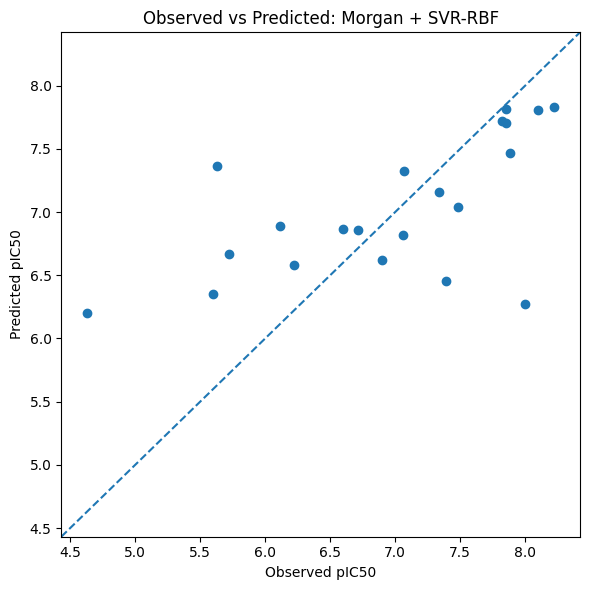

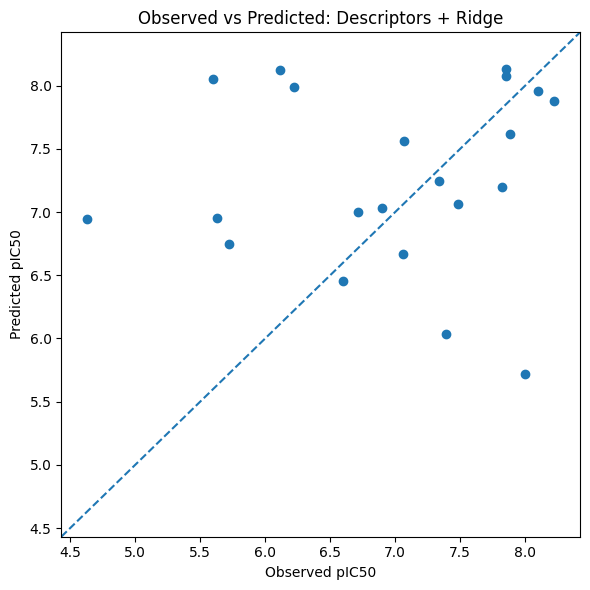

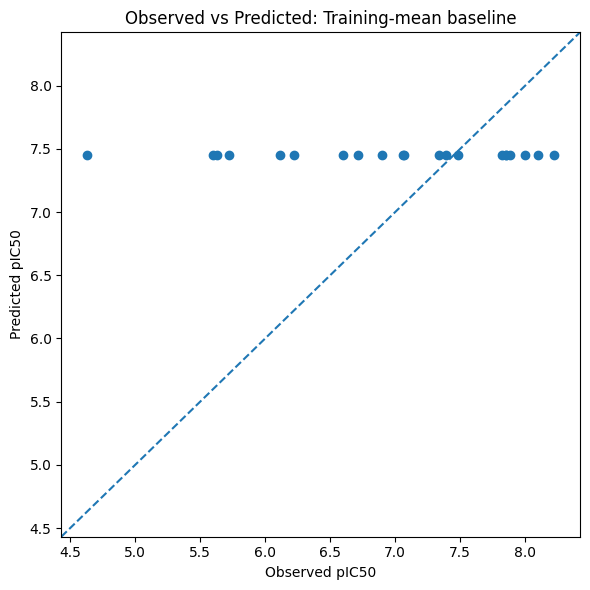

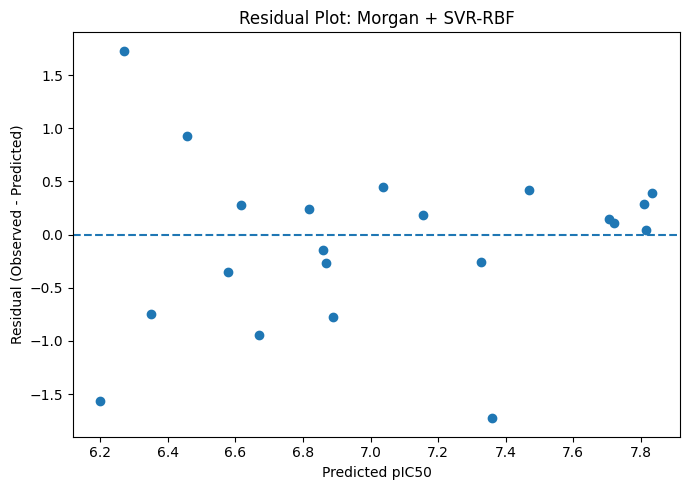

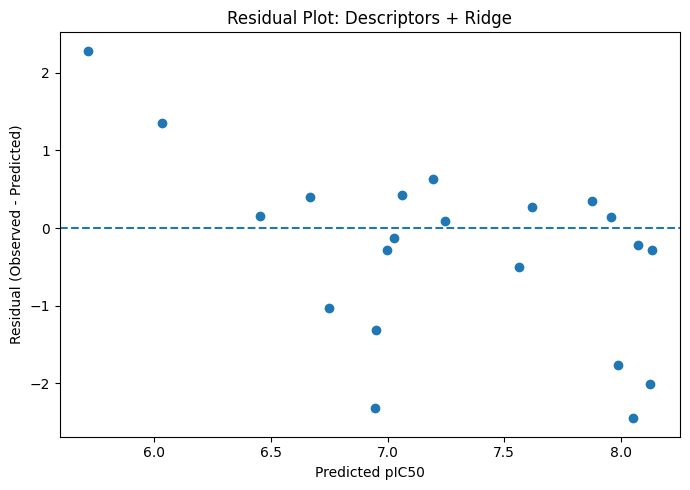

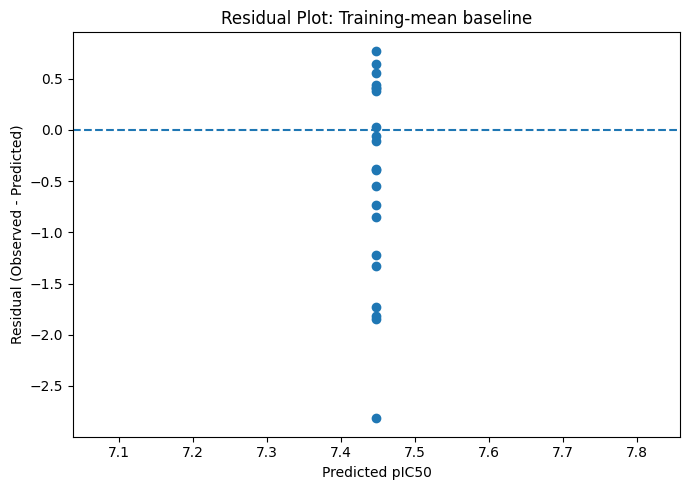


STEP 08 COMPLETED
Results saved to:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/STEP08_INDEPENDENT_TEST_EVALUATION

Files generated:
- 01_STEP08_test_set_metrics.csv
- 02_STEP08_observed_predicted_residuals.csv
- 03_observed_vs_predicted_descriptors_plus_ridge.png
- 03_observed_vs_predicted_morgan_plus_svr_rbf.png
- 03_observed_vs_predicted_training_mean_baseline.png
- 04_residual_plot_descriptors_plus_ridge.png
- 04_residual_plot_morgan_plus_svr_rbf.png
- 04_residual_plot_training_mean_baseline.png
- 05_STEP08_manifest.json


In [ ]:

# ================================================================
# STEP 08 — INDEPENDENT TEST-SET EVALUATION
# ALDH1A1 QSAR
#
# Models:
# 1. Morgan fingerprints + SVR-RBF
# 2. RDKit descriptors + Ridge
#
# Test set: untouched 21 compounds
# Training set: 85 compounds
# No retraining or test-set tuning.
# ================================================================

from pathlib import Path
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")

# ------------------------------------------------
# 2. DEFINE PROJECT PATHS
# ------------------------------------------------

BASE = Path("/content/drive/MyDrive/qsar/aldh1a1")

STEP06 = (
    BASE /
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

STEP07 = STEP06 / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"

OUTPUT = STEP07 / "STEP08_INDEPENDENT_TEST_EVALUATION"
OUTPUT.mkdir(parents=True, exist_ok=True)

if not STEP06.exists():
    raise FileNotFoundError(f"Step 6 folder not found: {STEP06}")

if not STEP07.exists():
    raise FileNotFoundError(f"Step 7 folder not found: {STEP07}")

# ------------------------------------------------
# 3. LOAD TRAINING AND TEST DATA
# ------------------------------------------------

train_file = STEP06 / "01_training_set_80_percent.csv"
test_file = STEP06 / "02_test_set_20_percent.csv"

train = pd.read_csv(train_file)
test = pd.read_csv(test_file)

TARGET = "pIC50"

if TARGET not in train.columns or TARGET not in test.columns:
    raise ValueError(
        "pIC50 column missing from training or test dataset. "
        f"Training columns: {list(train.columns)}; "
        f"Test columns: {list(test.columns)}"
    )

y_train = pd.to_numeric(train[TARGET], errors="raise").values
y_test = pd.to_numeric(test[TARGET], errors="raise").values

assert len(train) == 85, f"Expected 85 training compounds, found {len(train)}"
assert len(test) == 21, f"Expected 21 test compounds, found {len(test)}"

# ------------------------------------------------
# 4. LOAD FEATURE MATRICES
# ------------------------------------------------

feature_files = {
    "descriptor": {
        "train": STEP06 / "03_training_descriptors.csv",
        "test": STEP06 / "04_test_descriptors.csv",
        "expected_features": 169
    },
    "fingerprint": {
        "train": STEP06 / "05_training_fingerprints.csv",
        "test": STEP06 / "06_test_fingerprints.csv",
        "expected_features": 2048
    }
}

def load_feature_pair(kind):

    paths = feature_files[kind]

    tr = pd.read_csv(paths["train"])
    te = pd.read_csv(paths["test"])

    excluded = {
        "InChIKey", "inchikey", "InChI_Key",
        "pIC50", "PIC50", "IC50",
        "molecule_chembl_id", "compound_id"
    }

    train_features = [
        c for c in tr.columns
        if c not in excluded
    ]

    test_features = [
        c for c in te.columns
        if c not in excluded
    ]

    if train_features != test_features:
        raise ValueError(
            f"{kind}: training and test feature columns/order differ."
        )

    X_train = tr[train_features].apply(
        pd.to_numeric, errors="raise"
    )

    X_test = te[train_features].apply(
        pd.to_numeric, errors="raise"
    )

    if X_train.shape[1] != paths["expected_features"]:
        raise ValueError(
            f"{kind}: expected {paths['expected_features']} features, "
            f"found {X_train.shape[1]}"
        )

    if X_test.shape[0] != len(y_test):
        raise ValueError(
            f"{kind}: test feature count does not match test labels."
        )

    if X_train.isna().any().any() or X_test.isna().any().any():
        raise ValueError(f"{kind}: missing feature values detected.")

    return X_train, X_test, train_features


X_train_desc, X_test_desc, desc_columns = load_feature_pair("descriptor")
X_train_fp, X_test_fp, fp_columns = load_feature_pair("fingerprint")

print("DATA VALIDATION")
print("------------------------------")
print("Training compounds:", len(y_train))
print("Test compounds:", len(y_test))
print("Descriptor features:", X_train_desc.shape[1])
print("Fingerprint features:", X_train_fp.shape[1])

# ------------------------------------------------
# 5. FIND SAVED STEP 7 MODELS
# ------------------------------------------------

model_files = (
    list(STEP07.rglob("*.joblib")) +
    list(STEP07.rglob("*.pkl"))
)

if not model_files:
    raise FileNotFoundError(
        "No saved joblib/pkl model files found in Step 7. "
        "Check whether the model files were saved in another folder."
    )

print("\nSAVED MODEL FILES FOUND:")
for f in model_files:
    print("-", f.name)

# ------------------------------------------------
# 6. IDENTIFY MODEL TYPE AND FEATURE COUNT
# ------------------------------------------------

def unwrap_model(model):

    if hasattr(model, "best_estimator_"):
        model = model.best_estimator_

    if hasattr(model, "steps") and len(model.steps):
        estimator = model.steps[-1][1]
    else:
        estimator = model

    return model, estimator


def identify_model(path):

    try:
        model = joblib.load(path)
        full_model, estimator = unwrap_model(model)

        class_name = estimator.__class__.__name__.lower()

        feature_count = getattr(
            full_model, "n_features_in_", None
        )

        if feature_count is None:
            feature_count = getattr(
                estimator, "n_features_in_", None
            )

        if feature_count is None:
            return None

        if "svr" in class_name and feature_count == 2048:
            return {
                "name": "Morgan_SVR_RBF",
                "model": full_model,
                "path": path,
                "feature_count": feature_count
            }

        if "ridge" in class_name and feature_count == 169:
            return {
                "name": "Descriptor_Ridge",
                "model": full_model,
                "path": path,
                "feature_count": feature_count
            }

    except Exception as e:
        print(f"Could not inspect {path.name}: {e}")

    return None


identified = []

for path in model_files:
    result = identify_model(path)

    if result is not None:
        identified.append(result)

def select_unique(name):

    matches = [
        m for m in identified
        if m["name"] == name
    ]

    if len(matches) == 0:
        raise FileNotFoundError(
            f"No matching saved model identified for {name}. "
            "Review the saved model filenames and estimator types."
        )

    if len(matches) > 1:
        raise RuntimeError(
            f"Multiple possible models found for {name}: "
            f"{[str(m['path']) for m in matches]}. "
            "Selection is ambiguous; no model was chosen."
        )

    return matches[0]


model_fp = select_unique("Morgan_SVR_RBF")
model_desc = select_unique("Descriptor_Ridge")

print("\nSELECTED MODELS")
print("------------------------------")
print("Morgan SVR:", model_fp["path"])
print("Descriptor Ridge:", model_desc["path"])

# ------------------------------------------------
# 7. PREDICT ON UNTOUCHED TEST SET
# ------------------------------------------------

predictions = {
    "Morgan + SVR-RBF": model_fp["model"].predict(X_test_fp),
    "Descriptors + Ridge": model_desc["model"].predict(X_test_desc)
}

# ------------------------------------------------
# 8. TRAINING-MEAN BASELINE
# ------------------------------------------------

baseline_predictions = np.repeat(
    np.mean(y_train),
    len(y_test)
)

predictions["Training-mean baseline"] = baseline_predictions

# ------------------------------------------------
# 9. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------

results = []
prediction_table = pd.DataFrame({
    "Observed_pIC50": y_test
})

for name, pred in predictions.items():

    pred = np.asarray(pred).ravel()

    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    if np.std(pred) > 0 and np.std(y_test) > 0:
        pearson = pearsonr(y_test, pred).statistic
        spearman = spearmanr(y_test, pred).statistic
    else:
        pearson = np.nan
        spearman = np.nan

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "Pearson_r": pearson,
        "Spearman_rho": spearman
    })

    prediction_table[
        name.replace(" ", "_").replace("+", "plus")
    ] = pred

    prediction_table[
        name.replace(" ", "_").replace("+", "plus") + "_Residual"
    ] = y_test - pred


results_df = pd.DataFrame(results)

print("\nSTEP 08 TEST-SET PERFORMANCE")
print("=" * 75)
print(results_df.round(4).to_string(index=False))

# ------------------------------------------------
# 10. SAVE RESULTS
# ------------------------------------------------

results_df.to_csv(
    OUTPUT / "01_STEP08_test_set_metrics.csv",
    index=False
)

prediction_table.to_csv(
    OUTPUT / "02_STEP08_observed_predicted_residuals.csv",
    index=False
)

# ------------------------------------------------
# 11. OBSERVED VS PREDICTED PLOT
# ------------------------------------------------

for name in predictions:

    pred = np.asarray(predictions[name]).ravel()

    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred)

    low = min(y_test.min(), pred.min()) - 0.2
    high = max(y_test.max(), pred.max()) + 0.2

    plt.plot([low, high], [low, high], linestyle="--")

    plt.xlabel("Observed pIC50")
    plt.ylabel("Predicted pIC50")
    plt.title(f"Observed vs Predicted: {name}")
    plt.xlim(low, high)
    plt.ylim(low, high)
    plt.tight_layout()

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("-", "_")
    )

    plt.savefig(
        OUTPUT / f"03_observed_vs_predicted_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------
# 12. RESIDUAL PLOTS
# ------------------------------------------------

for name in predictions:

    pred = np.asarray(predictions[name]).ravel()
    residuals = y_test - pred

    plt.figure(figsize=(7, 5))
    plt.scatter(pred, residuals)
    plt.axhline(0, linestyle="--")

    plt.xlabel("Predicted pIC50")
    plt.ylabel("Residual (Observed - Predicted)")
    plt.title(f"Residual Plot: {name}")
    plt.tight_layout()

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("+", "plus")
        .replace("-", "_")
    )

    plt.savefig(
        OUTPUT / f"04_residual_plot_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------
# 13. SAVE STEP 08 MANIFEST
# ------------------------------------------------

manifest = {
    "project": "Human ALDH1A1 QSAR",
    "step": "08 Independent test-set evaluation",
    "training_compounds": int(len(y_train)),
    "test_compounds": int(len(y_test)),
    "descriptor_features": int(X_train_desc.shape[1]),
    "fingerprint_features": int(X_train_fp.shape[1]),
    "models_evaluated": [
        "Morgan fingerprints + SVR-RBF",
        "RDKit descriptors + Ridge",
        "Training-mean baseline"
    ],
    "test_set_used_for_tuning": False,
    "models_retrained": False,
    "results": results_df.replace(
        {np.nan: None}
    ).to_dict(orient="records")
}

with open(
    OUTPUT / "05_STEP08_manifest.json",
    "w"
) as f:
    json.dump(manifest, f, indent=4)

print("\nSTEP 08 COMPLETED")
print("=" * 75)
print("Results saved to:")
print(OUTPUT)
print("\nFiles generated:")
for f in sorted(OUTPUT.iterdir()):
    print("-", f.name)


In [ ]:

from pathlib import Path
import zipfile
from google.colab import files

STEP08 = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049/"
    "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/"
    "STEP08_INDEPENDENT_TEST_EVALUATION"
)

png_files = sorted(STEP08.glob("*.png"))

if not png_files:
    raise FileNotFoundError("No PNG figures found in Step 8.")

zip_path = STEP08 / "STEP08_ALL_FIGURES.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for img in png_files:
        z.write(img, arcname=img.name)

print("Figures included:", len(png_files))
print("ZIP saved:", zip_path)

files.download(str(zip_path))

Figures included: 6
ZIP saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/STEP08_INDEPENDENT_TEST_EVALUATION/STEP08_ALL_FIGURES.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training fingerprints: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/05_training_fingerprints.csv
Test fingerprints: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/06_test_fingerprints.csv

Training compounds: 85
Test compounds: 21
Fingerprint bits: 2048


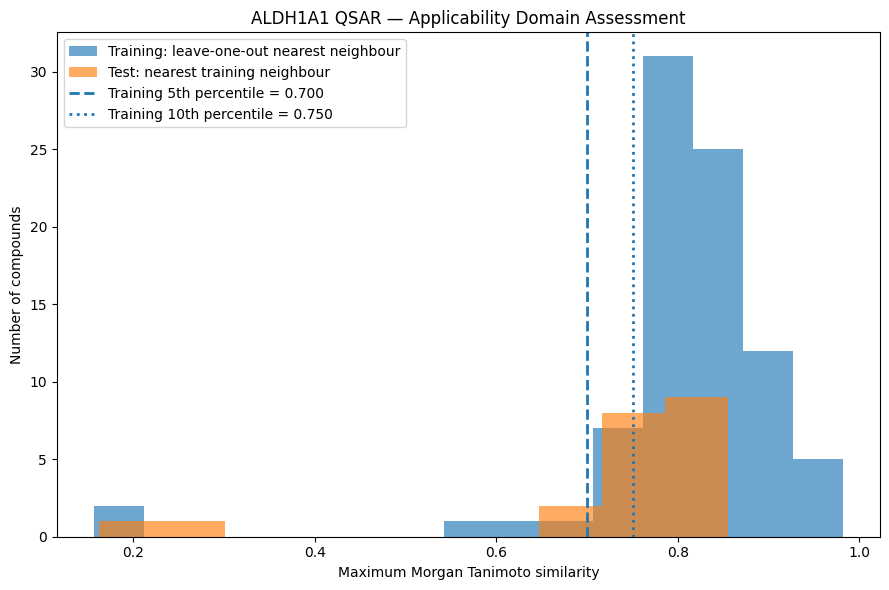


========== STEP 9 SUMMARY ==========


,Metric,Value
0,Training compounds,85.000000
1,Test compounds,21.000000
2,Training LOO nearest-neighbour similarity: 5th...,0.699681
3,Training LOO nearest-neighbour similarity: 10t...,0.750000
4,Test nearest-neighbour similarity: mean,0.729891
5,Test nearest-neighbour similarity: minimum,0.162500
6,Test compounds below 5th percentile threshold,4.000000
7,Test compounds below 10th percentile threshold,5.000000



========== TEST COMPOUND AD RESULTS ==========


,InChIKey,Observed_pIC50,Nearest_Training_InChIKey,Nearest_Training_Tanimoto,AD_Status_5th_Percentile,AD_Status_10th_Percentile
0,ROVLJQANKWYHAE-UHFFFAOYSA-N,7.853872,WNUQVFZYOLIJDY-UHFFFAOYSA-N,0.771429,Within reference range,Within reference range
1,UKFBZCGDIKGSML-UHFFFAOYSA-N,8.221849,IFKUKAGVXCPLLG-UHFFFAOYSA-N,0.772727,Within reference range,Within reference range
2,GWVMSTFAQOHEOM-UHFFFAOYSA-N,7.853872,ROWBIGRSLCNQEI-UHFFFAOYSA-N,0.754098,Within reference range,Within reference range
3,RTDHTQYSRGBIEK-UHFFFAOYSA-N,7.886057,ACSXYVBEJQOTGI-UHFFFAOYSA-N,0.765625,Within reference range,Within reference range
4,CAGSBCWJZUNSRZ-UHFFFAOYSA-N,6.115205,IOXNMWMNNXUJHI-UHFFFAOYSA-N,0.785714,Within reference range,Within reference range
5,FOUWVAHUAQGPHA-UHFFFAOYSA-N,8.096910,PPBCUUQKHUQVHT-UHFFFAOYSA-N,0.782609,Within reference range,Within reference range
6,WWNYGWVXNBKAJJ-UHFFFAOYSA-N,7.823909,IOXNMWMNNXUJHI-UHFFFAOYSA-N,0.833333,Within reference range,Within reference range
7,GWTFJTMAIBMVQU-UHFFFAOYSA-N,4.631155,QYPYPGAQNSLSMG-UHFFFAOYSA-N,0.774194,Within reference range,Within reference range
8,HNYMSNLTGLZUSF-UHFFFAOYSA-N,5.600326,ZASQGHBAOUULCL-UHFFFAOYSA-N,0.687500,Below reference range,Below reference range
9,INXXRSNYXBXNJI-UHFFFAOYSA-N,6.224026,ZASQGHBAOUULCL-UHFFFAOYSA-N,0.721311,Within reference range,Below reference range



Saved output directory:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP09_APPLICABILITY_DOMAIN



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


STEP 9 COMPLETE


In [ ]:
# ============================================================
# STEP 9 — MORGAN-FINGERPRINT APPLICABILITY DOMAIN
# ALDH1A1 QSAR | Training-set calibrated Tanimoto similarity
# ============================================================

from google.colab import drive, files
drive.mount('/content/drive')

import os, glob, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import DataStructs
from rdkit import Chem

# ------------------------------------------------------------
# 1. Locate project files
# ------------------------------------------------------------

BASE = (
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL"
)

split_dir = os.path.join(
    BASE, "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

train_candidates = glob.glob(
    os.path.join(split_dir, "**", "05_training_fingerprints.csv"),
    recursive=True
)
test_candidates = glob.glob(
    os.path.join(split_dir, "**", "06_test_fingerprints.csv"),
    recursive=True
)

if not train_candidates or not test_candidates:
    raise FileNotFoundError(
        "Could not locate the Step 6 training/test fingerprint CSV files."
    )

train_path = train_candidates[0]
test_path = test_candidates[0]

print("Training fingerprints:", train_path)
print("Test fingerprints:", test_path)

# ------------------------------------------------------------
# 2. Load and validate data
# ------------------------------------------------------------

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

id_col = "InChIKey"
target_col = "pIC50"

for col in [id_col, target_col]:
    if col not in train_df.columns or col not in test_df.columns:
        raise ValueError(f"Required column missing: {col}")

fp_cols = [
    c for c in train_df.columns
    if c not in [id_col, target_col]
]

if len(fp_cols) != 2048:
    raise ValueError(
        f"Expected 2048 Morgan fingerprint bits; found {len(fp_cols)}."
    )

if fp_cols != [
    c for c in test_df.columns if c not in [id_col, target_col]
]:
    raise ValueError("Training and test fingerprint columns do not match.")

if train_df[id_col].duplicated().any():
    raise ValueError("Duplicate InChIKeys found in training set.")

if test_df[id_col].duplicated().any():
    raise ValueError("Duplicate InChIKeys found in test set.")

X_train = train_df[fp_cols].to_numpy(dtype=np.uint8)
X_test = test_df[fp_cols].to_numpy(dtype=np.uint8)

if np.isnan(X_train).any() or np.isnan(X_test).any():
    raise ValueError("Missing fingerprint values detected.")

if not np.isin(X_train, [0, 1]).all():
    raise ValueError("Training fingerprints contain values other than 0/1.")

if not np.isin(X_test, [0, 1]).all():
    raise ValueError("Test fingerprints contain values other than 0/1.")

print("\nTraining compounds:", len(train_df))
print("Test compounds:", len(test_df))
print("Fingerprint bits:", len(fp_cols))

# ------------------------------------------------------------
# 3. Convert fingerprint rows to RDKit bit vectors
# ------------------------------------------------------------

def to_bitvectors(matrix):
    bitvectors = []
    for row in matrix:
        bv = DataStructs.ExplicitBitVect(len(row))
        for i, value in enumerate(row):
            if int(value) == 1:
                bv.SetBit(i)
        bitvectors.append(bv)
    return bitvectors

train_fps = to_bitvectors(X_train)
test_fps = to_bitvectors(X_test)

# ------------------------------------------------------------
# 4. Training-set leave-one-out nearest-neighbour similarity
# ------------------------------------------------------------

train_loo_nn = []

for i, fp in enumerate(train_fps):
    other_fps = train_fps[:i] + train_fps[i+1:]
    similarities = DataStructs.BulkTanimotoSimilarity(
        fp, other_fps
    )
    train_loo_nn.append(max(similarities))

train_loo_nn = np.array(train_loo_nn)

# Empirical reference thresholds from training compounds
threshold_5 = float(np.percentile(train_loo_nn, 5))
threshold_10 = float(np.percentile(train_loo_nn, 10))

# ------------------------------------------------------------
# 5. Test compounds: nearest training neighbour
# ------------------------------------------------------------

test_nn_similarity = []
test_nn_index = []

for fp in test_fps:
    similarities = DataStructs.BulkTanimotoSimilarity(
        fp, train_fps
    )
    best_index = int(np.argmax(similarities))
    test_nn_similarity.append(float(similarities[best_index]))
    test_nn_index.append(best_index)

test_nn_similarity = np.array(test_nn_similarity)

# ------------------------------------------------------------
# 6. Build compound-level output
# ------------------------------------------------------------

test_results = pd.DataFrame({
    "InChIKey": test_df[id_col].values,
    "Observed_pIC50": test_df[target_col].values,
    "Nearest_Training_InChIKey": [
        train_df.iloc[i][id_col] for i in test_nn_index
    ],
    "Nearest_Training_Tanimoto": test_nn_similarity,
    "AD_Status_5th_Percentile": [
        "Within reference range" if s >= threshold_5
        else "Below reference range"
        for s in test_nn_similarity
    ],
    "AD_Status_10th_Percentile": [
        "Within reference range" if s >= threshold_10
        else "Below reference range"
        for s in test_nn_similarity
    ]
})

train_results = pd.DataFrame({
    "InChIKey": train_df[id_col].values,
    "Training_LOO_Nearest_Tanimoto": train_loo_nn
})

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

summary = pd.DataFrame([
    {
        "Metric": "Training compounds",
        "Value": len(train_df)
    },
    {
        "Metric": "Test compounds",
        "Value": len(test_df)
    },
    {
        "Metric": "Training LOO nearest-neighbour similarity: 5th percentile",
        "Value": threshold_5
    },
    {
        "Metric": "Training LOO nearest-neighbour similarity: 10th percentile",
        "Value": threshold_10
    },
    {
        "Metric": "Test nearest-neighbour similarity: mean",
        "Value": float(np.mean(test_nn_similarity))
    },
    {
        "Metric": "Test nearest-neighbour similarity: minimum",
        "Value": float(np.min(test_nn_similarity))
    },
    {
        "Metric": "Test compounds below 5th percentile threshold",
        "Value": int(np.sum(test_nn_similarity < threshold_5))
    },
    {
        "Metric": "Test compounds below 10th percentile threshold",
        "Value": int(np.sum(test_nn_similarity < threshold_10))
    }
])

# ------------------------------------------------------------
# 8. Output directory
# ------------------------------------------------------------

out_dir = os.path.join(
    split_dir,
    "STEP09_APPLICABILITY_DOMAIN"
)
os.makedirs(out_dir, exist_ok=True)

test_results.to_csv(
    os.path.join(out_dir, "01_test_compound_AD_assessment.csv"),
    index=False
)

train_results.to_csv(
    os.path.join(out_dir, "02_training_LOO_similarity_reference.csv"),
    index=False
)

summary.to_csv(
    os.path.join(out_dir, "03_AD_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# 9. Plot similarity distributions
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.hist(
    train_loo_nn,
    bins=15,
    alpha=0.65,
    label="Training: leave-one-out nearest neighbour"
)

plt.hist(
    test_nn_similarity,
    bins=10,
    alpha=0.65,
    label="Test: nearest training neighbour"
)

plt.axvline(
    threshold_5,
    linestyle="--",
    linewidth=2,
    label=f"Training 5th percentile = {threshold_5:.3f}"
)

plt.axvline(
    threshold_10,
    linestyle=":",
    linewidth=2,
    label=f"Training 10th percentile = {threshold_10:.3f}"
)

plt.xlabel("Maximum Morgan Tanimoto similarity")
plt.ylabel("Number of compounds")
plt.title("ALDH1A1 QSAR — Applicability Domain Assessment")
plt.legend()
plt.tight_layout()

plot_path = os.path.join(
    out_dir,
    "04_AD_similarity_distribution.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 10. Manifest
# ------------------------------------------------------------

manifest = {
    "step": "Step 9 — Applicability Domain",
    "fingerprint": "Morgan radius 2, 2048 bits, chirality-aware",
    "similarity_metric": "Tanimoto",
    "training_compounds": int(len(train_df)),
    "test_compounds": int(len(test_df)),
    "threshold_method": (
        "5th and 10th percentiles of training-set "
        "leave-one-out nearest-neighbour similarities"
    ),
    "threshold_5th_percentile": threshold_5,
    "threshold_10th_percentile": threshold_10,
    "note": (
        "These are empirical similarity-reference thresholds, "
        "not universal or experimentally validated AD boundaries."
    )
}

with open(
    os.path.join(out_dir, "05_STEP09_manifest.json"),
    "w"
) as f:
    json.dump(manifest, f, indent=4)

# ------------------------------------------------------------
# 11. Display results
# ------------------------------------------------------------

print("\n========== STEP 9 SUMMARY ==========")
display(summary)

print("\n========== TEST COMPOUND AD RESULTS ==========")
display(test_results)

print("\nSaved output directory:")
print(out_dir)

# ------------------------------------------------------------
# 12. ZIP and download all Step 9 outputs
# ------------------------------------------------------------

zip_path = out_dir + "_ALL_OUTPUTS.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(out_dir):
        full_path = os.path.join(out_dir, filename)
        if os.path.isfile(full_path):
            z.write(full_path, arcname=filename)

print("\nDownloading Step 9 outputs...")
files.download(zip_path)

print("\nSTEP 9 COMPLETE")

In [ ]:
# Install RDKit in the current Google Colab runtime
!pip -q install rdkit

# Verify installation
from rdkit import DataStructs, Chem
from rdkit import rdBase

print("RDKit installed successfully.")
print("RDKit version:", rdBase.rdkitVersion)

RDKit installed successfully.
RDKit version: 2026.09.2


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/05_training_fingerprints.csv
Saved model: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/MORGAN_FINGERPRINTS_SVR_RBF.joblib

STRUCTURE VALIDATION
Compound: Muricatetrocin B
PubChem CID: 165365496
Standardised SMILES: CCCCCC[C@@H](O)[C@H](O)CC[C@H](O)C1CCC(CCCC[C@@H](O)CC2=C[C@H](C)OC2=O)O1
Standardised InChIKey: CTUPPWQYDNGORK-CHXZEJSUSA-N
Molecular formula: C26H46O7
Exact molecular weight: 470.32435381199986
Undefined stereocentres in source: 2


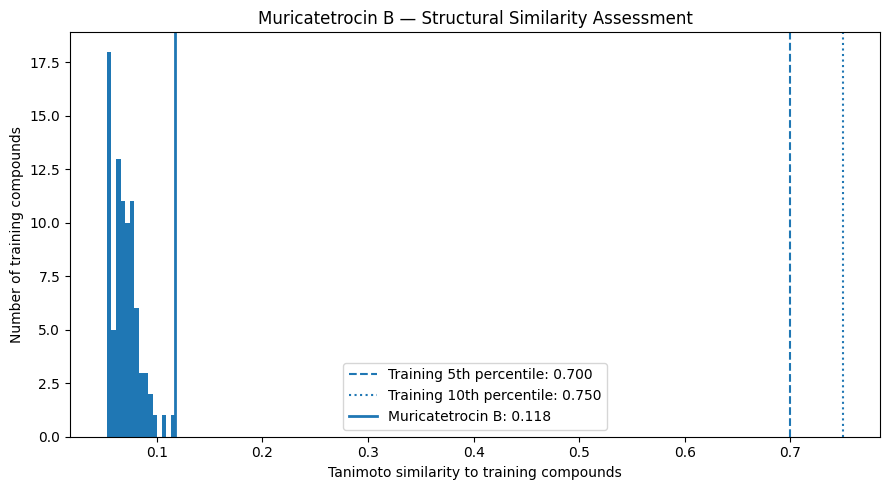


========== MURICATETROCIN B PREDICTION ==========


,0
Compound,Muricatetrocin B
PubChem_CID,165365496
PubChem_SMILES,CCCCCC[C@H]([C@@H](CC[C@@H](C1CCC(O1)CCCC[C@H]...
Standardised_SMILES,CCCCCC[C@@H](O)[C@H](O)CC[C@H](O)C1CCC(CCCC[C@...
Standardised_InChIKey,CTUPPWQYDNGORK-CHXZEJSUSA-N
Molecular_Formula,C26H46O7
Exact_Molecular_Weight,470.324354
Undefined_Source_Stereocentres,2
Model,"Morgan radius 2, 2048 bits, chirality-aware + ..."
Predicted_pIC50,6.406316



Saved to:
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP10_MURICATETROCIN_B_PREDICTION


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


STEP 10 COMPLETE


In [ ]:
# ============================================================
# STEP 10 — MURICATETROCIN B: PROVISIONAL QSAR PREDICTION
# ============================================================

from google.colab import drive, files
drive.mount('/content/drive')

import os, glob, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from rdkit import Chem, DataStructs
from rdkit.Chem import rdMolDescriptors, AllChem
from rdkit.Chem.MolStandardize import rdMolStandardize

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

BASE = (
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL"
)

split_dir = os.path.join(
    BASE, "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

train_path = os.path.join(
    split_dir, "05_training_fingerprints.csv"
)

model_candidates = glob.glob(
    os.path.join(
        split_dir,
        "**",
        "MORGAN_FINGERPRINTS_SVR_RBF.joblib"
    ),
    recursive=True
)

if not os.path.exists(train_path):
    raise FileNotFoundError(train_path)

if not model_candidates:
    raise FileNotFoundError(
        "Saved Morgan-SVR model not found."
    )

model_path = model_candidates[0]

print("Training data:", train_path)
print("Saved model:", model_path)

# ------------------------------------------------------------
# 2. PubChem structure
# ------------------------------------------------------------

compound_name = "Muricatetrocin B"
pubchem_cid = "165365496"

pubchem_smiles = (
    "CCCCCC[C@H]([C@@H](CC[C@@H]"
    "(C1CCC(O1)CCCC[C@H](CC2=C[C@@H]"
    "(OC2=O)C)O)O)O)O"
)

mol = Chem.MolFromSmiles(pubchem_smiles)

if mol is None:
    raise ValueError("RDKit could not parse the PubChem SMILES.")

# Count stereocentres before standardisation
stereo_info = Chem.FindMolChiralCenters(
    mol,
    includeUnassigned=True,
    includeCIP=True
)

undefined_stereo = [
    item for item in stereo_info if item[1] == "?"
]

# ------------------------------------------------------------
# 3. Apply training standardisation workflow
# ------------------------------------------------------------

mol = rdMolStandardize.Cleanup(mol)
mol = rdMolStandardize.FragmentParent(mol)
mol = rdMolStandardize.Uncharger().uncharge(mol)

Chem.AssignStereochemistry(
    mol,
    cleanIt=True,
    force=True
)

standard_smiles = Chem.MolToSmiles(
    mol,
    canonical=True,
    isomericSmiles=True
)

standard_inchikey = Chem.MolToInchiKey(mol)
molecular_formula = rdMolDescriptors.CalcMolFormula(mol)
molecular_weight = rdMolDescriptors.CalcExactMolWt(mol)

print("\nSTRUCTURE VALIDATION")
print("Compound:", compound_name)
print("PubChem CID:", pubchem_cid)
print("Standardised SMILES:", standard_smiles)
print("Standardised InChIKey:", standard_inchikey)
print("Molecular formula:", molecular_formula)
print("Exact molecular weight:", molecular_weight)
print("Undefined stereocentres in source:", len(undefined_stereo))

if molecular_formula != "C26H46O7":
    raise ValueError(
        "Molecular formula does not match the PubChem record."
    )

# ------------------------------------------------------------
# 4. Generate Morgan fingerprint
# ------------------------------------------------------------

fp = AllChem.GetMorganFingerprintAsBitVect(
    mol,
    radius=2,
    nBits=2048,
    useChirality=True
)

query_array = np.zeros((2048,), dtype=np.uint8)
DataStructs.ConvertToNumpyArray(fp, query_array)

X_query = query_array.reshape(1, -1)

# ------------------------------------------------------------
# 5. Load training fingerprints
# ------------------------------------------------------------

train_df = pd.read_csv(train_path)

id_col = "InChIKey"
target_col = "pIC50"

fp_cols = [
    c for c in train_df.columns
    if c not in [id_col, target_col]
]

if len(fp_cols) != 2048:
    raise ValueError(
        f"Expected 2048 fingerprint columns, found {len(fp_cols)}."
    )

X_train = train_df[fp_cols].to_numpy(dtype=np.uint8)

train_fps = []

for row in X_train:
    bv = DataStructs.ExplicitBitVect(2048)
    for i, bit in enumerate(row):
        if int(bit) == 1:
            bv.SetBit(i)
    train_fps.append(bv)

# ------------------------------------------------------------
# 6. Applicability-domain assessment
# ------------------------------------------------------------

similarities = DataStructs.BulkTanimotoSimilarity(
    fp, train_fps
)

nearest_index = int(np.argmax(similarities))
nearest_similarity = float(similarities[nearest_index])

nearest_training_key = train_df.iloc[nearest_index][id_col]
nearest_training_pic50 = float(
    train_df.iloc[nearest_index][target_col]
)

# Training reference distribution
training_loo = []

for i, train_fp in enumerate(train_fps):
    others = train_fps[:i] + train_fps[i+1:]
    training_loo.append(
        max(DataStructs.BulkTanimotoSimilarity(
            train_fp, others
        ))
    )

threshold_5 = float(np.percentile(training_loo, 5))
threshold_10 = float(np.percentile(training_loo, 10))

# ------------------------------------------------------------
# 7. Load saved Morgan-SVR model
# ------------------------------------------------------------

model = joblib.load(model_path)

if hasattr(model, "n_features_in_"):
    if model.n_features_in_ != 2048:
        raise ValueError(
            f"Model expects {model.n_features_in_} features, not 2048."
        )

# ------------------------------------------------------------
# 8. Predict pIC50 and convert to IC50
# ------------------------------------------------------------

predicted_pic50 = float(model.predict(X_query)[0])

# pIC50 = 9 - log10(IC50 in nM)
predicted_ic50_nm = 10 ** (9 - predicted_pic50)
predicted_ic50_um = 10 ** (3 - predicted_pic50)

# ------------------------------------------------------------
# 9. Applicability interpretation
# ------------------------------------------------------------

if nearest_similarity >= threshold_10:
    ad_status = "Within 10th-percentile training reference"
elif nearest_similarity >= threshold_5:
    ad_status = "Between 5th and 10th-percentile references"
else:
    ad_status = "Below 5th-percentile training reference"

# ------------------------------------------------------------
# 10. Save results
# ------------------------------------------------------------

out_dir = os.path.join(
    split_dir,
    "STEP10_MURICATETROCIN_B_PREDICTION"
)

os.makedirs(out_dir, exist_ok=True)

results = pd.DataFrame([{
    "Compound": compound_name,
    "PubChem_CID": pubchem_cid,
    "PubChem_SMILES": pubchem_smiles,
    "Standardised_SMILES": standard_smiles,
    "Standardised_InChIKey": standard_inchikey,
    "Molecular_Formula": molecular_formula,
    "Exact_Molecular_Weight": molecular_weight,
    "Undefined_Source_Stereocentres": len(undefined_stereo),
    "Model": "Morgan radius 2, 2048 bits, chirality-aware + SVR-RBF",
    "Predicted_pIC50": predicted_pic50,
    "Predicted_IC50_nM": predicted_ic50_nm,
    "Predicted_IC50_uM": predicted_ic50_um,
    "Nearest_Training_InChIKey": nearest_training_key,
    "Nearest_Training_pIC50": nearest_training_pic50,
    "Nearest_Training_Tanimoto": nearest_similarity,
    "Training_5th_Percentile": threshold_5,
    "Training_10th_Percentile": threshold_10,
    "Applicability_Domain_Status": ad_status,
    "Prediction_Type": "Computational estimate, not experimental measurement"
}])

csv_path = os.path.join(
    out_dir, "01_Muricatetrocin_B_QSAR_prediction.csv"
)

results.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# 11. Save nearest-neighbour similarity plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    similarities,
    bins=15
)

plt.axvline(
    threshold_5,
    linestyle="--",
    label=f"Training 5th percentile: {threshold_5:.3f}"
)

plt.axvline(
    threshold_10,
    linestyle=":",
    label=f"Training 10th percentile: {threshold_10:.3f}"
)

plt.axvline(
    nearest_similarity,
    linewidth=2,
    label=f"Muricatetrocin B: {nearest_similarity:.3f}"
)

plt.xlabel("Tanimoto similarity to training compounds")
plt.ylabel("Number of training compounds")
plt.title("Muricatetrocin B — Structural Similarity Assessment")
plt.legend()
plt.tight_layout()

plot_path = os.path.join(
    out_dir, "02_Muricatetrocin_B_AD_plot.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 12. Manifest
# ------------------------------------------------------------

manifest = {
    "compound": compound_name,
    "PubChem_CID": pubchem_cid,
    "source": "PubChem",
    "model_file": model_path,
    "fingerprint": "Morgan radius 2, 2048 bits, chirality-aware",
    "prediction": "Provisional",
    "undefined_source_stereocentres": len(undefined_stereo),
    "AD_status": ad_status,
    "warning": (
        "PubChem reports two undefined stereocentres. "
        "The docking ligand structure must be checked before "
        "treating this prediction as definitive. Model validation "
        "was mixed, with negative nested scaffold-CV mean R2."
    )
}

with open(
    os.path.join(out_dir, "03_STEP10_manifest.json"),
    "w"
) as f:
    json.dump(manifest, f, indent=4)

# ------------------------------------------------------------
# 13. Display
# ------------------------------------------------------------

print("\n========== MURICATETROCIN B PREDICTION ==========")
display(results.T)

print("\nSaved to:")
print(out_dir)

# ------------------------------------------------------------
# 14. Download all outputs
# ------------------------------------------------------------

zip_path = out_dir + "_ALL_OUTPUTS.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(out_dir):
        path = os.path.join(out_dir, filename)
        if os.path.isfile(path):
            z.write(path, arcname=filename)

files.download(zip_path)

print("\nSTEP 10 COMPLETE")


In [ ]:
# STEP 11.1 — LOCATE PRIMARY DATASET AND SI FILES

import os
from google.colab import drive

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

BASE = "/content/drive/MyDrive"

matches = []
for root, dirs, files in os.walk(BASE):
    dirs[:] = [d for d in dirs if d not in {" .Trash", ".ipynb_checkpoints"}]
    for f in files:
        name = f.lower()
        if (
            "primary_aldh1a1" in name
            or "jm8b00270_si_001" in name
            or ("aldh1a1" in name and name.endswith(".csv"))
        ):
            matches.append(os.path.join(root, f))

print("FILES FOUND:", len(matches))
for path in matches:
    print(path)

Mounted at /content/drive
FILES FOUND: 9
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/33_ALDH1A1_specific_assay_evidence.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/35_ALDH1A1_assay_evidence_summary.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_11_COMPOUND_RECONCILIATION_20261117_110413/supporting_information/jm8b00270_si_001.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_11_COMPOUND_RECONCILIATION_20261117_111202/jm8b00270_si_001.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansi

In [ ]:
# STEP 11 — SI SOURCE-FILE AUDIT

import pandas as pd

PRIMARY_PATH = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv"

SI_PATH = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_11_COMPOUND_RECONCILIATION_20261117_111202/jm8b00270_si_001.csv"

P = pd.read_csv(PRIMARY_PATH)
S = pd.read_csv(SI_PATH, encoding="cp1252")

print("PRIMARY DATASET:", P.shape)
print("SI DATASET:", S.shape)

print("\nPRIMARY COLUMNS:")
print(P.columns.tolist())
display(P.head(5))

print("\nSI COLUMNS:")
print(S.columns.tolist())
display(S.head(10))

print("\nPRIMARY MISSING VALUES:")
display(P.isna().sum())

print("\nSI MISSING VALUES:")
display(S.isna().sum())

PRIMARY DATASET: (106, 18)
SI DATASET: (110, 7)

PRIMARY COLUMNS:
['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role']


,InChIKey,SMILES,molecule_chembl_id,activity_id,assay_chembl_id,document_chembl_id,target_chembl_id,target_organism,standard_type,standard_relation,IC50_nM,IC50_unit,pIC50,Activity_source,Evidence_status,Endpoint_class,Target,Dataset_role
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3c(F)cc(F)cc3c2-c2cc...,CHEMBL4213604,18504734,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,9.0,nM,8.045757,ChEMBL,EXACT_IC50_EXPLICIT_NM,BIOCHEMICAL,Homo sapiens ALDH1A1,PRIMARY_SINGLE_ASSAY_REGRESSION
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3cc(F)c(F)cc3c2-c2cc...,CHEMBL4212891,18504735,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,8.0,nM,8.096910,ChEMBL,EXACT_IC50_EXPLICIT_NM,BIOCHEMICAL,Homo sapiens ALDH1A1,PRIMARY_SINGLE_ASSAY_REGRESSION
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,COc1ccc2c(-c3ccc(C4(C#N)CC4)cc3)c(C(=O)N3CCN(S...,CHEMBL4207222,18504736,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,5.0,nM,8.301030,ChEMBL,EXACT_IC50_EXPLICIT_NM,BIOCHEMICAL,Homo sapiens ALDH1A1,PRIMARY_SINGLE_ASSAY_REGRESSION
3,RUQWMJKTMUWGIU-UHFFFAOYSA-N,COc1ccc2ncc(C(=O)N3CCN(S(C)(=O)=O)CC3)c(-c3ccc...,CHEMBL4209722,18504737,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,7.0,nM,8.154902,ChEMBL,EXACT_IC50_EXPLICIT_NM,BIOCHEMICAL,Homo sapiens ALDH1A1,PRIMARY_SINGLE_ASSAY_REGRESSION
4,QHKKUEBSRRDZMN-UHFFFAOYSA-N,N#CC1(c2ccc(-c3c(C(=O)N4CCN(C(=O)C5CC5)CC4)cnc...,CHEMBL4204849,18504738,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,17.0,nM,7.769551,ChEMBL,EXACT_IC50_EXPLICIT_NM,BIOCHEMICAL,Homo sapiens ALDH1A1,PRIMARY_SINGLE_ASSAY_REGRESSION



SI COLUMNS:
['Cpd.', 'Unnamed: 1', 'Unnamed: 2', 'hALDH1A1', 'MIA PaCa-2', 'OV-90', 'HT-29']


,Cpd.,Unnamed: 1,Unnamed: 2,hALDH1A1,MIA PaCa-2,OV-90,HT-29
0,NaN,smiles,NaN,IC50 (uM),IC50 (uM),IC50 (uM),IC50 (uM)
1,1.0,O=C1N(CC2=CC=CC=C2)C3=C(C=CC=C3)C1=O,NaN,0.010 ± 0.002,12.9 ± 4.52,21.5 ± 2.33,6.53 ±3.51
2,2.0,CCOC(=O)CSC/1=N/C2=C(SC3=C2C=CC=C3)C(=O)N1CCCN...,NaN,6.89 ± 3.17,> 57,> 57,> 57
3,3.0,CCC(C)C1\N=C2/N(C1=O)/C(=N\C3=CC=CC=C23)SC(CC)...,NaN,0.119 ± 0.045,1.13 ± 0.07,1.19 ± 0.27,0.65 ± 0.40
4,4.0,CC(C)CC[N]1C(=NC2=C1C(=O)N(C)C(=O)N2C)CN3CCN(C...,NaN,0.041 ± 0.005,6.79 ± 2.00,4.04 ± 2.19,3.65 ± 1.28
5,5.0,COC1=CC=C(C=C1)[S+]([O-])(=O)C2=C(N3CCC4(CC3)O...,NaN,0.017 ± 0.003,3.43 ± 0.23,2.14 ± 2.18,1.91 ± 1.00
6,25.0,COC1=CC2=C(N3CCC4(CC3)OCCO4)C(=CN=C2C=C1)CN5CC...,NaN,0.028 ± 0.002,12.4 ± 4.62,16.3 ± 6.44,8.42 ± 6.67
7,26.0,COC1=CC2=C(N3CCC(=O)CC3)C(=CN=C2C=C1)C(=O)N4CC...,NaN,26.41 ± 3.94,> 57,NAc,NAc
8,27.0,O=C(C1CC1)N2CCN(CC2)C(=O)C3=CN=C4C=CC=CC4=C3N5...,NaN,0.068 ± 0.008,9.76 ± 1.76,6.19 ± 2.32,6.59 ± 7.24
9,28.0,COC1=CC2=C(N3CCC4(CC3)OCCO4)C(=CN=C2C=C1)C(=O)...,NaN,0.019 ± 0.003,4.09 ± 0.99,3.07 ± 0.39,4.94 ± 2.32



PRIMARY MISSING VALUES:


,0
InChIKey,0
SMILES,0
molecule_chembl_id,0
activity_id,0
assay_chembl_id,0
document_chembl_id,0
target_chembl_id,0
target_organism,0
standard_type,0
standard_relation,0



SI MISSING VALUES:


,0
Cpd.,3
Unnamed: 1,2
Unnamed: 2,110
hALDH1A1,1
MIA PaCa-2,2
OV-90,2
HT-29,2


In [ ]:
# STEP 11.1 — INSTALL RDKit AND RECONCILE DATASETS

!pip -q install rdkit

import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem import inchi

OUT = os.path.dirname(PRIMARY_PATH)

def get_inchikey(smiles):
    if pd.isna(smiles):
        return None
    mol = Chem.MolFromSmiles(str(smiles).strip())
    return inchi.MolToInchiKey(mol) if mol else None

SI = S.copy()
SI["SI_SMILES"] = SI["Unnamed: 1"]
SI["SI_InChIKey"] = SI["SI_SMILES"].apply(get_inchikey)
SI["SI_Cpd"] = SI["Cpd."]
SI["SI_ALDH1A1_IC50"] = SI["hALDH1A1"]

PRI = P.copy()

MATCH = PRI.merge(
    SI[["SI_Cpd", "SI_SMILES", "SI_InChIKey", "SI_ALDH1A1_IC50"]],
    left_on="InChIKey",
    right_on="SI_InChIKey",
    how="left"
)

MATCH["SI_match_status"] = MATCH["SI_Cpd"].notna().map(
    {True: "MATCHED", False: "NOT_MATCHED"}
)

path = os.path.join(OUT, "STEP11_1_SI_PRIMARY_RECONCILIATION.csv")
MATCH.to_csv(path, index=False)

print("PRIMARY COMPOUNDS:", len(PRI))
print("SI ROWS:", len(SI))
print("SI VALID STRUCTURES:", SI["SI_InChIKey"].notna().sum())
print("MATCHED:", MATCH["SI_Cpd"].notna().sum())
print("UNMATCHED:", MATCH["SI_Cpd"].isna().sum())

print("\nMATCHED COMPOUNDS:")
display(MATCH.loc[MATCH["SI_Cpd"].notna(), [
    "molecule_chembl_id", "IC50_nM", "pIC50",
    "SI_Cpd", "SI_ALDH1A1_IC50"
]])

print("\nUNMATCHED SI COMPOUNDS:")
display(SI.loc[~SI["SI_InChIKey"].isin(PRI["InChIKey"]), [
    "SI_Cpd", "SI_SMILES", "SI_ALDH1A1_IC50"
]])

print("\nSAVED:", path)

PRIMARY COMPOUNDS: 106
SI ROWS: 110
SI VALID STRUCTURES: 107
MATCHED: 103
UNMATCHED: 3

MATCHED COMPOUNDS:


,molecule_chembl_id,IC50_nM,pIC50,SI_Cpd,SI_ALDH1A1_IC50
0,CHEMBL4213604,9.0,8.045757,126.0,0.009 ± 0.002
1,CHEMBL4212891,8.0,8.096910,125.0,0.008 ± 0.001
2,CHEMBL4207222,5.0,8.301030,124.0,0.005 ± 0.001
3,CHEMBL4209722,7.0,8.154902,123.0,0.007 ± 0.001
4,CHEMBL4204849,17.0,7.769551,122.0,0.017± 0.002
...,...,...,...,...,...
101,CHEMBL4215984,35.0,7.455932,31.0,0.035 ± 0.007
102,CHEMBL4203770,19.0,7.721246,32.0,0.019 ± 0.001
103,CHEMBL4214314,13.0,7.886057,33.0,0.013 ± 0.001
104,CHEMBL4217482,22.0,7.657577,34.0,0.022 ± 0.002



UNMATCHED SI COMPOUNDS:


,SI_Cpd,SI_SMILES,SI_ALDH1A1_IC50
0,NaN,smiles,IC50 (uM)
24,43.0,FC1=CC2=C(N3CC4CCC(C4)C3)C(=CN=C2C=C1)C(=O)N5C...,0.211 ± 0.053
32,51.0,CC(=O)N1CCN(CC1)C2=C3C=C(F)C=CC3=NC=C2C(=O)N4C...,> 57
51,70.0,CC1(CCN(CC1)C2=C(C=NC3=C2C=N[NH]3)C(=O)N4CCN(C...,0.251 ± 0.017
53,72.0,CC1(CCN(CC1)C2=C(C=NC3=C2C=C[NH]3)C(=O)N4CCN(C...,0.193 ± 0.022
108,NaN,NaN,NaN
109,NaN,NaN,Values with standard deviation (SD) represent ...



SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/STEP11_1_SI_PRIMARY_RECONCILIATION.csv


In [ ]:
# STEP 11.2 — SI VS CHEMBL ACTIVITY AGREEMENT AUDIT

import os, re
import numpy as np
import pandas as pd

A = MATCH.copy()

def parse_si(value):
    if pd.isna(value):
        return pd.Series([np.nan, "MISSING"])
    s = str(value).strip()
    if ">" in s:
        m = re.search(r">\s*([\d.]+)", s)
        return pd.Series([float(m.group(1))*1000 if m else np.nan, "CENSORED_GT"])
    m = re.search(r"([\d.]+)", s)
    return pd.Series([float(m.group(1))*1000 if m else np.nan, "EXACT"])

A[["SI_IC50_nM", "SI_relation"]] = A["SI_ALDH1A1_IC50"].apply(parse_si)

A["SI_pIC50"] = np.where(
    A["SI_relation"] == "EXACT",
    9 - np.log10(A["SI_IC50_nM"]),
    np.nan
)

A["Delta_pIC50"] = A["pIC50"] - A["SI_pIC50"]
A["Fold_difference"] = np.maximum(
    A["IC50_nM"] / A["SI_IC50_nM"],
    A["SI_IC50_nM"] / A["IC50_nM"]
)

A["Activity_comparison"] = np.select(
    [
        A["SI_relation"] == "CENSORED_GT",
        A["SI_relation"] == "MISSING",
        A["Delta_pIC50"].abs() <= 0.1
    ],
    ["CENSORED", "MISSING", "CLOSE_AGREEMENT"],
    default="NUMERICAL_DIFFERENCE"
)

OUT = os.path.dirname(PRIMARY_PATH)
FILE = os.path.join(OUT, "STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv")
A.to_csv(FILE, index=False)

print("MATCHED COMPOUNDS:", A["SI_Cpd"].notna().sum())
print("\nCOMPARISON CATEGORIES:")
print(A["Activity_comparison"].value_counts(dropna=False))

print("\nEXACT SI ACTIVITY COMPARISON:")
display(A.loc[A["SI_relation"] == "EXACT", [
    "molecule_chembl_id", "SI_Cpd", "IC50_nM",
    "SI_IC50_nM", "pIC50", "SI_pIC50",
    "Delta_pIC50", "Fold_difference", "Activity_comparison"
]].sort_values("Delta_pIC50", key=lambda x: x.abs(), ascending=False))

print("\nCENSORED SI RECORDS:")
display(A.loc[A["SI_relation"] == "CENSORED", [
    "molecule_chembl_id", "SI_Cpd", "IC50_nM", "SI_ALDH1A1_IC50"
]])

print("\nSUMMARY OF EXACT ACTIVITY COMPARISONS:")
E = A[A["SI_relation"] == "EXACT"]
print("Exact comparisons:", len(E))
print("Median absolute pIC50 difference:", E["Delta_pIC50"].abs().median())
print("Maximum absolute pIC50 difference:", E["Delta_pIC50"].abs().max())
print("Median fold difference:", E["Fold_difference"].median())

print("\nSAVED:", FILE)

MATCHED COMPOUNDS: 103

COMPARISON CATEGORIES:
Activity_comparison
CLOSE_AGREEMENT    103
MISSING              3
Name: count, dtype: int64

EXACT SI ACTIVITY COMPARISON:


,molecule_chembl_id,SI_Cpd,IC50_nM,SI_IC50_nM,pIC50,SI_pIC50,Delta_pIC50,Fold_difference,Activity_comparison
38,CHEMBL4202537,88.0,21.0,21.0,7.677781,7.677781,-8.881784e-16,1.0,CLOSE_AGREEMENT
29,CHEMBL4209231,97.0,18.0,18.0,7.744727,7.744727,-8.881784e-16,1.0,CLOSE_AGREEMENT
69,CHEMBL4213536,57.0,25.0,25.0,7.602060,7.602060,-8.881784e-16,1.0,CLOSE_AGREEMENT
99,CHEMBL4218208,29.0,21.0,21.0,7.677781,7.677781,-8.881784e-16,1.0,CLOSE_AGREEMENT
93,CHEMBL4215649,4.0,41.0,41.0,7.387216,7.387216,-8.881784e-16,1.0,CLOSE_AGREEMENT
...,...,...,...,...,...,...,...,...,...
101,CHEMBL4215984,31.0,35.0,35.0,7.455932,7.455932,0.000000e+00,1.0,CLOSE_AGREEMENT
102,CHEMBL4203770,32.0,19.0,19.0,7.721246,7.721246,0.000000e+00,1.0,CLOSE_AGREEMENT
103,CHEMBL4214314,33.0,13.0,13.0,7.886057,7.886057,0.000000e+00,1.0,CLOSE_AGREEMENT
104,CHEMBL4217482,34.0,22.0,22.0,7.657577,7.657577,0.000000e+00,1.0,CLOSE_AGREEMENT



CENSORED SI RECORDS:


,molecule_chembl_id,SI_Cpd,IC50_nM,SI_ALDH1A1_IC50



SUMMARY OF EXACT ACTIVITY COMPARISONS:
Exact comparisons: 103
Median absolute pIC50 difference: 0.0
Maximum absolute pIC50 difference: 8.881784197001252e-16
Median fold difference: 1.0

SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv


In [ ]:
# STEP 11.3 — UNMATCHED COMPOUND AND DATASET AUDIT

import os
import pandas as pd

# Four valid SI structures absent from primary dataset
unmatched_si = SI[
    SI["SI_InChIKey"].notna() &
    ~SI["SI_InChIKey"].isin(PRI["InChIKey"])
].copy()

# Three primary compounds without an SI match
unmatched_primary = MATCH[MATCH["SI_Cpd"].isna()].copy()

print("UNMATCHED SI COMPOUNDS:", len(unmatched_si))
display(unmatched_si[[
    "SI_Cpd", "SI_SMILES", "SI_ALDH1A1_IC50"
]])

print("\nPRIMARY COMPOUNDS WITHOUT SI MATCH:", len(unmatched_primary))
display(unmatched_primary[[
    "molecule_chembl_id", "InChIKey",
    "IC50_nM", "pIC50", "Activity_source"
]])

# Save both audits
OUT = os.path.dirname(PRIMARY_PATH)

unmatched_si.to_csv(
    os.path.join(OUT, "STEP11_3_UNMATCHED_SI_COMPOUNDS.csv"),
    index=False
)

unmatched_primary.to_csv(
    os.path.join(OUT, "STEP11_3_UNMATCHED_PRIMARY_COMPOUNDS.csv"),
    index=False
)

print("\nSTEP 11.3 AUDIT FILES SAVED.")

UNMATCHED SI COMPOUNDS: 4


,SI_Cpd,SI_SMILES,SI_ALDH1A1_IC50
24,43.0,FC1=CC2=C(N3CC4CCC(C4)C3)C(=CN=C2C=C1)C(=O)N5C...,0.211 ± 0.053
32,51.0,CC(=O)N1CCN(CC1)C2=C3C=C(F)C=CC3=NC=C2C(=O)N4C...,> 57
51,70.0,CC1(CCN(CC1)C2=C(C=NC3=C2C=N[NH]3)C(=O)N4CCN(C...,0.251 ± 0.017
53,72.0,CC1(CCN(CC1)C2=C(C=NC3=C2C=C[NH]3)C(=O)N4CCN(C...,0.193 ± 0.022



PRIMARY COMPOUNDS WITHOUT SI MATCH: 3


,molecule_chembl_id,InChIKey,IC50_nM,pIC50,Activity_source
54,CHEMBL4218144,XPRDPHHMAGRJOV-UHFFFAOYSA-N,193.0,6.714443,ChEMBL
56,CHEMBL4211977,RLQNSOAGWDYXPG-UHFFFAOYSA-N,251.0,6.600326,ChEMBL
82,CHEMBL4216692,FXZAPJHAPIHXCY-CALCHBBNSA-N,211.0,6.675718,ChEMBL



STEP 11.3 AUDIT FILES SAVED.


In [ ]:
# STEP 11.4 — STRUCTURAL NEAR-MATCH INVESTIGATION

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
import pandas as pd
import os

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def mol_fp(smiles):
    mol = Chem.MolFromSmiles(str(smiles)) if pd.notna(smiles) else None
    return gen.GetFingerprint(mol) if mol else None

# Generate fingerprints
primary_fps = {
    i: mol_fp(row["SMILES"])
    for i, row in PRI.iterrows()
}

si_fps = {
    i: mol_fp(row["SI_SMILES"])
    for i, row in SI.iterrows()
}

results = []

# SI-only compounds: nearest primary structures
for i, row in unmatched_si.iterrows():
    fp = si_fps.get(i)
    if fp is None:
        continue
    candidates = [
        (j, DataStructs.TanimotoSimilarity(fp, pfp))
        for j, pfp in primary_fps.items() if pfp is not None
    ]
    if candidates:
        j, score = max(candidates, key=lambda x: x[1])
        results.append({
            "Direction": "SI_to_Primary",
            "SI_Cpd": row["SI_Cpd"],
            "Primary_Chembl_ID": PRI.loc[j, "molecule_chembl_id"],
            "Similarity": score,
            "SI_IC50": row["SI_ALDH1A1_IC50"]
        })

# Primary-only compounds: nearest SI structures
for i, row in unmatched_primary.iterrows():
    fp = primary_fps.get(i)
    if fp is None:
        continue
    candidates = [
        (j, DataStructs.TanimotoSimilarity(fp, sfp))
        for j, sfp in si_fps.items() if sfp is not None
    ]
    if candidates:
        j, score = max(candidates, key=lambda x: x[1])
        results.append({
            "Direction": "Primary_to_SI",
            "SI_Cpd": SI.loc[j, "SI_Cpd"],
            "Primary_Chembl_ID": row["molecule_chembl_id"],
            "Similarity": score,
            "SI_IC50": SI.loc[j, "SI_ALDH1A1_IC50"]
        })

NEAR = pd.DataFrame(results).sort_values("Direction")
display(NEAR)

path = os.path.join(OUT, "STEP11_4_STRUCTURAL_NEAR_MATCH_AUDIT.csv")
NEAR.to_csv(path, index=False)
print("SAVED:", path)

,Direction,SI_Cpd,Primary_Chembl_ID,Similarity,SI_IC50
4,Primary_to_SI,72.0,CHEMBL4218144,0.727273,0.193 ± 0.022
5,Primary_to_SI,70.0,CHEMBL4211977,0.718750,0.251 ± 0.017
6,Primary_to_SI,43.0,CHEMBL4216692,1.000000,0.211 ± 0.053
0,SI_to_Primary,43.0,CHEMBL4216692,1.000000,0.211 ± 0.053
1,SI_to_Primary,51.0,CHEMBL4209787,0.814815,> 57
2,SI_to_Primary,70.0,CHEMBL4211977,0.718750,0.251 ± 0.017
3,SI_to_Primary,72.0,CHEMBL4218144,0.727273,0.193 ± 0.022


SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/STEP11_4_STRUCTURAL_NEAR_MATCH_AUDIT.csv


In [ ]:
# STEP 11.5 — EXACT STRUCTURE AND STEREOCHEMISTRY AUDIT

from rdkit import Chem
from rdkit.Chem import inchi
import pandas as pd
import os

pairs = [
    (43, "CHEMBL4216692"),
    (51, "CHEMBL4209787"),
    (70, "CHEMBL4211977"),
    (72, "CHEMBL4218144")
]

def structure_info(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None
    Chem.AssignStereochemistry(mol, cleanIt=True, force=True)
    return {
        "Canonical_SMILES": Chem.MolToSmiles(mol, isomericSmiles=True),
        "NonIsomeric_SMILES": Chem.MolToSmiles(mol, isomericSmiles=False),
        "InChIKey": inchi.MolToInchiKey(mol),
        "Chiral_Centres": Chem.FindMolChiralCenters(
            mol, includeUnassigned=True
        )
    }

rows = []

for cpd, chembl_id in pairs:
    si_row = SI[SI["SI_Cpd"] == cpd].iloc[0]
    pri_row = PRI[PRI["molecule_chembl_id"] == chembl_id].iloc[0]

    si_info = structure_info(si_row["SI_SMILES"])
    pri_info = structure_info(pri_row["SMILES"])

    rows.append({
        "SI_Cpd": cpd,
        "Primary_ID": chembl_id,
        "SI_InChIKey": si_info["InChIKey"],
        "Primary_InChIKey": pri_info["InChIKey"],
        "Same_nonisomeric_SMILES":
            si_info["NonIsomeric_SMILES"] == pri_info["NonIsomeric_SMILES"],
        "SI_chiral_centres": str(si_info["Chiral_Centres"]),
        "Primary_chiral_centres": str(pri_info["Chiral_Centres"])
    })

AUDIT = pd.DataFrame(rows)
display(AUDIT)

path = os.path.join(OUT, "STEP11_5_STEREOCHEMISTRY_AUDIT.csv")
AUDIT.to_csv(path, index=False)
print("SAVED:", path)

,SI_Cpd,Primary_ID,SI_InChIKey,Primary_InChIKey,Same_nonisomeric_SMILES,SI_chiral_centres,Primary_chiral_centres
0,43,CHEMBL4216692,FXZAPJHAPIHXCY-UHFFFAOYSA-N,FXZAPJHAPIHXCY-CALCHBBNSA-N,True,"[(7, '?'), (10, '?')]","[(15, 'R'), (18, 'S')]"
1,51,CHEMBL4209787,LIYJCNDTFMBOAZ-UHFFFAOYSA-N,CVNBYIFRUAIUIH-UHFFFAOYSA-N,False,[],[]
2,70,CHEMBL4211977,HPAPSMMWRKWSTE-UHFFFAOYSA-N,RLQNSOAGWDYXPG-UHFFFAOYSA-N,False,"[(24, '?')]",[]
3,72,CHEMBL4218144,WHDRNLVWTACWMR-UHFFFAOYSA-N,XPRDPHHMAGRJOV-UHFFFAOYSA-N,False,"[(24, '?')]",[]


SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/STEP11_5_STEREOCHEMISTRY_AUDIT.csv


In [ ]:
# STEP 11.6 — FINAL SI RECONCILIATION REPORT

import os
import pandas as pd

report = pd.DataFrame([
    ["Primary regression cohort", 106, "Retain unchanged"],
    ["Exact SI structure matches", 103, "Activity agreement confirmed"],
    ["Connectivity match with stereo ambiguity", 1, "SI compound 43"],
    ["Primary compounds without exact SI match", 3, "Retain; flag provenance"],
    ["SI-only compounds", 4, "Do not automatically include"],
    ["Independent experimental validation", 0, "Not established by this audit"]
], columns=["Audit_item", "Count", "Decision"])

print("FINAL SI RECONCILIATION")
display(report)

print("\nDATASET QUALITY CONCLUSION:")
print("103 exact structure/activity matches.")
print("1 connectivity-level match with unresolved stereochemistry.")
print("3 primary compounds without exact SI matches.")
print("Primary cohort remains 106 compounds.")
print("ChEMBL and SI are not independent validation datasets.")

OUT = os.path.dirname(PRIMARY_PATH)
FILE = os.path.join(OUT, "STEP11_6_FINAL_SI_RECONCILIATION_REPORT.csv")
report.to_csv(FILE, index=False)

print("\nSAVED:", FILE)

FINAL SI RECONCILIATION


,Audit_item,Count,Decision
0,Primary regression cohort,106,Retain unchanged
1,Exact SI structure matches,103,Activity agreement confirmed
2,Connectivity match with stereo ambiguity,1,SI compound 43
3,Primary compounds without exact SI match,3,Retain; flag provenance
4,SI-only compounds,4,Do not automatically include
5,Independent experimental validation,0,Not established by this audit



DATASET QUALITY CONCLUSION:
103 exact structure/activity matches.
1 connectivity-level match with unresolved stereochemistry.
3 primary compounds without exact SI matches.
Primary cohort remains 106 compounds.
ChEMBL and SI are not independent validation datasets.

SAVED: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP02_FINAL_CURATION_20261117_111914/STEP11_6_FINAL_SI_RECONCILIATION_REPORT.csv


In [ ]:
# STEP 12 — LOCATE SAVED MODEL, TRAINING DATA AND SCAFFOLD SPLIT

import os

BASE = "/content/drive/MyDrive/qsar/aldh1a1"

keywords = [
    "train", "test", "split", "fingerprint", "morgan",
    "scaffold", "y_random", "model", "feature"
]

found = []

for root, dirs, files in os.walk(BASE):
    for f in files:
        if any(k in f.lower() for k in keywords):
            if f.lower().endswith((
                ".csv", ".pkl", ".joblib", ".npy",
                ".npz", ".json", ".parquet"
            )):
                found.append(os.path.join(root, f))

print("SAVED MODEL AND DATA FILES:", len(found))
for f in found:
    print(f)


SAVED MODEL AND DATA FILES: 38
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_DESCRIPTORS_20261117_102054/03_Morgan_fingerprints_2048.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_2_INDEPENDENT_QC_20261117_102250/08_fingerprint_integrity.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_2_INDEPENDENT_QC_20261117_102250/14_identical_fingerprint_groups.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_4_FINAL_QC_20261117_102808/06_Morgan_chirality_aware_2048.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_5_FEATURE_MATRICES_20261117_103115/02_final_Morgan_

In [ ]:
# STEP 12.1 — VERIFY EXISTING TRAINING DATA AND MODEL

import os, json
import pandas as pd
import joblib

SPLIT = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049"

TRAIN = pd.read_csv(os.path.join(SPLIT, "01_training_set_80_percent.csv"))
FP = pd.read_csv(os.path.join(SPLIT, "05_training_fingerprints.csv"))
MODEL_PATH = os.path.join(SPLIT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/MORGAN_FINGERPRINTS_SVR_RBF.joblib")
MODEL = joblib.load(MODEL_PATH)

print("TRAINING SET:", TRAIN.shape)
print("FINGERPRINT MATRIX:", FP.shape)
print("MODEL:", type(MODEL))
print("\nTRAINING COLUMNS:", TRAIN.columns.tolist())
print("\nFINGERPRINT COLUMNS:", FP.columns.tolist())
print("\nTRAINING PREVIEW:")
display(TRAIN.head(3))
print("\nFINGERPRINT PREVIEW:")
display(FP.iloc[:3, :8])
print("\nMODEL PARAMETERS:")
print(MODEL.get_params())

TRAINING SET: (85, 2236)
FINGERPRINT MATRIX: (85, 2050)
MODEL: <class 'sklearn.svm._classes.SVR'>

TRAINING COLUMNS: ['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi3n', 'Chi3v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'Kappa1', 'Kappa2', 'Kappa3', 'LabuteASA', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9',

,InChIKey,SMILES,molecule_chembl_id,activity_id,assay_chembl_id,document_chembl_id,target_chembl_id,target_organism,standard_type,standard_relation,...,FP_2039,FP_2040,FP_2041,FP_2042,FP_2043,FP_2044,FP_2045,FP_2046,FP_2047,Murcko_scaffold
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3c(F)cc(F)cc3c2-c2cc...,CHEMBL4213604,18504734,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3cc(F)c(F)cc3c2-c2cc...,CHEMBL4212891,18504735,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,COc1ccc2c(-c3ccc(C4(C#N)CC4)cc3)c(C(=O)N3CCN(S...,CHEMBL4207222,18504736,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1



FINGERPRINT PREVIEW:


,InChIKey,pIC50,FP_0,FP_1,FP_2,FP_3,FP_4,FP_5
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,8.045757,0,0,0,0,0,0
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,8.096910,0,0,0,0,0,0
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,8.301030,0,0,0,0,0,0



MODEL PARAMETERS:
{'C': 100, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.1, 'gamma': 'auto', 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [ ]:

import os

BASE = "/content/drive/MyDrive/qsar/aldh1a1"

print("Searching project folder:", BASE)

assert os.path.exists(BASE), "Project folder not found. Check your Drive path."

matches = []

for root, dirs, files in os.walk(BASE):
    for file in files:
        name = file.lower()
        if (
            "train" in name
            or "fingerprint" in name
            or "morgan" in name
            or "scaffold" in name
            or "primary_aldh1a1" in name
        ):
            matches.append(os.path.join(root, file))

for path in matches:
    print(path)

print("\nTotal matching files:", len(matches))


Searching project folder: /content/drive/MyDrive/qsar/aldh1a1
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_DESCRIPTORS_20261117_102054/03_Morgan_fingerprints_2048.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_2_INDEPENDENT_QC_20261117_102250/08_fingerprint_integrity.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_2_INDEPENDENT_QC_20261117_102250/14_identical_fingerprint_groups.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_4_FINAL_QC_20261117_102808/06_Morgan_chirality_aware_2048.csv
/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP05_5_FEATURE_MATRICES_2

In [ ]:

# STEP 12.1 — RELOAD ORIGINAL STEP 6 DATA

import os
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049"

TRAIN_PATH = os.path.join(BASE, "01_training_set_80_percent.csv")
FP_PATH = os.path.join(BASE, "05_training_fingerprints.csv")

assert os.path.exists(TRAIN_PATH), f"Missing: {TRAIN_PATH}"
assert os.path.exists(FP_PATH), f"Missing: {FP_PATH}"

TRAIN = pd.read_csv(TRAIN_PATH)
FP = pd.read_csv(FP_PATH)

print("TRAIN shape:", TRAIN.shape)
print("FP shape:", FP.shape)
print("\nTRAIN columns:")
print(TRAIN.columns.tolist())
print("\nFP columns:")
print(FP.columns.tolist())

print("\nTRAIN preview:")
display(TRAIN.head(3))

print("\nFP preview:")
display(FP.iloc[:3, :8])


TRAIN shape: (85, 2236)
FP shape: (85, 2050)

TRAIN columns:
['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi3n', 'Chi3v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'Kappa1', 'Kappa2', 'Kappa3', 'LabuteASA', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9', 'SMR_VSA1', 'SMR_VSA10', 'SMR_VSA2', 'SMR_VSA3', 'SMR_V

,InChIKey,SMILES,molecule_chembl_id,activity_id,assay_chembl_id,document_chembl_id,target_chembl_id,target_organism,standard_type,standard_relation,...,FP_2039,FP_2040,FP_2041,FP_2042,FP_2043,FP_2044,FP_2045,FP_2046,FP_2047,Murcko_scaffold
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3c(F)cc(F)cc3c2-c2cc...,CHEMBL4213604,18504734,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,CS(=O)(=O)N1CCN(C(=O)c2cnc3cc(F)c(F)cc3c2-c2cc...,CHEMBL4212891,18504735,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,COc1ccc2c(-c3ccc(C4(C#N)CC4)cc3)c(C(=O)N3CCN(S...,CHEMBL4207222,18504736,CHEMBL4189991,CHEMBL4184337,CHEMBL3577,Homo sapiens,IC50,=,...,0,0,0,0,0,0,0,0,0,O=C(c1cnc2ccccc2c1-c1ccc(C2CC2)cc1)N1CCNCC1



FP preview:


,InChIKey,pIC50,FP_0,FP_1,FP_2,FP_3,FP_4,FP_5
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,8.045757,0,0,0,0,0,0
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,8.096910,0,0,0,0,0,0
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,8.301030,0,0,0,0,0,0


In [ ]:

from google.colab import drive
import os

# Reuse the existing mount if accessible; otherwise mount again
if os.path.isdir("/content/drive/MyDrive"):
    print("Google Drive is already mounted.")
else:
    drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive"

print("\nDrive connection:", os.path.isdir(ROOT))
print("MyDrive contents:", os.listdir(ROOT))

# Verify the ALDH1A1 project
PROJECT = os.path.join(ROOT, "qsar", "aldh1a1")

if os.path.isdir(PROJECT):
    print("\nALDH1A1 project found.")
    for item in os.listdir(PROJECT):
        print(item)
else:
    print("\nALDH1A1 project not found.")


Google Drive is already mounted.

Drive connection: True
MyDrive contents: ['qsar']

ALDH1A1 project found.
03_data_curation


In [ ]:

from google.colab import drive
import os

MOUNT = "/content/gdrive_new"

# Create a fresh, empty mountpoint
os.makedirs(MOUNT, exist_ok=True)

if os.listdir(MOUNT):
    MOUNT = "/content/gdrive_reconnect"
    os.makedirs(MOUNT, exist_ok=True)

drive.mount(MOUNT)

ROOT = os.path.join(MOUNT, "MyDrive")
PROJECT = os.path.join(ROOT, "qsar", "aldh1a1")

print("\nDrive mounted:", os.path.isdir(ROOT))
print("Project found:", os.path.isdir(PROJECT))

if os.path.isdir(PROJECT):
    for current, dirs, files in os.walk(PROJECT):
        level = current.replace(PROJECT, "").count(os.sep)
        print("  " * level + os.path.basename(current) + "/")
        for f in files:
            print("  " * (level + 1) + f)


Mounted at /content/gdrive_new

Drive mounted: True
Project found: True
aldh1a1/
  01_target_identification/
  02_data_collection/
  03_data_curation/
    literature_expansion/
      REF002_Yang_2018/
        REF002_Yang2018_raw.csv
      BINDINGDB_ALDH1A1/
        BindingDB_ALDH1A1_P00352_raw.json
        BindingDB_P00352_raw.json
        BindingDB_P00352_all_records.csv
        BindingDB_P00352_IC50_records.csv
        BindingDB_P00352_KI_KD_separate.csv
        BindingDB_P00352_retrieval_summary.json
        06_BindingDB_original_JSON_affinity_records.csv
        07_BindingDB_IC50_nM_record_level.csv
        08_BindingDB_IC50_unit_audit_summary.csv
        CURATED/
          01_BindingDB_IC50_record_level_curated.csv
          02_BindingDB_unique_structures.csv
          03_BindingDB_repeated_structure_activity_audit.csv
          04_BindingDB_activity_disagreement_review.csv
          05_BindingDB_curation_summary.json
          09_BindingDB_IC50_standardized_records.csv
          

In [ ]:

import os, pandas as pd, numpy as np, joblib

ROOT = "/content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049"

TRAIN = pd.read_csv(os.path.join(ROOT, "01_training_set_80_percent.csv"))
FP = pd.read_csv(os.path.join(ROOT, "05_training_fingerprints.csv"))

MODEL_PATH = os.path.join(ROOT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT", "MORGAN_FINGERPRINTS_SVR_RBF.joblib")
MODEL = joblib.load(MODEL_PATH)

FP_COLS = [c for c in TRAIN.columns if c.startswith("FP_")]
X = TRAIN[FP_COLS].to_numpy(dtype=float)
y = TRAIN["pIC50"].to_numpy(dtype=float)
groups = TRAIN["Murcko_scaffold"].to_numpy()

YDIR = os.path.join(ROOT, "STEP12_Y_RANDOMISATION")
OBS = pd.read_csv(os.path.join(YDIR, "OBSERVED_NESTED_CV.csv"))
PROGRESS = pd.read_csv(os.path.join(YDIR, "Y_RANDOMISATION_PROGRESS.csv"))

print("WORKSPACE RESTORED")
print("Training compounds:", len(TRAIN))
print("Fingerprint columns:", len(FP_COLS))
print("Scaffolds:", pd.Series(groups).nunique())
print("Model:", type(MODEL).__name__)

print("\nOBSERVED NESTED CV:")
display(OBS)

print("\nEXISTING Y-RANDOMISATION PROGRESS:")
print("Rows saved:", len(PROGRESS))
display(PROGRESS.tail())

print("\nOriginal results folder:", YDIR)


WORKSPACE RESTORED
Training compounds: 85
Fingerprint columns: 2048
Scaffolds: 40
Model: SVR

OBSERVED NESTED CV:


,InChIKey,Observed_pIC50,Predicted_pIC50,Residual
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,8.045757,7.915362,0.130396
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,8.096910,7.912485,0.184425
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,8.301030,7.852483,0.448547
3,RUQWMJKTMUWGIU-UHFFFAOYSA-N,8.154902,7.918171,0.236731
4,QHKKUEBSRRDZMN-UHFFFAOYSA-N,7.769551,7.678676,0.090875
...,...,...,...,...
80,KZIDJASUTMKIBJ-UHFFFAOYSA-N,7.455932,7.073992,0.381939
81,DYPAUGDXNDQNJI-UHFFFAOYSA-N,7.721246,7.263087,0.458159
82,ALEOSAXDAUEICY-UHFFFAOYSA-N,7.886057,7.144639,0.741418
83,ANFVLVWBMBHAKW-UHFFFAOYSA-N,7.657577,7.278098,0.379479



EXISTING Y-RANDOMISATION PROGRESS:
Rows saved: 25


,Permutation,RMSE,MAE,R2,Pearson_r,Spearman_r,Selected_models
20,21,0.744704,0.543610,-0.035083,-0.075297,-0.055762,ExtraTrees;RandomForest;RandomForest;RandomFor...
21,22,0.778133,0.557673,-0.130095,-0.115448,-0.156247,SVR_RBF;SVR_RBF;RandomForest;SVR_RBF;RandomForest
22,23,0.836692,0.601826,-0.306590,-0.130814,-0.158038,RandomForest;RandomForest;GradientBoosting;Ext...
23,24,0.736568,0.537926,-0.012588,0.043351,-0.029269,SVR_RBF;ExtraTrees;ExtraTrees;RandomForest;Ext...
24,25,0.766484,0.532303,-0.096513,-0.091868,-0.033052,SVR_RBF;SVR_RBF;RandomForest;RandomForest;SVR_RBF



Original results folder: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION


In [ ]:
import os
import pandas as pd
import numpy as np
import joblib

# Correct project root — use the full path
ROOT = (
    "/content/gdrive_new/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

# Confirm the directory
assert os.path.isdir(ROOT), f"Project directory not found: {ROOT}"

# Restore Step 07 and Step 12 paths
STEP07 = os.path.join(ROOT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT")
YDIR = os.path.join(ROOT, "STEP12_Y_RANDOMISATION")

print("PROJECT ROOT:", ROOT)
print("STEP 07 EXISTS:", os.path.isdir(STEP07))
print("STEP 12 EXISTS:", os.path.isdir(YDIR))

# List actual Step 07 contents
if os.path.isdir(STEP07):
    print("\nSTEP 07 FILES:")
    for current, dirs, files in os.walk(STEP07):
        for filename in files:
            print(os.path.join(current, filename))

# Restore original training data
TRAIN = pd.read_csv(os.path.join(ROOT, "01_training_set_80_percent.csv"))

FP_COLS = [c for c in TRAIN.columns if c.startswith("FP_")]
X = TRAIN[FP_COLS].to_numpy(dtype=float)
y = TRAIN["pIC50"].to_numpy(dtype=float)
groups = TRAIN["Murcko_scaffold"].to_numpy()

# Restore existing Y-randomisation results
OBS = pd.read_csv(os.path.join(YDIR, "OBSERVED_NESTED_CV.csv"))
PROGRESS = pd.read_csv(os.path.join(YDIR, "Y_RANDOMISATION_PROGRESS.csv"))

print("\nWORKSPACE RESTORED")
print("Training compounds:", len(TRAIN))
print("Fingerprint columns:", len(FP_COLS))
print("Scaffolds:", pd.Series(groups).nunique())
print("Observed predictions:", len(OBS))
print("Completed permutations:", len(PROGRESS))
print("Next permutation:", len(PROGRESS) + 1)

PROJECT ROOT: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049
STEP 07 EXISTS: True
STEP 12 EXISTS: True

STEP 07 FILES:
/content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/DESCRIPTORS_Ridge.joblib
/content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/DESCRIPTORS_SVR_RBF.joblib
/content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/DESCRIPTORS_RandomForest.joblib
/content/gdrive_new/MyDrive/qsar/aldh1a1/03_d

In [ ]:
# STEP 12C — Inspect original Step 07 methodology and model settings

import os
import json
import pandas as pd

manifest_path = os.path.join(STEP07, "04_STEP07_manifest.json")
search_path = os.path.join(STEP07, "03_final_training_CV_search_results.csv")
comparison_path = os.path.join(STEP07, "02_nested_CV_model_comparison.csv")

# 1. Original methodology manifest
print("=" * 80)
print("STEP 07 MANIFEST")
print("=" * 80)

with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = json.load(f)

print(json.dumps(manifest, indent=2, default=str))

# 2. Final training CV search results
print("\n" + "=" * 80)
print("FINAL TRAINING CV SEARCH RESULTS")
print("=" * 80)

search_results = pd.read_csv(search_path)
print("Shape:", search_results.shape)
print("Columns:", search_results.columns.tolist())
print(search_results.to_string(index=False))

# 3. Nested CV model comparison
print("\n" + "=" * 80)
print("NESTED CV MODEL COMPARISON")
print("=" * 80)

comparison = pd.read_csv(comparison_path)
print(comparison.to_string(index=False))

STEP 07 MANIFEST
{
  "step": 7,
  "method": "Nested scaffold-aware cross-validation",
  "outer_cv": "5-fold GroupKFold",
  "inner_cv": "GroupKFold hyperparameter search",
  "training_compounds": 85,
  "unique_scaffolds": 40,
  "descriptor_features": 169,
  "fingerprint_features": 2048,
  "models_per_representation": 5,
  "test_set_used": false,
  "target": "pIC50",
  "model_selection_metric": "RMSE",
  "random_state": 42
}

FINAL TRAINING CV SEARCH RESULTS
Shape: (10, 5)
Columns: ['Representation', 'Model', 'Final_Training_CV_RMSE', 'Best_Parameters', 'Saved_Model']
     Representation            Model  Final_Training_CV_RMSE                                                      Best_Parameters                                                                                                                                                                                                                                              Saved_Model
        DESCRIPTORS            Ridge            

In [ ]:
# STEP 12D — Audit nested-CV folds and existing Y-randomisation

import os
import pandas as pd

fold_path = os.path.join(STEP07, "01_nested_CV_fold_results.csv")
progress_path = os.path.join(YDIR, "Y_RANDOMISATION_PROGRESS.csv")

fold_results = pd.read_csv(fold_path)
progress = pd.read_csv(progress_path)

print("=" * 80)
print("ORIGINAL NESTED-CV FOLD RESULTS")
print("=" * 80)
print("Shape:", fold_results.shape)
print("Columns:", fold_results.columns.tolist())
print(fold_results.to_string(index=False))

print("\n" + "=" * 80)
print("EXISTING Y-RANDOMISATION RESULTS")
print("=" * 80)
print("Shape:", progress.shape)
print("Columns:", progress.columns.tolist())

if "Selected_models" in progress.columns:
    print("\nSelected models across all completed permutations:")
    print(progress[["Permutation", "Selected_models"]].to_string(index=False))
else:
    print(progress.to_string(index=False))

print("\n" + "=" * 80)
print("CHECKPOINT INTEGRITY")
print("=" * 80)
print("Permutation numbers:", sorted(progress["Permutation"].tolist()))
print("Duplicate permutation numbers:",
      progress["Permutation"].duplicated().sum())
print("Missing permutation numbers from 1–25:",
      sorted(set(range(1, 26)) - set(progress["Permutation"].tolist())))
print("Observed predictions:", len(OBS))
print("Observed prediction columns:", OBS.columns.tolist())

ORIGINAL NESTED-CV FOLD RESULTS
Shape: (50, 9)
Columns: ['Representation', 'Model', 'Outer_Fold', 'N_Train', 'N_Validation', 'RMSE', 'MAE', 'R2', 'Best_Parameters']
     Representation            Model  Outer_Fold  N_Train  N_Validation     RMSE      MAE        R2                                                      Best_Parameters
        DESCRIPTORS            Ridge           1       68            17 0.441308 0.357889 -0.431943                                                {'model__alpha': 100}
        DESCRIPTORS            Ridge           2       68            17 0.742723 0.471006 -0.034070                                                {'model__alpha': 100}
        DESCRIPTORS            Ridge           3       68            17 0.505802 0.431766 -0.841644                                                {'model__alpha': 100}
        DESCRIPTORS            Ridge           4       68            17 0.876307 0.528293  0.218902                                                {'model__alp

In [ ]:
# STEP 12E — Inspect all existing Y-randomisation artifacts

import os

print("Y-RANDOMISATION DIRECTORY:")
print(YDIR)

print("\nFILES AND SUBFOLDERS:")

for current, dirs, files in os.walk(YDIR):
    level = current.replace(YDIR, "").count(os.sep)
    indent = "    " * level

    print(f"\n{indent}{os.path.basename(current)}/")

    for filename in files:
        path = os.path.join(current, filename)
        print(f"{indent}  {filename} | {os.path.getsize(path):,} bytes")

Y-RANDOMISATION DIRECTORY:
/content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION

FILES AND SUBFOLDERS:

STEP12_Y_RANDOMISATION/
  OBSERVED_NESTED_CV.csv | 7,144 bytes
  Y_RANDOMISATION_PROGRESS.csv | 4,141 bytes


In [ ]:
# STEP 12F — Inspect saved Morgan model configurations
import os
import joblib

MODEL_NAMES = [
    "Ridge",
    "SVR_RBF",
    "RandomForest",
    "ExtraTrees",
    "GradientBoosting"
]

print("SAVED MORGAN MODEL CONFIGURATIONS")
print("=" * 75)

for name in MODEL_NAMES:
    path = os.path.join(
        STEP07,
        f"MORGAN_FINGERPRINTS_{name}.joblib"
    )

    print(f"\nMODEL: {name}")
    print("File exists:", os.path.exists(path))

    if not os.path.exists(path):
        continue

    fitted_model = joblib.load(path)

    print("Pipeline:", fitted_model)

    if hasattr(fitted_model, "get_params"):
        params = fitted_model.get_params(deep=True)

        for key, value in params.items():
            if key.startswith("model__"):
                print(f"{key}: {value}")

print("\n" + "=" * 75)
print("Existing permutation count:", len(PROGRESS))
print("Next permutation:", int(PROGRESS["Permutation"].max()) + 1)

SAVED MORGAN MODEL CONFIGURATIONS

MODEL: Ridge
File exists: True
Pipeline: Ridge(alpha=10)

MODEL: SVR_RBF
File exists: True
Pipeline: SVR(C=100, gamma='auto')

MODEL: RandomForest
File exists: True
Pipeline: RandomForestRegressor(max_features='sqrt', n_estimators=600, n_jobs=1,
                      random_state=42)

MODEL: ExtraTrees
File exists: True
Pipeline: ExtraTreesRegressor(max_features='sqrt', n_estimators=600, n_jobs=1,
                    random_state=42)

MODEL: GradientBoosting
File exists: True
Pipeline: GradientBoostingRegressor(max_depth=1, n_estimators=200, random_state=42)

Existing permutation count: 25
Next permutation: 26


In [ ]:
# STEP 12G — CONSISTENT MORGAN + SVR Y-RANDOMISATION
# Fresh analysis: 100 permutations
# Scaffold-aware nested CV; resumable Google Drive checkpoints

import os
import json
import numpy as np
import pandas as pd

from sklearn.svm import SVR
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

# --------------------------------------------------
# 1. VERIFY INPUT DATA
# --------------------------------------------------

assert len(TRAIN) == 85, "Unexpected training-set size."
assert X.shape == (85, 2048), "Unexpected fingerprint dimensions."
assert len(y) == 85
assert len(groups) == 85
assert pd.Series(groups).nunique() == 40

# --------------------------------------------------
# 2. CREATE A NEW OUTPUT DIRECTORY
# --------------------------------------------------

NEW_YDIR = os.path.join(
    ROOT,
    "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
)

os.makedirs(NEW_YDIR, exist_ok=True)

OBS_FILE = os.path.join(
    NEW_YDIR, "OBSERVED_MORGAN_SVR_NESTED_CV.csv"
)

PROGRESS_FILE = os.path.join(
    NEW_YDIR, "Y_RANDOMISATION_100_PROGRESS.csv"
)

MANIFEST_FILE = os.path.join(
    NEW_YDIR, "Y_RANDOMISATION_MANIFEST.json"
)

# --------------------------------------------------
# 3. DEFINE THE PRESPECIFIED MODEL AND GRID
# --------------------------------------------------

PARAM_GRID = {
    "C": [1, 10, 100],
    "gamma": ["scale", "auto"],
    "epsilon": [0.05, 0.1, 0.2]
}

OUTER_SPLITS = 5
INNER_SPLITS = 4
TOTAL_PERMUTATIONS = 100
BASE_SEED = 20261119

outer_cv = GroupKFold(n_splits=OUTER_SPLITS)

# --------------------------------------------------
# 4. DEFINE NESTED-CV FUNCTION
# --------------------------------------------------

def run_nested_svr(y_values):

    predictions = np.full(len(y_values), np.nan)
    fold_models = []
    fold_parameters = []

    for fold, (train_idx, val_idx) in enumerate(
        outer_cv.split(X, y_values, groups),
        start=1
    ):

        X_train, X_val = X[train_idx], X[val_idx]
        y_train = y_values[train_idx]
        groups_train = groups[train_idx]

        inner_cv = GroupKFold(n_splits=INNER_SPLITS)

        search = GridSearchCV(
            estimator=SVR(kernel="rbf"),
            param_grid=PARAM_GRID,
            scoring="neg_root_mean_squared_error",
            cv=inner_cv,
            n_jobs=1,
            refit=True,
            error_score="raise"
        )

        search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

        predictions[val_idx] = search.predict(X_val)

        fold_models.append("SVR_RBF")
        fold_parameters.append(search.best_params_)

    assert not np.isnan(predictions).any()

    return predictions, fold_models, fold_parameters


# --------------------------------------------------
# 5. DEFINE METRIC FUNCTION
# --------------------------------------------------

def calculate_metrics(actual, predicted):

    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "R2": float(r2_score(actual, predicted)),
        "Pearson_r": float(pearsonr(actual, predicted).statistic),
        "Spearman_r": float(spearmanr(actual, predicted).statistic)
    }


# --------------------------------------------------
# 6. CREATE OR VERIFY ANALYSIS MANIFEST
# --------------------------------------------------

manifest = {
    "analysis": "Morgan fingerprint SVR-RBF Y-randomisation",
    "training_compounds": 85,
    "fingerprint_features": 2048,
    "unique_scaffolds": 40,
    "representation": "Morgan fingerprints",
    "model": "SVR-RBF",
    "outer_cv": "5-fold GroupKFold",
    "inner_cv": "4-fold GroupKFold",
    "scoring": "negative RMSE",
    "parameter_grid": PARAM_GRID,
    "permutations": TOTAL_PERMUTATIONS,
    "random_seed": BASE_SEED,
    "parallel_jobs": 1
}

if os.path.exists(MANIFEST_FILE):

    with open(MANIFEST_FILE, "r") as f:
        old_manifest = json.load(f)

    assert old_manifest == manifest, (
        "Saved analysis settings differ. Do not resume with changed settings."
    )

else:

    with open(MANIFEST_FILE, "w") as f:
        json.dump(manifest, f, indent=2)


# --------------------------------------------------
# 7. RECOMPUTE OBSERVED BENCHMARK
# --------------------------------------------------

if not os.path.exists(OBS_FILE):

    print("Calculating observed nested-CV benchmark...")

    observed_pred, observed_models, observed_params = run_nested_svr(y)

    observed_metrics = calculate_metrics(y, observed_pred)

    observed_df = pd.DataFrame({
        "InChIKey": (
            TRAIN["InChIKey"].values
            if "InChIKey" in TRAIN.columns
            else np.arange(len(TRAIN))
        ),
        "Observed_pIC50": y,
        "Predicted_pIC50": observed_pred,
        "Residual": y - observed_pred
    })

    observed_df.to_csv(OBS_FILE, index=False)

    with open(
        os.path.join(NEW_YDIR, "OBSERVED_METRICS.json"), "w"
    ) as f:
        json.dump({
            "metrics": observed_metrics,
            "selected_models": observed_models,
            "best_parameters_by_outer_fold": observed_params
        }, f, indent=2)

else:

    observed_df = pd.read_csv(OBS_FILE)

    observed_pred = observed_df["Predicted_pIC50"].to_numpy()

    observed_metrics = calculate_metrics(y, observed_pred)

    print("Existing observed benchmark loaded.")


print("\nOBSERVED BENCHMARK")
print(pd.Series(observed_metrics).to_string())


# --------------------------------------------------
# 8. LOAD EXISTING CHECKPOINTS
# --------------------------------------------------

if os.path.exists(PROGRESS_FILE):

    progress = pd.read_csv(PROGRESS_FILE)

else:

    progress = pd.DataFrame(columns=[
        "Permutation",
        "RMSE",
        "MAE",
        "R2",
        "Pearson_r",
        "Spearman_r",
        "Selected_models",
        "Best_parameters"
    ])

completed = set(progress["Permutation"].astype(int))

print("\nAlready completed:", len(completed))
print("Remaining:", TOTAL_PERMUTATIONS - len(completed))


# --------------------------------------------------
# 9. RUN OR RESUME PERMUTATIONS
# --------------------------------------------------

for permutation in range(1, TOTAL_PERMUTATIONS + 1):

    if permutation in completed:
        continue

    rng = np.random.default_rng(BASE_SEED + permutation)

    y_permuted = rng.permutation(y)

    perm_pred, selected_models, best_params = run_nested_svr(
        y_permuted
    )

    metrics = calculate_metrics(y_permuted, perm_pred)

    new_row = {
        "Permutation": permutation,
        **metrics,
        "Selected_models": ";".join(selected_models),
        "Best_parameters": json.dumps(best_params)
    }

    progress = pd.concat(
        [progress, pd.DataFrame([new_row])],
        ignore_index=True
    )

    progress = progress.sort_values("Permutation")

    # Checkpoint after every completed permutation
    temp_file = PROGRESS_FILE + ".tmp"
    progress.to_csv(temp_file, index=False)
    os.replace(temp_file, PROGRESS_FILE)

    print(
        f"Completed {permutation}/{TOTAL_PERMUTATIONS} | "
        f"RMSE={metrics['RMSE']:.4f} | "
        f"R2={metrics['R2']:.4f}"
    )


# --------------------------------------------------
# 10. CALCULATE EMPIRICAL Y-RANDOMISATION P-VALUE
# --------------------------------------------------

progress = pd.read_csv(PROGRESS_FILE)

observed_rmse = observed_metrics["RMSE"]

null_rmse = progress["RMSE"].to_numpy()

p_empirical = (
    1 + np.sum(null_rmse <= observed_rmse)
) / (
    1 + len(null_rmse)
)

summary = {
    "Observed_RMSE": float(observed_rmse),
    "Mean_randomised_RMSE": float(np.mean(null_rmse)),
    "SD_randomised_RMSE": float(np.std(null_rmse, ddof=1)),
    "Permutations_completed": int(len(progress)),
    "Empirical_p_value_RMSE": float(p_empirical),
    "Interpretation": (
        "Compare observed RMSE against the randomised null distribution. "
        "Lower empirical p-values indicate stronger evidence that the "
        "observed structure-activity relationship exceeds randomised results."
    )
}

with open(
    os.path.join(NEW_YDIR, "Y_RANDOMISATION_FINAL_SUMMARY.json"), "w"
) as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 65)
print("Y-RANDOMISATION ANALYSIS SUMMARY")
print("=" * 65)

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nOUTPUT DIRECTORY:")
print(NEW_YDIR)

Calculating observed nested-CV benchmark...

OBSERVED BENCHMARK
RMSE          0.633317
MAE           0.436843
R2            0.251400
Pearson_r     0.502250
Spearman_r    0.545010

Already completed: 0
Remaining: 100


/tmp/ipykernel_658/78881168.py:268: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  progress = pd.concat(


Completed 1/100 | RMSE=0.7488 | R2=-0.0465
Completed 2/100 | RMSE=0.7849 | R2=-0.1500
Completed 3/100 | RMSE=0.7866 | R2=-0.1550
Completed 4/100 | RMSE=0.7326 | R2=-0.0017
Completed 5/100 | RMSE=0.8128 | R2=-0.2329
Completed 6/100 | RMSE=0.7471 | R2=-0.0418
Completed 7/100 | RMSE=0.7670 | R2=-0.0981
Completed 8/100 | RMSE=0.7754 | R2=-0.1221
Completed 9/100 | RMSE=0.7530 | R2=-0.0583
Completed 10/100 | RMSE=0.7561 | R2=-0.0669
Completed 11/100 | RMSE=0.7798 | R2=-0.1349
Completed 12/100 | RMSE=0.7712 | R2=-0.1099
Completed 13/100 | RMSE=0.7549 | R2=-0.0636
Completed 14/100 | RMSE=0.7592 | R2=-0.0756
Completed 15/100 | RMSE=0.7464 | R2=-0.0399
Completed 16/100 | RMSE=0.7813 | R2=-0.1392
Completed 17/100 | RMSE=0.7761 | R2=-0.1243
Completed 18/100 | RMSE=0.7743 | R2=-0.1189
Completed 19/100 | RMSE=0.7907 | R2=-0.1670
Completed 20/100 | RMSE=0.7793 | R2=-0.1336
Completed 21/100 | RMSE=0.7746 | R2=-0.1197
Completed 22/100 | RMSE=0.8081 | R2=-0.2189
Completed 23/100 | RMSE=0.7735 | R2=-0.11

RESIDUAL SUMMARY
                     Diagnostic         Value
                              N  8.500000e+01
                  Mean_residual -1.272480e-02
                Median_residual  9.610377e-02
                    Residual_SD  6.369471e-01
              Residual_variance  4.057016e-01
              Residual_skewness -1.472356e+00
       Residual_excess_kurtosis  3.145355e+00
                           RMSE  6.333171e-01
                            MAE  4.368426e-01
                             R2  2.513998e-01
                      Pearson_r  5.022497e-01
                     Spearman_r  5.450102e-01
Residual_prediction_correlation -2.717812e-02
                      Shapiro_W  8.787658e-01
                      Shapiro_p  9.303189e-07

TOP 10 LARGEST PREDICTION ERRORS
                   InChIKey  Observed_pIC50  Predicted_pIC50  Residual  Absolute_Error  Standardized_Residual Residual_Flag
GNXFWEBORXFSCX-UHFFFAOYSA-N        4.578232         7.101115 -2.522883        2.522883   

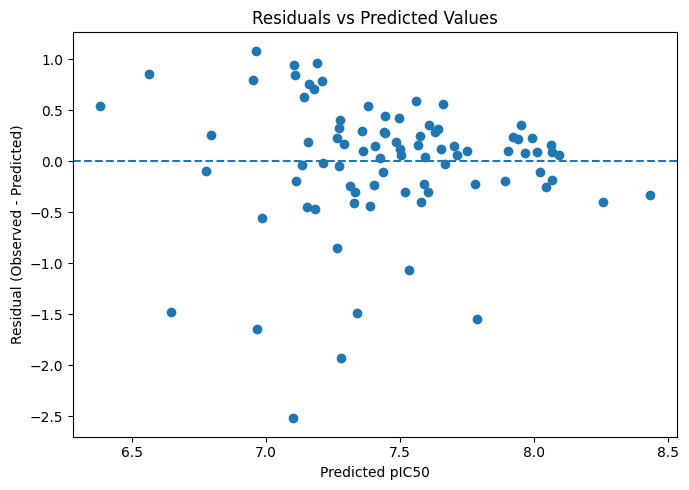

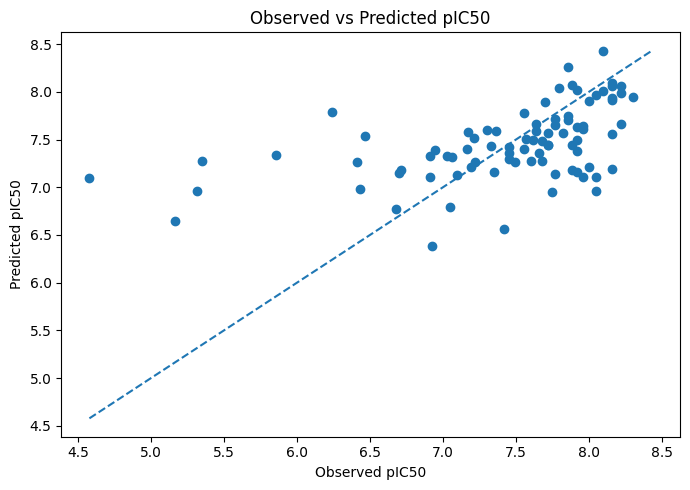

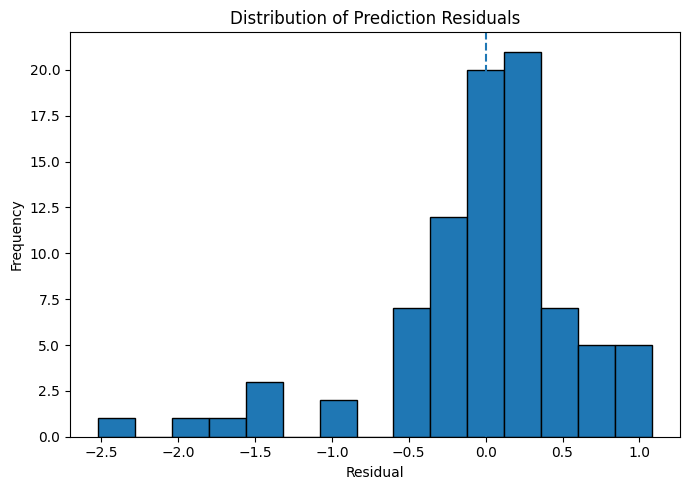

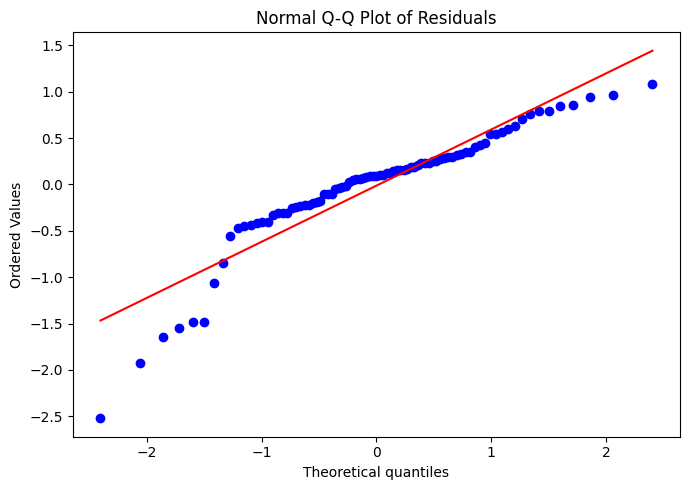


STEP 13A COMPLETED
Compounds analysed: 85
Mean residual: -0.0127
Residual SD: 0.6369
Shapiro-Wilk p-value: 1e-06
Output directory: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP13_RESIDUAL_ERROR_ANALYSIS


In [ ]:
# STEP 13A — ALDH1A1 QSAR RESIDUAL AND ERROR ANALYSIS

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    shapiro,
    skew,
    kurtosis,
    pearsonr,
    spearmanr
)

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD OBSERVED NESTED-CV PREDICTIONS
# --------------------------------------------------

RESIDUAL_DIR = os.path.join(
    ROOT,
    "STEP13_RESIDUAL_ERROR_ANALYSIS"
)

os.makedirs(RESIDUAL_DIR, exist_ok=True)

observed_df = pd.read_csv(OBS_FILE)

actual = observed_df["Observed_pIC50"].to_numpy(dtype=float)
predicted = observed_df["Predicted_pIC50"].to_numpy(dtype=float)

residuals = actual - predicted

assert len(actual) == 85
assert np.isfinite(residuals).all()

# --------------------------------------------------
# 2. CALCULATE RESIDUAL STATISTICS
# --------------------------------------------------

residual_sd = np.std(residuals, ddof=1)

standardized_residuals = (
    residuals - np.mean(residuals)
) / residual_sd

diagnostics = {
    "N": len(actual),
    "Mean_residual": np.mean(residuals),
    "Median_residual": np.median(residuals),
    "Residual_SD": residual_sd,
    "Residual_variance": np.var(residuals, ddof=1),
    "Residual_skewness": skew(residuals),
    "Residual_excess_kurtosis": kurtosis(residuals),
    "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    "MAE": mean_absolute_error(actual, predicted),
    "R2": r2_score(actual, predicted),
    "Pearson_r": pearsonr(actual, predicted).statistic,
    "Spearman_r": spearmanr(actual, predicted).statistic,
    "Residual_prediction_correlation": pearsonr(
        predicted, residuals
    ).statistic
}

shapiro_result = shapiro(residuals)

diagnostics["Shapiro_W"] = shapiro_result.statistic
diagnostics["Shapiro_p"] = shapiro_result.pvalue

# --------------------------------------------------
# 3. CREATE COMPOUND-LEVEL RESIDUAL TABLE
# --------------------------------------------------

residual_table = observed_df.copy()

residual_table["Absolute_Error"] = np.abs(residuals)
residual_table["Standardized_Residual"] = standardized_residuals

residual_table["Error_Direction"] = np.where(
    residuals > 0,
    "Underprediction",
    "Overprediction"
)

residual_table["Residual_Flag"] = np.select(
    [
        np.abs(standardized_residuals) > 3,
        np.abs(standardized_residuals) > 2
    ],
    [
        "Above 3 SD",
        "Above 2 SD"
    ],
    default="Within 2 SD"
)

residual_table.to_csv(
    os.path.join(RESIDUAL_DIR, "01_compound_residual_analysis.csv"),
    index=False
)

# --------------------------------------------------
# 4. SAVE SUMMARY STATISTICS
# --------------------------------------------------

summary = pd.DataFrame(
    list(diagnostics.items()),
    columns=["Diagnostic", "Value"]
)

summary.to_csv(
    os.path.join(RESIDUAL_DIR, "02_residual_summary_statistics.csv"),
    index=False
)

print("=" * 70)
print("RESIDUAL SUMMARY")
print("=" * 70)
print(summary.to_string(index=False))

# --------------------------------------------------
# 5. IDENTIFY LARGEST PREDICTION ERRORS
# --------------------------------------------------

largest_errors = residual_table.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

largest_errors.to_csv(
    os.path.join(RESIDUAL_DIR, "03_largest_prediction_errors.csv"),
    index=False
)

print("\nTOP 10 LARGEST PREDICTION ERRORS")
print(
    largest_errors[
        [
            "InChIKey",
            "Observed_pIC50",
            "Predicted_pIC50",
            "Residual",
            "Absolute_Error",
            "Standardized_Residual",
            "Residual_Flag"
        ]
    ].to_string(index=False)
)

# --------------------------------------------------
# 6. RESIDUAL VS PREDICTED PLOT
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(predicted, residuals)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted pIC50")
plt.ylabel("Residual (Observed - Predicted)")
plt.title("Residuals vs Predicted Values")

plt.tight_layout()

plt.savefig(
    os.path.join(RESIDUAL_DIR, "04_residual_vs_predicted.png"),
    dpi=300
)

plt.show()

# --------------------------------------------------
# 7. OBSERVED VS PREDICTED PLOT
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(actual, predicted)

minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Observed pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Observed vs Predicted pIC50")

plt.tight_layout()

plt.savefig(
    os.path.join(RESIDUAL_DIR, "05_observed_vs_predicted.png"),
    dpi=300
)

plt.show()

# --------------------------------------------------
# 8. RESIDUAL DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.hist(residuals, bins=15, edgecolor="black")

plt.axvline(0, linestyle="--")

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Residuals")

plt.tight_layout()

plt.savefig(
    os.path.join(RESIDUAL_DIR, "06_residual_distribution.png"),
    dpi=300
)

plt.show()

# --------------------------------------------------
# 9. NORMAL Q-Q PLOT
# --------------------------------------------------

from scipy.stats import probplot

plt.figure(figsize=(7, 5))

probplot(residuals, dist="norm", plot=plt)

plt.title("Normal Q-Q Plot of Residuals")

plt.tight_layout()

plt.savefig(
    os.path.join(RESIDUAL_DIR, "07_residual_qq_plot.png"),
    dpi=300
)

plt.show()

# --------------------------------------------------
# 10. FINAL OUTPUT
# --------------------------------------------------

print("\n" + "=" * 70)
print("STEP 13A COMPLETED")
print("=" * 70)

print("Compounds analysed:", len(residual_table))
print("Mean residual:", round(np.mean(residuals), 4))
print("Residual SD:", round(residual_sd, 4))
print("Shapiro-Wilk p-value:", round(shapiro_result.pvalue, 6))
print("Output directory:", RESIDUAL_DIR)

In [ ]:
# STEP 13B — INVESTIGATE LARGEST RESIDUAL COMPOUNDS

import os
import pandas as pd
import numpy as np

# Load residual table
RESIDUAL_FILE = os.path.join(
    RESIDUAL_DIR,
    "01_compound_residual_analysis.csv"
)

residual_table = pd.read_csv(RESIDUAL_FILE)

# Select compounds with absolute residual >= 1.0
flagged = residual_table[
    residual_table["Absolute_Error"] >= 1.0
].copy()

# Match against original training dataset
if "InChIKey" not in TRAIN.columns:
    raise KeyError("InChIKey column missing from TRAIN.")

investigation = flagged.merge(
    TRAIN,
    on="InChIKey",
    how="left",
    suffixes=("_prediction", "_training")
)

print("FLAGGED COMPOUNDS:", len(flagged))
print("MATCHED TRAINING RECORDS:", investigation["pIC50"].notna().sum()
      if "pIC50" in investigation.columns else "Check columns")

print("\nAVAILABLE COLUMNS:")
print(investigation.columns.tolist())

# Display useful molecular and activity information
preferred_columns = [
    "InChIKey",
    "Observed_pIC50",
    "Predicted_pIC50",
    "Residual",
    "Absolute_Error",
    "Standardized_Residual",
    "SMILES",
    "Canonical_SMILES",
    "Molecule_ID",
    "Molecule_Name",
    "Activity_Type",
    "Activity_Value",
    "Activity_Units",
    "Assay_ID",
    "Target_ID",
    "Murcko_scaffold"
]

available_columns = [
    c for c in preferred_columns if c in investigation.columns
]

print("\nFLAGGED COMPOUND INFORMATION:")
print(
    investigation[available_columns].to_string(index=False)
)

# Save full investigation table
output_file = os.path.join(
    RESIDUAL_DIR,
    "08_flagged_compound_investigation.csv"
)

investigation.to_csv(output_file, index=False)

print("\nSaved:", output_file)

FLAGGED COMPOUNDS: 8
MATCHED TRAINING RECORDS: 8

AVAILABLE COLUMNS:
['InChIKey', 'Observed_pIC50', 'Predicted_pIC50', 'Residual', 'Absolute_Error', 'Standardized_Residual', 'Error_Direction', 'Residual_Flag', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi3n', 'Chi3v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'Kappa1', 'Kappa2', 'Kappa3', 'LabuteASA', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3

In [ ]:
# STEP 13C — Tanimoto similarity analysis of flagged compounds

import os
import numpy as np
import pandas as pd

# Load training fingerprints
FP_COLS = [c for c in TRAIN.columns if c.startswith("FP_")]

assert len(FP_COLS) == 2048

fp_matrix = TRAIN[FP_COLS].to_numpy(dtype=np.uint8)
keys = TRAIN["InChIKey"].astype(str).to_numpy()
activities = TRAIN["pIC50"].to_numpy(dtype=float)
scaffolds = TRAIN["Murcko_scaffold"].astype(str).to_numpy()

# Load flagged compounds
residual_table = pd.read_csv(
    os.path.join(RESIDUAL_DIR, "01_compound_residual_analysis.csv")
)

flagged_keys = residual_table.loc[
    residual_table["Absolute_Error"] >= 1.0,
    "InChIKey"
].astype(str).tolist()

# Verify each flagged compound is present
key_to_index = {key: i for i, key in enumerate(keys)}

missing = [key for key in flagged_keys if key not in key_to_index]
assert not missing, f"Missing compounds: {missing}"

results = []

# Calculate Tanimoto similarities
for key in flagged_keys:

    i = key_to_index[key]
    query = fp_matrix[i]

    intersection = np.sum(fp_matrix & query, axis=1)
    union = np.sum(fp_matrix | query, axis=1)

    similarity = np.divide(
        intersection,
        union,
        out=np.zeros(len(union), dtype=float),
        where=union != 0
    )

    # Exclude the compound itself
    similarity[i] = -1

    nearest_idx = int(np.argmax(similarity))

    results.append({
        "Flagged_InChIKey": key,
        "Observed_pIC50": activities[i],
        "Nearest_InChIKey": keys[nearest_idx],
        "Nearest_Observed_pIC50": activities[nearest_idx],
        "Nearest_Tanimoto": similarity[nearest_idx],
        "Absolute_Activity_Difference": abs(
            activities[i] - activities[nearest_idx]
        ),
        "Same_Murcko_Scaffold": (
            scaffolds[i] == scaffolds[nearest_idx]
        )
    })

similarity_df = pd.DataFrame(results)

# Save output
similarity_file = os.path.join(
    RESIDUAL_DIR,
    "09_flagged_compound_nearest_neighbours.csv"
)

similarity_df.to_csv(similarity_file, index=False)

print("=" * 75)
print("FLAGGED COMPOUND NEAREST-NEIGHBOUR ANALYSIS")
print("=" * 75)

print(
    similarity_df.sort_values(
        "Nearest_Tanimoto",
        ascending=False
    ).to_string(index=False)
)

print("\nSaved:", similarity_file)

FLAGGED COMPOUND NEAREST-NEIGHBOUR ANALYSIS
           Flagged_InChIKey  Observed_pIC50            Nearest_InChIKey  Nearest_Observed_pIC50  Nearest_Tanimoto  Absolute_Activity_Difference  Same_Murcko_Scaffold
YLMIBCVECIJTDW-UHFFFAOYSA-N        6.464706 SJPGPRUBXSHHHJ-UHFFFAOYSA-N                6.913640          0.833333                      0.448934                  True
GJVPOLFGHISOPU-UHFFFAOYSA-N        8.045757 IFKUKAGVXCPLLG-UHFFFAOYSA-N                8.045757          0.818182                      0.000000                  True
FMFZAZUSFZNQCZ-UHFFFAOYSA-N        6.241088 DJKKOMSKDDIVHL-UHFFFAOYSA-N                7.920819          0.814286                      1.679731                 False
RGJCAMFUXJFCCL-UHFFFAOYSA-N        5.347754 SIGXVLVHXOJBCM-UHFFFAOYSA-N                7.026872          0.791045                      1.679118                  True
QYPYPGAQNSLSMG-UHFFFAOYSA-N        5.316053 GYROBEFCNYEQGH-UHFFFAOYSA-N                5.853872          0.761905             

In [ ]:
# STEP 13D — GLOBAL ACTIVITY-CLIFF SCREENING

import os
import numpy as np
import pandas as pd

# Screening thresholds
SIMILARITY_THRESHOLD = 0.80
ACTIVITY_DIFFERENCE_THRESHOLD = 1.0

# Retrieve training information
FP_COLS = [c for c in TRAIN.columns if c.startswith("FP_")]

fps = TRAIN[FP_COLS].to_numpy(dtype=np.uint8)
n = len(TRAIN)

keys = TRAIN["InChIKey"].astype(str).to_numpy()
activities = TRAIN["pIC50"].to_numpy(dtype=float)
smiles = TRAIN["SMILES"].astype(str).to_numpy()
scaffolds = TRAIN["Murcko_scaffold"].astype(str).to_numpy()

# Calculate all pairwise Tanimoto similarities
intersection = fps @ fps.T

bit_counts = fps.sum(axis=1)
union = bit_counts[:, None] + bit_counts[None, :] - intersection

similarity_matrix = np.divide(
    intersection,
    union,
    out=np.zeros((n, n), dtype=float),
    where=union != 0
)

# Examine unique pairs only
rows = []

for i in range(n):
    for j in range(i + 1, n):

        tanimoto = similarity_matrix[i, j]
        delta = abs(activities[i] - activities[j])

        if (
            tanimoto >= SIMILARITY_THRESHOLD
            and delta >= ACTIVITY_DIFFERENCE_THRESHOLD
        ):

            rows.append({
                "Compound_1": keys[i],
                "Compound_2": keys[j],
                "pIC50_1": activities[i],
                "pIC50_2": activities[j],
                "Delta_pIC50": delta,
                "Fold_Activity_Difference": 10 ** delta,
                "Tanimoto": tanimoto,
                "Same_Murcko_Scaffold": (
                    scaffolds[i] == scaffolds[j]
                ),
                "SMILES_1": smiles[i],
                "SMILES_2": smiles[j]
            })

# Create results
cliffs = pd.DataFrame(rows)

if not cliffs.empty:
    cliffs = cliffs.sort_values(
        ["Delta_pIC50", "Tanimoto"],
        ascending=[False, False]
    )

# Save results
cliff_file = os.path.join(
    RESIDUAL_DIR,
    "10_global_activity_cliff_candidates.csv"
)

cliffs.to_csv(cliff_file, index=False)

print("=" * 75)
print("GLOBAL ACTIVITY-CLIFF SCREENING")
print("=" * 75)

print("Total compounds:", n)
print("Unique compound pairs:", n * (n - 1) // 2)
print("Similarity threshold:", SIMILARITY_THRESHOLD)
print("Activity difference threshold:", ACTIVITY_DIFFERENCE_THRESHOLD)
print("Candidate pairs:", len(cliffs))

if len(cliffs):
    print("\nCANDIDATE ACTIVITY CLIFFS:")
    print(
        cliffs[
            [
                "Compound_1",
                "Compound_2",
                "pIC50_1",
                "pIC50_2",
                "Delta_pIC50",
                "Fold_Activity_Difference",
                "Tanimoto",
                "Same_Murcko_Scaffold"
            ]
        ].to_string(index=False)
    )
else:
    print("\nNo pairs met both screening thresholds.")

print("\nSaved:", cliff_file)

GLOBAL ACTIVITY-CLIFF SCREENING
Total compounds: 85
Unique compound pairs: 3570
Similarity threshold: 0.8
Activity difference threshold: 1.0
Candidate pairs: 5

CANDIDATE ACTIVITY CLIFFS:
                 Compound_1                  Compound_2  pIC50_1  pIC50_2  Delta_pIC50  Fold_Activity_Difference  Tanimoto  Same_Murcko_Scaffold
FMFZAZUSFZNQCZ-UHFFFAOYSA-N DJKKOMSKDDIVHL-UHFFFAOYSA-N 6.241088 7.920819     1.679731                 47.833333  0.814286                 False
VOXMVUIBQYRLEA-UHFFFAOYSA-N KSNYZQADVIKYIC-UHFFFAOYSA-N 8.000000 6.701147     1.298853                 19.900000  0.805970                  True
QKLGTXPKMMTLTA-UHFFFAOYSA-N KSNYZQADVIKYIC-UHFFFAOYSA-N 7.958607 6.701147     1.257460                 18.090909  0.818182                  True
YLMIBCVECIJTDW-UHFFFAOYSA-N ZLKYLYYFMYEWEU-UHFFFAOYSA-N 6.464706 7.619789     1.155083                 14.291667  0.819672                  True
YLMIBCVECIJTDW-UHFFFAOYSA-N AQUFTNLJKRXRSQ-UHFFFAOYSA-N 6.464706 7.568636     1.103930 

In [ ]:
# STEP 13E — VERIFY ACTIVITY-CLIFF PAIRS AND SOURCE RECORDS

import os
import pandas as pd

CLIFF_FILE = os.path.join(
    RESIDUAL_DIR,
    "10_global_activity_cliff_candidates.csv"
)

cliffs = pd.read_csv(CLIFF_FILE)

# Collect unique compound identifiers
pair_keys = pd.unique(
    cliffs[["Compound_1", "Compound_2"]].values.ravel()
)

# Retrieve original training records
pair_records = TRAIN[
    TRAIN["InChIKey"].astype(str).isin(pair_keys)
].copy()

print("Unique compounds in candidate pairs:", len(pair_keys))
print("Matched records:", len(pair_records))

print("\nAVAILABLE SOURCE COLUMNS:")
print(pair_records.columns.tolist())

# Select relevant fields that actually exist
preferred = [
    "InChIKey",
    "SMILES",
    "Canonical_SMILES",
    "Molecule_ID",
    "Molecule_Name",
    "pIC50",
    "Activity_Type",
    "Activity_Value",
    "Activity_Units",
    "Assay_ID",
    "Target_ID",
    "Murcko_scaffold",
    "Source",
    "Document_ID"
]

available = [
    col for col in preferred
    if col in pair_records.columns
]

print("\nCOMPOUND RECORDS:")
print(pair_records[available].to_string(index=False))

# Save audit
audit_path = os.path.join(
    RESIDUAL_DIR,
    "11_activity_cliff_source_audit.csv"
)

pair_records.to_csv(audit_path, index=False)

print("\nSaved:", audit_path)

Unique compounds in candidate pairs: 8
Matched records: 8

AVAILABLE SOURCE COLUMNS:
['InChIKey', 'SMILES', 'molecule_chembl_id', 'activity_id', 'assay_chembl_id', 'document_chembl_id', 'target_chembl_id', 'target_organism', 'standard_type', 'standard_relation', 'IC50_nM', 'IC50_unit', 'pIC50', 'Activity_source', 'Evidence_status', 'Endpoint_class', 'Target', 'Dataset_role', 'MaxAbsEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'AvgIpc', 'BalabanJ', 'BertzCT', 'Chi0', 'Chi0n', 'Chi0v', 'Chi1', 'Chi1n', 'Chi1v', 'Chi2n', 'Chi2v', 'Chi3n', 'Chi3v', 'Chi4n', 'Chi4v', 'HallKierAlpha', 'Ipc', 'Kappa1', 'Kappa2', 'Kappa3', 'LabuteASA', 'PEOE_VSA1', 'PEOE_VSA10', 'PEOE_VSA11', 'PEOE_VSA12', 'PEOE_VSA13', 'PEOE_VSA14', 'PEOE_VSA2', 'PEOE_VSA3', 'PEOE_VSA4', 'PEOE_VSA5', 'PEOE_VSA6', 'PEOE_VSA7', 'PEOE_VSA8', 'PEOE_VSA9', 'SMR_VSA1', 'SMR_VSA10', 'SMR_V

In [ ]:
# STEP 13F — ASSAY AND ACTIVITY PROVENANCE AUDIT

import os
import pandas as pd

# Retrieve unique compounds from the five candidate pairs
pair_keys = pd.unique(
    cliffs[["Compound_1", "Compound_2"]].values.ravel()
)

records = TRAIN[
    TRAIN["InChIKey"].astype(str).isin(pair_keys)
].copy()

# Fields essential for checking assay comparability
audit_columns = [
    "InChIKey",
    "molecule_chembl_id",
    "activity_id",
    "assay_chembl_id",
    "document_chembl_id",
    "target_chembl_id",
    "target_organism",
    "standard_type",
    "standard_relation",
    "IC50_nM",
    "IC50_unit",
    "pIC50",
    "Activity_source",
    "Evidence_status",
    "Endpoint_class",
    "Dataset_role"
]

available = [
    c for c in audit_columns
    if c in records.columns
]

audit = records[available].sort_values(
    ["assay_chembl_id", "InChIKey"]
)

print("=" * 80)
print("ACTIVITY-CLIFF ASSAY PROVENANCE AUDIT")
print("=" * 80)

print(audit.to_string(index=False))

print("\nUNIQUE ASSAYS:")
print(records["assay_chembl_id"].value_counts(dropna=False))

print("\nUNIQUE DOCUMENTS:")
print(records["document_chembl_id"].value_counts(dropna=False))

print("\nTARGET ORGANISMS:")
print(records["target_organism"].value_counts(dropna=False))

print("\nSTANDARD RELATIONS:")
print(records["standard_relation"].value_counts(dropna=False))

# Save
audit_path = os.path.join(
    RESIDUAL_DIR,
    "12_activity_cliff_assay_provenance_audit.csv"
)

audit.to_csv(audit_path, index=False)

print("\nSaved:", audit_path)

ACTIVITY-CLIFF ASSAY PROVENANCE AUDIT
                   InChIKey molecule_chembl_id  activity_id assay_chembl_id document_chembl_id target_chembl_id target_organism standard_type standard_relation  IC50_nM IC50_unit    pIC50 Activity_source        Evidence_status Endpoint_class                    Dataset_role
AQUFTNLJKRXRSQ-UHFFFAOYSA-N      CHEMBL4204569     18504806   CHEMBL4189991      CHEMBL4184337       CHEMBL3577    Homo sapiens          IC50                 =     27.0        nM 7.568636          ChEMBL EXACT_IC50_EXPLICIT_NM    BIOCHEMICAL PRIMARY_SINGLE_ASSAY_REGRESSION
DJKKOMSKDDIVHL-UHFFFAOYSA-N      CHEMBL4216229     18504775   CHEMBL4189991      CHEMBL4184337       CHEMBL3577    Homo sapiens          IC50                 =     12.0        nM 7.920819          ChEMBL EXACT_IC50_EXPLICIT_NM    BIOCHEMICAL PRIMARY_SINGLE_ASSAY_REGRESSION
FMFZAZUSFZNQCZ-UHFFFAOYSA-N      CHEMBL4215888     18504773   CHEMBL4189991      CHEMBL4184337       CHEMBL3577    Homo sapiens          IC5

In [ ]:
# STEP 13G — MATCHED MOLECULAR PAIR ANALYSIS

import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdMMPA

# --------------------------------------------------
# 1. LOAD VERIFIED ACTIVITY-CLIFF PAIRS
# --------------------------------------------------

CLIFF_FILE = os.path.join(
    RESIDUAL_DIR,
    "10_global_activity_cliff_candidates.csv"
)

cliffs = pd.read_csv(CLIFF_FILE)

# Retrieve compound records
pair_keys = pd.unique(
    cliffs[["Compound_1", "Compound_2"]].values.ravel()
)

records = TRAIN[
    TRAIN["InChIKey"].astype(str).isin(pair_keys)
].copy()

assert len(records) == 8, "Expected 8 unique compounds."

# Use the available canonical structure column
smiles_col = next(
    (c for c in ["Canonical_SMILES", "SMILES"] if c in records.columns),
    None
)

assert smiles_col is not None, "No SMILES column found."

# --------------------------------------------------
# 2. DEFINE MMPA FRAGMENTATION
# --------------------------------------------------

results = []

for _, pair in cliffs.iterrows():

    key1 = pair["Compound_1"]
    key2 = pair["Compound_2"]

    mol1_record = records[
        records["InChIKey"] == key1
    ].iloc[0]

    mol2_record = records[
        records["InChIKey"] == key2
    ].iloc[0]

    smiles1 = mol1_record[smiles_col]
    smiles2 = mol2_record[smiles_col]

    mol1 = Chem.MolFromSmiles(smiles1)
    mol2 = Chem.MolFromSmiles(smiles2)

    if mol1 is None or mol2 is None:
        continue

    # Generate single-cut fragments
    fragments1 = rdMMPA.FragmentMol(
        mol1,
        maxCuts=1,
        resultsAsMols=False
    )

    fragments2 = rdMMPA.FragmentMol(
        mol2,
        maxCuts=1,
        resultsAsMols=False
    )

    # Extract fragment pairs
    def fragment_set(fragment_output):
        output = set()

        for fragment_a, fragment_b in fragment_output:
            output.add((fragment_a, fragment_b))

        return output

    set1 = fragment_set(fragments1)
    set2 = fragment_set(fragments2)

    common = set1.intersection(set2)

    transformations = []

    for frag_a, frag_b in common:
        transformations.append(
            f"{frag_a} >> {frag_b}"
        )

    results.append({
        "Compound_1": key1,
        "Compound_2": key2,
        "pIC50_1": pair["pIC50_1"],
        "pIC50_2": pair["pIC50_2"],
        "Delta_pIC50": pair["Delta_pIC50"],
        "Tanimoto": pair["Tanimoto"],
        "Common_fragment_count": len(common),
        "Common_fragment_transformations": " | ".join(
            transformations
        ) if transformations else "No common single-cut fragment pair detected"
    })

# --------------------------------------------------
# 3. SAVE RESULTS
# --------------------------------------------------

mmp_results = pd.DataFrame(results)

output_file = os.path.join(
    RESIDUAL_DIR,
    "13_matched_molecular_pair_analysis.csv"
)

mmp_results.to_csv(output_file, index=False)

print("=" * 75)
print("MATCHED MOLECULAR PAIR ANALYSIS")
print("=" * 75)

print(mmp_results.to_string(index=False))

print("\nSaved:", output_file)
print("\nPairs analysed:", len(mmp_results))

MATCHED MOLECULAR PAIR ANALYSIS
                 Compound_1                  Compound_2  pIC50_1  pIC50_2  Delta_pIC50  Tanimoto  Common_fragment_count             Common_fragment_transformations
FMFZAZUSFZNQCZ-UHFFFAOYSA-N DJKKOMSKDDIVHL-UHFFFAOYSA-N 6.241088 7.920819     1.679731  0.814286                      0 No common single-cut fragment pair detected
VOXMVUIBQYRLEA-UHFFFAOYSA-N KSNYZQADVIKYIC-UHFFFAOYSA-N 8.000000 6.701147     1.298853  0.805970                      0 No common single-cut fragment pair detected
QKLGTXPKMMTLTA-UHFFFAOYSA-N KSNYZQADVIKYIC-UHFFFAOYSA-N 7.958607 6.701147     1.257460  0.818182                      0 No common single-cut fragment pair detected
YLMIBCVECIJTDW-UHFFFAOYSA-N ZLKYLYYFMYEWEU-UHFFFAOYSA-N 6.464706 7.619789     1.155083  0.819672                      0 No common single-cut fragment pair detected
YLMIBCVECIJTDW-UHFFFAOYSA-N AQUFTNLJKRXRSQ-UHFFFAOYSA-N 6.464706 7.568636     1.103930  0.819672                      0 No common single-cut fragmen

In [ ]:
%pip install -q rdkit

In [ ]:
# STEP 13H — MAXIMUM COMMON SUBSTRUCTURE ANALYSIS

import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFMCS

# --------------------------------------------------
# 1. LOAD THE FIVE CANDIDATE PAIRS
# --------------------------------------------------

CLIFF_FILE = os.path.join(
    RESIDUAL_DIR,
    "10_global_activity_cliff_candidates.csv"
)

cliffs = pd.read_csv(CLIFF_FILE)

pair_keys = pd.unique(
    cliffs[["Compound_1", "Compound_2"]].values.ravel()
)

records = TRAIN[
    TRAIN["InChIKey"].astype(str).isin(pair_keys)
].copy()

smiles_col = next(
    (c for c in ["Canonical_SMILES", "SMILES"] if c in records.columns),
    None
)

assert smiles_col is not None, "SMILES column not found."
assert len(records) == len(pair_keys), "Some compounds are missing."

# --------------------------------------------------
# 2. HELPER FUNCTIONS
# --------------------------------------------------

def unmatched_fragments(mol, matched_atoms):
    """Remove MCS atoms and return the remaining molecular fragments."""
    rw = Chem.RWMol(mol)

    for atom_idx in sorted(matched_atoms, reverse=True):
        rw.RemoveAtom(atom_idx)

    remaining = rw.GetMol()

    try:
        Chem.SanitizeMol(remaining)
        fragments = Chem.GetMolFrags(
            remaining,
            asMols=True,
            sanitizeFrags=True
        )
        return [
            Chem.MolToSmiles(fragment, canonical=True)
            for fragment in fragments
        ]
    except Exception:
        return ["Could not sanitise remaining fragments"]


def attachment_summary(mol, match):
    """Describe bonds connecting the shared core to unmatched atoms."""
    matched = set(match)
    connections = []

    for core_position, atom_idx in enumerate(match):
        atom = mol.GetAtomWithIdx(atom_idx)

        for neighbour in atom.GetNeighbors():
            neighbour_idx = neighbour.GetIdx()

            if neighbour_idx not in matched:
                bond = mol.GetBondBetweenAtoms(
                    atom_idx,
                    neighbour_idx
                )

                connections.append(
                    f"core_atom_{core_position}:"
                    f"{bond.GetBondType()}-"
                    f"{neighbour.GetSymbol()}"
                )

    return "; ".join(sorted(set(connections))) or "No external attachments"


# --------------------------------------------------
# 3. COMPARE EACH PAIR
# --------------------------------------------------

results = []

for _, pair in cliffs.iterrows():

    key1 = pair["Compound_1"]
    key2 = pair["Compound_2"]

    rec1 = records[records["InChIKey"] == key1].iloc[0]
    rec2 = records[records["InChIKey"] == key2].iloc[0]

    mol1 = Chem.MolFromSmiles(rec1[smiles_col])
    mol2 = Chem.MolFromSmiles(rec2[smiles_col])

    if mol1 is None or mol2 is None:
        continue

    mcs = rdFMCS.FindMCS(
        [mol1, mol2],
        atomCompare=rdFMCS.AtomCompare.CompareElements,
        bondCompare=rdFMCS.BondCompare.CompareOrder,
        ringMatchesRingOnly=True,
        completeRingsOnly=True,
        matchValences=True,
        timeout=30
    )

    if mcs.canceled or not mcs.smartsString:
        results.append({
            "Compound_1": key1,
            "Compound_2": key2,
            "MCS_status": "Timeout or no MCS",
            "MCS_atoms": None
        })
        continue

    query = Chem.MolFromSmarts(mcs.smartsString)

    match1 = mol1.GetSubstructMatch(query)
    match2 = mol2.GetSubstructMatch(query)

    if not match1 or not match2:
        continue

    core1 = Chem.MolFragmentToSmiles(
        mol1,
        atomsToUse=list(match1),
        canonical=True
    )

    core2 = Chem.MolFragmentToSmiles(
        mol2,
        atomsToUse=list(match2),
        canonical=True
    )

    results.append({
        "Compound_1": key1,
        "Compound_2": key2,
        "pIC50_1": pair["pIC50_1"],
        "pIC50_2": pair["pIC50_2"],
        "Delta_pIC50": pair["Delta_pIC50"],
        "Tanimoto": pair["Tanimoto"],
        "MCS_atoms": mcs.numAtoms,
        "MCS_bonds": mcs.numBonds,
        "MCS_fraction_compound_1": round(
            mcs.numAtoms / mol1.GetNumHeavyAtoms(), 3
        ),
        "MCS_fraction_compound_2": round(
            mcs.numAtoms / mol2.GetNumHeavyAtoms(), 3
        ),
        "Shared_core_1": core1,
        "Shared_core_2": core2,
        "Different_fragments_1": " | ".join(
            unmatched_fragments(mol1, match1)
        ),
        "Different_fragments_2": " | ".join(
            unmatched_fragments(mol2, match2)
        ),
        "Attachments_1": attachment_summary(mol1, match1),
        "Attachments_2": attachment_summary(mol2, match2),
        "MCS_status": "Completed"
    })

# --------------------------------------------------
# 4. SAVE AND DISPLAY
# --------------------------------------------------

mcs_results = pd.DataFrame(results)

output_file = os.path.join(
    RESIDUAL_DIR,
    "14_MCS_structural_comparison.csv"
)

mcs_results.to_csv(output_file, index=False)

print("=" * 75)
print("STEP 13H — MCS STRUCTURAL COMPARISON")
print("=" * 75)

display(mcs_results)

print("\nPairs analysed:", len(mcs_results))
print("Saved:", output_file)

STEP 13H — MCS STRUCTURAL COMPARISON


,Compound_1,Compound_2,pIC50_1,pIC50_2,Delta_pIC50,Tanimoto,MCS_atoms,MCS_bonds,MCS_fraction_compound_1,MCS_fraction_compound_2,Shared_core_1,Shared_core_2,Different_fragments_1,Different_fragments_2,Attachments_1,Attachments_2,MCS_status
0,FMFZAZUSFZNQCZ-UHFFFAOYSA-N,DJKKOMSKDDIVHL-UHFFFAOYSA-N,6.241088,7.920819,1.679731,0.814286,32,35,0.842,0.970,CC1(C#N)CCN(c2c(C(=O)N3CCN(S(C)(=O)=O)CC3)cnc3...,CC1(C#N)CCN(c2c(C(=O)N3CCN(S(C)(=O)=O)CC3)cnc3...,c1ccccc1,C,core_atom_0:SINGLE-C,core_atom_0:SINGLE-C,Completed
1,VOXMVUIBQYRLEA-UHFFFAOYSA-N,KSNYZQADVIKYIC-UHFFFAOYSA-N,8.000000,6.701147,1.298853,0.805970,35,39,0.946,0.972,CS(=O)(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(c3...,CS(=O)(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(c3...,C=O,O,core_atom_21:SINGLE-C,core_atom_21:SINGLE-O,Completed
2,QKLGTXPKMMTLTA-UHFFFAOYSA-N,KSNYZQADVIKYIC-UHFFFAOYSA-N,7.958607,6.701147,1.257460,0.818182,35,39,0.921,0.972,CS(=O)(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(c3...,CS(=O)(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(c3...,CC=O,O,core_atom_21:SINGLE-C,core_atom_21:SINGLE-O,Completed
3,YLMIBCVECIJTDW-UHFFFAOYSA-N,ZLKYLYYFMYEWEU-UHFFFAOYSA-N,6.464706,7.619789,1.155083,0.819672,30,33,0.968,0.909,CC1(C#N)CCN(c2c(C(=O)N3CCN(C=O)CC3)cnc3ccc(F)c...,CC1(C#N)CCN(c2c(C(=O)N3CCN(C=O)CC3)cnc3ccc(F)c...,C,CNC,core_atom_0:SINGLE-C,core_atom_0:SINGLE-N,Completed
4,YLMIBCVECIJTDW-UHFFFAOYSA-N,AQUFTNLJKRXRSQ-UHFFFAOYSA-N,6.464706,7.568636,1.103930,0.819672,31,34,1.000,0.939,CC(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)(C#N...,CC(=O)N1CCN(C(=O)c2cnc3ccc(F)cc3c2N2CCC(C)(C#N...,,C | C,No external attachments,core_atom_0:SINGLE-C,Completed



Pairs analysed: 5
Saved: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP13_RESIDUAL_ERROR_ANALYSIS/14_MCS_structural_comparison.csv


In [ ]:
# STEP 14A — LOCATE MODEL EVALUATION FILES

import os
import glob
import pandas as pd

ROOT = (
    "/content/gdrive_new/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

search_dirs = [
    os.path.join(ROOT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"),
    os.path.join(ROOT, "STEP12_Y_RANDOMISATION"),
    os.path.join(ROOT, "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS")
]

print("ROOT exists:", os.path.exists(ROOT))

for folder in search_dirs:
    print("\n" + "=" * 75)
    print("FOLDER:", folder)
    print("EXISTS:", os.path.exists(folder))

    if os.path.exists(folder):
        for path in sorted(glob.glob(os.path.join(folder, "*.csv"))):
            print(" -", os.path.basename(path))

ROOT exists: True

FOLDER: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT
EXISTS: True
 - 01_nested_CV_fold_results.csv
 - 02_nested_CV_model_comparison.csv
 - 03_final_training_CV_search_results.csv

FOLDER: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION
EXISTS: True
 - OBSERVED_NESTED_CV.csv
 - Y_RANDOMISATION_PROGRESS.csv

FOLDER: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS
EXISTS: True
 - OBSERVED_MORGAN_SVR_NESTED_CV.csv
 - Y_RANDOMISATION_100_PROGRESS.csv


In [ ]:
# STEP 14B — INSPECT ORIGINAL AND REANALYSED RESULTS

import os
import pandas as pd

files = {
    "Original nested CV folds": os.path.join(
        ROOT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT",
        "01_nested_CV_fold_results.csv"
    ),
    "Original model comparison": os.path.join(
        ROOT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT",
        "02_nested_CV_model_comparison.csv"
    ),
    "Original Y-randomisation observed": os.path.join(
        ROOT, "STEP12_Y_RANDOMISATION",
        "OBSERVED_NESTED_CV.csv"
    ),
    "Reanalysis observed CV": os.path.join(
        ROOT, "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
        "OBSERVED_MORGAN_SVR_NESTED_CV.csv"
    )
}

for label, path in files.items():

    print("\n" + "=" * 90)
    print(label)
    print("File:", os.path.basename(path))

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(8))

    print("\nNumeric summary:")
    display(df.describe(include="all").T)


Original nested CV folds
File: 01_nested_CV_fold_results.csv
Shape: (50, 9)
Columns: ['Representation', 'Model', 'Outer_Fold', 'N_Train', 'N_Validation', 'RMSE', 'MAE', 'R2', 'Best_Parameters']


,Representation,Model,Outer_Fold,N_Train,N_Validation,RMSE,MAE,R2,Best_Parameters
0,DESCRIPTORS,Ridge,1,68,17,0.441308,0.357889,-0.431943,{'model__alpha': 100}
1,DESCRIPTORS,Ridge,2,68,17,0.742723,0.471006,-0.034070,{'model__alpha': 100}
2,DESCRIPTORS,Ridge,3,68,17,0.505802,0.431766,-0.841644,{'model__alpha': 100}
3,DESCRIPTORS,Ridge,4,68,17,0.876307,0.528293,0.218902,{'model__alpha': 100}
4,DESCRIPTORS,Ridge,5,68,17,0.711096,0.489403,0.024906,{'model__alpha': 100}
5,DESCRIPTORS,SVR_RBF,1,68,17,0.655671,0.614096,-2.160926,"{'model__C': 1, 'model__epsilon': 0.1, 'model_..."
6,DESCRIPTORS,SVR_RBF,2,68,17,0.977695,0.682794,-0.791854,"{'model__C': 0.1, 'model__epsilon': 0.2, 'mode..."
7,DESCRIPTORS,SVR_RBF,3,68,17,0.373290,0.281324,-0.003083,"{'model__C': 0.1, 'model__epsilon': 0.1, 'mode..."



Numeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Representation,50,2,DESCRIPTORS,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,50,5,Ridge,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outer_Fold,50.0,NaN,NaN,NaN,3.0,1.428571,1.0,2.0,3.0,4.0,5.0
N_Train,50.0,NaN,NaN,NaN,68.0,0.0,68.0,68.0,68.0,68.0,68.0
N_Validation,50.0,NaN,NaN,NaN,17.0,0.0,17.0,17.0,17.0,17.0,17.0
RMSE,50.0,NaN,NaN,NaN,0.687411,0.175004,0.299541,0.554751,0.708776,0.833374,0.977695
MAE,50.0,NaN,NaN,NaN,0.501518,0.116226,0.260179,0.443532,0.504552,0.542677,0.859828
R2,50.0,NaN,NaN,NaN,-0.504448,1.113828,-5.222045,-0.77649,-0.123645,0.190318,0.451486
Best_Parameters,50,25,{'model__alpha': 100},5,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Original model comparison
File: 02_nested_CV_model_comparison.csv
Shape: (10, 8)
Columns: ['Representation', 'Model', 'Nested_CV_RMSE_Mean', 'Nested_CV_RMSE_SD', 'Nested_CV_MAE_Mean', 'Nested_CV_MAE_SD', 'Nested_CV_R2_Mean', 'Nested_CV_R2_SD']


,Representation,Model,Nested_CV_RMSE_Mean,Nested_CV_RMSE_SD,Nested_CV_MAE_Mean,Nested_CV_MAE_SD,Nested_CV_R2_Mean,Nested_CV_R2_SD
0,DESCRIPTORS,Ridge,0.655447,0.178705,0.455671,0.064769,-0.212770,0.423758
1,DESCRIPTORS,RandomForest,0.670525,0.142344,0.507395,0.098065,-0.563104,1.320251
2,DESCRIPTORS,ExtraTrees,0.699781,0.196450,0.530660,0.190239,-0.970443,2.385909
3,DESCRIPTORS,SVR_RBF,0.714467,0.239660,0.503606,0.163887,-0.525739,0.996012
4,DESCRIPTORS,GradientBoosting,0.753227,0.144696,0.560316,0.105496,-0.962633,1.658908
5,MORGAN_FINGERPRINTS,SVR_RBF,0.636888,0.232445,0.450840,0.127214,-0.166139,0.700832
6,MORGAN_FINGERPRINTS,Ridge,0.660020,0.134360,0.476305,0.087309,-0.365725,0.814525
7,MORGAN_FINGERPRINTS,GradientBoosting,0.668431,0.221131,0.486950,0.118026,-0.255755,0.641515


... (6 outputs left out)


Reanalysis observed CV
File: OBSERVED_MORGAN_SVR_NESTED_CV.csv
Shape: (85, 4)
Columns: ['InChIKey', 'Observed_pIC50', 'Predicted_pIC50', 'Residual']


,InChIKey,Observed_pIC50,Predicted_pIC50,Residual
0,XWWGQKZEWGNOAE-UHFFFAOYSA-N,8.045757,7.964067,0.081690
1,YYGZIDIXCKXQKP-UHFFFAOYSA-N,8.096910,8.010794,0.086116
2,LTYICVOXPDVDMD-UHFFFAOYSA-N,8.301030,7.949475,0.351555
3,RUQWMJKTMUWGIU-UHFFFAOYSA-N,8.154902,8.092102,0.062800
4,QHKKUEBSRRDZMN-UHFFFAOYSA-N,7.769551,7.713449,0.056103
5,MDRAXOMAROCJHK-UHFFFAOYSA-N,7.698970,7.890325,-0.191355
6,AAARORKNKJOILL-UHFFFAOYSA-N,7.886057,8.067620,-0.181563
7,MIVWUIQZCQTJER-UHFFFAOYSA-N,8.154902,7.940700,0.214202



Numeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InChIKey,85,85,XWWGQKZEWGNOAE-UHFFFAOYSA-N,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Observed_pIC50,85.0,NaN,NaN,NaN,7.448006,0.736319,4.578232,7.173925,7.677781,7.920819,8.30103
Predicted_pIC50,85.0,NaN,NaN,NaN,7.460731,0.387127,6.38081,7.208966,7.439643,7.66585,8.431354
Residual,85.0,NaN,NaN,NaN,-0.012725,0.636947,-2.522883,-0.236469,0.096104,0.30087,1.083853


In [ ]:
# STEP 14C — AUDIT PREDICTIONS AND CROSS-VALIDATION

import os
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --------------------------------------------------
# 1. LOAD BOTH PREDICTION FILES
# --------------------------------------------------

original_path = os.path.join(
    ROOT, "STEP12_Y_RANDOMISATION",
    "OBSERVED_NESTED_CV.csv"
)

reanalyzed_path = os.path.join(
    ROOT, "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
    "OBSERVED_MORGAN_SVR_NESTED_CV.csv"
)

original = pd.read_csv(original_path)
reanalyzed = pd.read_csv(reanalyzed_path)

# --------------------------------------------------
# 2. MATCH COMPOUNDS
# --------------------------------------------------

comparison = original.merge(
    reanalyzed,
    on="InChIKey",
    suffixes=("_original", "_reanalyzed"),
    validate="one_to_one"
)

print("Original rows:", len(original))
print("Reanalysis rows:", len(reanalyzed))
print("Matched rows:", len(comparison))

print(
    "\nObserved values identical:",
    np.allclose(
        comparison["Observed_pIC50_original"],
        comparison["Observed_pIC50_reanalyzed"],
        atol=1e-8
    )
)

comparison["Prediction_difference"] = (
    comparison["Predicted_pIC50_original"]
    - comparison["Predicted_pIC50_reanalyzed"]
)

print(
    "\nMean absolute prediction difference:",
    comparison["Prediction_difference"].abs().mean()
)

print(
    "Maximum absolute prediction difference:",
    comparison["Prediction_difference"].abs().max()
)

# --------------------------------------------------
# 3. RECALCULATE METRICS
# --------------------------------------------------

def calculate_metrics(df, suffix):
    y_true = df[f"Observed_pIC50{suffix}"]
    y_pred = df[f"Predicted_pIC50{suffix}"]

    return {
        "N": len(df),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

metrics = pd.DataFrame([
    calculate_metrics(comparison, "_original"),
    calculate_metrics(comparison, "_reanalyzed")
], index=["Original", "Reanalysis"])

print("\nRECALCULATED METRICS")
display(metrics)

# --------------------------------------------------
# 4. INSPECT ORIGINAL MORGAN-SVR FOLD RESULTS
# --------------------------------------------------

fold_path = os.path.join(
    ROOT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT",
    "01_nested_CV_fold_results.csv"
)

folds = pd.read_csv(fold_path)

morgan_svr = folds[
    (folds["Representation"] == "MORGAN_FINGERPRINTS") &
    (folds["Model"] == "SVR_RBF")
].copy()

print("\nORIGINAL MORGAN-SVR OUTER FOLDS")
display(morgan_svr)

# --------------------------------------------------
# 5. INSPECT Y-RANDOMISATION PROGRESS FILES
# --------------------------------------------------

progress_files = [
    os.path.join(ROOT, "STEP12_Y_RANDOMISATION",
                 "Y_RANDOMISATION_PROGRESS.csv"),
    os.path.join(ROOT, "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
                 "Y_RANDOMISATION_100_PROGRESS.csv")
]

for path in progress_files:
    print("\nPROGRESS FILE:", os.path.basename(path))

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))
    else:
        print("File not found.")

# --------------------------------------------------
# 6. SHOW LARGEST PREDICTION DISAGREEMENTS
# --------------------------------------------------

print("\nLARGEST COMPOUND-LEVEL PREDICTION DIFFERENCES")

display(
    comparison.assign(
        Absolute_difference=comparison["Prediction_difference"].abs()
    ).sort_values(
        "Absolute_difference", ascending=False
    )[
        [
            "InChIKey",
            "Observed_pIC50_original",
            "Predicted_pIC50_original",
            "Predicted_pIC50_reanalyzed",
            "Prediction_difference"
        ]
    ].head(10)
)

Original rows: 85
Reanalysis rows: 85
Matched rows: 85

Observed values identical: True

Mean absolute prediction difference: 0.18516932863289196
Maximum absolute prediction difference: 1.0185868286211512

RECALCULATED METRICS


,N,RMSE,MAE,R2
Original,85,0.770566,0.551591,-0.108222
Reanalysis,85,0.633317,0.436843,0.251400



ORIGINAL MORGAN-SVR OUTER FOLDS


,Representation,Model,Outer_Fold,N_Train,N_Validation,RMSE,MAE,R2,Best_Parameters
30,MORGAN_FINGERPRINTS,SVR_RBF,1,68,17,0.551489,0.467958,-1.236232,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}"
31,MORGAN_FINGERPRINTS,SVR_RBF,2,68,17,0.901513,0.617660,-0.523488,"{'C': 10, 'epsilon': 0.1, 'gamma': 'auto'}"
32,MORGAN_FINGERPRINTS,SVR_RBF,3,68,17,0.299541,0.260179,0.354112,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}"
33,MORGAN_FINGERPRINTS,SVR_RBF,4,68,17,0.795006,0.443309,0.357113,"{'C': 100, 'epsilon': 0.2, 'gamma': 'auto'}"
34,MORGAN_FINGERPRINTS,SVR_RBF,5,68,17,0.636889,0.465095,0.217800,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}"



PROGRESS FILE: Y_RANDOMISATION_PROGRESS.csv
Shape: (25, 7)
Columns: ['Permutation', 'RMSE', 'MAE', 'R2', 'Pearson_r', 'Spearman_r', 'Selected_models']


,Permutation,RMSE,MAE,R2,Pearson_r,Spearman_r,Selected_models
0,1,0.765339,0.563734,-0.093238,0.098619,-0.010818,SVR_RBF;RandomForest;GradientBoosting;Gradient...
1,2,0.760203,0.542062,-0.078615,-0.092384,-0.037305,SVR_RBF;RandomForest;RandomForest;SVR_RBF;SVR_RBF
2,3,0.801970,0.589487,-0.200395,0.012536,0.095324,ExtraTrees;SVR_RBF;RandomForest;ExtraTrees;Ran...
3,4,0.745256,0.543079,-0.036618,-0.016217,0.022833,GradientBoosting;RandomForest;RandomForest;Gra...
4,5,0.767510,0.545852,-0.099449,-0.146113,-0.114578,RandomForest;RandomForest;RandomForest;SVR_RBF...



PROGRESS FILE: Y_RANDOMISATION_100_PROGRESS.csv
Shape: (100, 8)
Columns: ['Permutation', 'RMSE', 'MAE', 'R2', 'Pearson_r', 'Spearman_r', 'Selected_models', 'Best_parameters']


,Permutation,RMSE,MAE,R2,Pearson_r,Spearman_r,Selected_models,Best_parameters
0,1,0.748803,0.529403,-0.046507,0.073256,-0.045516,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 10, ""epsilon"": 0.2, ""gamma"": ""auto""}, {..."
1,2,0.784941,0.536754,-0.149956,-0.018782,-0.105012,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""auto""}, {""..."
2,3,0.786645,0.543131,-0.154956,-0.178160,-0.328183,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""auto""}, {""..."
3,4,0.732586,0.530025,-0.001671,0.218689,0.276020,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""scale""}, {..."
4,5,0.812752,0.554028,-0.232886,-0.143960,-0.110652,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF,"[{""C"": 1, ""epsilon"": 0.2, ""gamma"": ""scale""}, {..."



LARGEST COMPOUND-LEVEL PREDICTION DIFFERENCES


,InChIKey,Observed_pIC50_original,Predicted_pIC50_original,Predicted_pIC50_reanalyzed,Prediction_difference
26,NBQFDYMBHFXBAY-UHFFFAOYSA-N,7.420216,5.543777,6.562364,-1.018587
36,ROWBIGRSLCNQEI-UHFFFAOYSA-N,7.920819,6.462594,7.159597,-0.697003
35,IFKUKAGVXCPLLG-UHFFFAOYSA-N,8.045757,6.414070,7.104801,-0.690731
22,GJVPOLFGHISOPU-UHFFFAOYSA-N,8.045757,6.393598,6.961905,-0.568307
37,ACSXYVBEJQOTGI-UHFFFAOYSA-N,7.677781,6.822671,7.274865,-0.452194
12,VHSHRGVSEXNTQT-UHFFFAOYSA-N,7.853872,7.265933,7.702547,-0.436614
13,LXZPTKHHMFQKBR-UHFFFAOYSA-N,7.920819,7.231419,7.629789,-0.398370
84,DUAIQQKLZMRCAE-UHFFFAOYSA-N,7.301030,7.219118,7.604582,-0.385463
55,IYDUYEXHPBORSN-UHFFFAOYSA-N,6.430626,7.364085,6.985763,0.378323
18,IPRTVRBMOGEPMJ-UHFFFAOYSA-N,7.853872,7.386936,7.750614,-0.363678


In [ ]:
# STEP 14D — MODEL SELECTION AUDIT

import os
import pandas as pd
from collections import Counter

original_progress_path = os.path.join(
    ROOT, "STEP12_Y_RANDOMISATION",
    "Y_RANDOMISATION_PROGRESS.csv"
)

reanalysis_progress_path = os.path.join(
    ROOT, "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
    "Y_RANDOMISATION_100_PROGRESS.csv"
)

original_progress = pd.read_csv(original_progress_path)
reanalysis_progress = pd.read_csv(reanalysis_progress_path)

def inspect_selection(df, label):

    print("\n" + "=" * 75)
    print(label)
    print("Permutations recorded:", len(df))

    if "Selected_models" not in df.columns:
        print("No Selected_models column.")
        return

    counts = Counter()

    for entry in df["Selected_models"].dropna():
        models = str(entry).split(";")
        counts.update(models)

    print("\nSelected model counts across all recorded folds:")
    display(
        pd.DataFrame(
            counts.items(),
            columns=["Model", "Selection_Count"]
        ).sort_values("Selection_Count", ascending=False)
    )

    print("\nExample selection records:")
    display(df[["Permutation", "Selected_models"]].head(5))


inspect_selection(
    original_progress,
    "ORIGINAL RANDOMISATION"
)

inspect_selection(
    reanalysis_progress,
    "MORGAN-SVR REANALYSIS"
)

# Show original observed prediction metrics again
original_predictions = pd.read_csv(
    os.path.join(
        ROOT, "STEP12_Y_RANDOMISATION",
        "OBSERVED_NESTED_CV.csv"
    )
)

print("\nOriginal observed prediction file:")
print("Rows:", len(original_predictions))
print("Columns:", original_predictions.columns.tolist())

# Show all original model comparison results
model_comparison = pd.read_csv(
    os.path.join(
        ROOT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT",
        "02_nested_CV_model_comparison.csv"
    )
)

print("\nOriginal model comparison:")
display(
    model_comparison.sort_values(
        "Nested_CV_RMSE_Mean"
    )
)


ORIGINAL RANDOMISATION
Permutations recorded: 25

Selected model counts across all recorded folds:


,Model,Selection_Count
1,RandomForest,50
0,SVR_RBF,34
2,GradientBoosting,22
3,ExtraTrees,19



Example selection records:


,Permutation,Selected_models
0,1,SVR_RBF;RandomForest;GradientBoosting;Gradient...
1,2,SVR_RBF;RandomForest;RandomForest;SVR_RBF;SVR_RBF
2,3,ExtraTrees;SVR_RBF;RandomForest;ExtraTrees;Ran...
3,4,GradientBoosting;RandomForest;RandomForest;Gra...
4,5,RandomForest;RandomForest;RandomForest;SVR_RBF...



MORGAN-SVR REANALYSIS
Permutations recorded: 100

Selected model counts across all recorded folds:


,Model,Selection_Count
0,SVR_RBF,500



Example selection records:


,Permutation,Selected_models
0,1,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF
1,2,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF
2,3,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF
3,4,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF
4,5,SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF;SVR_RBF



Original observed prediction file:
Rows: 85
Columns: ['InChIKey', 'Observed_pIC50', 'Predicted_pIC50', 'Residual']

Original model comparison:


,Representation,Model,Nested_CV_RMSE_Mean,Nested_CV_RMSE_SD,Nested_CV_MAE_Mean,Nested_CV_MAE_SD,Nested_CV_R2_Mean,Nested_CV_R2_SD
5,MORGAN_FINGERPRINTS,SVR_RBF,0.636888,0.232445,0.450840,0.127214,-0.166139,0.700832
0,DESCRIPTORS,Ridge,0.655447,0.178705,0.455671,0.064769,-0.212770,0.423758
6,MORGAN_FINGERPRINTS,Ridge,0.660020,0.134360,0.476305,0.087309,-0.365725,0.814525
7,MORGAN_FINGERPRINTS,GradientBoosting,0.668431,0.221131,0.486950,0.118026,-0.255755,0.641515
1,DESCRIPTORS,RandomForest,0.670525,0.142344,0.507395,0.098065,-0.563104,1.320251
8,MORGAN_FINGERPRINTS,RandomForest,0.692976,0.175570,0.522631,0.127308,-0.529654,1.047411
2,DESCRIPTORS,ExtraTrees,0.699781,0.196450,0.530660,0.190239,-0.970443,2.385909
3,DESCRIPTORS,SVR_RBF,0.714467,0.239660,0.503606,0.163887,-0.525739,0.996012
9,MORGAN_FINGERPRINTS,ExtraTrees,0.722353,0.199762,0.520806,0.100953,-0.492519,0.533477
4,DESCRIPTORS,GradientBoosting,0.753227,0.144696,0.560316,0.105496,-0.962633,1.658908


In [ ]:
# STEP 14E — INSPECT ANALYSIS FILES AND MANIFESTS

import os
import json

folders = [
    os.path.join(
        ROOT,
        "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"
    ),
    os.path.join(
        ROOT,
        "STEP12_Y_RANDOMISATION"
    ),
    os.path.join(
        ROOT,
        "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
    )
]

for folder in folders:

    print("\n" + "=" * 85)
    print("DIRECTORY:", folder)

    for current, dirs, files in os.walk(folder):

        for filename in sorted(files):

            path = os.path.join(current, filename)
            print("\nFILE:", os.path.relpath(path, ROOT))

            if filename.lower().endswith(".json"):
                try:
                    with open(path, "r") as f:
                        content = json.load(f)

                    print(json.dumps(content, indent=2)[:7000])

                except Exception as e:
                    print("Could not read JSON:", e)

            elif filename.lower().endswith(".txt"):
                try:
                    with open(path, "r") as f:
                        print(f.read()[:4000])
                except Exception:
                    pass


DIRECTORY: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT

FILE: STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/01_nested_CV_fold_results.csv

FILE: STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/02_nested_CV_model_comparison.csv

FILE: STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/03_final_training_CV_search_results.csv

FILE: STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/04_STEP07_manifest.json
{
  "step": 7,
  "method": "Nested scaffold-aware cross-validation",
  "outer_cv": "5-fold GroupKFold",
  "inner_cv": "GroupKFold hyperparameter search",
  "training_compounds": 85,
  "unique_scaffolds": 40,
  "descriptor_features": 169,
  "fingerprint_features": 2048,
  "models_per_representation": 5,
  "test_set_used": false,
  "target": "pIC50",
  "model_selection_metric": "RMSE",
  "random_state": 42
}

FILE: STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT/

In [ ]:
# STEP 14F-A — INSPECT ORIGINAL MODEL CONFIGURATIONS

import os
import pandas as pd

step7_dir = os.path.join(
    ROOT,
    "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"
)

search_path = os.path.join(
    step7_dir,
    "03_final_training_CV_search_results.csv"
)

fold_path = os.path.join(
    step7_dir,
    "01_nested_CV_fold_results.csv"
)

search_results = pd.read_csv(search_path)
fold_results = pd.read_csv(fold_path)

print("=" * 75)
print("FINAL TRAINING CV SEARCH RESULTS")
print("=" * 75)

print("Shape:", search_results.shape)
print("Columns:", search_results.columns.tolist())
display(search_results)

print("\n" + "=" * 75)
print("ALL ORIGINAL OUTER-FOLD MODEL CONFIGURATIONS")
print("=" * 75)

display(
    fold_results[
        [
            "Representation",
            "Model",
            "Outer_Fold",
            "Best_Parameters"
        ]
    ].sort_values(
        ["Representation", "Model", "Outer_Fold"]
    )
)

FINAL TRAINING CV SEARCH RESULTS
Shape: (10, 5)
Columns: ['Representation', 'Model', 'Final_Training_CV_RMSE', 'Best_Parameters', 'Saved_Model']


,Representation,Model,Final_Training_CV_RMSE,Best_Parameters,Saved_Model
0,DESCRIPTORS,Ridge,0.655447,{'model__alpha': 100},/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
1,DESCRIPTORS,SVR_RBF,0.668237,"{'model__C': 1, 'model__epsilon': 0.1, 'model_...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
2,DESCRIPTORS,RandomForest,0.658223,"{'max_features': 'sqrt', 'min_samples_leaf': 2...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
3,DESCRIPTORS,ExtraTrees,0.671014,"{'max_features': 'sqrt', 'min_samples_leaf': 2...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
4,DESCRIPTORS,GradientBoosting,0.709891,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
5,MORGAN_FINGERPRINTS,Ridge,0.636380,{'alpha': 10},/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
6,MORGAN_FINGERPRINTS,SVR_RBF,0.614298,"{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
7,MORGAN_FINGERPRINTS,RandomForest,0.636265,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
8,MORGAN_FINGERPRINTS,ExtraTrees,0.618004,"{'max_features': 'sqrt', 'min_samples_leaf': 1...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...
9,MORGAN_FINGERPRINTS,GradientBoosting,0.672408,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",/content/drive/MyDrive/qsar/aldh1a1/03_data_cu...



ALL ORIGINAL OUTER-FOLD MODEL CONFIGURATIONS


,Representation,Model,Outer_Fold,Best_Parameters
15,DESCRIPTORS,ExtraTrees,1,"{'max_features': 'sqrt', 'min_samples_leaf': 1..."
16,DESCRIPTORS,ExtraTrees,2,"{'max_features': 'sqrt', 'min_samples_leaf': 2..."
17,DESCRIPTORS,ExtraTrees,3,"{'max_features': 'sqrt', 'min_samples_leaf': 2..."
18,DESCRIPTORS,ExtraTrees,4,"{'max_features': 'sqrt', 'min_samples_leaf': 1..."
19,DESCRIPTORS,ExtraTrees,5,"{'max_features': 'sqrt', 'min_samples_leaf': 2..."
20,DESCRIPTORS,GradientBoosting,1,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est..."
21,DESCRIPTORS,GradientBoosting,2,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est..."
22,DESCRIPTORS,GradientBoosting,3,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est..."
23,DESCRIPTORS,GradientBoosting,4,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
24,DESCRIPTORS,GradientBoosting,5,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est..."


In [ ]:
# STEP 14G — VERIFY ORIGINAL TRAINING DATA AND SCAFFOLD GROUPS

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

print("TRAIN shape:", TRAIN.shape)
print("Required columns:")

for col in ["InChIKey", "pIC50", "Murcko_scaffold"]:
    print(col, ":", col in TRAIN.columns)

assert len(TRAIN) == 85
assert TRAIN["InChIKey"].nunique() == 85
assert TRAIN["Murcko_scaffold"].nunique() == 40

# Recreate deterministic five-fold GroupKFold
gkf = GroupKFold(n_splits=5)

fold_assignments = []

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(TRAIN, TRAIN["pIC50"], TRAIN["Murcko_scaffold"]),
    start=1
):
    train_scaffolds = set(
        TRAIN.iloc[train_idx]["Murcko_scaffold"]
    )
    val_scaffolds = set(
        TRAIN.iloc[val_idx]["Murcko_scaffold"]
    )

    fold_assignments.append({
        "Outer_Fold": fold,
        "N_Train": len(train_idx),
        "N_Validation": len(val_idx),
        "Train_Scaffolds": len(train_scaffolds),
        "Validation_Scaffolds": len(val_scaffolds),
        "Shared_Scaffolds": len(
            train_scaffolds.intersection(val_scaffolds)
        )
    })

print("\nRECONSTRUCTED FOLD SUMMARY")
display(pd.DataFrame(fold_assignments))

TRAIN shape: (85, 2236)
Required columns:
InChIKey : True
pIC50 : True
Murcko_scaffold : True

RECONSTRUCTED FOLD SUMMARY


,Outer_Fold,N_Train,N_Validation,Train_Scaffolds,Validation_Scaffolds,Shared_Scaffolds
0,1,68,17,37,3,0
1,2,68,17,34,6,0
2,3,68,17,32,8,0
3,4,68,17,31,9,0
4,5,68,17,26,14,0


In [ ]:
# STEP 14H — SAVE RECONSTRUCTED OUTER FOLD ASSIGNMENTS

import os
import pandas as pd

fold_records = []

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(TRAIN, TRAIN["pIC50"], TRAIN["Murcko_scaffold"]),
    start=1
):
    for idx in train_idx:
        fold_records.append({
            "InChIKey": TRAIN.iloc[idx]["InChIKey"],
            "Outer_Fold": fold,
            "Role": "TRAIN"
        })

    for idx in val_idx:
        fold_records.append({
            "InChIKey": TRAIN.iloc[idx]["InChIKey"],
            "Outer_Fold": fold,
            "Role": "VALIDATION"
        })

fold_assignment_df = pd.DataFrame(fold_records)

output_path = os.path.join(
    ROOT,
    "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
    "RECONSTRUCTED_OUTER_FOLD_ASSIGNMENTS.csv"
)

os.makedirs(os.path.dirname(output_path), exist_ok=True)
fold_assignment_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(fold_assignment_df))
print("Unique compounds:", fold_assignment_df["InChIKey"].nunique())

display(
    fold_assignment_df
    .groupby(["Outer_Fold", "Role"])
    .size()
    .unstack(fill_value=0)
)

Saved: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/RECONSTRUCTED_OUTER_FOLD_ASSIGNMENTS.csv
Rows: 425
Unique compounds: 85


Role,TRAIN,VALIDATION
Outer_Fold,,
1,68,17
2,68,17
3,68,17
4,68,17
5,68,17


In [ ]:
# STEP 14I — VERIFY SAVED FOLD ASSIGNMENTS

import os
import pandas as pd

fold_file = os.path.join(
    ROOT,
    "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
    "RECONSTRUCTED_OUTER_FOLD_ASSIGNMENTS.csv"
)

saved_folds = pd.read_csv(fold_file)

assert len(saved_folds) == 425
assert saved_folds["InChIKey"].nunique() == 85
assert saved_folds.groupby("Outer_Fold")["InChIKey"].nunique().eq(85).all()
assert (
    saved_folds.groupby(["Outer_Fold", "Role"]).size()
    .unstack().eq([68, 17]).all().all()
)

print("PASS: saved fold assignments are internally consistent.")
print("File:", fold_file)

PASS: saved fold assignments are internally consistent.
File: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/RECONSTRUCTED_OUTER_FOLD_ASSIGNMENTS.csv


In [ ]:
# STEP 14J — INSPECT EXISTING MODEL CONFIGURATIONS

import os

print("ROOT:", ROOT)

print("\nRelevant variables currently in memory:")
for name, obj in sorted(globals().items()):
    name_lower = name.lower()

    if any(term in name_lower for term in [
        "grid", "param", "pipeline", "scaler",
        "model", "estimator", "descriptor", "morgan",
        "fingerprint", "feature", "cv"
    ]):
        if not name.startswith("_"):
            print(
                f"{name}: "
                f"{type(obj).__name__}"
            )

print("\nStep 7 files:")
step7_dir = os.path.join(ROOT, "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT")

for filename in sorted(os.listdir(step7_dir)):
    print(filename)

ROOT: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049

Relevant variables currently in memory:
GridSearchCV: ABCMeta
MODEL: SVR
MODEL_NAMES: list
MODEL_PATH: str
PARAM_GRID: dict
best_params: list
fitted_model: GradientBoostingRegressor
model_comparison: DataFrame
model_path: NoneType
morgan_svr: DataFrame
observed_models: list
observed_params: list
outer_cv: GroupKFold
params: dict
selected_models: list

Step 7 files:
01_nested_CV_fold_results.csv
02_nested_CV_model_comparison.csv
03_final_training_CV_search_results.csv
04_STEP07_manifest.json
DESCRIPTORS_ExtraTrees.joblib
DESCRIPTORS_GradientBoosting.joblib
DESCRIPTORS_RandomForest.joblib
DESCRIPTORS_Ridge.joblib
DESCRIPTORS_SVR_RBF.joblib
MORGAN_FINGERPRINTS_ExtraTrees.joblib
MORGAN_FINGERPRINTS_GradientBoosting.joblib
MORGAN_FINGERPRINTS_RandomForest.joblib
MORGAN_FINGERPRINTS_Ridge.joblib
MORGAN_FINGERPRINTS_SVR

In [ ]:
# STEP 14K — INSPECT MODEL GRIDS AND SAVED ESTIMATORS

import os
import joblib

print("MODEL_NAMES:")
print(MODEL_NAMES)

print("\nCURRENT PARAM_GRID:")
print(PARAM_GRID)

print("\nCURRENT MODEL:")
print(MODEL)

print("\nOUTER CV:")
print(outer_cv)

step7_dir = os.path.join(
    ROOT,
    "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"
)

print("\nSAVED MODEL CONFIGURATIONS:")

for filename in sorted(os.listdir(step7_dir)):
    if filename.endswith(".joblib"):
        model_path = os.path.join(step7_dir, filename)
        estimator = joblib.load(model_path)

        print(f"\n{filename}")
        print("Estimator class:", type(estimator).__name__)

        if hasattr(estimator, "get_params"):
            model_params = estimator.get_params(deep=True)
            for key, value in model_params.items():
                if any(term in key.lower() for term in [
                    "alpha", "c", "gamma", "epsilon",
                    "n_estimators", "max_features",
                    "max_depth", "random_state"
                ]):
                    print(f"  {key}: {value}")

MODEL_NAMES:
['Ridge', 'SVR_RBF', 'RandomForest', 'ExtraTrees', 'GradientBoosting']

CURRENT PARAM_GRID:
{'C': [1, 10, 100], 'gamma': ['scale', 'auto'], 'epsilon': [0.05, 0.1, 0.2]}

CURRENT MODEL:
SVR(C=100, gamma='auto')

OUTER CV:
GroupKFold(n_splits=5, random_state=None, shuffle=False)

SAVED MODEL CONFIGURATIONS:

DESCRIPTORS_ExtraTrees.joblib
Estimator class: ExtraTreesRegressor
  ccp_alpha: 0.0
  criterion: squared_error
  max_depth: None
  max_features: sqrt
  min_impurity_decrease: 0.0
  min_weight_fraction_leaf: 0.0
  monotonic_cst: None
  n_estimators: 600
  oob_score: False
  random_state: 42

DESCRIPTORS_GradientBoosting.joblib
Estimator class: GradientBoostingRegressor
  alpha: 0.9
  ccp_alpha: 0.0
  criterion: friedman_mse
  max_depth: 1
  max_features: None
  min_impurity_decrease: 0.0
  min_weight_fraction_leaf: 0.0
  n_estimators: 100
  n_iter_no_change: None
  random_state: 42
  validation_fraction: 0.1

DESCRIPTORS_RandomForest.joblib
Estimator class: RandomForestRe

In [ ]:
# STEP 14M — RECONSTRUCT ORIGINAL STEP 7 FOLDS FROM SOURCE CSV FILES

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

BASE = os.path.join(
    ROOT,
    ".."
)

SPLIT = ROOT

desc = pd.read_csv(os.path.join(SPLIT, "03_training_descriptors.csv"))
fp = pd.read_csv(os.path.join(SPLIT, "05_training_fingerprints.csv"))
assignment = pd.read_csv(os.path.join(SPLIT, "07_scaffold_split_assignment.csv"))

def find_column(df, candidates):
    lookup = {
        str(c).lower().replace("_", "").replace(" ", ""): c
        for c in df.columns
    }
    for candidate in candidates:
        key = candidate.lower().replace("_", "").replace(" ", "")
        if key in lookup:
            return lookup[key]
    return None

desc_key = find_column(desc, ["InChIKey"])
fp_key = find_column(fp, ["InChIKey"])
assign_key = find_column(assignment, ["InChIKey"])

scaffold_col = find_column(
    assignment,
    ["MurckoScaffold", "Murcko_Scaffold", "scaffold",
     "scaffold_smiles", "murcko_scaffold_smiles"]
)

assert all([desc_key, fp_key, assign_key, scaffold_col])

desc = desc.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=desc_key,
    right_on=assign_key,
    how="left",
    validate="one_to_one"
)

fp = fp.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=fp_key,
    right_on=assign_key,
    how="left",
    validate="one_to_one"
)

assert desc[scaffold_col].notna().all()
assert fp[scaffold_col].notna().all()

assert desc[desc_key].astype(str).tolist() == fp[fp_key].astype(str).tolist()

groups = desc[scaffold_col].astype(str).to_numpy()

assert len(desc) == 85
assert len(np.unique(groups)) == 40

gkf = GroupKFold(n_splits=5)

fold_records = []

for fold, (train_idx, valid_idx) in enumerate(
    gkf.split(desc, groups=groups), start=1
):
    train_keys = set(desc.iloc[train_idx][desc_key].astype(str))
    valid_keys = set(desc.iloc[valid_idx][desc_key].astype(str))

    train_scaffolds = set(groups[train_idx])
    valid_scaffolds = set(groups[valid_idx])

    assert train_keys.isdisjoint(valid_keys)
    assert train_scaffolds.isdisjoint(valid_scaffolds)

    for key in train_keys:
        fold_records.append({
            "InChIKey": key,
            "Outer_Fold": fold,
            "Role": "TRAIN"
        })

    for key in valid_keys:
        fold_records.append({
            "InChIKey": key,
            "Outer_Fold": fold,
            "Role": "VALIDATION"
        })

original_folds = pd.DataFrame(fold_records)

output_path = os.path.join(
    ROOT,
    "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
    "ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv"
)

os.makedirs(os.path.dirname(output_path), exist_ok=True)
original_folds.to_csv(output_path, index=False)

print("ORIGINAL STEP 7 FOLD RECONSTRUCTION")
print("Training compounds:", len(desc))
print("Unique scaffolds:", len(np.unique(groups)))
print("Assignment rows:", len(original_folds))
print("Unique compounds:", original_folds["InChIKey"].nunique())
print("\nFold distribution:")

display(
    original_folds.groupby(["Outer_Fold", "Role"])
    .size()
    .unstack(fill_value=0)
)

print("\nSaved:", output_path)
print("All scaffold-separation assertions passed.")

ORIGINAL STEP 7 FOLD RECONSTRUCTION
Training compounds: 85
Unique scaffolds: 40
Assignment rows: 425
Unique compounds: 85

Fold distribution:


Role,TRAIN,VALIDATION
Outer_Fold,,
1,68,17
2,68,17
3,68,17
4,68,17
5,68,17



Saved: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv
All scaffold-separation assertions passed.


In [ ]:
# STEP 14N — REPRODUCE ORIGINAL STEP 7 OBSERVED NESTED-CV RESULTS

import os
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. Paths and input files
# --------------------------------------------------

STEP07_DIR = ROOT
STEP12_DIR = os.path.join(
    ROOT, "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
)

desc = pd.read_csv(os.path.join(STEP07_DIR, "03_training_descriptors.csv"))
fp = pd.read_csv(os.path.join(STEP07_DIR, "05_training_fingerprints.csv"))
assignment = pd.read_csv(os.path.join(STEP07_DIR, "07_scaffold_split_assignment.csv"))

fold_file = os.path.join(
    STEP12_DIR, "ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv"
)
fold_assignments = pd.read_csv(fold_file)

# --------------------------------------------------
# 2. Identify columns and reconstruct feature matrices
# --------------------------------------------------

def find_column(df, candidates):
    lookup = {
        str(c).lower().replace("_", "").replace(" ", ""): c
        for c in df.columns
    }
    for candidate in candidates:
        key = candidate.lower().replace("_", "").replace(" ", "")
        if key in lookup:
            return lookup[key]
    return None

desc_key = find_column(desc, ["InChIKey"])
fp_key = find_column(fp, ["InChIKey"])
assign_key = find_column(assignment, ["InChIKey"])
scaffold_col = find_column(
    assignment,
    ["Murcko_Scaffold", "MurckoScaffold", "scaffold"]
)
y_col = find_column(desc, ["pIC50"])

assert all([desc_key, fp_key, assign_key, scaffold_col, y_col])

# Preserve the original input order.
desc = desc.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=desc_key,
    right_on=assign_key,
    how="left",
    validate="one_to_one"
)

fp = fp.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=fp_key,
    right_on=assign_key,
    how="left",
    validate="one_to_one"
)

assert desc[desc_key].astype(str).tolist() == fp[fp_key].astype(str).tolist()
assert desc[scaffold_col].notna().all()
assert fp[scaffold_col].notna().all()

# Descriptor representation: numeric descriptor columns only.
excluded_desc = {desc_key, assign_key, y_col, scaffold_col}
desc_features = [
    c for c in desc.columns
    if c not in excluded_desc and pd.api.types.is_numeric_dtype(desc[c])
]

# Morgan representation: fingerprint columns.
fp_features = [c for c in fp.columns if str(c).startswith("FP_")]

assert len(desc_features) == 169, f"Expected 169 descriptors; found {len(desc_features)}"
assert len(fp_features) == 2048, f"Expected 2048 fingerprints; found {len(fp_features)}"

X_desc = desc[desc_features].to_numpy(dtype=float)
X_fp = fp[fp_features].to_numpy(dtype=float)
y = desc[y_col].to_numpy(dtype=float)
groups = desc[scaffold_col].astype(str).to_numpy()
keys = desc[desc_key].astype(str).to_numpy()

assert len(y) == 85
assert len(np.unique(groups)) == 40

# --------------------------------------------------
# 3. Recover the original outer-fold membership
# --------------------------------------------------

fold_assignments["InChIKey"] = fold_assignments["InChIKey"].astype(str)

folds = []

for fold in range(1, 6):
    fold_data = fold_assignments[
        fold_assignments["Outer_Fold"] == fold
    ]

    train_keys = set(
        fold_data.loc[fold_data["Role"] == "TRAIN", "InChIKey"]
    )
    valid_keys = set(
        fold_data.loc[fold_data["Role"] == "VALIDATION", "InChIKey"]
    )

    train_idx = np.where(np.isin(keys, list(train_keys)))[0]
    valid_idx = np.where(np.isin(keys, list(valid_keys)))[0]

    assert len(train_idx) == 68
    assert len(valid_idx) == 17
    assert set(groups[train_idx]).isdisjoint(set(groups[valid_idx]))

    folds.append((train_idx, valid_idx))

# --------------------------------------------------
# 4. Original Step 7 model definitions and grids
# --------------------------------------------------

def get_models(representation):

    if representation == "Descriptor":

        return {
            "Ridge": (
                Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", Ridge())
                ]),
                {"model__alpha": [0.1, 1, 10, 100]}
            ),

            "SVR_RBF": (
                Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", SVR(kernel="rbf"))
                ]),
                {
                    "model__C": [0.1, 1, 10, 100],
                    "model__epsilon": [0.1, 0.2],
                    "model__gamma": ["scale", "auto"]
                }
            ),

            "RandomForest": (
                RandomForestRegressor(random_state=42, n_jobs=1),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "ExtraTrees": (
                ExtraTreesRegressor(random_state=42, n_jobs=1),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "GradientBoosting": (
                GradientBoostingRegressor(random_state=42),
                {
                    "n_estimators": [100, 200],
                    "learning_rate": [0.03, 0.1],
                    "max_depth": [1, 2]
                }
            )
        }

    elif representation == "Morgan":

        return {
            "Ridge": (
                Ridge(),
                {"alpha": [0.1, 1, 10, 100]}
            ),

            "SVR_RBF": (
                SVR(kernel="rbf"),
                {
                    "C": [0.1, 1, 10, 100],
                    "epsilon": [0.1, 0.2],
                    "gamma": ["scale", "auto"]
                }
            ),

            "RandomForest": (
                RandomForestRegressor(random_state=42, n_jobs=1),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "ExtraTrees": (
                ExtraTreesRegressor(random_state=42, n_jobs=1),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "GradientBoosting": (
                GradientBoostingRegressor(random_state=42),
                {
                    "n_estimators": [100, 200],
                    "learning_rate": [0.03, 0.1],
                    "max_depth": [1, 2]
                }
            )
        }

    else:
        raise ValueError("Unknown representation")


# --------------------------------------------------
# 5. Reproduce nested CV for all 10 candidates
# --------------------------------------------------

fold_results = []

for representation, X in [
    ("Descriptor", X_desc),
    ("Morgan", X_fp)
]:

    model_definitions = get_models(representation)

    for model_name, (estimator, param_grid) in model_definitions.items():

        print(f"\nRunning: {representation} + {model_name}")

        for fold_number, (train_idx, valid_idx) in enumerate(folds, start=1):

            X_train = X[train_idx]
            X_valid = X[valid_idx]
            y_train = y[train_idx]
            y_valid = y[valid_idx]
            train_groups = groups[train_idx]

            inner_cv = GroupKFold(n_splits=4)

            search = GridSearchCV(
                estimator=estimator,
                param_grid=param_grid,
                scoring="neg_root_mean_squared_error",
                cv=inner_cv,
                n_jobs=-1,
                refit=True,
                error_score="raise"
            )

            search.fit(
                X_train,
                y_train,
                groups=train_groups
            )

            predictions = search.predict(X_valid)
            rmse = np.sqrt(mean_squared_error(y_valid, predictions))

            fold_results.append({
                "Representation": representation,
                "Model": model_name,
                "Outer_Fold": fold_number,
                "RMSE": rmse,
                "Best_Params": str(search.best_params_)
            })

            print(f"  Fold {fold_number}: RMSE = {rmse:.6f}")

# --------------------------------------------------
# 6. Summarise and save
# --------------------------------------------------

fold_results_df = pd.DataFrame(fold_results)

comparison = (
    fold_results_df
    .groupby(["Representation", "Model"])["RMSE"]
    .agg(["mean", "std"])
    .reset_index()
    .sort_values("mean")
)

comparison = comparison.rename(columns={
    "mean": "Mean_Outer_RMSE",
    "std": "SD_Outer_RMSE"
})

fold_results_path = os.path.join(
    STEP12_DIR, "STEP14N_REPRODUCED_OBSERVED_FOLD_RESULTS.csv"
)

comparison_path = os.path.join(
    STEP12_DIR, "STEP14N_REPRODUCED_OBSERVED_MODEL_COMPARISON.csv"
)

fold_results_df.to_csv(fold_results_path, index=False)
comparison.to_csv(comparison_path, index=False)

print("\n" + "=" * 65)
print("REPRODUCED ORIGINAL STEP 7 MODEL COMPARISON")
print("=" * 65)
display(comparison)

print("\nSaved fold results:", fold_results_path)
print("Saved comparison:", comparison_path)

print("\nExpected original Step 7 reference values:")
print("Morgan + SVR_RBF: approximately 0.636888")
print("Descriptor + Ridge: approximately 0.655447")
print("Morgan + Ridge: approximately 0.660000")


Running: Descriptor + Ridge
  Fold 1: RMSE = 0.441308
  Fold 2: RMSE = 0.742723
  Fold 3: RMSE = 0.505802
  Fold 4: RMSE = 0.876307
  Fold 5: RMSE = 0.711096

Running: Descriptor + SVR_RBF
  Fold 1: RMSE = 0.655671
  Fold 2: RMSE = 0.977695
  Fold 3: RMSE = 0.373290
  Fold 4: RMSE = 0.907839
  Fold 5: RMSE = 0.657840

Running: Descriptor + RandomForest
  Fold 1: RMSE = 0.721271
  Fold 2: RMSE = 0.690980
  Fold 3: RMSE = 0.477802
  Fold 4: RMSE = 0.860761
  Fold 5: RMSE = 0.601812

Running: Descriptor + ExtraTrees
  Fold 1: RMSE = 0.919909
  Fold 2: RMSE = 0.685819
  Fold 3: RMSE = 0.417749
  Fold 4: RMSE = 0.845646
  Fold 5: RMSE = 0.629780

Running: Descriptor + GradientBoosting
  Fold 1: RMSE = 0.812544
  Fold 2: RMSE = 0.800361
  Fold 3: RMSE = 0.502402
  Fold 4: RMSE = 0.873749
  Fold 5: RMSE = 0.777079

Running: Morgan + Ridge
  Fold 1: RMSE = 0.607962
  Fold 2: RMSE = 0.752868
  Fold 3: RMSE = 0.453477
  Fold 4: RMSE = 0.790238
  Fold 5: RMSE = 0.695552

Running: Morgan + SVR_RB

,Representation,Model,Mean_Outer_RMSE,SD_Outer_RMSE
9,Morgan,SVR_RBF,0.636888,0.232445
3,Descriptor,Ridge,0.655447,0.178705
8,Morgan,Ridge,0.660020,0.134360
6,Morgan,GradientBoosting,0.668431,0.221131
2,Descriptor,RandomForest,0.670525,0.142344
7,Morgan,RandomForest,0.692976,0.175570
0,Descriptor,ExtraTrees,0.699781,0.196450
4,Descriptor,SVR_RBF,0.714467,0.239660
5,Morgan,ExtraTrees,0.722353,0.199762
1,Descriptor,GradientBoosting,0.753227,0.144696



Saved fold results: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/STEP14N_REPRODUCED_OBSERVED_FOLD_RESULTS.csv
Saved comparison: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/STEP14N_REPRODUCED_OBSERVED_MODEL_COMPARISON.csv

Expected original Step 7 reference values:
Morgan + SVR_RBF: approximately 0.636888
Descriptor + Ridge: approximately 0.655447
Morgan + Ridge: approximately 0.660000


In [ ]:
# STEP 14O — SELECTION-AWARE Y-RANDOMISATION: 10-PERMUTATION PILOT

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_squared_error

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

N_PERMUTATIONS = 10
RANDOM_SEED = 20261119

OUTPUT_DIR = os.path.join(
    ROOT, "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

PROGRESS_FILE = os.path.join(
    OUTPUT_DIR, "STEP14O_SELECTION_AWARE_Y_RANDOMISATION_PROGRESS.csv"
)

SUMMARY_FILE = os.path.join(
    OUTPUT_DIR, "STEP14O_SELECTION_AWARE_Y_RANDOMISATION_SUMMARY.csv"
)

# Observed best-of-10 mean outer-fold RMSE from reproduced Step 7.
observed_best_rmse = float(
    comparison["Mean_Outer_RMSE"].min()
)

print("Observed best-of-10 RMSE:", observed_best_rmse)
print("Candidates per permutation: 10")
print("Outer folds: 5")
print("Inner folds: 4")

# --------------------------------------------------
# 2. Resume completed permutations, if any
# --------------------------------------------------

if os.path.exists(PROGRESS_FILE):
    progress = pd.read_csv(PROGRESS_FILE)
    completed = set(progress["Permutation"].astype(int))
    print("Previously completed permutations:", len(completed))
else:
    progress = pd.DataFrame()
    completed = set()

# Recreate the same deterministic permutation sequence on every run.
rng = np.random.default_rng(RANDOM_SEED)

# --------------------------------------------------
# 3. Run permutations
# --------------------------------------------------

for permutation_number in range(1, N_PERMUTATIONS + 1):

    # Generate in sequence even when resuming.
    y_permuted = rng.permutation(y)

    if permutation_number in completed:
        continue

    print(
        f"\nPermutation {permutation_number}/{N_PERMUTATIONS}",
        flush=True
    )

    candidate_results = []

    for representation, X in [
        ("Descriptor", X_desc),
        ("Morgan", X_fp)
    ]:

        model_definitions = get_models(representation)

        for model_name, (estimator, param_grid) in model_definitions.items():

            outer_fold_rmses = []

            for fold_number, (train_idx, valid_idx) in enumerate(folds, start=1):

                X_train = X[train_idx]
                X_valid = X[valid_idx]

                y_train = y_permuted[train_idx]
                y_valid = y_permuted[valid_idx]

                train_groups = groups[train_idx]

                search = GridSearchCV(
                    estimator=estimator,
                    param_grid=param_grid,
                    scoring="neg_root_mean_squared_error",
                    cv=GroupKFold(n_splits=4),
                    n_jobs=-1,
                    refit=True,
                    error_score="raise"
                )

                search.fit(
                    X_train,
                    y_train,
                    groups=train_groups
                )

                predictions = search.predict(X_valid)

                fold_rmse = np.sqrt(
                    mean_squared_error(y_valid, predictions)
                )

                outer_fold_rmses.append(fold_rmse)

            candidate_results.append({
                "Representation": representation,
                "Model": model_name,
                "Mean_Outer_RMSE": np.mean(outer_fold_rmses),
                "SD_Outer_RMSE": np.std(outer_fold_rmses, ddof=1)
            })

    candidate_df = pd.DataFrame(candidate_results)

    best_candidate = candidate_df.loc[
        candidate_df["Mean_Outer_RMSE"].idxmin()
    ]

    new_result = {
        "Permutation": permutation_number,
        "Best_Of_10_RMSE": best_candidate["Mean_Outer_RMSE"],
        "Selected_Representation": best_candidate["Representation"],
        "Selected_Model": best_candidate["Model"],
        "Observed_Best_Of_10_RMSE": observed_best_rmse
    }

    progress = pd.concat(
        [progress, pd.DataFrame([new_result])],
        ignore_index=True
    )

    progress = progress.sort_values("Permutation")
    progress.to_csv(PROGRESS_FILE, index=False)

    print(
        f"Best candidate: {best_candidate['Representation']} + "
        f"{best_candidate['Model']} | "
        f"Best RMSE: {best_candidate['Mean_Outer_RMSE']:.6f}",
        flush=True
    )

    print("Checkpoint saved.", flush=True)

# --------------------------------------------------
# 4. Pilot summary
# --------------------------------------------------

null_rmse = progress["Best_Of_10_RMSE"].astype(float)

empirical_p = (
    1 + np.sum(null_rmse <= observed_best_rmse)
) / (
    len(null_rmse) + 1
)

summary = pd.DataFrame([{
    "Observed_Best_Of_10_RMSE": observed_best_rmse,
    "Number_of_Permutations": len(null_rmse),
    "Null_Mean_RMSE": null_rmse.mean(),
    "Null_SD_RMSE": null_rmse.std(ddof=1),
    "Null_Min_RMSE": null_rmse.min(),
    "Null_Max_RMSE": null_rmse.max(),
    "Permutations_As_Good_or_Better": int(
        np.sum(null_rmse <= observed_best_rmse)
    ),
    "Empirical_P_Value": empirical_p,
    "Random_Seed": RANDOM_SEED
}])

summary.to_csv(SUMMARY_FILE, index=False)

print("\n" + "=" * 65)
print("SELECTION-AWARE Y-RANDOMISATION PILOT SUMMARY")
print("=" * 65)
display(summary)

print("\nPermutation results:")
display(progress)

print("\nSaved progress:", PROGRESS_FILE)
print("Saved summary:", SUMMARY_FILE)

Observed best-of-10 RMSE: 0.6368876601409704
Candidates per permutation: 10
Outer folds: 5
Inner folds: 4

Permutation 1/10
Best candidate: Morgan + Ridge | Best RMSE: 0.731951
Checkpoint saved.

Permutation 2/10
Best candidate: Morgan + Ridge | Best RMSE: 0.743299
Checkpoint saved.

Permutation 3/10
Best candidate: Descriptor + SVR_RBF | Best RMSE: 0.731046
Checkpoint saved.

Permutation 4/10
Best candidate: Morgan + SVR_RBF | Best RMSE: 0.710182
Checkpoint saved.

Permutation 5/10
Best candidate: Morgan + Ridge | Best RMSE: 0.709272
Checkpoint saved.

Permutation 6/10
Best candidate: Descriptor + SVR_RBF | Best RMSE: 0.735849
Checkpoint saved.

Permutation 7/10
Best candidate: Morgan + SVR_RBF | Best RMSE: 0.743440
Checkpoint saved.

Permutation 8/10
Best candidate: Morgan + RandomForest | Best RMSE: 0.706645
Checkpoint saved.

Permutation 9/10
Best candidate: Morgan + RandomForest | Best RMSE: 0.735006
Checkpoint saved.

Permutation 10/10
Best candidate: Morgan + Ridge | Best RMSE: 

,Observed_Best_Of_10_RMSE,Number_of_Permutations,Null_Mean_RMSE,Null_SD_RMSE,Null_Min_RMSE,Null_Max_RMSE,Permutations_As_Good_or_Better,Empirical_P_Value,Random_Seed
0,0.636888,10,0.729484,0.015334,0.706645,0.748149,0,0.090909,20261119



Permutation results:


,Permutation,Best_Of_10_RMSE,Selected_Representation,Selected_Model,Observed_Best_Of_10_RMSE
0,1,0.731951,Morgan,Ridge,0.636888
1,2,0.743299,Morgan,Ridge,0.636888
2,3,0.731046,Descriptor,SVR_RBF,0.636888
3,4,0.710182,Morgan,SVR_RBF,0.636888
4,5,0.709272,Morgan,Ridge,0.636888
5,6,0.735849,Descriptor,SVR_RBF,0.636888
6,7,0.743440,Morgan,SVR_RBF,0.636888
7,8,0.706645,Morgan,RandomForest,0.636888
8,9,0.735006,Morgan,RandomForest,0.636888
9,10,0.748149,Morgan,Ridge,0.636888



Saved progress: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/STEP14O_SELECTION_AWARE_Y_RANDOMISATION_PROGRESS.csv
Saved summary: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/STEP14O_SELECTION_AWARE_Y_RANDOMISATION_SUMMARY.csv


In [ ]:

# ============================================================
# STEP 14P — STANDALONE RECOVERY + OPTIMISED BENCHMARK
# Rebuilds all variables after Colab runtime reconnection.
# Preserves original Step 7 model grids and CV design.
# ============================================================

import os
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import mean_squared_error
from joblib import parallel_backend

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. RESTORE GOOGLE DRIVE AND PROJECT PATHS
# ------------------------------------------------------------

ROOT = (
    "/content/gdrive_new/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

# Mount Drive if the expected path is not currently accessible.
if not os.path.exists(ROOT):
    from google.colab import drive
    drive.mount("/content/gdrive_new")

assert os.path.exists(ROOT), (
    "Project ROOT not found. Check that Google Drive is mounted "
    "at /content/gdrive_new."
)

STEP12_DIR = os.path.join(
    ROOT, "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
)

assert os.path.isdir(STEP12_DIR), "Step 12 directory not found."

print("Project ROOT restored.")
print("Step 12 directory:", STEP12_DIR)

# ------------------------------------------------------------
# 2. LOAD ORIGINAL STEP 7 INPUT FILES
# ------------------------------------------------------------

desc = pd.read_csv(
    os.path.join(ROOT, "03_training_descriptors.csv")
)

fp = pd.read_csv(
    os.path.join(ROOT, "05_training_fingerprints.csv")
)

assignment = pd.read_csv(
    os.path.join(ROOT, "07_scaffold_split_assignment.csv")
)

fold_file = os.path.join(
    STEP12_DIR, "ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv"
)

assert os.path.exists(fold_file), (
    "Original reconstructed fold assignment file is missing."
)

fold_assignments = pd.read_csv(fold_file)

# ------------------------------------------------------------
# 3. IDENTIFY COLUMNS
# ------------------------------------------------------------

def find_column(df, candidates):
    lookup = {
        str(c).lower().replace("_", "").replace(" ", ""): c
        for c in df.columns
    }

    for candidate in candidates:
        key = candidate.lower().replace("_", "").replace(" ", "")
        if key in lookup:
            return lookup[key]

    return None


desc_key = find_column(desc, ["InChIKey"])
fp_key = find_column(fp, ["InChIKey"])
assign_key = find_column(assignment, ["InChIKey"])

scaffold_col = find_column(
    assignment,
    ["Murcko_Scaffold", "MurckoScaffold", "scaffold"]
)

y_col = find_column(desc, ["pIC50"])

assert all([
    desc_key, fp_key, assign_key, scaffold_col, y_col
]), "One or more required columns were not found."

# ------------------------------------------------------------
# 4. REBUILD SCAFFOLD AND FEATURE MATRICES
# ------------------------------------------------------------

desc = desc.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=desc_key,
    right_on=assign_key,
    how="left",
    validate="one_to_one"
)

fp = fp.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=fp_key,
    right_on=assign_key,
    how="left",
    validate="one_to_one"
)

assert desc[desc_key].astype(str).tolist() == (
    fp[fp_key].astype(str).tolist()
)

assert desc[scaffold_col].notna().all()
assert fp[scaffold_col].notna().all()

excluded_desc = {
    desc_key, assign_key, y_col, scaffold_col
}

desc_features = [
    c for c in desc.columns
    if c not in excluded_desc
    and pd.api.types.is_numeric_dtype(desc[c])
]

fp_features = [
    c for c in fp.columns
    if str(c).startswith("FP_")
]

assert len(desc_features) == 169, (
    f"Expected 169 descriptors, found {len(desc_features)}"
)

assert len(fp_features) == 2048, (
    f"Expected 2048 Morgan bits, found {len(fp_features)}"
)

X_desc = desc[desc_features].to_numpy(dtype=float)
X_fp = fp[fp_features].to_numpy(dtype=float)

y = desc[y_col].to_numpy(dtype=float)
groups = desc[scaffold_col].astype(str).to_numpy()
keys = desc[desc_key].astype(str).to_numpy()

assert len(y) == 85
assert len(np.unique(groups)) == 40

print("\nData restored:")
print("Training compounds:", len(y))
print("Unique scaffolds:", len(np.unique(groups)))
print("Descriptors:", X_desc.shape[1])
print("Morgan fingerprint bits:", X_fp.shape[1])

# ------------------------------------------------------------
# 5. REBUILD ORIGINAL FIVE OUTER FOLDS
# ------------------------------------------------------------

fold_assignments["InChIKey"] = (
    fold_assignments["InChIKey"].astype(str)
)

folds = []

for fold_number in range(1, 6):

    fold_data = fold_assignments[
        fold_assignments["Outer_Fold"] == fold_number
    ]

    train_keys = set(
        fold_data.loc[
            fold_data["Role"] == "TRAIN", "InChIKey"
        ]
    )

    valid_keys = set(
        fold_data.loc[
            fold_data["Role"] == "VALIDATION", "InChIKey"
        ]
    )

    train_idx = np.where(
        np.isin(keys, list(train_keys))
    )[0]

    valid_idx = np.where(
        np.isin(keys, list(valid_keys))
    )[0]

    assert len(train_idx) == 68
    assert len(valid_idx) == 17

    assert set(groups[train_idx]).isdisjoint(
        set(groups[valid_idx])
    )

    folds.append((train_idx, valid_idx))

assert len(folds) == 5

print("Five original outer folds reconstructed.")
print("All scaffold-separation checks passed.")

# ------------------------------------------------------------
# 6. REBUILD ORIGINAL STEP 7 MODEL GRIDS
# ------------------------------------------------------------

def get_models(representation):

    if representation == "Descriptor":

        return {
            "Ridge": (
                Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", Ridge())
                ]),
                {
                    "model__alpha": [0.1, 1, 10, 100]
                }
            ),

            "SVR_RBF": (
                Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", SVR(kernel="rbf"))
                ]),
                {
                    "model__C": [0.1, 1, 10, 100],
                    "model__epsilon": [0.1, 0.2],
                    "model__gamma": ["scale", "auto"]
                }
            ),

            "RandomForest": (
                RandomForestRegressor(
                    random_state=42,
                    n_jobs=1
                ),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "ExtraTrees": (
                ExtraTreesRegressor(
                    random_state=42,
                    n_jobs=1
                ),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "GradientBoosting": (
                GradientBoostingRegressor(
                    random_state=42
                ),
                {
                    "n_estimators": [100, 200],
                    "learning_rate": [0.03, 0.1],
                    "max_depth": [1, 2]
                }
            )
        }

    elif representation == "Morgan":

        return {
            "Ridge": (
                Ridge(),
                {
                    "alpha": [0.1, 1, 10, 100]
                }
            ),

            "SVR_RBF": (
                SVR(kernel="rbf"),
                {
                    "C": [0.1, 1, 10, 100],
                    "epsilon": [0.1, 0.2],
                    "gamma": ["scale", "auto"]
                }
            ),

            "RandomForest": (
                RandomForestRegressor(
                    random_state=42,
                    n_jobs=1
                ),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "ExtraTrees": (
                ExtraTreesRegressor(
                    random_state=42,
                    n_jobs=1
                ),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "GradientBoosting": (
                GradientBoostingRegressor(
                    random_state=42
                ),
                {
                    "n_estimators": [100, 200],
                    "learning_rate": [0.03, 0.1],
                    "max_depth": [1, 2]
                }
            )
        }

    else:
        raise ValueError("Unknown representation")


# ------------------------------------------------------------
# 7. RESTORE OBSERVED REFERENCE VALUE
# ------------------------------------------------------------

observed_file = os.path.join(
    STEP12_DIR,
    "STEP14N_REPRODUCED_OBSERVED_MODEL_COMPARISON.csv"
)

assert os.path.exists(observed_file)

observed_comparison = pd.read_csv(observed_file)

observed_best_rmse = float(
    observed_comparison["Mean_Outer_RMSE"].min()
)

assert np.isclose(
    observed_best_rmse, 0.6368876601409704, atol=1e-5
), "Observed reference RMSE does not match expected Step 7 result."

print("\nObserved best-of-10 RMSE:", observed_best_rmse)

# ------------------------------------------------------------
# 8. PRECOMPUTE INNER CV SPLITS
# ------------------------------------------------------------

inner_splits_by_fold = {}

for fold_number, (train_idx, valid_idx) in enumerate(
    folds, start=1
):

    inner_cv = GroupKFold(n_splits=4)

    inner_splits_by_fold[fold_number] = list(
        inner_cv.split(
            np.zeros(len(train_idx)),
            groups=groups[train_idx]
        )
    )

print("Inner CV splits precomputed.")

# ------------------------------------------------------------
# 9. GENERATE FIRST DETERMINISTIC PERMUTATION
# ------------------------------------------------------------

RANDOM_SEED = 20261119
N_JOBS = 2

rng = np.random.default_rng(RANDOM_SEED)
y_permuted = rng.permutation(y)

print("\nRunning permutation 1 benchmark.")
print("Parallel jobs:", N_JOBS)

# ------------------------------------------------------------
# 10. RUN ALL TEN CANDIDATES
# ------------------------------------------------------------

benchmark_results = []

start_time = time.perf_counter()

with parallel_backend("loky", inner_max_num_threads=1):

    for representation, X in [
        ("Descriptor", X_desc),
        ("Morgan", X_fp)
    ]:

        model_definitions = get_models(representation)

        for model_name, (estimator, param_grid) in (
            model_definitions.items()
        ):

            fold_rmses = []

            print(
                f"\nRunning {representation} + {model_name}",
                flush=True
            )

            for fold_number, (train_idx, valid_idx) in enumerate(
                folds, start=1
            ):

                X_train = X[train_idx]
                X_valid = X[valid_idx]

                y_train = y_permuted[train_idx]
                y_valid = y_permuted[valid_idx]

                search = GridSearchCV(
                    estimator=estimator,
                    param_grid=param_grid,
                    scoring="neg_root_mean_squared_error",
                    cv=inner_splits_by_fold[fold_number],
                    n_jobs=N_JOBS,
                    pre_dispatch=N_JOBS,
                    refit=True,
                    error_score="raise"
                )

                search.fit(X_train, y_train)

                predictions = search.predict(X_valid)

                fold_rmse = np.sqrt(
                    mean_squared_error(y_valid, predictions)
                )

                fold_rmses.append(fold_rmse)

            benchmark_results.append({
                "Representation": representation,
                "Model": model_name,
                "Mean_Outer_RMSE": np.mean(fold_rmses),
                "SD_Outer_RMSE": np.std(
                    fold_rmses, ddof=1
                ),
                "Fold_RMSEs": str(
                    [round(v, 6) for v in fold_rmses]
                )
            })

            print(
                f"Mean RMSE: {np.mean(fold_rmses):.6f}",
                flush=True
            )

elapsed_minutes = (
    time.perf_counter() - start_time
) / 60

# ------------------------------------------------------------
# 11. SAVE BENCHMARK RESULTS
# ------------------------------------------------------------

benchmark_df = pd.DataFrame(
    benchmark_results
).sort_values(
    "Mean_Outer_RMSE"
).reset_index(drop=True)

best_candidate = benchmark_df.iloc[0]

OUTPUT_FILE = os.path.join(
    STEP12_DIR,
    "STEP14P_OPTIMISED_BENCHMARK.csv"
)

benchmark_df.to_csv(OUTPUT_FILE, index=False)

print("\n" + "=" * 65)
print("STEP 14P — BENCHMARK RESULTS")
print("=" * 65)

display(benchmark_df)

print("\nBest candidate:")
print(
    best_candidate["Representation"],
    "+",
    best_candidate["Model"]
)

print(
    "Best RMSE:",
    round(best_candidate["Mean_Outer_RMSE"], 6)
)

print("Runtime (minutes):", round(elapsed_minutes, 2))

print("\nOriginal first-permutation reference RMSE: 0.731951")
print("Saved:", OUTPUT_FILE)

print("\nBenchmark completed.")


Mounted at /content/gdrive_new
Project ROOT restored.
Step 12 directory: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS

Data restored:
Training compounds: 85
Unique scaffolds: 40
Descriptors: 169
Morgan fingerprint bits: 2048
Five original outer folds reconstructed.
All scaffold-separation checks passed.

Observed best-of-10 RMSE: 0.6368876601409704
Inner CV splits precomputed.

Running permutation 1 benchmark.
Parallel jobs: 2

Running Descriptor + Ridge
Mean RMSE: 0.779378

Running Descriptor + SVR_RBF
Mean RMSE: 0.762848

Running Descriptor + RandomForest
Mean RMSE: 0.788368

Running Descriptor + ExtraTrees
Mean RMSE: 0.788918

Running Descriptor + GradientBoosting
Mean RMSE: 0.806531

Running Morgan + Ridge
Mean RMSE: 0.731951

Running Morgan + SVR_RBF
Mean RMSE: 0.768422

Running Morgan + RandomForest
Mean RMSE: 0.7

,Representation,Model,Mean_Outer_RMSE,SD_Outer_RMSE,Fold_RMSEs
0,Morgan,Ridge,0.731951,0.060446,"[np.float64(0.711649), np.float64(0.695509), n..."
1,Morgan,RandomForest,0.734861,0.063829,"[np.float64(0.71496), np.float64(0.688153), np..."
2,Morgan,ExtraTrees,0.735212,0.072397,"[np.float64(0.724075), np.float64(0.654821), n..."
3,Descriptor,SVR_RBF,0.762848,0.063382,"[np.float64(0.769973), np.float64(0.784594), n..."
4,Morgan,GradientBoosting,0.764493,0.083016,"[np.float64(0.689257), np.float64(0.695206), n..."
5,Morgan,SVR_RBF,0.768422,0.052098,"[np.float64(0.744878), np.float64(0.780126), n..."
6,Descriptor,Ridge,0.779378,0.107047,"[np.float64(0.752592), np.float64(0.702378), n..."
7,Descriptor,RandomForest,0.788368,0.061842,"[np.float64(0.732741), np.float64(0.76664), np..."
8,Descriptor,ExtraTrees,0.788918,0.066171,"[np.float64(0.755886), np.float64(0.780204), n..."
9,Descriptor,GradientBoosting,0.806531,0.078609,"[np.float64(0.776389), np.float64(0.746583), n..."



Best candidate:
Morgan + Ridge
Best RMSE: 0.731951
Runtime (minutes): 10.06

Original first-permutation reference RMSE: 0.731951
Saved: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/STEP14P_OPTIMISED_BENCHMARK.csv

Benchmark completed.


In [2]:

# ================================================================
# STEP 14Q — SELECTION-AWARE Y-RANDOMISATION
# FINAL STANDALONE RECOVERY + RESUMABLE 100-PERMUTATION RUN
#
# Uses the verified Step 14P data-loading and fold reconstruction.
# Original 10 model candidates and parameter grids are preserved.
# ================================================================

import os
import sys
import json
import time
import warnings
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import mean_squared_error
from joblib import parallel_backend

warnings.filterwarnings("ignore")


# ------------------------------------------------
# 1. RESTORE GOOGLE DRIVE AND PROJECT PATHS
# ------------------------------------------------

ROOT = (
    "/content/gdrive_new/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

if not os.path.exists(ROOT):
    from google.colab import drive
    drive.mount("/content/gdrive_new")

assert os.path.exists(ROOT), "Project ROOT not found."

STEP12_DIR = os.path.join(
    ROOT,
    "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
)

assert os.path.isdir(STEP12_DIR)

CHECKPOINT_DIR = os.path.join(
    STEP12_DIR,
    "STEP14Q_SELECTION_AWARE_100_PERMUTATIONS"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

PROGRESS_FILE = os.path.join(
    CHECKPOINT_DIR,
    "STEP14Q_PERMUTATION_PROGRESS.csv"
)

SUMMARY_FILE = os.path.join(
    CHECKPOINT_DIR,
    "STEP14Q_PERMUTATION_SUMMARY.csv"
)

CONFIG_FILE = os.path.join(
    CHECKPOINT_DIR,
    "STEP14Q_RUN_CONFIGURATION.json"
)

print("Project ROOT restored.")
print("Step 12 directory:", STEP12_DIR)


# ------------------------------------------------
# 2. LOAD ORIGINAL STEP 7 INPUT FILES
# ------------------------------------------------

desc = pd.read_csv(
    os.path.join(ROOT, "03_training_descriptors.csv")
)

fp = pd.read_csv(
    os.path.join(ROOT, "05_training_fingerprints.csv")
)

assignment = pd.read_csv(
    os.path.join(ROOT, "07_scaffold_split_assignment.csv")
)

fold_file = os.path.join(
    STEP12_DIR,
    "ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv"
)

assert os.path.exists(fold_file), (
    "Original reconstructed fold assignment file is missing."
)

fold_assignments = pd.read_csv(fold_file)

print("\nInput files loaded.")
print("Descriptors:", desc.shape)
print("Fingerprints:", fp.shape)
print("Scaffold assignment:", assignment.shape)
print("Outer-fold assignments:", fold_assignments.shape)


# ------------------------------------------------
# 3. IDENTIFY REQUIRED COLUMNS
# ------------------------------------------------

def find_column(df, candidates):

    lookup = {
        str(c).lower().replace("_", "").replace(" ", ""): c
        for c in df.columns
    }

    for candidate in candidates:

        key = (
            candidate.lower()
            .replace("_", "")
            .replace(" ", "")
        )

        if key in lookup:
            return lookup[key]

    return None


desc_key = find_column(desc, ["InChIKey"])
fp_key = find_column(fp, ["InChIKey"])
assign_key = find_column(assignment, ["InChIKey"])

scaffold_col = find_column(
    assignment,
    ["Murcko_Scaffold", "MurckoScaffold", "scaffold"]
)

y_col = find_column(desc, ["pIC50"])

assert all([
    desc_key,
    fp_key,
    assign_key,
    scaffold_col,
    y_col
]), (
    "Required column missing. "
    "Inspect the original input-file column names."
)

assert find_column(
    fold_assignments, ["InChIKey"]
) is not None

print("\nMatched columns:")
print("Descriptor ID:", desc_key)
print("Fingerprint ID:", fp_key)
print("Scaffold ID:", assign_key)
print("Scaffold label:", scaffold_col)
print("Activity endpoint:", y_col)


# ------------------------------------------------
# 4. REBUILD SCAFFOLD AND FEATURE MATRICES
# ------------------------------------------------

assert desc[desc_key].is_unique
assert fp[fp_key].is_unique
assert assignment[assign_key].is_unique

desc = desc.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=desc_key,
    right_on=assign_key,
    how="left",
    validate="one_to_one"
)

fp = fp.merge(
    assignment[[assign_key, scaffold_col]],
    left_on=fp_key,
    right_on=assign_key,
    how="left",
    validate="one_to_one"
)

assert desc[desc_key].astype(str).tolist() == (
    fp[fp_key].astype(str).tolist()
)

assert desc[scaffold_col].notna().all()
assert fp[scaffold_col].notna().all()

excluded_desc = {
    desc_key,
    assign_key,
    y_col,
    scaffold_col
}

desc_features = [
    c for c in desc.columns
    if c not in excluded_desc
    and pd.api.types.is_numeric_dtype(desc[c])
]

fp_features = [
    c for c in fp.columns
    if str(c).startswith("FP_")
]

assert len(desc_features) == 169, (
    f"Expected 169 descriptors; found {len(desc_features)}"
)

assert len(fp_features) == 2048, (
    f"Expected 2048 Morgan bits; found {len(fp_features)}"
)

X_desc = desc[desc_features].to_numpy(dtype=float)
X_fp = fp[fp_features].to_numpy(dtype=float)

y = pd.to_numeric(
    desc[y_col],
    errors="raise"
).to_numpy(dtype=float)

groups = desc[scaffold_col].astype(str).to_numpy()
keys = desc[desc_key].astype(str).to_numpy()

assert len(y) == 85
assert len(np.unique(groups)) == 40

assert np.isfinite(y).all()
assert np.isfinite(X_desc).all()
assert np.isfinite(X_fp).all()

print("\nData restored:")
print("Training compounds:", len(y))
print("Unique scaffolds:", len(np.unique(groups)))
print("Descriptors:", X_desc.shape[1])
print("Morgan fingerprint bits:", X_fp.shape[1])


# ------------------------------------------------
# 5. RECONSTRUCT ORIGINAL FIVE OUTER FOLDS
# ------------------------------------------------

fold_assignments["InChIKey"] = (
    fold_assignments["InChIKey"].astype(str)
)

folds = []

for fold_number in range(1, 6):

    fold_data = fold_assignments[
        fold_assignments["Outer_Fold"] == fold_number
    ]

    train_keys = set(
        fold_data.loc[
            fold_data["Role"] == "TRAIN",
            "InChIKey"
        ]
    )

    valid_keys = set(
        fold_data.loc[
            fold_data["Role"] == "VALIDATION",
            "InChIKey"
        ]
    )

    train_idx = np.where(
        np.isin(keys, list(train_keys))
    )[0]

    valid_idx = np.where(
        np.isin(keys, list(valid_keys))
    )[0]

    assert len(train_idx) == 68
    assert len(valid_idx) == 17

    assert set(groups[train_idx]).isdisjoint(
        set(groups[valid_idx])
    )

    folds.append((train_idx, valid_idx))

assert len(folds) == 5

print("\nFive original outer folds reconstructed.")
print("All scaffold-separation checks passed.")


# ------------------------------------------------
# 6. REBUILD EXACT ORIGINAL STEP 7 MODEL GRIDS
# ------------------------------------------------

def get_models(representation):

    if representation == "Descriptor":

        return {

            "Ridge": (
                Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", Ridge())
                ]),
                {
                    "model__alpha": [0.1, 1, 10, 100]
                }
            ),

            "SVR_RBF": (
                Pipeline([
                    ("scaler", StandardScaler()),
                    ("model", SVR(kernel="rbf"))
                ]),
                {
                    "model__C": [0.1, 1, 10, 100],
                    "model__epsilon": [0.1, 0.2],
                    "model__gamma": ["scale", "auto"]
                }
            ),

            "RandomForest": (
                RandomForestRegressor(
                    random_state=42,
                    n_jobs=1
                ),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "ExtraTrees": (
                ExtraTreesRegressor(
                    random_state=42,
                    n_jobs=1
                ),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "GradientBoosting": (
                GradientBoostingRegressor(
                    random_state=42
                ),
                {
                    "n_estimators": [100, 200],
                    "learning_rate": [0.03, 0.1],
                    "max_depth": [1, 2]
                }
            )
        }

    elif representation == "Morgan":

        return {

            "Ridge": (
                Ridge(),
                {
                    "alpha": [0.1, 1, 10, 100]
                }
            ),

            "SVR_RBF": (
                SVR(kernel="rbf"),
                {
                    "C": [0.1, 1, 10, 100],
                    "epsilon": [0.1, 0.2],
                    "gamma": ["scale", "auto"]
                }
            ),

            "RandomForest": (
                RandomForestRegressor(
                    random_state=42,
                    n_jobs=1
                ),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "ExtraTrees": (
                ExtraTreesRegressor(
                    random_state=42,
                    n_jobs=1
                ),
                {
                    "n_estimators": [300, 600],
                    "max_features": ["sqrt", 0.5],
                    "min_samples_leaf": [1, 2]
                }
            ),

            "GradientBoosting": (
                GradientBoostingRegressor(
                    random_state=42
                ),
                {
                    "n_estimators": [100, 200],
                    "learning_rate": [0.03, 0.1],
                    "max_depth": [1, 2]
                }
            )
        }

    else:
        raise ValueError("Unknown representation.")


# Confirm 10 candidates and 44 parameter combinations per representation.
models_descriptor = get_models("Descriptor")
models_morgan = get_models("Morgan")

assert len(models_descriptor) == 5
assert len(models_morgan) == 5

print("\nOriginal 10 candidate models reconstructed.")


# ------------------------------------------------
# 7. RESTORE OBSERVED REFERENCE AND STEP 14P BENCHMARK
# ------------------------------------------------

observed_file = os.path.join(
    STEP12_DIR,
    "STEP14N_REPRODUCED_OBSERVED_MODEL_COMPARISON.csv"
)

benchmark_file = os.path.join(
    STEP12_DIR,
    "STEP14P_OPTIMISED_BENCHMARK.csv"
)

assert os.path.exists(observed_file)
assert os.path.exists(benchmark_file)

observed_comparison = pd.read_csv(observed_file)
benchmark_reference = pd.read_csv(benchmark_file)

observed_best_rmse = float(
    observed_comparison["Mean_Outer_RMSE"].min()
)

assert np.isclose(
    observed_best_rmse,
    0.6368876601409704,
    atol=1e-8
)

assert len(benchmark_reference) == 10

print("\nObserved best-of-10 RMSE:", observed_best_rmse)


# ------------------------------------------------
# 8. PRECOMPUTE ORIGINAL INNER GROUPKFOLD SPLITS
# ------------------------------------------------

inner_splits_by_fold = {}

for fold_number, (train_idx, valid_idx) in enumerate(
    folds, start=1
):

    inner_cv = GroupKFold(n_splits=4)

    inner_splits_by_fold[fold_number] = list(
        inner_cv.split(
            np.zeros(len(train_idx)),
            groups=groups[train_idx]
        )
    )

print("Inner CV splits precomputed.")


# ------------------------------------------------
# 9. CONFIGURATION AND CHECKPOINT VALIDATION
# ------------------------------------------------

N_PERMUTATIONS = 100
RANDOM_SEED = 20261119
N_JOBS = 2

CONFIG = {
    "workflow": "STEP14Q_SELECTION_AWARE_Y_RANDOMISATION",
    "permutations": N_PERMUTATIONS,
    "seed": RANDOM_SEED,
    "observed_best_rmse": observed_best_rmse,
    "training_compounds": 85,
    "unique_scaffolds": 40,
    "descriptors": 169,
    "morgan_bits": 2048,
    "outer_folds": 5,
    "inner_folds": 4,
    "models_per_permutation": 10,
    "n_jobs": N_JOBS,
    "selection_statistic": "minimum mean outer-fold RMSE across 10 candidates",
    "first_permutation_reference": float(
        benchmark_reference["Mean_Outer_RMSE"].min()
    )
}

if os.path.exists(CONFIG_FILE):

    with open(CONFIG_FILE, "r") as f:
        previous_config = json.load(f)

    assert previous_config == CONFIG, (
        "Existing configuration differs. "
        "Stopping to prevent mixing incompatible runs."
    )

else:

    with open(CONFIG_FILE, "w") as f:
        json.dump(CONFIG, f, indent=4)

print("\nConfiguration verified.")


# ------------------------------------------------
# 10. LOAD EXISTING CHECKPOINTS
# ------------------------------------------------

RESULT_COLUMNS = [
    "Permutation",
    "Best_Model",
    "Best_Representation",
    "Best_RMSE",
    "Candidate_RMSEs_JSON",
    "Runtime_Minutes"
]

if os.path.exists(PROGRESS_FILE):

    progress_df = pd.read_csv(PROGRESS_FILE)

    assert set(RESULT_COLUMNS).issubset(
        progress_df.columns
    )

else:

    progress_df = pd.DataFrame(
        columns=RESULT_COLUMNS
    )

completed = set(
    progress_df["Permutation"].astype(int)
)

assert len(completed) == len(progress_df), (
    "Duplicate permutation records detected."
)

assert all(
    1 <= p <= N_PERMUTATIONS
    for p in completed
)

print("Previously completed permutations:", len(completed))


# ------------------------------------------------
# 11. CHECKPOINT SAVE FUNCTION
# ------------------------------------------------

def save_progress(df):

    temp_file = PROGRESS_FILE + ".tmp"

    df = (
        df.sort_values("Permutation")
        .drop_duplicates(
            subset=["Permutation"],
            keep="last"
        )
        .reset_index(drop=True)
    )

    df.to_csv(temp_file, index=False)

    os.replace(temp_file, PROGRESS_FILE)


# ------------------------------------------------
# 12. RECREATE DETERMINISTIC PERMUTATION SEQUENCE
# ------------------------------------------------

rng = np.random.default_rng(RANDOM_SEED)

permuted_targets = [
    rng.permutation(y)
    for _ in range(N_PERMUTATIONS)
]

print("Deterministic permutation sequence restored.")


# ------------------------------------------------
# 13. RUN ONE SELECTION-AWARE PERMUTATION
# ------------------------------------------------

def run_one_permutation(permuted_y):

    results = []

    with parallel_backend(
        "loky",
        inner_max_num_threads=1
    ):

        for representation, X in [
            ("Descriptor", X_desc),
            ("Morgan", X_fp)
        ]:

            model_definitions = get_models(
                representation
            )

            for model_name, (
                estimator,
                param_grid
            ) in model_definitions.items():

                fold_rmses = []

                for fold_number, (
                    train_idx,
                    valid_idx
                ) in enumerate(folds, start=1):

                    X_train = X[train_idx]
                    X_valid = X[valid_idx]

                    y_train = permuted_y[train_idx]
                    y_valid = permuted_y[valid_idx]

                    search = GridSearchCV(
                        estimator=estimator,
                        param_grid=param_grid,
                        scoring="neg_root_mean_squared_error",
                        cv=inner_splits_by_fold[fold_number],
                        n_jobs=N_JOBS,
                        pre_dispatch=N_JOBS,
                        refit=True,
                        error_score="raise"
                    )

                    search.fit(X_train, y_train)

                    predictions = search.predict(X_valid)

                    fold_rmse = np.sqrt(
                        mean_squared_error(
                            y_valid,
                            predictions
                        )
                    )

                    fold_rmses.append(
                        float(fold_rmse)
                    )

                results.append({
                    "Representation": representation,
                    "Model": model_name,
                    "Mean_Outer_RMSE": float(
                        np.mean(fold_rmses)
                    ),
                    "SD_Outer_RMSE": float(
                        np.std(fold_rmses, ddof=1)
                    ),
                    "Fold_RMSEs": fold_rmses
                })

    result_df = pd.DataFrame(results)

    return (
        result_df
        .sort_values("Mean_Outer_RMSE")
        .reset_index(drop=True)
    )


# ------------------------------------------------
# 14. EXECUTE / RESUME 100 PERMUTATIONS
# ------------------------------------------------

print("\n" + "=" * 70)
print("STEP 14Q — SELECTION-AWARE Y-RANDOMISATION")
print("=" * 70)

print("Target permutations:", N_PERMUTATIONS)
print("Previously completed:", len(completed))
print("Observed best RMSE:", observed_best_rmse)

for p in range(1, N_PERMUTATIONS + 1):

    if p in completed:

        print(
            f"\nPermutation {p}: already saved — skipping."
        )

        continue

    print("\n" + "-" * 60)
    print(f"PERMUTATION {p}/{N_PERMUTATIONS}")
    print("-" * 60)

    start_time = time.perf_counter()

    candidate_df = run_one_permutation(
        permuted_targets[p - 1]
    )

    best = candidate_df.iloc[0]

    runtime_minutes = (
        time.perf_counter() - start_time
    ) / 60

    # Strictly verify the first permutation against all
    # ten previously verified Step 14P candidate results.
    if p == 1:

        reference = benchmark_reference.copy()

        reference["Candidate_Key"] = (
            reference["Representation"].astype(str)
            + "_"
            + reference["Model"].astype(str)
        )

        current = candidate_df.copy()

        current["Candidate_Key"] = (
            current["Representation"].astype(str)
            + "_"
            + current["Model"].astype(str)
        )

        reference_map = dict(zip(
            reference["Candidate_Key"],
            reference["Mean_Outer_RMSE"]
        ))

        current_map = dict(zip(
            current["Candidate_Key"],
            current["Mean_Outer_RMSE"]
        ))

        assert set(reference_map) == set(current_map), (
            "Candidate names differ from Step 14P."
        )

        for candidate in reference_map:

            assert np.isclose(
                reference_map[candidate],
                current_map[candidate],
                atol=1e-5
            ), (
                f"First-permutation mismatch: {candidate}. "
                "Stopping before saving or continuing."
            )

        print(
            "First-permutation verification against all "
            "10 Step 14P candidates: PASSED."
        )

    result_row = {
        "Permutation": p,
        "Best_Model": best["Model"],
        "Best_Representation": best["Representation"],
        "Best_RMSE": float(best["Mean_Outer_RMSE"]),
        "Candidate_RMSEs_JSON": json.dumps(
            candidate_df[
                [
                    "Representation",
                    "Model",
                    "Mean_Outer_RMSE"
                ]
            ].to_dict(orient="records")
        ),
        "Runtime_Minutes": runtime_minutes
    }

    progress_df = pd.concat(
        [
            progress_df,
            pd.DataFrame([result_row])
        ],
        ignore_index=True
    )

    save_progress(progress_df)

    completed.add(p)

    print("Best model:", best["Model"])
    print("Representation:", best["Representation"])
    print(
        "Best-of-10 RMSE:",
        round(float(best["Mean_Outer_RMSE"]), 6)
    )
    print(
        "Runtime:",
        round(runtime_minutes, 2),
        "minutes"
    )
    print("Checkpoint saved.")
    print("Completed:", len(completed), "/", N_PERMUTATIONS)


# ------------------------------------------------
# 15. FINAL SELECTION-AWARE SUMMARY
# ------------------------------------------------

progress_df = pd.read_csv(PROGRESS_FILE)

assert progress_df["Permutation"].nunique() == N_PERMUTATIONS

null_rmse = progress_df[
    "Best_RMSE"
].to_numpy(dtype=float)

count_as_good_or_better = int(
    np.sum(null_rmse <= observed_best_rmse)
)

empirical_p = (
    1 + count_as_good_or_better
) / (
    N_PERMUTATIONS + 1
)

summary_df = pd.DataFrame([{
    "Observed_BestOf10_RMSE": observed_best_rmse,
    "Number_of_Permutations": N_PERMUTATIONS,
    "Null_Mean_BestOf10_RMSE": float(
        np.mean(null_rmse)
    ),
    "Null_SD_BestOf10_RMSE": float(
        np.std(null_rmse, ddof=1)
    ),
    "Null_Min_RMSE": float(
        np.min(null_rmse)
    ),
    "Null_Max_RMSE": float(
        np.max(null_rmse)
    ),
    "Count_Null_AsGoodOrBetter": count_as_good_or_better,
    "Empirical_P_Value": empirical_p,
    "Random_Seed": RANDOM_SEED
}])

summary_df.to_csv(
    SUMMARY_FILE,
    index=False
)

print("\n" + "=" * 70)
print("STEP 14Q — FINAL RESULTS")
print("=" * 70)

print(summary_df.to_string(index=False))

print("\nSaved progress:", PROGRESS_FILE)
print("Saved summary:", SUMMARY_FILE)
print("\nSTEP 14Q COMPLETED SUCCESSFULLY.")


Project ROOT restored.
Step 12 directory: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS

Input files loaded.
Descriptors: (85, 171)
Fingerprints: (85, 2050)
Scaffold assignment: (106, 4)
Outer-fold assignments: (425, 3)

Matched columns:
Descriptor ID: InChIKey
Fingerprint ID: InChIKey
Scaffold ID: InChIKey
Scaffold label: Murcko_scaffold
Activity endpoint: pIC50

Data restored:
Training compounds: 85
Unique scaffolds: 40
Descriptors: 169
Morgan fingerprint bits: 2048

Five original outer folds reconstructed.
All scaffold-separation checks passed.

Original 10 candidate models reconstructed.

Observed best-of-10 RMSE: 0.6368876601409704
Inner CV splits precomputed.

Configuration verified.
Previously completed permutations: 96
Deterministic permutation sequence restored.

STEP 14Q — SELECTION-AWARE Y-RANDOMISATION
Target

In [1]:

import os
import json
import pandas as pd
from pathlib import Path

# Original project locations
ROOT = (
    "/content/gdrive_new/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

STEP12_DIR = os.path.join(
    ROOT,
    "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
)

CHECKPOINT_DIR = os.path.join(
    STEP12_DIR,
    "STEP14Q_SELECTION_AWARE_100_PERMUTATIONS"
)

PROGRESS_FILE = os.path.join(
    CHECKPOINT_DIR,
    "STEP14Q_PERMUTATION_PROGRESS.csv"
)

CONFIG_FILE = os.path.join(
    CHECKPOINT_DIR,
    "STEP14Q_RUN_CONFIGURATION.json"
)

SUMMARY_FILE = os.path.join(
    CHECKPOINT_DIR,
    "STEP14Q_PERMUTATION_SUMMARY.csv"
)

# Check Google Drive mounting
print("=" * 60)
print("1. GOOGLE DRIVE CHECK")
print("=" * 60)

if not os.path.exists(ROOT):
    print("Project path not currently accessible.")
    print("Attempting to mount Google Drive...")

    from google.colab import drive
    drive.mount("/content/gdrive_new")

print("Project ROOT exists:", os.path.isdir(ROOT))
print("Step 12 exists:", os.path.isdir(STEP12_DIR))
print("Checkpoint directory exists:", os.path.isdir(CHECKPOINT_DIR))

# Check files without creating or modifying anything
print("\n" + "=" * 60)
print("2. CHECKPOINT FILES")
print("=" * 60)

for path in [PROGRESS_FILE, CONFIG_FILE, SUMMARY_FILE]:
    print("\nFile:", os.path.basename(path))
    print("Exists:", os.path.isfile(path))

    if os.path.isfile(path):
        stat = os.stat(path)
        print("Size (bytes):", stat.st_size)
        print("Last modified:", pd.Timestamp(stat.st_mtime, unit="s"))

# Stop diagnostic if progress file is absent
if not os.path.isfile(PROGRESS_FILE):
    print("\nWARNING: PROGRESS CSV NOT FOUND.")
    print("DO NOT RUN STEP 14Q YET.")
else:
    progress = pd.read_csv(PROGRESS_FILE)

    print("\n" + "=" * 60)
    print("3. SAVED PERMUTATION AUDIT")
    print("=" * 60)

    print("Rows:", len(progress))
    print("Unique permutations:",
          progress["Permutation"].nunique())

    print("First saved permutation:",
          progress["Permutation"].min())

    print("Last saved permutation:",
          progress["Permutation"].max())

    print("Duplicate records:",
          progress["Permutation"].duplicated().sum())

    saved = set(progress["Permutation"].astype(int))
    expected = set(range(1, 101))

    missing = sorted(expected - saved)
    unexpected = sorted(saved - expected)

    print("Missing permutations:", missing)
    print("Unexpected permutations:", unexpected)

    print("\nLast five saved records:")
    print(progress.tail(5).to_string(index=False))

    print("\nRequired columns:")
    required = [
        "Permutation",
        "Best_Model",
        "Best_Representation",
        "Best_RMSE",
        "Candidate_RMSEs_JSON",
        "Runtime_Minutes"
    ]

    print({
        col: col in progress.columns
        for col in required
    })

    print("\nAll RMSE values finite:",
          pd.to_numeric(
              progress["Best_RMSE"],
              errors="coerce"
          ).notna().all())

# Check configuration
print("\n" + "=" * 60)
print("4. CONFIGURATION CHECK")
print("=" * 60)

if os.path.isfile(CONFIG_FILE):
    with open(CONFIG_FILE, "r") as f:
        config = json.load(f)

    print(json.dumps(config, indent=2))
else:
    print("Configuration file missing.")

# Check final summary
print("\n" + "=" * 60)
print("5. FINAL SUMMARY CHECK")
print("=" * 60)

if os.path.isfile(SUMMARY_FILE):
    print(pd.read_csv(SUMMARY_FILE).to_string(index=False))
else:
    print("Final summary not yet present.")

print("\nREAD-ONLY AUDIT COMPLETE.")


1. GOOGLE DRIVE CHECK
Project path not currently accessible.
Attempting to mount Google Drive...
Mounted at /content/gdrive_new
Project ROOT exists: True
Step 12 exists: True
Checkpoint directory exists: True

2. CHECKPOINT FILES

File: STEP14Q_PERMUTATION_PROGRESS.csv
Exists: True
Size (bytes): 105686
Last modified: 2026-11-23 13:41:19

File: STEP14Q_RUN_CONFIGURATION.json
Exists: True
Size (bytes): 491
Last modified: 2026-11-22 13:52:59

File: STEP14Q_PERMUTATION_SUMMARY.csv
Exists: False

3. SAVED PERMUTATION AUDIT
Rows: 96
Unique permutations: 96
First saved permutation: 1
Last saved permutation: 96
Duplicate records: 0
Missing permutations: [97, 98, 99, 100]
Unexpected permutations: []

Last five saved records:
 Permutation       Best_Model Best_Representation  Best_RMSE                                                                                                                                                                                                                      

In [ ]:

import pandas as pd
import json
import os

progress_file = os.path.join(
    CHECKPOINT_DIR,
    "STEP14Q_PERMUTATION_PROGRESS.csv"
)

df = pd.read_csv(progress_file)

print("Checking all 50 saved permutations...")

checks = []

for _, row in df.iterrows():
    candidates = json.loads(row["Candidate_RMSEs_JSON"])

    valid = (
        len(candidates) == 10
        and all(
            pd.notna(c["Mean_Outer_RMSE"])
            for c in candidates
        )
    )

    checks.append(valid)

print("Rows checked:", len(checks))
print("Rows with 10 valid candidates:", sum(checks))
print("Invalid rows:", len(checks) - sum(checks))

assert len(df) == 50
assert df["Permutation"].nunique() == 50
assert all(checks)

print("\nALL 50 PERMUTATIONS PASSED THE CANDIDATE AUDIT.")


Checking all 50 saved permutations...
Rows checked: 50
Rows with 10 valid candidates: 50
Invalid rows: 0

ALL 50 PERMUTATIONS PASSED THE CANDIDATE AUDIT.


In [ ]:

import shutil
import hashlib
from pathlib import Path
from datetime import datetime

# Exact original checkpoint directory
CHECKPOINT_DIR = Path(
    "/content/gdrive_new/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049/"
    "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/"
    "STEP14Q_SELECTION_AWARE_100_PERMUTATIONS"
)

# Confirm source directory
assert CHECKPOINT_DIR.is_dir(), "Checkpoint directory not found!"

# Files to protect
files = [
    "STEP14Q_PERMUTATION_PROGRESS.csv",
    "STEP14Q_RUN_CONFIGURATION.json"
]

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Create separate backup folder
backup_dir = CHECKPOINT_DIR / (
    "SAFETY_BACKUP_" +
    datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)

backup_dir.mkdir(parents=True, exist_ok=False)

print("BACKUP DIRECTORY:", backup_dir)

for filename in files:
    source = CHECKPOINT_DIR / filename
    destination = backup_dir / filename

    assert source.is_file(), f"Missing file: {filename}"

    shutil.copy2(source, destination)

    original_hash = sha256(source)
    backup_hash = sha256(destination)

    print("\nFile:", filename)
    print("Original size:", source.stat().st_size)
    print("Backup size:", destination.stat().st_size)
    print("SHA256 matches:", original_hash == backup_hash)

    assert original_hash == backup_hash

print("\nBACKUP VERIFIED SUCCESSFULLY.")
print("Original files remain unchanged.")


BACKUP DIRECTORY: /content/gdrive_new/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/STEP14Q_SELECTION_AWARE_100_PERMUTATIONS/SAFETY_BACKUP_20261123_051541_420589

File: STEP14Q_PERMUTATION_PROGRESS.csv
Original size: 55052
Backup size: 55052
SHA256 matches: True

File: STEP14Q_RUN_CONFIGURATION.json
Original size: 491
Backup size: 491
SHA256 matches: True

BACKUP VERIFIED SUCCESSFULLY.
Original files remain unchanged.


In [4]:

# ============================================================
# STEP 14R — COLAB DRIVE REMOUNT & PROJECT RECOVERY
# ============================================================

from google.colab import drive
from pathlib import Path

print("STEP 14R — RESTORING PROJECT ENVIRONMENT")

# 1. Mount Google Drive
drive.mount("/content/drive", force_remount=True)

# 2. Define project location
ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

print("\nDRIVE MOUNTED:", Path("/content/drive/MyDrive").exists())
print("PROJECT FOUND:", ROOT.exists())

# 3. Recover project folders
if ROOT.exists():
    print("\nPROJECT FOLDERS:")
    for item in sorted(ROOT.iterdir()):
        print("[DIR]" if item.is_dir() else "[FILE]", item.name)

    STEP12 = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
    STEP14Q = STEP12 / "STEP14Q_SELECTION_AWARE_100_PERMUTATIONS"

    print("\nSTEP 12:", STEP12.exists())
    print("STEP 14Q:", STEP14Q.exists())

    if STEP14Q.exists():
        print("\nSTEP 14Q FILES:")
        for f in sorted(STEP14Q.iterdir()):
            if f.is_file():
                print(f.name)

else:
    print("\nPROJECT NOT FOUND AT EXPECTED LOCATION.")
    print("Checking ALDH1A1 folder:")
    parent = Path("/content/drive/MyDrive/qsar/aldh1a1")
    if parent.exists():
        for item in sorted(parent.iterdir()):
            print(item.name)
    else:
        print("ALDH1A1 folder not found.")

print("\nSTEP 14R COMPLETED")


STEP 14R — RESTORING PROJECT ENVIRONMENT
Mounted at /content/drive

DRIVE MOUNTED: True
PROJECT FOUND: True

PROJECT FOLDERS:
[FILE] 01_training_set_80_percent.csv
[FILE] 02_test_set_20_percent.csv
[FILE] 03_training_descriptors.csv
[FILE] 04_test_descriptors.csv
[FILE] 05_training_fingerprints.csv
[FILE] 06_test_fingerprints.csv
[FILE] 07_scaffold_split_assignment.csv
[FILE] 08_STEP06_SPLIT_MANIFEST.json
[FILE] 09_STEP06_VALIDATION_REPORT.csv
[DIR] STEP06_1_PUBLICATION_AUDIT
[DIR] STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT
[DIR] STEP09_APPLICABILITY_DOMAIN
[FILE] STEP09_APPLICABILITY_DOMAIN_ALL_OUTPUTS.zip
[DIR] STEP10_MURICATETROCIN_B_PREDICTION
[FILE] STEP10_MURICATETROCIN_B_PREDICTION_ALL_OUTPUTS.zip
[DIR] STEP12_Y_RANDOMISATION
[DIR] STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS
[DIR] STEP13_RESIDUAL_ERROR_ANALYSIS

STEP 12: True
STEP 14Q: True

STEP 14Q FILES:
STEP14Q_PERMUTATION_PROGRESS.csv
STEP14Q_PERMUTATION_SUMMARY.csv
STEP14Q_RUN_CONFIGURATION.json

STEP 14R COMPLETED


In [5]:

# ============================================================
# STEP 14S — Y-RANDOMISATION INTEGRITY VERIFICATION
# ALDH1A1 QSAR | 100 PERMUTATIONS
# ============================================================

import pandas as pd
import json
from pathlib import Path

STEP14Q = (
    Path("/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/")
    / "literature_expansion/CROSS_DATABASE_AUDIT/"
    / "500_COMPOUND_FEASIBILITY_FINAL/"
    / "STEP06_SCAFFOLD_SPLIT_20261117_112049/"
    / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/"
    / "STEP14Q_SELECTION_AWARE_100_PERMUTATIONS"
)

progress_file = STEP14Q / "STEP14Q_PERMUTATION_PROGRESS.csv"
summary_file = STEP14Q / "STEP14Q_PERMUTATION_SUMMARY.csv"
config_file = STEP14Q / "STEP14Q_RUN_CONFIGURATION.json"

print("=" * 65)
print("STEP 14S — Y-RANDOMISATION INTEGRITY CHECK")
print("=" * 65)

# 1. Verify files
for f in [progress_file, summary_file, config_file]:
    print(f"{f.name}: {'FOUND' if f.is_file() else 'MISSING'}")

if not all(f.is_file() for f in [progress_file, summary_file, config_file]):
    raise FileNotFoundError("One or more Step14Q output files are missing.")

# 2. Read saved outputs
progress = pd.read_csv(progress_file)
summary = pd.read_csv(summary_file)

with open(config_file, "r") as f:
    config = json.load(f)

print("\n[1] PROGRESS FILE")
print("Rows:", len(progress))
print("Columns:", progress.columns.tolist())
print(progress.head(3).to_string(index=False))

print("\n[2] SUMMARY FILE")
print("Rows:", len(summary))
print("Columns:", summary.columns.tolist())
print(summary.to_string(index=False))

print("\n[3] RUN CONFIGURATION")
print(json.dumps(config, indent=2))

# 3. Check likely permutation identifier
id_candidates = [
    c for c in progress.columns
    if any(k in c.lower() for k in ["permutation", "iteration", "replicate"])
]

if id_candidates:
    id_col = id_candidates[0]
    ids = pd.to_numeric(progress[id_col], errors="coerce").dropna()

    print("\n[4] PERMUTATION IDENTIFIER CHECK")
    print("Identifier column:", id_col)
    print("Valid identifiers:", len(ids))
    print("Unique identifiers:", ids.nunique())
    print("Minimum:", ids.min() if len(ids) else "N/A")
    print("Maximum:", ids.max() if len(ids) else "N/A")
    print("Duplicate identifiers:", ids.duplicated().sum())

else:
    print("\n[4] No recognisable permutation ID column found.")
    print("Column names require manual inspection.")

# 4. Check numeric result columns
numeric = progress.select_dtypes(include="number")

print("\n[5] NUMERIC DATA CHECK")
print(numeric.describe().to_string() if not numeric.empty else "No numeric columns.")

print("\n" + "=" * 65)
print("STEP 14S COMPLETED — READ-ONLY VERIFICATION")
print("=" * 65)


STEP 14S — Y-RANDOMISATION INTEGRITY CHECK
STEP14Q_PERMUTATION_PROGRESS.csv: FOUND
STEP14Q_PERMUTATION_SUMMARY.csv: FOUND
STEP14Q_RUN_CONFIGURATION.json: FOUND

[1] PROGRESS FILE
Rows: 100
Columns: ['Permutation', 'Best_Model', 'Best_Representation', 'Best_RMSE', 'Candidate_RMSEs_JSON', 'Runtime_Minutes']
 Permutation Best_Model Best_Representation  Best_RMSE                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

In [6]:

# ============================================================
# STEP 14S — SECOND INDEPENDENT Y-RANDOMISATION AUDIT
# ALDH1A1 QSAR | VERIFY ALL 100 x 10 MODEL RESULTS
# ============================================================

import pandas as pd
import numpy as np
import json

from pathlib import Path

STEP14Q = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049/"
    "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS/"
    "STEP14Q_SELECTION_AWARE_100_PERMUTATIONS"
)

progress = pd.read_csv(STEP14Q / "STEP14Q_PERMUTATION_PROGRESS.csv")
summary = pd.read_csv(STEP14Q / "STEP14Q_PERMUTATION_SUMMARY.csv")
config = json.loads(
    (STEP14Q / "STEP14Q_RUN_CONFIGURATION.json").read_text()
)

# 1. Validate all permutation records
assert len(progress) == 100
assert progress["Permutation"].nunique() == 100
assert set(progress["Permutation"]) == set(range(1, 101))
assert progress["Permutation"].is_unique

# 2. Validate all 10 candidate models per permutation
candidate_counts = []
winner_errors = []

for _, row in progress.iterrows():
    candidates = json.loads(row["Candidate_RMSEs_JSON"])

    candidate_counts.append(len(candidates))

    values = np.array(
        [float(x["Mean_Outer_RMSE"]) for x in candidates]
    )

    assert len(values) == 10
    assert np.isfinite(values).all()

    best = min(candidates, key=lambda x: float(x["Mean_Outer_RMSE"]))

    winner_errors.append(
        abs(float(row["Best_RMSE"]) - float(best["Mean_Outer_RMSE"]))
    )

    assert row["Best_Model"] == best["Model"]
    assert row["Best_Representation"] == best["Representation"]

assert set(candidate_counts) == {10}
assert max(winner_errors) < 1e-10

# 3. Recalculate null distribution
values = progress["Best_RMSE"].to_numpy(dtype=float)

observed = float(config["observed_best_rmse"])
null_mean = float(np.mean(values))
null_sd = float(np.std(values, ddof=1))
null_min = float(np.min(values))
null_max = float(np.max(values))
count = int(np.sum(values <= observed))
p_value = (count + 1) / (len(values) + 1)

saved = summary.iloc[0]

# 4. Compare independent calculations with saved summary
checks = {
    "Observed RMSE": (observed, saved["Observed_BestOf10_RMSE"]),
    "Null mean": (null_mean, saved["Null_Mean_BestOf10_RMSE"]),
    "Null SD": (null_sd, saved["Null_SD_BestOf10_RMSE"]),
    "Null minimum": (null_min, saved["Null_Min_RMSE"]),
    "Null maximum": (null_max, saved["Null_Max_RMSE"]),
    "Count as good or better": (count, saved["Count_Null_AsGoodOrBetter"]),
    "Empirical p-value": (p_value, saved["Empirical_P_Value"])
}

print("=" * 65)
print("STEP 14S — SECOND INDEPENDENT AUDIT")
print("=" * 65)

for name, (calculated, recorded) in checks.items():
    passed = np.isclose(calculated, recorded, rtol=1e-7, atol=1e-10)
    print(
        f"{name}: {'PASS' if passed else 'FAIL'}"
        f" | Recalculated={calculated:.9f}"
        f" | Saved={recorded:.9f}"
    )

# 5. Final verification
print("\nPERMUTATIONS:", len(progress))
print("CANDIDATES PER PERMUTATION:", sorted(set(candidate_counts)))
print("TOTAL CANDIDATE RESULTS:", sum(candidate_counts))
print("WINNER SELECTION ERRORS:", sum(e > 1e-10 for e in winner_errors))

all_pass = all(
    np.isclose(a, b, rtol=1e-7, atol=1e-10)
    for a, b in checks.values()
)

print("\nFINAL AUDIT:", "ALL CHECKS PASSED" if all_pass else "REVIEW REQUIRED")
print("=" * 65)



STEP 14S — SECOND INDEPENDENT AUDIT
Observed RMSE: PASS | Recalculated=0.636887660 | Saved=0.636887660
Null mean: PASS | Recalculated=0.719192189 | Saved=0.719192189
Null SD: PASS | Recalculated=0.024874927 | Saved=0.024874927
Null minimum: PASS | Recalculated=0.623447416 | Saved=0.623447416
Null maximum: PASS | Recalculated=0.756049654 | Saved=0.756049654
Count as good or better: PASS | Recalculated=1.000000000 | Saved=1.000000000
Empirical p-value: PASS | Recalculated=0.019801980 | Saved=0.019801980

PERMUTATIONS: 100
CANDIDATES PER PERMUTATION: [10]
TOTAL CANDIDATE RESULTS: 1000
WINNER SELECTION ERRORS: 0

FINAL AUDIT: ALL CHECKS PASSED


In [7]:

# ============================================================
# STEP 14T — MODEL RESULTS RECONCILIATION
# ALDH1A1 QSAR | LOCATE EXISTING VALIDATION OUTPUTS
# ============================================================

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

SEARCH_DIRS = [
    ROOT / "STEP06_1_PUBLICATION_AUDIT",
    ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT",
    ROOT / "STEP12_Y_RANDOMISATION",
    ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
    ROOT / "STEP13_RESIDUAL_ERROR_ANALYSIS"
]

print("=" * 70)
print("STEP 14T — MODEL RESULTS FILE AUDIT")
print("=" * 70)

for folder in SEARCH_DIRS:

    print(f"\n{'-' * 70}")
    print("FOLDER:", folder.name)
    print("-" * 70)

    if not folder.exists():
        print("FOLDER NOT FOUND")
        continue

    files = sorted(
        [p for p in folder.rglob("*") if p.is_file()],
        key=lambda p: str(p).lower()
    )

    print("Total files:", len(files))

    for file in files:

        relative = file.relative_to(ROOT)
        size_kb = file.stat().st_size / 1024

        print(f"\n{relative} | {size_kb:.1f} KB")

        if file.suffix.lower() == ".csv":
            try:
                headers = pd.read_csv(file, nrows=0).columns.tolist()
                print("  CSV COLUMNS:", headers)
            except Exception as e:
                print("  CSV HEADER ERROR:", str(e))

print("\n" + "=" * 70)
print("STEP 14T COMPLETED — FILE DISCOVERY ONLY")
print("=" * 70)


STEP 14T — MODEL RESULTS FILE AUDIT

----------------------------------------------------------------------
FOLDER: STEP06_1_PUBLICATION_AUDIT
----------------------------------------------------------------------
Total files: 6

STEP06_1_PUBLICATION_AUDIT/01_activity_distribution.csv | 0.3 KB
  CSV COLUMNS: ['Metric', 'Training', 'Test']

STEP06_1_PUBLICATION_AUDIT/02_scaffold_group_sizes.csv | 2.8 KB
  CSV COLUMNS: ['Split', 'Murcko_scaffold', 'Compound_count']

STEP06_1_PUBLICATION_AUDIT/03_descriptor_distribution_audit.csv | 10.4 KB
  CSV COLUMNS: ['Descriptor', 'Training_mean', 'Test_mean', 'Standardised_mean_difference']

STEP06_1_PUBLICATION_AUDIT/04_PCA_space_coverage.csv | 7.4 KB
  CSV COLUMNS: ['InChIKey', 'Split', 'PC1', 'PC2']

STEP06_1_PUBLICATION_AUDIT/05_test_nearest_training_similarity.csv | 1.3 KB
  CSV COLUMNS: ['Test_InChIKey', 'pIC50', 'Nearest_training_Tanimoto']

STEP06_1_PUBLICATION_AUDIT/06_PUBLICATION_SPLIT_AUDIT_SUMMARY.json | 0.8 KB

-------------------------

In [8]:

# ============================================================
# STEP 14T — MODEL PERFORMANCE RECONCILIATION
# ALDH1A1 QSAR | ORIGINAL CV vs TEST vs REANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import json

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

STEP07 = ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"
STEP08 = STEP07 / "STEP08_INDEPENDENT_TEST_EVALUATION"
STEP12 = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
STEP14Q = STEP12 / "STEP14Q_SELECTION_AWARE_100_PERMUTATIONS"

def show_csv(label, path):
    print("\n" + "-" * 65)
    print(label)
    print("-" * 65)
    if path.exists():
        df = pd.read_csv(path)
        print(df.round(5).to_string(index=False))
    else:
        print("MISSING:", path.name)

# 1. Original nested CV
show_csv(
    "ORIGINAL STEP 07 — NESTED CV MODEL COMPARISON",
    STEP07 / "02_nested_CV_model_comparison.csv"
)

# 2. Independent held-out test
show_csv(
    "STEP 08 — INDEPENDENT TEST SET METRICS",
    STEP08 / "01_STEP08_test_set_metrics.csv"
)

# 3. Reproduced observed model comparison
show_csv(
    "STEP 14N — REPRODUCED OBSERVED MODEL COMPARISON",
    STEP12 / "STEP14N_REPRODUCED_OBSERVED_MODEL_COMPARISON.csv"
)

# 4. Optimised benchmark
show_csv(
    "STEP 14P — OPTIMISED BENCHMARK",
    STEP12 / "STEP14P_OPTIMISED_BENCHMARK.csv"
)

# 5. Step 14Q observed benchmark and configuration
print("\n" + "-" * 65)
print("STEP 14Q — SELECTION-AWARE OBSERVED BENCHMARK")
print("-" * 65)

if (STEP14Q / "STEP14Q_PERMUTATION_SUMMARY.csv").exists():
    print(pd.read_csv(
        STEP14Q / "STEP14Q_PERMUTATION_SUMMARY.csv"
    ).to_string(index=False))

# 6. Morgan-SVR observed metrics
print("\n" + "-" * 65)
print("MORGAN-SVR OBSERVED METRICS")
print("-" * 65)

metrics_file = STEP12 / "OBSERVED_METRICS.json"

if metrics_file.exists():
    print(json.dumps(
        json.loads(metrics_file.read_text()),
        indent=2
    ))
else:
    print("OBSERVED_METRICS.json not found.")

print("\n" + "=" * 65)
print("STEP 14T COMPLETED — RESULTS DISPLAYED")
print("=" * 65)



-----------------------------------------------------------------
ORIGINAL STEP 07 — NESTED CV MODEL COMPARISON
-----------------------------------------------------------------
     Representation            Model  Nested_CV_RMSE_Mean  Nested_CV_RMSE_SD  Nested_CV_MAE_Mean  Nested_CV_MAE_SD  Nested_CV_R2_Mean  Nested_CV_R2_SD
        DESCRIPTORS            Ridge              0.65545            0.17871             0.45567           0.06477           -0.21277          0.42376
        DESCRIPTORS     RandomForest              0.67053            0.14234             0.50739           0.09807           -0.56310          1.32025
        DESCRIPTORS       ExtraTrees              0.69978            0.19645             0.53066           0.19024           -0.97044          2.38591
        DESCRIPTORS          SVR_RBF              0.71447            0.23966             0.50361           0.16389           -0.52574          0.99601
        DESCRIPTORS GradientBoosting              0.75323         

In [9]:

# STEP 14U — MORGAN-SVR PREDICTION PROVENANCE AUDIT

import json
import pandas as pd
from pathlib import Path

STEP12 = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
STEP07 = ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"

# 1. Inspect the Morgan-SVR metrics file
metrics_file = STEP12 / "OBSERVED_METRICS.json"

with open(metrics_file) as f:
    metrics = json.load(f)

print("SAVED MORGAN-SVR METRICS")
print(json.dumps(metrics, indent=2))

# 2. Identify prediction and fold-result files
print("\nRELEVANT CSV FILES")

for folder in [STEP07, STEP07 / "STEP08", STEP12]:
    if folder.exists():
        for file in sorted(folder.glob("*.csv")):
            print(file.name, "|", file.stat().st_size, "bytes")

# 3. Inspect the reproduced observed predictions
prediction_file = STEP12 / "OBSERVED_MORGAN_SVR_NESTED_CV.csv"

if prediction_file.exists():
    predictions = pd.read_csv(prediction_file)
    print("\nMORGAN-SVR PREDICTION FILE")
    print("Shape:", predictions.shape)
    print("Columns:", predictions.columns.tolist())
    print(predictions.head())
else:
    print("\nPrediction file not found at expected path.")


SAVED MORGAN-SVR METRICS
{
  "metrics": {
    "RMSE": 0.6333171065961334,
    "MAE": 0.4368426345698561,
    "R2": 0.25139981849106774,
    "Pearson_r": 0.5022496980825233,
    "Spearman_r": 0.5450102475732445
  },
  "selected_models": [
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF"
  ],
  "best_parameters_by_outer_fold": [
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    }
  ]
}

RELEVANT CSV FILES
01_nested_CV_fold_results.csv | 7486 bytes
02_nested_CV_model_comparison.csv | 1568 bytes
03_final_training_CV_search_results.csv | 3477 bytes
OBSERVED_MORGAN_SVR_NESTED_CV.csv | 7151 bytes
ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv | 15750 bytes
RECO

In [10]:

# STEP 14U — VERIFY MORGAN-SVR POOLED OOF METRICS

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

pred_file = (
    ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
    / "OBSERVED_MORGAN_SVR_NESTED_CV.csv"
)

df = pd.read_csv(pred_file)

y = df["Observed_pIC50"].to_numpy()
p = df["Predicted_pIC50"].to_numpy()
residual = df["Residual"].to_numpy()

print("COMPOUNDS:", len(df))
print("UNIQUE COMPOUNDS:", df["InChIKey"].nunique())
print("MISSING VALUES:", df.isna().sum().sum())
print("RESIDUAL SIGN CHECK:", np.allclose(residual, y - p))

recalculated = {
    "RMSE": np.sqrt(mean_squared_error(y, p)),
    "MAE": mean_absolute_error(y, p),
    "R2": r2_score(y, p),
    "Pearson_r": pearsonr(y, p).statistic,
    "Spearman_r": spearmanr(y, p).statistic
}

metrics_file = pred_file.parent / "OBSERVED_METRICS.json"

import json
with open(metrics_file) as f:
    saved = json.load(f)["metrics"]

print("\nMETRIC RECONCILIATION")
for name, value in recalculated.items():
    difference = abs(value - saved[name])
    status = "PASS" if difference < 1e-6 else "FAIL"
    print(
        f"{name}: {status} | "
        f"Recalculated={value:.8f} | "
        f"Saved={saved[name]:.8f}"
    )

print("\nFINAL RESULT:",
      "ALL METRICS VERIFIED"
      if all(abs(recalculated[k] - saved[k]) < 1e-6
             for k in recalculated)
      else "METRIC MISMATCH — INVESTIGATE")


COMPOUNDS: 85
UNIQUE COMPOUNDS: 85
MISSING VALUES: 0
RESIDUAL SIGN CHECK: True

METRIC RECONCILIATION
RMSE: PASS | Recalculated=0.63331711 | Saved=0.63331711
MAE: PASS | Recalculated=0.43684263 | Saved=0.43684263
R2: PASS | Recalculated=0.25139982 | Saved=0.25139982
Pearson_r: PASS | Recalculated=0.50224970 | Saved=0.50224970
Spearman_r: PASS | Recalculated=0.54501025 | Saved=0.54501025

FINAL RESULT: ALL METRICS VERIFIED


In [12]:

# STEP 14V — DIAGNOSE OUTER-FOLD ASSIGNMENT STRUCTURE

import pandas as pd

S12 = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"

pred = pd.read_csv(S12 / "OBSERVED_MORGAN_SVR_NESTED_CV.csv")
original = pd.read_csv(S12 / "ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv")
reconstructed = pd.read_csv(S12 / "RECONSTRUCTED_OUTER_FOLD_ASSIGNMENTS.csv")

print("FILE SHAPES")
print("Predictions:", pred.shape)
print("Original assignments:", original.shape)
print("Reconstructed assignments:", reconstructed.shape)

print("\nASSIGNMENT COLUMNS")
print(original.columns.tolist())

print("\nROLE COUNTS — ORIGINAL")
print(original["Role"].value_counts(dropna=False))

print("\nROLE COUNTS — RECONSTRUCTED")
print(reconstructed["Role"].value_counts(dropna=False))

print("\nDUPLICATE INCHIKE Y COUNTS")
print("Original:", original["InChIKey"].duplicated().sum())
print("Reconstructed:", reconstructed["InChIKey"].duplicated().sum())
print("Predictions:", pred["InChIKey"].duplicated().sum())

print("\nROWS PER COMPOUND — ORIGINAL")
print(original.groupby("InChIKey").size().value_counts().sort_index())

print("\nUNIQUE FOLDS — ORIGINAL")
print(sorted(original["Outer_Fold"].dropna().unique()))

print("\nEXACT ROW COMPARISON")
cols = ["InChIKey", "Outer_Fold", "Role"]

a = original[cols].astype(str).sort_values(cols).reset_index(drop=True)
b = reconstructed[cols].astype(str).sort_values(cols).reset_index(drop=True)

print("Same number of rows:", len(a) == len(b))
print("Same assignments:", a.equals(b))

if len(a) == len(b) and not a.equals(b):
    differences = a.merge(
        b,
        on=cols,
        how="outer",
        indicator=True
    )
    print("\nASSIGNMENT DIFFERENCES")
    print(differences[differences["_merge"] != "both"].head(15))


FILE SHAPES
Predictions: (85, 4)
Original assignments: (425, 3)
Reconstructed assignments: (425, 3)

ASSIGNMENT COLUMNS
['InChIKey', 'Outer_Fold', 'Role']

ROLE COUNTS — ORIGINAL
Role
TRAIN         340
VALIDATION     85
Name: count, dtype: int64

ROLE COUNTS — RECONSTRUCTED
Role
TRAIN         340
VALIDATION     85
Name: count, dtype: int64

DUPLICATE INCHIKE Y COUNTS
Original: 340
Reconstructed: 340
Predictions: 0

ROWS PER COMPOUND — ORIGINAL
5    85
Name: count, dtype: int64

UNIQUE FOLDS — ORIGINAL
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

EXACT ROW COMPARISON
Same number of rows: True
Same assignments: True


In [13]:

# STEP 14V — FINAL PREDICTION-TO-FOLD RECONCILIATION

import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

S12 = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"

pred = pd.read_csv(S12 / "OBSERVED_MORGAN_SVR_NESTED_CV.csv")
assign = pd.read_csv(S12 / "ORIGINAL_STEP07_OUTER_FOLD_ASSIGNMENTS.csv")
saved = pd.read_csv(S12 / "STEP14N_REPRODUCED_OBSERVED_FOLD_RESULTS.csv")

# Each compound's validation fold
validation = assign[assign["Role"] == "VALIDATION"][
    ["InChIKey", "Outer_Fold"]
]

assert validation["InChIKey"].is_unique
assert len(validation) == 85

merged = pred.merge(
    validation,
    on="InChIKey",
    how="left",
    validate="one_to_one"
)

assert merged["Outer_Fold"].notna().all()

rows = []

for fold, g in merged.groupby("Outer_Fold"):
    y = g["Observed_pIC50"].to_numpy()
    p = g["Predicted_pIC50"].to_numpy()

    rows.append({
        "Outer_Fold": fold,
        "N": len(g),
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "MAE": mean_absolute_error(y, p),
        "R2": r2_score(y, p)
    })

calculated = pd.DataFrame(rows).sort_values("Outer_Fold")

print("RECALCULATED FOLD METRICS")
print(calculated.round(6).to_string(index=False))

print("\nSAVED STEP 14N FOLD RESULTS")
print(saved[
    saved["Representation"].str.contains("Morgan", case=False)
    & saved["Model"].str.contains("SVR", case=False)
].to_string(index=False))

out = S12 / "STEP14V_FOLD_LEVEL_RECONCILIATION.csv"
calculated.to_csv(out, index=False)
print("\nSaved:", out)


RECALCULATED FOLD METRICS
 Outer_Fold  N     RMSE      MAE        R2
          1 17 0.516307 0.433182 -0.960011
          2 17 0.750284 0.535230 -0.055230
          3 17 0.302443 0.258602  0.341534
          4 17 0.827699 0.480135  0.303152
          5 17 0.631978 0.477064  0.229816

SAVED STEP 14N FOLD RESULTS
Representation   Model  Outer_Fold     RMSE                                 Best_Params
        Morgan SVR_RBF           1 0.551489 {'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}
        Morgan SVR_RBF           2 0.901513  {'C': 10, 'epsilon': 0.1, 'gamma': 'auto'}
        Morgan SVR_RBF           3 0.299541 {'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}
        Morgan SVR_RBF           4 0.795006 {'C': 100, 'epsilon': 0.2, 'gamma': 'auto'}
        Morgan SVR_RBF           5 0.636889 {'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}

Saved: /content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_202

In [14]:

# STEP 14W — TRACE MORGAN-SVR MODEL PROVENANCE

import json
from pathlib import Path

S12 = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"
S07 = ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT"

folders = [S12, S07, S07 / "STEP08"]

for folder in folders:
    print("\n" + "=" * 65)
    print(folder.name)
    print("=" * 65)

    for f in sorted(folder.glob("*.json")):
        print(f"\n--- {f.name} ---")
        try:
            data = json.loads(f.read_text())
            print(json.dumps(data, indent=2)[:7000])
        except Exception as e:
            print("Could not read:", e)

    for f in sorted(folder.glob("*MANIFEST*")):
        if f.is_file():
            print(f"\n--- {f.name} ---")
            print(f.read_text()[:7000])

print("\n" + "=" * 65)
print("KEY FILE TIMESTAMPS")
print("=" * 65)

files = [
    S12 / "OBSERVED_METRICS.json",
    S12 / "OBSERVED_MORGAN_SVR_NESTED_CV.csv",
    S12 / "STEP14N_REPRODUCED_OBSERVED_FOLD_RESULTS.csv",
    S12 / "STEP14V_FOLD_LEVEL_RECONCILIATION.csv",
    S07 / "01_nested_CV_fold_results.csv",
    S07 / "04_STEP07_manifest.json"
]

for f in files:
    if f.exists():
        print(f.name, "| Modified:", f.stat().st_mtime)
    else:
        print(f.name, "| NOT FOUND")



STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS

--- OBSERVED_METRICS.json ---
{
  "metrics": {
    "RMSE": 0.6333171065961334,
    "MAE": 0.4368426345698561,
    "R2": 0.25139981849106774,
    "Pearson_r": 0.5022496980825233,
    "Spearman_r": 0.5450102475732445
  },
  "selected_models": [
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF",
    "SVR_RBF"
  ],
  "best_parameters_by_outer_fold": [
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    },
    {
      "C": 100,
      "epsilon": 0.05,
      "gamma": "auto"
    }
  ]
}

--- Y_RANDOMISATION_FINAL_SUMMARY.json ---
{
  "Observed_RMSE": 0.6333171065961334,
  "Mean_randomised_RMSE": 0.7672320769237421,
  "SD_randomised_RMSE": 0.024842325043551935,
  "Permutations_completed": 100,
  "Empiri

In [15]:

# STEP 14X — DEDICATED MORGAN-SVR Y-RANDOMISATION AUDIT

import json
import pandas as pd
import numpy as np

S12 = ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS"

with open(S12 / "Y_RANDOMISATION_FINAL_SUMMARY.json") as f:
    summary = json.load(f)

progress = pd.read_csv(S12 / "Y_RANDOMISATION_100_PROGRESS.csv")

print("SUMMARY")
print(json.dumps(summary, indent=2))

print("\nPROGRESS SHAPE:", progress.shape)
print("COLUMNS:", progress.columns.tolist())
print("\nFIRST FIVE PERMUTATIONS")
print(progress.head().to_string(index=False))

print("\nPERMUTATION INTEGRITY")
print("Completed:", len(progress))
print("Unique IDs:", progress["Permutation"].nunique())
print("Missing values:", progress.isna().sum().sum())
print("Permutation range:",
      progress["Permutation"].min(),
      "to",
      progress["Permutation"].max())

print("\nRECALCULATED NULL STATISTICS")

rmse = progress["RMSE"].to_numpy()
observed = summary["Observed_RMSE"]

count = int(np.sum(rmse <= observed))
p_value = (count + 1) / (len(rmse) + 1)

print("Null mean:", np.mean(rmse))
print("Null SD:", np.std(rmse, ddof=1))
print("Count as good or better:", count)
print("Empirical p-value:", p_value)

print("\nSAVED VS RECALCULATED")
print("Mean difference:",
      abs(np.mean(rmse) - summary["Mean_randomised_RMSE"]))
print("SD difference:",
      abs(np.std(rmse, ddof=1) - summary["SD_randomised_RMSE"]))
print("P-value difference:",
      abs(p_value - summary["Empirical_p_value_RMSE"]))


SUMMARY
{
  "Observed_RMSE": 0.6333171065961334,
  "Mean_randomised_RMSE": 0.7672320769237421,
  "SD_randomised_RMSE": 0.024842325043551935,
  "Permutations_completed": 100,
  "Empirical_p_value_RMSE": 0.009900990099009901,
  "Interpretation": "Compare observed RMSE against the randomised null distribution. Lower empirical p-values indicate stronger evidence that the observed structure-activity relationship exceeds randomised results."
}

PROGRESS SHAPE: (100, 8)
COLUMNS: ['Permutation', 'RMSE', 'MAE', 'R2', 'Pearson_r', 'Spearman_r', 'Selected_models', 'Best_parameters']

FIRST FIVE PERMUTATIONS
 Permutation     RMSE      MAE        R2  Pearson_r  Spearman_r                         Selected_models                                                                                                                                                                                                               Best_parameters
           1 0.748803 0.529403 -0.046507   0.073256   -0.045516 SVR_RB

In [16]:

# STEP 14Y — FINAL HANDOFF PREFLIGHT

from pathlib import Path
import pandas as pd

AUDIT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/"
    "literature_expansion/CROSS_DATABASE_AUDIT/"
    "500_COMPOUND_FEASIBILITY_FINAL"
)

CURATION = AUDIT / "STEP02_FINAL_CURATION_20261117_111914"
MODEL = AUDIT / "STEP06_SCAFFOLD_SPLIT_20261117_112049"

required = [
    CURATION / "01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv",
    CURATION / "STEP11_1_SI_PRIMARY_RECONCILIATION.csv",
    CURATION / "STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv",
    CURATION / "STEP11_6_FINAL_SI_RECONCILIATION_REPORT.csv",
    MODEL / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT",
    MODEL / "STEP13_RESIDUAL_ERROR_ANALYSIS",
    MODEL / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
]

print("PROJECT ROOT EXISTS:", AUDIT.exists())
print("\nREQUIRED FILE CHECK")

for p in required:
    print(("FOUND  " if p.exists() else "MISSING"), p.name)

print("\nSI RECONCILIATION REPORT")
si_report = CURATION / "STEP11_6_FINAL_SI_RECONCILIATION_REPORT.csv"

if si_report.exists():
    print(pd.read_csv(si_report).to_string(index=False))

print("\nNOTEBOOKS FOUND")
base = Path("/content/drive/MyDrive/qsar/aldh1a1")
notebooks = list(base.rglob("*.ipynb"))

for p in notebooks:
    print(p)

print("\nTOTAL NOTEBOOKS:", len(notebooks))
print("PREFLIGHT COMPLETE")


PROJECT ROOT EXISTS: True

REQUIRED FILE CHECK
FOUND   01_PRIMARY_ALDH1A1_IC50_DATASET_106.csv
FOUND   STEP11_1_SI_PRIMARY_RECONCILIATION.csv
FOUND   STEP11_2_SI_ACTIVITY_AGREEMENT_AUDIT.csv
FOUND   STEP11_6_FINAL_SI_RECONCILIATION_REPORT.csv
FOUND   STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT
FOUND   STEP13_RESIDUAL_ERROR_ANALYSIS
FOUND   STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS

SI RECONCILIATION REPORT
                              Audit_item  Count                      Decision
               Primary regression cohort    106              Retain unchanged
              Exact SI structure matches    103  Activity agreement confirmed
Connectivity match with stereo ambiguity      1                SI compound 43
Primary compounds without exact SI match      3       Retain; flag provenance
                       SI-only compounds      4  Do not automatically include
     Independent experimental validation      0 Not established by this audit

NOTEBOOKS FOUND
/content/drive/MyDrive/qsar

In [17]:

# FINALISATION STEP 1 — LOCATE ORIGINAL MODEL PIPELINE FILES

from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/qsar/aldh1a1/"
    "03_data_curation/literature_expansion/"
    "CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/"
    "STEP06_SCAFFOLD_SPLIT_20261117_112049"
)

folders = [
    ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT",
    ROOT / "STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT" / "STEP08",
    ROOT / "STEP12_Y_RANDOMISATION_MORGAN_SVR_REANALYSIS",
]

for folder in folders:
    print("\n" + "=" * 65)
    print(folder)
    print("EXISTS:", folder.exists())

    if folder.exists():
        for f in sorted(folder.iterdir()):
            if f.is_file() and f.suffix.lower() in (
                ".py", ".ipynb", ".json", ".csv", ".joblib"
            ):
                print(f.name, "|", f.stat().st_size, "bytes")



/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEASIBILITY_FINAL/STEP06_SCAFFOLD_SPLIT_20261117_112049/STEP07_NESTED_SCAFFOLD_MODEL_DEVELOPMENT
EXISTS: True
01_nested_CV_fold_results.csv | 7486 bytes
02_nested_CV_model_comparison.csv | 1568 bytes
03_final_training_CV_search_results.csv | 3477 bytes
04_STEP07_manifest.json | 435 bytes
DESCRIPTORS_ExtraTrees.joblib | 3209393 bytes
DESCRIPTORS_GradientBoosting.joblib | 59160 bytes
DESCRIPTORS_RandomForest.joblib | 2161073 bytes
DESCRIPTORS_Ridge.joblib | 9001 bytes
DESCRIPTORS_SVR_RBF.joblib | 93477 bytes
MORGAN_FINGERPRINTS_ExtraTrees.joblib | 7430321 bytes
MORGAN_FINGERPRINTS_GradientBoosting.joblib | 120328 bytes
MORGAN_FINGERPRINTS_RandomForest.joblib | 4761425 bytes
MORGAN_FINGERPRINTS_Ridge.joblib | 36553 bytes
MORGAN_FINGERPRINTS_SVR_RBF.joblib | 1136388 bytes

/content/drive/MyDrive/qsar/aldh1a1/03_data_curation/literature_expansion/CROSS_DATABASE_AUDIT/500_COMPOUND_FEA